# Línea LSTM: diagnóstico, mejoras y modelo de referencia E1-30

Línea LSTM del trabajo, desde el diagnóstico del modelo de partida LSTM-DIFstats hasta el modelo de referencia E1-30, la variante V3-50 y la LSTM de una hora. Corresponde al apartado 5.3, al apartado 5.6.1 y al Anexo B de la memoria, y a las fases 2 a 21 y 24 a 28 de la Tabla A1. La búsqueda de hiperparámetros con Optuna y su confirmación (fases 11 y 12) se ejecutaron en el ordenador personal con los scripts del repositorio; este cuaderno solo exporta sus datos. El conjunto de test no se utiliza.

**Criterios de decisión**

- Las primeras fases, hasta E7, decidieron mirando la validación, con criterios basados en el ruido entre semillas y en la prueba de Diebold–Mariano.
- Desde la criba de regularización (C5b) se aplican las reglas de la Tabla 5 de la memoria: efecto mínimo de 0,5 W/m² con el intervalo entero por debajo de cero, sin daño en las horas con sol ni en la banda central y, desde la depuración de las entradas, límite del 4 % en el amanecer. Desde la confirmación de la parada temprana (C5c), la validación solo confirma decisiones tomadas con entrenamiento.
- Algunas celdas imprimen un veredicto automático que después se corrigió. Cada una lleva una nota que lo explica, de acuerdo con la Tabla 13 y el Anexo B de la memoria.

**Ejecución**

Se ejecutó en Colab. Lee y escribe en la carpeta persistente de Google Drive (`BASE_DIR`), sobre todo en `resultados/diagnostico/`, y parte de los resultados de `03_modelado.ipynb` y `04_modelado_combinaciones.ipynb`. Para volver a ejecutarlo hay que apuntar `BASE_DIR` a la copia de esa carpeta incluida en el repositorio.

**Contenido**

1. Diagnóstico del modelo de partida
2. Variabilidad entre semillas y descriptores intrahorarios
3. Variables y pérdidas alternativas
4. Rampas y su anticipabilidad
5. Radiografía de E1 y control del sobreajuste
6. Curvas de aprendizaje, parada temprana y normalización
7. Depuración de las entradas de E1-30
8. Exportación de datos para la búsqueda de hiperparámetros
9. Bandas de incertidumbre
10. Radiografía del error y cielo previo
11. Patrones del error e información intrahoraria
12. El último minuto como canal adicional (V3)
13. Señal previa, horizontes y entrada de una hora

## 1. Diagnóstico del modelo de partida

> *Se utiliza en la memoria: apartado 5.3.2 (diagnóstico del error) y fase 2 de la Tabla A1.*

### 1.1 Preparación del entorno

Se monta Google Drive, se instala `pvlib` y se cargan las librerías y la configuración del diagnóstico de LSTM-DIFstats.

In [ ]:
import os, shutil
from google.colab import drive

if os.path.ismount("/content/drive"):
    print("✅ Drive ya está montado; no hace falta volver a montarlo")
else:
    if os.path.isdir("/content/drive") and os.listdir("/content/drive"):
        destino = "/content/drive_local_sin_montar"
        shutil.move("/content/drive", destino)
        print(
            f"⚠️ Había ficheros locales en /content/drive (no estaban en Google Drive). Movidos a {destino}"
        )
    drive.mount("/content/drive")
    print("✅ Drive montado")

%pip -q install pvlib

✅ Drive ya está montado; no hace falta volver a montarlo


In [ ]:
import os, json, warnings
from datetime import datetime
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.model_selection import GroupKFold

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

# ======================= CONFIGURACIÓN =======================
BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
EJECUCIONES = BASE_DIR / "resultados" / "ejecuciones"
PARQUET_ORIGINAL = BASE_DIR / "radiation_data_completo.parquet"
RUTA_MATRICES = (
    EJECUCIONES / "preparacion_bloque_difstats_20261006_180841" / "matrices_dif_elev_difstats.npz"
)

def ultima_ejecucion(patron, fichero):
    """Carpeta más reciente que coincide con el patrón y contiene el fichero indicado."""
    candidatas = sorted(p for p in EJECUCIONES.glob(patron) if (p / fichero).is_file())
    assert candidatas, f"No hay ninguna carpeta {patron} con {fichero}"
    return candidatas[-1]

DIR_MODELO = ultima_ejecucion("reentrenamiento_difstats_*", "modelo_lstm_difstats_final.pt")
RUTA_PRED_DIFSTATS = DIR_MODELO / "predicciones_validation_difstats.csv"

# Otros modelos a comparar: nombre -> (ruta del CSV, columna de predicción). Se omiten si no existen.
OTROS_MODELOS = {
    "LSTM-DIFstats+Pmedia": (
        EJECUCIONES
        / "ingenieria_caracteristicas_operacional_20261007T091724Z"
        / "04_predicciones"
        / "M5_M6_meteorologia"
        / "predicciones_validation_M5_M6.csv",
        "pred_LSTM-M5_DIFstats_Pmedia",
    ),
    "LSTM-SWD+DIR": (
        EJECUCIONES
        / "reentrenamiento_combinaciones_swd_dir_fd_20261006_122214"
        / "predicciones_validation_combinaciones.csv",
        "pred_SWD_DIR_LSTM",
    ),
}
MODELO_PRINCIPAL = "LSTM-DIFstats"
REFERENCIA = "Persistencia híbrida"  # referencia para el skill score
CANALES = ["DIF_media", "elevacion", "DIF_std", "DIF_rango"]
LATITUD, LONGITUD, ALTITUD = 51.971, 4.927, 0
MINUTOS_MINIMOS = 30  # misma regla de cobertura horaria que en Modelado.ipynb
PERCENTIL_RAMPA = 90  # rampa = |ΔDIF horaria| por encima de este percentil en horas de sol
N_PEORES_DIAS = 9
SEMILLA = 42
CARGAR_MODELO = (
    True  # False = usar solo el CSV de predicciones (se omiten la reconstrucción y el paso 8)
)
CARPETA_SALIDA = (
    BASE_DIR
    / "resultados"
    / "diagnostico"
    / f"diagnostico_LSTM_DIFstats_{datetime.now():%Y%m%d_%H%M%S}"
)
# =============================================================
CARPETA_SALIDA.mkdir(parents=True, exist_ok=True)
DIAG = {}
print("Modelo:", DIR_MODELO.name)
print("Salida:", CARPETA_SALIDA)

def guardar(fig, nombre):
    fig.savefig(CARPETA_SALIDA / f"{nombre}.png", bbox_inches="tight")

def guardar_tabla(tabla, nombre):
    tabla.to_csv(CARPETA_SALIDA / f"{nombre}.csv")

def normalizar_regimen(serie):
    s = serie.astype(str).str.lower()
    return np.select(
        [s.str.contains("noche"), s.str.contains("trans"), s.str.contains("complet")],
        ["noche", "transicion", "completamente_diurno"],
        "desconocido",
    )

Modelo: reentrenamiento_difstats_20261006_182213
Salida: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/diagnostico/diagnostico_LSTM_DIFstats_20261007_150138


### 1.2 Datos de validación y reconstrucción del modelo

Se cargan las ventanas de entrada de validación (agosto–septiembre de 2024), con los cuatro canales horarios de LSTM-DIFstats, y las predicciones guardadas de este modelo y de las variantes con las que se compara. La red se reconstruye a partir de sus pesos y de los escaladores de entrenamiento para comprobar que reproduce esas predicciones, y las persistencias simple, diaria e híbrida se calculan desde la propia ventana.

In [ ]:
matrices = np.load(RUTA_MATRICES, allow_pickle=False)
X_val_raw = matrices["X_validation_DIF_elev_DIFstats_raw"].astype(np.float32)
y_val = matrices["y_validation_difstats"].astype(np.float64)
fechas_val = pd.DatetimeIndex(matrices["fechas_validation"])
print("X validation:", X_val_raw.shape, "| de", fechas_val[0], "a", fechas_val[-1])
pred_csv = pd.read_csv(RUTA_PRED_DIFSTATS, parse_dates=["instante_objetivo"])
pred_csv["instante_objetivo"] = pd.to_datetime(
    pred_csv["instante_objetivo"], utc=True
).dt.tz_localize(None)
assert (
    pred_csv["instante_objetivo"].values == fechas_val.values
).all(), "Las fechas del CSV no coinciden con las de la matriz"
assert np.allclose(
    pred_csv["DIF_observado"].values, y_val, atol=1e-3
), "El objetivo del CSV no coincide con el de la matriz"
print("✅ CSV de predicciones alineado con la matriz de validation")
df = pd.DataFrame(index=fechas_val)
df.index.name = "instante_objetivo"
df["y"] = y_val
df["regimen"] = normalizar_regimen(pred_csv["regimen_solar_objetivo"]).astype(str)
df[MODELO_PRINCIPAL] = pred_csv["pred_LSTM_DIFstats"].values
if "pred_NBEATS_DIFstats" in pred_csv:
    df["NBEATS-DIFstats"] = pred_csv["pred_NBEATS_DIFstats"].values

for nombre, (ruta, columna) in OTROS_MODELOS.items():
    if not Path(ruta).is_file():
        print(f"⚠️ {nombre}: no se encuentra {ruta}; se omite")
        continue
    otro = pd.read_csv(ruta)
    if columna not in otro.columns:
        print(
            f"⚠️ {nombre}: no existe la columna {columna}. Columnas disponibles: {list(otro.columns)}"
        )
        continue
    col_t = next(
        (c for c in ["instante_objetivo", "fecha", "timestamp"] if c in otro.columns), None
    )
    if col_t is not None:
        otro[col_t] = pd.to_datetime(otro[col_t], utc=True).dt.tz_localize(None)
        df[nombre] = otro.set_index(col_t)[columna].reindex(df.index).values
    elif len(otro) == len(df):
        print(
            f"⚠️ {nombre}: sin columna de fecha; se asume el mismo orden que validation (1464 filas)"
        )
        df[nombre] = otro[columna].values
    else:
        print(f"⚠️ {nombre}: sin columna de fecha y con {len(otro)} filas; se omite")
        continue
    print(f"{nombre}: {df[nombre].notna().sum()} predicciones cargadas")

# Persistencias reconstruidas desde la ventana (misma definición que en Modelado.ipynb)
df["DIF_emision"] = X_val_raw[:, -1, 0]  # DIF(T−1): último dato observado al emitir
df["Persistencia inmediata"] = X_val_raw[:, -1, 0]
df["Persistencia diaria"] = X_val_raw[:, 0, 0]
df["Persistencia híbrida"] = np.where(
    df["regimen"] == "completamente_diurno", df["Persistencia inmediata"], df["Persistencia diaria"]
)
MODELOS = [
    m
    for m in [
        MODELO_PRINCIPAL,
        "LSTM-DIFstats+Pmedia",
        "LSTM-SWD+DIR",
        "NBEATS-DIFstats",
        "Persistencia híbrida",
        "Persistencia inmediata",
        "Persistencia diaria",
    ]
    if m in df
]
print("Modelos comparados:", MODELOS)
print(df["regimen"].value_counts().to_string())

X validation: (1464, 24, 4) | de 2024-08-01 00:00:00 a 2024-09-30 23:00:00
✅ CSV de predicciones alineado con la matriz de validation
LSTM-DIFstats+Pmedia: 1464 predicciones cargadas
LSTM-SWD+DIR: 0 predicciones cargadas
Modelos comparados: ['LSTM-DIFstats', 'LSTM-DIFstats+Pmedia', 'LSTM-SWD+DIR', 'NBEATS-DIFstats', 'Persistencia híbrida', 'Persistencia inmediata', 'Persistencia diaria']
regimen
completamente_diurno    765
noche                   580
transicion              119


In [ ]:
# Reconstrucción del modelo PyTorch y comprobación de reproducibilidad
modelo_lstm, predecir_W, X_val_esc = None, None, None
if CARGAR_MODELO:
    import torch
    import torch.nn as nn

    class LSTMDIFStats(nn.Module):  # copia exacta de Modelado.ipynb (celda 471)
        def __init__(self, n_features=4, hidden_size=64):
            super().__init__()
            self.lstm = nn.LSTM(
                input_size=n_features, hidden_size=hidden_size, num_layers=1, batch_first=True
            )
            self.head = nn.Sequential(nn.Linear(hidden_size, 32), nn.ReLU(), nn.Linear(32, 1))

        def forward(self, x):
            salida, _ = self.lstm(x)
            return self.head(salida[:, -1, :]).squeeze(-1)

    try:
        ckpt = torch.load(
            DIR_MODELO / "modelo_lstm_difstats_final.pt", map_location="cpu", weights_only=True
        )
    except Exception:
        ckpt = torch.load(
            DIR_MODELO / "modelo_lstm_difstats_final.pt", map_location="cpu", weights_only=False
        )
    modelo_lstm = LSTMDIFStats(
        n_features=ckpt.get("n_features", 4), hidden_size=ckpt.get("hidden_size", 64)
    )
    modelo_lstm.load_state_dict(ckpt["model_state_dict"])
    modelo_lstm.eval()
    scaler_X = joblib.load(DIR_MODELO / "scaler_X_train_completo.joblib")
    scaler_y = joblib.load(DIR_MODELO / "scaler_y_train_completo.joblib")

    def escalar_X(X):
        return scaler_X.transform(X.reshape(-1, X.shape[2])).reshape(X.shape).astype(np.float32)

    def predecir_W(X_esc):
        """Predicción en W/m² a partir de X ya escalado."""
        with torch.no_grad():
            z = modelo_lstm(torch.from_numpy(np.ascontiguousarray(X_esc, dtype=np.float32))).numpy()
        return scaler_y.inverse_transform(z.reshape(-1, 1)).ravel()

    X_val_esc = escalar_X(X_val_raw)
    reconstruida = predecir_W(X_val_esc)
    dif_max = np.max(np.abs(reconstruida - df[MODELO_PRINCIPAL].values))
    print(f"Épocas del checkpoint: {ckpt.get('epocas')} | canales: {ckpt.get('canales')}")
    print(f"Diferencia máxima entre predicción reconstruida y CSV: {dif_max:.2e} W/m²")
    assert (
        dif_max < 1e-2
    ), "El modelo reconstruido no reproduce el CSV: revisa la carpeta o los scalers"
    print("✅ Modelo reconstruido: reproduce exactamente las predicciones de validation")

Épocas del checkpoint: 105 | canales: ['DIF_media', 'elevacion', 'DIF_std', 'DIF_rango']
Diferencia máxima entre predicción reconstruida y CSV: 2.87e-05 W/m²
✅ Modelo reconstruido: reproduce exactamente las predicciones de validation


**Resultados.** Las predicciones guardadas están alineadas con las 1.464 horas de validación: 765 completamente diurnas, 119 de transición y 580 nocturnas. El modelo reconstruido, entrenado durante 105 épocas, reproduce las predicciones de validación con una diferencia máxima de 2,87·10⁻⁵ W/m².

### 1.3 Variables horarias de contexto

A partir de los registros minutales de la estación se reconstruyen las variables horarias con las mismas reglas que el objetivo y se calculan con `pvlib` el índice de claridad (kt), la fracción difusa (kd), el índice de cielo despejado (kc) y la DIF de cielo despejado, que sirven para describir las condiciones de cada hora. Se comprueba que la DIF horaria reconstruida coincide con el objetivo.

In [ ]:
raw = (
    pd.read_parquet(PARQUET_ORIGINAL)
    if str(PARQUET_ORIGINAL).endswith(".parquet")
    else pd.read_csv(PARQUET_ORIGINAL)
)
raw["Date/Time"] = pd.to_datetime(raw["Date/Time"], utc=True)
inicio, fin = fechas_val[0] - pd.Timedelta("3D"), fechas_val[-1] + pd.Timedelta("1h")
raw = raw[
    (raw["Date/Time"] >= inicio.tz_localize("UTC")) & (raw["Date/Time"] < fin.tz_localize("UTC"))
].sort_values("Date/Time")
MAPA = {
    "SWD [W/m**2]": "SWD",
    "DIR [W/m**2]": "DIR",
    "DIF [W/m**2]": "DIF",
    "LWD [W/m**2]": "LWD",
    "T2 [°C]": "T2",
    "RH [%]": "RH",
    "PoPoPoPo [hPa]": "P",
}
for c in list(MAPA) + ["DIF std dev [W/m**2]", "DIF max [W/m**2]", "DIF min [W/m**2]"]:
    raw[c] = pd.to_numeric(raw[c], errors="coerce")
t_min = pd.DatetimeIndex(raw["Date/Time"])
try:
    import pvlib
    pos = pvlib.solarposition.get_solarposition(t_min, LATITUD, LONGITUD, altitude=ALTITUD)
    elev_min = pos["apparent_elevation"].to_numpy()
    cosz = np.clip(np.cos(np.deg2rad(pos["apparent_zenith"].to_numpy())), 0, None)
    g0h_min = pvlib.irradiance.get_extra_radiation(t_min).to_numpy() * cosz
    cs = pvlib.location.Location(LATITUD, LONGITUD, tz="UTC", altitude=ALTITUD).get_clearsky(
        t_min, model="ineichen"
    )
    ghi_cs_min, dhi_cs_min = cs["ghi"].to_numpy(), cs["dhi"].to_numpy()
except ImportError:
    # Alternativa sin pvlib (Spencer): solo para pruebas; en Colab se usa pvlib
    doy = t_min.dayofyear.values
    h = t_min.hour.values + t_min.minute.values / 60
    g = 2 * np.pi / 365 * (doy - 1 + (h - 12) / 24)
    decl = (
        0.006918
        - 0.399912 * np.cos(g)
        + 0.070257 * np.sin(g)
        - 0.006758 * np.cos(2 * g)
        + 0.000907 * np.sin(2 * g)
    )
    eot = 229.18 * (
        0.000075
        + 0.001868 * np.cos(g)
        - 0.032077 * np.sin(g)
        - 0.014615 * np.cos(2 * g)
        - 0.040849 * np.sin(2 * g)
    )
    ha = np.deg2rad((h * 60 + eot + 4 * LONGITUD) / 4 - 180)
    sz = np.sin(np.deg2rad(LATITUD)) * np.sin(decl) + np.cos(np.deg2rad(LATITUD)) * np.cos(
        decl
    ) * np.cos(ha)
    elev_min = np.rad2deg(np.arcsin(np.clip(sz, -1, 1)))
    g0h_min = 1361 * (1 + 0.033 * np.cos(2 * np.pi * doy / 365)) * np.clip(sz, 0, None)
    ghi_cs_min = dhi_cs_min = np.full(len(t_min), np.nan)
    print("⚠️ pvlib no disponible: geometría aproximada y sin cielo despejado")

minutal = pd.DataFrame(
    {
        "elev": elev_min,
        "diurno": (elev_min > 0).astype(float),
        "G0h": g0h_min,
        "GHI_cs": ghi_cs_min,
        "DIF_cs": dhi_cs_min,
    },
    index=t_min,
)
for c, n in MAPA.items():
    minutal[n] = raw[c].to_numpy()
minutal["DIF_std_min"] = raw["DIF std dev [W/m**2]"].to_numpy()
minutal["DIF_max_min"] = raw["DIF max [W/m**2]"].to_numpy()
minutal["DIF_min_min"] = raw["DIF min [W/m**2]"].to_numpy()
minutal.index = minutal.index.tz_localize(None)
grupo = minutal.groupby(minutal.index.floor("h"))
ctx = pd.DataFrame(
    {
        "elev": grupo["elev"].mean(),
        "fraccion_diurna": grupo["diurno"].mean(),
        "G0h": grupo["G0h"].mean(),
        "GHI_cs": grupo["GHI_cs"].mean(),
        "DIF_cs": grupo["DIF_cs"].mean(),
        "DIF_std": grupo["DIF_std_min"].mean(),
        "DIF_rango": grupo["DIF_max_min"].max() - grupo["DIF_min_min"].min(),
        "DIF_var_intra": grupo["DIF"].std(),
    }
)
for n in MAPA.values():
    ctx[n] = grupo[n].mean().where(grupo[n].count() >= MINUTOS_MINIMOS)
ctx = ctx.asfreq("h")
ctx["kt"] = (ctx["SWD"] / ctx["G0h"]).where(ctx["G0h"] > 20).clip(0, 1.2)
ctx["kd"] = (ctx["DIF"] / ctx["SWD"]).where(ctx["SWD"] > 20).clip(0, 1)
ctx["kc"] = (ctx["SWD"] / ctx["GHI_cs"]).where(ctx["GHI_cs"] > 20).clip(0, 1.5)
ctx["DIF_rel_cs"] = (ctx["DIF"] / ctx["DIF_cs"]).where(ctx["DIF_cs"] > 10).clip(0, 5)
alineacion = pd.Series(
    {
        k: np.nanmean(np.abs(df["y"].values - ctx["DIF"].shift(k).reindex(df.index).values))
        for k in range(-2, 3)
    }
)
print("MAE entre el objetivo y la DIF horaria reconstruida, por desplazamiento (h):")
print(alineacion.round(3).to_string())
assert (
    alineacion.idxmin() == 0 and alineacion[0] < 0.5
), "La DIF reconstruida no coincide con el objetivo: revisa la agregación"
print("✅ Contexto horario alineado con el objetivo")

# Unión: condiciones en la hora objetivo (T) y en la última hora observada al emitir (T−1)
df = df.join(ctx.add_suffix("_obj"), how="left")
emision = ctx.shift(1)
emision["dDIF"] = ctx["DIF"].diff().shift(1)
emision["dkt"] = ctx["kt"].diff().shift(1)
emision["kt_std_3h"] = ctx["kt"].rolling(3, min_periods=2).std().shift(1)
df = df.join(emision.add_suffix("_emi"), how="left")
df["kt_std_3h_centrada"] = ctx["kt"].rolling(3, center=True, min_periods=2).std().reindex(df.index)
OP = df["regimen"] != "noche"
op = df[OP].copy()
print(f"\nHoras de operación (sol): {OP.sum()} de {len(df)}")

MAE entre el objetivo y la DIF horaria reconstruida, por desplazamiento (h):
-2    47.546
-1    27.585
 0     0.000
 1    27.566
 2    47.481
✅ Contexto horario alineado con el objetivo

Horas de operación (sol): 884 de 1464


**Resultados.** La DIF horaria reconstruida coincide con el objetivo sin desplazamiento (MAE nulo), frente a unos 27,6 W/m² con una hora de desfase en cualquier sentido. De las 1.464 horas de validación, 884 son horas con sol.

### 1.4 Métricas de referencia y skill score

Se calculan el MAE, el RMSE, el sesgo, el nMAE y el R² de LSTM-DIFstats, de las variantes con más variables (`LSTM-DIFstats+Pmedia` y `LSTM-SWD+DIR`), de la primera N-BEATS (`NBEATS-DIFstats`) y de las tres persistencias, en el total de validación, en las horas con sol y por régimen solar. El skill score, 1 − RMSE del modelo / RMSE de la referencia, se mide frente a la persistencia híbrida y frente a la simple; como el modelo no aplica ninguna regla nocturna, se describe también su comportamiento de noche.

In [ ]:
def metricas(y, p):
    m = y.notna() & p.notna()
    y, p = y[m], p[m]
    e = p - y
    if len(e) == 0:
        return dict(n=0, MAE=np.nan, RMSE=np.nan, sesgo=np.nan, nMAE_pct=np.nan, R2=np.nan)
    mae, rmse = e.abs().mean(), np.sqrt((e**2).mean())
    return dict(
        n=len(e),
        MAE=mae,
        RMSE=rmse,
        sesgo=e.mean(),
        nMAE_pct=100 * mae / y.mean() if y.mean() > 1 else np.nan,
        R2=1 - (e**2).sum() / ((y - y.mean()) ** 2).sum() if y.std() > 1 else np.nan,
    )

AMBITOS = {
    "total": pd.Series(True, index=df.index),
    "operacion": OP,
    "completamente_diurno": df["regimen"] == "completamente_diurno",
    "transicion": df["regimen"] == "transicion",
    "noche": df["regimen"] == "noche",
}
filas = []
for ambito, m in AMBITOS.items():
    ref_h = metricas(df.loc[m, "y"], df.loc[m, REFERENCIA])
    ref_i = metricas(df.loc[m, "y"], df.loc[m, "Persistencia inmediata"])
    for mod in MODELOS:
        r = metricas(df.loc[m, "y"], df.loc[m, mod])
        r.update(
            ambito=ambito,
            modelo=mod,
            skill_vs_hibrida_pct=(
                100 * (1 - r["RMSE"] / ref_h["RMSE"]) if ref_h["RMSE"] > 1 else np.nan
            ),
            skill_vs_inmediata_pct=(
                100 * (1 - r["RMSE"] / ref_i["RMSE"]) if ref_i["RMSE"] > 1 else np.nan
            ),
        )
        filas.append(r)
tabla_metricas = pd.DataFrame(filas).set_index(["ambito", "modelo"])
guardar_tabla(tabla_metricas, "01_metricas_skill")
display(tabla_metricas.round(3))
noche = df[df["regimen"] == "noche"]
print(
    f"Noche: {MODELO_PRINCIPAL} predice |DIF| > 1 W/m² en {(noche[MODELO_PRINCIPAL].abs() > 1).mean():.0%} de las horas "
    f"y valores negativos en {(noche[MODELO_PRINCIPAL] < 0).mean():.0%}; MAE nocturno = {(noche[MODELO_PRINCIPAL] - noche['y']).abs().mean():.2f} W/m²"
)
DIAG["skill_operacion"] = tabla_metricas.loc[
    ("operacion", MODELO_PRINCIPAL), "skill_vs_hibrida_pct"
]
DIAG["skill_diurno_vs_inmediata"] = tabla_metricas.loc[
    ("completamente_diurno", MODELO_PRINCIPAL), "skill_vs_inmediata_pct"
]

n     MAE    RMSE   sesgo  \
ambito               modelo                                                 
total                LSTM-DIFstats           1464  15.699  31.880  -0.695   
                     LSTM-DIFstats+Pmedia    1464  15.711  32.189  -1.802   
                     LSTM-SWD+DIR               0     NaN     NaN     NaN   
                     NBEATS-DIFstats         1464  17.585  33.634   2.143   
                     Persistencia híbrida    1464  25.662  45.727  -1.471   
                     Persistencia inmediata  1464  27.566  46.605  -0.000   
                     Persistencia diaria     1464  33.955  65.709   1.971   
operacion            LSTM-DIFstats            884  25.698  41.023  -1.300   
                     LSTM-DIFstats+Pmedia     884  25.621  41.420  -2.651   
                     LSTM-SWD+DIR               0     NaN     NaN     NaN   
                     NBEATS-DIFstats          884  28.332  43.268   2.812   
                     Persistencia híbrida     884  42.364  58.845  -2.436   
                     Persistencia inmediata   884  45.032  59.904  -0.550   
                     Persistencia diaria      884  56.098  84.560   3.265   
completamente_diurno LSTM-DIFstats            765  29.279  44.073  -1.399   
                     LSTM-DIFstats+Pmedia     765  29.165  44.500  -3.103   
                     LSTM-SWD+DIR               0     NaN     NaN     NaN   
                     NBEATS-DIFstats          765  32.047  46.444   3.065   
                     Persistencia híbrida     765  48.336  63.204  -2.964   
                     Persistencia inmediata   765  48.336  63.204  -2.964   
                     Persistencia diaria      765  64.206  90.863   3.624   
transicion           LSTM-DIFstats            119   2.678   3.812  -0.660   
                     LSTM-DIFstats+Pmedia     119   2.841   3.827   0.255   
                     LSTM-SWD+DIR               0     NaN     NaN     NaN   
                     NBEATS-DIFstats          119   4.449   6.377   1.187   
                     Persistencia híbrida     119   3.974   6.528   0.960   
                     Persistencia inmediata   119  23.794  31.259  14.963   
                     Persistencia diaria      119   3.974   6.528   0.960   
noche                LSTM-DIFstats            580   0.459   0.585   0.227   
                     LSTM-DIFstats+Pmedia     580   0.608   0.691  -0.509   
                     LSTM-SWD+DIR               0     NaN     NaN     NaN   
                     NBEATS-DIFstats          580   1.204   1.403   1.124   
                     Persistencia híbrida     580   0.205   0.438  -0.000   
                     Persistencia inmediata   580   0.945   3.615   0.838   
                     Persistencia diaria      580   0.205   0.438  -0.000   

                                             nMAE_pct      R2  \
ambito               modelo                                     
total                LSTM-DIFstats             18.419   0.913   
                     LSTM-DIFstats+Pmedia      18.434   0.911   
                     LSTM-SWD+DIR                 NaN     NaN   
                     NBEATS-DIFstats           20.631   0.903   
                     Persistencia híbrida      30.108   0.821   
                     Persistencia inmediata    32.342   0.814   
                     Persistencia diaria       39.837   0.631   
operacion            LSTM-DIFstats             18.123   0.851   
                     LSTM-DIFstats+Pmedia      18.069   0.848   
                     LSTM-SWD+DIR                 NaN     NaN   
                     NBEATS-DIFstats           19.981   0.834   
                     Persistencia híbrida      29.877   0.693   
                     Persistencia inmediata    31.758   0.682   
                     Persistencia diaria       39.562   0.366   
completamente_diurno LSTM-DIFstats             17.993   0.801   
                     LSTM-DIFstats+Pmedia      17.923   0.797   
                     LSTM-SW

Noche: LSTM-DIFstats predice |DIF| > 1 W/m² en 33% de las horas y valores negativos en 97%; MAE nocturno = 0.46 W/m²


**Resultados.** En las 884 horas con sol, LSTM-DIFstats obtiene un MAE de 25,70 W/m², un RMSE de 41,02 W/m², un sesgo de −1,30 W/m² y un R² de 0,85, con un skill score del 30,29 % frente a la persistencia híbrida, cuyo MAE es de 42,36 W/m². La primera N-BEATS queda en 28,33 W/m² y `LSTM-DIFstats+Pmedia`, en 25,62 W/m²; las predicciones de `LSTM-SWD+DIR` se incorporan más adelante. En transición, el MAE de LSTM-DIFstats es de 2,68 W/m², frente a 3,97 W/m² de la persistencia híbrida. De noche predice valores negativos en el 97 % de las horas, con un MAE de 0,46 W/m².

### 1.5 Concentración del error

En las horas con sol, el error absoluto de LSTM-DIFstats se reparte por tipo de cielo (según kt), variabilidad del cielo, elevación solar, nivel de DIF observada, régimen solar y semana, y se compara el porcentaje del error total de cada grupo con su porcentaje de horas: un cociente mayor que 1 indica que el error se concentra en ese grupo. Un mapa de hora por semana muestra además el error, el sesgo y la diferencia con la persistencia híbrida.


===== Por cielo =====


,n,pct_muestras,pct_error_total,concentracion,sesgo_principal,MAE LSTM-DIFstats,MAE LSTM-DIFstats+Pmedia,MAE LSTM-SWD+DIR,MAE NBEATS-DIFstats,MAE Persistencia híbrida,MAE Persistencia inmediata,MAE Persistencia diaria
cielo,,,,,,,,,,,,
cubierto,206,23.30,23.91,1.03,14.24,26.36,27.02,NaN,30.83,45.94,48.72,48.20
parcial,438,49.55,52.05,1.05,-13.70,26.99,27.11,NaN,28.44,48.52,50.36,57.32
despejado,185,20.93,23.67,1.13,10.51,29.07,27.61,NaN,33.07,35.96,35.96,78.21



===== Por variabilidad =====


,n,pct_muestras,pct_error_total,concentracion,sesgo_principal,MAE LSTM-DIFstats,MAE LSTM-DIFstats+Pmedia,MAE LSTM-SWD+DIR,MAE NBEATS-DIFstats,MAE Persistencia híbrida,MAE Persistencia inmediata,MAE Persistencia diaria
variabilidad,,,,,,,,,,,,
baja,276,31.22,27.71,0.89,2.58,22.81,22.52,NaN,27.21,33.56,35.04,68.80
media,276,31.22,33.64,1.08,-0.26,27.69,27.25,NaN,29.82,44.40,46.36,57.77
alta,277,31.33,38.28,1.22,-6.36,31.39,31.81,NaN,33.16,57.22,58.76,52.61



===== Por elevacion =====


,n,pct_muestras,pct_error_total,concentracion,sesgo_principal,MAE LSTM-DIFstats,MAE LSTM-DIFstats+Pmedia,MAE LSTM-SWD+DIR,MAE NBEATS-DIFstats,MAE Persistencia híbrida,MAE Persistencia inmediata,MAE Persistencia diaria
elevacion,,,,,,,,,,,,
"(-20, 5]",130,14.71,1.98,0.13,-0.98,3.46,3.47,NaN,4.95,6.77,24.92,4.40
"(5, 10]",72,8.14,3.02,0.37,-3.89,9.53,9.00,NaN,11.23,42.23,42.23,14.10
"(10, 20]",137,15.50,9.02,0.58,-3.70,14.95,14.86,NaN,19.19,46.22,46.22,26.55
"(20, 30]",147,16.63,18.26,1.10,-2.74,28.22,28.05,NaN,31.70,58.22,58.22,51.92
"(30, 40]",193,21.83,26.99,1.24,1.81,31.77,32.33,NaN,34.32,44.67,44.67,73.72
"(40, 65]",205,23.19,40.73,1.76,-0.88,45.13,44.63,NaN,47.22,48.86,48.86,109.78


... (2 outputs left out)


===== Por regimen =====


,n,pct_muestras,pct_error_total,concentracion,sesgo_principal,MAE LSTM-DIFstats,MAE LSTM-DIFstats+Pmedia,MAE LSTM-SWD+DIR,MAE NBEATS-DIFstats,MAE Persistencia híbrida,MAE Persistencia inmediata,MAE Persistencia diaria
regimen,,,,,,,,,,,,
completamente_diurno,765,86.54,98.6,1.14,-1.40,29.28,29.16,NaN,32.05,48.34,48.34,64.21
transicion,119,13.46,1.4,0.10,-0.66,2.68,2.84,NaN,4.45,3.97,23.79,3.97



===== Por semana =====


,n,pct_muestras,pct_error_total,concentracion,sesgo_principal,MAE LSTM-DIFstats,MAE LSTM-DIFstats+Pmedia,MAE LSTM-SWD+DIR,MAE NBEATS-DIFstats,MAE Persistencia híbrida,MAE Persistencia inmediata,MAE Persistencia diaria
semana,,,,,,,,,,,,
31,64,7.24,10.33,1.43,-15.91,36.68,38.12,NaN,41.96,62.04,65.05,49.16
32,112,12.67,15.28,1.21,1.33,30.98,31.00,NaN,33.75,44.89,47.08,76.17
33,109,12.33,12.21,0.99,-0.64,25.44,24.90,NaN,28.98,38.77,40.82,74.64
34,105,11.88,13.34,1.12,-3.36,28.86,30.30,NaN,30.83,49.01,51.74,63.07
35,105,11.88,7.72,0.65,0.25,16.71,15.78,NaN,19.96,31.52,35.07,50.84
36,100,11.31,11.49,1.02,-2.60,26.11,26.84,NaN,28.13,47.32,49.10,57.24
37,94,10.63,10.60,1.00,6.16,25.63,26.49,NaN,26.77,42.64,45.18,46.50
38,91,10.29,8.08,0.79,-1.64,20.18,15.88,NaN,22.64,32.60,36.18,37.53
39,91,10.29,9.79,0.95,-1.80,24.43,25.43,NaN,26.63,40.74,43.88,39.00


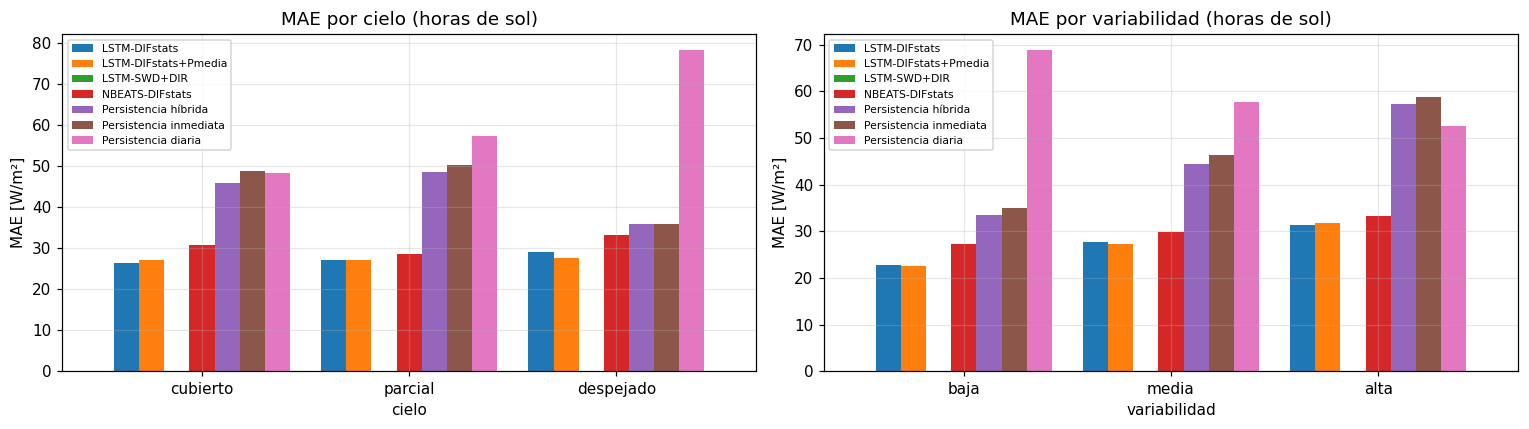

In [ ]:
op["cielo"] = pd.cut(
    op["kt_obj"], [-np.inf, 0.3, 0.65, np.inf], labels=["cubierto", "parcial", "despejado"]
)
op["variabilidad"] = pd.qcut(
    op["kt_std_3h_centrada"].rank(method="first"), 3, labels=["baja", "media", "alta"]
)
op["elevacion"] = pd.cut(op["elev_obj"], [-20, 5, 10, 20, 30, 40, 65])
op["nivel_DIF"] = pd.qcut(
    op["y"].rank(method="first"), 5, labels=["Q1 (bajo)", "Q2", "Q3", "Q4", "Q5 (alto)"]
)
op["semana"] = op.index.isocalendar().week.astype(int)
op["hora_UTC"] = op.index.hour
err_abs = (op[MODELO_PRINCIPAL] - op["y"]).abs()

def tabla_estratos(col):
    g = op.groupby(col, observed=True)
    t = pd.DataFrame({"n": g.size(), "pct_muestras": 100 * g.size() / len(op)})
    t["pct_error_total"] = 100 * err_abs.groupby(op[col], observed=True).sum() / err_abs.sum()
    t["concentracion"] = t["pct_error_total"] / t["pct_muestras"]
    t["sesgo_principal"] = (op[MODELO_PRINCIPAL] - op["y"]).groupby(op[col], observed=True).mean()
    for mod in MODELOS:
        t[f"MAE {mod}"] = (op[mod] - op["y"]).abs().groupby(op[col], observed=True).mean()
    return t

tablas_estratos = {}
for col in ["cielo", "variabilidad", "elevacion", "nivel_DIF", "regimen", "semana"]:
    tablas_estratos[col] = t = tabla_estratos(col)
    guardar_tabla(t, f"02_estratos_{col}")
    print(f"\n===== Por {col} =====")
    display(t.round(2))

fig, ejes = plt.subplots(1, 2, figsize=(14, 4))
for ax, col in zip(ejes, ["cielo", "variabilidad"]):
    t = tablas_estratos[col][[f"MAE {m}" for m in MODELOS]]
    t.columns = MODELOS
    t.plot.bar(ax=ax, rot=0, width=0.85)
    ax.set_title(f"MAE por {col} (horas de sol)")
    ax.set_ylabel("MAE [W/m²]")
    ax.legend(fontsize=7)
plt.tight_layout()
guardar(fig, "02_mae_cielo_variabilidad")
plt.show()
DIAG["estratos_concentrados"] = sorted(
    [
        (
            c,
            str(tablas_estratos[c]["concentracion"].idxmax()),
            tablas_estratos[c]["concentracion"].max(),
            tablas_estratos[c].loc[tablas_estratos[c]["concentracion"].idxmax(), "pct_error_total"],
            tablas_estratos[c].loc[tablas_estratos[c]["concentracion"].idxmax(), "sesgo_principal"],
        )
        for c in ["cielo", "variabilidad", "elevacion", "nivel_DIF"]
    ],
    key=lambda x: -x[2],
)

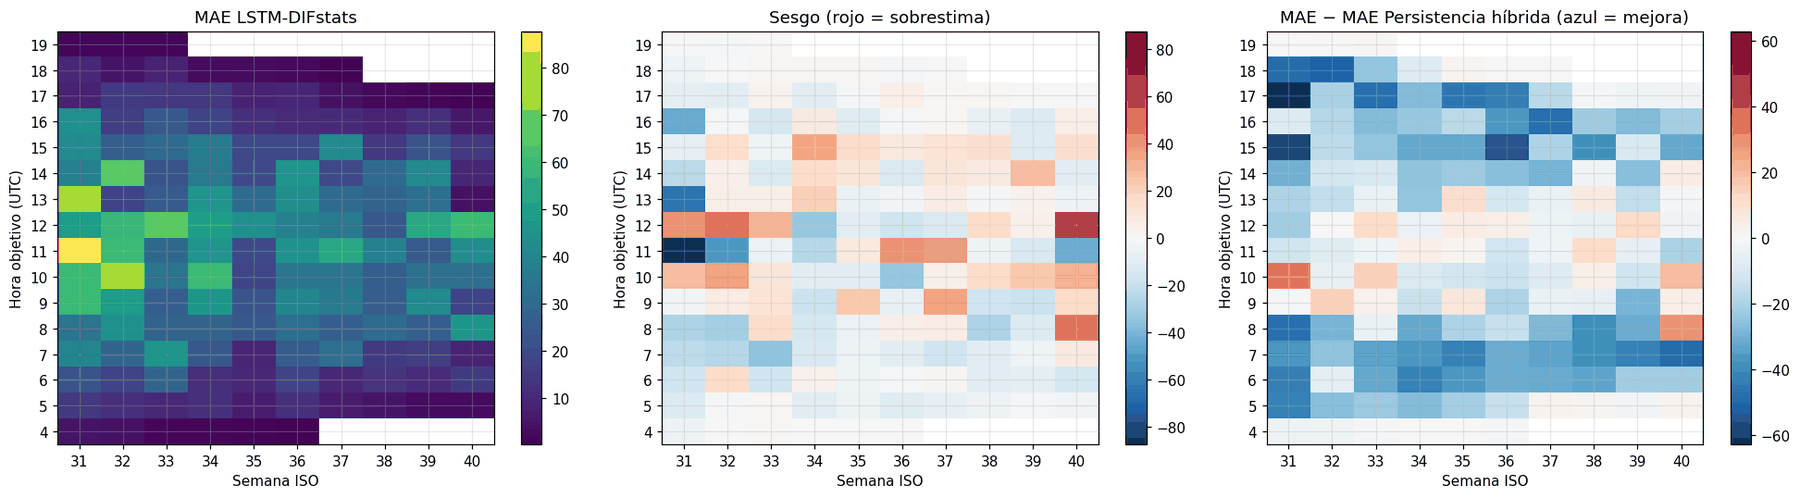

In [ ]:
def mapa(valores, titulo, ax, cmap, centrado=False):
    piv = valores.groupby([op["hora_UTC"], op["semana"]]).mean().unstack()
    lim = np.nanmax(np.abs(piv.values)) if centrado else None
    im = ax.imshow(
        piv.values,
        aspect="auto",
        cmap=cmap,
        origin="lower",
        vmin=-lim if centrado else None,
        vmax=lim if centrado else None,
    )
    ax.set_xticks(range(piv.shape[1]))
    ax.set_xticklabels(piv.columns)
    ax.set_yticks(range(piv.shape[0]))
    ax.set_yticklabels(piv.index)
    ax.set_xlabel("Semana ISO")
    ax.set_ylabel("Hora objetivo (UTC)")
    ax.set_title(titulo)
    plt.colorbar(im, ax=ax)

e_p = op[MODELO_PRINCIPAL] - op["y"]
e_r = op[REFERENCIA] - op["y"]
fig, ejes = plt.subplots(1, 3, figsize=(18, 5))
mapa(e_p.abs(), f"MAE {MODELO_PRINCIPAL}", ejes[0], "viridis")
mapa(e_p, "Sesgo (rojo = sobrestima)", ejes[1], "RdBu_r", centrado=True)
mapa(
    e_p.abs() - e_r.abs(),
    f"MAE − MAE {REFERENCIA} (azul = mejora)",
    ejes[2],
    "RdBu_r",
    centrado=True,
)
plt.tight_layout()
guardar(fig, "02_mapa_hora_semana")
plt.show()

**Resultados.** El error se concentra donde la DIF es más alta: el quintil superior de DIF reúne el 36,56 % del error con el 20,02 % de las horas (cociente 1,83) y un sesgo de −31,76 W/m², y las horas con elevación superior a 40° acumulan el 40,73 % del error con el 23,19 % de las horas (cociente 1,76). El MAE crece con la variabilidad del cielo, de 22,81 W/m² en el tercil bajo a 31,39 W/m² en el alto, mientras que el tipo de cielo apenas lo diferencia (cocientes entre 1,03 y 1,13). Las horas completamente diurnas reúnen el 98,6 % del error de las horas con sol.

### 1.6 Sesgo condicional

Se comprueba si el modelo regresa a la media, sobrestimando los valores bajos y subestimando los altos, mediante la curva de fiabilidad por tramos de la DIF observada, la regresión de Mincer–Zarnowitz (observado = a + b · predicho) y el cociente entre la desviación típica de las predicciones y la de las observaciones, en las horas con sol.

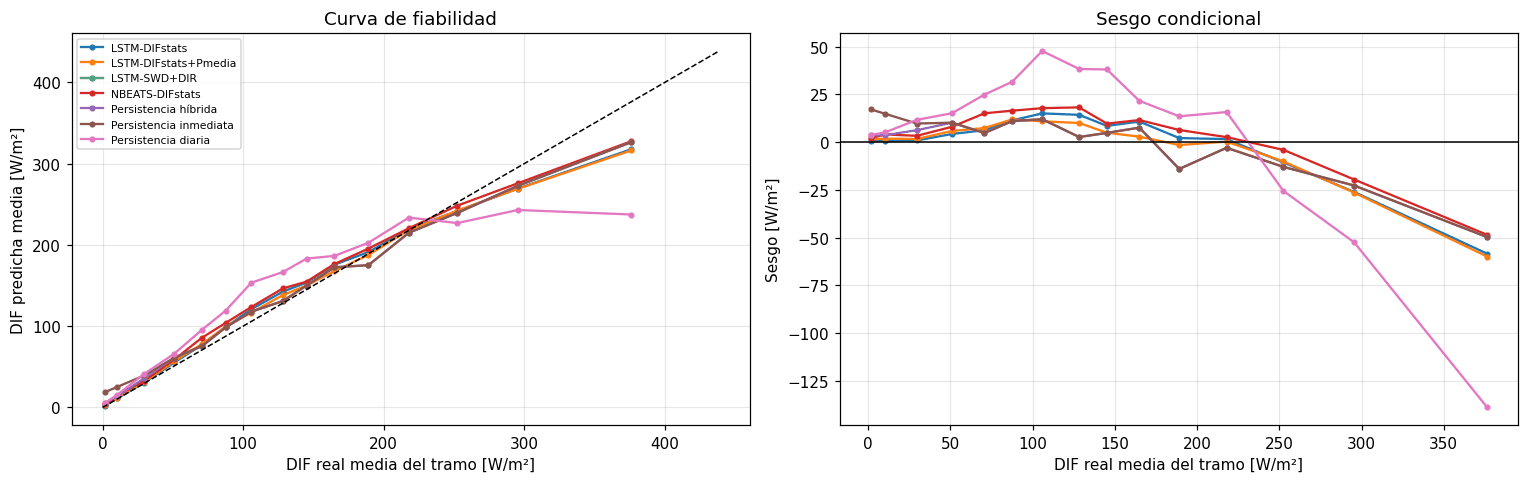

,a,b,ratio_std
modelo,,,
LSTM-DIFstats,4.423,0.978,0.944
LSTM-DIFstats+Pmedia,5.025,0.983,0.937
LSTM-SWD+DIR,NaN,NaN,NaN
NBEATS-DIFstats,4.697,0.948,0.965
Persistencia híbrida,25.913,0.832,1.023
Persistencia inmediata,23.635,0.837,1.007
Persistencia diaria,43.401,0.678,1.015


In [ ]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 4.5))
tramo = pd.cut(op["y"], np.unique(np.quantile(op["y"], np.linspace(0, 1, 16))), include_lowest=True)
filas_mz = []
for mod in MODELOS:
    g = op.groupby(tramo, observed=True)
    ejes[0].plot(g["y"].mean(), g[mod].mean(), marker="o", ms=3, label=mod)
    ejes[1].plot(g["y"].mean(), g[mod].mean() - g["y"].mean(), marker="o", ms=3, label=mod)
    m = op[["y", mod]].dropna()
    reg = stats.linregress(m[mod], m["y"])
    filas_mz.append(
        dict(modelo=mod, a=reg.intercept, b=reg.slope, ratio_std=m[mod].std() / m["y"].std())
    )
lim = op["y"].quantile(0.995)
ejes[0].plot([0, lim], [0, lim], "k--", lw=1)
ejes[0].set_xlabel("DIF real media del tramo [W/m²]")
ejes[0].set_ylabel("DIF predicha media [W/m²]")
ejes[0].set_title("Curva de fiabilidad")
ejes[0].legend(fontsize=7)
ejes[1].axhline(0, color="k", lw=1)
ejes[1].set_xlabel("DIF real media del tramo [W/m²]")
ejes[1].set_ylabel("Sesgo [W/m²]")
ejes[1].set_title("Sesgo condicional")
plt.tight_layout()
guardar(fig, "03_sesgo_condicional")
plt.show()
tabla_mz = pd.DataFrame(filas_mz).set_index("modelo")
guardar_tabla(tabla_mz, "03_mincer_zarnowitz")
display(tabla_mz.round(3))
DIAG["mz_b"], DIAG["ratio_std"] = (
    tabla_mz.loc[MODELO_PRINCIPAL, "b"],
    tabla_mz.loc[MODELO_PRINCIPAL, "ratio_std"],
)

**Resultados.** La regresión de Mincer–Zarnowitz de LSTM-DIFstats da a = 4,42 W/m² y b = 0,98, y el cociente entre la desviación típica predicha y la observada es de 0,94: el modelo suaviza ligeramente la serie, con una pendiente próxima a 1. Las persistencias tienen pendientes de 0,68 a 0,84, y la primera N-BEATS, de 0,95.

### 1.7 Estructura temporal de los residuos y desfase

Se calcula la autocorrelación de los residuos en las horas con sol, con la prueba de Ljung–Box, y la correlación cruzada entre el cambio horario observado y el previsto con distintos desfases. Si el máximo se alcanza con una hora de desfase, el modelo reproduce los cambios con una hora de retraso, como la persistencia simple.

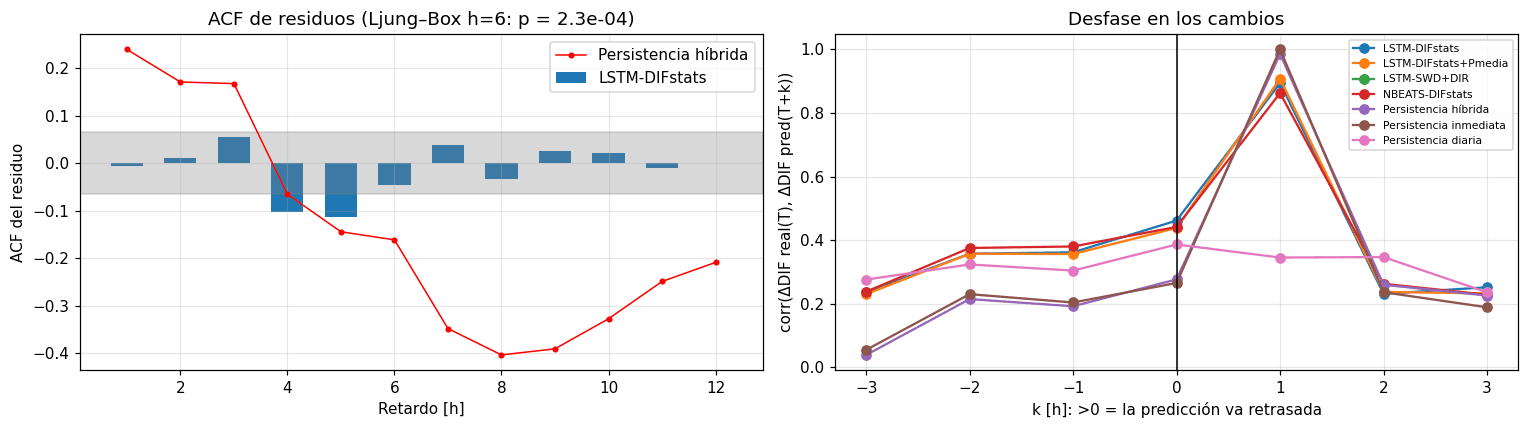

ACF(1) del residuo: -0.005 | Ljung–Box p = 2.30e-04
Desfase con máxima correlación de incrementos (h):
LSTM-DIFstats             1.0
LSTM-DIFstats+Pmedia      1.0
LSTM-SWD+DIR              NaN
NBEATS-DIFstats           1.0
Persistencia híbrida      1.0
Persistencia inmediata    1.0
Persistencia diaria       0.0


In [ ]:
def acf_enmascarada(r, mascara, max_lag):
    x = r.where(mascara)
    x = (x - x.mean()).values
    var = np.nanmean(x**2)
    out = []
    for k in range(1, max_lag + 1):
        a, b = x[:-k], x[k:]
        m = ~np.isnan(a) & ~np.isnan(b)
        out.append(np.mean(a[m] * b[m]) / var if m.sum() > 30 else np.nan)
    return np.array(out)

def ljung_box(acf, n, h):
    k = np.arange(1, h + 1)
    q = n * (n + 2) * np.nansum(acf[:h] ** 2 / (n - k))
    return q, stats.chi2.sf(q, h)

def correlacion_cruzada(a, b, max_k):
    return pd.Series(
        {
            k: pd.concat([a, b.shift(-k)], axis=1).dropna().corr().iloc[0, 1]
            for k in range(-max_k, max_k + 1)
        }
    )

MAX_RETARDO = 12
acf_p = acf_enmascarada(df[MODELO_PRINCIPAL] - df["y"], OP, MAX_RETARDO)
acf_r = acf_enmascarada(df[REFERENCIA] - df["y"], OP, MAX_RETARDO)
h_lb = 6
q, p_lb = ljung_box(acf_p, OP.sum(), h_lb)
banda = 1.96 / np.sqrt(OP.sum())
dy = df["y"].diff().where(OP & OP.shift(1, fill_value=False))
tabla_xcorr = pd.DataFrame(
    {mod: correlacion_cruzada(dy, df[mod].diff().where(dy.notna()), 3) for mod in MODELOS}
)
desfases = tabla_xcorr.idxmax()
fig, ejes = plt.subplots(1, 2, figsize=(14, 4))
lags = np.arange(1, MAX_RETARDO + 1)
ejes[0].bar(lags, acf_p, width=0.6, label=MODELO_PRINCIPAL)
ejes[0].plot(lags, acf_r, "r.-", lw=1, label=REFERENCIA)
ejes[0].axhspan(-banda, banda, color="grey", alpha=0.3)
ejes[0].set_xlabel("Retardo [h]")
ejes[0].set_ylabel("ACF del residuo")
ejes[0].set_title(f"ACF de residuos (Ljung–Box h={h_lb}: p = {p_lb:.1e})")
ejes[0].legend()
for mod in MODELOS:
    ejes[1].plot(tabla_xcorr.index, tabla_xcorr[mod], marker="o", label=mod)
ejes[1].axvline(0, color="k", lw=1)
ejes[1].set_xlabel("k [h]: >0 = la predicción va retrasada")
ejes[1].set_ylabel("corr(ΔDIF real(T), ΔDIF pred(T+k))")
ejes[1].set_title("Desfase en los cambios")
ejes[1].legend(fontsize=7)
plt.tight_layout()
guardar(fig, "04_acf_desfase")
plt.show()
print(f"ACF(1) del residuo: {acf_p[0]:.3f} | Ljung–Box p = {p_lb:.2e}")
print("Desfase con máxima correlación de incrementos (h):")
print(desfases.to_string())
guardar_tabla(tabla_xcorr, "04_correlacion_cruzada_incrementos")
DIAG.update(
    acf1=acf_p[0],
    p_ljung_box=p_lb,
    desfase=int(desfases[MODELO_PRINCIPAL]),
    corr_k0=tabla_xcorr.loc[0, MODELO_PRINCIPAL],
    corr_kmax=tabla_xcorr[MODELO_PRINCIPAL].max(),
)

**Resultados.** La autocorrelación de primer orden del residuo es prácticamente nula, aunque la prueba de Ljung–Box con seis retardos rechaza la ausencia de autocorrelación (p = 2,30·10⁻⁴). La correlación entre los cambios observados y los previstos alcanza su máximo con una hora de desfase en LSTM-DIFstats, en `LSTM-DIFstats+Pmedia`, en la primera N-BEATS y en las persistencias simple e híbrida, y sin desfase en la persistencia diaria: los modelos reproducen los cambios con una hora de retraso.

### 1.8 Comportamiento en las rampas

Se considera rampa un cambio de la DIF entre la última hora observada y la hora objetivo igual o mayor en valor absoluto que el percentil 90 de las horas con sol de validación, umbral provisional que más adelante se sustituye por el de entrenamiento. Se miden la probabilidad de detección (POD), la tasa de falsas alarmas (FAR), el índice CSI, la amplitud capturada (mediana del cociente entre el cambio previsto y el observado) y el MAE en subidas, bajadas y horas sin rampa, y se promedian las series alrededor de cada rampa.

Umbral: |ΔDIF| ≥ 94.6 W/m² en 1 h → 89 rampas (10.1 % de las horas de sol), que concentran el 31.1 % del error


,POD,FAR,CSI,amplitud_capturada,MAE_rampa_subida,MAE_rampa_bajada,MAE_sin_rampa
modelo,,,,,,,
LSTM-DIFstats,0.202,0.143,0.196,0.430,90.354,69.495,19.693
LSTM-DIFstats+Pmedia,0.135,0.200,0.130,0.442,92.021,70.106,19.483
LSTM-SWD+DIR,0.000,0.000,0.000,NaN,NaN,NaN,NaN
NBEATS-DIFstats,0.213,0.345,0.192,0.464,83.672,73.228,22.754
Persistencia híbrida,0.000,0.000,0.000,0.000,131.913,135.706,32.115
Persistencia inmediata,0.000,0.000,0.000,0.000,131.913,135.706,35.082
Persistencia diaria,0.472,0.818,0.151,0.617,93.932,75.706,52.940


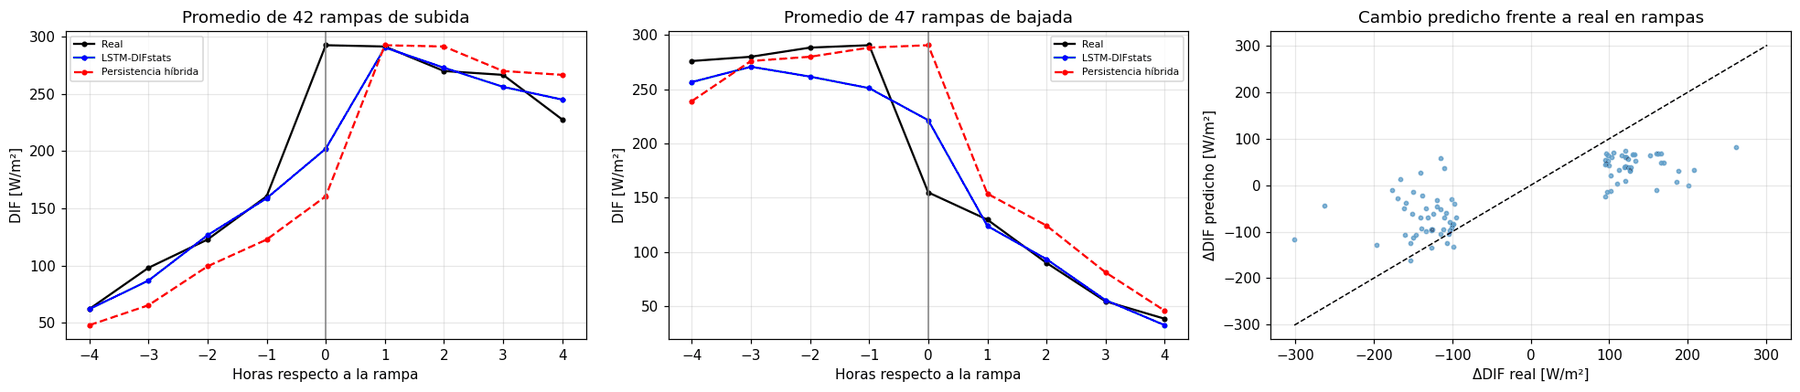

In [ ]:
delta_real = (df["y"] - df["DIF_emision"]).where(OP)
umbral_rampa = np.nanpercentile(delta_real.abs(), PERCENTIL_RAMPA)
clasificar = lambda d: np.sign(d).where(d.abs() >= umbral_rampa, 0)
ev_real = clasificar(delta_real)
filas_rampa = []
for mod in MODELOS:
    delta_pred = (df[mod] - df["DIF_emision"]).where(delta_real.notna())
    ev_pred = clasificar(delta_pred)
    hay_real, hay_pred = ev_real != 0, ev_pred != 0
    aciertos = (hay_real & (ev_pred == ev_real)).sum()
    fallos = (hay_real & (ev_pred != ev_real)).sum()
    falsas = (hay_pred & (ev_pred != ev_real)).sum()
    err = (df[mod] - df["y"]).abs()
    filas_rampa.append(
        dict(
            modelo=mod,
            POD=aciertos / max(aciertos + fallos, 1),
            FAR=falsas / max(aciertos + falsas, 1),
            CSI=aciertos / max(aciertos + fallos + falsas, 1),
            amplitud_capturada=float(np.nanmedian((delta_pred / delta_real)[hay_real])),
            MAE_rampa_subida=err[ev_real == 1].mean(),
            MAE_rampa_bajada=err[ev_real == -1].mean(),
            MAE_sin_rampa=err[(ev_real == 0) & delta_real.notna()].mean(),
        )
    )
tabla_rampas = pd.DataFrame(filas_rampa).set_index("modelo")
n_rampas = int((ev_real != 0).sum())
err_p = (df[MODELO_PRINCIPAL] - df["y"]).abs()
pct_err_rampa = 100 * err_p[ev_real != 0].sum() / err_p[delta_real.notna()].sum()
print(
    f"Umbral: |ΔDIF| ≥ {umbral_rampa:.1f} W/m² en 1 h → {n_rampas} rampas "
    f"({100 * n_rampas / delta_real.notna().sum():.1f} % de las horas de sol), que concentran el {pct_err_rampa:.1f} % del error"
)
guardar_tabla(tabla_rampas, "05_rampas")
display(tabla_rampas.round(3))
DIAG.update(
    rampa_CSI=tabla_rampas.loc[MODELO_PRINCIPAL, "CSI"],
    rampa_amplitud=tabla_rampas.loc[MODELO_PRINCIPAL, "amplitud_capturada"],
    rampa_pct_error=pct_err_rampa,
    rampa_pct_muestras=100 * n_rampas / delta_real.notna().sum(),
)
V = 4
pos_rel = np.arange(-V, V + 1)
fig, ejes = plt.subplots(1, 3, figsize=(18, 4))
for ax, signo, nombre in [(ejes[0], 1, "subida"), (ejes[1], -1, "bajada")]:
    idx = np.where(ev_real.values == signo)[0]
    idx = idx[(idx >= V) & (idx < len(df) - V)]
    for col, estilo, et in [
        ("y", "k-", "Real"),
        (MODELO_PRINCIPAL, "b-", MODELO_PRINCIPAL),
        (REFERENCIA, "r--", REFERENCIA),
    ]:
        v = df[col].values
        ax.plot(
            pos_rel, [np.nanmean(v[idx + k]) for k in pos_rel], estilo, marker="o", ms=3, label=et
        )
    ax.axvline(0, color="grey", lw=1)
    ax.set_title(f"Promedio de {len(idx)} rampas de {nombre}")
    ax.set_xlabel("Horas respecto a la rampa")
    ax.set_ylabel("DIF [W/m²]")
    ax.legend(fontsize=7)
m = ev_real != 0
ejes[2].scatter(delta_real[m], (df[MODELO_PRINCIPAL] - df["DIF_emision"])[m], s=8, alpha=0.5)
lim = np.nanmax(np.abs(delta_real[m]))
ejes[2].plot([-lim, lim], [-lim, lim], "k--", lw=1)
ejes[2].set_xlabel("ΔDIF real [W/m²]")
ejes[2].set_ylabel("ΔDIF predicho [W/m²]")
ejes[2].set_title("Cambio predicho frente a real en rampas")
plt.tight_layout()
guardar(fig, "05_rampas")
plt.show()

**Resultados.** Con un umbral de 94,6 W/m² hay 89 rampas, el 10,1 % de las horas con sol, que concentran el 31,1 % del error. LSTM-DIFstats detecta el 20 % de ellas (POD = 0,20; CSI = 0,20) y, en mediana, prevé el 43 % del cambio observado. Su MAE es de 90,4 W/m² en las subidas y de 69,5 W/m² en las bajadas, frente a 19,7 W/m² en las horas sin rampa; la persistencia simple, que no anticipa ninguna rampa, llega a 131,9 y 135,7 W/m².

### 1.9 Predictibilidad del error

Un modelo HGB auxiliar, evaluado con validación cruzada agrupada por días en las horas con sol, intenta predecir el residuo de LSTM-DIFstats con la información disponible al emitir (A) y el error absoluto con las condiciones de la propia hora objetivo (B). El primero indica si el error es corregible con esa información; el segundo, de carácter descriptivo, en qué condiciones se equivoca el modelo, y se complementa con la importancia por permutación y la dependencia parcial.

[A: residuo con información de emisión] R² fuera de muestra (CV por días): -0.141
MAE en horas de sol: 25.70 → 28.16 W/m² restando el residuo estimado (-9.6 %)
[B: error absoluto con condiciones de la hora objetivo] R² fuera de muestra (CV por días): 0.342


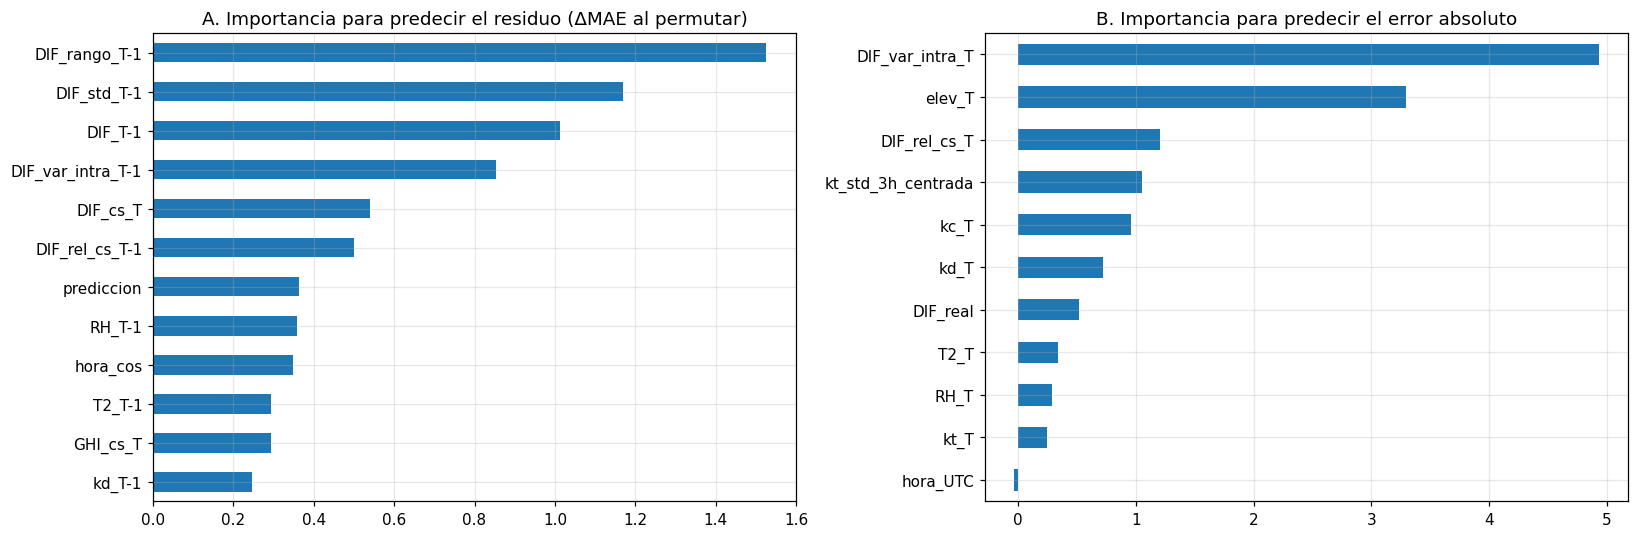

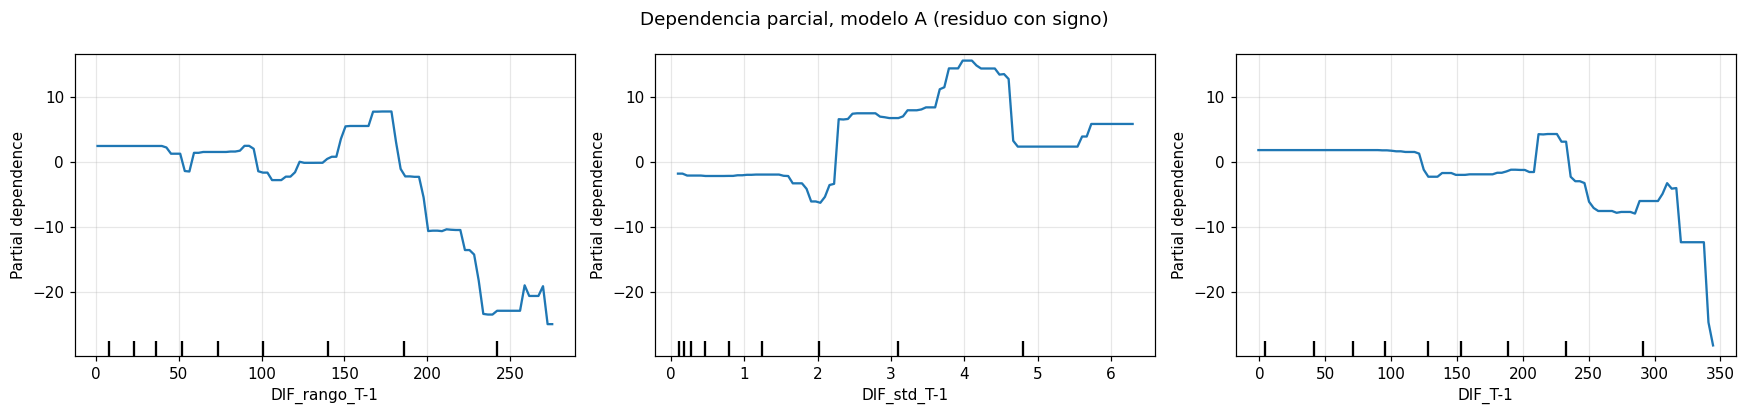

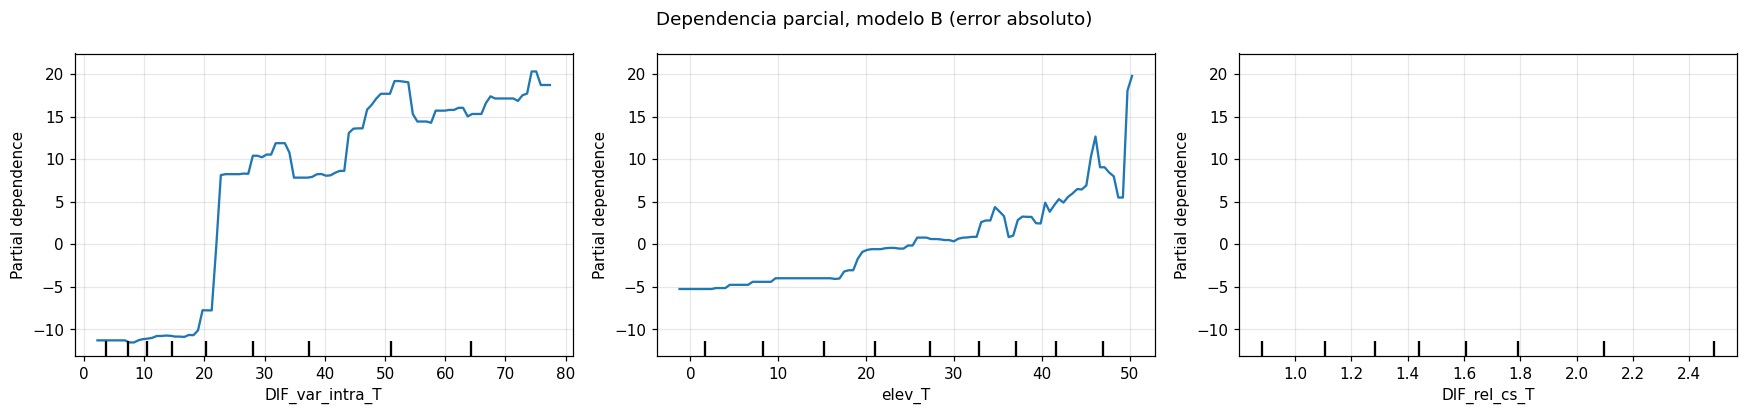

In [ ]:
centro = df.index + pd.Timedelta("30min")
XA = pd.DataFrame(index=df.index)
for c in [
    "DIF",
    "DIF_std",
    "DIF_rango",
    "DIF_var_intra",
    "SWD",
    "DIR",
    "kt",
    "kd",
    "kc",
    "DIF_rel_cs",
    "T2",
    "RH",
    "P",
    "dDIF",
    "dkt",
    "kt_std_3h",
]:
    if f"{c}_emi" in df and df[f"{c}_emi"].notna().any():
        XA[f"{c}_T-1"] = df[f"{c}_emi"]
XA["prediccion"] = df[MODELO_PRINCIPAL]
for c in ["elev", "fraccion_diurna", "G0h", "GHI_cs", "DIF_cs"]:
    if df[f"{c}_obj"].notna().any():
        XA[f"{c}_T"] = df[f"{c}_obj"]
XA["hora_sin"] = np.sin(2 * np.pi * (centro.hour + 0.5) / 24)
XA["hora_cos"] = np.cos(2 * np.pi * (centro.hour + 0.5) / 24)
XB = pd.DataFrame(index=df.index)
for c in ["kt", "kd", "kc", "DIF_rel_cs", "elev", "DIF_var_intra", "T2", "RH"]:
    if df[f"{c}_obj"].notna().any():
        XB[f"{c}_T"] = df[f"{c}_obj"]
XB["kt_std_3h_centrada"] = df["kt_std_3h_centrada"]
XB["DIF_real"] = df["y"]
XB["hora_UTC"] = df.index.hour.astype(float)

def modelo_error_cv(X, objetivo, mascara, nombre, n_bloques=5):
    datos = pd.concat([X, objetivo.rename("objetivo")], axis=1)[mascara].dropna(subset=["objetivo"])
    Xd, yd = datos.drop(columns="objetivo").astype(float), datos["objetivo"]
    grupos = datos.index.normalize()
    oof = pd.Series(np.nan, index=datos.index)
    importancias = []
    nuevo = lambda: HistGradientBoostingRegressor(
        max_iter=200,
        learning_rate=0.05,
        max_leaf_nodes=15,
        min_samples_leaf=20,
        l2_regularization=1.0,
        random_state=SEMILLA,
    )
    for ent, val in GroupKFold(n_splits=n_bloques).split(Xd, yd, grupos):
        mod = nuevo().fit(Xd.iloc[ent], yd.iloc[ent])
        oof.iloc[val] = mod.predict(Xd.iloc[val])
        imp = permutation_importance(
            mod,
            Xd.iloc[val],
            yd.iloc[val],
            scoring="neg_mean_absolute_error",
            n_repeats=5,
            random_state=SEMILLA,
        )
        importancias.append(imp.importances_mean)
    r2 = 1 - ((yd - oof) ** 2).sum() / ((yd - yd.mean()) ** 2).sum()
    imp = pd.Series(np.mean(importancias, axis=0), index=Xd.columns).sort_values(ascending=False)
    print(f"[{nombre}] R² fuera de muestra (CV por días): {r2:.3f}")
    return nuevo().fit(Xd, yd), Xd, yd, oof, r2, imp

residuo = df[MODELO_PRINCIPAL] - df["y"]
mA, XdA, ydA, oofA, r2A, impA = modelo_error_cv(
    XA, residuo, OP, "A: residuo con información de emisión"
)
mae_antes, mae_despues = ydA.abs().mean(), (ydA - oofA).abs().mean()
mejora_corr = 100 * (1 - mae_despues / mae_antes)
print(
    f"MAE en horas de sol: {mae_antes:.2f} → {mae_despues:.2f} W/m² restando el residuo estimado ({mejora_corr:+.1f} %)"
)
mB, XdB, ydB, oofB, r2B, impB = modelo_error_cv(
    XB, residuo.abs(), OP, "B: error absoluto con condiciones de la hora objetivo"
)
fig, ejes = plt.subplots(1, 2, figsize=(15, 5))
impA.head(12)[::-1].plot.barh(ax=ejes[0])
ejes[0].set_title("A. Importancia para predecir el residuo (ΔMAE al permutar)")
impB.head(12)[::-1].plot.barh(ax=ejes[1])
ejes[1].set_title("B. Importancia para predecir el error absoluto")
plt.tight_layout()
guardar(fig, "06_importancia_modelo_error")
plt.show()
for modelo_aux, Xd, imp, nombre in [(mA, XdA, impA, "A"), (mB, XdB, impB, "B")]:
    fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
    PartialDependenceDisplay.from_estimator(
        modelo_aux, Xd, list(imp.head(3).index), ax=ax, kind="average"
    )
    fig.suptitle(
        f"Dependencia parcial, modelo {nombre} ({'residuo con signo' if nombre == 'A' else 'error absoluto'})"
    )
    plt.tight_layout()
    guardar(fig, f"06_dependencia_parcial_{nombre}")
    plt.show()

guardar_tabla(
    pd.DataFrame({"importancia_A_residuo": impA, "importancia_B_error_abs": impB}),
    "06_importancias",
)
DIAG.update(
    r2_residuo=r2A,
    mejora_correccion=mejora_corr,
    top_residuo=list(impA.head(5).index),
    top_error=list(impB.head(5).index),
)

**Resultados.** Con la información disponible al emitir, el residuo no es predecible: el R² fuera de muestra es de −0,14, y restar el residuo estimado empeora el MAE en horas con sol de 25,70 a 28,16 W/m² (un 9,6 %). Con las condiciones de la hora objetivo, el modelo auxiliar explica una parte del error absoluto (R² = 0,34).

### 1.10 Peores días

Se calcula el MAE diario de LSTM-DIFstats en las horas con sol, se mide qué parte del error total reúne el 10 % de los peores días y se representan los nueve días con mayor MAE junto con la persistencia híbrida, la DIF de cielo despejado y el índice de claridad.

El 10 % de peores días (6 días) concentra el 19.7 % del error absoluto


,MAE,error_total,MAE_referencia,kt_medio,kt_std_medio
2024-08-10,62.733,1003.726,100.699,0.521,0.077
2024-08-03,49.303,788.847,79.928,0.382,0.096
2024-08-14,46.548,744.769,49.470,0.260,0.095
2024-08-20,43.560,653.403,63.584,0.299,0.074
2024-08-24,42.945,644.169,55.117,0.287,0.108
2024-09-03,42.301,634.517,65.528,0.282,0.092
2024-09-10,42.288,592.030,49.068,0.222,0.073
2024-09-16,41.053,533.691,58.665,0.437,0.106
2024-09-04,37.249,521.490,60.225,0.335,0.117


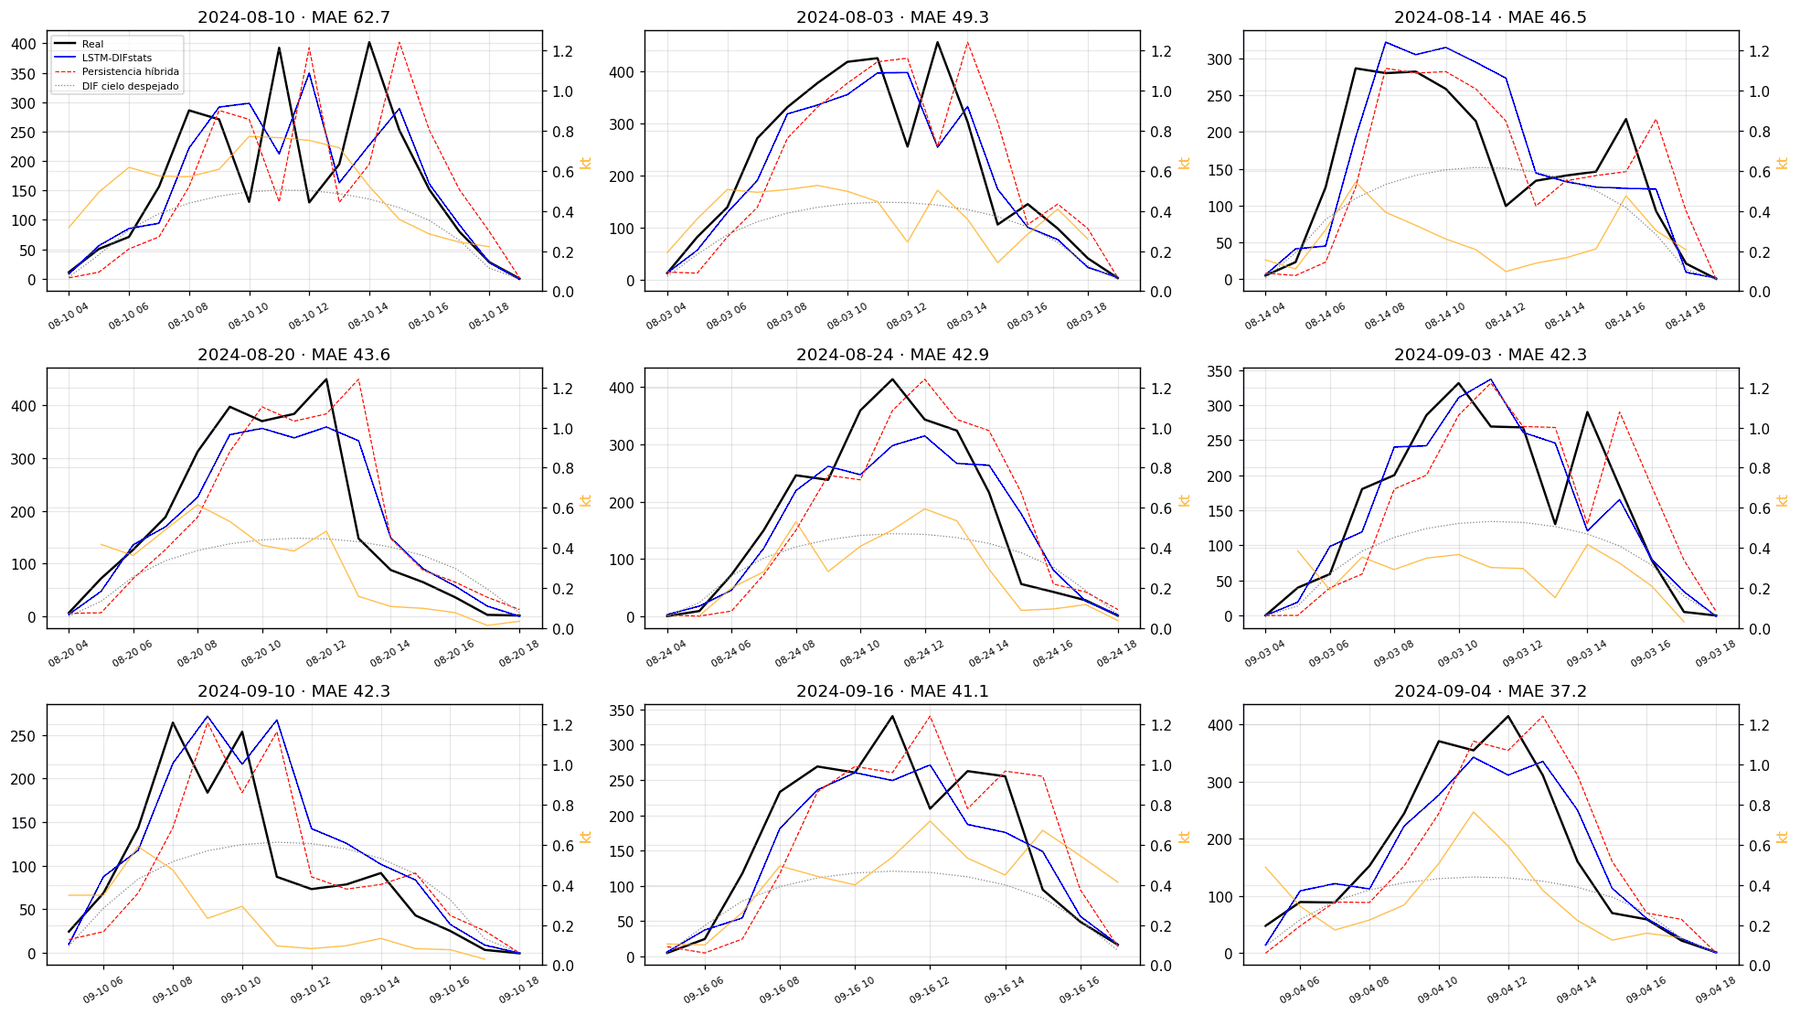

In [ ]:
por_dia = op.groupby(op.index.date)
resumen_dias = pd.DataFrame(
    {
        "MAE": por_dia.apply(lambda g: (g[MODELO_PRINCIPAL] - g["y"]).abs().mean()),
        "error_total": por_dia.apply(lambda g: (g[MODELO_PRINCIPAL] - g["y"]).abs().sum()),
        "MAE_referencia": por_dia.apply(lambda g: (g[REFERENCIA] - g["y"]).abs().mean()),
        "kt_medio": por_dia["kt_obj"].mean(),
        "kt_std_medio": por_dia["kt_std_3h_centrada"].mean(),
    }
)
n10 = max(1, int(0.1 * len(resumen_dias)))
pct_peor10 = (
    100 * resumen_dias["error_total"].nlargest(n10).sum() / resumen_dias["error_total"].sum()
)
print(f"El 10 % de peores días ({n10} días) concentra el {pct_peor10:.1f} % del error absoluto")
peores = resumen_dias.nlargest(N_PEORES_DIAS, "MAE")
display(peores.round(3))
guardar_tabla(resumen_dias.sort_values("MAE", ascending=False), "07_resumen_dias")
DIAG["pct_error_peor10_dias"] = pct_peor10
nfil = int(np.ceil(len(peores) / 3))
fig, ejes = plt.subplots(nfil, 3, figsize=(18, 3.4 * nfil), squeeze=False)
for ax, dia in zip(ejes.ravel(), peores.index):
    d = df.loc[str(dia)]
    d = d[d["regimen"] != "noche"]
    ax.plot(d.index, d["y"], "k-", lw=1.6, label="Real")
    ax.plot(d.index, d[MODELO_PRINCIPAL], "b-", lw=1.1, label=MODELO_PRINCIPAL)
    ax.plot(d.index, d[REFERENCIA], "r--", lw=0.8, label=REFERENCIA)
    if "DIF_cs_obj" in d and d["DIF_cs_obj"].notna().any():
        ax.plot(d.index, d["DIF_cs_obj"], color="grey", lw=0.8, ls=":", label="DIF cielo despejado")
    ax2 = ax.twinx()
    ax2.plot(d.index, d["kt_obj"], color="orange", lw=0.9, alpha=0.7)
    ax2.set_ylim(0, 1.3)
    ax2.set_ylabel("kt", color="orange")
    ax.set_title(f"{dia} · MAE {peores.loc[dia, 'MAE']:.1f}")
    ax.tick_params(axis="x", labelrotation=30, labelsize=7)
ejes[0, 0].legend(fontsize=7)
for ax in ejes.ravel()[len(peores) :]:
    ax.axis("off")
plt.tight_layout()
guardar(fig, "07_peores_dias")
plt.show()

**Resultados.** El 10 % de los peores días (6 días) concentra el 19,7 % del error absoluto. El peor es el 10 de agosto de 2024, con un MAE de 62,73 W/m², frente a 100,70 W/m² de la persistencia híbrida. En los nueve peores días, el MAE del modelo, entre 37,25 y 62,73 W/m², es inferior al de la persistencia híbrida, y el índice de claridad medio está entre 0,22 y 0,52.

### 1.11 Análisis interno de la LSTM

Se mide la importancia por permutación de cada canal y de cada hora de la ventana como el aumento del MAE en las horas con sol al barajarlos entre muestras, y se atribuye cada predicción a cada hora y canal mediante gradientes integrados, con la media de entrenamiento como entrada de referencia y comprobando la propiedad de completitud.

Gradientes integrados: error relativo mediano de completitud = 0.006 (debe ser < 0,05)


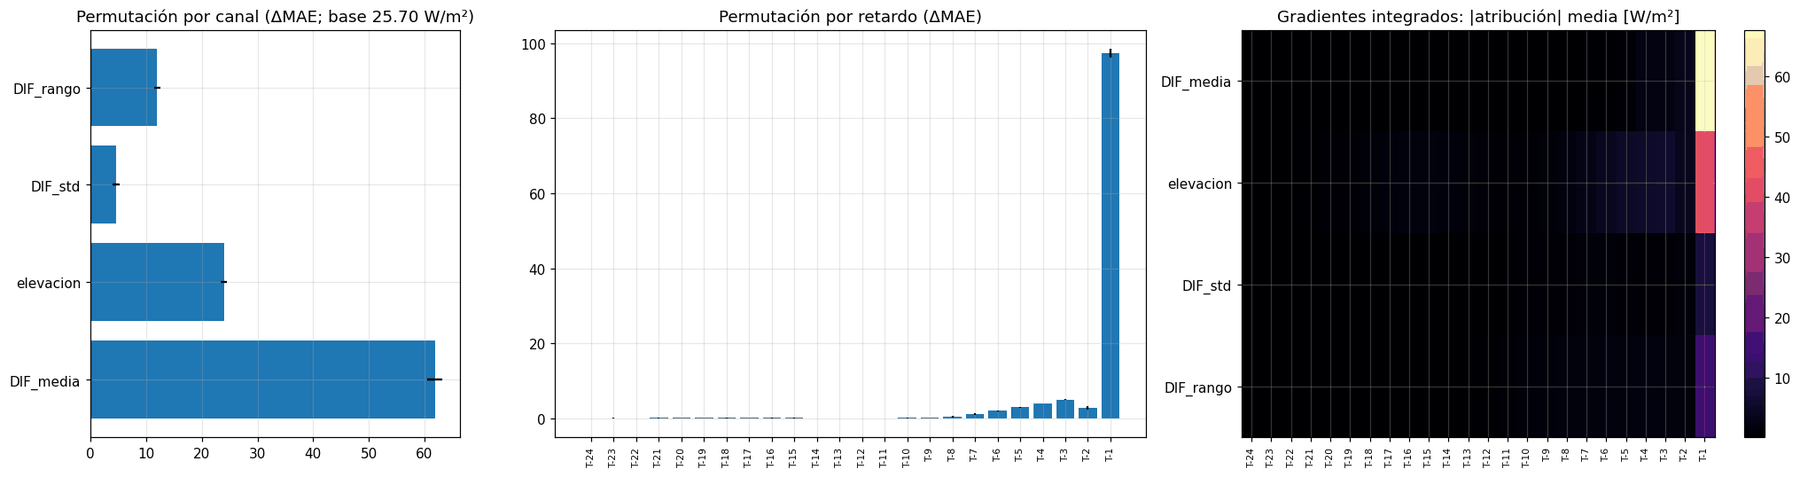

Importancia temporal en T-24…T-17: 0.8 % | en T-3…T-1: 89.6 %
Canales con importancia < 1 % del MAE base: []


In [ ]:
def importancia_permutacion(predict_fn, X, y, eje, n_rep=5, semilla=SEMILLA):
    rng = np.random.default_rng(semilla)
    base = np.mean(np.abs(predict_fn(X) - y))
    n = X.shape[2] if eje == "canal" else X.shape[1]
    res = np.zeros((n, n_rep))
    for j in range(n):
        for r in range(n_rep):
            Xp = X.copy()
            perm = rng.permutation(len(X))
            if eje == "canal":
                Xp[:, :, j] = Xp[perm, :, j]
            else:
                Xp[:, j, :] = Xp[perm, j, :]
            res[j, r] = np.mean(np.abs(predict_fn(Xp) - y)) - base
    return base, res.mean(axis=1), res.std(axis=1)

def gradientes_integrados(modelo, X, pasos=64):
    import torch
    x = torch.from_numpy(np.ascontiguousarray(X, dtype=np.float32))
    base = torch.zeros_like(x)
    suma = torch.zeros_like(x)
    for a in torch.linspace(0, 1, pasos + 1)[1:]:
        xi = (base + a * (x - base)).requires_grad_(True)
        salida = modelo(xi).sum()
        (grad,) = torch.autograd.grad(salida, xi)
        suma += grad
    attr = ((x - base) * suma / pasos).detach().numpy()
    with torch.no_grad():
        dif = (modelo(x) - modelo(base)).numpy()
    return attr, dif

if predecir_W is not None:
    idx_op = np.where(OP.values)[0]
    Xs, ys = X_val_esc[idx_op], df["y"].values[idx_op]
    base, imp_canal, sd_canal = importancia_permutacion(predecir_W, Xs, ys, "canal")
    _, imp_ret, sd_ret = importancia_permutacion(predecir_W, Xs, ys, "retardo", n_rep=3)
    etiquetas_ret = [f"T-{24 - i}" for i in range(24)]
    fig, ejes = plt.subplots(1, 3, figsize=(19, 5), gridspec_kw={"width_ratios": [1, 1.6, 1.6]})
    ejes[0].barh(CANALES, imp_canal, xerr=sd_canal)
    ejes[0].set_title(f"Permutación por canal (ΔMAE; base {base:.2f} W/m²)")
    ejes[1].bar(range(24), imp_ret, yerr=sd_ret)
    ejes[1].set_xticks(range(24))
    ejes[1].set_xticklabels(etiquetas_ret, rotation=90, fontsize=7)
    ejes[1].set_title("Permutación por retardo (ΔMAE)")
    if modelo_lstm is not None:
        attr, dif = gradientes_integrados(modelo_lstm, Xs)
        attr_W = attr * scaler_y.scale_[0]
        error_completitud = np.median(np.abs(attr.sum(axis=(1, 2)) - dif) / (np.abs(dif) + 1e-6))
        print(
            f"Gradientes integrados: error relativo mediano de completitud = {error_completitud:.3f} (debe ser < 0,05)"
        )
        mapa_ig = np.abs(attr_W).mean(axis=0)
        im = ejes[2].imshow(mapa_ig.T, aspect="auto", cmap="magma")
        ejes[2].set_yticks(range(len(CANALES)))
        ejes[2].set_yticklabels(CANALES)
        ejes[2].set_xticks(range(24))
        ejes[2].set_xticklabels(etiquetas_ret, rotation=90, fontsize=7)
        ejes[2].set_title("Gradientes integrados: |atribución| media [W/m²]")
        plt.colorbar(im, ax=ejes[2])
        guardar_tabla(
            pd.DataFrame(mapa_ig, index=etiquetas_ret, columns=CANALES), "08_gradientes_integrados"
        )
    plt.tight_layout()
    guardar(fig, "08_analisis_interno_lstm")
    plt.show()
    guardar_tabla(
        pd.DataFrame({"importancia": imp_canal, "sd": sd_canal}, index=CANALES),
        "08_permutacion_canales",
    )
    guardar_tabla(
        pd.DataFrame({"importancia": imp_ret, "sd": sd_ret}, index=etiquetas_ret),
        "08_permutacion_retardos",
    )
    positiva = np.clip(imp_ret, 0, None)
    DIAG["pct_importancia_T-24_a_T-17"] = 100 * positiva[:8].sum() / max(positiva.sum(), 1e-9)
    DIAG["pct_importancia_T-3_a_T-1"] = 100 * positiva[-3:].sum() / max(positiva.sum(), 1e-9)
    DIAG["canales_sin_uso"] = [c for c, v in zip(CANALES, imp_canal) if v < 0.01 * base]
    print(
        f"Importancia temporal en T-24…T-17: {DIAG['pct_importancia_T-24_a_T-17']:.1f} % | en T-3…T-1: {DIAG['pct_importancia_T-3_a_T-1']:.1f} %"
    )
    print(f"Canales con importancia < 1 % del MAE base: {DIAG['canales_sin_uso']}")
else:
    print("Paso 8 omitido (CARGAR_MODELO = False).")

**Resultados.** Las atribuciones de los gradientes integrados cumplen la propiedad de completitud. En la importancia por permutación, las tres últimas horas de la ventana reúnen el 89,6 % de la importancia temporal, y las ocho primeras, el 0,8 %. Los cuatro canales tienen una importancia de al menos el 1 % del MAE base, de modo que el modelo los usa todos.

### 1.12 Robustez estadística de las comparaciones

Se contrasta si las diferencias de MAE en las horas con sol entre LSTM-DIFstats y los demás modelos son significativas mediante la prueba de Diebold–Mariano, con la corrección de Harvey–Leybourne–Newbold y varianza de Newey–West, y un intervalo de confianza del 95 % obtenido por bootstrap de días completos; con una sola semilla por modelo, estas pruebas no separan la variabilidad del entrenamiento de la diferencia entre modelos. Al final se incorporan las predicciones de `LSTM-SWD+DIR`, alineadas por posición tras comprobar que su objetivo coincide hora a hora con el de validación.

In [ ]:
def diebold_mariano(e1, e2, h=1):
    d = (np.abs(e1) - np.abs(e2)).dropna().values
    n = len(d)
    if n < 30:
        return np.nan, np.nan
    dc = d - d.mean()
    L = max(h - 1, int(np.floor(4 * (n / 100) ** (2 / 9))))
    var = np.sum(dc**2) / n + sum(
        2 * (1 - k / (L + 1)) * np.sum(dc[k:] * dc[:-k]) / n for k in range(1, L + 1)
    )
    if var <= 0:
        return np.nan, np.nan
    est = d.mean() / np.sqrt(var / n) * np.sqrt((n + 1 - 2 * h + h * (h - 1) / n) / n)
    return est, 2 * stats.t.sf(abs(est), n - 1)

def bootstrap_dias(e1, e2, n_boot=4000, semilla=SEMILLA):
    rng = np.random.default_rng(semilla)
    d = pd.DataFrame({"a": e1.abs(), "b": e2.abs()}).dropna()
    if len(d) < 30:
        return np.array([np.nan, np.nan])
    g = d.groupby(d.index.date).agg(["sum", "count"])
    sa, sb, cnt = g[("a", "sum")].values, g[("b", "sum")].values, g[("a", "count")].values
    difs = [
        (sa[i].sum() - sb[i].sum()) / cnt[i].sum()
        for i in (rng.integers(0, len(cnt), len(cnt)) for _ in range(n_boot))
    ]
    return np.percentile(difs, [2.5, 97.5])

e_principal = (df[MODELO_PRINCIPAL] - df["y"]).where(OP)
filas_dm = []
for mod in MODELOS:
    if mod == MODELO_PRINCIPAL:
        continue
    e_otro = (df[mod] - df["y"]).where(OP)
    comunes = int((e_principal.notna() & e_otro.notna()).sum())
    if comunes < 30:
        print(
            f"⚠️ {mod}: solo {comunes} horas de sol con predicción de ambos modelos; se omite. "
            f"Predicciones no nulas de {mod} en todo validation: {int(df[mod].notna().sum())} de {len(df)}"
        )
        continue
    # Ambos modelos se comparan exactamente sobre las mismas horas
    m = e_principal.notna() & e_otro.notna()
    dm, p = diebold_mariano(e_principal.where(m), e_otro.where(m))
    lo, hi = bootstrap_dias(e_principal.where(m), e_otro.where(m))
    filas_dm.append(
        dict(
            comparacion=f"{MODELO_PRINCIPAL} vs {mod}",
            n_horas=comunes,
            dif_MAE=e_principal[m].abs().mean() - e_otro[m].abs().mean(),
            IC95_inf=lo,
            IC95_sup=hi,
            DM=dm,
            p_valor=p,
            conclusion=(
                ("mejor" if dm < 0 else "peor") if p < 0.05 else "sin diferencia significativa"
            ),
        )
    )
tabla_dm = pd.DataFrame(filas_dm).set_index("comparacion")
guardar_tabla(tabla_dm, "09_diebold_mariano")
display(tabla_dm.round(4))
DIAG["dm"] = tabla_dm
SEMILLAS = (
    {}
)  # p. ej. {"LSTM-DIFstats": ["LSTM-DIFstats_s1", "LSTM-DIFstats_s2", "LSTM-DIFstats_s3"]}
for mod, cols in SEMILLAS.items():
    maes = [(df[c] - df["y"]).abs()[OP].mean() for c in cols if c in df]
    if len(maes) > 1:
        print(
            f"{mod}: MAE operación = {np.mean(maes):.3f} ± {np.std(maes, ddof=1):.3f} W/m² ({len(maes)} semillas)"
        )

⚠️ LSTM-SWD+DIR: solo 0 horas de sol con predicción de ambos modelos; se omite. Predicciones no nulas de LSTM-SWD+DIR en todo validation: 0 de 1464


,n_horas,dif_MAE,IC95_inf,IC95_sup,DM,p_valor,conclusion
comparacion,,,,,,,
LSTM-DIFstats vs LSTM-DIFstats+Pmedia,884,0.0769,-0.6066,0.7784,0.2439,0.8074,sin diferencia significativa
LSTM-DIFstats vs NBEATS-DIFstats,884,-2.6342,-3.5674,-1.7202,-5.2513,0.0000,mejor
LSTM-DIFstats vs Persistencia híbrida,884,-16.6663,-18.8672,-14.4814,-14.9575,0.0000,mejor
LSTM-DIFstats vs Persistencia inmediata,884,-19.3343,-21.5770,-17.1008,-15.9435,0.0000,mejor
LSTM-DIFstats vs Persistencia diaria,884,-30.4001,-36.8646,-24.6848,-9.8450,0.0000,mejor


In [ ]:
NOMBRE_PARCHE = "LSTM-SWD+DIR"
ruta, columna = OTROS_MODELOS[NOMBRE_PARCHE]
comb = pd.read_csv(ruta)

# Alineación posicional solo si el objetivo coincide fila a fila con validation
assert len(comb) == len(df), f"Se esperaban {len(df)} filas y hay {len(comb)}"
assert "y_real" in comb.columns, f"Falta y_real. Columnas: {list(comb.columns)}"
dif_y = np.max(np.abs(comb["y_real"].values - df["y"].values))
assert (
    dif_y < 1e-3
), f"El objetivo no coincide fila a fila (diferencia máxima {dif_y:.4f}); no se puede alinear"
df[NOMBRE_PARCHE] = comb[columna].values
op[NOMBRE_PARCHE] = df.loc[op.index, NOMBRE_PARCHE]
if NOMBRE_PARCHE not in MODELOS:
    MODELOS.insert(MODELOS.index(MODELO_PRINCIPAL) + 1, NOMBRE_PARCHE)

mae_op = (df.loc[OP, NOMBRE_PARCHE] - df.loc[OP, "y"]).abs().mean()
print(
    f"✅ {NOMBRE_PARCHE}: {int(df[NOMBRE_PARCHE].notna().sum())} predicciones (objetivo validado, dif. máx. {dif_y:.1e})"
)
print(
    f"MAE en operación: {mae_op:.3f} W/m²  ← 26,864 en la clasificación original"
)
print("Modelos comparados:", MODELOS)

✅ LSTM-SWD+DIR: 1464 predicciones (objetivo validado, dif. máx. 1.2e-05)
MAE en operación: 26.865 W/m²  ← 26,864 en la clasificación original
Modelos comparados: ['LSTM-DIFstats', 'LSTM-DIFstats+Pmedia', 'LSTM-SWD+DIR', 'NBEATS-DIFstats', 'Persistencia híbrida', 'Persistencia inmediata', 'Persistencia diaria']


**Resultados.** LSTM-DIFstats tiene un MAE menor que la primera N-BEATS, con una diferencia de −2,63 W/m² (IC95 [−3,57; −1,72]), y que las tres persistencias, con diferencias de −16,67 W/m² frente a la híbrida, −19,33 W/m² frente a la simple y −30,40 W/m² frente a la diaria, todas significativas. Frente a `LSTM-DIFstats+Pmedia` no hay diferencia significativa (+0,08 W/m², IC95 [−0,61; +0,78]; p = 0,81). `LSTM-SWD+DIR`, incorporada después, obtiene un MAE de 26,9 W/m² en las horas con sol.

### 1.13 Síntesis del diagnóstico

Una celda final reúne de forma automática los hallazgos principales del diagnóstico de LSTM-DIFstats en validación, a partir de reglas con umbrales orientativos.

> *Resumen automático de los pasos anteriores. Las acciones que imprime son orientativas, con umbrales fijados en el código, y no se utilizan en la memoria.*

In [ ]:
acciones = []

def hallazgo(cond, texto):
    if cond:
        acciones.append(texto)

hallazgo(
    DIAG["desfase"] > 0,
    f"RETRASO: la LSTM reproduce los cambios {DIAG['desfase']} h tarde (corr. de incrementos {DIAG['corr_k0']:.2f} en k=0 frente a "
    f"{DIAG['corr_kmax']:.2f} en k={DIAG['desfase']}): se comporta como una persistencia suavizada. → Añadir información conocida "
    "de la hora objetivo (DIF y GHI de cielo despejado, elevación de T), término de derivada en la pérdida MAE(Δŷ, Δy) "
    "o ponderar las rampas; a medio plazo, información de previsión (NWP o satélite).",
)
hallazgo(
    DIAG["rampa_amplitud"] < 0.7,
    f"RAMPAS SUAVIZADAS: en las rampas predice el {100 * DIAG['rampa_amplitud']:.0f} % del cambio real (CSI = {DIAG['rampa_CSI']:.2f}); "
    f"son el {DIAG['rampa_pct_muestras']:.0f} % de las horas y el {DIAG['rampa_pct_error']:.0f} % del error. → Pesos mayores en rampas "
    "en la L1Loss, variables de tendencia (ΔDIF, Δkt) y de variabilidad reciente.",
)
hallazgo(
    DIAG["mz_b"] > 1.05 or DIAG["ratio_std"] < 0.9,
    f"PREDICCIONES CONSERVADORAS: Mincer–Zarnowitz b = {DIAG['mz_b']:.2f}, std(pred)/std(real) = {DIAG['ratio_std']:.2f}. "
    "→ Predecir el objetivo normalizado DIF/DIF_cs y desnormalizar; revisar regularización.",
)
hallazgo(
    DIAG["p_ljung_box"] < 0.01 and abs(DIAG["acf1"]) > 0.2,
    f"RESIDUOS AUTOCORRELACIONADOS: ACF(1) = {DIAG['acf1']:.2f}, Ljung–Box p = {DIAG['p_ljung_box']:.1e}. Queda información "
    "temporal sin explotar. → Variables de tendencia, revisar la ventana (paso 8) o un corrector que use el error de la hora anterior.",
)
hallazgo(
    DIAG["r2_residuo"] > 0.03 or DIAG["mejora_correccion"] > 2,
    f"ERROR PREDECIBLE: con información de emisión se explica R² = {DIAG['r2_residuo']:.2f} del residuo (corregirlo reduciría el "
    f"MAE un {DIAG['mejora_correccion']:.1f} %). Variables más útiles: {DIAG['top_residuo']}. → Incorporarlas como canales o "
    "entrenar un corrector de residuos en dos etapas.",
)
hallazgo(
    DIAG["r2_residuo"] <= 0.03 and DIAG["mejora_correccion"] <= 2,
    "ERROR NO PREDECIBLE con la información de emisión: más variables del pasado difícilmente ayudarán. → Mejora por la "
    "función de pérdida, la arquitectura o información prospectiva.",
)
for col, grupo_c, conc, pct, sesgo in DIAG["estratos_concentrados"][:2]:
    hallazgo(
        conc > 1.3,
        f"CONCENTRACIÓN DEL ERROR en {col} = '{grupo_c}': {pct:.0f} % del error, cociente error/muestras {conc:.2f}, "
        f"sesgo {sesgo:+.1f} W/m². → Priorizar variables y ponderación para esas condiciones.",
    )
hallazgo(
    DIAG["pct_error_peor10_dias"] > 25,
    f"ERROR CONCENTRADO EN POCOS DÍAS: el 10 % de peores días acumula el {DIAG['pct_error_peor10_dias']:.0f} % del error. "
    "→ Revisar esos días (paso 7) antes de cambiar el modelo.",
)
if "pct_importancia_T-24_a_T-17" in DIAG:
    hallazgo(
        DIAG["pct_importancia_T-24_a_T-17"] > 20,
        f"VENTANA CORTA: T-24…T-17 aporta el {DIAG['pct_importancia_T-24_a_T-17']:.0f} % de la importancia temporal. → Probar ventanas de 36–48 h.",
    )
    hallazgo(
        DIAG["pct_importancia_T-3_a_T-1"] > 80,
        f"MEMORIA CORTA: T-3…T-1 concentra el {DIAG['pct_importancia_T-3_a_T-1']:.0f} % de la importancia temporal; la LSTM apenas usa "
        "el resto del día. → Probar ventanas más cortas o añadir explícitamente la información del día anterior que sí sea útil.",
    )
    hallazgo(
        len(DIAG["canales_sin_uso"]) > 0,
        f"CANALES SIN USO: {DIAG['canales_sin_uso']}. → Eliminarlos simplifica el modelo.",
    )
sin_dif = [c for c, r in DIAG["dm"].iterrows() if r["conclusion"] == "sin diferencia significativa"]
hallazgo(
    len(sin_dif) > 0,
    f"SIN DIFERENCIA SIGNIFICATIVA: {sin_dif}. → En la memoria, tratarlos como equivalentes y elegir el más "
    "parsimonioso; entrenar varias semillas antes de afirmar mejoras pequeñas.",
)
print(
    f"Skill de {MODELO_PRINCIPAL} en operación frente a {REFERENCIA}: {DIAG['skill_operacion']:.1f} % "
    f"| en horas completamente diurnas frente a la persistencia inmediata: {DIAG['skill_diurno_vs_inmediata']:.1f} %\n"
)
for i, a in enumerate(acciones, 1):
    print(f"{i}. {a}\n")
(CARPETA_SALIDA / "10_sintesis.txt").write_text("\n\n".join(acciones), encoding="utf-8")
print("Resultados guardados en:", CARPETA_SALIDA)

Skill de LSTM-DIFstats en operación frente a Persistencia híbrida: 30.3 % | en horas completamente diurnas frente a la persistencia inmediata: 30.3 %

1. RETRASO: la LSTM reproduce los cambios 1 h tarde (corr. de incrementos 0.46 en k=0 frente a 0.89 en k=1): se comporta como una persistencia suavizada. → Añadir información conocida de la hora objetivo (DIF y GHI de cielo despejado, elevación de T), término de derivada en la pérdida MAE(Δŷ, Δy) o ponderar las rampas; a medio plazo, información de previsión (NWP o satélite).

2. RAMPAS SUAVIZADAS: en las rampas predice el 43 % del cambio real (CSI = 0.20); son el 10 % de las horas y el 31 % del error. → Pesos mayores en rampas en la L1Loss, variables de tendencia (ΔDIF, Δkt) y de variabilidad reciente.

3. ERROR NO PREDECIBLE con la información de emisión: más variables del pasado difícilmente ayudarán. → Mejora por la función de pérdida, la arquitectura o información prospectiva.

4. CONCENTRACIÓN DEL ERROR en nivel_DIF = 'Q5 (alto)': 

**Resultados.** La síntesis recoge cuatro hallazgos:

- Sigue los cambios con una hora de retraso: la correlación entre los cambios previstos y los observados es de 0,46 sin desfase y de 0,89 con una hora.
- En las rampas, que son el 10 % de las horas con sol y el 31 % del error, prevé el 43 % del cambio observado (CSI = 0,20).
- El error se concentra en el quintil más alto de DIF (37 % del error; cociente 1,83) y con elevaciones superiores a 40° (41 %; cociente 1,76).
- Las tres últimas horas de la ventana reúnen el 90 % de la importancia temporal por permutación.

## 2. Variabilidad entre semillas y descriptores intrahorarios

> *Se utiliza en la memoria: apartados 5.3.1 (LSTM-DIFstats con cinco semillas) y 5.3.3 (E1), y fase 3 de la Tabla A1.*

### 2.1 Variabilidad entre semillas

Se reentrena LSTM-DIFstats con tres semillas (42, 123 y 2024) y la receta original: 105 épocas con todo el conjunto de entrenamiento, pérdida L1, Adam con tasa 10⁻³ y weight decay 10⁻⁵, lotes de 128 y recorte del gradiente a 1 (fase 0). Se comprueba que la semilla 42 reproduce el modelo original, se mide la dispersión del MAE en las horas con sol y por bandas de elevación de la hora objetivo (hombros, hasta 20°; banda intermedia, de 20° a 40°; banda central, por encima de 40°) y se evalúa el ensemble de las tres semillas en validación.

In [ ]:
import json, time, random
from datetime import datetime
from pathlib import Path
import numpy as np, pandas as pd, pvlib
import torch, torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler
from scipy import stats

# ---------------- Configuración ----------------
BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
EJECUCIONES = BASE_DIR / "resultados" / "ejecuciones"
RUTA_MATRICES = (
    EJECUCIONES / "preparacion_bloque_difstats_20261006_180841" / "matrices_dif_elev_difstats.npz"
)
DIR_F0 = (
    BASE_DIR / "resultados" / "diagnostico" / "fase0_semillas"
)  # carpeta fija: permite reanudar
DIR_F0.mkdir(parents=True, exist_ok=True)
SEMILLAS_F0 = [42, 123, 2024]
EPOCAS, BATCH, LR, WD = 105, 128, 1e-3, 1e-5  # protocolo de Modelado.ipynb (celda 473)
LATITUD, LONGITUD = 51.971, 4.927
BANDAS = {"hombros (≤20°)": (-90, 20), "intermedia (20–40°)": (20, 40), "central (>40°)": (40, 90)}
MAE_REF_OPERACION = 25.698  # LSTM-DIFstats en la clasificación original

# ---------------- Datos ----------------
mat = np.load(RUTA_MATRICES)
X_tr = mat["X_train_DIF_elev_DIFstats_raw"].astype(np.float32)
y_tr = mat["y_train_difstats"].astype(np.float32).reshape(-1)
X_va = mat["X_validation_DIF_elev_DIFstats_raw"].astype(np.float32)
y_va = mat["y_validation_difstats"].astype(np.float64)
fechas = pd.DatetimeIndex(mat["fechas_validation"])

def normalizar_regimen(s):
    s = s.astype(str).str.lower()
    return np.select(
        [s.str.contains("noche"), s.str.contains("trans"), s.str.contains("complet")],
        ["noche", "transicion", "completamente_diurno"],
        "desconocido",
    )


# Ejecución original: la que reproduce el MAE de referencia en operación
candidatas = []
for carpeta in sorted(EJECUCIONES.glob("reentrenamiento_difstats_*")):
    csv = carpeta / "predicciones_validation_difstats.csv"
    if csv.is_file():
        c = pd.read_csv(csv)
        reg = normalizar_regimen(c["regimen_solar_objetivo"])
        mae = (c["pred_LSTM_DIFstats"] - c["DIF_observado"]).abs()[reg != "noche"].mean()
        candidatas.append((abs(mae - MAE_REF_OPERACION), carpeta, c))
dif_ref, DIR_ORIGINAL, pred_csv = min(candidatas, key=lambda x: x[0])
assert (
    dif_ref < 0.005
), f"Ninguna ejecución reproduce MAE {MAE_REF_OPERACION}; la más cercana difiere {dif_ref:.3f}"
print("✅ Modelo original:", DIR_ORIGINAL.name)
df = pd.DataFrame(index=fechas)
df["y"] = y_va
df["regimen"] = normalizar_regimen(pred_csv["regimen_solar_objetivo"])
df["Original (CSV)"] = pred_csv["pred_LSTM_DIFstats"].values
df["Persistencia híbrida"] = np.where(
    df["regimen"] == "completamente_diurno", X_va[:, -1, 0], X_va[:, 0, 0]
)

# Elevación media de cada hora objetivo (pvlib minutal, hora etiquetada por su inicio)
minutos = pd.date_range(fechas[0], fechas[-1] + pd.Timedelta("59min"), freq="1min", tz="UTC")
elev = pvlib.solarposition.get_solarposition(minutos, LATITUD, LONGITUD)["apparent_elevation"]
elev.index = elev.index.tz_localize(None)
df["elev"] = elev.groupby(elev.index.floor("h")).mean().reindex(df.index).values
df["banda"] = pd.cut(df["elev"], bins=[v[0] for v in BANDAS.values()] + [90], labels=list(BANDAS))
OP = df["regimen"] != "noche"
print(df["banda"][OP].value_counts().to_string())

# ---------------- Modelo y entrenamiento (idéntico al original) ----------------
sx = StandardScaler().fit(X_tr.reshape(-1, X_tr.shape[2]))
sy = StandardScaler().fit(y_tr.reshape(-1, 1))
esc = lambda X: sx.transform(X.reshape(-1, X.shape[2])).reshape(X.shape).astype(np.float32)
X_tr_e, X_va_e = esc(X_tr), esc(X_va)
y_tr_e = sy.transform(y_tr.reshape(-1, 1)).ravel().astype(np.float32)

class LSTMDIFStats(nn.Module):
    def __init__(self, n_features=4, hidden_size=64):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=n_features, hidden_size=hidden_size, num_layers=1, batch_first=True
        )
        self.head = nn.Sequential(nn.Linear(hidden_size, 32), nn.ReLU(), nn.Linear(32, 1))

    def forward(self, x):
        salida, _ = self.lstm(x)
        return self.head(salida[:, -1, :]).squeeze(-1)

def entrenar_semilla(semilla):
    random.seed(semilla)
    np.random.seed(semilla)
    torch.manual_seed(semilla)
    torch.use_deterministic_algorithms(True)
    modelo = LSTMDIFStats()
    gen = torch.Generator()
    gen.manual_seed(semilla)
    loader = DataLoader(
        TensorDataset(torch.from_numpy(X_tr_e), torch.from_numpy(y_tr_e)),
        batch_size=BATCH,
        shuffle=True,
        generator=gen,
        num_workers=0,
    )
    opt = torch.optim.Adam(modelo.parameters(), lr=LR, weight_decay=WD)
    crit = nn.L1Loss()
    for ep in range(1, EPOCAS + 1):
        modelo.train()
        for xb, yb in loader:
            opt.zero_grad(set_to_none=True)
            loss = crit(modelo(xb), yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(modelo.parameters(), max_norm=1.0)
            opt.step()
        if ep % 35 == 0:
            print(f"   época {ep}/{EPOCAS}")
    modelo.eval()
    with torch.no_grad():
        z = modelo(torch.from_numpy(X_va_e)).numpy()
    return modelo, sy.inverse_transform(z.reshape(-1, 1)).ravel()

for s in SEMILLAS_F0:
    ruta_pred = DIR_F0 / f"pred_validation_s{s}.npy"
    if ruta_pred.is_file():
        print(f"Semilla {s}: ya entrenada, se carga de Drive")
    else:
        t0 = time.time()
        print(f"Semilla {s}: entrenando…")
        modelo_s, pred_s = entrenar_semilla(s)
        torch.save(
            {"model_state_dict": modelo_s.state_dict(), "semilla": s, "epocas": EPOCAS},
            DIR_F0 / f"modelo_lstm_difstats_s{s}.pt",
        )
        np.save(ruta_pred, pred_s)
        print(f"   terminada en {time.time() - t0:.0f} s")
    df[f"Semilla {s}"] = np.load(ruta_pred)

dif42 = np.max(np.abs(df["Semilla 42"] - df["Original (CSV)"]))
print(
    f"\nReproducción con semilla 42: diferencia máxima {dif42:.2e} W/m² → "
    + (
        "✅ reproducido"
        if dif42 < 0.01
        else "⚠️ no idéntico (entorno distinto); cuenta como una semilla más"
    )
)
df[f"Ensemble {len(SEMILLAS_F0)} semillas"] = df[[f"Semilla {s}" for s in SEMILLAS_F0]].mean(axis=1)


# ---------------- Métricas ----------------
def evaluar(nombre):
    e = df[nombre] - df["y"]
    fila = {
        "MAE_operacion": e[OP].abs().mean(),
        "MAE_diurno": e[df["regimen"] == "completamente_diurno"].abs().mean(),
        "MAE_transicion": e[df["regimen"] == "transicion"].abs().mean(),
    }
    for b in BANDAS:
        eb = e[OP & (df["banda"] == b)]
        fila[f"MAE {b}"] = eb.abs().mean()
        fila[f"sesgo {b}"] = eb.mean()
    return fila

modelos = (
    ["Original (CSV)"]
    + [f"Semilla {s}" for s in SEMILLAS_F0]
    + [f"Ensemble {len(SEMILLAS_F0)} semillas", "Persistencia híbrida"]
)
tabla_f0 = pd.DataFrame({m: evaluar(m) for m in modelos}).T
display(tabla_f0.round(3))
clave = ["MAE_operacion", "MAE_diurno", "MAE_transicion"] + [f"MAE {b}" for b in BANDAS]
sem = tabla_f0.loc[[f"Semilla {s}" for s in SEMILLAS_F0], clave]
variab = pd.DataFrame(
    {"media": sem.mean(), "desv_tipica": sem.std(ddof=1), "min": sem.min(), "max": sem.max()}
)
variab["diferencia_minima_creible"] = 2 * variab["desv_tipica"]
print(
    "\nVariabilidad entre semillas (mejoras menores que 'diferencia_minima_creible' no son interpretables):"
)
display(variab.round(3))


# ---------------- ¿El ensemble mejora al modelo individual? ----------------
def diebold_mariano(e1, e2, h=1):
    d = (np.abs(e1) - np.abs(e2)).dropna().values
    n = len(d)
    dc = d - d.mean()
    L = max(h - 1, int(np.floor(4 * (n / 100) ** (2 / 9))))
    var = np.sum(dc**2) / n + sum(
        2 * (1 - k / (L + 1)) * np.sum(dc[k:] * dc[:-k]) / n for k in range(1, L + 1)
    )
    est = d.mean() / np.sqrt(var / n) * np.sqrt((n + 1 - 2 * h + h * (h - 1) / n) / n)
    return est, 2 * stats.t.sf(abs(est), n - 1)

def bootstrap_dias(e1, e2, n_boot=4000, semilla=42):
    rng = np.random.default_rng(semilla)
    d = pd.DataFrame({"a": e1.abs(), "b": e2.abs()}).dropna()
    g = d.groupby(d.index.date).agg(["sum", "count"])
    sa, sb, cnt = g[("a", "sum")].values, g[("b", "sum")].values, g[("a", "count")].values
    difs = [
        (sa[i].sum() - sb[i].sum()) / cnt[i].sum()
        for i in (rng.integers(0, len(cnt), len(cnt)) for _ in range(n_boot))
    ]
    return np.percentile(difs, [2.5, 97.5])

e_ind = (df["Original (CSV)"] - df["y"]).where(OP)
e_ens = (df[f"Ensemble {len(SEMILLAS_F0)} semillas"] - df["y"]).where(OP)
dm, p = diebold_mariano(e_ens, e_ind)
lo, hi = bootstrap_dias(e_ens, e_ind)
print(
    f"\nEnsemble vs original (operación): ΔMAE = {e_ens.abs().mean() - e_ind.abs().mean():+.3f} W/m², "
    f"IC95 [{lo:+.3f}; {hi:+.3f}], DM p = {p:.3g}"
)

# ---------------- Guardado ----------------
tabla_f0.to_csv(DIR_F0 / "metricas_semillas.csv")
variab.to_csv(DIR_F0 / "variabilidad_semillas.csv")
df.reset_index(names="instante_objetivo").to_csv(
    DIR_F0 / "predicciones_validation_semillas.csv", index=False
)
json.dump(
    {
        "modelo_original": DIR_ORIGINAL.name,
        "semillas": SEMILLAS_F0,
        "epocas": EPOCAS,
        "batch": BATCH,
        "lr": LR,
        "weight_decay": WD,
        "bandas": {k: list(v) for k, v in BANDAS.items()},
        "fecha": datetime.now().isoformat(timespec="seconds"),
    },
    open(DIR_F0 / "configuracion_fase0.json", "w", encoding="utf-8"),
    indent=2,
    ensure_ascii=False,
)
print("\nGuardado en:", DIR_F0)

✅ Modelo original: reentrenamiento_difstats_20261006_182213
banda
intermedia (20–40°)    340
hombros (≤20°)         339
central (>40°)         205
Semilla 42: entrenando…
   época 35/105
   época 70/105
   época 105/105
   terminada en 166 s
Semilla 123: entrenando…
   época 35/105
   época 70/105
   época 105/105
   terminada en 123 s
Semilla 2024: entrenando…
   época 35/105
   época 70/105
   época 105/105
   terminada en 120 s

Reproducción con semilla 42: diferencia máxima 2.87e-05 W/m² → ✅ reproducido


,MAE_operacion,MAE_diurno,MAE_transicion,MAE hombros (≤20°),sesgo hombros (≤20°),MAE intermedia (20–40°),sesgo intermedia (20–40°),MAE central (>40°),sesgo central (>40°)
Original (CSV),25.698,29.279,2.678,9.395,-2.700,30.234,-0.159,45.134,-0.876
Semilla 42,25.698,29.279,2.678,9.395,-2.700,30.234,-0.159,45.134,-0.876
Semilla 123,25.908,29.519,2.698,10.068,-3.766,30.694,-3.381,44.165,-3.916
Semilla 2024,25.977,29.643,2.409,9.465,-1.171,30.831,2.352,45.230,6.652
Ensemble 3 semillas,25.378,28.954,2.392,9.353,-2.546,30.048,-0.396,44.135,0.620
Persistencia híbrida,42.364,48.336,3.974,30.243,0.141,50.531,-3.571,48.864,-4.813



Variabilidad entre semillas (mejoras menores que 'diferencia_minima_creible' no son interpretables):


,media,desv_tipica,min,max,diferencia_minima_creible
MAE_operacion,25.861,0.145,25.698,25.977,0.291
MAE_diurno,29.480,0.185,29.279,29.643,0.370
MAE_transicion,2.595,0.161,2.409,2.698,0.323
MAE hombros (≤20°),9.643,0.370,9.395,10.068,0.740
MAE intermedia (20–40°),30.587,0.313,30.234,30.831,0.625
MAE central (>40°),44.843,0.589,44.165,45.230,1.179



Ensemble vs original (operación): ΔMAE = -0.320 W/m², IC95 [-0.679; +0.009], DM p = 0.056

Guardado en: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/diagnostico/fase0_semillas


**Resultados.** La semilla 42 reproduce el modelo original (diferencia máxima de 2,87·10⁻⁵ W/m²) y es la de menor MAE en las horas con sol: 25,70 W/m², frente a 25,91 y 25,98 W/m² de las semillas 123 y 2024 (media de 25,86 W/m²). La diferencia mínima creíble, fijada en esta fase como el doble de la desviación típica entre semillas, es de 0,29 W/m² en las horas con sol y de 1,18 W/m² en la banda central. El sesgo de la banda central cambia de signo según la semilla (de −3,92 a +6,65 W/m²). El ensemble obtiene 25,38 W/m², 0,32 W/m² menos que el original (IC95 [−0,68; +0,01]; Diebold–Mariano p = 0,06).

### 2.2 Descriptores intrahorarios

Se añaden a LSTM-DIFstats cinco canales calculados con los minutos de cada hora de la ventana (fase 1). En E1 son la media de los últimos 15 minutos de la DIF, la pendiente de los últimos 30, la curvatura de la hora, la fracción de minutos con saltos de más de 20 W/m² y el coeficiente de variación de la global; en E2, la dinámica intrahoraria se calcula con la DIF normalizada por la DIF de cielo despejado. Cada variante se entrena con las tres semillas de la fase 0 y su ensemble se compara en validación con el de LSTM-DIFstats, con el criterio de mejora creíble de esa fase y la prueba de Diebold–Mariano.

In [ ]:
DIR_F1 = BASE_DIR / "resultados" / "diagnostico" / "fase1_intrahoraria"
DIR_F1.mkdir(parents=True, exist_ok=True)
PARQUET = BASE_DIR / "radiation_data_completo.parquet"
fechas_tr = pd.DatetimeIndex(mat["fechas_train"])

# ---------------- 1. Datos minutales (solo el periodo necesario) ----------------
minutal = pd.read_parquet(PARQUET, columns=["Date/Time", "DIF [W/m**2]", "SWD [W/m**2]"])
minutal["Date/Time"] = pd.to_datetime(minutal["Date/Time"], utc=True)
minutal = minutal.set_index("Date/Time").sort_index()
minutal = minutal[~minutal.index.duplicated()]
inicio = (fechas_tr.min() - pd.Timedelta("26h")).tz_localize("UTC")
fin = (fechas.max() + pd.Timedelta("1h")).tz_localize("UTC")
minutal = minutal[(minutal.index >= inicio) & (minutal.index < fin)]
minutal = minutal.rename(columns={"DIF [W/m**2]": "DIF", "SWD [W/m**2]": "SWD"})
for c in ["DIF", "SWD"]:
    minutal[c] = pd.to_numeric(minutal[c], errors="coerce")
cs = pvlib.location.Location(LATITUD, LONGITUD, tz="UTC").get_clearsky(
    minutal.index, model="ineichen"
)
minutal["DIF_cs"] = cs["dhi"].to_numpy()
minutal.index = minutal.index.tz_localize(None)
minutal["R"] = (minutal["DIF"] / minutal["DIF_cs"]).where(minutal["DIF_cs"] >= 10).clip(0, 3)
print(f"Minutos cargados: {len(minutal):,} | de {minutal.index.min()} a {minutal.index.max()}")


# ---------------- 2. Variables intrahorarias (hora etiquetada por su inicio) ----------------
def dinamica_ultimos_minutos(serie, prefijo, min_validos=20):
    t = (serie.index - serie.index.floor("h")).total_seconds().to_numpy() / 3600.0
    v = serie.to_numpy(dtype=float)
    filas = {}
    for hora, pos in serie.groupby(serie.index.floor("h")).indices.items():
        tt, yy = t[pos], v[pos]
        ok = np.isfinite(yy)
        u15, u30 = ok & (tt >= 0.75), ok & (tt >= 0.5)
        filas[hora] = {
            f"{prefijo}_ult15": yy[u15].mean() if u15.sum() >= 5 else np.nan,
            f"{prefijo}_pend30": (
                np.polyfit(tt[u30], yy[u30], 1)[0] if u30.sum() >= 10 else np.nan
            ),  # por hora
            f"{prefijo}_acel60": (
                2 * np.polyfit(tt[ok], yy[ok], 2)[0] if ok.sum() >= min_validos else np.nan
            ),  # por hora²
        }
    return pd.DataFrame.from_dict(filas, orient="index").sort_index().asfreq("h")

def variabilidad_minutal(m, umbral_salto=20.0):
    horas = m.index.floor("h")
    salto = (m["DIF"].diff().abs() > umbral_salto).astype(float).where(m["DIF"].notna())
    g = m["SWD"].groupby(horas)
    cv = (g.std() / g.mean()).where(g.mean() > 20, 0.0)
    return pd.DataFrame({"DIF_saltos": salto.groupby(horas).mean(), "SWD_cv": cv}).asfreq("h")

t0 = time.time()
intrahora = pd.concat(
    [
        dinamica_ultimos_minutos(minutal["DIF"], "DIF"),
        dinamica_ultimos_minutos(minutal["R"], "R"),
        variabilidad_minutal(minutal),
    ],
    axis=1,
)
print(f"Variables intrahorarias: {intrahora.shape} en {time.time() - t0:.0f} s")

def a_ventanas(tabla, fechas_obj, columnas, lookback=24):
    f = pd.DatetimeIndex(fechas_obj).to_numpy(dtype="datetime64[ns]")
    idx = f[:, None] - np.arange(lookback, 0, -1).astype("timedelta64[h]")[None, :]  # T-24 … T-1
    vals = tabla.reindex(pd.DatetimeIndex(idx.reshape(-1)))[columnas].to_numpy(dtype=np.float32)
    return vals.reshape(len(f), lookback, len(columnas))

CANALES = {
    "E1": ["DIF_ult15", "DIF_pend30", "DIF_acel60", "DIF_saltos", "SWD_cv"],
    "E2": ["R_ult15", "R_pend30", "R_acel60", "DIF_saltos", "SWD_cv"],
}

def construir(fechas_obj, X_base, canales):
    """Añade los canales nuevos. Huecos: DIF_ult15 ← media horaria de la ventana; resto ← 0 (sin dinámica / sin sol)."""
    Xn = a_ventanas(intrahora, fechas_obj, canales)
    n_nan = int(np.isnan(Xn).sum())
    for j, c in enumerate(canales):
        hueco = np.isnan(Xn[:, :, j])
        Xn[:, :, j][hueco] = X_base[:, :, 0][hueco] if c == "DIF_ult15" else 0.0
    return np.concatenate([X_base, Xn], axis=2).astype(np.float32), n_nan


# ---------------- 3. Entrenamiento (mismo protocolo que la fase 0) ----------------
def entrenar_generico(Xtr, ytr, Xva, semilla):
    sx_ = StandardScaler().fit(Xtr.reshape(-1, Xtr.shape[2]))
    sy_ = StandardScaler().fit(ytr.reshape(-1, 1))
    e = lambda X: sx_.transform(X.reshape(-1, X.shape[2])).reshape(X.shape).astype(np.float32)
    Xtr_e, Xva_e = e(Xtr), e(Xva)
    ytr_e = sy_.transform(ytr.reshape(-1, 1)).ravel().astype(np.float32)
    random.seed(semilla)
    np.random.seed(semilla)
    torch.manual_seed(semilla)
    torch.use_deterministic_algorithms(True)
    modelo = LSTMDIFStats(n_features=Xtr.shape[2])
    gen = torch.Generator()
    gen.manual_seed(semilla)
    loader = DataLoader(
        TensorDataset(torch.from_numpy(Xtr_e), torch.from_numpy(ytr_e)),
        batch_size=BATCH,
        shuffle=True,
        generator=gen,
        num_workers=0,
    )
    opt = torch.optim.Adam(modelo.parameters(), lr=LR, weight_decay=WD)
    crit = nn.L1Loss()
    for ep in range(1, EPOCAS + 1):
        modelo.train()
        for xb, yb in loader:
            opt.zero_grad(set_to_none=True)
            loss = crit(modelo(xb), yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(modelo.parameters(), max_norm=1.0)
            opt.step()
    modelo.eval()
    with torch.no_grad():
        z = modelo(torch.from_numpy(Xva_e)).numpy()
    return modelo, sy_.inverse_transform(z.reshape(-1, 1)).ravel()

for exp, canales in CANALES.items():
    Xtr_x, nan_tr = construir(fechas_tr, X_tr, canales)
    Xva_x, nan_va = construir(fechas, X_va, canales)
    print(
        f"\n{exp}: X train {Xtr_x.shape}, X validation {Xva_x.shape} | huecos rellenados: train {nan_tr}, validation {nan_va}"
    )
    for s in SEMILLAS_F0:
        ruta = DIR_F1 / f"pred_validation_{exp}_s{s}.npy"
        if not ruta.is_file():
            t0 = time.time()
            modelo_x, pred_x = entrenar_generico(Xtr_x, y_tr, Xva_x, s)
            torch.save(
                {
                    "model_state_dict": modelo_x.state_dict(),
                    "canales": ["DIF_media", "elevacion", "DIF_std", "DIF_rango"] + canales,
                    "semilla": s,
                    "epocas": EPOCAS,
                },
                DIR_F1 / f"modelo_{exp}_s{s}.pt",
            )
            np.save(ruta, pred_x)
            print(f"   semilla {s}: entrenada en {time.time() - t0:.0f} s")
        else:
            print(f"   semilla {s}: ya entrenada, se carga de Drive")
        df[f"{exp} s{s}"] = np.load(ruta)
    df[f"{exp} ensemble"] = df[[f"{exp} s{s}" for s in SEMILLAS_F0]].mean(axis=1)

# ---------------- 4. Evaluación ----------------
BASE_ENS = f"Ensemble {len(SEMILLAS_F0)} semillas"
dy = df["y"].diff().where(OP & OP.shift(1, fill_value=False))
delta_real = (df["y"] - X_va[:, -1, 0]).where(OP)
rampas = delta_real.abs() >= np.nanpercentile(delta_real.abs(), 90)

def diagnostico_rapido(nombre):
    p = df[nombre]
    dp = p.diff().where(dy.notna())
    corr = lambda a, b: pd.concat([a, b], axis=1).dropna().corr().iloc[0, 1]
    return {
        "corr_cambios_k0": corr(dy, dp),
        "corr_cambios_k1": corr(dy, dp.shift(-1)),
        "amplitud_rampas": float(np.nanmedian(((p - X_va[:, -1, 0]) / delta_real)[rampas])),
        "MAE_rampas": (p - df["y"]).abs()[rampas].mean(),
    }

filas = []
for exp, prefijo in [("Base", "Semilla "), ("E1", "E1 s"), ("E2", "E2 s")]:
    ens = BASE_ENS if exp == "Base" else f"{exp} ensemble"
    por_semilla = pd.DataFrame([evaluar(f"{prefijo}{s}") for s in SEMILLAS_F0])
    filas.append(
        {
            "experimento": exp,
            **evaluar(ens),
            **diagnostico_rapido(ens),
            "MAE_op_media_semillas": por_semilla["MAE_operacion"].mean(),
            "MAE_op_desv_semillas": por_semilla["MAE_operacion"].std(ddof=1),
        }
    )
tabla_f1 = pd.DataFrame(filas).set_index("experimento")
display(tabla_f1.round(3))

# ---------------- 5. Decisión frente al ensemble base ----------------
umbrales = (
    variab["diferencia_minima_creible"]
    if "variab" in globals()
    else pd.Series({"MAE_operacion": 0.29, "MAE central (>40°)": 1.18, "MAE hombros (≤20°)": 0.74})
)
CENTRAL = OP & (df["banda"] == "central (>40°)")
e_base = df[BASE_ENS] - df["y"]
filas_dec = []
for exp in CANALES:
    e_x = df[f"{exp} ensemble"] - df["y"]
    d_op = tabla_f1.loc[exp, "MAE_operacion"] - tabla_f1.loc["Base", "MAE_operacion"]
    d_c = tabla_f1.loc[exp, "MAE central (>40°)"] - tabla_f1.loc["Base", "MAE central (>40°)"]
    d_h = tabla_f1.loc[exp, "MAE hombros (≤20°)"] - tabla_f1.loc["Base", "MAE hombros (≤20°)"]
    _, p_op = diebold_mariano(e_x.where(OP), e_base.where(OP))
    _, p_c = diebold_mariano(e_x.where(CENTRAL), e_base.where(CENTRAL))
    lo, hi = bootstrap_dias(e_x.where(OP), e_base.where(OP))
    mejora_op = d_op <= -umbrales["MAE_operacion"] and p_op < 0.05
    mejora_c = d_c <= -umbrales["MAE central (>40°)"] and p_c < 0.05
    hombros_ok = d_h <= umbrales["MAE hombros (≤20°)"]
    filas_dec.append(
        {
            "experimento": exp,
            "ΔMAE_operacion": d_op,
            "IC95_op": f"[{lo:+.2f}; {hi:+.2f}]",
            "p_DM_op": p_op,
            "ΔMAE_central": d_c,
            "p_DM_central": p_c,
            "ΔMAE_hombros": d_h,
            "veredicto": (
                "✅ SE ACEPTA"
                if (mejora_op or mejora_c) and hombros_ok
                else ("❌ empeora hombros" if not hombros_ok else "➖ sin mejora creíble")
            ),
        }
    )
tabla_dec = pd.DataFrame(filas_dec).set_index("experimento")
print("\nDecisión frente al ensemble base (Δ negativo = mejora):")
display(tabla_dec.round(3))
tabla_f1.to_csv(DIR_F1 / "metricas_fase1.csv")
tabla_dec.to_csv(DIR_F1 / "decision_fase1.csv")
intrahora.to_csv(DIR_F1 / "variables_intrahorarias_horarias.csv")
print("\nGuardado en:", DIR_F1)

Minutos cargados: 399,000 | de 2023-12-28 22:00:00 a 2024-09-30 23:59:00
Variables intrahorarias: (6650, 8) en 5 s

E1: X train (5149, 24, 9), X validation (1464, 24, 9) | huecos rellenados: train 24, validation 0
   semilla 42: entrenada en 132 s
   semilla 123: entrenada en 119 s
   semilla 2024: entrenada en 123 s

E2: X train (5149, 24, 9), X validation (1464, 24, 9) | huecos rellenados: train 181899, validation 49567
   semilla 42: entrenada en 113 s
   semilla 123: entrenada en 116 s
   semilla 2024: entrenada en 115 s


,MAE_operacion,MAE_diurno,MAE_transicion,MAE hombros (≤20°),sesgo hombros (≤20°),MAE intermedia (20–40°),sesgo intermedia (20–40°),MAE central (>40°),sesgo central (>40°),corr_cambios_k0,corr_cambios_k1,amplitud_rampas,MAE_rampas,MAE_op_media_semillas,MAE_op_desv_semillas
experimento,,,,,,,,,,,,,,,
Base,25.378,28.954,2.392,9.353,-2.546,30.048,-0.396,44.135,0.620,0.470,0.888,0.439,78.614,25.861,0.145
E1,24.780,28.255,2.441,9.814,-1.467,30.647,-2.872,39.796,-3.897,0.569,0.749,0.474,70.566,25.725,0.253
E2,25.940,29.567,2.620,9.985,-3.125,32.009,-6.044,42.257,-8.548,0.563,0.756,0.439,73.332,27.250,0.515



Decisión frente al ensemble base (Δ negativo = mejora):


,ΔMAE_operacion,IC95_op,p_DM_op,ΔMAE_central,p_DM_central,ΔMAE_hombros,veredicto
experimento,,,,,,,
E1,-0.599,[-1.76; +0.52],0.336,-4.338,0.016,0.461,✅ SE ACEPTA
E2,0.561,[-0.61; +1.80],0.389,-1.877,0.341,0.632,➖ sin mejora creíble



Guardado en: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/diagnostico/fase1_intrahoraria


**Resultados.** Frente al ensemble de LSTM-DIFstats (25,38 W/m² en las horas con sol):

- E1 obtiene 24,78 W/m² (−0,60 W/m², IC95 [−1,76; +0,52]; p = 0,34) y mejora la banda central en 4,34 W/m² (p = 0,02), con un empeoramiento de 0,46 W/m² en los hombros. La correlación de los cambios sin desfase pasa de 0,47 a 0,57 y el MAE en rampas, de 78,61 a 70,57 W/m².
- E2 empeora en las horas con sol (+0,56 W/m²; p = 0,39), y su mejora en la banda central (−1,88 W/m²) no es significativa (p = 0,34).

Con el criterio de esta fase, E1 se acepta y E2 se rechaza.

### 2.3 Confirmación de E1 con cinco semillas

Se entrenan dos semillas más (7 y 99) de LSTM-DIFstats y de E1 y se repite la comparación en validación con ensembles de cinco semillas. La mejora se contrasta semilla a semilla, con una prueba t pareada, y sobre la muestra de validación, con Diebold–Mariano y bootstrap por días, teniendo en cuenta además la corrección de Bonferroni por los cuatro contrastes de la fase 1.

In [ ]:
SEMILLAS_5 = [42, 123, 2024, 7, 99]
ALFA = 0.05 / 4  # Bonferroni: 4 contrastes en la fase 1 (2 experimentos × 2 criterios)
Xtr_E1, _ = construir(fechas_tr, X_tr, CANALES["E1"])
Xva_E1, _ = construir(fechas, X_va, CANALES["E1"])
for s in SEMILLAS_5:
    for nombre, ruta, Xtr_s, Xva_s, carpeta, columna in [
        ("Base", DIR_F0 / f"pred_validation_s{s}.npy", X_tr, X_va, DIR_F0, f"Semilla {s}"),
        ("E1", DIR_F1 / f"pred_validation_E1_s{s}.npy", Xtr_E1, Xva_E1, DIR_F1, f"E1 s{s}"),
    ]:
        if not ruta.is_file():
            t0 = time.time()
            modelo_s, pred_s = entrenar_generico(Xtr_s, y_tr, Xva_s, s)
            torch.save(
                {"model_state_dict": modelo_s.state_dict(), "semilla": s, "epocas": EPOCAS},
                carpeta / f"modelo_{nombre}_s{s}.pt",
            )
            np.save(ruta, pred_s)
            print(f"{nombre} semilla {s}: entrenada en {time.time() - t0:.0f} s")
        df[columna] = np.load(ruta)

df["Base ensemble 5"] = df[[f"Semilla {s}" for s in SEMILLAS_5]].mean(axis=1)
df["E1 ensemble 5"] = df[[f"E1 s{s}" for s in SEMILLAS_5]].mean(axis=1)

# ---------------- 1. Métricas de los ensembles de 5 ----------------
tabla_5 = pd.DataFrame(
    {m: {**evaluar(m), **diagnostico_rapido(m)} for m in ["Base ensemble 5", "E1 ensemble 5"]}
).T
display(tabla_5.round(3))

# ---------------- 2. Consistencia semilla a semilla (azar del entrenamiento) ----------------
filas_par = []
for s in SEMILLAS_5:
    b, e = evaluar(f"Semilla {s}"), evaluar(f"E1 s{s}")
    filas_par.append(
        {
            "semilla": s,
            "Δ operación": e["MAE_operacion"] - b["MAE_operacion"],
            "Δ central": e["MAE central (>40°)"] - b["MAE central (>40°)"],
            "Δ hombros": e["MAE hombros (≤20°)"] - b["MAE hombros (≤20°)"],
        }
    )
pares = pd.DataFrame(filas_par).set_index("semilla")
print("\nE1 − Base con la misma semilla (negativo = E1 mejor):")
display(pares.round(3))
for col in ["Δ operación", "Δ central"]:
    gana = int((pares[col] < 0).sum())
    t, p_t = stats.ttest_rel(pares[col], np.zeros(len(pares)))
    print(
        f"{col}: E1 mejora en {gana} de {len(pares)} semillas | media {pares[col].mean():+.3f} W/m² | t pareada p = {p_t:.3g}"
    )

# ---------------- 3. Umbrales de ruido recalculados con 5 semillas ----------------
sem_base = pd.DataFrame([evaluar(f"Semilla {s}") for s in SEMILLAS_5])
umbral = 2 * sem_base[["MAE_operacion", "MAE central (>40°)", "MAE hombros (≤20°)"]].std(ddof=1)
print("\nDiferencia mínima creíble (2 × desviación entre 5 semillas del modelo base):")
print(umbral.round(3).to_string())

# ---------------- 4. Decisión (azar de la muestra, con Bonferroni) ----------------
CENTRAL = OP & (df["banda"] == "central (>40°)")
e_b, e_x = df["Base ensemble 5"] - df["y"], df["E1 ensemble 5"] - df["y"]
d_op = (
    tabla_5.loc["E1 ensemble 5", "MAE_operacion"] - tabla_5.loc["Base ensemble 5", "MAE_operacion"]
)
d_c = (
    tabla_5.loc["E1 ensemble 5", "MAE central (>40°)"]
    - tabla_5.loc["Base ensemble 5", "MAE central (>40°)"]
)
d_h = (
    tabla_5.loc["E1 ensemble 5", "MAE hombros (≤20°)"]
    - tabla_5.loc["Base ensemble 5", "MAE hombros (≤20°)"]
)
_, p_op = diebold_mariano(e_x.where(OP), e_b.where(OP))
_, p_c = diebold_mariano(e_x.where(CENTRAL), e_b.where(CENTRAL))
lo_op, hi_op = bootstrap_dias(e_x.where(OP), e_b.where(OP))
lo_c, hi_c = bootstrap_dias(e_x.where(CENTRAL), e_b.where(CENTRAL))
decision = pd.DataFrame(
    {
        "ΔMAE (E1 − Base)": [d_op, d_c, d_h],
        "IC95 bootstrap": [f"[{lo_op:+.2f}; {hi_op:+.2f}]", f"[{lo_c:+.2f}; {hi_c:+.2f}]", ""],
        "umbral semillas": [
            umbral["MAE_operacion"],
            umbral["MAE central (>40°)"],
            umbral["MAE hombros (≤20°)"],
        ],
        "p DM": [p_op, p_c, np.nan],
    },
    index=["operación", "central (>40°)", "hombros (≤20°)"],
)
display(decision.round(4))
confirma_c = d_c <= -umbral["MAE central (>40°)"] and p_c < ALFA
confirma_op = d_op <= -umbral["MAE_operacion"] and p_op < ALFA
hombros_ok = d_h <= umbral["MAE hombros (≤20°)"]
if (confirma_c or confirma_op) and hombros_ok:
    print(
        f"\n✅ E1 CONFIRMADO con 5 semillas y criterio estricto (p < {ALFA:.4f}). Pasa a ser el nuevo modelo base."
    )
elif (d_c <= -umbral["MAE central (>40°)"] and p_c < 0.05) and hombros_ok:
    print(
        "\n🟡 E1 se mantiene con p < 0,05 pero no supera Bonferroni: mejora probable, a reportar con esa cautela."
    )
else:
    print("\n❌ E1 no se confirma: la mejora de la fase 1 no se sostiene con 5 semillas.")

# ---------------- Guardado ----------------
tabla_5.to_csv(DIR_F1 / "confirmacion_5_semillas_metricas.csv")
pares.to_csv(DIR_F1 / "confirmacion_5_semillas_por_semilla.csv")
decision.to_csv(DIR_F1 / "confirmacion_5_semillas_decision.csv")
print("Guardado en:", DIR_F1)

Base semilla 7: entrenada en 128 s
E1 semilla 7: entrenada en 122 s
Base semilla 99: entrenada en 118 s
E1 semilla 99: entrenada en 114 s


,MAE_operacion,MAE_diurno,MAE_transicion,MAE hombros (≤20°),sesgo hombros (≤20°),MAE intermedia (20–40°),sesgo intermedia (20–40°),MAE central (>40°),sesgo central (>40°),corr_cambios_k0,corr_cambios_k1,amplitud_rampas,MAE_rampas
Base ensemble 5,25.380,28.960,2.367,9.517,-2.369,29.805,-1.684,44.274,-1.583,0.460,0.891,0.448,78.716
E1 ensemble 5,24.673,28.146,2.341,9.916,-0.429,30.266,-2.598,39.798,-4.030,0.576,0.747,0.493,69.011



E1 − Base con la misma semilla (negativo = E1 mejor):


,Δ operación,Δ central,Δ hombros
semilla,,,
42,0.267,-3.737,0.683
123,-0.161,-2.275,0.410
2024,-0.516,-5.193,1.053
7,-1.027,-5.385,0.773
99,0.438,-1.752,0.623


Δ operación: E1 mejora en 3 de 5 semillas | media -0.200 W/m² | t pareada p = 0.494
Δ central: E1 mejora en 5 de 5 semillas | media -3.668 W/m² | t pareada p = 0.00764

Diferencia mínima creíble (2 × desviación entre 5 semillas del modelo base):
MAE_operacion         0.423
MAE central (>40°)    1.412
MAE hombros (≤20°)    0.955


,ΔMAE (E1 − Base),IC95 bootstrap,umbral semillas,p DM
operación,-0.7078,[-1.86; +0.45],0.4227,0.2571
central (>40°),-4.4759,[-8.47; -0.67],1.4124,0.0183
hombros (≤20°),0.3985,,0.9554,NaN



🟡 E1 se mantiene con p < 0,05 pero no supera Bonferroni: mejora probable, a reportar con esa cautela.
Guardado en: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/diagnostico/fase1_intrahoraria


**Resultados.** Con cinco semillas, E1 obtiene 24,67 W/m² en las horas con sol, frente a 25,38 W/m² de LSTM-DIFstats: −0,71 W/m² (IC95 [−1,86; +0,45]; p = 0,26), una diferencia no concluyente. En la banda central mejora 4,48 W/m² (IC95 [−8,47; −0,67]; p = 0,02) y lo hace en las cinco semillas (t pareada, p = 0,01); en los hombros empeora en las cinco (+0,40 W/m² en el ensemble). La correlación de los cambios sin desfase sube de 0,46 a 0,58 y el MAE en rampas baja de 78,72 a 69,01 W/m². Como la mejora no supera la corrección de Bonferroni, E1 se adopta como mejora probable y pasa a ser el modelo base.

## 3. Variables y pérdidas alternativas

> *Se utiliza en la memoria: apartado 5.3.4 y Tabla B1 (E3 a E7), y fase 4 de la Tabla A1.*

### 3.1 Fracción difusa

Se añaden a E1 tres canales horarios (E3): la fracción difusa kd = DIF/SWD, calculada solo cuando la global es de al menos 20 W/m², y sus cambios primero y segundo entre horas válidas consecutivas, hasta un total de 12 canales. Se entrena con cinco semillas y se compara en validación con el ensemble de E1, semilla a semilla y con Diebold–Mariano.

In [ ]:
DIR_F2 = BASE_DIR / "resultados" / "diagnostico" / "fase2_kd"
DIR_F2.mkdir(parents=True, exist_ok=True)
SEMILLAS_5 = [42, 123, 2024, 7, 99]
MIN_MINUTOS, SWD_MIN, KD_MAX_TOLERADO = 30, 20.0, 1.2

# ---------------- 1. Construcción de kd horario y control de calidad ----------------
horas = minutal.index.floor("h")
g = minutal.groupby(horas)
DIF_h = g["DIF"].mean().where(g["DIF"].count() >= MIN_MINUTOS)
SWD_h = g["SWD"].mean().where(g["SWD"].count() >= MIN_MINUTOS)
tabla_kd = pd.DataFrame({"DIF_h": DIF_h, "SWD_h": SWD_h}).asfreq("h")
kd_bruto = tabla_kd["DIF_h"] / tabla_kd["SWD_h"]
estado = pd.Series("fisico", index=tabla_kd.index)
estado[tabla_kd["SWD_h"] < SWD_MIN] = "sin_sol"
estado[(estado == "fisico") & (kd_bruto > 1) & (kd_bruto <= KD_MAX_TOLERADO)] = (
    "ligeramente_mayor_1"
)
estado[(estado == "fisico") & ((kd_bruto < 0) | (kd_bruto > KD_MAX_TOLERADO))] = "anomalo"
estado[tabla_kd["DIF_h"].isna() | tabla_kd["SWD_h"].isna()] = "sin_dato"
tabla_kd["estado_kd"] = estado
valido = estado.isin(["fisico", "ligeramente_mayor_1"])
kd = kd_bruto.clip(0, 1).where(valido)
kd[estado == "sin_sol"] = 1.0
kd = kd.ffill(limit=2).fillna(1.0)
tabla_kd["kd"] = kd

# Gradiente y aceleración solo entre horas válidas consecutivas (evita saltos artificiales al amanecer/ocaso)
tabla_kd["dkd"] = kd.diff().where(valido & valido.shift(1, fill_value=False), 0.0)
tabla_kd["d2kd"] = (
    tabla_kd["dkd"]
    .diff()
    .where(valido & valido.shift(1, fill_value=False) & valido.shift(2, fill_value=False), 0.0)
)

def resumen_estado(fechas_obj, nombre):
    f = pd.DatetimeIndex(fechas_obj)
    horas_ventana = pd.DatetimeIndex(
        np.unique((f.values[:, None] - np.arange(24, 0, -1).astype("timedelta64[h]")).ravel())
    )
    return (
        tabla_kd.reindex(horas_ventana)["estado_kd"]
        .fillna("sin_dato")
        .value_counts()
        .rename(nombre)
    )

print("=== Calidad de kd: horas de cada clase en las ventanas ===")
display(
    pd.concat([resumen_estado(fechas_tr, "train"), resumen_estado(fechas, "validation")], axis=1)
    .fillna(0)
    .astype(int)
)
print(
    f"kd > 1 recortado a 1: {(estado == 'ligeramente_mayor_1').mean():.2%} de las horas | descartado por anómalo: {(estado == 'anomalo').mean():.2%}"
)

# Comprobación: la DIF horaria reconstruida debe coincidir con el canal DIF_media de la matriz
DIF_recon = a_ventanas(tabla_kd, fechas_tr, ["DIF_h"])[:, :, 0]
ok = np.isfinite(DIF_recon)
print(
    f"Comprobación DIF horaria vs canal DIF_media (train): diferencia máxima {np.max(np.abs(DIF_recon[ok] - X_tr[:, :, 0][ok])):.4f} W/m² "
    f"en {ok.mean():.1%} de las posiciones comparables"
)

# ---------------- 2. Matrices de E3 ----------------
CANALES_BASE = ["DIF_media", "elevacion", "DIF_std", "DIF_rango"]
CANALES_KD = ["kd", "dkd", "d2kd"]
NOMBRES_E3 = CANALES_BASE + CANALES["E1"] + CANALES_KD

def construir_E3(fechas_obj, X_base):
    X_E1, _ = construir(fechas_obj, X_base, CANALES["E1"])
    Xkd = a_ventanas(tabla_kd, fechas_obj, CANALES_KD)
    n_nan = int(np.isnan(Xkd).sum())
    Xkd[:, :, 0] = np.nan_to_num(Xkd[:, :, 0], nan=1.0)  # kd sin dato → 1
    Xkd[:, :, 1:] = np.nan_to_num(Xkd[:, :, 1:], nan=0.0)  # Δkd, Δ²kd sin dato → 0
    return np.concatenate([X_E1, Xkd], axis=2).astype(np.float32), n_nan

Xtr_E3, nan_tr = construir_E3(fechas_tr, X_tr)
Xva_E3, nan_va = construir_E3(fechas, X_va)
assert np.isfinite(Xtr_E3).all() and np.isfinite(Xva_E3).all()
DESCRIPCION = {
    "DIF_media": "Media horaria de DIF",
    "elevacion": "Elevación solar media de la hora",
    "DIF_std": "Media horaria de DIF std dev",
    "DIF_rango": "Máx(DIF max) − mín(DIF min) en la hora",
    "DIF_ult15": "E1 · media de DIF en los últimos 15 min",
    "DIF_pend30": "E1 · pendiente de DIF en los últimos 30 min",
    "DIF_acel60": "E1 · curvatura de DIF en los 60 min",
    "DIF_saltos": "E1 · fracción de minutos con |ΔDIF| > 20 W/m²",
    "SWD_cv": "E1 · coef. de variación de SWD minutal",
    "kd": "E3 · fracción difusa horaria DIF/SWD",
    "dkd": "E3 · Δkd entre horas válidas consecutivas",
    "d2kd": "E3 · Δ²kd (aceleración de kd)",
}
canales_modelo = pd.DataFrame(
    {
        "descripcion": [DESCRIPCION[c] for c in NOMBRES_E3],
        "media_train": Xtr_E3.reshape(-1, len(NOMBRES_E3)).mean(axis=0),
        "desv_train": Xtr_E3.reshape(-1, len(NOMBRES_E3)).std(axis=0),
        "min_train": Xtr_E3.reshape(-1, len(NOMBRES_E3)).min(axis=0),
        "max_train": Xtr_E3.reshape(-1, len(NOMBRES_E3)).max(axis=0),
    },
    index=pd.Index(NOMBRES_E3, name="canal"),
)
print(
    f"\n=== Canales que entran en E3: {Xtr_E3.shape[2]} (train {Xtr_E3.shape}, validation {Xva_E3.shape}) ==="
)
print(f"Valores de kd rellenados por falta de hora: train {nan_tr}, validation {nan_va}")
display(canales_modelo.round(3))

# ---------------- 3. Entrenamiento con 5 semillas ----------------
for s in SEMILLAS_5:
    ruta = DIR_F2 / f"pred_validation_E3_s{s}.npy"
    if not ruta.is_file():
        t0 = time.time()
        modelo_s, pred_s = entrenar_generico(Xtr_E3, y_tr, Xva_E3, s)
        torch.save(
            {
                "model_state_dict": modelo_s.state_dict(),
                "canales": NOMBRES_E3,
                "semilla": s,
                "epocas": EPOCAS,
            },
            DIR_F2 / f"modelo_E3_s{s}.pt",
        )
        np.save(ruta, pred_s)
        print(f"E3 semilla {s}: entrenada en {time.time() - t0:.0f} s")
    else:
        print(f"E3 semilla {s}: ya entrenada, se carga de Drive")
    df[f"E3 s{s}"] = np.load(ruta)
    if f"E1 s{s}" not in df:
        df[f"E1 s{s}"] = np.load(DIR_F1 / f"pred_validation_E1_s{s}.npy")
df["E1 ensemble 5"] = df[[f"E1 s{s}" for s in SEMILLAS_5]].mean(axis=1)
df["E3 ensemble 5"] = df[[f"E3 s{s}" for s in SEMILLAS_5]].mean(axis=1)

# ---------------- 4. Métricas ----------------
tabla_f2 = pd.DataFrame(
    {m: {**evaluar(m), **diagnostico_rapido(m)} for m in ["E1 ensemble 5", "E3 ensemble 5"]}
).T
display(tabla_f2.round(3))
pares = pd.DataFrame(
    [
        {
            "semilla": s,
            "Δ operación": evaluar(f"E3 s{s}")["MAE_operacion"]
            - evaluar(f"E1 s{s}")["MAE_operacion"],
            "Δ central": evaluar(f"E3 s{s}")["MAE central (>40°)"]
            - evaluar(f"E1 s{s}")["MAE central (>40°)"],
            "Δ hombros": evaluar(f"E3 s{s}")["MAE hombros (≤20°)"]
            - evaluar(f"E1 s{s}")["MAE hombros (≤20°)"],
        }
        for s in SEMILLAS_5
    ]
).set_index("semilla")
print("\nE3 − E1 con la misma semilla (negativo = E3 mejor):")
display(pares.round(3))
for col in pares.columns:
    _, p_t = stats.ttest_rel(pares[col], np.zeros(len(pares)))
    print(
        f"{col}: E3 mejora en {int((pares[col] < 0).sum())} de 5 semillas | media {pares[col].mean():+.3f} W/m² | t pareada p = {p_t:.3g}"
    )

# ---------------- 5. Decisión frente a E1 ----------------
sem_E1 = pd.DataFrame([evaluar(f"E1 s{s}") for s in SEMILLAS_5])
umbral = 2 * sem_E1[["MAE_operacion", "MAE central (>40°)", "MAE hombros (≤20°)"]].std(ddof=1)
CENTRAL = OP & (df["banda"] == "central (>40°)")
e_ref, e_x = df["E1 ensemble 5"] - df["y"], df["E3 ensemble 5"] - df["y"]
filas = []
for ambito, mascara, col in [
    ("operación", OP, "MAE_operacion"),
    ("central (>40°)", CENTRAL, "MAE central (>40°)"),
]:
    d = tabla_f2.loc["E3 ensemble 5", col] - tabla_f2.loc["E1 ensemble 5", col]
    _, p = diebold_mariano(e_x.where(mascara), e_ref.where(mascara))
    lo, hi = bootstrap_dias(e_x.where(mascara), e_ref.where(mascara))
    gana = int((pares["Δ operación" if ambito == "operación" else "Δ central"] < 0).sum())
    filas.append(
        {
            "ámbito": ambito,
            "ΔMAE (E3 − E1)": d,
            "IC95": f"[{lo:+.2f}; {hi:+.2f}]",
            "p DM": p,
            "umbral semillas": umbral[col],
            "semillas ganadas": f"{gana}/5",
            "cumple": (d <= -umbral[col]) and (p < 0.05) and (gana >= 4),
        }
    )
d_h = (
    tabla_f2.loc["E3 ensemble 5", "MAE hombros (≤20°)"]
    - tabla_f2.loc["E1 ensemble 5", "MAE hombros (≤20°)"]
)
decision = pd.DataFrame(filas).set_index("ámbito")
display(decision.round(4))
hombros_ok = d_h <= umbral["MAE hombros (≤20°)"]
print(
    f"Hombros: Δ = {d_h:+.3f} W/m² (margen {umbral['MAE hombros (≤20°)']:.3f}) → {'OK' if hombros_ok else 'EMPEORA'}"
)
if decision["cumple"].any() and hombros_ok:
    print("\n✅ E3 SE ACEPTA: kd, Δkd y Δ²kd pasan al modelo base.")
else:
    print("\n➖ E3 NO SE ACEPTA: la base sigue siendo E1 (9 canales).")

# ---------------- Guardado ----------------
tabla_kd.to_csv(DIR_F2 / "kd_horario_con_estado.csv")
canales_modelo.to_csv(DIR_F2 / "canales_E3.csv")
tabla_f2.to_csv(DIR_F2 / "metricas_E3_vs_E1.csv")
pares.to_csv(DIR_F2 / "E3_vs_E1_por_semilla.csv")
decision.to_csv(DIR_F2 / "decision_E3.csv")
print("Guardado en:", DIR_F2)

=== Calidad de kd: horas de cada clase en las ventanas ===


,train,validation
estado_kd,,
sin_sol,2622,705
fisico,2280,776
ligeramente_mayor_1,280,5
sin_dato,1,0
anomalo,0,1


kd > 1 recortado a 1: 4.29% de las horas | descartado por anómalo: 0.02%
Comprobación DIF horaria vs canal DIF_media (train): diferencia máxima 0.0000 W/m² en 100.0% de las posiciones comparables

=== Canales que entran en E3: 12 (train (5149, 24, 12), validation (1464, 24, 12)) ===
Valores de kd rellenados por falta de hora: train 0, validation 0


,descripcion,media_train,desv_train,min_train,max_train
canal,,,,,
DIF_media,Media horaria de DIF,80.137001,111.864998,-2.333000,555.150024
elevacion,Elevación solar media de la hora,4.618000,29.916000,-60.932999,61.183998
DIF_std,Media horaria de DIF std dev,1.259000,2.269000,0.012000,25.073000
DIF_rango,Máx(DIF max) − mín(DIF min) en la hora,69.814003,103.332001,0.000000,673.000000
DIF_ult15,E1 · media de DIF en los últimos 15 min,80.651001,115.588997,-2.067000,598.533020
DIF_pend30,E1 · pendiente de DIF en los últimos 30 min,1.728000,129.794006,-1240.859009,1469.979980
DIF_acel60,E1 · curvatura de DIF en los 60 min,7.055000,364.105011,-3510.245117,4155.366211
DIF_saltos,E1 · fracción de minutos con |ΔDIF| > 20 W/m²,0.045000,0.118000,0.000000,0.767000
SWD_cv,E1 · coef. de variación de SWD minutal,0.163000,0.217000,0.000000,1.306000


E3 semilla 42: entrenada en 152 s
E3 semilla 123: entrenada en 117 s
E3 semilla 2024: entrenada en 119 s
E3 semilla 7: entrenada en 117 s
E3 semilla 99: entrenada en 116 s


,MAE_operacion,MAE_diurno,MAE_transicion,MAE hombros (≤20°),sesgo hombros (≤20°),MAE intermedia (20–40°),sesgo intermedia (20–40°),MAE central (>40°),sesgo central (>40°),corr_cambios_k0,corr_cambios_k1,amplitud_rampas,MAE_rampas
E1 ensemble 5,24.673,28.146,2.341,9.916,-0.429,30.266,-2.598,39.798,-4.030,0.576,0.747,0.493,69.011
E3 ensemble 5,25.651,29.235,2.607,9.675,-1.096,32.870,2.526,40.095,-0.526,0.583,0.682,0.497,68.058



E3 − E1 con la misma semilla (negativo = E3 mejor):


,Δ operación,Δ central,Δ hombros
semilla,,,
42,2.174,3.696,1.008
123,1.007,0.204,-0.185
2024,1.977,0.746,0.597
7,1.896,3.055,-0.867
99,1.028,-0.648,-0.509


Δ operación: E3 mejora en 0 de 5 semillas | media +1.616 W/m² | t pareada p = 0.00289
Δ central: E3 mejora en 1 de 5 semillas | media +1.411 W/m² | t pareada p = 0.168
Δ hombros: E3 mejora en 3 de 5 semillas | media +0.009 W/m² | t pareada p = 0.98


,ΔMAE (E3 − E1),IC95,p DM,umbral semillas,semillas ganadas,cumple
ámbito,,,,,,
operación,0.9781,[-0.15; +2.06],0.0757,0.9056,0/5,False
central (>40°),0.2970,[-2.46; +2.99],0.8327,2.3735,1/5,False


Hombros: Δ = -0.240 W/m² (margen 0.832) → OK

➖ E3 NO SE ACEPTA: la base sigue siendo E1 (9 canales).
Guardado en: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/diagnostico/fase2_kd


**Resultados.** E3 obtiene 25,65 W/m² en las horas con sol, frente a 24,67 W/m² de E1 (+0,98 W/m², IC95 [−0,15; +2,06]; p = 0,08), y empeora en las cinco semillas. En la banda central el MAE apenas cambia (+0,30 W/m²) y en la intermedia sube de 30,27 a 32,87 W/m². El sesgo de la banda central pasa de −4,03 a −0,53 W/m² sin que el error disminuya. E3 se rechaza y E1 se mantiene como modelo base.

### 3.2 Historia de días anteriores

Se añaden a E1 tres canales con información de los días previos (E4): la DIF de 24 y de 48 horas antes, adelantada una hora para que la última posición de la ventana contenga la DIF de la hora objetivo de los dos días anteriores, y la fracción media de saltos de las 24 horas anteriores. Se entrena con cinco semillas y se compara en validación con el ensemble de E1.

In [ ]:
DIR_F2H = BASE_DIR / "resultados" / "diagnostico" / "fase2_historia"
DIR_F2H.mkdir(parents=True, exist_ok=True)
SEMILLAS_5 = [42, 123, 2024, 7, 99]

# ---------------- 1. Serie horaria larga desde el parquet ----------------
m = pd.read_parquet(PARQUET, columns=["Date/Time", "DIF [W/m**2]"])
m["Date/Time"] = pd.to_datetime(m["Date/Time"], utc=True).dt.tz_localize(None)
m = m.set_index("Date/Time").sort_index()
m = m[~m.index.duplicated()]
m["DIF"] = pd.to_numeric(m["DIF [W/m**2]"], errors="coerce")
inicio_h = fechas_tr.min() - pd.Timedelta("80h")
m = m[(m.index >= inicio_h) & (m.index < fechas.max() + pd.Timedelta("1h"))]
horas_m = m.index.floor("h")
g = m.groupby(horas_m)["DIF"]
dif_h = g.mean().where(g.count() >= 30).asfreq("h")
salto = (m["DIF"].diff().abs() > 20).astype(float).where(m["DIF"].notna())
saltos_h = salto.groupby(horas_m).mean().asfreq("h")
n_huecos_dif = int(dif_h.isna().sum())
dif_h_rell = dif_h.ffill(limit=2).fillna(0.0)
hist = pd.DataFrame(index=dif_h.index)
hist["DIF_D1"] = dif_h_rell.shift(24 - 1)  # en la hora h: DIF(h + 1 − 24)
hist["DIF_D2"] = dif_h_rell.shift(48 - 1)  # en la hora h: DIF(h + 1 − 48)
hist["saltos_24h"] = saltos_h.rolling(24, min_periods=12).mean().fillna(0.0)
print(f"Horas sin DIF suficiente (rellenadas): {n_huecos_dif} de {len(dif_h)}")

# ---------------- 2. Comprobación de alineación ----------------
# DIF_D1 en la posición T−24 es DIF(T−47)… no: comprobamos con la identidad exacta:
# DIF_D1 en la posición h = T−24+k vale DIF(T−47+k); para k = 23 (posición T−1) vale DIF(T−24) = X[:, 0, 0]
H_tr = a_ventanas(hist, fechas_tr, ["DIF_D1"])[:, -1, 0]
ok = np.isfinite(H_tr) & np.isfinite(X_tr[:, 0, 0])
print(
    f"Comprobación DIF_D1[T−1] = DIF(T−24) = canal DIF_media[T−24]: diferencia máxima "
    f"{np.max(np.abs(H_tr[ok] - X_tr[:, 0, 0][ok])):.4f} W/m² en {ok.mean():.1%} de las muestras de train"
)

# ---------------- 3. Matrices de E4 ----------------
CANALES_HIST = ["DIF_D1", "DIF_D2", "saltos_24h"]
NOMBRES_E4 = CANALES_BASE + CANALES["E1"] + CANALES_HIST

def construir_E4(fechas_obj, X_base):
    X_E1, _ = construir(fechas_obj, X_base, CANALES["E1"])
    Xh = a_ventanas(hist, fechas_obj, CANALES_HIST)
    n_nan = int(np.isnan(Xh).sum())
    return np.concatenate([X_E1, np.nan_to_num(Xh, nan=0.0)], axis=2).astype(np.float32), n_nan

Xtr_E4, nan_tr = construir_E4(fechas_tr, X_tr)
Xva_E4, nan_va = construir_E4(fechas, X_va)
assert np.isfinite(Xtr_E4).all() and np.isfinite(Xva_E4).all()
DESCRIPCION.update(
    {
        "DIF_D1": "E4 · DIF de ayer, una hora por delante: DIF(h+1−24)",
        "DIF_D2": "E4 · DIF de anteayer, una hora por delante: DIF(h+1−48)",
        "saltos_24h": "E4 · media de DIF_saltos en las 24 h anteriores",
    }
)
plano = Xtr_E4.reshape(-1, len(NOMBRES_E4))
canales_E4 = pd.DataFrame(
    {
        "descripcion": [DESCRIPCION[c] for c in NOMBRES_E4],
        "media_train": plano.mean(0),
        "desv_train": plano.std(0),
        "min_train": plano.min(0),
        "max_train": plano.max(0),
    },
    index=pd.Index(NOMBRES_E4, name="canal"),
)
print(
    f"\n=== Canales que entran en E4: {Xtr_E4.shape[2]} (train {Xtr_E4.shape}, validation {Xva_E4.shape}) ==="
)
print(f"Valores sin dato rellenados en las ventanas: train {nan_tr}, validation {nan_va}")
display(canales_E4.round(3))

# ---------------- 4. Entrenamiento con 5 semillas ----------------
for s in SEMILLAS_5:
    ruta = DIR_F2H / f"pred_validation_E4_s{s}.npy"
    if not ruta.is_file():
        t0 = time.time()
        modelo_s, pred_s = entrenar_generico(Xtr_E4, y_tr, Xva_E4, s)
        torch.save(
            {
                "model_state_dict": modelo_s.state_dict(),
                "canales": NOMBRES_E4,
                "semilla": s,
                "epocas": EPOCAS,
            },
            DIR_F2H / f"modelo_E4_s{s}.pt",
        )
        np.save(ruta, pred_s)
        print(f"E4 semilla {s}: entrenada en {time.time() - t0:.0f} s")
    else:
        print(f"E4 semilla {s}: ya entrenada, se carga de Drive")
    df[f"E4 s{s}"] = np.load(ruta)
    if f"E1 s{s}" not in df:
        df[f"E1 s{s}"] = np.load(DIR_F1 / f"pred_validation_E1_s{s}.npy")
df["E1 ensemble 5"] = df[[f"E1 s{s}" for s in SEMILLAS_5]].mean(axis=1)
df["E4 ensemble 5"] = df[[f"E4 s{s}" for s in SEMILLAS_5]].mean(axis=1)

# ---------------- 5. Métricas y decisión frente a E1 ----------------
tabla_f2h = pd.DataFrame(
    {m_: {**evaluar(m_), **diagnostico_rapido(m_)} for m_ in ["E1 ensemble 5", "E4 ensemble 5"]}
).T
display(tabla_f2h.round(3))
cols_par = {
    "Δ operación": "MAE_operacion",
    "Δ central": "MAE central (>40°)",
    "Δ intermedia": "MAE intermedia (20–40°)",
    "Δ hombros": "MAE hombros (≤20°)",
    "Δ transición": "MAE_transicion",
}
pares = pd.DataFrame(
    [
        {
            "semilla": s,
            **{k: evaluar(f"E4 s{s}")[v] - evaluar(f"E1 s{s}")[v] for k, v in cols_par.items()},
        }
        for s in SEMILLAS_5
    ]
).set_index("semilla")
print("\nE4 − E1 con la misma semilla (negativo = E4 mejor):")
display(pares.round(3))
for col in pares.columns:
    _, p_t = stats.ttest_rel(pares[col], np.zeros(len(pares)))
    print(
        f"{col}: E4 mejora en {int((pares[col] < 0).sum())} de 5 semillas | media {pares[col].mean():+.3f} W/m² | t pareada p = {p_t:.3g}"
    )

sem_E1 = pd.DataFrame([evaluar(f"E1 s{s}") for s in SEMILLAS_5])
umbral = 2 * sem_E1[list(cols_par.values())].std(ddof=1)
mascaras = {
    "MAE_operacion": OP,
    "MAE central (>40°)": OP & (df["banda"] == "central (>40°)"),
    "MAE intermedia (20–40°)": OP & (df["banda"] == "intermedia (20–40°)"),
    "MAE hombros (≤20°)": OP & (df["banda"] == "hombros (≤20°)"),
    "MAE_transicion": df["regimen"] == "transicion",
}
e_ref, e_x = df["E1 ensemble 5"] - df["y"], df["E4 ensemble 5"] - df["y"]
filas = []
for k, col in cols_par.items():
    d = tabla_f2h.loc["E4 ensemble 5", col] - tabla_f2h.loc["E1 ensemble 5", col]
    _, p = diebold_mariano(e_x.where(mascaras[col]), e_ref.where(mascaras[col]))
    lo, hi = bootstrap_dias(e_x.where(mascaras[col]), e_ref.where(mascaras[col]))
    gana = int((pares[k] < 0).sum())
    filas.append(
        {
            "ámbito": col,
            "ΔMAE (E4 − E1)": d,
            "IC95": f"[{lo:+.2f}; {hi:+.2f}]",
            "p DM": p,
            "umbral semillas": umbral[col],
            "semillas ganadas": f"{gana}/5",
            "mejora creíble": (d <= -umbral[col]) and (p < 0.05) and (gana >= 4),
        }
    )
decision = pd.DataFrame(filas).set_index("ámbito")
display(decision.round(4))
d_op = decision.loc["MAE_operacion", "ΔMAE (E4 − E1)"]
d_c = decision.loc["MAE central (>40°)", "ΔMAE (E4 − E1)"]
no_empeora = (d_op <= umbral["MAE_operacion"]) and (d_c <= umbral["MAE central (>40°)"])
if decision["mejora creíble"].any() and no_empeora:
    print(
        "\n✅ E4 SE ACEPTA: mejora creíble en",
        list(decision.index[decision["mejora creíble"]]),
        "sin empeorar operación ni banda central más allá del ruido.",
    )
else:
    print("\n➖ E4 NO SE ACEPTA: la base sigue siendo E1 (9 canales).")

hist.to_csv(DIR_F2H / "historia_horaria_E4.csv")
canales_E4.to_csv(DIR_F2H / "canales_E4.csv")
tabla_f2h.to_csv(DIR_F2H / "metricas_E4_vs_E1.csv")
pares.to_csv(DIR_F2H / "E4_vs_E1_por_semilla.csv")
decision.to_csv(DIR_F2H / "decision_E4.csv")
print("Guardado en:", DIR_F2H)

Horas sin DIF suficiente (rellenadas): 32 de 6704
Comprobación DIF_D1[T−1] = DIF(T−24) = canal DIF_media[T−24]: diferencia máxima 0.0000 W/m² en 100.0% de las muestras de train

=== Canales que entran en E4: 12 (train (5149, 24, 12), validation (1464, 24, 12)) ===
Valores sin dato rellenados en las ventanas: train 0, validation 0


,descripcion,media_train,desv_train,min_train,max_train
canal,,,,,
DIF_media,Media horaria de DIF,80.137001,111.864998,-2.333000,555.150024
elevacion,Elevación solar media de la hora,4.618000,29.916000,-60.932999,61.183998
DIF_std,Media horaria de DIF std dev,1.259000,2.269000,0.012000,25.073000
DIF_rango,Máx(DIF max) − mín(DIF min) en la hora,69.814003,103.332001,0.000000,673.000000
DIF_ult15,E1 · media de DIF en los últimos 15 min,80.651001,115.588997,-2.067000,598.533020
DIF_pend30,E1 · pendiente de DIF en los últimos 30 min,1.728000,129.794006,-1240.859009,1469.979980
DIF_acel60,E1 · curvatura de DIF en los 60 min,7.055000,364.105011,-3510.245117,4155.366211
DIF_saltos,E1 · fracción de minutos con |ΔDIF| > 20 W/m²,0.045000,0.118000,0.000000,0.767000
SWD_cv,E1 · coef. de variación de SWD minutal,0.163000,0.217000,0.000000,1.306000


E4 semilla 42: entrenada en 154 s
E4 semilla 123: entrenada en 118 s
E4 semilla 2024: entrenada en 116 s
E4 semilla 7: entrenada en 114 s
E4 semilla 99: entrenada en 116 s


,MAE_operacion,MAE_diurno,MAE_transicion,MAE hombros (≤20°),sesgo hombros (≤20°),MAE intermedia (20–40°),sesgo intermedia (20–40°),MAE central (>40°),sesgo central (>40°),corr_cambios_k0,corr_cambios_k1,amplitud_rampas,MAE_rampas
E1 ensemble 5,24.673,28.146,2.341,9.916,-0.429,30.266,-2.598,39.798,-4.030,0.576,0.747,0.493,69.011
E4 ensemble 5,25.883,29.533,2.419,9.669,0.838,32.059,2.936,42.451,-0.213,0.594,0.709,0.504,65.088



E4 − E1 con la misma semilla (negativo = E4 mejor):


,Δ operación,Δ central,Δ intermedia,Δ hombros,Δ transición
semilla,,,,,
42,2.006,5.681,1.361,0.431,-0.473
123,1.013,1.031,2.686,-0.675,-0.458
2024,2.961,6.032,4.250,-0.189,0.553
7,1.728,2.972,3.547,-0.850,-0.282
99,1.485,2.381,2.445,-0.021,0.023


Δ operación: E4 mejora en 0 de 5 semillas | media +1.838 W/m² | t pareada p = 0.00479
Δ central: E4 mejora en 0 de 5 semillas | media +3.619 W/m² | t pareada p = 0.0201
Δ intermedia: E4 mejora en 0 de 5 semillas | media +2.858 W/m² | t pareada p = 0.00439
Δ hombros: E4 mejora en 4 de 5 semillas | media -0.261 W/m² | t pareada p = 0.321
Δ transición: E4 mejora en 3 de 5 semillas | media -0.127 W/m² | t pareada p = 0.543


,ΔMAE (E4 − E1),IC95,p DM,umbral semillas,semillas ganadas,mejora creíble
ámbito,,,,,,
MAE_operacion,1.2102,[+0.05; +2.43],0.0335,0.9056,0/5,False
MAE central (>40°),2.6533,[-0.67; +5.95],0.1127,2.3735,0/5,False
MAE intermedia (20–40°),1.7928,[+0.21; +3.37],0.0263,1.6666,0/5,False
MAE hombros (≤20°),-0.2468,[-0.69; +0.18],0.2803,0.8317,4/5,False
MAE_transicion,0.0785,[-0.17; +0.34],0.5767,0.6704,3/5,False



➖ E4 NO SE ACEPTA: la base sigue siendo E1 (9 canales).
Guardado en: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/diagnostico/fase2_historia


**Resultados.** E4 empeora a E1 de forma significativa en las horas con sol (25,88 frente a 24,67 W/m²; +1,21 W/m², IC95 [+0,05; +2,43]; p = 0,03) y en la banda intermedia (+1,79 W/m², IC95 [+0,21; +3,37]), con peor resultado en las cinco semillas en ambos casos. En la banda central el MAE sube 2,65 W/m² (IC95 [−0,67; +5,95]) y en los hombros baja 0,25 W/m². Aunque el sesgo de la banda central pasa de −4,03 a −0,21 W/m² y el MAE en rampas baja de 69,01 a 65,09 W/m², E4 se rechaza.

### 3.3 Pérdida ponderada por rampas

Con los nueve canales de E1, se sustituye la pérdida L1 por una L1 ponderada (E5) en la que cada hora de entrenamiento pesa 1 + β · mín(|ΔDIF| / cambio típico; 4), donde ΔDIF es el cambio horario observado y el cambio típico, su mediana en las horas con luz de entrenamiento; los pesos se normalizan a media 1. Se prueban β = 1 (E5a) y β = 2 (E5b), con cinco semillas y la misma secuencia de lotes que E1, y se comparan en validación con el ensemble de E1.

In [ ]:
DIR_F3 = BASE_DIR / "resultados" / "diagnostico" / "fase3_perdida"
DIR_F3.mkdir(parents=True, exist_ok=True)
SEMILLAS_5 = [42, 123, 2024, 7, 99]
VARIANTES_E5 = {"E5a": 1.0, "E5b": 2.0}  # nombre → β
TOPE = 4.0

# Matrices de E1 (se reconstruyen si no están en memoria)
if "Xtr_E1" not in globals():
    Xtr_E1, _ = construir(fechas_tr, X_tr, CANALES["E1"])
    Xva_E1, _ = construir(fechas, X_va, CANALES["E1"])

# ---------------- 1. Pesos de entrenamiento ----------------
dif_prev_tr = X_tr[:, -1, 0]  # DIF(T−1): último valor de la ventana
delta_tr = np.abs(y_tr - dif_prev_tr)
con_luz = np.maximum(y_tr, dif_prev_tr) > 10
cambio_tipico = float(np.median(delta_tr[con_luz]))

def calcular_pesos(beta):
    w = 1.0 + beta * np.minimum(delta_tr / cambio_tipico, TOPE)
    return (w / w.mean()).astype(np.float32)

print(f"Cambio típico (mediana de |DIF(T) − DIF(T−1)| con luz, train): {cambio_tipico:.1f} W/m²")
resumen_pesos = {}
top10 = delta_tr >= np.quantile(delta_tr, 0.9)
for nombre, beta in VARIANTES_E5.items():
    w = calcular_pesos(beta)
    resumen_pesos[nombre] = {
        "β": beta,
        "peso_min": w.min(),
        "peso_medio": w.mean(),
        "peso_max": w.max(),
        "% muestras con peso > 2": 100 * (w > 2).mean(),
        "% del peso total en el 10 % con más cambio": 100 * w[top10].sum() / w.sum(),
    }
print("(Con L1 sin pesos, el 10 % de horas con más cambio tendría el 10 % del peso total)")
display(pd.DataFrame(resumen_pesos).T.round(3))


# ---------------- 2. Entrenamiento con pérdida ponderada ----------------
def entrenar_ponderado(Xtr, ytr, Xva, semilla, pesos):
    sx_ = StandardScaler().fit(Xtr.reshape(-1, Xtr.shape[2]))
    sy_ = StandardScaler().fit(ytr.reshape(-1, 1))
    e = lambda X: sx_.transform(X.reshape(-1, X.shape[2])).reshape(X.shape).astype(np.float32)
    Xtr_e, Xva_e = e(Xtr), e(Xva)
    ytr_e = sy_.transform(ytr.reshape(-1, 1)).ravel().astype(np.float32)
    random.seed(semilla)
    np.random.seed(semilla)
    torch.manual_seed(semilla)
    torch.use_deterministic_algorithms(True)
    modelo = LSTMDIFStats(n_features=Xtr.shape[2])
    gen = torch.Generator()
    gen.manual_seed(semilla)
    loader = DataLoader(
        TensorDataset(torch.from_numpy(Xtr_e), torch.from_numpy(ytr_e), torch.from_numpy(pesos)),
        batch_size=BATCH,
        shuffle=True,
        generator=gen,
        num_workers=0,
    )  # mismo orden de lotes que E1
    opt = torch.optim.Adam(modelo.parameters(), lr=LR, weight_decay=WD)
    for ep in range(1, EPOCAS + 1):
        modelo.train()
        for xb, yb, wb in loader:
            opt.zero_grad(set_to_none=True)
            loss = (wb * (modelo(xb) - yb).abs()).mean()  # L1 ponderada
            loss.backward()
            torch.nn.utils.clip_grad_norm_(modelo.parameters(), max_norm=1.0)
            opt.step()
    modelo.eval()
    with torch.no_grad():
        z = modelo(torch.from_numpy(Xva_e)).numpy()
    return modelo, sy_.inverse_transform(z.reshape(-1, 1)).ravel()

for nombre, beta in VARIANTES_E5.items():
    pesos = calcular_pesos(beta)
    for s in SEMILLAS_5:
        ruta = DIR_F3 / f"pred_validation_{nombre}_s{s}.npy"
        if not ruta.is_file():
            t0 = time.time()
            modelo_s, pred_s = entrenar_ponderado(Xtr_E1, y_tr, Xva_E1, s, pesos)
            torch.save(
                {
                    "model_state_dict": modelo_s.state_dict(),
                    "canales": NOMBRES_E3[:9],
                    "perdida": f"L1 ponderada β={beta}",
                    "semilla": s,
                    "epocas": EPOCAS,
                },
                DIR_F3 / f"modelo_{nombre}_s{s}.pt",
            )
            np.save(ruta, pred_s)
            print(f"{nombre} (β = {beta}) semilla {s}: entrenada en {time.time() - t0:.0f} s")
        else:
            print(f"{nombre} semilla {s}: ya entrenada, se carga de Drive")
        df[f"{nombre} s{s}"] = np.load(ruta)
    df[f"{nombre} ensemble 5"] = df[[f"{nombre} s{s}" for s in SEMILLAS_5]].mean(axis=1)
for s in SEMILLAS_5:
    if f"E1 s{s}" not in df:
        df[f"E1 s{s}"] = np.load(DIR_F1 / f"pred_validation_E1_s{s}.npy")
df["E1 ensemble 5"] = df[[f"E1 s{s}" for s in SEMILLAS_5]].mean(axis=1)

# ---------------- 3. Comparación reutilizable frente a una referencia ----------------
SIN_RAMPA = OP & ~rampas
ZONAS = {
    "MAE_operacion": OP,
    "MAE central (>40°)": OP & (df["banda"] == "central (>40°)"),
    "MAE intermedia (20–40°)": OP & (df["banda"] == "intermedia (20–40°)"),
    "MAE hombros (≤20°)": OP & (df["banda"] == "hombros (≤20°)"),
    "MAE_transicion": df["regimen"] == "transicion",
    "MAE_rampas": rampas,
    "MAE_sin_rampa": SIN_RAMPA,
}

def mae_zonas(col):
    e = (df[col] - df["y"]).abs()
    return {z: e[m].mean() for z, m in ZONAS.items()}

def comparar(nuevo, referencia="E1"):
    pares = pd.DataFrame(
        [
            {z: mae_zonas(f"{nuevo} s{s}")[z] - mae_zonas(f"{referencia} s{s}")[z] for z in ZONAS}
            for s in SEMILLAS_5
        ],
        index=pd.Index(SEMILLAS_5, name="semilla"),
    )
    ruido = 2 * pd.DataFrame([mae_zonas(f"{referencia} s{s}") for s in SEMILLAS_5]).std(ddof=1)
    e_ref, e_new = df[f"{referencia} ensemble 5"] - df["y"], df[f"{nuevo} ensemble 5"] - df["y"]
    filas = []
    for z, m in ZONAS.items():
        d = mae_zonas(f"{nuevo} ensemble 5")[z] - mae_zonas(f"{referencia} ensemble 5")[z]
        _, p_dm = diebold_mariano(e_new.where(m), e_ref.where(m))
        lo, hi = bootstrap_dias(e_new.where(m), e_ref.where(m))
        _, p_t = stats.ttest_rel(pares[z], np.zeros(len(pares)))
        gana = int((pares[z] < 0).sum())
        filas.append(
            {
                "zona": z,
                f"ΔMAE ({nuevo} − {referencia})": d,
                "IC95": f"[{lo:+.2f}; {hi:+.2f}]",
                "p DM": p_dm,
                "semillas ganadas": f"{gana}/5",
                "p t pareada": p_t,
                "umbral ruido": ruido[z],
                "mejora creíble": (d <= -ruido[z]) and (p_dm < 0.05) and (gana >= 4),
                "empeora": d > ruido[z],
            }
        )
    return pd.DataFrame(filas).set_index("zona"), pares

tabla_f3 = pd.DataFrame(
    {
        m_: {
            **evaluar(m_),
            **diagnostico_rapido(m_),
            "MAE_sin_rampa": (df[m_] - df["y"]).abs()[SIN_RAMPA].mean(),
        }
        for m_ in ["E1 ensemble 5"] + [f"{n} ensemble 5" for n in VARIANTES_E5]
    }
).T
print("\n=== Ensembles de 5 semillas ===")
display(tabla_f3.round(3))
veredictos = {}
for nombre in VARIANTES_E5:
    decision, pares = comparar(nombre)
    print(f"\n=== {nombre} (β = {VARIANTES_E5[nombre]}) frente a E1 · Δ negativo = mejora ===")
    display(pares.round(3))
    display(decision.round(4))
    mejora = decision.loc[["MAE_operacion", "MAE central (>40°)"], "mejora creíble"].any()
    sin_empeorar = not decision.loc[
        ["MAE_operacion", "MAE central (>40°)", "MAE hombros (≤20°)"], "empeora"
    ].any()
    veredictos[nombre] = mejora and sin_empeorar
    print("✅ SE ACEPTA" if veredictos[nombre] else "➖ NO SE ACEPTA")
    decision.to_csv(DIR_F3 / f"decision_{nombre}.csv")
    pares.to_csv(DIR_F3 / f"{nombre}_vs_E1_por_semilla.csv")

aceptadas = [n for n, ok in veredictos.items() if ok]
if aceptadas:
    ganadora = min(aceptadas, key=lambda n: tabla_f3.loc[f"{n} ensemble 5", "MAE_operacion"])
    print(f"\n🏁 Nueva base: {ganadora} (β = {VARIANTES_E5[ganadora]})")
else:
    print("\n🏁 Ninguna variante se acepta: la base sigue siendo E1 con L1 sin pesos")
tabla_f3.to_csv(DIR_F3 / "metricas_E5.csv")
pd.DataFrame(resumen_pesos).T.to_csv(DIR_F3 / "resumen_pesos_E5.csv")
print("Guardado en:", DIR_F3)

Cambio típico (mediana de |DIF(T) − DIF(T−1)| con luz, train): 36.4 W/m²
(Con L1 sin pesos, el 10 % de horas con más cambio tendría el 10 % del peso total)


,β,peso_min,peso_medio,peso_max,% muestras con peso > 2,% del peso total en el 10 % con más cambio
E5a,1.0,0.582,1.0,2.909,7.322,23.254
E5b,2.0,0.410,1.0,3.692,11.963,28.690


E5a (β = 1.0) semilla 42: entrenada en 149 s
E5a (β = 1.0) semilla 123: entrenada en 116 s
E5a (β = 1.0) semilla 2024: entrenada en 114 s
E5a (β = 1.0) semilla 7: entrenada en 113 s
E5a (β = 1.0) semilla 99: entrenada en 114 s
E5b (β = 2.0) semilla 42: entrenada en 114 s
E5b (β = 2.0) semilla 123: entrenada en 115 s
E5b (β = 2.0) semilla 2024: entrenada en 129 s
E5b (β = 2.0) semilla 7: entrenada en 116 s
E5b (β = 2.0) semilla 99: entrenada en 116 s

=== Ensembles de 5 semillas ===


,MAE_operacion,MAE_diurno,MAE_transicion,MAE hombros (≤20°),sesgo hombros (≤20°),MAE intermedia (20–40°),sesgo intermedia (20–40°),MAE central (>40°),sesgo central (>40°),corr_cambios_k0,corr_cambios_k1,amplitud_rampas,MAE_rampas,MAE_sin_rampa
E1 ensemble 5,24.673,28.146,2.341,9.916,-0.429,30.266,-2.598,39.798,-4.030,0.576,0.747,0.493,69.011,19.709
E5a ensemble 5,26.761,30.557,2.357,10.016,1.344,31.507,5.337,46.578,5.161,0.600,0.649,0.563,60.599,22.972
E5b ensemble 5,26.818,30.608,2.457,9.765,-0.628,31.974,3.879,46.469,4.039,0.613,0.611,0.585,58.650,23.255



=== E5a (β = 1.0) frente a E1 · Δ negativo = mejora ===


,MAE_operacion,MAE central (>40°),MAE intermedia (20–40°),MAE hombros (≤20°),MAE_transicion,MAE_rampas,MAE_sin_rampa
semilla,,,,,,,
42,2.435,7.402,1.704,0.164,-0.069,-8.989,3.714
123,2.487,6.746,3.004,-0.608,-0.258,-5.364,3.366
2024,3.827,11.313,3.001,0.129,0.568,-9.348,5.302
7,3.380,8.930,2.876,0.530,0.281,-5.428,4.366
99,3.685,8.251,2.883,1.728,0.796,-7.430,4.929


,ΔMAE (E5a − E1),IC95,p DM,semillas ganadas,p t pareada,umbral ruido,mejora creíble,empeora
zona,,,,,,,,
MAE_operacion,2.0881,[+1.05; +3.12],0.0001,0/5,0.0004,0.9056,False,True
MAE central (>40°),6.7801,[+3.80; +9.99],0.0000,0/5,0.0004,2.3735,False,True
MAE intermedia (20–40°),1.2407,[-0.41; +2.73],0.1536,0/5,0.0004,1.6666,False,False
MAE hombros (≤20°),0.1007,[-0.48; +0.67],0.7349,1/5,0.3668,0.8317,False,False
MAE_transicion,0.0164,[-0.26; +0.31],0.9109,2/5,0.2475,0.6704,False,False
MAE_rampas,-8.4121,[-11.69; -4.92],0.0000,5/5,0.0010,4.9104,True,False
MAE_sin_rampa,3.2636,[+2.20; +4.32],0.0000,0/5,0.0003,1.3090,False,True


➖ NO SE ACEPTA

=== E5b (β = 2.0) frente a E1 · Δ negativo = mejora ===


,MAE_operacion,MAE central (>40°),MAE intermedia (20–40°),MAE hombros (≤20°),MAE_transicion,MAE_rampas,MAE_sin_rampa
semilla,,,,,,,
42,2.157,7.249,0.705,0.534,0.177,-10.870,3.615
123,2.883,6.181,3.621,0.150,0.007,-11.831,4.531
2024,5.392,12.163,6.884,-0.198,1.089,-7.889,6.879
7,3.409,9.272,3.398,-0.124,0.107,-7.398,4.619
99,2.967,9.868,2.457,-0.694,0.091,-10.973,4.528


,ΔMAE (E5b − E1),IC95,p DM,semillas ganadas,p t pareada,umbral ruido,mejora creíble,empeora
zona,,,,,,,,
MAE_operacion,2.1459,[+1.06; +3.25],0.0002,0/5,0.0035,0.9056,False,True
MAE central (>40°),6.6705,[+3.87; +9.70],0.0000,0/5,0.0010,2.3735,False,True
MAE intermedia (20–40°),1.7078,[-0.27; +3.61],0.0996,0/5,0.0277,1.6666,False,True
MAE hombros (≤20°),-0.1509,[-0.73; +0.41],0.5975,3/5,0.7597,0.8317,False,False
MAE_transicion,0.1162,[-0.11; +0.35],0.3743,0/5,0.2162,0.6704,False,False
MAE_rampas,-10.3608,[-13.84; -7.06],0.0000,5/5,0.0004,4.9104,True,False
MAE_sin_rampa,3.5460,[+2.42; +4.65],0.0000,0/5,0.0009,1.3090,False,True


➖ NO SE ACEPTA

🏁 Ninguna variante se acepta: la base sigue siendo E1 con L1 sin pesos
Guardado en: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/diagnostico/fase3_perdida


**Resultados.** El cambio típico es de 36,4 W/m², y el 10 % de las horas con más cambio pasa a reunir el 23,25 % del peso total con β = 1 y el 28,69 % con β = 2. Ambas variantes reducen el MAE en rampas (−8,41 W/m², IC95 [−11,69; −4,92], en E5a; −10,36 W/m² en E5b) a costa de las horas sin rampa (+3,26 y +3,55 W/m²). El balance es negativo en las horas con sol (+2,09 W/m², IC95 [+1,05; +3,12], y +2,15 W/m², IC95 [+1,06; +3,25]) y en la banda central (+6,78 y +6,67 W/m²), con peor resultado en las cinco semillas. E5 se rechaza y se mantiene E1 con la pérdida L1.

### 3.4 Pérdida cuantílica

Para corregir la subestimación de la banda central de E1, se reentrena con una pérdida cuantílica con τ = 0,55 (E6), escalada para que con τ = 0,5 coincida con la L1: subestimar cuesta 1,1 y sobrestimar 0,9 por unidad de error. Se usan los nueve canales de E1 y cinco semillas, y se compara en validación con E1 en sesgo y en MAE por zonas.

> *El veredicto automático de esta celda («SE ACEPTA») se corrigió después a rechazo: el criterio no comprobaba si el empeoramiento del MAE era significativo, y lo era. A raíz de esta prueba se fijó la regla de no empeorar lo prioritario (Tablas 5 y 13 de la memoria).*

In [ ]:
TAU = 0.55
NOMBRE_E6 = "E6"

def entrenar_cuantil(Xtr, ytr, Xva, semilla, tau):
    sx_ = StandardScaler().fit(Xtr.reshape(-1, Xtr.shape[2]))
    sy_ = StandardScaler().fit(ytr.reshape(-1, 1))
    e = lambda X: sx_.transform(X.reshape(-1, X.shape[2])).reshape(X.shape).astype(np.float32)
    Xtr_e, Xva_e = e(Xtr), e(Xva)
    ytr_e = sy_.transform(ytr.reshape(-1, 1)).ravel().astype(np.float32)
    random.seed(semilla)
    np.random.seed(semilla)
    torch.manual_seed(semilla)
    torch.use_deterministic_algorithms(True)
    modelo = LSTMDIFStats(n_features=Xtr.shape[2])
    gen = torch.Generator()
    gen.manual_seed(semilla)
    loader = DataLoader(
        TensorDataset(torch.from_numpy(Xtr_e), torch.from_numpy(ytr_e)),
        batch_size=BATCH,
        shuffle=True,
        generator=gen,
        num_workers=0,
    )  # mismo orden de lotes que E1
    opt = torch.optim.Adam(modelo.parameters(), lr=LR, weight_decay=WD)
    for ep in range(1, EPOCAS + 1):
        modelo.train()
        for xb, yb in loader:
            opt.zero_grad(set_to_none=True)
            err = yb - modelo(xb)  # > 0: subestima
            loss = (
                2 * torch.maximum(tau * err, (tau - 1) * err).mean()
            )  # con τ = 0,5 es la L1 exacta
            loss.backward()
            torch.nn.utils.clip_grad_norm_(modelo.parameters(), max_norm=1.0)
            opt.step()
    modelo.eval()
    with torch.no_grad():
        z = modelo(torch.from_numpy(Xva_e)).numpy()
    return modelo, sy_.inverse_transform(z.reshape(-1, 1)).ravel()


# ---------------- 1. Entrenamiento ----------------
print(
    f"Pérdida cuantílica τ = {TAU}: subestimar cuesta {2 * TAU:.2f} y sobrestimar {2 * (1 - TAU):.2f} "
    f"(relación ×{TAU / (1 - TAU):.2f})"
)
for s in SEMILLAS_5:
    ruta = DIR_F3 / f"pred_validation_{NOMBRE_E6}_s{s}.npy"
    if not ruta.is_file():
        t0 = time.time()
        modelo_s, pred_s = entrenar_cuantil(Xtr_E1, y_tr, Xva_E1, s, TAU)
        torch.save(
            {
                "model_state_dict": modelo_s.state_dict(),
                "canales": NOMBRES_E3[:9],
                "perdida": f"cuantílica τ={TAU}",
                "semilla": s,
                "epocas": EPOCAS,
            },
            DIR_F3 / f"modelo_{NOMBRE_E6}_s{s}.pt",
        )
        np.save(ruta, pred_s)
        print(f"{NOMBRE_E6} semilla {s}: entrenada en {time.time() - t0:.0f} s")
    else:
        print(f"{NOMBRE_E6} semilla {s}: ya entrenada, se carga de Drive")
    df[f"{NOMBRE_E6} s{s}"] = np.load(ruta)
df[f"{NOMBRE_E6} ensemble 5"] = df[[f"{NOMBRE_E6} s{s}" for s in SEMILLAS_5]].mean(axis=1)

# ---------------- 2. Métricas de sesgo (objetivo de E6) ----------------
CENTRAL = OP & (df["banda"] == "central (>40°)")

def metricas_sesgo(col):
    e = df["y"] - df[col]  # > 0: el real supera a la predicción (subestima)
    fila = {}
    for nombre_z, m in [
        ("operación", OP),
        ("central (>40°)", CENTRAL),
        ("intermedia (20–40°)", OP & (df["banda"] == "intermedia (20–40°)")),
        ("hombros (≤20°)", OP & (df["banda"] == "hombros (≤20°)")),
    ]:
        fila[f"sesgo {nombre_z}"] = -e[m].mean()  # convenio de siempre: predicho − real
    fila["% horas centrales subestimadas"] = 100 * (e[CENTRAL] > 0).mean()
    fila["subestimación media central"] = e[CENTRAL].clip(lower=0).mean()
    fila["sobreestimación media central"] = (-e[CENTRAL]).clip(lower=0).mean()
    return fila

tabla_sesgo = pd.DataFrame(
    {m_: metricas_sesgo(m_) for m_ in ["E1 ensemble 5", f"{NOMBRE_E6} ensemble 5"]}
).T
print("\n=== Sesgo y subestimación (ensembles de 5) ===")
display(tabla_sesgo.round(3))
sesgo_semillas = pd.DataFrame(
    {
        "E1": [metricas_sesgo(f"E1 s{s}")["sesgo central (>40°)"] for s in SEMILLAS_5],
        NOMBRE_E6: [
            metricas_sesgo(f"{NOMBRE_E6} s{s}")["sesgo central (>40°)"] for s in SEMILLAS_5
        ],
    },
    index=pd.Index(SEMILLAS_5, name="semilla"),
)
sesgo_semillas["se acerca a 0"] = sesgo_semillas[NOMBRE_E6].abs() < sesgo_semillas["E1"].abs()
print("Sesgo de la banda central por semilla:")
display(sesgo_semillas.round(3))

# ---------------- 3. Coste en error (restricción) ----------------
tabla_f3b = pd.DataFrame(
    {
        m_: {
            **evaluar(m_),
            **diagnostico_rapido(m_),
            "MAE_sin_rampa": (df[m_] - df["y"]).abs()[SIN_RAMPA].mean(),
        }
        for m_ in ["E1 ensemble 5", f"{NOMBRE_E6} ensemble 5"]
    }
).T
print("\n=== Error (ensembles de 5) ===")
display(tabla_f3b.round(3))
decision, pares = comparar(NOMBRE_E6)
print(f"\n=== {NOMBRE_E6} frente a E1 · Δ negativo = mejora ===")
display(pares.round(3))
display(decision.round(4))

# ---------------- 4. Decisión con el criterio fijado de antemano ----------------
sesgo_e6 = tabla_sesgo.loc[f"{NOMBRE_E6} ensemble 5", "sesgo central (>40°)"]
cond_sesgo = abs(sesgo_e6) <= 2.0 and sesgo_semillas["se acerca a 0"].sum() >= 4
cond_coste = not decision.loc[
    ["MAE_operacion", "MAE central (>40°)", "MAE hombros (≤20°)"], "empeora"
].any()
print(
    f"\n1) Sesgo central: {tabla_sesgo.loc['E1 ensemble 5', 'sesgo central (>40°)']:+.2f} → {sesgo_e6:+.2f} W/m² "
    f"| se acerca a 0 en {int(sesgo_semillas['se acerca a 0'].sum())}/5 semillas → {'CUMPLE' if cond_sesgo else 'NO CUMPLE'}"
)
print(
    f"2) Coste en MAE dentro del ruido (operación, central, hombros) → {'CUMPLE' if cond_coste else 'NO CUMPLE'}"
)
if cond_sesgo and cond_coste:
    print(
        "\n✅ E6 SE ACEPTA: corrige la subestimación sin coste relevante en error. Nueva base: E1 + pérdida cuantílica τ = 0,55"
    )
elif cond_sesgo:
    print(
        "\n➖ E6 NO SE ACEPTA: corrige el sesgo pero el coste en MAE supera el ruido. Base: E1 con L1"
    )
else:
    print("\n➖ E6 NO SE ACEPTA: no corrige el sesgo de forma suficiente. Base: E1 con L1")

tabla_sesgo.to_csv(DIR_F3 / "sesgo_E6.csv")
sesgo_semillas.to_csv(DIR_F3 / "sesgo_E6_por_semilla.csv")
tabla_f3b.to_csv(DIR_F3 / "metricas_E6.csv")
decision.to_csv(DIR_F3 / "decision_E6.csv")
pares.to_csv(DIR_F3 / "E6_vs_E1_por_semilla.csv")
print("Guardado en:", DIR_F3)

Pérdida cuantílica τ = 0.55: subestimar cuesta 1.10 y sobrestimar 0.90 (relación ×1.22)
E6 semilla 42: entrenada en 118 s
E6 semilla 123: entrenada en 110 s
E6 semilla 2024: entrenada en 110 s
E6 semilla 7: entrenada en 114 s
E6 semilla 99: entrenada en 112 s

=== Sesgo y subestimación (ensembles de 5) ===


,sesgo operación,sesgo central (>40°),sesgo intermedia (20–40°),sesgo hombros (≤20°),% horas centrales subestimadas,subestimación media central,sobreestimación media central
E1 ensemble 5,-2.098,-4.030,-2.598,-0.429,53.171,21.914,17.884
E6 ensemble 5,1.370,0.796,2.347,0.736,48.780,20.258,21.055


Sesgo de la banda central por semilla:


,E1,E6,se acerca a 0
semilla,,,
42,-4.962,-2.306,True
123,-2.906,5.129,False
2024,-3.825,2.167,True
7,-6.791,-1.134,True
99,-1.670,0.125,True



=== Error (ensembles de 5) ===


,MAE_operacion,MAE_diurno,MAE_transicion,MAE hombros (≤20°),sesgo hombros (≤20°),MAE intermedia (20–40°),sesgo intermedia (20–40°),MAE central (>40°),sesgo central (>40°),corr_cambios_k0,corr_cambios_k1,amplitud_rampas,MAE_rampas,MAE_sin_rampa
E1 ensemble 5,24.673,28.146,2.341,9.916,-0.429,30.266,-2.598,39.798,-4.030,0.576,0.747,0.493,69.011,19.709
E6 ensemble 5,25.385,28.995,2.181,10.195,0.736,30.927,2.347,41.313,0.796,0.559,0.749,0.523,70.093,20.380



=== E6 frente a E1 · Δ negativo = mejora ===


,MAE_operacion,MAE central (>40°),MAE intermedia (20–40°),MAE hombros (≤20°),MAE_transicion,MAE_rampas,MAE_sin_rampa
semilla,,,,,,,
42,0.880,1.924,1.058,0.070,-0.474,1.503,0.810
123,0.855,2.487,0.556,0.168,-0.460,-2.504,1.231
2024,0.642,2.482,0.085,0.087,0.088,2.290,0.457
7,0.760,1.506,1.234,-0.165,-0.493,2.204,0.599
99,0.359,1.154,0.102,0.136,-0.445,0.692,0.322


,ΔMAE (E6 − E1),IC95,p DM,semillas ganadas,p t pareada,umbral ruido,mejora creíble,empeora
zona,,,,,,,,
MAE_operacion,0.7127,[+0.14; +1.29],0.0097,0/5,0.0018,0.9056,False,False
MAE central (>40°),1.5152,[+0.12; +2.89],0.0363,0/5,0.0019,2.3735,False,False
MAE intermedia (20–40°),0.6607,[-0.29; +1.61],0.1600,0/5,0.0628,1.6666,False,False
MAE hombros (≤20°),0.2795,[-0.07; +0.62],0.1181,1/5,0.3712,0.8317,False,False
MAE_transicion,-0.1595,[-0.33; +0.02],0.0750,4/5,0.0328,0.6704,False,False
MAE_rampas,1.0816,[-0.94; +3.03],0.2951,1/5,0.3971,4.9104,False,False
MAE_sin_rampa,0.6714,[+0.12; +1.27],0.0158,0/5,0.0126,1.3090,False,False



1) Sesgo central: -4.03 → +0.80 W/m² | se acerca a 0 en 4/5 semillas → CUMPLE
2) Coste en MAE dentro del ruido (operación, central, hombros) → CUMPLE

✅ E6 SE ACEPTA: corrige la subestimación sin coste relevante en error. Nueva base: E1 + pérdida cuantílica τ = 0,55
Guardado en: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/diagnostico/fase3_perdida


**Resultados.** E6 lleva el sesgo de la banda central de −4,03 a +0,80 W/m² y lo acerca a cero en cuatro de las cinco semillas. A cambio, el MAE empeora de forma significativa en las horas con sol (+0,71 W/m², IC95 [+0,14; +1,29]; p = 0,010) y en la banda central (+1,52 W/m², IC95 [+0,12; +2,89]; p = 0,036), con peor resultado en las cinco semillas. En la banda central, la subestimación media baja de 21,9 a 20,3 W/m², pero la sobrestimación media sube de 17,9 a 21,1 W/m². E6 se rechaza por el empeoramiento significativo del MAE.

### 3.5 Longitud de la ventana

Sobre E1, con sus nueve canales y la pérdida L1, se acorta la ventana de entrada a las últimas 6 y 12 horas (E7), con cinco semillas cada una, y se compara en validación con la ventana de 24 horas en las horas con sol, por régimen solar, por bandas de elevación y en las rampas.

> *La regla automática de esta celda («equivalente, candidata por parsimonia») se corrigió después: no encontrar diferencia no implica equivalencia. Se mantienen las 24 horas (Anexo B.3 de la memoria).*

In [ ]:
import os, time, json
import numpy as np, pandas as pd, torch
from scipy import stats

DIR_F4 = os.path.join(BASE_DIR, "resultados", "diagnostico", "fase4_ventana")
os.makedirs(DIR_F4, exist_ok=True)
VENTANAS = [6, 12]  # 24 h = E1 (ya entrenado, columnas "E1 s{s}")
assert Xtr_E1.shape[1] == 24 and Xtr_E1.shape[2] == 9, Xtr_E1.shape
y_val = df["y"].to_numpy(dtype=float)

# 1) Entrenamiento: misma receta que E1, solo recortando la ventana
#    Posición -1 = T-1, así que [:, -L:, :] = últimas L horas
tiempos = {}
for L in VENTANAS:
    Xtr_L = np.ascontiguousarray(Xtr_E1[:, -L:, :])
    Xva_L = np.ascontiguousarray(Xva_E1[:, -L:, :])
    nombre = f"E7_{L}h"
    for s in SEMILLAS_5:
        f_pred = os.path.join(DIR_F4, f"pred_validation_{nombre}_s{s}.npy")
        if os.path.exists(f_pred):  # reanudar si se corta Colab
            df[f"{nombre} s{s}"] = np.load(f_pred)
            print(f"{nombre} s{s}: cargado de disco")
            continue
        t0 = time.time()
        modelo, pred = entrenar_generico(Xtr_L, y_tr, Xva_L, s)
        dt = time.time() - t0
        tiempos[f"{nombre} s{s}"] = dt
        pred = np.asarray(pred, dtype=float).ravel()
        np.save(f_pred, pred)
        torch.save(modelo.state_dict(), os.path.join(DIR_F4, f"modelo_{nombre}_s{s}.pt"))
        df[f"{nombre} s{s}"] = pred
        print(f"{nombre} s{s}: {dt/60:.1f} min | MAE global {np.mean(np.abs(pred - y_val)):.3f}")
    df[f"{nombre} ensemble 5"] = df[[f"{nombre} s{s}" for s in SEMILLAS_5]].mean(axis=1)

if "E1 ensemble 5" not in df:
    df["E1 ensemble 5"] = df[[f"E1 s{s}" for s in SEMILLAS_5]].mean(axis=1)
pd.Series(tiempos, name="segundos").to_csv(os.path.join(DIR_F4, "tiempos_E7.csv"))

# 2) Máscaras de evaluación (mismas zonas que antes)
reg = df["regimen"].astype(str).str.lower()
banda = df["banda"].astype(str).str.lower()
try:
    m_op = np.asarray(OP, dtype=bool)
    assert m_op.shape[0] == len(df)
except Exception:
    m_op = (reg != "noche").to_numpy()

MASCARAS = {
    "operación": m_op,
    "diurno": reg.str.contains("diurno").to_numpy(),
    "transición": reg.str.contains("transic").to_numpy(),
    "hombros": (banda.str.contains("hombro").to_numpy() & m_op),
    "intermedia": (banda.str.contains("intermed").to_numpy() & m_op),
    "central": (banda.str.contains("central").to_numpy() & m_op),
}
# Rampas: reutiliza la máscara existente; si no, |ΔDIF| >= p90 en horas de sol
try:
    m_rampa = np.asarray(rampas, dtype=bool)
    assert m_rampa.shape[0] == len(df)
except Exception:
    dy = df["y"].diff().abs()
    sol = MASCARAS["diurno"] | MASCARAS["transición"]
    m_rampa = (dy >= dy[sol].quantile(0.90)).to_numpy() & sol
MASCARAS["rampas"] = m_rampa
MASCARAS["sin rampa"] = m_op & ~m_rampa
for k, m in MASCARAS.items():
    print(f"{k:11s}: {m.sum():5d} horas")


# 3) Utilidades estadísticas
def dm_test(e_new, e_ref):
    """Diebold-Mariano (pérdida absoluta), Newey-West + corrección HLN, h=1.
    d<0 => el nuevo es mejor."""
    d = np.abs(e_new) - np.abs(e_ref)
    n = len(d)
    if n < 30:
        return np.nan, np.nan
    dc = d - d.mean()
    lag = int(np.floor(n ** (1 / 3)))
    var = np.dot(dc, dc) / n
    for k in range(1, lag + 1):
        w = 1 - k / (lag + 1)
        var += 2 * w * np.dot(dc[k:], dc[:-k]) / n
    if var <= 0:
        return np.nan, np.nan
    dm = d.mean() / np.sqrt(var / n)
    dm *= np.sqrt((n + 1 - 2 + 0) / n)  # HLN con h=1
    p = 2 * stats.t.sf(np.abs(dm), df=n - 1)
    return dm, p

def ic_bootstrap_dias(e_new, e_ref, fechas, B=2000, semilla=0):
    d = np.abs(e_new) - np.abs(e_ref)
    dias = pd.Index(pd.to_datetime(fechas)).normalize()
    grupos = [np.where(dias == u)[0] for u in np.unique(dias)]
    if len(grupos) < 5:
        return np.nan, np.nan
    rng = np.random.default_rng(semilla)
    medias = []
    for _ in range(B):
        idx = np.concatenate([grupos[i] for i in rng.integers(0, len(grupos), len(grupos))])
        medias.append(d[idx].mean())
    return np.percentile(medias, [2.5, 97.5])

fechas_val = (
    df.index
    if isinstance(df.index, pd.DatetimeIndex)
    else pd.to_datetime(df.get("fecha", df.index))
)

def mae(col, m):
    return np.mean(np.abs(df[col].to_numpy()[m] - y_val[m]))

def sesgo(col, m):
    return np.mean(df[col].to_numpy()[m] - y_val[m])

def corr_incrementos(col, k):
    """Correlación entre ΔDIF real(t) y Δpred(t+k) en horas de sol (k=1 => retraso)."""
    sol = MASCARAS["diurno"] | MASCARAS["transición"]
    dr = df["y"].diff()
    dp = df[col].diff().shift(-k)
    ok = sol & dr.notna().to_numpy() & dp.notna().to_numpy()
    return np.corrcoef(dr[ok], dp[ok])[0, 1]

def amplitud(col):
    sol = MASCARAS["diurno"] | MASCARAS["transición"]
    return df[col].diff()[sol].abs().mean() / df["y"].diff()[sol].abs().mean()


# 4) Tabla de métricas (ensembles)
modelos = {"E1 (24 h)": "E1 ensemble 5"} | {f"E7 ({L} h)": f"E7_{L}h ensemble 5" for L in VENTANAS}
filas = {}
for etiqueta, col in modelos.items():
    r = {f"MAE {z}": mae(col, m) for z, m in MASCARAS.items()}
    r["sesgo central"] = sesgo(col, MASCARAS["central"])
    r["sesgo hombros"] = sesgo(col, MASCARAS["hombros"])
    r["corr k0"] = corr_incrementos(col, 0)
    r["corr k1"] = corr_incrementos(col, 1)
    r["amplitud"] = amplitud(col)
    filas[etiqueta] = r
tabla_E7 = pd.DataFrame(filas).T
tabla_E7.to_csv(os.path.join(DIR_F4, "tabla_metricas_E7_ensembles.csv"))
print("\n=== MÉTRICAS ENSEMBLE 5 SEMILLAS ===")
display(tabla_E7.round(3))

# Por semilla (para ver dispersión)
filas_s = []
for nombre in ["E1"] + [f"E7_{L}h" for L in VENTANAS]:
    for s in SEMILLAS_5:
        col = f"{nombre} s{s}"
        filas_s.append(
            {
                "modelo": nombre,
                "semilla": s,
                **{f"MAE {z}": mae(col, m) for z, m in MASCARAS.items()},
            }
        )
tabla_sem = pd.DataFrame(filas_s)
tabla_sem.to_csv(os.path.join(DIR_F4, "tabla_metricas_E7_por_semilla.csv"), index=False)
print("\n=== MEDIA ± STD POR SEMILLA ===")
display(tabla_sem.groupby("modelo").agg(["mean", "std"]).drop(columns="semilla").round(3))

# 5) Comparación con E1 — CRITERIO CORREGIDO
#    Empeora significativo = ΔMAE>0 y p t pareada<0.05 y p DM<0.05
#    Mejora creíble = ΔMAE < -umbral ruido, ≥4/5 semillas, p DM<0.05
ZONAS_CLAVE = ["operación", "central", "hombros"]  # las que deciden
decisiones = {}
for L in VENTANAS:
    nombre = f"E7_{L}h"
    filas_c = []
    for z, m in MASCARAS.items():
        ref_s = np.array([mae(f"E1 s{s}", m) for s in SEMILLAS_5])
        new_s = np.array([mae(f"{nombre} s{s}", m) for s in SEMILLAS_5])
        ruido = 2 * ref_s.std(ddof=1)
        p_t = stats.ttest_rel(new_s, ref_s).pvalue
        e_new = df[f"{nombre} ensemble 5"].to_numpy()[m] - y_val[m]
        e_ref = df["E1 ensemble 5"].to_numpy()[m] - y_val[m]
        d = np.abs(e_new).mean() - np.abs(e_ref).mean()
        _, p_dm = dm_test(e_new, e_ref)
        lo, hi = ic_bootstrap_dias(e_new, e_ref, fechas_val[m])
        ganadas = int((new_s < ref_s).sum())
        filas_c.append(
            {
                "zona": z,
                "ΔMAE (nuevo − E1)": d,
                "IC95 días": f"[{lo:.2f}, {hi:.2f}]",
                "p DM": p_dm,
                "p t pareada": p_t,
                "semillas ganadas": f"{ganadas}/5",
                "umbral ruido": ruido,
                "mejora creíble": (d < -ruido) and ganadas >= 4 and (p_dm < 0.05),
                "empeora significativo": (d > 0) and (p_t < 0.05) and (p_dm < 0.05),
            }
        )
    pares = pd.DataFrame(filas_c).set_index("zona")
    pares.to_csv(os.path.join(DIR_F4, f"comparacion_{nombre}_vs_E1.csv"))
    print(f"\n=== {nombre} vs E1 (24 h) ===")
    display(pares.round(4))
    empeora_clave = pares.loc[ZONAS_CLAVE, "empeora significativo"]
    mejora_clave = pares.loc[ZONAS_CLAVE, "mejora creíble"]
    if empeora_clave.any():
        dec = (
            "RECHAZAR (empeora significativamente en: "
            + ", ".join(empeora_clave[empeora_clave].index)
            + ")"
        )
    elif mejora_clave.any():
        dec = "ACEPTAR — mejora creíble en: " + ", ".join(mejora_clave[mejora_clave].index)
    else:
        dec = "EQUIVALENTE a 24 h (sin empeoramiento significativo) → candidata por parsimonia"
    decisiones[nombre] = dec
    print("DECISIÓN:", dec)

# 6) Resumen: ventana más corta que no empeore + ahorro de tiempo
t_ser = pd.Series(tiempos)
print("\n=== TIEMPO MEDIO POR MODELO (min) ===")
for L in VENTANAS:
    t_L = t_ser[[k for k in t_ser.index if k.startswith(f"E7_{L}h")]]
    if len(t_L):
        print(f"{L:2d} h: {t_L.mean()/60:.2f} min")
print("24 h: (referencia: E1 de las ejecuciones anteriores)")
no_rechazadas = [L for L in VENTANAS if not decisiones[f"E7_{L}h"].startswith("RECHAZAR")]
print("\n=== CONCLUSIÓN E7 ===")
for k, v in decisiones.items():
    print(f"  {k}: {v}")
if no_rechazadas:
    print(f"  → Ventana más corta admisible: {min(no_rechazadas)} h (parsimonia).")
else:
    print("  → Ninguna ventana corta es admisible: se mantiene 24 h (E1).")

with open(os.path.join(DIR_F4, "decision_E7.json"), "w") as f:
    json.dump(decisiones, f, ensure_ascii=False, indent=2)
print("\nResultados guardados en:", DIR_F4)

E7_6h s42: 0.9 min | MAE global 15.508
E7_6h s123: 0.7 min | MAE global 15.590
E7_6h s2024: 0.7 min | MAE global 15.552
E7_6h s7: 0.7 min | MAE global 15.565
E7_6h s99: 0.7 min | MAE global 15.634
E7_12h s42: 1.1 min | MAE global 15.785
E7_12h s123: 1.1 min | MAE global 15.281
E7_12h s2024: 1.1 min | MAE global 16.448
E7_12h s7: 1.1 min | MAE global 15.671
E7_12h s99: 1.1 min | MAE global 16.030
operación  :   884 horas
diurno     :   765 horas
transición :   119 horas
hombros    :   339 horas
intermedia :   340 horas
central    :   205 horas
rampas     :    89 horas
sin rampa  :   795 horas

=== MÉTRICAS ENSEMBLE 5 SEMILLAS ===


,MAE operación,MAE diurno,MAE transición,MAE hombros,MAE intermedia,MAE central,MAE rampas,MAE sin rampa,sesgo central,sesgo hombros,corr k0,corr k1,amplitud
E1 (24 h),24.673,28.146,2.341,9.916,30.266,39.798,69.011,19.709,-4.030,-0.429,0.577,0.728,0.924
E7 (6 h),24.503,27.901,2.661,9.885,30.255,39.137,68.952,19.527,-3.964,-1.544,0.577,0.722,0.930
E7 (12 h),24.530,27.967,2.433,9.870,30.338,39.139,69.855,19.456,-1.985,0.050,0.576,0.735,0.939



=== MEDIA ± STD POR SEMILLA ===


MAE operación        MAE diurno        MAE transición         \
                mean    std       mean    std           mean    std   
modelo                                                                
E1            25.771  0.453     29.317  0.508          2.975  0.335   
E7_12h        25.829  0.589     29.365  0.689          3.097  0.238   
E7_6h         25.541  0.124     29.025  0.173          3.142  0.794   

       MAE hombros        MAE intermedia        MAE central        MAE rampas  \
              mean    std           mean    std        mean    std       mean   
modelo                                                                          
E1          10.631  0.416         31.415  0.833      41.448  1.187     69.931   
E7_12h      10.638  0.481         31.663  1.221      41.274  0.587     70.966   
E7_6h       10.394  0.275         31.540  0.406      40.640  0.383     70.385   

              MAE sin rampa         
          std          mean    std  
modelo                              
E1      2.455        20.828  0.655  
E7_12h  4.596        20.776  0.697  
E7_6h   1.713        20.521  0.228


=== E7_6h vs E1 (24 h) ===


,ΔMAE (nuevo − E1),IC95 días,p DM,p t pareada,semillas ganadas,umbral ruido,mejora creíble,empeora significativo
zona,,,,,,,,
operación,-0.1694,"[-0.72, 0.49]",0.5885,0.3302,3/5,0.9056,False,False
diurno,-0.2456,"[-0.88, 0.50]",0.4918,0.2598,4/5,1.0156,False,False
transición,0.3205,"[-0.03, 0.68]",0.0936,0.7547,3/5,0.6704,False,False
hombros,-0.0309,"[-0.53, 0.50]",0.9058,0.2511,3/5,0.8317,False,False
intermedia,-0.0110,"[-1.16, 1.29]",0.9855,0.8250,3/5,1.6666,False,False
central,-0.6610,"[-1.96, 0.62]",0.3331,0.1315,4/5,2.3735,False,False
rampas,-0.0588,"[-4.04, 3.48]",0.9708,0.5940,2/5,4.9104,False,False
sin rampa,-0.1818,"[-0.73, 0.43]",0.5503,0.3055,3/5,1.3090,False,False


DECISIÓN: EQUIVALENTE a 24 h (sin empeoramiento significativo) → candidata por parsimonia

=== E7_12h vs E1 (24 h) ===


,ΔMAE (nuevo − E1),IC95 días,p DM,p t pareada,semillas ganadas,umbral ruido,mejora creíble,empeora significativo
zona,,,,,,,,
operación,-0.1427,"[-0.53, 0.23]",0.4583,0.8726,3/5,0.9056,False,False
diurno,-0.1792,"[-0.63, 0.25]",0.4087,0.9029,3/5,1.0156,False,False
transición,0.0921,"[-0.07, 0.26]",0.2743,0.5591,1/5,0.6704,False,False
hombros,-0.0459,"[-0.37, 0.25]",0.7660,0.9601,2/5,0.8317,False,False
intermedia,0.0718,"[-0.62, 0.81]",0.8507,0.6279,3/5,1.6666,False,False
central,-0.6586,"[-1.61, 0.26]",0.1674,0.7896,3/5,2.3735,False,False
rampas,0.8441,"[-0.90, 2.69]",0.3692,0.4089,1/5,4.9104,False,False
sin rampa,-0.2532,"[-0.65, 0.15]",0.2165,0.8713,3/5,1.3090,False,False


DECISIÓN: EQUIVALENTE a 24 h (sin empeoramiento significativo) → candidata por parsimonia

=== TIEMPO MEDIO POR MODELO (min) ===
 6 h: 0.77 min
12 h: 1.11 min
24 h: (referencia: E1 de las ejecuciones anteriores)

=== CONCLUSIÓN E7 ===
  E7_6h: EQUIVALENTE a 24 h (sin empeoramiento significativo) → candidata por parsimonia
  E7_12h: EQUIVALENTE a 24 h (sin empeoramiento significativo) → candidata por parsimonia
  → Ventana más corta admisible: 6 h (parsimonia).

Resultados guardados en: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/diagnostico/fase4_ventana


**Resultados.** Ninguna ventana corta cambia el error de forma detectable: en las horas con sol, la diferencia con E1 es de −0,17 W/m² con 6 horas (IC95 [−0,72; +0,49]) y de −0,14 W/m² con 12 horas (IC95 [−0,53; +0,23]), y en la banda central, de −0,66 W/m² en ambos casos, con intervalos que incluyen el cero. En transición, la ventana de 6 horas empeora 0,32 W/m² (IC95 [−0,03; +0,68]). Como no encontrar diferencia no implica equivalencia, se mantiene la ventana de 24 horas.

## 4. Rampas y su anticipabilidad

> *Se utiliza en la memoria: apartados 5.3.2 (umbral de rampas de entrenamiento) y 5.3.4 y Anexo B, y fase 5 de la Tabla A1.*

### 4.1 Definición de las rampas con el umbral de entrenamiento

Como paso previo al estudio de su anticipabilidad, se define la rampa como un cambio de la DIF entre la hora objetivo y la anterior igual o mayor en valor absoluto que el percentil 90 de las horas con sol de entrenamiento, y cada hora se clasifica como subida, bajada o sin rampa. El umbral se fija una sola vez con entrenamiento, se comprueba que el cambio calculado con los datos preparados coincide con el obtenido de los registros minutales y se describe la frecuencia de las rampas por mes, régimen solar y banda de elevación.

NPZ: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/preparacion_bloque_difstats_20261006_180841/matrices_dif_elev_difstats.npz
  X_train_DIF_elev_DIFstats_raw: canal DIF = 0 (MAE de comprobación 0.0000 W/m²)
  X_validation_DIF_elev_DIFstats_raw: canal DIF = 0 (MAE de comprobación 0.0000 W/m²)
Control A vs B (train): 5149/5149 horas comparables | máx |dif| = 0.0000 | coinciden (<0.01): 100.0 %
Control A vs B (validación): 1464/1464 horas comparables | máx |dif| = 0.0000 | coinciden (<0.01): 100.0 %

Horas de sol: train 3027 | validación 884  (en E7 la máscara 'operación' de validación tenía 884)

=== DISTRIBUCIÓN ΔDIF — TRAIN, horas de sol [W/m²] ===


,valor
n,3027.00
media,0.49
mediana,3.07
desv. típica,60.34
asimetría,-0.07
curtosis (exceso),1.60
P5 ΔDIF,-97.43
P95 ΔDIF,98.21
P50 |ΔDIF|,34.20
P75 |ΔDIF|,62.59


UMBRAL DE RAMPA (p90 |ΔDIF| train) = 97.78 W/m²  ← se fija aquí y no se recalcula

=== CLASES C_t ===


,bajadas (−1),sin rampa (0),subidas (+1),% rampas
train,147.0,2724.0,156.0,10.0
validación,45.0,803.0,36.0,9.2



=== POR MES (train + validación) ===


,horas,bajadas,subidas,% rampas,p90 |ΔDIF| propio
mes,,,,,
2023-12,18,0,0,0.0,54.1
2024-01,293,0,0,0.0,45.6
2024-02,315,1,6,2.2,68.9
2024-03,386,13,14,7.0,86.9
2024-04,444,28,34,14.0,107.6
2024-05,519,35,34,13.3,110.5
2024-06,525,33,29,11.8,101.5
2024-07,527,37,39,14.4,111.8
2024-08,480,26,25,10.6,98.6


... (3 outputs left out)

-- validación


,horas,bajadas,subidas,% rampas,p90 |ΔDIF| propio
regimen,,,,,
completamente_diurno,765,45,36,10.6,99.2
transicion,119,0,0,0.0,54.2


,horas,bajadas,subidas,% rampas,p90 |ΔDIF| propio
banda,,,,,
hombros ≤20°,339,6,3,2.7,69.1
intermedia 20–40°,340,27,20,13.8,119.8
central >40°,205,12,13,12.2,110.2



Rampas validación — definición anterior: 89 | nueva: 81 | en ambas: 81


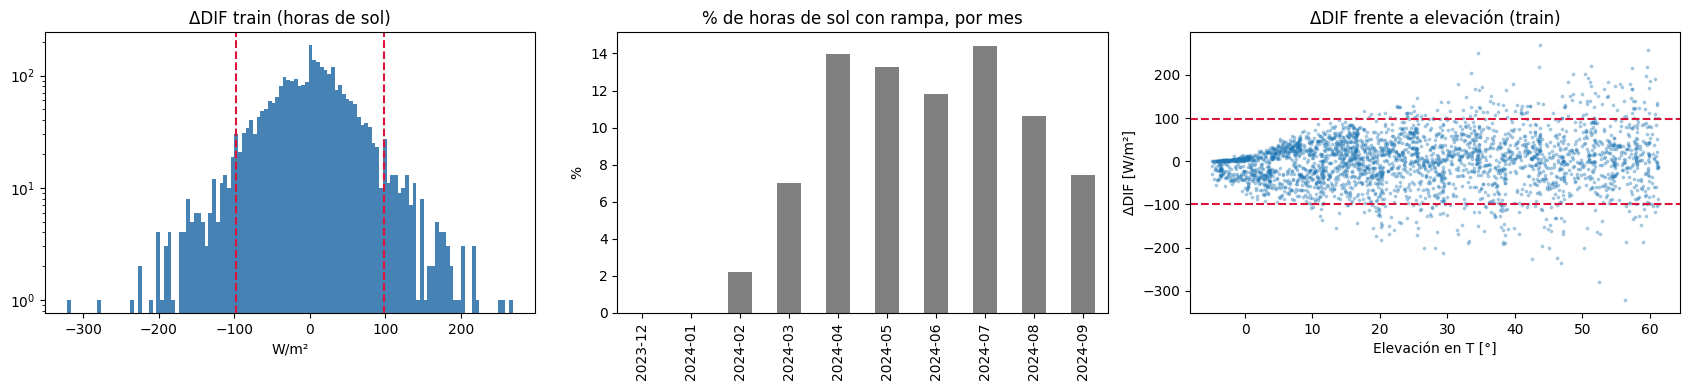

Guardado en: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/diagnostico/faseA_rampas


In [ ]:
import os, glob
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

RUTA_PARQUET = (
    "/content/drive/MyDrive/TFM Aghmir/TFM/radiation_data_completo.parquet"  # <-- CAMBIAR
)
PERCENTIL = 90
LAT, LON = 51.9711, 4.9267
DIR_R = os.path.join(BASE_DIR, "resultados", "diagnostico", "faseA_rampas")
os.makedirs(DIR_R, exist_ok=True)

# 1) Vía A: los datos ya preparados (y = DIF(T); DIF(T−1) = último paso de la ventana)
cand = glob.glob(os.path.join(BASE_DIR, "**", "matrices_dif_elev_difstats.npz"), recursive=True)
assert cand, "No encuentro matrices_dif_elev_difstats.npz bajo BASE_DIR"
RUTA_NPZ = sorted(cand)[-1]
dat = np.load(RUTA_NPZ, allow_pickle=True)
print("NPZ:", RUTA_NPZ)

def via_A(Xk, yk, fk):
    X = dat[Xk]
    y = dat[yk].astype(float).ravel()
    f = pd.DatetimeIndex(pd.to_datetime(dat[fk]))
    # identificar el canal DIF: el que en la muestra i+1 (último paso) coincide con y de la muestra i
    consec = np.diff(f.values).astype("timedelta64[m]").astype(int) == 60
    err = [np.nanmean(np.abs(X[1:, -1, c][consec] - y[:-1][consec])) for c in range(X.shape[2])]
    c = int(np.nanargmin(err))
    print(f"  {Xk}: canal DIF = {c} (MAE de comprobación {err[c]:.4f} W/m²)")
    assert err[c] < 0.01, "Ningún canal coincide con DIF(T−1): revisar la preparación"
    return pd.DataFrame({"DIF_T": y, "DIF_T1": X[:, -1, c].astype(float)}, index=f)

A_tr = via_A("X_train_DIF_elev_DIFstats_raw", "y_train_difstats", "fechas_train")
A_va = via_A("X_validation_DIF_elev_DIFstats_raw", "y_validation_difstats", "fechas_validation")
for A in (A_tr, A_va):
    A["dDIF"] = A["DIF_T"] - A["DIF_T1"]

# 2) Vía B (control): recalcular desde el dataset minutal original
#    media horaria (>=30 min válidos), hora etiquetada por su inicio, y ΔDIF = h(T) − h(T−1)
raw = pd.read_parquet(RUTA_PARQUET, columns=["Date/Time", "DIF [W/m**2]"])
dif_min = raw.set_index("Date/Time")["DIF [W/m**2]"].astype(float).sort_index()
dif_min = dif_min[dif_min.index < "2024-10-01"]  # sin leer el test
g = dif_min.groupby(dif_min.index.floor("h"))
dif_h = g.mean().where(g.count() >= 30).asfreq("h")
dB = dif_h - dif_h.shift(1)
for nombre, A in [("train", A_tr), ("validación", A_va)]:
    b = dB.reindex(A.index)
    dif = (A["dDIF"] - b).abs()
    print(
        f"Control A vs B ({nombre}): {b.notna().sum()}/{len(A)} horas comparables | "
        f"máx |dif| = {dif.max():.4f} | coinciden (<0.01): {100*(dif < 0.01).mean():.1f} %"
    )


# 3) Horas de sol en T (fracción de minutos con elevación aparente > 0, como en los regímenes)
def elevacion_solar(idx, lat=LAT, lon=LON):
    jd = idx.to_julian_date().to_numpy()
    jc = (jd - 2451545.0) / 36525.0
    L0 = np.mod(280.46646 + jc * (36000.76983 + jc * 0.0003032), 360)
    M = 357.52911 + jc * (35999.05029 - 0.0001537 * jc)
    Mr = np.radians(M)
    e = 0.016708634 - jc * (0.000042037 + 0.0000001267 * jc)
    C = (
        np.sin(Mr) * (1.914602 - jc * (0.004817 + 0.000014 * jc))
        + np.sin(2 * Mr) * (0.019993 - 0.000101 * jc)
        + np.sin(3 * Mr) * 0.000289
    )
    om = 125.04 - 1934.136 * jc
    lam = L0 + C - 0.00569 - 0.00478 * np.sin(np.radians(om))
    eps0 = 23 + (26 + (21.448 - jc * (46.815 + jc * (0.00059 - jc * 0.001813))) / 60) / 60
    eps = np.radians(eps0 + 0.00256 * np.cos(np.radians(om)))
    dec = np.arcsin(np.sin(eps) * np.sin(np.radians(lam)))
    yy = np.tan(eps / 2) ** 2
    L0r = np.radians(L0)
    eot = 4 * np.degrees(
        yy * np.sin(2 * L0r)
        - 2 * e * np.sin(Mr)
        + 4 * e * yy * np.sin(Mr) * np.cos(2 * L0r)
        - 0.5 * yy * yy * np.sin(4 * L0r)
        - 1.25 * e * e * np.sin(2 * Mr)
    )
    mins = idx.hour.to_numpy() * 60 + idx.minute.to_numpy()
    ha = np.radians((mins + eot + 4 * lon) / 4 - 180)
    latr = np.radians(lat)
    el = np.degrees(np.arcsin(np.sin(latr) * np.sin(dec) + np.cos(latr) * np.cos(dec) * np.cos(ha)))
    return el + np.where(el > -0.575, 1.02 / np.tan(np.radians(el + 10.3 / (el + 5.11))) / 60, 0)

def geometria(idx_horas):
    mins = pd.DatetimeIndex(np.repeat(idx_horas.values, 60)) + pd.to_timedelta(
        np.tile(np.arange(60), len(idx_horas)), "m"
    )
    el = elevacion_solar(mins).reshape(-1, 60)
    return pd.DataFrame({"elev": el.mean(1), "frac_dia": (el > 0).mean(1)}, index=idx_horas)

for A in (A_tr, A_va):
    A[["elev", "frac_dia"]] = geometria(A.index)
    A["regimen"] = np.select(
        [A["frac_dia"] == 0, A["frac_dia"] < 1], ["noche", "transicion"], "completamente_diurno"
    )
    A["banda"] = pd.cut(
        A["elev"], [-90, 20, 40, 90], labels=["hombros ≤20°", "intermedia 20–40°", "central >40°"]
    )
    A["sol"] = (A["regimen"] != "noche") & A["dDIF"].notna()

print(
    f"\nHoras de sol: train {A_tr['sol'].sum()} | validación {A_va['sol'].sum()}  "
    f"(en E7 la máscara 'operación' de validación tenía 884)"
)

# 4) Distribución de ΔDIF en TRAIN (horas de sol) y umbral
d_tr = A_tr.loc[A_tr["sol"], "dDIF"]
desc = pd.Series(
    {
        "n": len(d_tr),
        "media": d_tr.mean(),
        "mediana": d_tr.median(),
        "desv. típica": d_tr.std(),
        "asimetría": d_tr.skew(),
        "curtosis (exceso)": d_tr.kurt(),
        "P5 ΔDIF": d_tr.quantile(0.05),
        "P95 ΔDIF": d_tr.quantile(0.95),
        "P50 |ΔDIF|": d_tr.abs().quantile(0.5),
        "P75 |ΔDIF|": d_tr.abs().quantile(0.75),
        "P90 |ΔDIF|": d_tr.abs().quantile(0.9),
        "P95 |ΔDIF|": d_tr.abs().quantile(0.95),
        "P99 |ΔDIF|": d_tr.abs().quantile(0.99),
    }
)
print("\n=== DISTRIBUCIÓN ΔDIF — TRAIN, horas de sol [W/m²] ===")
display(desc.round(2).to_frame("valor"))
UMBRAL = float(d_tr.abs().quantile(PERCENTIL / 100))
print(
    f"UMBRAL DE RAMPA (p{PERCENTIL} |ΔDIF| train) = {UMBRAL:.2f} W/m²  ← se fija aquí y no se recalcula"
)

def etiquetar(A):
    c = np.where(A["dDIF"] >= UMBRAL, 1, np.where(A["dDIF"] <= -UMBRAL, -1, 0)).astype(float)
    return pd.Series(c, index=A.index).where(
        A["sol"]
    )  # noche / sin dato -> NaN (fuera del problema)

A_tr["C"] = etiquetar(A_tr)
A_va["C"] = etiquetar(A_va)
A_tr["R"] = A_tr["C"].abs()
A_va["R"] = A_va["C"].abs()


# 5) Cuántas rampas hay y dónde
def conteo(A):
    c = A.loc[A["sol"], "C"].value_counts().reindex([-1.0, 0.0, 1.0], fill_value=0)
    return pd.Series(
        {
            "bajadas (−1)": c[-1.0],
            "sin rampa (0)": c[0.0],
            "subidas (+1)": c[1.0],
            "% rampas": 100 * (c[-1.0] + c[1.0]) / c.sum(),
        }
    )

print("\n=== CLASES C_t ===")
display(pd.DataFrame({"train": conteo(A_tr), "validación": conteo(A_va)}).T.round(1))

def por_grupo(A, clave):
    s = A[A["sol"]]
    return pd.DataFrame(
        {
            "horas": s.groupby(clave, observed=True).size(),
            "bajadas": s.groupby(clave, observed=True)["C"].apply(lambda x: (x == -1).sum()),
            "subidas": s.groupby(clave, observed=True)["C"].apply(lambda x: (x == 1).sum()),
            "% rampas": s.groupby(clave, observed=True)["R"].mean() * 100,
            "p90 |ΔDIF| propio": s.groupby(clave, observed=True)["dDIF"].apply(
                lambda x: x.abs().quantile(0.9)
            ),
        }
    )

print("\n=== POR MES (train + validación) ===")
for A in (A_tr, A_va):
    A["mes"] = A.index.to_period("M").astype(str)
display(pd.concat([por_grupo(A_tr, "mes"), por_grupo(A_va, "mes")]).round(1))
print("\n=== POR RÉGIMEN Y BANDA DE ELEVACIÓN EN T ===")
for nombre, A in [("train", A_tr), ("validación", A_va)]:
    print(f"-- {nombre}")
    display(por_grupo(A, "regimen").round(1))
    display(por_grupo(A, "banda").round(1))

# Comparación con la máscara de rampas usada en E1–E7 (umbral calculado entonces en validación)
try:
    m_prev = pd.Series(np.asarray(MASCARAS["rampas"], bool), index=pd.DatetimeIndex(df.index))
    nueva = A_va["R"].reindex(m_prev.index).fillna(0).astype(bool)
    print(
        f"\nRampas validación — definición anterior: {m_prev.sum()} | nueva: {nueva.sum()} | "
        f"en ambas: {(m_prev & nueva).sum()}"
    )
except Exception as e:
    print(f"\n(No se compara con la máscara anterior: {e})")

# 6) Figuras
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
ax[0].hist(d_tr, bins=120, color="steelblue")
for u in (-UMBRAL, UMBRAL):
    ax[0].axvline(u, color="crimson", ls="--")
ax[0].set_yscale("log")
ax[0].set_title("ΔDIF train (horas de sol)")
ax[0].set_xlabel("W/m²")
pm = pd.concat([A_tr[A_tr["sol"]], A_va[A_va["sol"]]])
pm.groupby(pm.index.to_period("M"))["R"].mean().mul(100).plot.bar(ax=ax[1], color="gray")
ax[1].set_title("% de horas de sol con rampa, por mes")
ax[1].set_ylabel("%")
ax[2].scatter(A_tr.loc[A_tr["sol"], "elev"], A_tr.loc[A_tr["sol"], "dDIF"], s=3, alpha=0.3)
for u in (-UMBRAL, UMBRAL):
    ax[2].axhline(u, color="crimson", ls="--")
ax[2].set_xlabel("Elevación en T [°]")
ax[2].set_ylabel("ΔDIF [W/m²]")
ax[2].set_title("ΔDIF frente a elevación (train)")
plt.tight_layout()
plt.savefig(os.path.join(DIR_R, "rampas_distribucion.png"), dpi=130)
plt.show()

# 7) Guardar las etiquetas (base para la fase A)
salida = pd.concat([A_tr.assign(conjunto="train"), A_va.assign(conjunto="validation")])
salida.to_csv(os.path.join(DIR_R, "rampas_Ct_train_validation.csv"), index_label="fecha")
with open(os.path.join(DIR_R, "umbral_rampa.txt"), "w") as f:
    f.write(f"p{PERCENTIL} |ΔDIF| horas de sol train = {UMBRAL:.4f} W/m2\n")
print("Guardado en:", DIR_R)

**Resultados.** El umbral es de 97,78 W/m². En las 3.027 horas con sol de entrenamiento hay 147 bajadas y 156 subidas (10,0 %), y en las 884 de validación, 45 bajadas y 36 subidas (9,2 %). Las 81 rampas de validación están incluidas en las 89 de la definición provisional. No hay rampas en transición, y su frecuencia depende de la estación y de la elevación: en entrenamiento va del 0 % en enero al 14,4 % en julio, y del 2,2 % en los hombros al 18,6 % en la banda central.

### 4.2 Muestra para el estudio de las rampas

El estudio de la anticipabilidad se restringe a las horas completamente diurnas, porque en transición no hay rampas ni en entrenamiento ni en validación, y se registran la definición del objetivo y sus limitaciones: pocas rampas en los hombros, fuerte estacionalidad y ausencia de meses de otoño en entrenamiento.

In [ ]:
import os, json
import numpy as np, pandas as pd

DIR_R = os.path.join(BASE_DIR, "resultados", "diagnostico", "faseA_rampas")
et = pd.read_csv(
    os.path.join(DIR_R, "rampas_Ct_train_validation.csv"), parse_dates=["fecha"], index_col="fecha"
)
UMBRAL = float(open(os.path.join(DIR_R, "umbral_rampa.txt")).read().split("=")[1].split()[0])

# Decisión: muestra = horas completamente diurnas con ΔDIF definido
muestra = et[(et["regimen"] == "completamente_diurno") & et["C"].notna()].copy()
muestra["C"] = muestra["C"].astype(int)

# Comprobación: no se pierde ninguna rampa al excluir transición
perdidas = int(et.loc[(et["regimen"] == "transicion"), "R"].fillna(0).sum())
print(f"Umbral fijado: {UMBRAL:.2f} W/m² | rampas en transición que se excluyen: {perdidas}")
resumen = (
    muestra.groupby(["conjunto", "C"])
    .size()
    .unstack(fill_value=0)
    .rename(columns={-1: "bajadas (−1)", 0: "sin rampa (0)", 1: "subidas (+1)"})
)
resumen["horas"] = resumen.sum(axis=1)
resumen["% rampas"] = 100 * (resumen["bajadas (−1)"] + resumen["subidas (+1)"]) / resumen["horas"]
display(resumen.round(1))
muestra.to_csv(os.path.join(DIR_R, "muestra_faseA_diurna.csv"), index_label="fecha")
decisiones = {
    "delta": "ΔDIF = DIF(T) − DIF(T−1), medias horarias (hora etiquetada por inicio, >=30 min válidos); "
    "misma magnitud que y; verificado: datos preparados = parquet original (100 %)",
    "umbral": f"p90 de |ΔDIF| en horas de sol de train = {UMBRAL:.2f} W/m2 (fijo, no se recalcula)",
    "objetivo": "C_t ∈ {−1, 0, +1}: −1 si ΔDIF ≤ −umbral; +1 si ΔDIF ≥ umbral; 0 en otro caso",
    "muestra": "solo horas completamente diurnas (transición tiene 0 rampas en train y validación)",
    "limitaciones": [
        "hombros (≤20°): 30 rampas en train y 9 en validación, sin potencia para concluir",
        "fuerte estacionalidad: 0 % rampas en enero, 12–14 % abril–julio",
        "train sin meses de otoño (empieza a finales de dic-2023)",
    ],
    "conteo": resumen.reset_index().to_dict(orient="records"),
}
with open(os.path.join(DIR_R, "decisiones_definicion_rampas.json"), "w") as f:
    json.dump(decisiones, f, ensure_ascii=False, indent=2, default=int)
print("Guardado: muestra_faseA_diurna.csv y decisiones_definicion_rampas.json en", DIR_R)

Umbral fijado: 97.78 W/m² | rampas en transición que se excluyen: 0


C,bajadas (−1),sin rampa (0),subidas (+1),horas,% rampas
conjunto,,,,,
train,147,2301,156,2604,11.6
validation,45,684,36,765,10.6


Guardado: muestra_faseA_diurna.csv y decisiones_definicion_rampas.json en /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/diagnostico/faseA_rampas


**Resultados.** Al excluir la transición se conservan todas las rampas, y la muestra queda en 2.604 horas completamente diurnas de entrenamiento, con un 11,6 % de rampas, y 765 de validación, con un 10,6 %.

### 4.3 Anticipabilidad de las rampas

Se estudia si, con la información disponible al emitir, pueden anticiparse las subidas y las bajadas, y si las demás variables de la estación añaden algo a lo que ya ve E1 (fase A). Para ello se entrenan, con hiperparámetros fijos, un HGB de tres clases y una regresión logística multinomial sobre tres conjuntos de variables anidados: I0, climatología (elevación, hora y día del año); I1, lo que ve E1 (sus canales en las últimas horas, la DIF de horas anteriores y la rampa previa), e I2, I1 más variables nuevas del conjunto de datos completo, como la claridad, la intermitencia del sol, la onda larga o las tendencias de humedad, temperatura y presión. Se evalúan con validación cruzada dejando un mes fuera en entrenamiento y después en validación, mediante la PR-AUC de cada dirección frente a su tasa base.

In [ ]:
import os, json, time, warnings
import numpy as np, pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import average_precision_score, roc_auc_score

warnings.filterwarnings("ignore")
RUTA_PARQUET = (
    "/content/drive/MyDrive/TFM Aghmir/TFM/radiation_data_completo.parquet"  # <-- CAMBIAR
)
LAT, LON = 51.9711, 4.9267
SEMILLA, N_BOOT = 0, 1000
DIR_R = os.path.join(BASE_DIR, "resultados", "diagnostico", "faseA_rampas")
DIR_FA = os.path.join(BASE_DIR, "resultados", "diagnostico", "faseA_anticipabilidad")
os.makedirs(DIR_FA, exist_ok=True)
t0 = time.time()

# 1) Etiquetas y muestra (de R1/R1b, sin recalcular)
muestra = pd.read_csv(
    os.path.join(DIR_R, "muestra_faseA_diurna.csv"), parse_dates=["fecha"], index_col="fecha"
)
UMBRAL = float(open(os.path.join(DIR_R, "umbral_rampa.txt")).read().split("=")[1].split()[0])
print(f"Umbral fijado: {UMBRAL:.2f} W/m² | muestra: {len(muestra)} horas")

# 2) Datos minutales (solo hasta 30-sep-2024: el test no se lee)
raw = pd.read_parquet(RUTA_PARQUET)
raw = raw.rename(columns={"Date/Time": "t"}).set_index("t").sort_index()
raw = raw[raw.index < "2024-10-01"]
ren = {
    "SWD [W/m**2]": "SWD",
    "DIR [W/m**2]": "DIR",
    "DIF [W/m**2]": "DIF",
    "LWD [W/m**2]": "LWD",
    "SWU [W/m**2]": "SWU",
    "LWU [W/m**2]": "LWU",
    "SWD std dev [W/m**2]": "SWD_sd1m",
    "DIR std dev [W/m**2]": "DIR_sd1m",
    "LWD std dev [W/m**2]": "LWD_sd1m",
    "T2 [°C]": "T2",
    "RH [%]": "RH",
    "PoPoPoPo [hPa]": "P",
}
m = raw[list(ren)].rename(columns=ren).astype(float)
m = m[~m.index.duplicated()].asfreq("1min")


# Posición solar, cielo despejado y agregación horaria (misma convención que R1)
def elevacion_solar(idx, lat=LAT, lon=LON):
    jd = idx.to_julian_date().to_numpy()
    jc = (jd - 2451545.0) / 36525.0
    L0 = np.mod(280.46646 + jc * (36000.76983 + jc * 0.0003032), 360)
    M = 357.52911 + jc * (35999.05029 - 0.0001537 * jc)
    e = 0.016708634 - jc * (0.000042037 + 0.0000001267 * jc)
    Mr = np.radians(M)
    C = (
        np.sin(Mr) * (1.914602 - jc * (0.004817 + 0.000014 * jc))
        + np.sin(2 * Mr) * (0.019993 - 0.000101 * jc)
        + np.sin(3 * Mr) * 0.000289
    )
    om = 125.04 - 1934.136 * jc
    lam = L0 + C - 0.00569 - 0.00478 * np.sin(np.radians(om))
    eps0 = 23 + (26 + (21.448 - jc * (46.815 + jc * (0.00059 - jc * 0.001813))) / 60) / 60
    eps = np.radians(eps0 + 0.00256 * np.cos(np.radians(om)))
    dec = np.arcsin(np.sin(eps) * np.sin(np.radians(lam)))
    y = np.tan(eps / 2) ** 2
    L0r = np.radians(L0)
    eot = 4 * np.degrees(
        y * np.sin(2 * L0r)
        - 2 * e * np.sin(Mr)
        + 4 * e * y * np.sin(Mr) * np.cos(2 * L0r)
        - 0.5 * y * y * np.sin(4 * L0r)
        - 1.25 * e * e * np.sin(2 * Mr)
    )
    minutos = idx.hour.to_numpy() * 60 + idx.minute.to_numpy() + idx.second.to_numpy() / 60
    ha = np.radians((minutos + eot + 4 * lon) / 4 - 180)
    latr = np.radians(lat)
    el = np.degrees(np.arcsin(np.sin(latr) * np.sin(dec) + np.cos(latr) * np.cos(dec) * np.cos(ha)))
    # refracción aproximada (elevación aparente)
    ref = np.where(el > -0.575, 1.02 / np.tan(np.radians(el + 10.3 / (el + 5.11))) / 60, 0)
    return el + ref

m["elev"] = elevacion_solar(m.index)
cosz = np.clip(np.sin(np.radians(m["elev"])), 0, None)
m["GHI_cs"] = np.where(
    cosz > 0.01, 1098 * cosz * np.exp(-0.057 / np.maximum(cosz, 0.01)), 0
)  # Haurwitz

# Cielo despejado en onda larga (Prata 1996) -> índice de nubosidad de TODO el cielo
Tk = m["T2"] + 273.15
es = 6.112 * np.exp(17.67 * m["T2"] / (m["T2"] + 243.5))
ea = es * m["RH"] / 100
w = 46.5 * ea / Tk
eps_cs = 1 - (1 + w) * np.exp(-np.sqrt(1.2 + 3 * w))
m["LWD_cs"] = eps_cs * 5.670374e-8 * Tk**4
m["CI_lw"] = m["LWD"] / m["LWD_cs"]  # >1 => nubes (en cualquier parte del cielo)
m["Td_dep"] = m["T2"] - (243.5 * np.log(ea / 6.112) / (17.67 - np.log(ea / 6.112)))  # T - Tdew
m["LWnet"] = m["LWD"] - m["LWU"]  # muy negativo con cielo despejado
m["sol_visible"] = (
    (m["DIR"] > 120).astype(float).where(m["DIR"].notna())
)  # criterio OMM de insolación

def pendiente(v):
    v = np.asarray(v, float)
    ok = ~np.isnan(v)
    if ok.sum() < 5:
        return np.nan
    x = np.arange(len(v))[ok] / 60.0
    return np.polyfit(x, v[ok], 1)[0]  # unidades / hora

def acel(v):
    v = np.asarray(v, float)
    ok = ~np.isnan(v)
    if ok.sum() < 10:
        return np.nan
    x = np.arange(len(v))[ok] / 60.0
    return 2 * np.polyfit(x, v[ok], 2)[0]

def por_hora(g):
    out = {}
    dif = g["DIF"].to_numpy()
    swd = g["SWD"].to_numpy()
    dirr = g["DIR"].to_numpy()
    out["DIF_media"] = np.nanmean(dif) if np.isfinite(dif).sum() >= 30 else np.nan
    out["n_validos"] = np.isfinite(dif).sum()
    # --- canales de E1 (historia de DIF) ---
    out["DIF_std"] = np.nanstd(dif)
    out["DIF_rango"] = np.nanmax(dif) - np.nanmin(dif) if np.isfinite(dif).any() else np.nan
    out["DIF_ult15"] = np.nanmean(dif[-15:]) if np.isfinite(dif[-15:]).any() else np.nan
    out["DIF_pend30"] = pendiente(dif[-30:])
    out["DIF_acel60"] = acel(dif)
    d1 = np.abs(np.diff(dif))
    out["DIF_saltos"] = np.nanmean(d1 > 20) if np.isfinite(d1).any() else np.nan
    mu = np.nanmean(swd) if np.isfinite(swd).any() else np.nan
    out["SWD_cv"] = np.nanstd(swd) / mu if (mu is not np.nan and mu > 20) else 0.0
    # --- dinámica meteorológica / radiativa NUEVA ---
    ghi_cs = g["GHI_cs"].to_numpy()
    with np.errstate(all="ignore"):
        kt = np.where(ghi_cs > 20, swd / ghi_cs, np.nan)
        kd = np.where(swd > 20, dif / swd, np.nan)
    out["kt"] = np.nanmean(kt) if np.isfinite(kt).any() else np.nan
    out["kt_ult15"] = np.nanmean(kt[-15:]) if np.isfinite(kt[-15:]).any() else np.nan
    out["kt_std"] = np.nanstd(kt) if np.isfinite(kt).sum() > 5 else np.nan
    out["kd"] = np.nanmean(kd) if np.isfinite(kd).any() else np.nan
    out["kd_pend30"] = pendiente(kd[-30:])
    sv = g["sol_visible"].to_numpy()
    out["sol_frac"] = np.nanmean(sv) if np.isfinite(sv).any() else np.nan
    out["sol_frac_ult15"] = np.nanmean(sv[-15:]) if np.isfinite(sv[-15:]).any() else np.nan
    svv = sv[np.isfinite(sv)]
    out["bordes_nube"] = (
        np.sum(np.abs(np.diff(svv))) if len(svv) > 1 else np.nan
    )  # cambios sol<->sombra
    out["DIR_pend30"] = pendiente(dirr[-30:])
    out["DIR_cv"] = np.nanstd(dirr) / np.nanmean(dirr) if np.nanmean(dirr) > 20 else 0.0
    out["SWD_sd1m"] = np.nanmean(g["SWD_sd1m"])  # variabilidad sub-minutal
    out["DIR_sd1m"] = np.nanmean(g["DIR_sd1m"])
    out["CI_lw"] = np.nanmean(g["CI_lw"])
    out["CI_lw_ult15"] = np.nanmean(g["CI_lw"].to_numpy()[-15:])
    out["CI_lw_pend60"] = pendiente(g["CI_lw"].to_numpy())
    out["LWD_sd1m"] = np.nanmean(g["LWD_sd1m"])
    out["LWD_std"] = np.nanstd(g["LWD"])
    out["LWnet"] = np.nanmean(g["LWnet"])
    out["RH"] = np.nanmean(g["RH"])
    out["RH_pend60"] = pendiente(g["RH"].to_numpy())
    out["T2"] = np.nanmean(g["T2"])
    out["T2_pend60"] = pendiente(g["T2"].to_numpy())
    out["Td_dep"] = np.nanmean(g["Td_dep"])
    out["P"] = np.nanmean(g["P"])
    out["albedo"] = np.nanmean(g["SWU"]) / mu if (mu is not np.nan and mu > 50) else np.nan
    out["elev"] = g["elev"].mean()
    out["frac_dia"] = (g["elev"] > 0).mean()
    return pd.Series(out)

print("Agregando a horas (1–3 min)...")
h = m.groupby(m.index.floor("h")).apply(por_hora).asfreq("h")
print(f"Horas: {len(h):,} ({time.time()-t0:.0f} s)")

# control: el DIF horario reconstruido debe coincidir con el de las etiquetas
ctrl = (h["DIF_media"].reindex(muestra.index) - muestra["DIF_T"]).abs()
print(f"Control DIF horario vs etiquetas: máx |dif| = {ctrl.max():.4f} W/m²")
assert ctrl.max() < 0.01, "El DIF horario no coincide con R1: revisar"

# Rampa en cada hora (con el MISMO umbral fijo) para poder usar C(T−1) como variable
h["dDIF"] = h["DIF_media"] - h["DIF_media"].shift(1)
h["C_hora"] = np.where(h["dDIF"] >= UMBRAL, 1, np.where(h["dDIF"] <= -UMBRAL, -1, 0)).astype(float)
h.loc[h["dDIF"].isna(), "C_hora"] = np.nan

# 3) Variables en el origen de predicción (info ≤ cierre de T−1 + geometría de T)
X = pd.DataFrame(index=h.index)
# I0 — climatología / geometría
X["elev_T"] = h["elev"]
X["d_elev_T"] = h["elev"] - h["elev"].shift(1)
hora = h.index.hour + 0.5
X["hora_sin"], X["hora_cos"] = np.sin(2 * np.pi * hora / 24), np.cos(2 * np.pi * hora / 24)
doy = h.index.dayofyear
X["doy_sin"], X["doy_cos"] = np.sin(2 * np.pi * doy / 365.25), np.cos(2 * np.pi * doy / 365.25)
I0 = list(X.columns)
# I1 — lo que ve E1
for c in [
    "DIF_media",
    "DIF_std",
    "DIF_rango",
    "DIF_ult15",
    "DIF_pend30",
    "DIF_acel60",
    "DIF_saltos",
    "SWD_cv",
]:
    for k in (1, 2, 3):
        X[f"{c}_L{k}"] = h[c].shift(k)
for k in (4, 5, 6, 24):
    X[f"DIF_media_L{k}"] = h["DIF_media"].shift(k)
X["elev_L1"] = h["elev"].shift(1)
X["dDIF_L1"], X["dDIF_L2"] = h["dDIF"].shift(1), h["dDIF"].shift(2)
X["C_L1"] = h["C_hora"].shift(1)  # rampa previa con signo
I1 = list(X.columns)
# I2 — I1 + variables nuevas del dataset completo
NUEVAS = [
    "kt",
    "kt_ult15",
    "kt_std",
    "kd",
    "kd_pend30",
    "sol_frac",
    "sol_frac_ult15",
    "bordes_nube",
    "DIR_pend30",
    "DIR_cv",
    "SWD_sd1m",
    "DIR_sd1m",
    "CI_lw",
    "CI_lw_ult15",
    "CI_lw_pend60",
    "LWD_sd1m",
    "LWD_std",
    "LWnet",
    "RH",
    "RH_pend60",
    "T2_pend60",
    "Td_dep",
    "albedo",
]
for c in NUEVAS:
    X[f"{c}_L1"] = h[c].shift(1)
for c in ["kt", "sol_frac", "CI_lw", "bordes_nube"]:
    X[f"{c}_L2"] = h[c].shift(2)
X["CI_lw_tend3h"] = h["CI_lw"].shift(1) - h["CI_lw"].shift(4)
X["RH_tend3h"] = h["RH"].shift(1) - h["RH"].shift(4)
X["P_tend3h"] = h["P"].shift(1) - h["P"].shift(4)
X["T2_tend3h"] = h["T2"].shift(1) - h["T2"].shift(4)
I2 = list(X.columns)
CONJ = {"I0": I0, "I1": I1, "I2": I2}
print(f"Variables: I0={len(I0)} | I1={len(I1)} | I2={len(I2)}")
X = X.reindex(muestra.index)
y = muestra["C"].to_numpy(int)
tr = (muestra["conjunto"] == "train").to_numpy()
va = (muestra["conjunto"] == "validation").to_numpy()
dias = muestra.index.normalize().to_numpy()
CLASES = np.array([-1, 0, 1])


# 4) Modelos (hiperparámetros fijos, sin ajuste)
def hgb():
    return HistGradientBoostingClassifier(
        max_iter=300,
        learning_rate=0.05,
        max_leaf_nodes=15,
        min_samples_leaf=40,
        l2_regularization=1.0,
        random_state=SEMILLA,
    )

def logit():
    return make_pipeline(
        SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(C=0.1, max_iter=3000)
    )

MODELOS = {"HGB": hgb, "Logística": logit}

def proba(mdl, Xp):
    p = mdl.predict_proba(Xp)
    out = np.zeros((len(Xp), 3))
    for j, c in enumerate(mdl.classes_):
        out[:, np.where(CLASES == c)[0][0]] = p[:, j]
    return out


# 5) Validación: dejar un mes fuera en train (dic-2023 se une a ene-2024) y confirmación en validación
mes = muestra.index.to_period("M").astype(str).to_numpy()
mes = np.where(mes == "2023-12", "2024-01", mes)
meses_tr = np.unique(mes[tr])
print("Pliegues en train:", list(meses_tr))
P_cv, P_va = {}, {}
for nm, fab in MODELOS.items():
    for nc, cols in CONJ.items():
        Xtr = X.loc[tr, cols].to_numpy(float)
        ytr = y[tr]
        mtr = mes[tr]
        p = np.zeros((tr.sum(), 3))
        for g in meses_tr:
            te = mtr == g
            p[te] = proba(fab().fit(Xtr[~te], ytr[~te]), Xtr[te])
        P_cv[(nm, nc)] = p
        P_va[(nm, nc)] = proba(fab().fit(Xtr, ytr), X.loc[va, cols].to_numpy(float))
print(f"Modelos entrenados ({time.time()-t0:.0f} s)")


# 6) Métricas: PR-AUC por dirección (frente a tasa base), ROC-AUC, Brier skill
def brier_skill(ytrue, p, frec_clim):
    Y = (ytrue[:, None] == CLASES[None, :]).astype(float)
    bs = np.mean(np.sum((p - Y) ** 2, axis=1))
    bs_ref = np.mean(np.sum((frec_clim[None, :] - Y) ** 2, axis=1))
    return 1 - bs / bs_ref

frec_train = np.array([(y[tr] == c).mean() for c in CLASES])  # climatología de train

def metricas(ytrue, p):
    r = {}
    for c, nom in [(1, "subidas"), (-1, "bajadas")]:
        j = np.where(CLASES == c)[0][0]
        yb = (ytrue == c).astype(int)
        r[f"tasa base {nom}"] = yb.mean()
        r[f"PR-AUC {nom}"] = average_precision_score(yb, p[:, j])
        r[f"ROC-AUC {nom}"] = roc_auc_score(yb, p[:, j])
    r["Brier skill"] = brier_skill(ytrue, p, frec_train)
    return r

filas = []
for (nm, nc), p in P_cv.items():
    filas.append({"evaluación": "CV train", "modelo": nm, "conjunto": nc, **metricas(y[tr], p)})
for (nm, nc), p in P_va.items():
    filas.append({"evaluación": "validación", "modelo": nm, "conjunto": nc, **metricas(y[va], p)})
tabla = pd.DataFrame(filas).set_index(["evaluación", "modelo", "conjunto"])
tabla.to_csv(os.path.join(DIR_FA, "metricas_I0_I1_I2.csv"))
print("\n=== MÉTRICAS ===")
display(
    tabla[
        [
            "tasa base subidas",
            "PR-AUC subidas",
            "tasa base bajadas",
            "PR-AUC bajadas",
            "ROC-AUC subidas",
            "ROC-AUC bajadas",
            "Brier skill",
        ]
    ].round(3)
)


# Diferencias entre conjuntos con IC95 por bootstrap de días (descriptivo; el veredicto va en el punto 8)
def boot_dif(ytrue, pa, pb, d, c):
    j = np.where(CLASES == c)[0][0]
    yb = (ytrue == c).astype(int)
    rng = np.random.default_rng(SEMILLA)
    u, inv = np.unique(d, return_inverse=True)
    grupos = [np.where(inv == i)[0] for i in range(len(u))]
    base = average_precision_score(yb, pa[:, j]) - average_precision_score(yb, pb[:, j])
    difs = []
    for _ in range(N_BOOT):
        s = np.concatenate([grupos[i] for i in rng.integers(0, len(u), len(u))])
        if yb[s].sum() == 0:
            continue
        difs.append(
            average_precision_score(yb[s], pa[s, j]) - average_precision_score(yb[s], pb[s, j])
        )
    lo, hi = np.percentile(difs, [2.5, 97.5])
    return base, lo, hi

filas = []
for ev, P, msk in [("CV train", P_cv, tr), ("validación", P_va, va)]:
    for nm in MODELOS:
        for a, b in [("I1", "I0"), ("I2", "I1")]:
            for c, nom in [(1, "subidas"), (-1, "bajadas")]:
                d, lo, hi = boot_dif(y[msk], P[(nm, a)], P[(nm, b)], dias[msk], c)
                filas.append(
                    {
                        "evaluación": ev,
                        "modelo": nm,
                        "contraste": f"{a} − {b}",
                        "clase": nom,
                        "ΔPR-AUC": d,
                        "IC95 inf": lo,
                        "IC95 sup": hi,
                        "IC excluye 0": (lo > 0) or (hi < 0),
                    }
                )
contrastes = pd.DataFrame(filas)
contrastes.to_csv(os.path.join(DIR_FA, "contrastes_I0_I1_I2.csv"), index=False)
print("\n=== DIFERENCIAS DE PR-AUC (IC95 por días) ===")
display(contrastes.round(3))
pd.to_pickle(
    {
        "X": X,
        "y": y,
        "tr": tr,
        "va": va,
        "dias": dias,
        "CONJ": CONJ,
        "P_cv": P_cv,
        "P_va": P_va,
        "UMBRAL": UMBRAL,
    },
    os.path.join(DIR_FA, "faseA_puntos1_6.pkl"),
)
print(f"\nTiempo total: {(time.time()-t0)/60:.1f} min | Resultados en: {DIR_FA}")

Umbral fijado: 97.78 W/m² | muestra: 3369 horas
Agregando a horas (1–3 min)...
Horas: 8,040 (60 s)
Control DIF horario vs etiquetas: máx |dif| = 0.0000 W/m²
Variables: I0=6 | I1=38 | I2=69
Pliegues en train: ['2024-01', '2024-02', '2024-03', '2024-04', '2024-05', '2024-06', '2024-07']
Modelos entrenados (146 s)

=== MÉTRICAS ===


tasa base subidas  PR-AUC subidas  \
evaluación modelo    conjunto                                      
CV train   HGB       I0                    0.060           0.131   
                     I1                    0.060           0.229   
                     I2                    0.060           0.304   
           Logística I0                    0.060           0.132   
                     I1                    0.060           0.273   
                     I2                    0.060           0.284   
validación HGB       I0                    0.047           0.124   
                     I1                    0.047           0.297   
                     I2                    0.047           0.244   
           Logística I0                    0.047           0.115   
                     I1                    0.047           0.272   
                     I2                    0.047           0.301   

                               tasa base bajadas  PR-AUC bajadas  \
evaluación modelo    conjunto                                      
CV train   HGB       I0                    0.056           0.160   
                     I1                    0.056           0.337   
                     I2                    0.056           0.352   
           Logística I0                    0.056           0.162   
                     I1                    0.056           0.402   
                     I2                    0.056           0.399   
validación HGB       I0                    0.059           0.137   
                     I1                    0.059           0.476   
                     I2                    0.059           0.561   
           Logística I0                    0.059           0.170   
                     I1                    0.059           0.541   
                     I2                    0.059           0.591   

                               ROC-AUC subidas  ROC-AUC bajadas  Brier skill  
evaluación modelo    conjunto                                                 
CV train   HGB       I0                  0.752            0.813       -0.056  
                     I1                  0.833            0.909        0.007  
                     I2                  0.849            0.913        0.073  
           Logística I0                  0.778            0.818        0.041  
                     I1                  0.851            0.921        0.147  
                     I2                  0.853            0.916        0.141  
validación HGB       I0                  0.753            0.786       -0.214  
                     I1                  0.868            0.912        0.119  
                     I2                  0.851            0.934        0.145  
           Logística I0                  0.764            0.788        0.019  
                     I1                  0.845            0.929        0.171  
                     I2                  0.872            0.941        0.199


=== DIFERENCIAS DE PR-AUC (IC95 por días) ===


,evaluación,modelo,contraste,clase,ΔPR-AUC,IC95 inf,IC95 sup,IC excluye 0
0,CV train,HGB,I1 − I0,subidas,0.097,0.047,0.153,True
1,CV train,HGB,I1 − I0,bajadas,0.177,0.116,0.259,True
2,CV train,HGB,I2 − I1,subidas,0.076,0.028,0.123,True
3,CV train,HGB,I2 − I1,bajadas,0.015,-0.022,0.054,False
4,CV train,Logística,I1 − I0,subidas,0.142,0.094,0.199,True
5,CV train,Logística,I1 − I0,bajadas,0.239,0.180,0.306,True
6,CV train,Logística,I2 − I1,subidas,0.011,-0.014,0.036,False
7,CV train,Logística,I2 − I1,bajadas,-0.003,-0.034,0.027,False
8,validación,HGB,I1 − I0,subidas,0.174,0.020,0.335,True
9,validación,HGB,I1 − I0,bajadas,0.338,0.211,0.456,True



Tiempo total: 3.1 min | Resultados en: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/diagnostico/faseA_anticipabilidad


**Resultados.** Los conjuntos I0, I1 e I2 tienen 6, 38 y 69 variables. I1 mejora de forma clara a la climatología: en la validación cruzada de entrenamiento, el HGB pasa de una PR-AUC de 0,13 a 0,23 en subidas y de 0,16 a 0,34 en bajadas (tasas base de 0,06), con intervalos que excluyen el cero con los dos modelos. I2 solo mejora a I1 de forma significativa con el HGB en subidas en entrenamiento (+0,08, IC95 [+0,03; +0,12]), y esa mejora no se reproduce en validación (−0,05, IC95 [−0,18; +0,09]). En bajadas, la mejora de I2 aparece en validación, pero no en entrenamiento.

### 4.4 Aportación de cada familia de variables

Para distinguir si el resultado de I2 se debe a añadir muchas variables a la vez (dilución) o a que las nuevas no aportan información, las 31 variables nuevas se agrupan en cinco familias físicas: nubosidad por onda larga, intermitencia del sol, claridad del cielo, estado de la atmósfera en superficie y albedo. Se compara I1 con I1 más cada familia (P1), I2 con I2 sin cada familia (P2) e I1 con I1 más 31 variables sin información, obtenidas desordenando las nuevas (P3), y se mide la caída de la PR-AUC de I2 al desordenar cada familia (P4); los contrastes se corrigen por comparaciones múltiples con el método de Holm.

In [ ]:
import os
from google.colab import drive

if not os.path.ismount("/content/drive"):
    drive.mount("/content/drive")

BASE_DIR = "/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado"

# Comprobación: los ficheros de la sesión anterior deben existir
for f in [
    "resultados/diagnostico/faseA_rampas/muestra_faseA_diurna.csv",
    "resultados/diagnostico/faseA_rampas/umbral_rampa.txt",
    "resultados/diagnostico/faseA_anticipabilidad/faseA_puntos1_6.pkl",
]:
    ruta = os.path.join(BASE_DIR, f)
    print(("OK      " if os.path.exists(ruta) else "FALTA   ") + f)

OK      resultados/diagnostico/faseA_rampas/muestra_faseA_diurna.csv
OK      resultados/diagnostico/faseA_rampas/umbral_rampa.txt
OK      resultados/diagnostico/faseA_anticipabilidad/faseA_puntos1_6.pkl


Inventario: I1 = 38 | nuevas = 31 | por familia: {'F1 onda larga': 8, 'F2 intermitencia': 9, 'F3 claridad': 6, 'F4 atmósfera': 7, 'F5 albedo': 1}


,% valores perdidos (train)
F1 onda larga,0.1
F2 intermitencia,0.0
F3 claridad,6.3
F4 atmósfera,0.0
F5 albedo,17.9


  I1                           listo (50 s)
  I2                           listo (99 s)
  I1 + F1 onda larga           listo (133 s)
  I2 − F1 onda larga           listo (174 s)
  I1 + F2 intermitencia        listo (205 s)
  I2 − F2 intermitencia        listo (249 s)
  I1 + F3 claridad             listo (280 s)
  I2 − F3 claridad             listo (321 s)
  I1 + F4 atmósfera            listo (352 s)
  I2 − F4 atmósfera            listo (394 s)
  I1 + F5 albedo               listo (422 s)
  I2 − F5 albedo               listo (467 s)
  I1 + 31 variables falsas #1 listo (514 s)
  I1 + 31 variables falsas #2 listo (560 s)
  I1 + 31 variables falsas #3 listo (607 s)
  I1 + 31 variables falsas #4 listo (656 s)
  I1 + 31 variables falsas #5 listo (702 s)
Cálculo completo (13.9 min)

REFERENCIA (fase A, puntos 1–6): I2 completo frente a I1


,comparación,dirección,Δ train HGB,IC train HGB,p Holm HGB,Δ train Logística,IC train Logística,p Holm Logística,Δ valid HGB,Δ valid Logística
0,I2 vs I1,subidas,0.076,"[+0.028, +0.123]",0.004,0.011,"[-0.014, +0.036]",0.824,-0.053,0.028
1,I2 vs I1,bajadas,0.015,"[-0.022, +0.054]",0.412,-0.003,"[-0.034, +0.027]",0.844,0.085,0.050



P1 · ¿Aporta cada familia POR SÍ SOLA? (I1 + familia frente a I1)


,comparación,dirección,Δ train HGB,IC train HGB,p Holm HGB,Δ train Logística,IC train Logística,p Holm Logística,Δ valid HGB,Δ valid Logística,veredicto
0,I1 + F1 onda larga vs I1,subidas,0.035,"[+0.006, +0.067]",0.144,-0.007,"[-0.016, +0.002]",0.854,-0.023,-0.002,sin efecto detectable
1,I1 + F1 onda larga vs I1,bajadas,0.034,"[+0.002, +0.067]",0.238,-0.009,"[-0.021, +0.000]",0.680,0.035,0.000,sin efecto detectable
2,I1 + F2 intermitencia vs I1,subidas,0.019,"[-0.010, +0.049]",0.800,-0.005,"[-0.024, +0.016]",1.000,-0.025,0.002,sin efecto detectable
3,I1 + F2 intermitencia vs I1,bajadas,0.019,"[-0.012, +0.054]",0.800,0.016,"[-0.008, +0.039]",0.854,0.028,0.027,sin efecto detectable
4,I1 + F3 claridad vs I1,subidas,0.038,"[+0.000, +0.085]",0.300,-0.008,"[-0.023, +0.003]",0.854,-0.090,0.023,sin efecto detectable
5,I1 + F3 claridad vs I1,bajadas,0.050,"[+0.016, +0.084]",0.054,0.011,"[-0.006, +0.028]",0.854,0.007,0.031,sin efecto detectable
6,I1 + F4 atmósfera vs I1,subidas,0.039,"[+0.011, +0.071]",0.040,-0.003,"[-0.014, +0.007]",1.000,-0.041,0.020,señal no confirmada
7,I1 + F4 atmósfera vs I1,bajadas,-0.015,"[-0.041, +0.009]",0.800,-0.012,"[-0.028, +0.002]",0.756,0.018,0.009,sin efecto detectable
8,I1 + F5 albedo vs I1,subidas,-0.001,"[-0.018, +0.014]",1.000,0.009,"[-0.002, +0.022]",0.854,-0.037,0.006,sin efecto detectable
9,I1 + F5 albedo vs I1,bajadas,0.002,"[-0.012, +0.014]",1.000,0.009,"[-0.002, +0.017]",0.784,-0.008,0.020,sin efecto detectable


... (3 outputs left out)

,dirección,modelo,coste medio de 31 variables falsas (ΔPR-AUC),rango en 5 repeticiones,repeticiones con empeoramiento significativo,I2 − I1 (fase A),mejor familia sola (P1),¿hay dilución?
0,subidas,HGB,-0.001,"[-0.026, +0.009]",0/5,0.076,0.039,no relevante
1,subidas,Logística,-0.016,"[-0.030, -0.001]",2/5,0.011,0.009,no relevante
2,bajadas,HGB,0.003,"[-0.038, +0.030]",0/5,0.015,0.050,no relevante
3,bajadas,Logística,-0.024,"[-0.034, -0.011]",2/5,-0.003,0.016,no relevante



P4 · ¿Qué familias usa el modelo completo I2? (caída de PR-AUC al desordenarlas)


modelo               HGB         Logística        
dirección        bajadas subidas   bajadas subidas
familia                                           
F1 onda larga     -0.002   0.032    -0.009   0.051
F2 intermitencia   0.003   0.019     0.051   0.021
F3 claridad        0.020   0.061     0.019   0.065
F4 atmósfera      -0.010   0.031     0.000   0.010
F5 albedo         -0.002  -0.002     0.005   0.008


CONCLUSIÓN (reglas fijadas antes de ejecutar)
  P1 · I1 + F1 onda larga         subidas  → sin efecto detectable
  P1 · I1 + F1 onda larga         bajadas  → sin efecto detectable
  P1 · I1 + F2 intermitencia      subidas  → sin efecto detectable
  P1 · I1 + F2 intermitencia      bajadas  → sin efecto detectable
  P1 · I1 + F3 claridad           subidas  → sin efecto detectable
  P1 · I1 + F3 claridad           bajadas  → sin efecto detectable
  P1 · I1 + F4 atmósfera          subidas  → señal no confirmada
  P1 · I1 + F4 atmósfera          bajadas  → sin efecto detectable
  P1 · I1 + F5 albedo             subidas  → sin efecto detectable
  P1 · I1 + F5 albedo             bajadas  → sin efecto detectable

  P3 · Coste de 31 variables sin información: pequeño (no explica el resultado de la fase A)

  ⇒ Ninguna familia aporta por sí sola y la dilución es pequeña:
    el resultado de la fase A NO se debe a meter todo junto. Las familias nuevas no aportan información detectable.


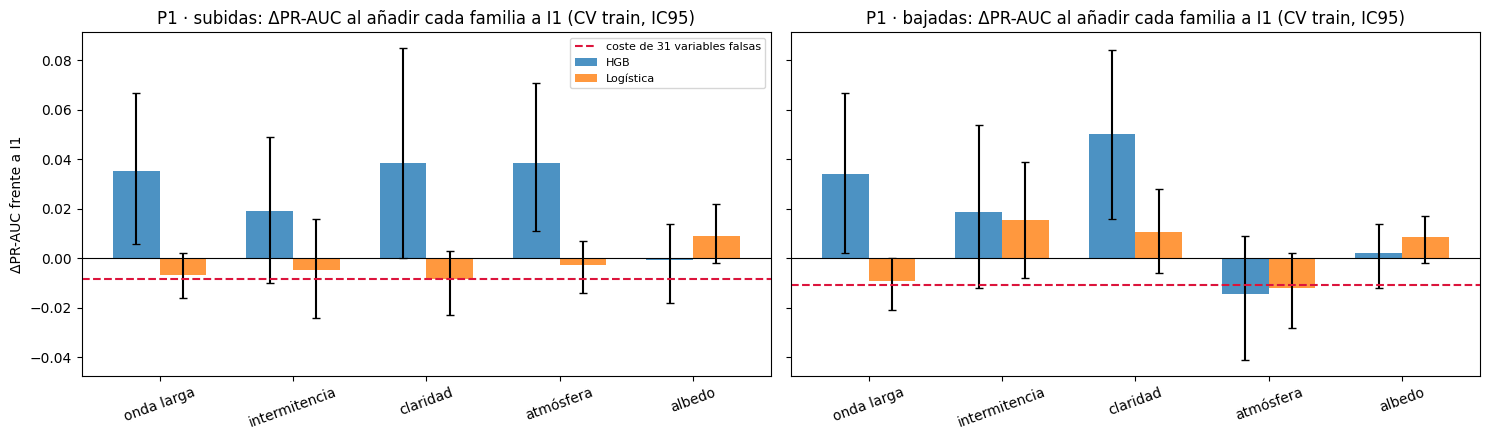


Tiempo total: 13.9 min | Resultados en: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/diagnostico/faseA_anticipabilidad/test_familias


In [ ]:
import os, time, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer

warnings.filterwarnings("ignore")
DIR_FA = os.path.join(BASE_DIR, "resultados", "diagnostico", "faseA_anticipabilidad")
DIR_FAM = os.path.join(DIR_FA, "test_familias")
os.makedirs(DIR_FAM, exist_ok=True)
F = pd.read_pickle(os.path.join(DIR_FA, "faseA_puntos1_6.pkl"))
X, y, tr, va, dias, CONJ = F["X"], F["y"], F["tr"], F["va"], F["dias"], F["CONJ"]
I1, I2 = CONJ["I1"], CONJ["I2"]
SEMILLA, N_BOOT, N_PERM_RUIDO, N_REP_IMP = 0, 1000, 5, 10
CLASES = np.array([-1, 0, 1])
DIRS = {1: "subidas", -1: "bajadas"}
t0 = time.time()

# 0) Familias (definidas ANTES de ver resultados)
FAMILIAS = {
    "F1 onda larga": [
        "CI_lw_L1",
        "CI_lw_L2",
        "CI_lw_ult15_L1",
        "CI_lw_pend60_L1",
        "CI_lw_tend3h",
        "LWD_std_L1",
        "LWD_sd1m_L1",
        "LWnet_L1",
    ],
    "F2 intermitencia": [
        "sol_frac_L1",
        "sol_frac_L2",
        "sol_frac_ult15_L1",
        "bordes_nube_L1",
        "bordes_nube_L2",
        "DIR_pend30_L1",
        "DIR_cv_L1",
        "DIR_sd1m_L1",
        "SWD_sd1m_L1",
    ],
    "F3 claridad": ["kt_L1", "kt_L2", "kt_ult15_L1", "kt_std_L1", "kd_L1", "kd_pend30_L1"],
    "F4 atmósfera": [
        "RH_L1",
        "RH_pend60_L1",
        "RH_tend3h",
        "Td_dep_L1",
        "T2_pend60_L1",
        "T2_tend3h",
        "P_tend3h",
    ],
    "F5 albedo": ["albedo_L1"],
}
NUEVAS = [c for c in I2 if c not in I1]
asignadas = sum(FAMILIAS.values(), [])
assert sorted(asignadas) == sorted(
    NUEVAS
), f"Familias ≠ variables nuevas: {set(NUEVAS) ^ set(asignadas)}"
print(
    "Inventario: I1 =",
    len(I1),
    "| nuevas =",
    len(NUEVAS),
    "| por familia:",
    {k: len(v) for k, v in FAMILIAS.items()},
)
display(
    X.loc[tr, NUEVAS]
    .isna()
    .mean()
    .groupby({c: f for f, cs in FAMILIAS.items() for c in cs})
    .mean()
    .mul(100)
    .round(1)
    .to_frame("% valores perdidos (train)")
)


# 1) Utilidades (mismos modelos y misma validación que la fase A)
def hgb():
    return HistGradientBoostingClassifier(
        max_iter=300,
        learning_rate=0.05,
        max_leaf_nodes=15,
        min_samples_leaf=40,
        l2_regularization=1.0,
        random_state=SEMILLA,
    )

def logit():
    return make_pipeline(
        SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(C=0.1, max_iter=3000)
    )

MODELOS = {"HGB": hgb, "Logística": logit}
mes = X.index.to_period("M").astype(str).to_numpy()
mes = np.where(mes == "2023-12", "2024-01", mes)
meses_tr = np.unique(mes[tr])

def proba(mdl, Xp):
    p = mdl.predict_proba(Xp)
    out = np.zeros((len(Xp), 3))
    for j, c in enumerate(mdl.classes_):
        out[:, np.where(CLASES == c)[0][0]] = p[:, j]
    return out

def evaluar(Xdf, fab, guardar_modelos=False):
    """Devuelve prob. fuera de pliegue en train (CV por meses) y prob. en validación."""
    Xtr, ytr, mtr = Xdf[tr].to_numpy(float), y[tr], mes[tr]
    p_cv, modelos = np.zeros((tr.sum(), 3)), {}
    for g in meses_tr:
        te = mtr == g
        mdl = fab().fit(Xtr[~te], ytr[~te])
        p_cv[te] = proba(mdl, Xtr[te])
        if guardar_modelos:
            modelos[g] = mdl
    mdl_fin = fab().fit(Xtr, ytr)
    return p_cv, proba(mdl_fin, Xdf[va].to_numpy(float)), modelos, mdl_fin

def ap_rapida(yb, score):
    """Average precision (misma definición que sklearn) en versión rápida para el bootstrap."""
    orden = np.argsort(-score, kind="mergesort")
    yb = yb[orden]
    s = score[orden]
    tp = np.cumsum(yb)
    n = np.arange(1, len(yb) + 1)
    ult = np.r_[np.diff(s) != 0, True]  # último elemento de cada grupo de empates
    tp, n = tp[ult], n[ult]
    if tp[-1] == 0:
        return np.nan
    prec, rec = tp / n, tp / tp[-1]
    return np.sum(np.diff(np.r_[0, rec]) * prec)

def pr(ytrue, p, c):
    return ap_rapida((ytrue == c).astype(int), p[:, np.where(CLASES == c)[0][0]])

_dias_u = {}

def grupos_dias(msk):
    k = msk.tobytes()
    if k not in _dias_u:
        u, inv = np.unique(dias[msk], return_inverse=True)
        _dias_u[k] = [np.where(inv == i)[0] for i in range(len(u))]
    return _dias_u[k]

def comparar(pa, pb, msk, c):
    """ΔPR-AUC (a − b), IC95 y p bilateral, remuestreando días completos."""
    yt = y[msk]
    g = grupos_dias(msk)
    rng = np.random.default_rng(SEMILLA)
    d0 = pr(yt, pa, c) - pr(yt, pb, c)
    difs = []
    for _ in range(N_BOOT):
        s = np.concatenate([g[i] for i in rng.integers(0, len(g), len(g))])
        if (yt[s] == c).sum() == 0:
            continue
        difs.append(pr(yt[s], pa[s], c) - pr(yt[s], pb[s], c))
    difs = np.array(difs)
    p = min(1.0, 2 * min((difs <= 0).mean(), (difs >= 0).mean()))
    return d0, np.percentile(difs, 2.5), np.percentile(difs, 97.5), p

def holm(pvals):
    p = np.asarray(pvals, float)
    orden = np.argsort(p)
    m = len(p)
    adj = np.empty(m)
    acum = 0
    for r, i in enumerate(orden):
        acum = max(acum, (m - r) * p[i])
        adj[i] = min(1.0, acum)
    return adj


# 2) Entrenar todas las configuraciones
configs = {"I1": I1, "I2": I2}
for f, cs in FAMILIAS.items():
    configs[f"I1 + {f}"] = I1 + cs  # P1
    configs[f"I2 − {f}"] = [c for c in I2 if c not in cs]  # P2
R = {}
for nombre, cols in configs.items():
    for nm, fab in MODELOS.items():
        keep = nombre == "I2"
        R[(nombre, nm)] = evaluar(X[cols], fab, guardar_modelos=keep)
    print(f"  {nombre:28s} listo ({time.time()-t0:.0f} s)")

# P3: 31 variables "falsas" = las nuevas con las filas desordenadas (dentro de train y de validación por separado)
rng = np.random.default_rng(SEMILLA)
for k in range(N_PERM_RUIDO):
    Xr = X[I1].copy()
    falsas = X[NUEVAS].copy()
    for msk in (tr, va):
        idx = np.where(msk)[0]
        falsas.iloc[idx] = falsas.iloc[
            rng.permutation(idx)
        ].to_numpy()  # misma permutación para todas → conserva correlaciones
    Xr[[f"ruido_{c}" for c in NUEVAS]] = falsas.to_numpy()
    for nm, fab in MODELOS.items():
        R[(f"I1 + ruido #{k+1}", nm)] = evaluar(Xr, fab)
    print(f"  I1 + 31 variables falsas #{k+1} listo ({time.time()-t0:.0f} s)")


# 3) Comparaciones
def tabla_contraste(pares, etiqueta):
    filas = []
    for a, b, nombre in pares:
        for c, dnom in DIRS.items():
            fila = {"prueba": etiqueta, "comparación": nombre, "dirección": dnom}
            for nm in MODELOS:
                d, lo, hi, p = comparar(R[(a, nm)][0], R[(b, nm)][0], tr, c)
                fila.update(
                    {f"Δ train {nm}": d, f"IC train {nm}": f"[{lo:+.3f}, {hi:+.3f}]", f"p {nm}": p}
                )
                dv, lov, hiv, pv = comparar(R[(a, nm)][1], R[(b, nm)][1], va, c)
                fila.update({f"Δ valid {nm}": dv, f"IC valid {nm}": f"[{lov:+.3f}, {hiv:+.3f}]"})
            filas.append(fila)
    t = pd.DataFrame(filas)
    for nm in MODELOS:
        t[f"p Holm {nm}"] = holm(t[f"p {nm}"])
    return t

def veredicto(fila, positivo="APORTA", negativo="EMPEORA"):
    for nm, otro in [("HGB", "Logística"), ("Logística", "HGB")]:
        if fila[f"p Holm {nm}"] < 0.05:
            s = np.sign(fila[f"Δ train {nm}"])
            if np.sign(fila[f"Δ train {otro}"]) == s and np.sign(fila[f"Δ valid {nm}"]) == s:
                return positivo if s > 0 else negativo
            return "señal no confirmada"
    return "sin efecto detectable"


# P1
P1 = tabla_contraste([(f"I1 + {f}", "I1", f"I1 + {f} vs I1") for f in FAMILIAS], "P1")
P1["veredicto"] = P1.apply(veredicto, axis=1)
# P2 (quitar familia: Δ = I2 − (I2 sin Fk); positivo = la familia aporta algo único)
P2 = tabla_contraste([("I2", f"I2 − {f}", f"aporte único de {f}") for f in FAMILIAS], "P2")
P2["veredicto"] = P2.apply(lambda r: veredicto(r, "APORTA ALGO ÚNICO", "METE RUIDO"), axis=1)
# Referencia: I2 frente a I1 (fase A, puntos 1–6)
REF = tabla_contraste([("I2", "I1", "I2 vs I1")], "ref")

# P3: coste de añadir 31 variables sin información
filas = []
for c, dnom in DIRS.items():
    for nm in MODELOS:
        res = [
            comparar(R[(f"I1 + ruido #{k+1}", nm)][0], R[("I1", nm)][0], tr, c)
            for k in range(N_PERM_RUIDO)
        ]
        ds = np.array([r[0] for r in res])
        sig = sum(r[2] < 0 for r in res)  # IC entero por debajo de 0
        ref = REF[(REF["dirección"] == dnom)][f"Δ train {nm}"].iloc[0]
        mejor_fam = P1[(P1["dirección"] == dnom)][f"Δ train {nm}"].max()
        filas.append(
            {
                "dirección": dnom,
                "modelo": nm,
                "coste medio de 31 variables falsas (ΔPR-AUC)": ds.mean(),
                "rango en 5 repeticiones": f"[{ds.min():+.3f}, {ds.max():+.3f}]",
                "repeticiones con empeoramiento significativo": f"{sig}/5",
                "I2 − I1 (fase A)": ref,
                "mejor familia sola (P1)": mejor_fam,
            }
        )
P3 = pd.DataFrame(filas)
P3["¿hay dilución?"] = np.where(
    (P3["coste medio de 31 variables falsas (ΔPR-AUC)"] < -0.01)
    & (P3["repeticiones con empeoramiento significativo"].str[0].astype(int) >= 3),
    "SÍ: meter variables sin información empeora",
    "no relevante",
)

# P4: importancia por familia dentro del modelo I2 (desordenar la familia entera)
filas = []
rng = np.random.default_rng(SEMILLA)
for nm in MODELOS:
    p_cv_I2, p_va_I2, mods, mdl_fin = R[("I2", nm)]
    Xtr_df, Xva_df = X.loc[tr, I2].reset_index(drop=True), X.loc[va, I2].reset_index(drop=True)
    for f, cs in FAMILIAS.items():
        caida = {(c, ev): [] for c in DIRS for ev in ("cv", "va")}
        for _ in range(N_REP_IMP):
            # CV: desordenar la familia dentro de cada mes de prueba y predecir con el modelo de ese pliegue
            p_perm = np.zeros_like(p_cv_I2)
            for g, mdl in mods.items():
                te = np.where(mes[tr] == g)[0]
                Xp = Xtr_df.iloc[te].copy()
                Xp[cs] = Xp[cs].to_numpy()[rng.permutation(len(te))]
                p_perm[te] = proba(mdl, Xp.to_numpy(float))
            Xp = Xva_df.copy()
            Xp[cs] = Xp[cs].to_numpy()[rng.permutation(len(Xp))]
            p_perm_va = proba(mdl_fin, Xp.to_numpy(float))
            for c in DIRS:
                caida[(c, "cv")].append(pr(y[tr], p_cv_I2, c) - pr(y[tr], p_perm, c))
                caida[(c, "va")].append(pr(y[va], p_va_I2, c) - pr(y[va], p_perm_va, c))
        for c, dnom in DIRS.items():
            filas.append(
                {
                    "modelo": nm,
                    "familia": f,
                    "dirección": dnom,
                    "caída PR-AUC train (media)": np.mean(caida[(c, "cv")]),
                    "± std": np.std(caida[(c, "cv")]),
                    "caída PR-AUC valid (media)": np.mean(caida[(c, "va")]),
                }
            )
P4 = pd.DataFrame(filas)
print(f"Cálculo completo ({(time.time()-t0)/60:.1f} min)")

# 4) Resultados para leer
cols_vista = [
    "comparación",
    "dirección",
    "Δ train HGB",
    "IC train HGB",
    "p Holm HGB",
    "Δ train Logística",
    "IC train Logística",
    "p Holm Logística",
    "Δ valid HGB",
    "Δ valid Logística",
    "veredicto",
]
print("\n" + "=" * 90 + "\nREFERENCIA (fase A, puntos 1–6): I2 completo frente a I1\n" + "=" * 90)
display(REF[cols_vista[:-1]].round(3))
print(
    "\n"
    + "=" * 90
    + "\nP1 · ¿Aporta cada familia POR SÍ SOLA? (I1 + familia frente a I1)\n"
    + "=" * 90
)
display(P1[cols_vista].round(3))
print(
    "\n"
    + "=" * 90
    + "\nP2 · ¿Aporta cada familia algo que NO tengan las demás? (I2 frente a I2 sin la familia)\n"
    + "=" * 90
)
display(P2[cols_vista].round(3))
print(
    "\n"
    + "=" * 90
    + "\nP3 · ¿Cuánto empeora el modelo solo por añadir 31 variables SIN información?\n"
    + "=" * 90
)
display(P3.round(3))
print(
    "\n"
    + "=" * 90
    + "\nP4 · ¿Qué familias usa el modelo completo I2? (caída de PR-AUC al desordenarlas)\n"
    + "=" * 90
)
display(
    P4.pivot_table(
        index=["familia"], columns=["modelo", "dirección"], values="caída PR-AUC train (media)"
    ).round(3)
)

# Conclusión automática según las reglas fijadas antes de ejecutar
print("\n" + "=" * 90 + "\nCONCLUSIÓN (reglas fijadas antes de ejecutar)\n" + "=" * 90)
aportan = P1[P1["veredicto"] == "APORTA"]
for _, r in P1.iterrows():
    print(
        f"  P1 · {r['comparación'].replace(' vs I1',''):26s} {r['dirección']:8s} → {r['veredicto']}"
    )
dil = (P3["¿hay dilución?"] != "no relevante").any()
print(
    f"\n  P3 · Coste de 31 variables sin información: {'relevante' if dil else 'pequeño (no explica el resultado de la fase A)'}"
)
if len(aportan):
    print(
        f"\n  ⇒ HAY familias con información propia: {sorted(set(aportan['comparación'].str.replace(' vs I1','')))}"
        f"\n    El resultado nulo de I2 se debió (al menos en parte) a meter todo junto: DILUCIÓN."
    )
elif dil:
    print(
        "\n  ⇒ Ninguna familia aporta por sí sola, aunque meter muchas variables sí cuesta rendimiento."
        "\n    No podemos descartar un aporte pequeño tapado por la dilución; no hay evidencia de aporte."
    )
else:
    print(
        "\n  ⇒ Ninguna familia aporta por sí sola y la dilución es pequeña:"
        "\n    el resultado de la fase A NO se debe a meter todo junto. Las familias nuevas no aportan información detectable."
    )

# 5) Figura y guardado
fig, axs = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
fams = list(FAMILIAS)
for ax, (c, dnom) in zip(axs, DIRS.items()):
    sub = P1[P1["dirección"] == dnom].set_index("comparación")
    for k, nm in enumerate(MODELOS):
        d = sub[f"Δ train {nm}"].to_numpy()
        lo = np.array([float(s.strip("[]").split(",")[0]) for s in sub[f"IC train {nm}"]])
        hi = np.array([float(s.strip("[]").split(",")[1]) for s in sub[f"IC train {nm}"]])
        xs = np.arange(len(fams)) + (k - 0.5) * 0.35
        ax.bar(xs, d, width=0.35, label=nm, alpha=0.8)
        ax.errorbar(xs, d, yerr=[d - lo, hi - d], fmt="none", color="k", capsize=3)
    ruido = P3[P3["dirección"] == dnom]["coste medio de 31 variables falsas (ΔPR-AUC)"].mean()
    ax.axhline(0, color="k", lw=0.8)
    ax.axhline(ruido, color="crimson", ls="--", label="coste de 31 variables falsas")
    ax.set_xticks(range(len(fams)))
    ax.set_xticklabels([f.split(" ", 1)[1] for f in fams], rotation=20)
    ax.set_title(f"P1 · {dnom}: ΔPR-AUC al añadir cada familia a I1 (CV train, IC95)")
axs[0].set_ylabel("ΔPR-AUC frente a I1")
axs[0].legend(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(DIR_FAM, "P1_familias.png"), dpi=130)
plt.show()
for nombre, t in [
    ("REF_I2_vs_I1", REF),
    ("P1_familia_sola", P1),
    ("P2_quitar_familia", P2),
    ("P3_dilucion", P3),
    ("P4_importancia_familias", P4),
]:
    t.to_csv(os.path.join(DIR_FAM, f"{nombre}.csv"), index=False)
print(f"\nTiempo total: {(time.time()-t0)/60:.1f} min | Resultados en: {DIR_FAM}")

**Resultados.** Ninguna familia aporta información de forma confirmada, y la dilución no explica el resultado de I2:

- P1: solo la familia del estado de la atmósfera mejora a I1 en subidas con el HGB tras la corrección de Holm (+0,039; p = 0,040), y en validación la diferencia es de −0,041.
- P2: ninguna familia aporta algo que no tengan las demás.
- P3: añadir 31 variables sin información apenas cambia la PR-AUC del HGB y la reduce en 0,02 en la logística.
- P4: la familia más usada por el HGB completo es la de claridad del cielo (caída de 0,06 en subidas); el albedo no se usa.

### 4.5 Comparación de E1 con el clasificador de rampas

Se comprueba si E1 ya aprovecha la información que usa el clasificador I1 (punto 7 de la fase A), convirtiendo su salida en un detector de rampas: el salto previsto, diferencia entre la DIF prevista para la hora objetivo y la observada en la hora anterior. En las horas completamente diurnas de validación se compara la PR-AUC de ese salto con la de I1, se mide qué parte del salto real prevé E1 en las rampas observadas y se comprueba, con validación cruzada por días, si añadir la probabilidad de I1 al salto de E1 mejora la detección.

Control de alineación: MAE E1 ensemble en horas de sol = 24.673 W/m²  (esperado ≈ 24,67)
Horas analizadas: 765 | subidas reales: 36 | bajadas reales: 45

NIVEL 1 · ¿Ordena E1 las horas de rampa tan bien como I1? (PR-AUC; más alto = mejor)


,rampas reales,azar (tasa base),E1 ensemble,E1 por semilla (media ± std),I1 HGB,I1 Logística,I1 media
dirección,,,,,,,
subidas,36,0.047,0.266,0.254 ± 0.034,0.297,0.272,0.301
bajadas,45,0.059,0.525,0.506 ± 0.029,0.476,0.541,0.542


,dirección,comparación,ΔPR-AUC,IC95,lectura
0,subidas,E1 − I1 HGB,-0.031,"[-0.169, +0.106]",sin diferencia detectable
1,subidas,E1 − I1 Logística,-0.006,"[-0.107, +0.083]",sin diferencia detectable
2,subidas,E1 − I1 media,-0.035,"[-0.177, +0.087]",sin diferencia detectable
3,bajadas,E1 − I1 HGB,0.049,"[-0.043, +0.141]",sin diferencia detectable
4,bajadas,E1 − I1 Logística,-0.016,"[-0.125, +0.091]",sin diferencia detectable
5,bajadas,E1 − I1 media,-0.017,"[-0.117, +0.087]",sin diferencia detectable



NIVEL 2 · En las rampas reales, ¿qué salto prevé E1?


dirección,subidas,bajadas
rampas reales,36,45
E1 acierta el sentido (salto previsto en la misma dirección),92 %,96 %
E1 prevé ≥ la mitad del umbral,53 %,69 %
E1 prevé ≥ el umbral (rampa completa),8 %,36 %
salto real medio [W/m²],137.998834,137.474269
salto previsto medio [W/m²],55.31396,86.436442
fracción del salto que prevé (mediana),0.418905,0.620491
rampas predichas por E1,5,27
"de ellas, falsas alarmas",40 %,41 %



PRUEBA COMBINADA · ¿Mejora el detector de E1 si le añadimos la probabilidad de I1?


,A: solo E1,B: E1 + I1,B − A,IC95,lectura
dirección,,,,,
subidas,0.268,0.336,0.068,"[-0.021, +0.172]",I1 no añade nada detectable
bajadas,0.514,0.540,0.027,"[-0.035, +0.091]",I1 no añade nada detectable



RESUMEN
  SUBIDAS:
    Nivel 1 (¿sabe dónde?):  E1 0.266 vs I1 0.301 (azar 0.047) → sin diferencia detectable
    Nivel 2 (¿prevé el tamaño?): acierta el sentido en 92 %, prevé la rampa completa en 8 %, prevé el 42 % del salto (mediana)
    Combinada: I1 no añade nada detectable (B − A = +0.068, IC [-0.021, +0.172])
  BAJADAS:
    Nivel 1 (¿sabe dónde?):  E1 0.525 vs I1 0.542 (azar 0.059) → sin diferencia detectable
    Nivel 2 (¿prevé el tamaño?): acierta el sentido en 96 %, prevé la rampa completa en 36 %, prevé el 62 % del salto (mediana)
    Combinada: I1 no añade nada detectable (B − A = +0.027, IC [-0.035, +0.091])


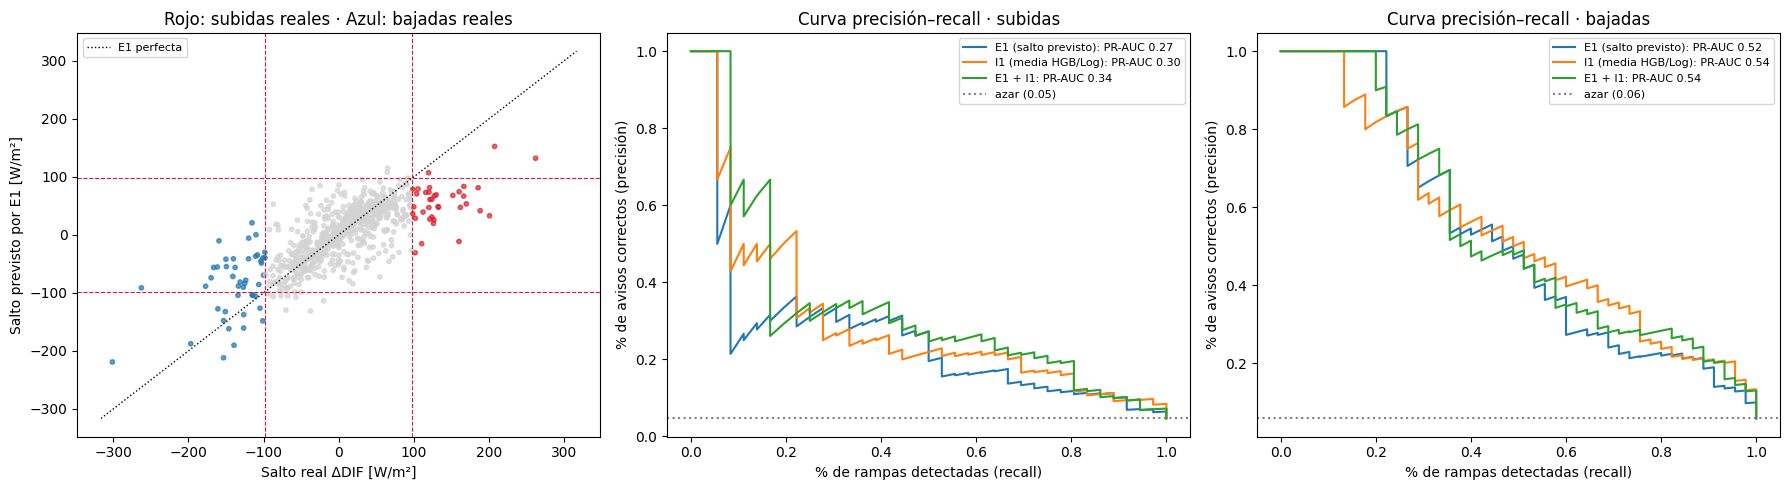

Resultados en: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/diagnostico/faseA_anticipabilidad/punto7_E1_vs_I1


In [ ]:
import os, glob
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GroupKFold
from sklearn.metrics import precision_recall_curve

DIR_R = os.path.join(BASE_DIR, "resultados", "diagnostico", "faseA_rampas")
DIR_FA = os.path.join(BASE_DIR, "resultados", "diagnostico", "faseA_anticipabilidad")
DIR_P7 = os.path.join(DIR_FA, "punto7_E1_vs_I1")
os.makedirs(DIR_P7, exist_ok=True)
SEMILLAS = [42, 123, 2024, 7, 99]
N_BOOT, SEMILLA = 1000, 0
CLASES = np.array([-1, 0, 1])
DIRS = {1: "subidas", -1: "bajadas"}

# 1) Cargar y alinear: etiquetas (R1), predicciones de E1 (Drive) y probabilidades de I1 (fase A)
et = pd.read_csv(
    os.path.join(DIR_R, "rampas_Ct_train_validation.csv"), parse_dates=["fecha"], index_col="fecha"
)
val = et[et["conjunto"] == "validation"].copy()  # 1464 horas, en el orden del .npz
UMBRAL = float(open(os.path.join(DIR_R, "umbral_rampa.txt")).read().split("=")[1].split()[0])
preds = {}
for s in SEMILLAS:
    f = glob.glob(os.path.join(BASE_DIR, "**", f"pred_validation_E1_s{s}.npy"), recursive=True)
    assert f, f"No encuentro pred_validation_E1_s{s}.npy"
    p = np.load(sorted(f)[-1]).astype(float).ravel()
    assert len(p) == len(
        val
    ), f"Semilla {s}: {len(p)} predicciones vs {len(val)} horas de validación"
    preds[f"s{s}"] = p
val = val.assign(**{f"E1_{k}": v for k, v in preds.items()})
val["E1_ens"] = val[[f"E1_s{s}" for s in SEMILLAS]].mean(axis=1)

# Control: MAE del ensemble en horas de sol debe ser el conocido (operación = 24,67 W/m²)
sol = val["regimen"] != "noche"
print(
    f"Control de alineación: MAE E1 ensemble en horas de sol = "
    f"{(val.loc[sol, 'E1_ens'] - val.loc[sol, 'DIF_T']).abs().mean():.3f} W/m²  (esperado ≈ 24,67)"
)
F = pd.read_pickle(os.path.join(DIR_FA, "faseA_puntos1_6.pkl"))
idx_va = F["X"].index[F["va"]]  # horas diurnas de validación (muestra de la fase A)
V = val.loc[idx_va].copy()
V["C"] = F["y"][F["va"]]
assert (V["C"].to_numpy() == val.loc[idx_va, "C"].to_numpy()).all(), "Etiquetas no coinciden"
for nm in ["HGB", "Logística"]:
    p = F["P_va"][(nm, "I1")]
    V[f"I1_{nm}_baja"], V[f"I1_{nm}_sube"] = p[:, 0], p[:, 2]
V["I1_media_baja"] = V[["I1_HGB_baja", "I1_Logística_baja"]].mean(axis=1)
V["I1_media_sube"] = V[["I1_HGB_sube", "I1_Logística_sube"]].mean(axis=1)
V["salto_real"] = V["dDIF"]
V["salto_E1"] = V["E1_ens"] - V["DIF_T1"]
for s in SEMILLAS:
    V[f"salto_E1_s{s}"] = V[f"E1_s{s}"] - V["DIF_T1"]
V["dia"] = V.index.normalize()
print(
    f"Horas analizadas: {len(V)} | subidas reales: {(V['C']==1).sum()} | bajadas reales: {(V['C']==-1).sum()}"
)


# Utilidades
def ap(yb, score):
    orden = np.argsort(-score, kind="mergesort")
    yb = yb[orden]
    s = score[orden]
    tp = np.cumsum(yb)
    n = np.arange(1, len(yb) + 1)
    ult = np.r_[np.diff(s) != 0, True]
    tp, n = tp[ult], n[ult]
    if tp[-1] == 0:
        return np.nan
    return np.sum(np.diff(np.r_[0, tp / tp[-1]]) * (tp / n))

u_dias, inv = np.unique(V["dia"].to_numpy(), return_inverse=True)
grupos = [np.where(inv == i)[0] for i in range(len(u_dias))]

def boot(yb, sa, sb):
    rng = np.random.default_rng(SEMILLA)
    d0 = ap(yb, sa) - ap(yb, sb)
    difs = []
    for _ in range(N_BOOT):
        s = np.concatenate([grupos[i] for i in rng.integers(0, len(grupos), len(grupos))])
        if yb[s].sum() == 0:
            continue
        difs.append(ap(yb[s], sa[s]) - ap(yb[s], sb[s]))
    difs = np.array(difs)
    return d0, np.percentile(difs, 2.5), np.percentile(difs, 97.5)

def lectura(lo, hi, positivo, negativo, neutro):
    return positivo if lo > 0 else (negativo if hi < 0 else neutro)


# 2) NIVEL 1 — ¿E1 "sabe" dónde hay rampa? (orden de las horas, PR-AUC)
filas, contrastes = [], []
for c, nom in DIRS.items():
    yb = (V["C"] == c).astype(int).to_numpy()
    signo = 1 if c == 1 else -1
    sE1 = signo * V["salto_E1"].to_numpy()
    sem = [ap(yb, signo * V[f"salto_E1_s{s}"].to_numpy()) for s in SEMILLAS]
    sfx = "sube" if c == 1 else "baja"
    fila = {
        "dirección": nom,
        "rampas reales": int(yb.sum()),
        "azar (tasa base)": yb.mean(),
        "E1 ensemble": ap(yb, sE1),
        "E1 por semilla (media ± std)": f"{np.mean(sem):.3f} ± {np.std(sem):.3f}",
        "I1 HGB": ap(yb, V[f"I1_HGB_{sfx}"].to_numpy()),
        "I1 Logística": ap(yb, V[f"I1_Logística_{sfx}"].to_numpy()),
        "I1 media": ap(yb, V[f"I1_media_{sfx}"].to_numpy()),
    }
    filas.append(fila)
    for ref in ["I1 HGB", "I1 Logística", "I1 media"]:
        sref = V[f"I1_{ref.split()[1]}_{sfx}"].to_numpy()
        d, lo, hi = boot(yb, sE1, sref)
        contrastes.append(
            {
                "dirección": nom,
                "comparación": f"E1 − {ref}",
                "ΔPR-AUC": d,
                "IC95": f"[{lo:+.3f}, {hi:+.3f}]",
                "lectura": lectura(
                    lo, hi, "E1 detecta MEJOR", "E1 detecta PEOR", "sin diferencia detectable"
                ),
            }
        )
N1 = pd.DataFrame(filas).set_index("dirección")
N1c = pd.DataFrame(contrastes)
print(
    "\n"
    + "=" * 90
    + "\nNIVEL 1 · ¿Ordena E1 las horas de rampa tan bien como I1? (PR-AUC; más alto = mejor)\n"
    + "=" * 90
)
display(N1.round(3))
display(N1c.round(3))

# 3) NIVEL 2 — ¿E1 predice el TAMAÑO? (umbral real sobre el salto previsto)
filas = []
for c, nom in DIRS.items():
    real = (V["C"] == c).to_numpy()
    signo = 1 if c == 1 else -1
    sp, sr = signo * V["salto_E1"].to_numpy(), signo * V["salto_real"].to_numpy()
    pred_rampa = sp >= UMBRAL
    aciertos = (pred_rampa & real).sum()
    filas.append(
        {
            "dirección": nom,
            "rampas reales": int(real.sum()),
            "E1 acierta el sentido (salto previsto en la misma dirección)": f"{100*np.mean(sp[real] > 0):.0f} %",
            "E1 prevé ≥ la mitad del umbral": f"{100*np.mean(sp[real] >= UMBRAL/2):.0f} %",
            "E1 prevé ≥ el umbral (rampa completa)": f"{100*np.mean(sp[real] >= UMBRAL):.0f} %",
            "salto real medio [W/m²]": sr[real].mean(),
            "salto previsto medio [W/m²]": sp[real].mean(),
            "fracción del salto que prevé (mediana)": np.median(sp[real] / sr[real]),
            "rampas predichas por E1": int(pred_rampa.sum()),
            "de ellas, falsas alarmas": f"{100*(1 - aciertos/max(pred_rampa.sum(),1)):.0f} %",
        }
    )
N2 = pd.DataFrame(filas).set_index("dirección")
print("\n" + "=" * 90 + "\nNIVEL 2 · En las rampas reales, ¿qué salto prevé E1?\n" + "=" * 90)
display(N2.T)

# 4) PRUEBA COMBINADA — ¿I1 añade información a E1?
#    A: detector con solo el salto de E1   |   B: salto de E1 + probabilidad de I1 (media HGB/Log)
#    Regresión logística con validación cruzada por días (5 pliegues) dentro de validación.
gkf = GroupKFold(n_splits=5)
filas = []
oof = {}
for c, nom in DIRS.items():
    yb = (V["C"] == c).astype(int).to_numpy()
    sfx = "sube" if c == 1 else "baja"
    pI1 = np.clip(V[f"I1_media_{sfx}"].to_numpy(), 1e-4, 1 - 1e-4)
    XA = V[["salto_E1"]].to_numpy()
    XB = np.column_stack([V["salto_E1"].to_numpy(), np.log(pI1 / (1 - pI1))])
    pA, pB = np.zeros(len(yb)), np.zeros(len(yb))
    for trn, tst in gkf.split(XA, yb, groups=V["dia"].to_numpy()):
        mA = make_pipeline(StandardScaler(), LogisticRegression()).fit(XA[trn], yb[trn])
        mB = make_pipeline(StandardScaler(), LogisticRegression()).fit(XB[trn], yb[trn])
        pA[tst], pB[tst] = mA.predict_proba(XA[tst])[:, 1], mB.predict_proba(XB[tst])[:, 1]
    oof[nom] = (pA, pB)
    d, lo, hi = boot(yb, pB, pA)
    filas.append(
        {
            "dirección": nom,
            "A: solo E1": ap(yb, pA),
            "B: E1 + I1": ap(yb, pB),
            "B − A": d,
            "IC95": f"[{lo:+.3f}, {hi:+.3f}]",
            "lectura": lectura(
                lo,
                hi,
                "I1 AÑADE información que E1 no usa",
                "añadir I1 empeora",
                "I1 no añade nada detectable",
            ),
        }
    )
CB = pd.DataFrame(filas).set_index("dirección")
print(
    "\n"
    + "=" * 90
    + "\nPRUEBA COMBINADA · ¿Mejora el detector de E1 si le añadimos la probabilidad de I1?\n"
    + "=" * 90
)
display(CB.round(3))

# 5) Resumen en texto
print("\n" + "=" * 90 + "\nRESUMEN\n" + "=" * 90)
for c, nom in DIRS.items():
    l1 = N1c[(N1c["dirección"] == nom) & (N1c["comparación"] == "E1 − I1 media")]["lectura"].iloc[0]
    print(f"  {nom.upper()}:")
    print(
        f"    Nivel 1 (¿sabe dónde?):  E1 {N1.loc[nom,'E1 ensemble']:.3f} vs I1 {N1.loc[nom,'I1 media']:.3f} "
        f"(azar {N1.loc[nom,'azar (tasa base)']:.3f}) → {l1}"
    )
    print(
        f"    Nivel 2 (¿prevé el tamaño?): acierta el sentido en {N2.loc[nom].iloc[1]}, "
        f"prevé la rampa completa en {N2.loc[nom].iloc[3]}, "
        f"prevé el {100*N2.loc[nom,'fracción del salto que prevé (mediana)']:.0f} % del salto (mediana)"
    )
    print(
        f"    Combinada: {CB.loc[nom,'lectura']} (B − A = {CB.loc[nom,'B − A']:+.3f}, IC {CB.loc[nom,'IC95']})"
    )

# 6) Figuras
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
col = V["C"].map({-1: "tab:blue", 0: "lightgray", 1: "tab:red"})
ax[0].scatter(V["salto_real"], V["salto_E1"], c=col, s=10, alpha=0.7)
lim = np.nanmax(np.abs(V[["salto_real", "salto_E1"]].to_numpy())) * 1.05
ax[0].plot([-lim, lim], [-lim, lim], "k:", lw=1, label="E1 perfecta")
for u in (-UMBRAL, UMBRAL):
    ax[0].axhline(u, color="crimson", ls="--", lw=0.8)
    ax[0].axvline(u, color="crimson", ls="--", lw=0.8)
ax[0].set_xlabel("Salto real ΔDIF [W/m²]")
ax[0].set_ylabel("Salto previsto por E1 [W/m²]")
ax[0].set_title("Rojo: subidas reales · Azul: bajadas reales")
ax[0].legend(fontsize=8)
for k, (c, nom) in enumerate(DIRS.items()):
    yb = (V["C"] == c).astype(int).to_numpy()
    sfx = "sube" if c == 1 else "baja"
    signo = 1 if c == 1 else -1
    for etiqueta, sc in [
        ("E1 (salto previsto)", signo * V["salto_E1"].to_numpy()),
        ("I1 (media HGB/Log)", V[f"I1_media_{sfx}"].to_numpy()),
        ("E1 + I1", oof[nom][1]),
    ]:
        pr_, rc_, _ = precision_recall_curve(yb, sc)
        ax[k + 1].plot(rc_, pr_, label=f"{etiqueta}: PR-AUC {ap(yb, sc):.2f}")
    ax[k + 1].axhline(yb.mean(), color="gray", ls=":", label=f"azar ({yb.mean():.2f})")
    ax[k + 1].set_xlabel("% de rampas detectadas (recall)")
    ax[k + 1].set_ylabel("% de avisos correctos (precisión)")
    ax[k + 1].set_title(f"Curva precisión–recall · {nom}")
    ax[k + 1].legend(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(DIR_P7, "punto7_E1_vs_I1.png"), dpi=130)
plt.show()
N1.to_csv(os.path.join(DIR_P7, "nivel1_prauc.csv"))
N1c.to_csv(os.path.join(DIR_P7, "nivel1_contrastes.csv"), index=False)
N2.to_csv(os.path.join(DIR_P7, "nivel2_tamano.csv"))
CB.to_csv(os.path.join(DIR_P7, "prueba_combinada.csv"))
print("Resultados en:", DIR_P7)

**Resultados.** El control de alineación reproduce el MAE conocido de E1 en las horas con sol (24,67 W/m²).

- Detección: la PR-AUC del salto de E1 es de 0,27 en subidas y de 0,53 en bajadas, frente a 0,30 y 0,54 de I1 (tasas base de 0,05 y 0,06); ninguna de las seis comparaciones muestra diferencias significativas.
- Tamaño: E1 acierta el sentido en el 92 % de las subidas y el 96 % de las bajadas, pero solo prevé la rampa completa en el 8 % y el 36 %; en mediana prevé el 42 % y el 62 % del salto real.
- Combinación: añadir la probabilidad de I1 no mejora la detección (+0,07 en subidas y +0,03 en bajadas, con intervalos que incluyen el cero).

## 5. Radiografía de E1 y control del sobreajuste

> *Se utiliza en la memoria: apartado 5.3.3 (control con la persistencia y predicciones fuera de muestra) y fase 6 de la Tabla A1.*

### 5.1 Radiografía del error de E1

Se analiza, sin reentrenar, el error del ensemble de cinco semillas de E1 en las horas con sol de validación: su reparto por tipo de cielo, banda de elevación, rampas, hora y mes (presupuesto de error, B1), el perfil de los errores grandes (B2) y la comparación entre los meses ya vistos de entrenamiento y la validación (B4). El tipo de cielo es el de la hora objetivo, que no se conoce al predecir, por lo que estos desgloses solo describen dónde se concentra el error.

✅ Todos los ficheros necesarios están en Drive
Entradas E1: train (5149, 24, 9) (huecos 24) | validación (1464, 24, 9) (huecos 0)   ← esperado (5149, 24, 9) con 24 huecos y (1464, 24, 9) con 0
✅ Modelos cargados: las predicciones recalculadas coinciden con las guardadas en Drive

Horas con sol: validación 884 | train 3027
MAE de E1 (ensemble) en validación, horas con sol: 24.67 W/m²  ← esperado ≈ 24,67
Tipos de cielo (hora objetivo): despejado = mucha luz y estable · velado = luz intermedia y estable ·
  nubes rotas = la luz sube y baja dentro de la hora · cubierto = poca luz y estable · amanecer/atardecer = sol parcial

B1 · PRESUPUESTO DE ERROR DE E1 (validación, horas con sol)
Cómo leerlo: si un grupo tiene más '% del error' que '% de las horas', se lleva más error del que le toca.
El sesgo dice si E1 se queda corto (negativo) o se pasa (positivo) de forma sistemática en ese grupo.

--- Tipo de cielo ---


,horas,% de las horas,% del error total,MAE [W/m²],sesgo [W/m²],parte del error que es sesgo,aviso
cielo,,,,,,,
despejado,185,20.9,12.3,14.5,8.1,56 %,
velado,89,10.1,9.0,22.2,1.0,5 %,
nubes rotas,438,49.5,68.1,33.9,-11.8,35 %,
cubierto,53,6.0,9.2,38.0,31.8,84 %,
amanecer/atardecer,119,13.5,1.3,2.3,0.3,12 %,



--- Banda de elevación ---


,horas,% de las horas,% del error total,MAE [W/m²],sesgo [W/m²],parte del error que es sesgo,aviso
banda,,,,,,,
hombros ≤20°,339,38.3,15.4,9.9,-0.4,4 %,
intermedia 20–40°,340,38.5,47.2,30.3,-2.6,9 %,
central >40°,205,23.2,37.4,39.8,-4.0,10 %,



--- Rampas ---


,horas,% de las horas,% del error total,MAE [W/m²],sesgo [W/m²],parte del error que es sesgo,aviso
rampa,,,,,,,
sin rampa,803,90.8,73.6,20.0,-1.5,7 %,
subida fuerte,36,4.1,13.6,82.7,-82.7,100 %,
bajada fuerte,45,5.1,12.7,61.7,51.0,83 %,



--- Hora UTC ---


,horas,% de las horas,% del error total,MAE [W/m²],sesgo [W/m²],parte del error que es sesgo,aviso
hora UTC,,,,,,,
4,34,3.8,0.3,2.2,-0.0,1 %,
5,61,6.9,2.0,7.1,-0.3,4 %,
6,61,6.9,4.2,14.9,2.1,14 %,
7,61,6.9,7.0,25.1,-12.2,48 %,
8,61,6.9,9.0,32.1,-10.3,32 %,
9,61,6.9,10.0,35.9,-3.4,9 %,
10,61,6.9,10.0,35.9,-1.1,3 %,
11,61,6.9,11.1,39.8,-6.3,16 %,
12,61,6.9,11.0,39.4,1.9,5 %,



--- Mes ---


,horas,% de las horas,% del error total,MAE [W/m²],sesgo [W/m²],parte del error que es sesgo,aviso
mes,,,,,,,
2024-08,480,54.3,58.5,26.6,-3.6,14 %,
2024-09,404,45.7,41.5,22.4,-0.3,1 %,


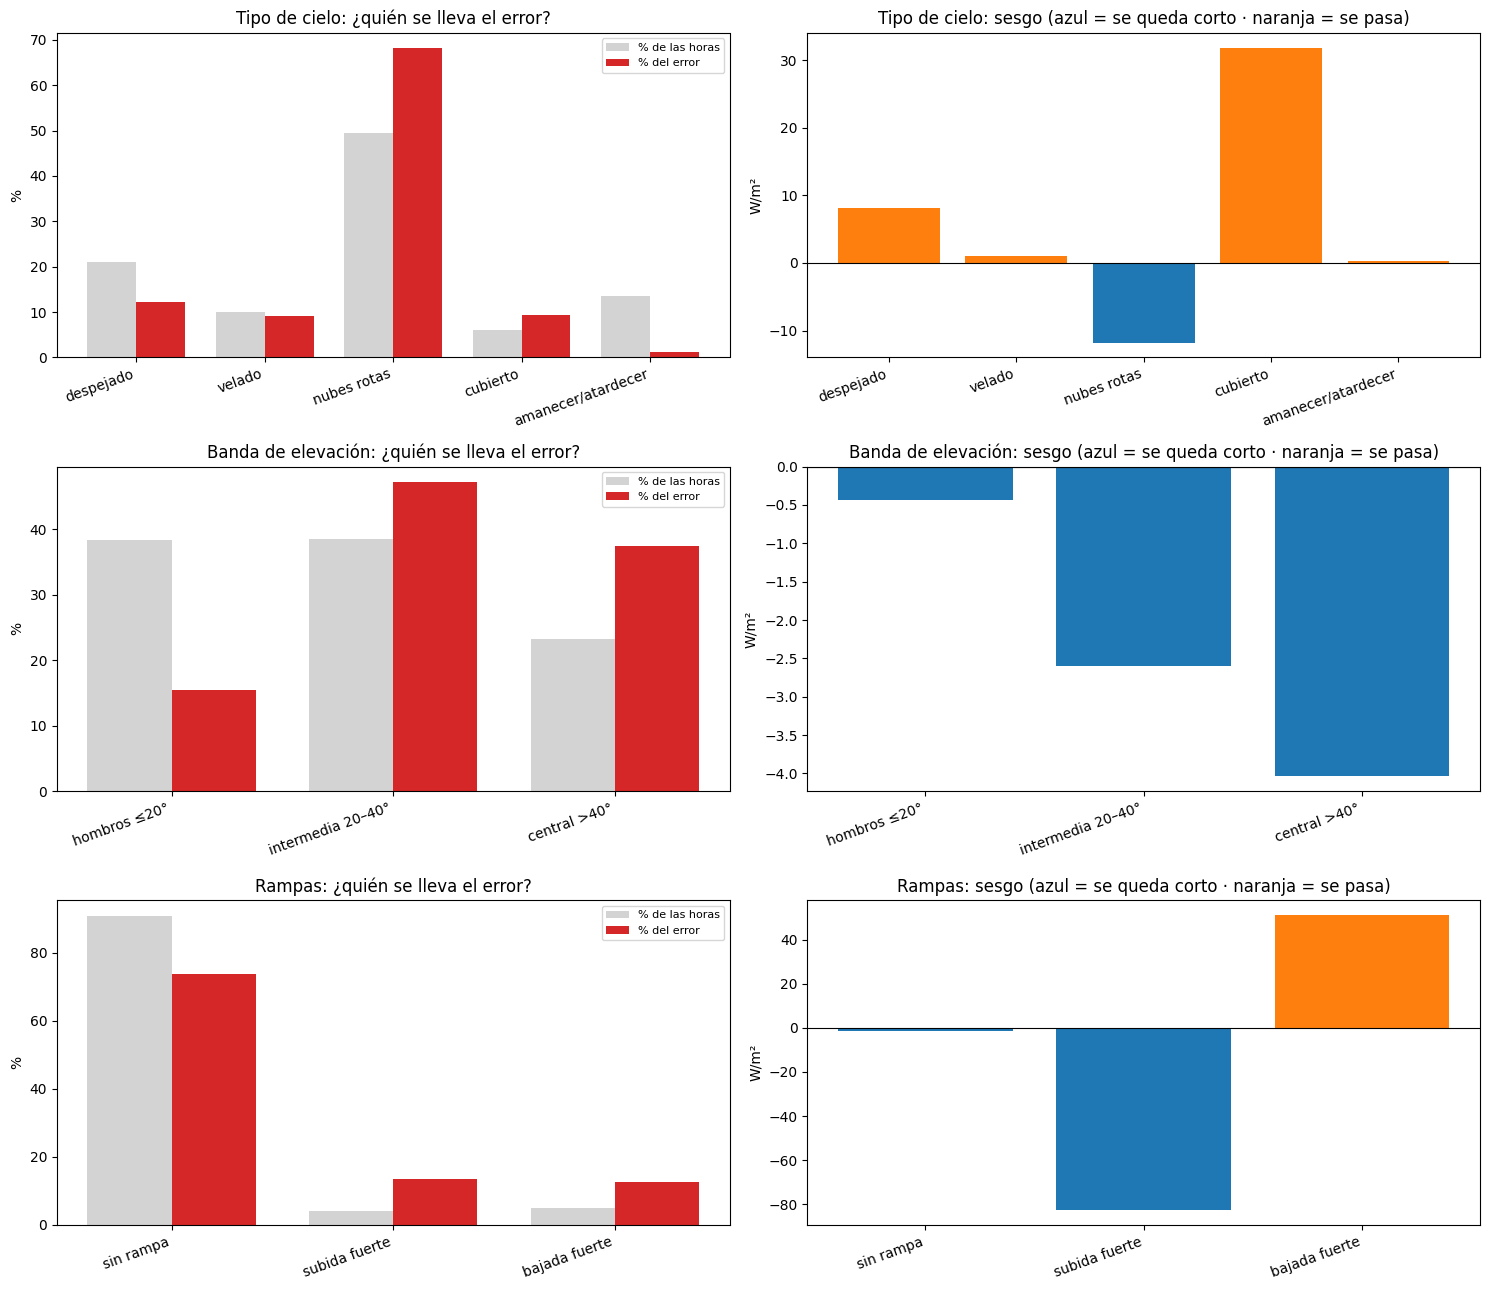

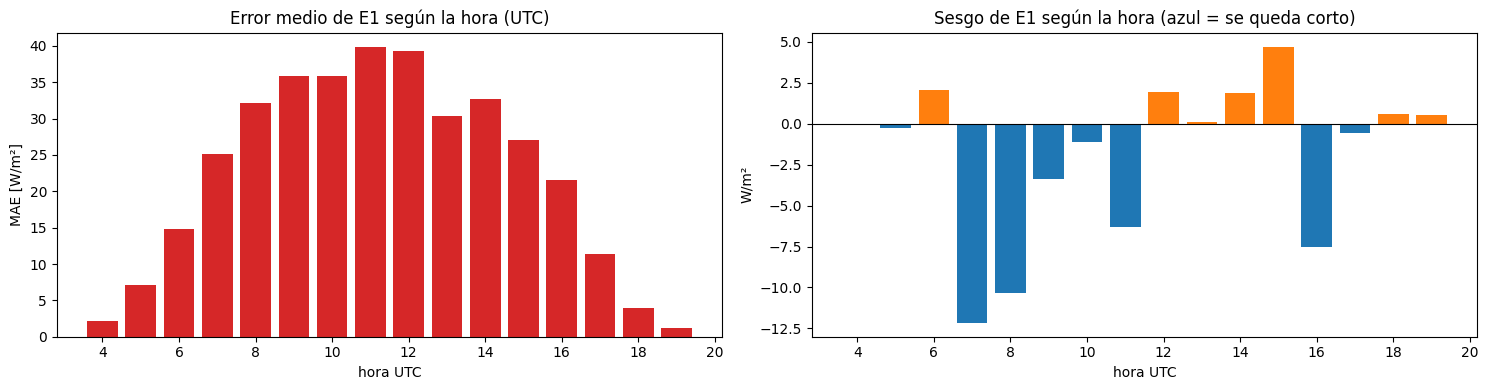


Si se corrigiera el sesgo medio de cada combinación cielo × banda, el MAE pasaría de 24.67 a 23.40 W/m² (5.2 % menos).
   (Es un TECHO optimista: el sesgo se mide y se corrige sobre los mismos datos. Si es pequeño, corregir sesgos no merece la pena.)

B2 · ¿CÓMO SON LOS ERRORES GRANDES? (validación, horas con sol)
Error grande = |error| ≥ 65 W/m² (el 10 % de horas peores: 89 horas).
Ese 10 % de horas concentra el 39 % de todo el error de E1.

--- Tipo de cielo ---


,en los errores grandes (%),en el resto (%)
cielo,,
despejado,6.7,22.5
velado,7.9,10.3
nubes rotas,74.2,46.8
cubierto,11.2,5.4
amanecer/atardecer,0.0,15.0



--- Rampas ---


,en los errores grandes (%),en el resto (%)
rampa,,
sin rampa,53.9,95.0
subida fuerte,24.7,1.8
bajada fuerte,21.3,3.3



--- Banda de elevación ---


,en los errores grandes (%),en el resto (%)
banda,,
hombros ≤20°,2.2,42.4
intermedia 20–40°,46.1,37.6
central >40°,51.7,20.0



--- Signo del error ---


,en los errores grandes (%),en el resto (%)
signo del error,,
se queda corto,56.2,48.2
se pasa,43.8,51.8


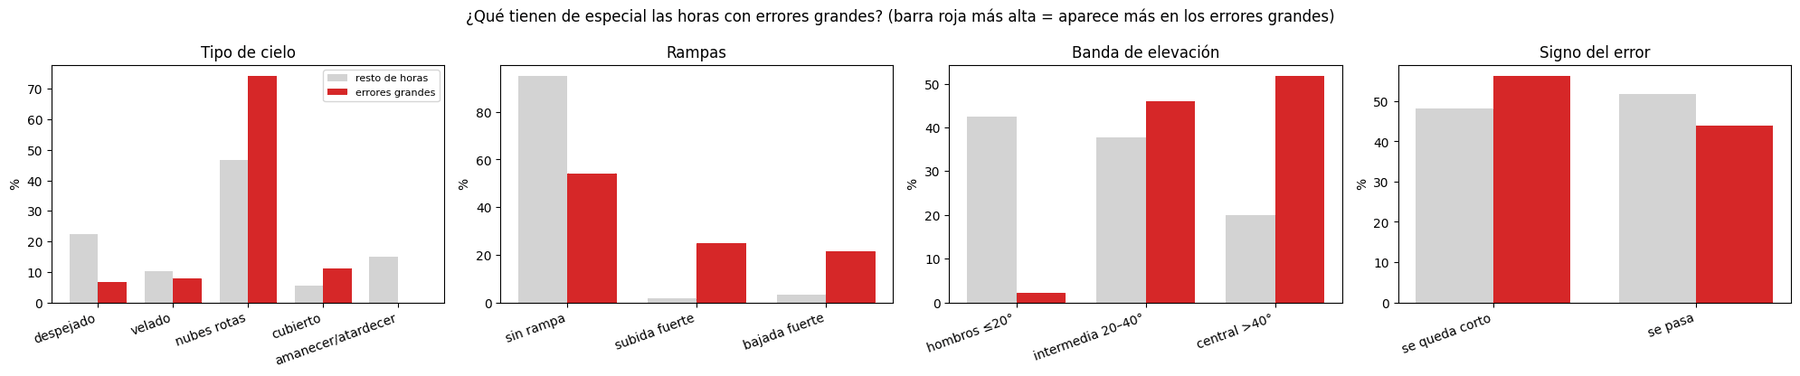

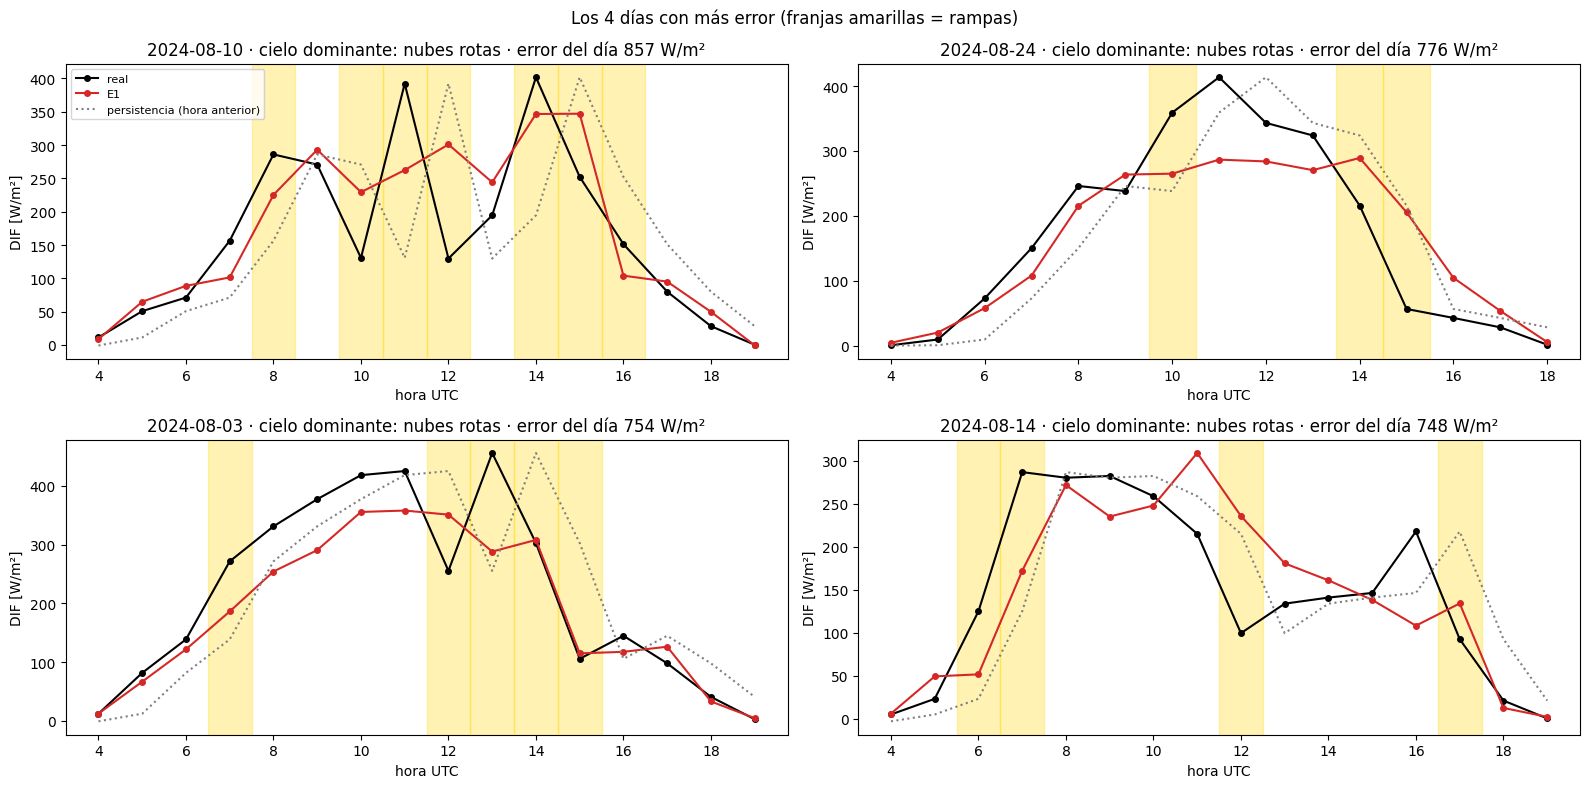


B4 · ¿E1 SOBREAJUSTA? (error en datos que ya vio frente a datos nuevos)
Para que la comparación sea justa se usan meses parecidos: train abr–jul (ya vistos) frente a validación ago–sep (nuevos).
Se mira el MAE y el MAE relativo (MAE / DIF medio), porque en verano hay más difusa y el error crece con ella.


,horas,MAE [W/m²],DIF medio [W/m²],MAE relativo,MAE por semilla (media)
datos,,,,,
train completo (ya visto),3027,17.001,137.175,0.124,18.009
train abr–jul (ya visto),2015,18.699,163.026,0.115,19.950
validación ago–sep (nuevo),884,24.673,141.798,0.174,25.771


,train abr–jul (ya visto),validación (nuevo)
banda,,
hombros ≤20°,6.62,9.92
intermedia 20–40°,21.67,30.27
central >40°,27.75,39.80


,train abr–jul (ya visto),validación (nuevo)
cielo,,
despejado,10.920000,14.50
velado,13.030000,22.17
nubes rotas,24.590000,33.93
cubierto,22.200001,38.01
amanecer/atardecer,1.820000,2.34


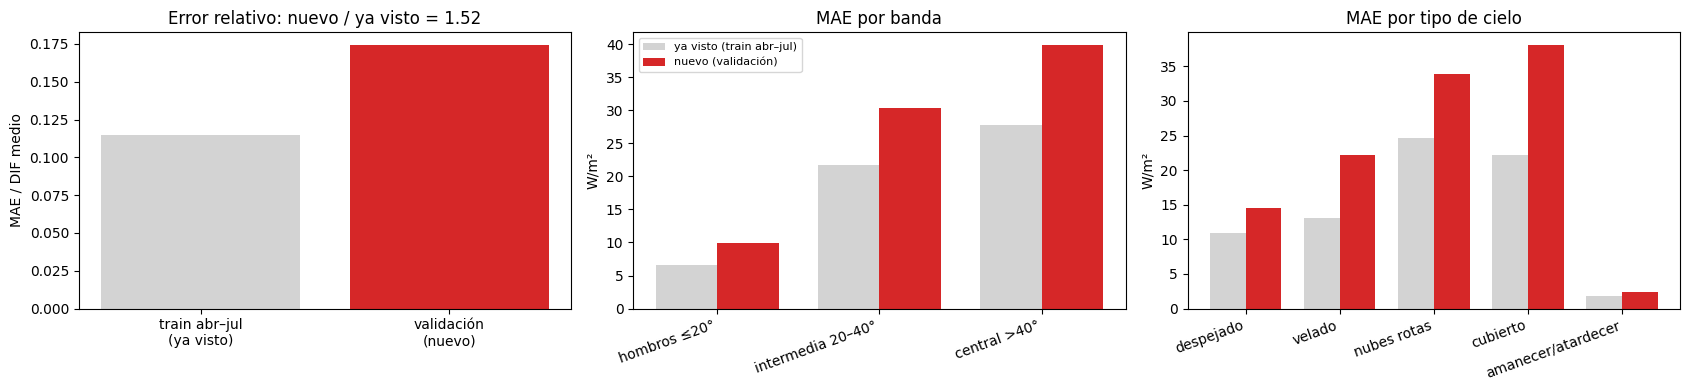


➜ El error en datos nuevos es 1.52 veces el de datos ya vistos: E1 SOBREAJUSTA (memoriza train). Merece la pena regularizar (dropout, menos unidades, parada temprana).
   (Comparación preliminar: abr–jul y ago–sep no son idénticos. B5 dará la comparación limpia, fuera de muestra en train.)

RESUMEN DE LA RADIOGRAFÍA
1. Tipo de cielo: 'nubes rotas' es el 50 % de las horas pero se lleva el 68 % del error.
     · despejado            MAE   14.5 W/m² | sesgo   +8.1 W/m²
     · velado               MAE   22.2 W/m² | sesgo   +1.0 W/m²
     · nubes rotas          MAE   33.9 W/m² | sesgo  -11.8 W/m²
     · cubierto             MAE   38.0 W/m² | sesgo  +31.8 W/m²
     · amanecer/atardecer   MAE    2.3 W/m² | sesgo   +0.3 W/m²
2. Rampas: son el 9 % de las horas y se llevan el 26 % del error.
3. Errores grandes: el 10 % de horas peores concentra el 39 % del error.
4. Corregir sesgos por cielo × banda bajaría el MAE como mucho un 5.2 %.
5. El error en datos nuevos es 1.52 veces el de datos ya vis

In [ ]:
import os, random, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

# 0) Drive y rutas
try:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
except ImportError:
    pass

BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
RUTA_NPZ = (
    BASE_DIR
    / "resultados"
    / "ejecuciones"
    / "preparacion_bloque_difstats_20261006_180841"
    / "matrices_dif_elev_difstats.npz"
)
DIR_F1 = (
    BASE_DIR / "resultados" / "diagnostico" / "fase1_intrahoraria"
)  # modelos E1 y variables intrahorarias
DIR_R = BASE_DIR / "resultados" / "diagnostico" / "faseA_rampas"  # régimen, banda y rampas por hora
PARQUET = BASE_DIR / "radiation_data_completo.parquet"
DIR_B = BASE_DIR / "resultados" / "diagnostico" / "faseB_radiografia_E1"
DIR_B.mkdir(parents=True, exist_ok=True)
SEMILLAS = [42, 123, 2024, 7, 99]
LATITUD, LONGITUD = 51.971, 4.927
for r in [
    RUTA_NPZ,
    DIR_F1 / "variables_intrahorarias_horarias.csv",
    DIR_R / "rampas_Ct_train_validation.csv",
    PARQUET,
] + [DIR_F1 / f"modelo_E1_s{s}.pt" for s in SEMILLAS]:
    assert Path(r).exists(), f"No encuentro: {r}"
print("✅ Todos los ficheros necesarios están en Drive")

# 1) Reconstruir las entradas de E1 (mismo código que la celda de la fase 1)
mat = np.load(RUTA_NPZ)
X_tr = mat["X_train_DIF_elev_DIFstats_raw"].astype(np.float32)
y_tr = mat["y_train_difstats"].astype(np.float32).reshape(-1)
X_va = mat["X_validation_DIF_elev_DIFstats_raw"].astype(np.float32)
y_va = mat["y_validation_difstats"].astype(np.float64).reshape(-1)
fechas_tr = pd.DatetimeIndex(mat["fechas_train"])
fechas_va = pd.DatetimeIndex(mat["fechas_validation"])
intrahora = pd.read_csv(
    DIR_F1 / "variables_intrahorarias_horarias.csv", index_col=0, parse_dates=True
).asfreq("h")

def a_ventanas(tabla, fechas_obj, columnas, lookback=24):
    f = pd.DatetimeIndex(fechas_obj).to_numpy(dtype="datetime64[ns]")
    idx = f[:, None] - np.arange(lookback, 0, -1).astype("timedelta64[h]")[None, :]  # T-24 … T-1
    vals = tabla.reindex(pd.DatetimeIndex(idx.reshape(-1)))[columnas].to_numpy(dtype=np.float32)
    return vals.reshape(len(f), lookback, len(columnas))

CANALES_E1 = ["DIF_ult15", "DIF_pend30", "DIF_acel60", "DIF_saltos", "SWD_cv"]

def construir(fechas_obj, X_base, canales):
    Xn = a_ventanas(intrahora, fechas_obj, canales)
    n_nan = int(np.isnan(Xn).sum())
    for j, c in enumerate(canales):
        hueco = np.isnan(Xn[:, :, j])
        Xn[:, :, j][hueco] = X_base[:, :, 0][hueco] if c == "DIF_ult15" else 0.0
    return np.concatenate([X_base, Xn], axis=2).astype(np.float32), n_nan

Xtr_E1, nan_tr = construir(fechas_tr, X_tr, CANALES_E1)
Xva_E1, nan_va = construir(fechas_va, X_va, CANALES_E1)
print(
    f"Entradas E1: train {Xtr_E1.shape} (huecos {nan_tr}) | validación {Xva_E1.shape} (huecos {nan_va})"
    f"   ← esperado (5149, 24, 9) con 24 huecos y (1464, 24, 9) con 0"
)

# 2) Cargar los 5 modelos E1 y predecir en train y en validación
import torch, torch.nn as nn
from sklearn.preprocessing import StandardScaler

class LSTMDIFStats(nn.Module):
    def __init__(self, n_features=4, hidden_size=64):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=n_features, hidden_size=hidden_size, num_layers=1, batch_first=True
        )
        self.head = nn.Sequential(nn.Linear(hidden_size, 32), nn.ReLU(), nn.Linear(32, 1))

    def forward(self, x):
        salida, _ = self.lstm(x)
        return self.head(salida[:, -1, :]).squeeze(-1)

sx = StandardScaler().fit(
    Xtr_E1.reshape(-1, Xtr_E1.shape[2])
)  # mismos escaladores que en el entrenamiento
sy = StandardScaler().fit(y_tr.reshape(-1, 1))
esc = lambda X: torch.from_numpy(
    sx.transform(X.reshape(-1, X.shape[2])).reshape(X.shape).astype(np.float32)
)

def predecir_E1(semilla):
    ck = torch.load(DIR_F1 / f"modelo_E1_s{semilla}.pt", map_location="cpu", weights_only=False)
    estado = ck["model_state_dict"] if isinstance(ck, dict) and "model_state_dict" in ck else ck
    m = LSTMDIFStats(n_features=Xtr_E1.shape[2])
    m.load_state_dict(estado)
    m.eval()
    with torch.no_grad():
        p_tr = sy.inverse_transform(m(esc(Xtr_E1)).numpy().reshape(-1, 1)).ravel()
        p_va = sy.inverse_transform(m(esc(Xva_E1)).numpy().reshape(-1, 1)).ravel()
    return p_tr, p_va

P_tr, P_va = {}, {}
for s in SEMILLAS:
    P_tr[s], P_va[s] = predecir_E1(s)
    guardada = np.load(DIR_F1 / f"pred_validation_E1_s{s}.npy")
    dif = np.max(np.abs(P_va[s] - guardada))
    assert (
        dif < 0.05
    ), f"Semilla {s}: la predicción recalculada difiere {dif:.3f} W/m² de la guardada"
print("✅ Modelos cargados: las predicciones recalculadas coinciden con las guardadas en Drive")

# 3) Tabla horaria con todo lo necesario
et = pd.read_csv(DIR_R / "rampas_Ct_train_validation.csv", parse_dates=["fecha"], index_col="fecha")

def tabla(conjunto, fechas, y, P):
    t = et[et["conjunto"] == conjunto].copy()
    assert (
        len(t) == len(fechas) and (t.index == fechas).all()
    ), f"Orden de horas distinto en {conjunto}"
    assert np.max(np.abs(t["DIF_T"].to_numpy() - y)) < 0.01, f"DIF no coincide en {conjunto}"
    t["real"] = y
    t["E1"] = np.mean([P[s] for s in SEMILLAS], axis=0)
    for s in SEMILLAS:
        t[f"E1_s{s}"] = P[s]
    t["error"] = t["E1"] - t["real"]  # + = E1 se pasa · − = E1 se queda corto
    t["persistencia"] = t["DIF_T1"]
    return t

TR, VA = tabla("train", fechas_tr, y_tr, P_tr), tabla("validation", fechas_va, y_va, P_va)

# Tipo de cielo en la hora T (índice de claridad kt = global medida / global de cielo despejado)
import pvlib
sw = pd.read_parquet(PARQUET, columns=["Date/Time", "SWD [W/m**2]"])
sw["Date/Time"] = pd.to_datetime(sw["Date/Time"], utc=True)
sw = sw.set_index("Date/Time").sort_index()
sw = sw[~sw.index.duplicated()]
sw = sw[
    (sw.index >= (fechas_tr.min() - pd.Timedelta("1h")).tz_localize("UTC"))
    & (sw.index < (fechas_va.max() + pd.Timedelta("1h")).tz_localize("UTC"))
]
ghi_cs = pvlib.location.Location(LATITUD, LONGITUD, tz="UTC").get_clearsky(
    sw.index, model="ineichen"
)["ghi"]
sw.index = sw.index.tz_localize(None)
hora = sw.index.floor("h")
swd = pd.to_numeric(sw["SWD [W/m**2]"], errors="coerce")
cs = pd.Series(ghi_cs.to_numpy(), index=sw.index)
kt_min = (swd / cs).where(cs > 50).clip(0, 1.5)  # claridad minuto a minuto
kt_h = (
    (swd.groupby(hora).mean() / cs.groupby(hora).mean())
    .where(cs.groupby(hora).mean() > 50)
    .clip(0, 1.5)
)
ktsd_h = kt_min.groupby(hora).std()  # cuánto sube y baja la claridad dentro de la hora

def tipo_cielo(t):
    kt, sd = kt_h.reindex(t.index), ktsd_h.reindex(t.index)
    # estable = la claridad apenas cambia dentro de la hora (desviación < 0,10)
    tipo = np.select(
        [t["regimen"] == "noche", t["regimen"] == "transicion", sd >= 0.10, kt >= 0.65, kt < 0.35],
        ["noche", "amanecer/atardecer", "nubes rotas", "despejado", "cubierto"],
        "velado",
    )
    t["kt"], t["kt_variabilidad"], t["cielo"] = kt, sd, tipo
    return t

TR, VA = tipo_cielo(TR), tipo_cielo(VA)
for t in (TR, VA):
    t["rampa"] = np.where(
        t["C"] == 1, "subida fuerte", np.where(t["C"] == -1, "bajada fuerte", "sin rampa")
    )
    t["hora UTC"] = t.index.hour
    t["mes"] = t.index.to_period("M").astype(str)
OPv, OPt = VA["regimen"] != "noche", TR["regimen"] != "noche"
V, T = VA[OPv].copy(), TR[OPt].copy()  # solo horas con sol (operación)
print(f"\nHoras con sol: validación {len(V)} | train {len(T)}")
print(
    f"MAE de E1 (ensemble) en validación, horas con sol: {V['error'].abs().mean():.2f} W/m²  ← esperado ≈ 24,67"
)
ORDEN_CIELO = ["despejado", "velado", "nubes rotas", "cubierto", "amanecer/atardecer"]
print(
    "Tipos de cielo (hora objetivo): despejado = mucha luz y estable · velado = luz intermedia y estable ·"
    "\n  nubes rotas = la luz sube y baja dentro de la hora · cubierto = poca luz y estable · amanecer/atardecer = sol parcial"
)
ORDEN_BANDA = ["hombros ≤20°", "intermedia 20–40°", "central >40°"]
ORDEN_RAMPA = ["sin rampa", "subida fuerte", "bajada fuerte"]


# B1 · PRESUPUESTO DE ERROR (validación)
def presupuesto(t, clave, orden=None):
    tot = t["error"].abs().sum()
    g = t.groupby(clave)
    r = pd.DataFrame(
        {
            "horas": g.size(),
            "% de las horas": 100 * g.size() / len(t),
            "% del error total": 100 * g["error"].apply(lambda e: e.abs().sum()) / tot,
            "MAE [W/m²]": g["error"].apply(lambda e: e.abs().mean()),
            "sesgo [W/m²]": g["error"].mean(),
        }
    )
    r["parte del error que es sesgo"] = (r["sesgo [W/m²]"].abs() / r["MAE [W/m²]"] * 100).round(
        0
    ).astype(int).astype(str) + " %"
    r["aviso"] = np.where(r["horas"] < 30, "pocas horas: orientativo", "")
    if orden is not None:
        r = r.reindex([o for o in orden if o in r.index])
    return r

def grafico_presupuesto(ax_reparto, ax_sesgo, r, titulo):
    x = np.arange(len(r))
    w = 0.38
    ax_reparto.bar(x - w / 2, r["% de las horas"], w, color="lightgray", label="% de las horas")
    ax_reparto.bar(x + w / 2, r["% del error total"], w, color="tab:red", label="% del error")
    ax_reparto.set_xticks(x)
    ax_reparto.set_xticklabels(r.index, rotation=20, ha="right")
    ax_reparto.set_title(f"{titulo}: ¿quién se lleva el error?")
    ax_reparto.set_ylabel("%")
    ax_reparto.legend(fontsize=8)
    colores = ["tab:blue" if v < 0 else "tab:orange" for v in r["sesgo [W/m²]"]]
    ax_sesgo.bar(x, r["sesgo [W/m²]"], color=colores)
    ax_sesgo.axhline(0, color="k", lw=0.8)
    ax_sesgo.set_xticks(x)
    ax_sesgo.set_xticklabels(r.index, rotation=20, ha="right")
    ax_sesgo.set_title(f"{titulo}: sesgo (azul = se queda corto · naranja = se pasa)")
    ax_sesgo.set_ylabel("W/m²")

print(
    "\n" + "=" * 95 + "\nB1 · PRESUPUESTO DE ERROR DE E1 (validación, horas con sol)\n" + "=" * 95
)
print(
    "Cómo leerlo: si un grupo tiene más '% del error' que '% de las horas', se lleva más error del que le toca."
)
print(
    "El sesgo dice si E1 se queda corto (negativo) o se pasa (positivo) de forma sistemática en ese grupo."
)
B1 = {}
for nombre, clave, orden in [
    ("Tipo de cielo", "cielo", ORDEN_CIELO),
    ("Banda de elevación", "banda", ORDEN_BANDA),
    ("Rampas", "rampa", ORDEN_RAMPA),
    ("Hora UTC", "hora UTC", None),
    ("Mes", "mes", None),
]:
    B1[nombre] = presupuesto(V, clave, orden)
    print(f"\n--- {nombre} ---")
    display(B1[nombre].round(1))

fig, axs = plt.subplots(3, 2, figsize=(15, 13))
for fila, nombre in enumerate(["Tipo de cielo", "Banda de elevación", "Rampas"]):
    grafico_presupuesto(axs[fila, 0], axs[fila, 1], B1[nombre], nombre)
plt.tight_layout()
plt.savefig(DIR_B / "B1_presupuesto_error.png", dpi=120)
plt.show()
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
h = B1["Hora UTC"]
ax[0].bar(h.index, h["MAE [W/m²]"], color="tab:red")
ax[0].set_title("Error medio de E1 según la hora (UTC)")
ax[0].set_xlabel("hora UTC")
ax[0].set_ylabel("MAE [W/m²]")
ax[1].bar(
    h.index,
    h["sesgo [W/m²]"],
    color=["tab:blue" if v < 0 else "tab:orange" for v in h["sesgo [W/m²]"]],
)
ax[1].axhline(0, color="k", lw=0.8)
ax[1].set_title("Sesgo de E1 según la hora (azul = se queda corto)")
ax[1].set_xlabel("hora UTC")
ax[1].set_ylabel("W/m²")
plt.tight_layout()
plt.savefig(DIR_B / "B1_por_hora.png", dpi=120)
plt.show()

# ¿Cuánto error se quitaría corrigiendo el sesgo de cada grupo (cielo × banda)?  → techo optimista
grupo = V["cielo"] + " · " + V["banda"].astype(str)
e_corr = V["error"] - V.groupby(grupo)["error"].transform("mean")
mae_0, mae_c = V["error"].abs().mean(), e_corr.abs().mean()
print(
    f"\nSi se corrigiera el sesgo medio de cada combinación cielo × banda, el MAE pasaría de {mae_0:.2f} a {mae_c:.2f} W/m² "
    f"({100*(mae_0-mae_c)/mae_0:.1f} % menos)."
)
print(
    "   (Es un TECHO optimista: el sesgo se mide y se corrige sobre los mismos datos. Si es pequeño, corregir sesgos no merece la pena.)"
)

# B2 · ANATOMÍA DE LOS ERRORES GRANDES (validación)
print(
    "\n"
    + "=" * 95
    + "\nB2 · ¿CÓMO SON LOS ERRORES GRANDES? (validación, horas con sol)\n"
    + "=" * 95
)
corte = V["error"].abs().quantile(0.90)
V["grande"] = V["error"].abs() >= corte
cuota = 100 * V.loc[V["grande"], "error"].abs().sum() / V["error"].abs().sum()
print(
    f"Error grande = |error| ≥ {corte:.0f} W/m² (el 10 % de horas peores: {V['grande'].sum()} horas)."
)
print(f"Ese 10 % de horas concentra el {cuota:.0f} % de todo el error de E1.")

def perfil(col, orden):
    a = V.loc[V["grande"], col].value_counts(normalize=True).mul(100)
    b = V.loc[~V["grande"], col].value_counts(normalize=True).mul(100)
    r = pd.DataFrame({"en los errores grandes (%)": a, "en el resto (%)": b}).fillna(0)
    return r.reindex([o for o in orden if o in r.index]) if orden else r

V["signo del error"] = np.where(V["error"] < 0, "se queda corto", "se pasa")
perfiles = {
    "Tipo de cielo": perfil("cielo", ORDEN_CIELO),
    "Rampas": perfil("rampa", ORDEN_RAMPA),
    "Banda de elevación": perfil("banda", ORDEN_BANDA),
    "Signo del error": perfil("signo del error", ["se queda corto", "se pasa"]),
}
for k, r in perfiles.items():
    print(f"\n--- {k} ---")
    display(r.round(1))

fig, axs = plt.subplots(1, 4, figsize=(20, 4.2))
for ax, (k, r) in zip(axs, perfiles.items()):
    x = np.arange(len(r))
    w = 0.38
    ax.bar(x - w / 2, r["en el resto (%)"], w, color="lightgray", label="resto de horas")
    ax.bar(x + w / 2, r["en los errores grandes (%)"], w, color="tab:red", label="errores grandes")
    ax.set_xticks(x)
    ax.set_xticklabels(r.index, rotation=20, ha="right")
    ax.set_title(k)
    ax.set_ylabel("%")
axs[0].legend(fontsize=8)
plt.suptitle(
    "¿Qué tienen de especial las horas con errores grandes? (barra roja más alta = aparece más en los errores grandes)"
)
plt.tight_layout()
plt.savefig(DIR_B / "B2_perfil_errores_grandes.png", dpi=120)
plt.show()

# Los 4 días con más error: real vs E1 vs persistencia
err_dia = V.groupby(V.index.normalize())["error"].apply(lambda e: e.abs().sum())
peores = err_dia.sort_values(ascending=False).index[:4]
fig, axs = plt.subplots(2, 2, figsize=(16, 8))
for ax, dia in zip(axs.ravel(), peores):
    d = VA.loc[str(dia.date())]
    d = d[d["regimen"] != "noche"]
    ax.plot(d.index.hour, d["real"], "k-o", ms=4, label="real")
    ax.plot(d.index.hour, d["E1"], "-o", color="tab:red", ms=4, label="E1")
    ax.plot(
        d.index.hour, d["persistencia"], ":", color="gray", label="persistencia (hora anterior)"
    )
    for hh, c in zip(d.index.hour, d["C"]):
        if c != 0:
            ax.axvspan(hh - 0.5, hh + 0.5, color="gold", alpha=0.3)
    cielo_dom = d["cielo"].value_counts().index[0]
    ax.set_title(
        f"{dia.date()} · cielo dominante: {cielo_dom} · error del día {err_dia[dia]:.0f} W/m²"
    )
    ax.set_xlabel("hora UTC")
    ax.set_ylabel("DIF [W/m²]")
axs[0, 0].legend(fontsize=8)
plt.suptitle("Los 4 días con más error (franjas amarillas = rampas)")
plt.tight_layout()
plt.savefig(DIR_B / "B2_peores_dias.png", dpi=120)
plt.show()

# B4 · ¿SOBREAJUSTA O SE QUEDA CORTA? (train con los modelos guardados vs validación)
print(
    "\n"
    + "=" * 95
    + "\nB4 · ¿E1 SOBREAJUSTA? (error en datos que ya vio frente a datos nuevos)\n"
    + "=" * 95
)
print(
    "Para que la comparación sea justa se usan meses parecidos: train abr–jul (ya vistos) frente a validación ago–sep (nuevos)."
)
print(
    "Se mira el MAE y el MAE relativo (MAE / DIF medio), porque en verano hay más difusa y el error crece con ella."
)
T_ver = T[T.index.month.isin([4, 5, 6, 7])]

def resumen(t, nombre):
    e = t["error"].abs()
    return {
        "datos": nombre,
        "horas": len(t),
        "MAE [W/m²]": e.mean(),
        "DIF medio [W/m²]": t["real"].mean(),
        "MAE relativo": e.mean() / t["real"].mean(),
        "MAE por semilla (media)": np.mean(
            [(t[f"E1_s{s}"] - t["real"]).abs().mean() for s in SEMILLAS]
        ),
    }

B4 = pd.DataFrame(
    [
        resumen(T, "train completo (ya visto)"),
        resumen(T_ver, "train abr–jul (ya visto)"),
        resumen(V, "validación ago–sep (nuevo)"),
    ]
).set_index("datos")
display(B4.round(3))
por_banda = pd.DataFrame(
    {
        "train abr–jul (ya visto)": T_ver.groupby("banda")["error"].apply(lambda e: e.abs().mean()),
        "validación (nuevo)": V.groupby("banda")["error"].apply(lambda e: e.abs().mean()),
    }
).reindex(ORDEN_BANDA)
por_cielo = pd.DataFrame(
    {
        "train abr–jul (ya visto)": T_ver.groupby("cielo")["error"].apply(lambda e: e.abs().mean()),
        "validación (nuevo)": V.groupby("cielo")["error"].apply(lambda e: e.abs().mean()),
    }
).reindex(ORDEN_CIELO)
display(por_banda.round(2))
display(por_cielo.round(2))
ratio = (
    B4.loc["validación ago–sep (nuevo)", "MAE relativo"]
    / B4.loc["train abr–jul (ya visto)", "MAE relativo"]
)
fig, axs = plt.subplots(1, 3, figsize=(17, 4))
axs[0].bar(
    ["train abr–jul\n(ya visto)", "validación\n(nuevo)"],
    [
        B4.loc["train abr–jul (ya visto)", "MAE relativo"],
        B4.loc["validación ago–sep (nuevo)", "MAE relativo"],
    ],
    color=["lightgray", "tab:red"],
)
axs[0].set_title(f"Error relativo: nuevo / ya visto = {ratio:.2f}")
axs[0].set_ylabel("MAE / DIF medio")
for ax, tb, tit in [(axs[1], por_banda, "por banda"), (axs[2], por_cielo, "por tipo de cielo")]:
    x = np.arange(len(tb))
    w = 0.38
    ax.bar(x - w / 2, tb.iloc[:, 0], w, color="lightgray", label="ya visto (train abr–jul)")
    ax.bar(x + w / 2, tb.iloc[:, 1], w, color="tab:red", label="nuevo (validación)")
    ax.set_xticks(x)
    ax.set_xticklabels(tb.index, rotation=20, ha="right")
    ax.set_title(f"MAE {tit}")
    ax.set_ylabel("W/m²")
axs[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig(DIR_B / "B4_sobreajuste.png", dpi=120)
plt.show()
if ratio > 1.3:
    lect_b4 = (
        f"El error en datos nuevos es {ratio:.2f} veces el de datos ya vistos: E1 SOBREAJUSTA (memoriza train). "
        "Merece la pena regularizar (dropout, menos unidades, parada temprana)."
    )
elif ratio > 1.1:
    lect_b4 = (
        f"El error en datos nuevos es {ratio:.2f} veces el de datos ya vistos: sobreajuste MODERADO. "
        "Regularizar podría ayudar algo; confirmarlo con B5."
    )
else:
    lect_b4 = (
        f"El error en datos nuevos es solo {ratio:.2f} veces el de datos ya vistos: E1 NO sobreajusta. "
        "Si se quiere ganar con hiperparámetros, sería con más capacidad, no regularizando."
    )
print("\n➜ " + lect_b4)
print(
    "   (Comparación preliminar: abr–jul y ago–sep no son idénticos. B5 dará la comparación limpia, fuera de muestra en train.)"
)

# RESUMEN PARA LEER
print("\n" + "=" * 95 + "\nRESUMEN DE LA RADIOGRAFÍA\n" + "=" * 95)
c = B1["Tipo de cielo"]
b = B1["Banda de elevación"]
rr = B1["Rampas"]
peor_cielo = (c["% del error total"] - c["% de las horas"]).idxmax()
print(
    f"1. Tipo de cielo: '{peor_cielo}' es el {c.loc[peor_cielo, '% de las horas']:.0f} % de las horas "
    f"pero se lleva el {c.loc[peor_cielo, '% del error total']:.0f} % del error."
)
for cl in c.index:
    print(
        f"     · {cl:20s} MAE {c.loc[cl, 'MAE [W/m²]']:6.1f} W/m² | sesgo {c.loc[cl, 'sesgo [W/m²]']:+6.1f} W/m²"
    )
n_rampas = 100 - rr.loc["sin rampa", "% de las horas"] if "sin rampa" in rr.index else np.nan
err_rampas = 100 - rr.loc["sin rampa", "% del error total"] if "sin rampa" in rr.index else np.nan
print(
    f"2. Rampas: son el {n_rampas:.0f} % de las horas y se llevan el {err_rampas:.0f} % del error."
)
print(f"3. Errores grandes: el 10 % de horas peores concentra el {cuota:.0f} % del error.")
print(
    f"4. Corregir sesgos por cielo × banda bajaría el MAE como mucho un {100*(mae_0-mae_c)/mae_0:.1f} %."
)
print(f"5. {lect_b4}")
for k, r in B1.items():
    r.to_csv(DIR_B / f"B1_{k.replace(' ', '_')}.csv")
for k, r in perfiles.items():
    r.to_csv(DIR_B / f"B2_{k.replace(' ', '_')}.csv")
B4.to_csv(DIR_B / "B4_resumen.csv")
por_banda.to_csv(DIR_B / "B4_por_banda.csv")
por_cielo.to_csv(DIR_B / "B4_por_cielo.csv")
pd.concat([TR.assign(conjunto="train"), VA.assign(conjunto="validation")]).to_pickle(
    DIR_B / "tabla_horaria_E1.pkl"
)
print("\nResultados en:", DIR_B)

**Resultados.** El ensemble reproduce el MAE de 24,67 W/m² en las 884 horas con sol de validación.

- La nubosidad variable («nubes rotas») supone el 49,5 % de las horas y el 68,1 % del error (sesgo de −11,8 W/m²); con cielo cubierto, el sesgo es de +31,8 W/m².
- Las bandas intermedia y central reúnen el 47,2 % y el 37,4 % del error.
- Las rampas son el 9 % de las horas y el 26 % del error; el 10 % de las horas con más error (|error| ≥ 65 W/m²) concentra el 39 %.
- El error relativo pasa de 0,115 en abril–julio de entrenamiento (ya visto) a 0,174 en validación, 1,52 veces más, en una comparación preliminar.

### 5.2 Control con la persistencia y cielo de la hora anterior

Se completa la radiografía con tres comprobaciones sobre la misma tabla horaria, sin entrenar ningún modelo: un control con la persistencia simple, que no aprende y no puede sobreajustar, para distinguir el sobreajuste de un periodo de validación más difícil; el sesgo según el cielo de la hora anterior, que sí se conoce al predecir, y el efecto de corregirlo con una estimación que excluye el día corregido; y el reparto del error según el cielo cambie o no de una hora a la siguiente.

(a) ¿E1 SOBREAJUSTA, O VALIDACIÓN ES SIMPLEMENTE MÁS DIFÍCIL?


,MAE E1,MAE persistencia,mejora de E1 sobre la persistencia
datos,,,
train abr–jul (ya visto),18.70,50.90,63 %
validación ago–sep (nuevo),24.67,45.03,45 %


De train a validación, el error de E1 se multiplica por 1.32 y el de la persistencia por 0.88.
➜ E1 empeora claramente MÁS que la persistencia al pasar a datos nuevos → hay SOBREAJUSTE real (memoriza parte de train). Regularizar tiene sentido.


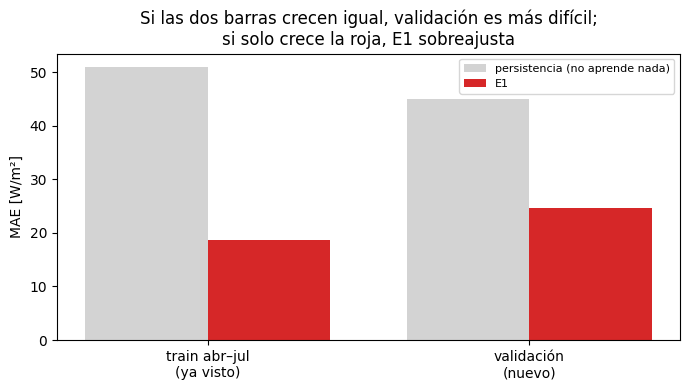


(b) SESGO SEGÚN EL CIELO DE LA HORA ANTERIOR (lo que E1 puede saber)
En la celda 1 el cielo era el de la hora objetivo, que NO se conoce al predecir. Aquí se usa el de la hora anterior.


,horas,MAE [W/m²],sesgo [W/m²],aviso
cielo_antes,,,,
despejado,185,13.2,-3.9,
velado,87,27.8,-7.2,
nubes rotas,438,33.5,-0.5,
cubierto,53,28.1,-6.1,
amanecer/atardecer,60,9.9,1.5,


Corrigiendo el sesgo por (cielo de la hora anterior × banda), estimado sin mirar el día corregido:
   MAE 24.67 → 25.35 W/m²  (-2.7 %; positivo = mejora)
➜ Corregir sesgos con la información disponible apenas mejora: C1 no es prioritario.

(c) ¿SE EQUIVOCA E1 SOBRE TODO CUANDO EL CIELO CAMBIA DE UNA HORA A OTRA?


,horas,% de las horas,% del error,MAE [W/m²],sesgo [W/m²]
situación,,,,,
el cielo cambia,197,28.0,33.9,36.0,-1.5
el cielo sigue igual,507,72.0,66.1,27.2,-3.3



MAE de E1 según el cielo de la hora anterior (filas) y el de la hora objetivo (columnas); entre paréntesis, nº de horas:


cielo,despejado,velado,nubes rotas,cubierto
cielo_antes,,,,
despejado,8 (133),4 (6),32 (41),<NA> (0)
velado,23 (3),31 (25),38 (35),47 (5)
nubes rotas,39 (35),25 (36),35 (318),72 (15)
cubierto,<NA> (0),19 (6),47 (15),22 (31)


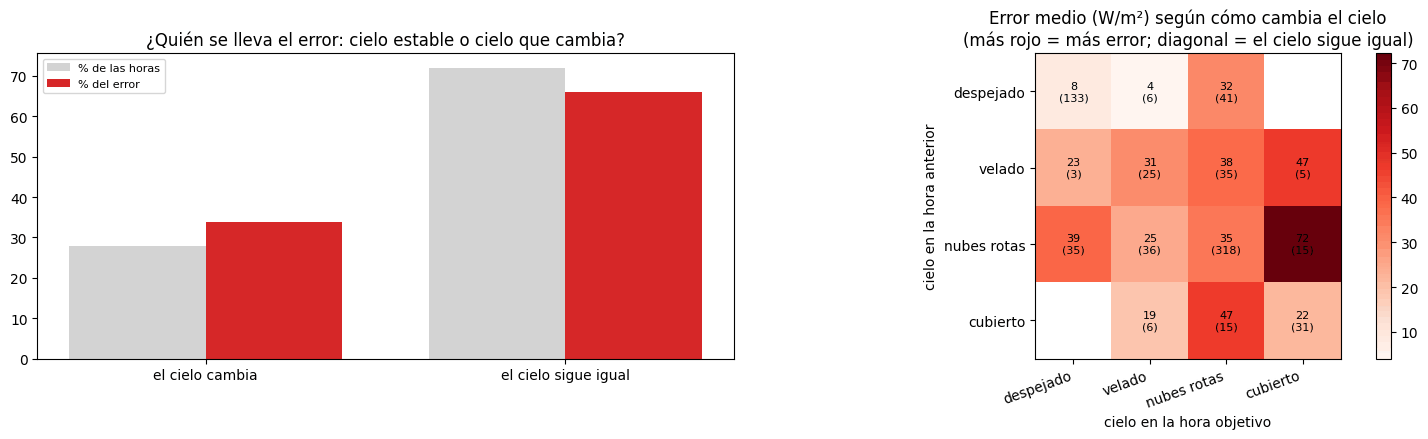

➜ Cuando el cielo cambia de una hora a otra (28 % de las horas), E1 acumula el 34 % del error (MAE 36 W/m² frente a 27 cuando sigue igual).

Dato que faltaba de B2: el 10 % de horas con más error (|error| ≥ 65 W/m²) concentra el 39 % de todo el error.

RESUMEN
(a) E1 empeora claramente MÁS que la persistencia al pasar a datos nuevos → hay SOBREAJUSTE real (memoriza parte de train). Regularizar tiene sentido.
(b) Corregir sesgos con la información disponible apenas mejora: C1 no es prioritario.
Resultados en: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/diagnostico/faseB_radiografia_E1


In [ ]:
import os
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

try:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
except ImportError:
    pass
BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
DIR_B = BASE_DIR / "resultados" / "diagnostico" / "faseB_radiografia_E1"
H = pd.read_pickle(DIR_B / "tabla_horaria_E1.pkl")
ORDEN_CIELO = ["despejado", "velado", "nubes rotas", "cubierto", "amanecer/atardecer"]

# cielo de la hora anterior (T−1): se conoce en el momento de predecir
H["cielo_antes"] = pd.Series(np.nan, index=H.index, dtype=object)
for conj in ["train", "validation"]:
    m = H["conjunto"] == conj
    serie = H.loc[m, "cielo"]
    H.loc[m, "cielo_antes"] = serie.reindex(serie.index - pd.Timedelta("1h")).to_numpy()
sol = H["regimen"] != "noche"
V = H[(H["conjunto"] == "validation") & sol].copy()
T = H[(H["conjunto"] == "train") & sol].copy()
T_ver = T[T.index.month.isin([4, 5, 6, 7])]
mae = lambda e: np.abs(e).mean()

# (a) ¿Sobreajuste o validación más difícil?
#     La persistencia no aprende nada: si ella también empeora en validación, es que validación es más difícil.
print("=" * 95 + "\n(a) ¿E1 SOBREAJUSTA, O VALIDACIÓN ES SIMPLEMENTE MÁS DIFÍCIL?\n" + "=" * 95)
filas = []
for nombre, t in [("train abr–jul (ya visto)", T_ver), ("validación ago–sep (nuevo)", V)]:
    ok = t["persistencia"].notna()
    mE, mP = mae(t.loc[ok, "error"]), mae(t.loc[ok, "persistencia"] - t.loc[ok, "real"])
    filas.append(
        {
            "datos": nombre,
            "MAE E1": mE,
            "MAE persistencia": mP,
            "mejora de E1 sobre la persistencia": f"{100*(1 - mE/mP):.0f} %",
        }
    )
A = pd.DataFrame(filas).set_index("datos")
display(A.round(2))
r_E1 = A.iloc[1]["MAE E1"] / A.iloc[0]["MAE E1"]
r_P = A.iloc[1]["MAE persistencia"] / A.iloc[0]["MAE persistencia"]
print(
    f"De train a validación, el error de E1 se multiplica por {r_E1:.2f} y el de la persistencia por {r_P:.2f}."
)
if r_E1 > r_P * 1.15:
    lect_a = (
        "E1 empeora claramente MÁS que la persistencia al pasar a datos nuevos → hay SOBREAJUSTE real "
        "(memoriza parte de train). Regularizar tiene sentido."
    )
elif r_E1 > r_P * 1.05:
    lect_a = "E1 empeora algo más que la persistencia → sobreajuste LEVE; validación además es más difícil."
else:
    lect_a = (
        "E1 empeora lo mismo que la persistencia → NO es sobreajuste: validación es simplemente "
        "un periodo más difícil. Regularizar no ayudaría."
    )
print("➜ " + lect_a)
fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(2)
w = 0.38
ax.bar(
    x - w / 2, A["MAE persistencia"], w, color="lightgray", label="persistencia (no aprende nada)"
)
ax.bar(x + w / 2, A["MAE E1"], w, color="tab:red", label="E1")
ax.set_xticks(x)
ax.set_xticklabels(["train abr–jul\n(ya visto)", "validación\n(nuevo)"])
ax.set_ylabel("MAE [W/m²]")
ax.set_title(
    "Si las dos barras crecen igual, validación es más difícil;\nsi solo crece la roja, E1 sobreajusta"
)
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(DIR_B / "B4b_control_persistencia.png", dpi=120)
plt.show()

# (b) Sesgo según el cielo de la hora ANTERIOR (información disponible al predecir)
print(
    "\n"
    + "=" * 95
    + "\n(b) SESGO SEGÚN EL CIELO DE LA HORA ANTERIOR (lo que E1 puede saber)\n"
    + "=" * 95
)
print(
    "En la celda 1 el cielo era el de la hora objetivo, que NO se conoce al predecir. Aquí se usa el de la hora anterior."
)
g = V.groupby("cielo_antes")["error"]
Bb = pd.DataFrame(
    {"horas": g.size(), "MAE [W/m²]": g.apply(mae), "sesgo [W/m²]": g.mean()}
).reindex([c for c in ORDEN_CIELO if c in g.groups])
Bb["aviso"] = np.where(Bb["horas"] < 30, "pocas horas: orientativo", "")
display(Bb.round(1))

# Corrección del sesgo por cielo de T−1 × banda, estimada de forma HONESTA:
# el sesgo de cada grupo se calcula sin el día que se corrige (validación cruzada dejando un día fuera)
V["grupo"] = V["cielo_antes"].astype(str) + " · " + V["banda"].astype(str)
dia = V.index.normalize()
corr = np.zeros(len(V))
for d in np.unique(dia):
    fuera = dia == d
    sesgos = V.loc[~fuera].groupby("grupo")["error"].mean()
    corr[fuera] = V.loc[fuera, "grupo"].map(sesgos).fillna(0).to_numpy()
mae_0, mae_c = mae(V["error"]), mae(V["error"] - corr)
print(
    f"Corrigiendo el sesgo por (cielo de la hora anterior × banda), estimado sin mirar el día corregido:"
)
print(
    f"   MAE {mae_0:.2f} → {mae_c:.2f} W/m²  ({100*(mae_0-mae_c)/mae_0:+.1f} %; positivo = mejora)"
)
lect_b = (
    "Corregir sesgos SÍ merece la pena (C1)."
    if (mae_0 - mae_c) / mae_0 > 0.02
    else "Corregir sesgos con la información disponible apenas mejora: C1 no es prioritario."
)
print("➜ " + lect_b)

# (c) ¿El error se concentra en las horas en que el cielo cambia?
print(
    "\n"
    + "=" * 95
    + "\n(c) ¿SE EQUIVOCA E1 SOBRE TODO CUANDO EL CIELO CAMBIA DE UNA HORA A OTRA?\n"
    + "=" * 95
)
dia_ok = (
    ~V["cielo"].isin(["amanecer/atardecer"])
    & ~V["cielo_antes"].isin(["amanecer/atardecer", "noche"])
    & V["cielo_antes"].notna()
)
W = V[dia_ok].copy()
W["situación"] = np.where(W["cielo"] == W["cielo_antes"], "el cielo sigue igual", "el cielo cambia")
tot = W["error"].abs().sum()
g = W.groupby("situación")["error"]
Cc = pd.DataFrame(
    {
        "horas": g.size(),
        "% de las horas": 100 * g.size() / len(W),
        "% del error": 100 * g.apply(lambda e: e.abs().sum()) / tot,
        "MAE [W/m²]": g.apply(mae),
        "sesgo [W/m²]": g.mean(),
    }
)
display(Cc.round(1))
tab = pd.crosstab(W["cielo_antes"], W["cielo"], values=W["error"].abs(), aggfunc="mean").reindex(
    index=[c for c in ORDEN_CIELO if c in W["cielo_antes"].unique()],
    columns=[c for c in ORDEN_CIELO if c in W["cielo"].unique()],
)
n_tab = (
    pd.crosstab(W["cielo_antes"], W["cielo"])
    .reindex(index=tab.index, columns=tab.columns)
    .fillna(0)
    .astype(int)
)
print(
    "\nMAE de E1 según el cielo de la hora anterior (filas) y el de la hora objetivo (columnas); entre paréntesis, nº de horas:"
)
display(tab.round(0).astype("Int64").astype(str) + " (" + n_tab.astype(str) + ")")
fig, axs = plt.subplots(1, 2, figsize=(15, 4.5))
x = np.arange(len(Cc))
w = 0.38
axs[0].bar(x - w / 2, Cc["% de las horas"], w, color="lightgray", label="% de las horas")
axs[0].bar(x + w / 2, Cc["% del error"], w, color="tab:red", label="% del error")
axs[0].set_xticks(x)
axs[0].set_xticklabels(Cc.index)
axs[0].legend(fontsize=8)
axs[0].set_title("¿Quién se lleva el error: cielo estable o cielo que cambia?")
im = axs[1].imshow(tab.to_numpy(dtype=float), cmap="Reds")
axs[1].set_xticks(range(len(tab.columns)))
axs[1].set_xticklabels(tab.columns, rotation=20, ha="right")
axs[1].set_yticks(range(len(tab.index)))
axs[1].set_yticklabels(tab.index)
axs[1].set_xlabel("cielo en la hora objetivo")
axs[1].set_ylabel("cielo en la hora anterior")
for i in range(tab.shape[0]):
    for j in range(tab.shape[1]):
        if n_tab.iat[i, j] > 0:
            axs[1].text(
                j,
                i,
                f"{tab.iat[i, j]:.0f}\n({n_tab.iat[i, j]})",
                ha="center",
                va="center",
                fontsize=8,
            )
axs[1].set_title(
    "Error medio (W/m²) según cómo cambia el cielo\n(más rojo = más error; diagonal = el cielo sigue igual)"
)
plt.colorbar(im, ax=axs[1])
plt.tight_layout()
plt.savefig(DIR_B / "B1c_cambio_de_cielo.png", dpi=120)
plt.show()
cambia = Cc.loc["el cielo cambia"] if "el cielo cambia" in Cc.index else None
if cambia is not None:
    print(
        f"➜ Cuando el cielo cambia de una hora a otra ({cambia['% de las horas']:.0f} % de las horas), "
        f"E1 acumula el {cambia['% del error']:.0f} % del error (MAE {cambia['MAE [W/m²]']:.0f} W/m² "
        f"frente a {Cc.loc['el cielo sigue igual', 'MAE [W/m²]']:.0f} cuando sigue igual)."
    )

corte = V["error"].abs().quantile(0.90)
cuota = 100 * V.loc[V["error"].abs() >= corte, "error"].abs().sum() / V["error"].abs().sum()
print(
    f"\nDato que faltaba de B2: el 10 % de horas con más error (|error| ≥ {corte:.0f} W/m²) concentra el {cuota:.0f} % de todo el error."
)
print("\n" + "=" * 95 + "\nRESUMEN\n" + "=" * 95)
print("(a) " + lect_a)
print("(b) " + lect_b)
A.to_csv(DIR_B / "B4b_control_persistencia.csv")
Bb.to_csv(DIR_B / "B1b_sesgo_cielo_anterior.csv")
Cc.to_csv(DIR_B / "B1c_cambio_de_cielo.csv")
tab.to_csv(DIR_B / "B1c_matriz_cambio_cielo.csv")
print("Resultados en:", DIR_B)

**Resultados.** De abril–julio de entrenamiento a validación, el MAE de E1 se multiplica por 1,32 (de 18,70 a 24,67 W/m²) y el de la persistencia simple por 0,88 (de 50,90 a 45,03 W/m²): la validación no es más difícil para la persistencia, lo que indica que E1 memoriza parte del entrenamiento.

- Según el cielo de la hora anterior, los sesgos van de −7,2 a +1,5 W/m², y corregirlos por cielo y banda eleva el MAE de 24,67 a 25,35 W/m².
- Cuando el cielo cambia de una hora a la siguiente (28 % de las horas), E1 reúne el 33,9 % del error, con un MAE de 36,0 W/m² frente a 27,2 W/m² cuando se mantiene.

### 5.3 E1 fuera de muestra en entrenamiento

Para separar el sobreajuste del cambio de estación, se reentrena E1 con su receta original de 105 épocas dejando fuera cada vez uno de los siete meses de entrenamiento (diciembre unido a enero), con una purga de 24 horas tras el mes excluido y las semillas 42 y 123, y se predice el mes no visto (B5). La ventaja sobre la persistencia simple, que descuenta la distinta dificultad de cada mes, se compara entre los meses vistos, esos mismos meses sin ver y la validación.

Entradas E1 train: (5149, 24, 9)  ← esperado (5149, 24, 9)
  pliegue 2024-01: entrena con 4333 horas, predice 792 horas
  pliegue 2024-02: entrena con 4429 horas, predice 696 horas
  pliegue 2024-03: entrena con 4392 horas, predice 733 horas
  pliegue 2024-04: entrena con 4405 horas, predice 720 horas
  pliegue 2024-05: entrena con 4381 horas, predice 744 horas
  pliegue 2024-06: entrena con 4405 horas, predice 720 horas
  pliegue 2024-07: entrena con 4405 horas, predice 744 horas
semilla 42 · 2024-01: 106 s (total 1.8 min)
semilla 42 · 2024-02: 102 s (total 3.5 min)
semilla 42 · 2024-03: 102 s (total 5.2 min)
semilla 42 · 2024-04: 102 s (total 6.9 min)
semilla 42 · 2024-05: 101 s (total 8.6 min)
semilla 42 · 2024-06: 100 s (total 10.2 min)
semilla 42 · 2024-07: 100 s (total 11.9 min)
semilla 123 · 2024-01: 99 s (total 13.6 min)
semilla 123 · 2024-02: 101 s (total 15.2 min)
semilla 123 · 2024-03: 100 s (total 16.9 min)
semilla 123 · 2024-04: 102 s (total 18.6 min)
semilla 123 · 2024-05

horas  MAE E1  MAE persistencia  \
semilla datos                                                                
42      1 · train abr–jul, YA VISTO         2015   20.55             50.90   
        2 · train abr–jul, NO VISTO (B5)    2015   34.00             50.90   
        3 · validación ago–sep, NO VISTO     884   25.96             45.03   
        4 · train completo, YA VISTO        3027   18.46             45.00   
        5 · train completo, NO VISTO (B5)   3027   28.71             45.00   
123     1 · train abr–jul, YA VISTO         2015   19.53             50.90   
        2 · train abr–jul, NO VISTO (B5)    2015   33.88             50.90   
        3 · validación ago–sep, NO VISTO     884   25.75             45.03   
        4 · train completo, YA VISTO        3027   17.61             45.00   
        5 · train completo, NO VISTO (B5)   3027   28.67             45.00   

                                           ventaja sobre persistencia (%)  
semilla datos                                                              
42      1 · train abr–jul, YA VISTO                                 59.63  
        2 · train abr–jul, NO VISTO (B5)                            33.20  
        3 · validación ago–sep, NO VISTO                            42.34  
        4 · train completo, YA VISTO                                58.98  
        5 · train completo, NO VISTO (B5)                           36.20  
123     1 · train abr–jul, YA VISTO                                 61.63  
        2 · train abr–jul, NO VISTO (B5)                            33.44  
        3 · validación ago–sep, NO VISTO                            42.82  
        4 · train completo, YA VISTO                                60.86  
        5 · train completo, NO VISTO (B5)                           36.28


--- Por mes (media de las 2 semillas) ---


,horas,MAE ya visto,MAE no visto (B5),MAE persistencia,ventaja no visto (%),ventaja ya visto (%)
mes,,,,,,
2024-01,311,8.6,10.8,21.2,48.9,59.3
2024-02,315,14.1,16.9,33.3,49.3,57.8
2024-03,386,17.7,24.1,42.9,43.9,58.8
2024-04,444,21.7,34.9,51.6,32.3,57.9
2024-05,519,18.4,30.2,52.2,42.3,64.7
2024-06,525,18.3,33.4,48.8,31.6,62.5
2024-07,527,18.7,34.3,51.1,32.8,63.4
ago–sep (validación),884,NaN,25.1,45.0,44.3,NaN


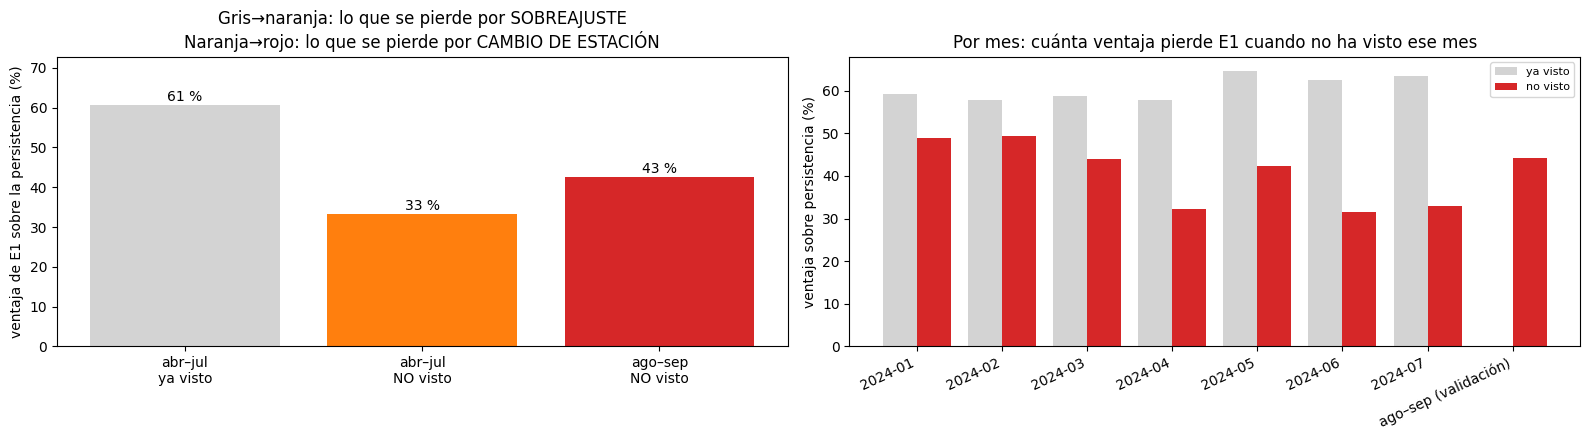


LECTURA
Ventaja de E1 sobre la persistencia: ya visto 61 % → no visto (mismos meses) 33 % → validación 43 %
  · Pérdida por SOBREAJUSTE (mismos meses, vistos vs no vistos): 27 puntos
  · Pérdida por CAMBIO DE ESTACIÓN (abr–jul no visto vs ago–sep): -9 puntos
➜ Domina el SOBREAJUSTE → regularizar E1 (C5) es la palanca principal.
Resultados en: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/diagnostico/faseB_radiografia_E1 y /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/diagnostico/faseB_radiografia_E1/B5_fuera_de_muestra


In [ ]:
import os, time, random, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
try:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
except ImportError:
    pass

BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
RUTA_NPZ = (
    BASE_DIR
    / "resultados"
    / "ejecuciones"
    / "preparacion_bloque_difstats_20261006_180841"
    / "matrices_dif_elev_difstats.npz"
)
DIR_F1 = BASE_DIR / "resultados" / "diagnostico" / "fase1_intrahoraria"
DIR_B = BASE_DIR / "resultados" / "diagnostico" / "faseB_radiografia_E1"
DIR_B5 = DIR_B / "B5_fuera_de_muestra"
DIR_B5.mkdir(parents=True, exist_ok=True)
SEMILLAS_B5 = [42, 123]
EPOCAS, BATCH, LR, WD = 105, 128, 1e-3, 1e-5  # mismo protocolo que E1
assert (
    DIR_B / "tabla_horaria_E1.pkl"
).exists(), "Ejecuta antes la celda 1 de la fase B (radiografía)"

# 1) Entradas de E1 (mismo código que la celda de la fase 1)
mat = np.load(RUTA_NPZ)
X_tr = mat["X_train_DIF_elev_DIFstats_raw"].astype(np.float32)
y_tr = mat["y_train_difstats"].astype(np.float32).reshape(-1)
fechas_tr = pd.DatetimeIndex(mat["fechas_train"])
intrahora = pd.read_csv(
    DIR_F1 / "variables_intrahorarias_horarias.csv", index_col=0, parse_dates=True
).asfreq("h")

def a_ventanas(tabla, fechas_obj, columnas, lookback=24):
    f = pd.DatetimeIndex(fechas_obj).to_numpy(dtype="datetime64[ns]")
    idx = f[:, None] - np.arange(lookback, 0, -1).astype("timedelta64[h]")[None, :]
    vals = tabla.reindex(pd.DatetimeIndex(idx.reshape(-1)))[columnas].to_numpy(dtype=np.float32)
    return vals.reshape(len(f), lookback, len(columnas))

CANALES_E1 = ["DIF_ult15", "DIF_pend30", "DIF_acel60", "DIF_saltos", "SWD_cv"]

def construir(fechas_obj, X_base, canales):
    Xn = a_ventanas(intrahora, fechas_obj, canales)
    for j, c in enumerate(canales):
        hueco = np.isnan(Xn[:, :, j])
        Xn[:, :, j][hueco] = X_base[:, :, 0][hueco] if c == "DIF_ult15" else 0.0
    return np.concatenate([X_base, Xn], axis=2).astype(np.float32)

Xtr_E1 = construir(fechas_tr, X_tr, CANALES_E1)
print(f"Entradas E1 train: {Xtr_E1.shape}  ← esperado (5149, 24, 9)")

# 2) Pliegues: un mes fuera cada vez (dic-2023 va con ene-2024) y purga de 24 h
mes = fechas_tr.to_period("M").astype(str).to_numpy()
mes = np.where(mes == "2023-12", "2024-01", mes)
MESES = sorted(np.unique(mes))

def pliegue(m):
    fuera = mes == m
    ini, fin = fechas_tr[fuera].min(), fechas_tr[fuera].max()
    # purga: las 24 h siguientes al mes que se deja fuera ven ese mes en su ventana de entrada
    purga = (fechas_tr > fin) & (fechas_tr <= fin + pd.Timedelta("24h"))
    entrena = ~fuera & ~purga
    return entrena, fuera

for m in MESES:
    e, f = pliegue(m)
    print(f"  pliegue {m}: entrena con {e.sum()} horas, predice {f.sum()} horas")

# 3) Modelo y entrenamiento (idéntico a E1)
import torch, torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler

class LSTMDIFStats(nn.Module):
    def __init__(self, n_features=4, hidden_size=64):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=n_features, hidden_size=hidden_size, num_layers=1, batch_first=True
        )
        self.head = nn.Sequential(nn.Linear(hidden_size, 32), nn.ReLU(), nn.Linear(32, 1))

    def forward(self, x):
        salida, _ = self.lstm(x)
        return self.head(salida[:, -1, :]).squeeze(-1)

def entrenar_y_predecir(Xtr, ytr, Xte, semilla):
    sx_ = StandardScaler().fit(Xtr.reshape(-1, Xtr.shape[2]))
    sy_ = StandardScaler().fit(ytr.reshape(-1, 1))
    e = lambda X: sx_.transform(X.reshape(-1, X.shape[2])).reshape(X.shape).astype(np.float32)
    Xtr_e, Xte_e = e(Xtr), e(Xte)
    ytr_e = sy_.transform(ytr.reshape(-1, 1)).ravel().astype(np.float32)
    random.seed(semilla)
    np.random.seed(semilla)
    torch.manual_seed(semilla)
    torch.use_deterministic_algorithms(True)
    modelo = LSTMDIFStats(n_features=Xtr.shape[2])
    gen = torch.Generator()
    gen.manual_seed(semilla)
    loader = DataLoader(
        TensorDataset(torch.from_numpy(Xtr_e), torch.from_numpy(ytr_e)),
        batch_size=BATCH,
        shuffle=True,
        generator=gen,
        num_workers=0,
    )
    opt = torch.optim.Adam(modelo.parameters(), lr=LR, weight_decay=WD)
    crit = nn.L1Loss()
    for ep in range(EPOCAS):
        modelo.train()
        for xb, yb in loader:
            opt.zero_grad(set_to_none=True)
            loss = crit(modelo(xb), yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(modelo.parameters(), max_norm=1.0)
            opt.step()
    modelo.eval()
    with torch.no_grad():
        z = modelo(torch.from_numpy(Xte_e)).numpy()
    return sy_.inverse_transform(z.reshape(-1, 1)).ravel()


# 4) Bucle de entrenamiento (reanudable)
t_ini = time.time()
OOF = {s: np.full(len(y_tr), np.nan) for s in SEMILLAS_B5}
for s in SEMILLAS_B5:
    for m in MESES:
        ruta = DIR_B5 / f"oof_E1_{m}_s{s}.npy"
        entrena, fuera = pliegue(m)
        if ruta.exists():
            OOF[s][fuera] = np.load(ruta)
            print(f"semilla {s} · {m}: ya calculado, se carga de Drive")
            continue
        t0 = time.time()
        p = entrenar_y_predecir(Xtr_E1[entrena], y_tr[entrena], Xtr_E1[fuera], s)
        np.save(ruta, p)
        OOF[s][fuera] = p
        print(f"semilla {s} · {m}: {time.time()-t0:.0f} s (total {(time.time()-t_ini)/60:.1f} min)")
assert all(np.isfinite(OOF[s]).all() for s in SEMILLAS_B5), "Faltan predicciones fuera de muestra"

# 5) Comparación: dentro de muestra · fuera de muestra (train) · validación
H = pd.read_pickle(DIR_B / "tabla_horaria_E1.pkl")
TR = H[H["conjunto"] == "train"].copy()
VA = H[H["conjunto"] == "validation"].copy()
assert (
    len(TR) == len(y_tr) and (TR.index == fechas_tr).all()
), "La tabla de la celda 1 no cuadra con el .npz"
for s in SEMILLAS_B5:
    TR[f"OOF_s{s}"] = OOF[s]
TR["OOF_media"] = TR[[f"OOF_s{s}" for s in SEMILLAS_B5]].mean(axis=1)
TR["DENTRO_media"] = TR[[f"E1_s{s}" for s in SEMILLAS_B5]].mean(axis=1)
VA["VAL_media"] = VA[[f"E1_s{s}" for s in SEMILLAS_B5]].mean(axis=1)
TR["mes_pliegue"] = mes
TR[["OOF_s42", "OOF_s123", "OOF_media", "DENTRO_media", "mes_pliegue"]].to_pickle(
    DIR_B5 / "predicciones_oof_train.pkl"
)
solT, solV = TR["regimen"] != "noche", VA["regimen"] != "noche"
mae = lambda p, y: np.abs(p - y).mean()

def fila(nombre, t, col, msk):
    t = t[msk & t["persistencia"].notna()]
    mE, mP = mae(t[col], t["real"]), mae(t["persistencia"], t["real"])
    return {
        "datos": nombre,
        "horas": len(t),
        "MAE E1": mE,
        "MAE persistencia": mP,
        "ventaja sobre persistencia (%)": 100 * (1 - mE / mP),
    }

ver = TR.index.month.isin([4, 5, 6, 7])
res = []
for s in SEMILLAS_B5:
    for nombre, t, col, msk in [
        ("1 · train abr–jul, YA VISTO", TR, f"E1_s{s}", solT & ver),
        ("2 · train abr–jul, NO VISTO (B5)", TR, f"OOF_s{s}", solT & ver),
        ("3 · validación ago–sep, NO VISTO", VA, f"E1_s{s}", solV),
        ("4 · train completo, YA VISTO", TR, f"E1_s{s}", solT),
        ("5 · train completo, NO VISTO (B5)", TR, f"OOF_s{s}", solT),
    ]:
        res.append({"semilla": s, **fila(nombre, t, col, msk)})
R = pd.DataFrame(res)
print(
    "\n"
    + "=" * 95
    + "\nB5 · ERROR DE E1 EN DATOS YA VISTOS Y NO VISTOS (horas con sol)\n"
    + "=" * 95
)
print(
    "La 'ventaja sobre persistencia' quita el efecto de que unos meses sean más fáciles que otros."
)
display(R.round(2).set_index(["semilla", "datos"]))
Rm = R.groupby("datos")[["MAE E1", "MAE persistencia", "ventaja sobre persistencia (%)"]].mean()

# por mes: ¿en qué meses pierde más E1 cuando no los ha visto?
filas = []
for m in MESES:
    msk = solT & (TR["mes_pliegue"] == m) & TR["persistencia"].notna()
    t = TR[msk]
    filas.append(
        {
            "mes": m,
            "horas": len(t),
            "MAE ya visto": mae(t["DENTRO_media"], t["real"]),
            "MAE no visto (B5)": mae(t["OOF_media"], t["real"]),
            "MAE persistencia": mae(t["persistencia"], t["real"]),
        }
    )
t = VA[solV & VA["persistencia"].notna()]
filas.append(
    {
        "mes": "ago–sep (validación)",
        "horas": len(t),
        "MAE ya visto": np.nan,
        "MAE no visto (B5)": mae(t["VAL_media"], t["real"]),
        "MAE persistencia": mae(t["persistencia"], t["real"]),
    }
)
PM = pd.DataFrame(filas).set_index("mes")
PM["ventaja no visto (%)"] = 100 * (1 - PM["MAE no visto (B5)"] / PM["MAE persistencia"])
PM["ventaja ya visto (%)"] = 100 * (1 - PM["MAE ya visto"] / PM["MAE persistencia"])
print("\n--- Por mes (media de las 2 semillas) ---")
display(PM.round(1))

# 6) Gráficas y lectura
v1 = Rm.loc["1 · train abr–jul, YA VISTO", "ventaja sobre persistencia (%)"]
v2 = Rm.loc["2 · train abr–jul, NO VISTO (B5)", "ventaja sobre persistencia (%)"]
v3 = Rm.loc["3 · validación ago–sep, NO VISTO", "ventaja sobre persistencia (%)"]
fig, axs = plt.subplots(1, 2, figsize=(16, 4.5))
axs[0].bar(
    ["abr–jul\nya visto", "abr–jul\nNO visto", "ago–sep\nNO visto"],
    [v1, v2, v3],
    color=["lightgray", "tab:orange", "tab:red"],
)
for i, v in enumerate([v1, v2, v3]):
    axs[0].text(i, v + 1, f"{v:.0f} %", ha="center")
axs[0].set_ylabel("ventaja de E1 sobre la persistencia (%)")
axs[0].set_ylim(0, max(v1, v2, v3) * 1.2)
axs[0].set_title(
    "Gris→naranja: lo que se pierde por SOBREAJUSTE\nNaranja→rojo: lo que se pierde por CAMBIO DE ESTACIÓN"
)
x = np.arange(len(PM))
w = 0.4
axs[1].bar(x - w / 2, PM["ventaja ya visto (%)"], w, color="lightgray", label="ya visto")
axs[1].bar(x + w / 2, PM["ventaja no visto (%)"], w, color="tab:red", label="no visto")
axs[1].set_xticks(x)
axs[1].set_xticklabels(PM.index, rotation=25, ha="right")
axs[1].set_ylabel("ventaja sobre persistencia (%)")
axs[1].legend(fontsize=8)
axs[1].set_title("Por mes: cuánta ventaja pierde E1 cuando no ha visto ese mes")
plt.tight_layout()
plt.savefig(DIR_B / "B5_sobreajuste_vs_estacion.png", dpi=120)
plt.show()
sobreajuste, estacion = v1 - v2, v2 - v3
print("\n" + "=" * 95 + "\nLECTURA\n" + "=" * 95)
print(
    f"Ventaja de E1 sobre la persistencia: ya visto {v1:.0f} % → no visto (mismos meses) {v2:.0f} % → validación {v3:.0f} %"
)
print(f"  · Pérdida por SOBREAJUSTE (mismos meses, vistos vs no vistos): {sobreajuste:.0f} puntos")
print(f"  · Pérdida por CAMBIO DE ESTACIÓN (abr–jul no visto vs ago–sep): {estacion:.0f} puntos")
if sobreajuste >= 5 and sobreajuste >= estacion:
    lect = "Domina el SOBREAJUSTE → regularizar E1 (C5) es la palanca principal."
elif estacion >= 5 and estacion > sobreajuste:
    lect = (
        "Domina el CAMBIO DE ESTACIÓN → el problema es que train no se parece a ago–sep; "
        "regularizar ayudaría poco. Hay que pensar en qué datos ve E1 al entrenar."
    )
elif sobreajuste >= 5 or estacion >= 5:
    lect = "Las dos causas pesan parecido."
else:
    lect = "Ninguna de las dos pérdidas es grande (< 5 puntos)."
print("➜ " + lect)
R.to_csv(DIR_B / "B5_resumen.csv", index=False)
PM.to_csv(DIR_B / "B5_por_mes.csv")
with open(DIR_B / "B5_lectura.txt", "w") as f:
    f.write(
        f"ventaja ya visto {v1:.2f} | no visto abr-jul {v2:.2f} | validacion {v3:.2f}\n"
        f"sobreajuste {sobreajuste:.2f} | estacion {estacion:.2f}\n{lect}\n"
    )
print("Resultados en:", DIR_B, "y", DIR_B5)

**Resultados.** De media entre las dos semillas, la ventaja de E1 sobre la persistencia simple pasa del 61 % en abril–julio ya vistos al 33 % en esos mismos meses sin verlos y al 43 % en validación. La diferencia entre meses vistos y no vistos es de 27 puntos; la atribuible al cambio de estación, de −9 puntos. Por meses, la ventaja fuera de muestra es del 48,9 % y el 49,3 % en enero y febrero, y cae a valores entre el 31,6 % y el 42,3 % de abril a julio, frente al 57,9–64,7 % de esos meses ya vistos. En todo el entrenamiento, el MAE fuera de muestra es de 28,71 y 28,67 W/m² según la semilla.

### 5.4 Predictibilidad del error de E1

Con los errores fuera de muestra de B5 (ensemble de las semillas 42 y 123) se entrenan modelos HGB que predicen el error de E1 en las horas completamente diurnas, y se evalúan en validación (B3). Se comprueba si restar el error previsto reduce el MAE, frente a restar un sesgo constante, y si el tamaño previsto del error ordena las horas según su error real; como información se usa la que ve E1 (I1) y esta más las variables meteorológicas (I2).

Horas diurnas: train 2604 (errores fuera de muestra) | validación 765
MAE de E1 (2 semillas) en estas horas: train fuera de muestra 32.05 | validación 28.57 W/m²

OBJETIVO 1 · ¿SE PUEDE CORREGIR EL ERROR DE E1? (predecir el error y restarlo)
Se compara E1 tal cual con E1 corregido. 'Corrección constante' = restar siempre el sesgo medio de train (referencia simple).


,MAE train sin corregir,MAE train corregido,MAE validación sin corregir,MAE validación corregido,cambio en validación (W/m²),IC95 del cambio,¿mejora real?
versión,,,,,,,
corrección constante,32.05,32.05,28.57,28.57,-0.00,"[-0.02, +0.01]",no se distingue del azar
corrección con I1,32.05,34.50,28.57,29.05,0.48,"[-0.10, +1.11]",no se distingue del azar
corrección con I2,32.05,33.66,28.57,28.81,0.23,"[-0.36, +0.80]",no se distingue del azar



OBJETIVO 2 · ¿SE PUEDE SABER DE ANTEMANO CUÁNDO E1 VA A FALLAR MUCHO?
Se predice el tamaño del error y se ordenan las horas de 'riesgo bajo' a 'riesgo alto' (5 grupos iguales).
Si funciona, el error real debe crecer claramente de un grupo al siguiente.


,correlación train (Spearman),correlación validación (Spearman),"error real, riesgo muy bajo","error real, riesgo muy alto",veces más error (alto / bajo)
versión,,,,,
riesgo con I1,0.54,0.49,10.09,50.10,4.97
riesgo con I2,0.55,0.51,8.76,49.94,5.70


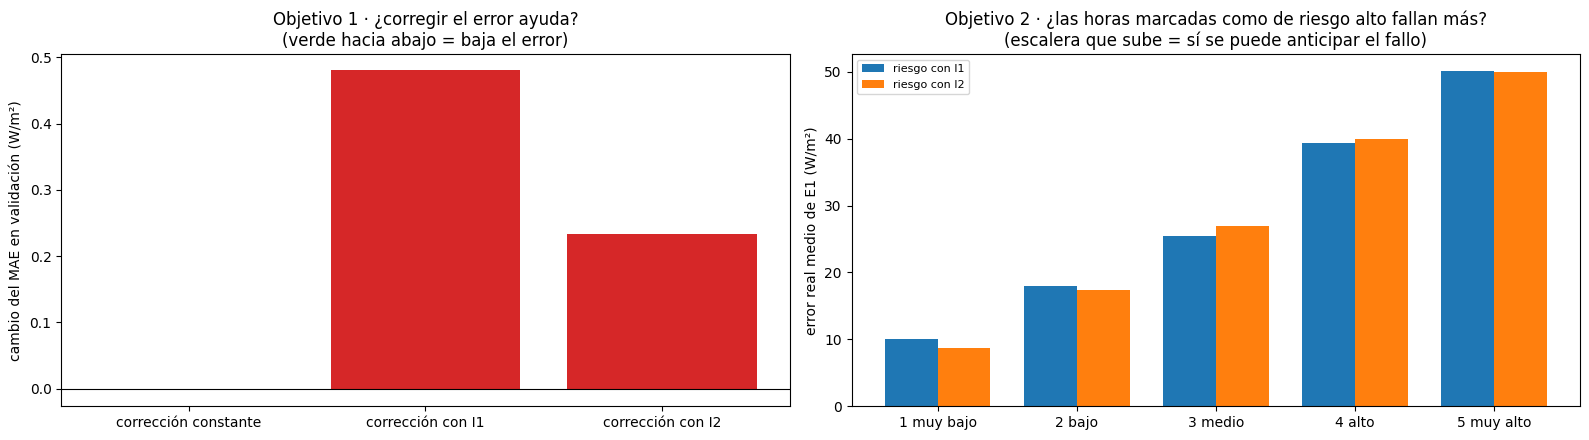


LECTURA
➜ Objetivo 1: ninguna corrección baja el MAE de forma distinguible del azar → el error de E1 NO es corregible con esta información.
➜ Objetivo 2: las horas de riesgo muy alto fallan 5.7 veces más que las de riesgo muy bajo (correlación 0.51) → SÍ se puede anticipar cuándo va a fallar E1: base sólida para bandas probabilísticas (D1).
➜ Las variables meteorológicas (I2) cambian la correlación en +0.02 respecto a I1.
Resultados en: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/diagnostico/faseB_radiografia_E1


In [ ]:
import os, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor
from scipy.stats import spearmanr

warnings.filterwarnings("ignore")
try:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
except ImportError:
    pass

BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
DIR_B = BASE_DIR / "resultados" / "diagnostico" / "faseB_radiografia_E1"
DIR_FA = BASE_DIR / "resultados" / "diagnostico" / "faseA_anticipabilidad"
assert (
    DIR_B / "B5_fuera_de_muestra" / "predicciones_oof_train.pkl"
).exists(), "Ejecuta antes la celda B5"
N_BOOT, SEMILLA = 1000, 0

# 1) Datos: variables de la fase A + errores de E1 (train fuera de muestra / validación)
F = pd.read_pickle(DIR_FA / "faseA_puntos1_6.pkl")
X, CONJ = F["X"], F["CONJ"]
H = pd.read_pickle(DIR_B / "tabla_horaria_E1.pkl")
OOF = pd.read_pickle(DIR_B / "B5_fuera_de_muestra" / "predicciones_oof_train.pkl")
TR = H[H["conjunto"] == "train"]
VA = H[H["conjunto"] == "validation"]
idx_tr = X.index[F["tr"]].intersection(OOF.index)
idx_va = X.index[F["va"]].intersection(VA.index)
e_tr = (OOF.loc[idx_tr, "OOF_media"] - TR.loc[idx_tr, "real"]).to_numpy()
pred_va = VA.loc[idx_va, ["E1_s42", "E1_s123"]].mean(axis=1)
e_va = (pred_va - VA.loc[idx_va, "real"]).to_numpy()
mes_tr = idx_tr.to_period("M").astype(str).to_numpy()
mes_tr = np.where(mes_tr == "2023-12", "2024-01", mes_tr)
dias_va = idx_va.normalize().to_numpy()
print(f"Horas diurnas: train {len(idx_tr)} (errores fuera de muestra) | validación {len(idx_va)}")
print(
    f"MAE de E1 (2 semillas) en estas horas: train fuera de muestra {np.abs(e_tr).mean():.2f} | validación {np.abs(e_va).mean():.2f} W/m²"
)

def hgb(perdida):
    return HistGradientBoostingRegressor(
        loss=perdida,
        max_iter=300,
        learning_rate=0.05,
        max_leaf_nodes=15,
        min_samples_leaf=40,
        l2_regularization=1.0,
        random_state=SEMILLA,
    )

def cv_meses(cols, y, perdida):
    """Predicción fuera de muestra en train dejando un mes fuera."""
    Xt = X.loc[idx_tr, cols].to_numpy(float)
    p = np.zeros(len(y))
    for m in np.unique(mes_tr):
        te = mes_tr == m
        p[te] = hgb(perdida).fit(Xt[~te], y[~te]).predict(Xt[te])
    return p

def boot_dmae(a, b, dias):
    """IC95 de MAE(a) − MAE(b) remuestreando días."""
    rng = np.random.default_rng(SEMILLA)
    u, inv = np.unique(dias, return_inverse=True)
    g = [np.where(inv == i)[0] for i in range(len(u))]
    d = [
        np.abs(a[s]).mean() - np.abs(b[s]).mean()
        for s in (
            np.concatenate([g[i] for i in rng.integers(0, len(g), len(g))]) for _ in range(N_BOOT)
        )
    ]
    return np.percentile(d, [2.5, 97.5])


# OBJETIVO 1 · ¿SE PUEDE CORREGIR EL ERROR? (error con signo)
print(
    "\n"
    + "=" * 95
    + "\nOBJETIVO 1 · ¿SE PUEDE CORREGIR EL ERROR DE E1? (predecir el error y restarlo)\n"
    + "=" * 95
)
print(
    "Se compara E1 tal cual con E1 corregido. 'Corrección constante' = restar siempre el sesgo medio de train (referencia simple)."
)
filas = []
const = np.median(e_tr)
for nombre, cols in [
    ("corrección constante", None),
    ("corrección con I1", CONJ["I1"]),
    ("corrección con I2", CONJ["I2"]),
]:
    if cols is None:
        c_tr, c_va = np.full(len(e_tr), const), np.full(len(e_va), const)
    else:
        c_tr = cv_meses(cols, e_tr, "absolute_error")
        c_va = (
            hgb("absolute_error")
            .fit(X.loc[idx_tr, cols].to_numpy(float), e_tr)
            .predict(X.loc[idx_va, cols].to_numpy(float))
        )
    lo, hi = boot_dmae(e_va - c_va, e_va, dias_va)
    filas.append(
        {
            "versión": nombre,
            "MAE train sin corregir": np.abs(e_tr).mean(),
            "MAE train corregido": np.abs(e_tr - c_tr).mean(),
            "MAE validación sin corregir": np.abs(e_va).mean(),
            "MAE validación corregido": np.abs(e_va - c_va).mean(),
            "cambio en validación (W/m²)": np.abs(e_va - c_va).mean() - np.abs(e_va).mean(),
            "IC95 del cambio": f"[{lo:+.2f}, {hi:+.2f}]",
            "¿mejora real?": (
                "SÍ" if hi < 0 else ("empeora" if lo > 0 else "no se distingue del azar")
            ),
        }
    )
O1 = pd.DataFrame(filas).set_index("versión")
display(O1.round(2))

# OBJETIVO 2 · ¿SE PUEDE SABER CUÁNDO VA A FALLAR? (tamaño del error)
print(
    "\n"
    + "=" * 95
    + "\nOBJETIVO 2 · ¿SE PUEDE SABER DE ANTEMANO CUÁNDO E1 VA A FALLAR MUCHO?\n"
    + "=" * 95
)
print(
    "Se predice el tamaño del error y se ordenan las horas de 'riesgo bajo' a 'riesgo alto' (5 grupos iguales)."
)
print("Si funciona, el error real debe crecer claramente de un grupo al siguiente.")
filas, quintiles = [], {}
for nombre, cols in [("riesgo con I1", CONJ["I1"]), ("riesgo con I2", CONJ["I2"])]:
    a_tr = cv_meses(cols, np.abs(e_tr), "squared_error")
    a_va = (
        hgb("squared_error")
        .fit(X.loc[idx_tr, cols].to_numpy(float), np.abs(e_tr))
        .predict(X.loc[idx_va, cols].to_numpy(float))
    )
    grupos = pd.qcut(a_va, 5, labels=["1 muy bajo", "2 bajo", "3 medio", "4 alto", "5 muy alto"])
    q = pd.Series(np.abs(e_va)).groupby(np.asarray(grupos)).mean()
    quintiles[nombre] = q
    filas.append(
        {
            "versión": nombre,
            "correlación train (Spearman)": spearmanr(a_tr, np.abs(e_tr)).correlation,
            "correlación validación (Spearman)": spearmanr(a_va, np.abs(e_va)).correlation,
            "error real, riesgo muy bajo": q.iloc[0],
            "error real, riesgo muy alto": q.iloc[-1],
            "veces más error (alto / bajo)": q.iloc[-1] / q.iloc[0],
        }
    )
O2 = pd.DataFrame(filas).set_index("versión")
display(O2.round(2))

# Gráficas
fig, axs = plt.subplots(1, 2, figsize=(16, 4.5))
x = np.arange(len(O1))
axs[0].bar(
    x,
    O1["cambio en validación (W/m²)"],
    color=["tab:green" if v < 0 else "tab:red" for v in O1["cambio en validación (W/m²)"]],
)
axs[0].axhline(0, color="k", lw=0.8)
axs[0].set_xticks(x)
axs[0].set_xticklabels(O1.index)
axs[0].set_ylabel("cambio del MAE en validación (W/m²)")
axs[0].set_title("Objetivo 1 · ¿corregir el error ayuda?\n(verde hacia abajo = baja el error)")
w = 0.38
for k, (nombre, q) in enumerate(quintiles.items()):
    axs[1].bar(np.arange(5) + (k - 0.5) * w, q.values, w, label=nombre)
axs[1].set_xticks(range(5))
axs[1].set_xticklabels(quintiles["riesgo con I1"].index)
axs[1].set_ylabel("error real medio de E1 (W/m²)")
axs[1].legend(fontsize=8)
axs[1].set_title(
    "Objetivo 2 · ¿las horas marcadas como de riesgo alto fallan más?\n(escalera que sube = sí se puede anticipar el fallo)"
)
plt.tight_layout()
plt.savefig(DIR_B / "B3_error_predecible.png", dpi=120)
plt.show()

# Lectura
print("\n" + "=" * 95 + "\nLECTURA\n" + "=" * 95)
mejor = O1["cambio en validación (W/m²)"].idxmin()
if O1.loc[mejor, "¿mejora real?"] == "SÍ":
    l1 = (
        f"Objetivo 1: '{mejor}' baja el MAE de validación {-O1.loc[mejor, 'cambio en validación (W/m²)']:.2f} W/m² "
        "y la mejora es real → E1 deja información sin usar; corregir (C1) o pasarle esa información merece la pena."
    )
else:
    l1 = "Objetivo 1: ninguna corrección baja el MAE de forma distinguible del azar → el error de E1 NO es corregible con esta información."
ganancia_I2 = (
    O2.loc["riesgo con I2", "correlación validación (Spearman)"]
    - O2.loc["riesgo con I1", "correlación validación (Spearman)"]
)
r_val = O2["correlación validación (Spearman)"].max()
veces = O2["veces más error (alto / bajo)"].max()
l2 = (
    f"Objetivo 2: las horas de riesgo muy alto fallan {veces:.1f} veces más que las de riesgo muy bajo "
    f"(correlación {r_val:.2f}) → "
    + (
        "SÍ se puede anticipar cuándo va a fallar E1: base sólida para bandas probabilísticas (D1)."
        if veces >= 2 and r_val >= 0.3
        else "anticipar el fallo es difícil."
    )
)
l3 = (
    f"Las variables meteorológicas (I2) cambian la correlación en {ganancia_I2:+.2f} respecto a I1."
)
for l in (l1, l2, l3):
    print("➜ " + l)
O1.to_csv(DIR_B / "B3_objetivo1_corregir.csv")
O2.to_csv(DIR_B / "B3_objetivo2_riesgo.csv")
pd.DataFrame(quintiles).to_csv(DIR_B / "B3_objetivo2_por_grupo_de_riesgo.csv")
with open(DIR_B / "B3_lectura.txt", "w") as f:
    f.write("\n".join([l1, l2, l3]) + "\n")
print("Resultados en:", DIR_B)

**Resultados.** En las 765 horas completamente diurnas de validación, ninguna corrección reduce el MAE de 28,57 W/m² de forma distinguible del azar: la constante lo deja igual, la basada en I1 lo sube 0,48 W/m² (IC95 [−0,10; +1,11]) y la basada en I2, 0,23 W/m² (IC95 [−0,36; +0,80]). El tamaño del error sí se anticipa: la correlación de Spearman entre el error previsto y el real es de 0,49 con I1 y de 0,51 con I2, y con I2 el quintil de mayor riesgo tiene 5,70 veces más error que el de menor riesgo (49,94 frente a 8,76 W/m²).

## 6. Curvas de aprendizaje, parada temprana y normalización

> *Se utiliza en la memoria: apartado 5.3.3 (E1-30) y Tabla B1 (C6), y fases 7 a 9 de la Tabla A1.*

### 6.1 Curvas de aprendizaje de E1

Con la validación cruzada dejando un mes fuera de entrenamiento (siete pliegues, purga de 24 horas, semilla 42), se entrena E1 hasta 150 épocas y cada cinco se mide el MAE en horas con sol de los meses vistos, del mes no visto y de sus horas de nubosidad variable (C5a). La época óptima se toma del error del mes no visto suavizado con una media móvil centrada, sin usar la validación.

Entradas E1 train: (5149, 24, 9)  ← esperado (5149, 24, 9)
2024-01: 161 s (total 2.7 min)
2024-02: 165 s (total 5.4 min)
2024-03: 162 s (total 8.1 min)
2024-04: 165 s (total 10.9 min)
2024-05: 162 s (total 13.6 min)
2024-06: 162 s (total 16.3 min)
2024-07: 161 s (total 19.0 min)

C5a · ¿CUÁNTAS ÉPOCAS NECESITA E1?


,MAE meses vistos,MAE mes no visto,MAE nubosidad variable no vista,MAE mes no visto (suavizado),ventaja no visto sobre persistencia (%)
epoca,,,,,
5,27.93,28.99,40.35,28.16,35.56
10,25.93,27.32,38.30,27.68,39.28
20,24.57,26.57,37.66,26.58,40.95
30,24.05,26.73,38.32,26.60,40.60
40,23.43,26.60,38.18,26.61,40.88
50,22.74,26.84,37.92,26.66,40.36
60,22.16,27.03,39.29,26.96,39.93
80,20.33,27.79,40.16,27.62,38.24
100,18.33,28.28,41.31,28.48,37.16


Mejor época (error en el mes no visto, suavizado): 25 → MAE 26.58 W/m²
Primera época a menos del 1 % del mejor error: 20
Con las 105 épocas actuales de E1: MAE 28.50 W/m² (+1.92 respecto al mejor)


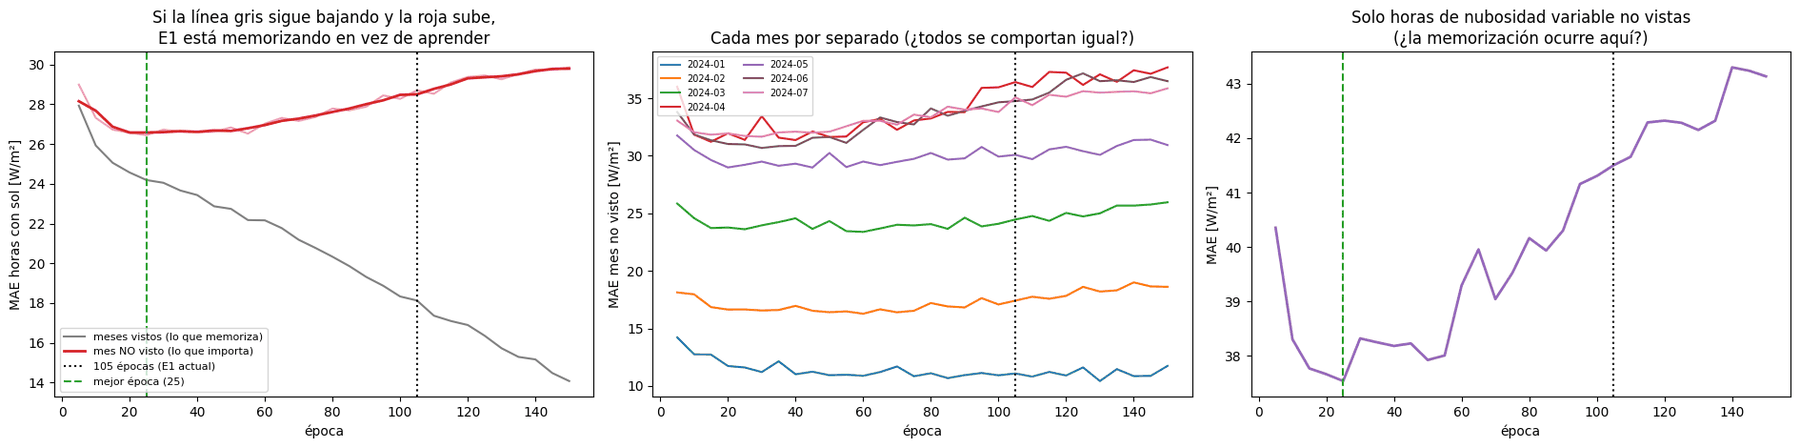


LECTURA
➜ E1 alcanza su mejor error hacia la época 25 y después empeora: con 105 épocas pierde 1.92 W/m². Parar antes (≈20–25 épocas) es la primera regularización a probar en C5b.
   Al final, el mes no visto tiene 15.8 W/m² más de error que los meses vistos (tamaño de la memorización).
   (Una semilla: la curva tiene algo de ruido; por eso se usa la versión suavizada para decidir.)
Resultados en: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/diagnostico/faseC_regularizacion


In [ ]:
import os, time, random, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
try:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
except ImportError:
    pass

BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
RUTA_NPZ = (
    BASE_DIR
    / "resultados"
    / "ejecuciones"
    / "preparacion_bloque_difstats_20261006_180841"
    / "matrices_dif_elev_difstats.npz"
)
DIR_F1 = BASE_DIR / "resultados" / "diagnostico" / "fase1_intrahoraria"
DIR_B = BASE_DIR / "resultados" / "diagnostico" / "faseB_radiografia_E1"
DIR_C5 = BASE_DIR / "resultados" / "diagnostico" / "faseC_regularizacion" / "C5a_curvas"
DIR_C5.mkdir(parents=True, exist_ok=True)
SEMILLA = 42
EPOCAS_MAX, CADA = 150, 5
BATCH, LR, WD = 128, 1e-3, 1e-5  # mismo protocolo que E1
assert (
    DIR_B / "tabla_horaria_E1.pkl"
).exists(), "Falta la tabla de la radiografía (fase B, celda 1)"

# 1) Entradas de E1 (mismo código que la celda de la fase 1)
mat = np.load(RUTA_NPZ)
X_tr = mat["X_train_DIF_elev_DIFstats_raw"].astype(np.float32)
y_tr = mat["y_train_difstats"].astype(np.float32).reshape(-1)
fechas_tr = pd.DatetimeIndex(mat["fechas_train"])
intrahora = pd.read_csv(
    DIR_F1 / "variables_intrahorarias_horarias.csv", index_col=0, parse_dates=True
).asfreq("h")

def a_ventanas(tabla, fechas_obj, columnas, lookback=24):
    f = pd.DatetimeIndex(fechas_obj).to_numpy(dtype="datetime64[ns]")
    idx = f[:, None] - np.arange(lookback, 0, -1).astype("timedelta64[h]")[None, :]
    vals = tabla.reindex(pd.DatetimeIndex(idx.reshape(-1)))[columnas].to_numpy(dtype=np.float32)
    return vals.reshape(len(f), lookback, len(columnas))

CANALES_E1 = ["DIF_ult15", "DIF_pend30", "DIF_acel60", "DIF_saltos", "SWD_cv"]

def construir(fechas_obj, X_base, canales):
    Xn = a_ventanas(intrahora, fechas_obj, canales)
    for j, c in enumerate(canales):
        hueco = np.isnan(Xn[:, :, j])
        Xn[:, :, j][hueco] = X_base[:, :, 0][hueco] if c == "DIF_ult15" else 0.0
    return np.concatenate([X_base, Xn], axis=2).astype(np.float32)

Xtr_E1 = construir(fechas_tr, X_tr, CANALES_E1)
print(f"Entradas E1 train: {Xtr_E1.shape}  ← esperado (5149, 24, 9)")

# Información por hora (de la radiografía): horas con sol, tipo de cielo y persistencia
H = pd.read_pickle(DIR_B / "tabla_horaria_E1.pkl")
TR = H[H["conjunto"] == "train"]
assert (
    len(TR) == len(y_tr) and (TR.index == fechas_tr).all()
), "La tabla de la radiografía no cuadra con el .npz"
SOL = (TR["regimen"] != "noche").to_numpy()
NUBES = (TR["cielo"] == "nubes rotas").to_numpy()  # "nubosidad variable"
PERS = TR["persistencia"].to_numpy()

# 2) Pliegues (idénticos a B5)
mes = fechas_tr.to_period("M").astype(str).to_numpy()
mes = np.where(mes == "2023-12", "2024-01", mes)
MESES = sorted(np.unique(mes))

def pliegue(m):
    fuera = mes == m
    fin = fechas_tr[fuera].max()
    purga = (fechas_tr > fin) & (fechas_tr <= fin + pd.Timedelta("24h"))
    return ~fuera & ~purga, fuera


# 3) Entrenamiento con medición cada 5 épocas (mismo modelo y protocolo que E1)
import torch, torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler

class LSTMDIFStats(nn.Module):
    def __init__(self, n_features=4, hidden_size=64):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=n_features, hidden_size=hidden_size, num_layers=1, batch_first=True
        )
        self.head = nn.Sequential(nn.Linear(hidden_size, 32), nn.ReLU(), nn.Linear(32, 1))

    def forward(self, x):
        salida, _ = self.lstm(x)
        return self.head(salida[:, -1, :]).squeeze(-1)

def entrenar_con_curva(entrena, fuera, semilla):
    """Devuelve una tabla: por cada 5 épocas, suma de |error| y nº de horas (vistas / no vistas / nubosidad variable no vista)."""
    Xtr, ytr, Xte, yte = Xtr_E1[entrena], y_tr[entrena], Xtr_E1[fuera], y_tr[fuera]
    sx_ = StandardScaler().fit(Xtr.reshape(-1, Xtr.shape[2]))
    sy_ = StandardScaler().fit(ytr.reshape(-1, 1))
    e = lambda X: torch.from_numpy(
        sx_.transform(X.reshape(-1, X.shape[2])).reshape(X.shape).astype(np.float32)
    )
    Xtr_t, Xte_t = e(Xtr), e(Xte)
    ytr_e = sy_.transform(ytr.reshape(-1, 1)).ravel().astype(np.float32)
    random.seed(semilla)
    np.random.seed(semilla)
    torch.manual_seed(semilla)
    torch.use_deterministic_algorithms(True)
    modelo = LSTMDIFStats(n_features=Xtr.shape[2])
    gen = torch.Generator()
    gen.manual_seed(semilla)
    loader = DataLoader(
        TensorDataset(Xtr_t, torch.from_numpy(ytr_e)),
        batch_size=BATCH,
        shuffle=True,
        generator=gen,
        num_workers=0,
    )
    opt = torch.optim.Adam(modelo.parameters(), lr=LR, weight_decay=WD)
    crit = nn.L1Loss()
    sol_tr, sol_te, nub_te = SOL[entrena], SOL[fuera], SOL[fuera] & NUBES[fuera]
    pred = lambda Xt: sy_.inverse_transform(modelo(Xt).numpy().reshape(-1, 1)).ravel()
    filas = []
    for ep in range(1, EPOCAS_MAX + 1):
        modelo.train()
        for xb, yb in loader:
            opt.zero_grad(set_to_none=True)
            loss = crit(modelo(xb), yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(modelo.parameters(), max_norm=1.0)
            opt.step()
        if ep % CADA == 0:
            modelo.eval()
            with torch.no_grad():
                a_tr, a_te = np.abs(pred(Xtr_t) - ytr), np.abs(pred(Xte_t) - yte)
            filas.append(
                {
                    "epoca": ep,
                    "suma_err_visto": a_tr[sol_tr].sum(),
                    "n_visto": sol_tr.sum(),
                    "suma_err_no_visto": a_te[sol_te].sum(),
                    "n_no_visto": sol_te.sum(),
                    "suma_err_nubes": a_te[nub_te].sum(),
                    "n_nubes": nub_te.sum(),
                }
            )
    return pd.DataFrame(filas)

t_ini = time.time()
curvas = {}
for m in MESES:
    ruta = DIR_C5 / f"curva_{m}_s{SEMILLA}.csv"
    if ruta.exists():
        curvas[m] = pd.read_csv(ruta)
        print(f"{m}: ya calculado, se carga de Drive")
        continue
    t0 = time.time()
    entrena, fuera = pliegue(m)
    curvas[m] = entrenar_con_curva(entrena, fuera, SEMILLA)
    curvas[m].to_csv(ruta, index=False)
    print(f"{m}: {time.time()-t0:.0f} s (total {(time.time()-t_ini)/60:.1f} min)")

# 4) Curva global (todos los meses juntos) y lectura
tot = sum(c.set_index("epoca") for c in curvas.values())
C = pd.DataFrame(
    {
        "MAE meses vistos": tot["suma_err_visto"] / tot["n_visto"],
        "MAE mes no visto": tot["suma_err_no_visto"] / tot["n_no_visto"],
        "MAE nubosidad variable no vista": tot["suma_err_nubes"] / tot["n_nubes"],
    }
)
C["MAE mes no visto (suavizado)"] = (
    C["MAE mes no visto"].rolling(3, center=True, min_periods=1).mean()
)
mae_pers = np.nanmean(np.abs(PERS[SOL] - y_tr[SOL]))
C["ventaja no visto sobre persistencia (%)"] = 100 * (1 - C["MAE mes no visto"] / mae_pers)
C.to_csv(DIR_C5.parent / "C5a_curva_global.csv")
ep_mejor = int(C["MAE mes no visto (suavizado)"].idxmin())
mae_mejor = C.loc[ep_mejor, "MAE mes no visto (suavizado)"]
ep_ref = 105 if 105 in C.index else C.index[C.index <= 105].max()
mae_105 = C.loc[ep_ref, "MAE mes no visto (suavizado)"]
ep_plano = int(
    C.index[C["MAE mes no visto (suavizado)"] <= mae_mejor * 1.01].min()
)  # primera época a ≤1 % del mínimo
print("\n" + "=" * 95 + "\nC5a · ¿CUÁNTAS ÉPOCAS NECESITA E1?\n" + "=" * 95)
display(
    C.loc[[e for e in [5, 10, 20, 30, 40, 50, 60, 80, 100, 105, 120, 150] if e in C.index]].round(2)
)
print(f"Mejor época (error en el mes no visto, suavizado): {ep_mejor} → MAE {mae_mejor:.2f} W/m²")
print(f"Primera época a menos del 1 % del mejor error: {ep_plano}")
print(
    f"Con las 105 épocas actuales de E1: MAE {mae_105:.2f} W/m² ({mae_105 - mae_mejor:+.2f} respecto al mejor)"
)

# 5) Gráficas
fig, axs = plt.subplots(1, 3, figsize=(19, 4.8))
axs[0].plot(C.index, C["MAE meses vistos"], color="gray", label="meses vistos (lo que memoriza)")
axs[0].plot(C.index, C["MAE mes no visto"], color="tab:red", alpha=0.4)
axs[0].plot(
    C.index,
    C["MAE mes no visto (suavizado)"],
    color="tab:red",
    lw=2,
    label="mes NO visto (lo que importa)",
)
axs[0].axvline(105, color="k", ls=":", label="105 épocas (E1 actual)")
axs[0].axvline(ep_mejor, color="tab:green", ls="--", label=f"mejor época ({ep_mejor})")
axs[0].set_xlabel("época")
axs[0].set_ylabel("MAE horas con sol [W/m²]")
axs[0].legend(fontsize=8)
axs[0].set_title(
    "Si la línea gris sigue bajando y la roja sube,\nE1 está memorizando en vez de aprender"
)
for m, c in curvas.items():
    axs[1].plot(c["epoca"], c["suma_err_no_visto"] / c["n_no_visto"], label=m)
axs[1].axvline(105, color="k", ls=":")
axs[1].set_xlabel("época")
axs[1].set_ylabel("MAE mes no visto [W/m²]")
axs[1].set_title("Cada mes por separado (¿todos se comportan igual?)")
axs[1].legend(fontsize=7, ncol=2)
axs[2].plot(C.index, C["MAE nubosidad variable no vista"], color="tab:purple", lw=2)
axs[2].axvline(105, color="k", ls=":")
axs[2].axvline(ep_mejor, color="tab:green", ls="--")
axs[2].set_xlabel("época")
axs[2].set_ylabel("MAE [W/m²]")
axs[2].set_title("Solo horas de nubosidad variable no vistas\n(¿la memorización ocurre aquí?)")
plt.tight_layout()
plt.savefig(DIR_C5.parent / "C5a_curvas_aprendizaje.png", dpi=120)
plt.show()

# 6) Lectura automática
gan = mae_105 - mae_mejor
brecha_final = C["MAE mes no visto"].iloc[-1] - C["MAE meses vistos"].iloc[-1]
print("\n" + "=" * 95 + "\nLECTURA\n" + "=" * 95)
if ep_mejor > 110:
    lect = (
        f"El error en el mes no visto sigue bajando después de 105 épocas (mejor en {ep_mejor}, {gan:.2f} W/m² menos): "
        "E1 se queda corto de entrenamiento, no se pasa. Parar antes NO es la solución; en C5b probar más épocas "
        "junto con dropout / weight decay para cerrar la brecha visto–no visto."
    )
elif gan > 0.5:
    lect = (
        f"E1 alcanza su mejor error hacia la época {ep_mejor} y después empeora: con 105 épocas pierde {gan:.2f} W/m². "
        f"Parar antes (≈{ep_plano}–{ep_mejor} épocas) es la primera regularización a probar en C5b."
    )
else:
    lect = (
        f"La curva del mes no visto es casi plana alrededor de 105 épocas (mejor en {ep_mejor}, diferencia {gan:.2f} W/m²): "
        "cambiar el nº de épocas apenas ayuda; el sobreajuste hay que atacarlo con dropout, weight decay o menos unidades."
    )
print("➜ " + lect)
print(
    f"   Al final, el mes no visto tiene {brecha_final:.1f} W/m² más de error que los meses vistos (tamaño de la memorización)."
)
print(
    "   (Una semilla: la curva tiene algo de ruido; por eso se usa la versión suavizada para decidir.)"
)
with open(DIR_C5.parent / "C5a_lectura.txt", "w") as f:
    f.write(
        f"mejor_epoca {ep_mejor} | epoca_plano {ep_plano} | mae_mejor {mae_mejor:.3f} | mae_105 {mae_105:.3f}\n{lect}\n"
    )
print("Resultados en:", DIR_C5.parent)

**Resultados.** El MAE suavizado del mes no visto alcanza su mínimo en la época 25 (26,58 W/m²), se mantiene casi plano hasta la 50 (26,66 W/m²) y sube después hasta 28,50 W/m² con las 105 épocas de E1 (+1,92 W/m²) y 29,80 W/m² con 150. Mientras tanto, el error en los meses vistos sigue bajando, de 27,93 W/m² en la época 5 a 14,07 W/m² en la 150. La ventaja sobre la persistencia en el mes no visto cae del 40,95 % en la época 20 al 36,20 % en la 105, y el MAE de la nubosidad variable no vista sube de 37,66 a 41,50 W/m² entre esas mismas épocas.

### 6.2 Criba de regularización

En la criba de regularización (C5b) se compara E1 detenida en su mejor época (R0) con tres alternativas: dropout de 0,3 (R1), weight decay de 10⁻³ (R2) y 32 unidades en lugar de 64 (R3). Se usa solo entrenamiento, con cuatro meses fuera (enero, marzo, mayo y julio), purga de 24 horas, un máximo de 70 épocas y la semilla 42, y cada variante se compara con R0 por parejas mediante bootstrap por días; se considera mejora una reducción del MAE en horas con sol de al menos 0,5 W/m² con el IC95 entero por debajo de 0. Una segunda ejecución añade la semilla 123 a R0 para fijar su mejor época.

Entradas E1 train: (5149, 24, 9)  ← esperado (5149, 24, 9)
[1/16] R0 · 2024-01 · semilla 42: 74 s (total 1.2 min)
[2/16] R0 · 2024-03 · semilla 42: 75 s (total 2.5 min)
[3/16] R0 · 2024-05 · semilla 42: 75 s (total 3.7 min)
[4/16] R0 · 2024-07 · semilla 42: 75 s (total 5.0 min)
[5/16] R1 · 2024-01 · semilla 42: 75 s (total 6.2 min)
[6/16] R1 · 2024-03 · semilla 42: 75 s (total 7.5 min)
[7/16] R1 · 2024-05 · semilla 42: 75 s (total 8.7 min)
[8/16] R1 · 2024-07 · semilla 42: 75 s (total 10.0 min)
[9/16] R2 · 2024-01 · semilla 42: 73 s (total 11.2 min)
[10/16] R2 · 2024-03 · semilla 42: 76 s (total 12.5 min)
[11/16] R2 · 2024-05 · semilla 42: 74 s (total 13.7 min)
[12/16] R2 · 2024-07 · semilla 42: 75 s (total 15.0 min)
[13/16] R3 · 2024-01 · semilla 42: 39 s (total 15.6 min)
[14/16] R3 · 2024-03 · semilla 42: 40 s (total 16.3 min)
[15/16] R3 · 2024-05 · semilla 42: 41 s (total 17.0 min)
[16/16] R3 · 2024-07 · semilla 42: 41 s (total 17.6 min)

Semillas disponibles por configuración: {'R0

,semillas,mejor época,MAE mes no visto,ventaja sobre persistencia (%),MAE nubosidad variable,cambio vs R0,IC95,veredicto
configuración,,,,,,,,
R0 · E1 parando a tiempo,1,25,25.60,42.19,36.86,0.00,"[+0.00, +0.00]",referencia
"R1 · dropout 0,3",1,65,25.83,41.67,37.44,0.23,"[-0.28, +0.79]",no se distingue de R0
R2 · weight decay 1e-3,1,45,25.52,42.36,36.84,-0.07,"[-0.37, +0.23]",no se distingue de R0
R3 · 32 unidades,1,70,25.35,42.75,36.84,-0.25,"[-0.69, +0.21]",no se distingue de R0


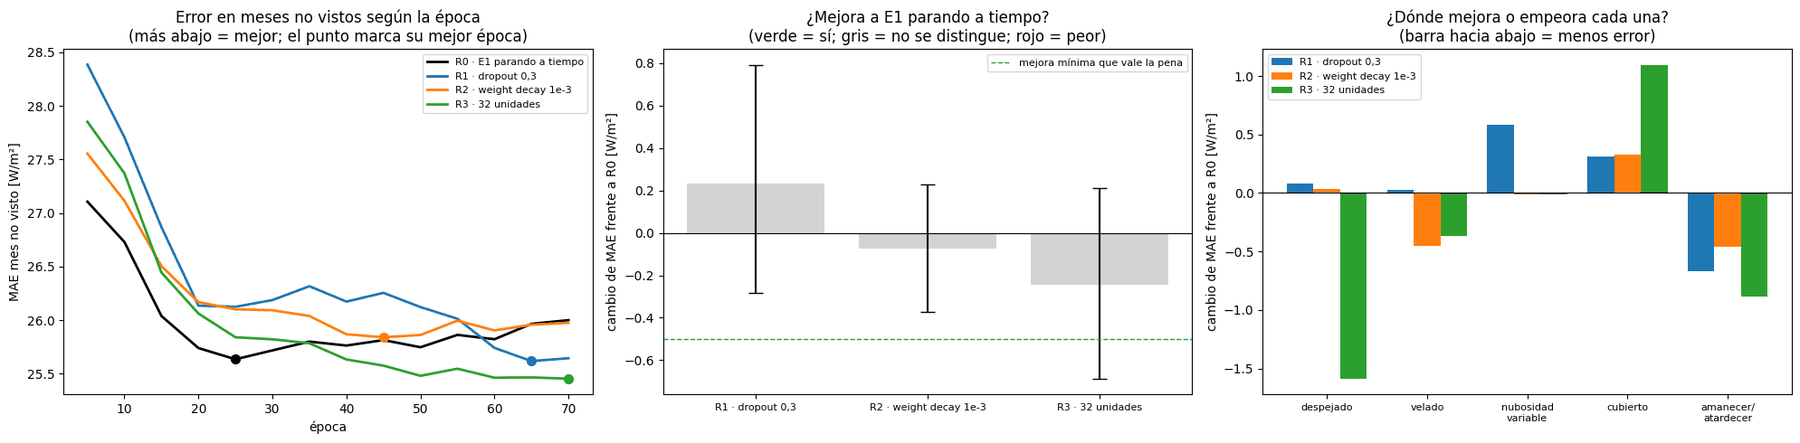


LECTURA
➜ R0 (E1 parando en la época 25): MAE 25.60 W/m² en meses no vistos.
➜ Ninguna regularización mejora de forma clara a 'E1 parando a tiempo'. La mejora de C5 es entrenar menos épocas (R0). PASO 2: repetir R0 con la semilla 123 para fijar bien su mejor época.
   (Una sola semilla: es una criba. El veredicto definitivo lo da la confirmación con 5 semillas en validación.)
Resultados en: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/diagnostico/faseC_regularizacion


In [ ]:
import os, time, random, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
try:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
except ImportError:
    pass

BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
RUTA_NPZ = (
    BASE_DIR
    / "resultados"
    / "ejecuciones"
    / "preparacion_bloque_difstats_20261006_180841"
    / "matrices_dif_elev_difstats.npz"
)
DIR_F1 = BASE_DIR / "resultados" / "diagnostico" / "fase1_intrahoraria"
DIR_B = BASE_DIR / "resultados" / "diagnostico" / "faseB_radiografia_E1"
DIR_C = BASE_DIR / "resultados" / "diagnostico" / "faseC_regularizacion"
DIR_P = DIR_C / "C5b_predicciones"
DIR_P.mkdir(parents=True, exist_ok=True)

# ---- Lo que se ejecuta (para el PASO 2 solo se cambian estas dos líneas) ----
SEMILLAS = [42]
A_EJECUTAR = ["R0", "R1", "R2", "R3"]
CONFIGS = {
    "R0": dict(dropout=0.0, wd=1e-5, hidden=64, nombre="R0 · E1 parando a tiempo"),
    "R1": dict(dropout=0.3, wd=1e-5, hidden=64, nombre="R1 · dropout 0,3"),
    "R2": dict(dropout=0.0, wd=1e-3, hidden=64, nombre="R2 · weight decay 1e-3"),
    "R3": dict(dropout=0.0, wd=1e-5, hidden=32, nombre="R3 · 32 unidades"),
}
MESES_CRIBA = ["2024-01", "2024-03", "2024-05", "2024-07"]
EPOCAS_MAX, CADA, BATCH, LR = 70, 5, 128, 1e-3
EFECTO_MINIMO = 0.5  # W/m²: por debajo, una mejora no compensa el cambio
N_BOOT = 2000
assert (
    DIR_B / "tabla_horaria_E1.pkl"
).exists(), "Falta la tabla de la radiografía (fase B, celda 1)"

# 1) Entradas de E1 (mismo código que C5a)
mat = np.load(RUTA_NPZ)
X_tr = mat["X_train_DIF_elev_DIFstats_raw"].astype(np.float32)
y_tr = mat["y_train_difstats"].astype(np.float32).reshape(-1)
fechas_tr = pd.DatetimeIndex(mat["fechas_train"])
intrahora = pd.read_csv(
    DIR_F1 / "variables_intrahorarias_horarias.csv", index_col=0, parse_dates=True
).asfreq("h")

def a_ventanas(tabla, fechas_obj, columnas, lookback=24):
    f = pd.DatetimeIndex(fechas_obj).to_numpy(dtype="datetime64[ns]")
    idx = f[:, None] - np.arange(lookback, 0, -1).astype("timedelta64[h]")[None, :]
    vals = tabla.reindex(pd.DatetimeIndex(idx.reshape(-1)))[columnas].to_numpy(dtype=np.float32)
    return vals.reshape(len(f), lookback, len(columnas))

CANALES_E1 = ["DIF_ult15", "DIF_pend30", "DIF_acel60", "DIF_saltos", "SWD_cv"]

def construir(fechas_obj, X_base, canales):
    Xn = a_ventanas(intrahora, fechas_obj, canales)
    for j, c in enumerate(canales):
        hueco = np.isnan(Xn[:, :, j])
        Xn[:, :, j][hueco] = X_base[:, :, 0][hueco] if c == "DIF_ult15" else 0.0
    return np.concatenate([X_base, Xn], axis=2).astype(np.float32)

Xtr_E1 = construir(fechas_tr, X_tr, CANALES_E1)
print(f"Entradas E1 train: {Xtr_E1.shape}  ← esperado (5149, 24, 9)")
H = pd.read_pickle(DIR_B / "tabla_horaria_E1.pkl")
TR = H[H["conjunto"] == "train"]
assert (
    len(TR) == len(y_tr) and (TR.index == fechas_tr).all()
), "La tabla de la radiografía no cuadra con el .npz"
SOL = (TR["regimen"] != "noche").to_numpy()
mes = fechas_tr.to_period("M").astype(str).to_numpy()
mes = np.where(mes == "2023-12", "2024-01", mes)

def pliegue(m):
    fuera = mes == m
    fin = fechas_tr[fuera].max()
    purga = (fechas_tr > fin) & (fechas_tr <= fin + pd.Timedelta("24h"))
    return ~fuera & ~purga, fuera


# 2) Modelo y entrenamiento (protocolo de E1; solo cambia lo que indica cada configuración)
import torch, torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler

class LSTMDIFStats(nn.Module):
    def __init__(self, n_features=4, hidden_size=64, dropout=0.0):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=n_features, hidden_size=hidden_size, num_layers=1, batch_first=True
        )
        self.drop = nn.Dropout(dropout) if dropout > 0 else nn.Identity()  # con 0, idéntico a E1
        self.head = nn.Sequential(nn.Linear(hidden_size, 32), nn.ReLU(), nn.Linear(32, 1))

    def forward(self, x):
        salida, _ = self.lstm(x)
        return self.head(self.drop(salida[:, -1, :])).squeeze(-1)

def entrenar(cfg, entrena, fuera, semilla):
    """Devuelve las predicciones del mes no visto cada 5 épocas (filas = épocas) y el MAE en lo visto."""
    Xtr, ytr, Xte = Xtr_E1[entrena], y_tr[entrena], Xtr_E1[fuera]
    sx_ = StandardScaler().fit(Xtr.reshape(-1, Xtr.shape[2]))
    sy_ = StandardScaler().fit(ytr.reshape(-1, 1))
    e = lambda X: torch.from_numpy(
        sx_.transform(X.reshape(-1, X.shape[2])).reshape(X.shape).astype(np.float32)
    )
    Xtr_t, Xte_t = e(Xtr), e(Xte)
    ytr_e = sy_.transform(ytr.reshape(-1, 1)).ravel().astype(np.float32)
    random.seed(semilla)
    np.random.seed(semilla)
    torch.manual_seed(semilla)
    torch.use_deterministic_algorithms(True)
    modelo = LSTMDIFStats(
        n_features=Xtr.shape[2], hidden_size=cfg["hidden"], dropout=cfg["dropout"]
    )
    gen = torch.Generator()
    gen.manual_seed(semilla)
    loader = DataLoader(
        TensorDataset(Xtr_t, torch.from_numpy(ytr_e)),
        batch_size=BATCH,
        shuffle=True,
        generator=gen,
        num_workers=0,
    )
    opt = torch.optim.Adam(modelo.parameters(), lr=LR, weight_decay=cfg["wd"])
    crit = nn.L1Loss()
    pred = lambda Xt: sy_.inverse_transform(modelo(Xt).numpy().reshape(-1, 1)).ravel()
    preds, visto = [], []
    for ep in range(1, EPOCAS_MAX + 1):
        modelo.train()
        for xb, yb in loader:
            opt.zero_grad(set_to_none=True)
            loss = crit(modelo(xb), yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(modelo.parameters(), max_norm=1.0)
            opt.step()
        if ep % CADA == 0:
            modelo.eval()
            with torch.no_grad():
                preds.append(pred(Xte_t))
                visto.append(np.abs(pred(Xtr_t) - ytr)[SOL[entrena]].mean())
    return np.array(preds, dtype=np.float32), np.array(visto, dtype=np.float32)

t_ini = time.time()
n_tot = len(A_EJECUTAR) * len(MESES_CRIBA) * len(SEMILLAS)
k = 0
for r in A_EJECUTAR:
    for s in SEMILLAS:
        for m in MESES_CRIBA:
            k += 1
            ruta = DIR_P / f"{r}_{m}_s{s}.npz"
            if ruta.exists():
                print(f"[{k}/{n_tot}] {r} · {m} · semilla {s}: ya hecho")
                continue
            t0 = time.time()
            entrena, fuera = pliegue(m)
            p, v = entrenar(CONFIGS[r], entrena, fuera, s)
            np.savez(ruta, pred=p, visto=v)
            print(
                f"[{k}/{n_tot}] {r} · {m} · semilla {s}: {time.time()-t0:.0f} s (total {(time.time()-t_ini)/60:.1f} min)"
            )

# 3) Juntar resultados (solo horas con sol de los 4 meses no vistos)
EPOCAS = np.arange(CADA, EPOCAS_MAX + 1, CADA)
fuera_tot = np.isin(mes, MESES_CRIBA)
idx_oof = np.where(fuera_tot)[0]  # orden: el de las fechas
sol_oof = SOL[idx_oof]
y_oof = y_tr[idx_oof]
info = TR.iloc[idx_oof][["regimen", "banda", "cielo", "persistencia"]].copy()
dias = TR.index[idx_oof].normalize()

def cargar(r, semillas):
    """Predicciones (épocas × horas no vistas) promediadas sobre las semillas indicadas; None si falta algo."""
    P = np.zeros((len(EPOCAS), len(idx_oof)), dtype=np.float64)
    V = np.zeros(len(EPOCAS))
    for s in semillas:
        for m in MESES_CRIBA:
            ruta = DIR_P / f"{r}_{m}_s{s}.npz"
            if not ruta.exists():
                return None, None
            d = np.load(ruta)
            P[:, mes[idx_oof] == m] += d["pred"] / len(semillas)
            V += d["visto"] / (len(semillas) * len(MESES_CRIBA))
    return P, V


# Semillas comunes a todas las configuraciones disponibles (comparación por parejas justa)
disp = {}
for r in CONFIGS:
    ss = [
        s
        for s in [42, 123, 2024, 7, 99]
        if all((DIR_P / f"{r}_{m}_s{s}.npz").exists() for m in MESES_CRIBA)
    ]
    if ss:
        disp[r] = ss
assert "R0" in disp, "Falta R0"
print("\nSemillas disponibles por configuración:", disp)

def evaluar(r, ss):
    """Curva, mejor época y predicciones en esa época, con las semillas ss."""
    P, V = cargar(r, ss)
    mae_ep = np.abs(P[:, sol_oof] - y_oof[sol_oof]).mean(axis=1)
    suav = pd.Series(mae_ep, index=EPOCAS).rolling(3, center=True, min_periods=1).mean()
    e_best = int(suav.idxmin())
    curva = pd.DataFrame(
        {"MAE mes no visto": mae_ep, "suavizado": suav.values, "MAE visto": V}, index=EPOCAS
    )
    return curva, e_best, P[list(EPOCAS).index(e_best)]


# Cada configuración se compara con R0 usando SOLO las semillas que tienen las dos (comparación por parejas justa)
curvas, mejor, P_mejor, P_R0 = {}, {}, {}, {}
for r, ss in disp.items():
    comunes = [s for s in ss if s in disp["R0"]]
    curvas[r], mejor[r], P_mejor[r] = evaluar(r, comunes)
    P_R0[r] = evaluar("R0", comunes)[2]

# 4) Comparación por parejas con R0 (bootstrap por días)
rng = np.random.default_rng(0)
u_dias, inv = np.unique(dias[sol_oof], return_inverse=True)
grupos_dia = [np.where(inv == i)[0] for i in range(len(u_dias))]
remuestras = [
    np.concatenate([grupos_dia[i] for i in rng.integers(0, len(grupos_dia), len(grupos_dia))])
    for _ in range(N_BOOT)
]

def ic_dif(a_r, a_0, mascara=None):
    """Cambio de MAE (config − R0) e IC95, con las mismas horas para las dos."""
    d = a_r - a_0
    if mascara is not None:
        d = np.where(mascara, d, np.nan)
    medias = [np.nanmean(d[s]) for s in remuestras]
    return np.nanmean(d), np.nanpercentile(medias, 2.5), np.nanpercentile(medias, 97.5)

err = {r: np.abs(P_mejor[r][sol_oof] - y_oof[sol_oof]) for r in disp}
err0 = {
    r: np.abs(P_R0[r][sol_oof] - y_oof[sol_oof]) for r in disp
}  # R0 con las mismas semillas que r
inf = info[sol_oof]
mae_pers = np.nanmean(np.abs(inf["persistencia"].to_numpy() - y_oof[sol_oof]))
filas, desglose = [], []
for r in disp:
    cambio, lo, hi = ic_dif(err[r], err0[r]) if r != "R0" else (0.0, 0.0, 0.0)
    peor = []
    if r != "R0":
        for col in ["regimen", "banda", "cielo"]:
            for g in inf[col].unique():
                c, l, h = ic_dif(err[r], err0[r], (inf[col] == g).to_numpy())
                desglose.append(
                    {
                        "config": r,
                        "grupo": f"{col}: {g}",
                        "horas": int((inf[col] == g).sum()),
                        "cambio": c,
                        "IC95 bajo": l,
                        "IC95 alto": h,
                    }
                )
                if col in ["regimen", "banda"] and l > 0:
                    peor.append(g)
    if r == "R0":
        veredicto = "referencia"
    elif peor:
        veredicto = "DESCARTADA (empeora en " + ", ".join(peor) + ")"
    elif hi < 0 and -cambio >= EFECTO_MINIMO:
        veredicto = "MEJORA REAL"
    elif hi < 0:
        veredicto = "mejora real pero pequeña (< 0,5)"
    elif lo > 0:
        veredicto = "EMPEORA"
    else:
        veredicto = "no se distingue de R0"
    filas.append(
        {
            "configuración": CONFIGS[r]["nombre"],
            "semillas": len(disp[r]),
            "mejor época": mejor[r],
            "MAE mes no visto": err[r].mean(),
            "ventaja sobre persistencia (%)": 100 * (1 - err[r].mean() / mae_pers),
            "MAE nubosidad variable": err[r][(inf["cielo"] == "nubes rotas").to_numpy()].mean(),
            "cambio vs R0": cambio,
            "IC95": f"[{lo:+.2f}, {hi:+.2f}]",
            "veredicto": veredicto,
            "_lo": lo,
            "_hi": hi,
            "_r": r,
        }
    )
T = pd.DataFrame(filas).set_index("configuración")
D = pd.DataFrame(desglose)
print(
    "\n"
    + "=" * 100
    + "\nC5b · ¿QUÉ FORMA DE FRENAR LA MEMORIZACIÓN FUNCIONA MEJOR? (meses no vistos de train, horas con sol)\n"
    + "=" * 100
)
print(
    "Cambio vs R0 negativo = menos error que E1 parando a tiempo. 'MEJORA REAL' exige IC95 sin el 0 y al menos 0,5 W/m²."
)
display(T.drop(columns=["_lo", "_hi", "_r"]).round(2))

# 5) Gráficas
colores = {"R0": "black", "R1": "tab:blue", "R2": "tab:orange", "R3": "tab:green"}
fig, axs = plt.subplots(1, 3, figsize=(20, 5))
for r, c in curvas.items():
    axs[0].plot(c.index, c["suavizado"], color=colores[r], lw=2, label=CONFIGS[r]["nombre"])
    axs[0].scatter([mejor[r]], [c.loc[mejor[r], "suavizado"]], color=colores[r], s=50, zorder=3)
axs[0].set_xlabel("época")
axs[0].set_ylabel("MAE mes no visto [W/m²]")
axs[0].legend(fontsize=8)
axs[0].set_title(
    "Error en meses no vistos según la época\n(más abajo = mejor; el punto marca su mejor época)"
)
otras = T[T["_r"] != "R0"]
x = np.arange(len(otras))
col_b = [
    (
        "tab:green"
        if v.startswith("MEJORA")
        else ("tab:red" if v.startswith(("EMPEORA", "DESCARTADA")) else "lightgray")
    )
    for v in otras["veredicto"]
]
axs[1].bar(
    x,
    otras["cambio vs R0"],
    color=col_b,
    yerr=[otras["cambio vs R0"] - otras["_lo"], otras["_hi"] - otras["cambio vs R0"]],
    capsize=6,
)
axs[1].axhline(0, color="k", lw=0.8)
axs[1].axhline(
    -EFECTO_MINIMO, color="tab:green", ls="--", lw=1, label="mejora mínima que vale la pena"
)
axs[1].set_xticks(x)
axs[1].set_xticklabels(otras.index, fontsize=8)
axs[1].set_ylabel("cambio de MAE frente a R0 [W/m²]")
axs[1].legend(fontsize=8)
axs[1].set_title(
    "¿Mejora a E1 parando a tiempo?\n(verde = sí; gris = no se distingue; rojo = peor)"
)
cielos = ["despejado", "velado", "nubes rotas", "cubierto", "amanecer/atardecer"]
w = 0.8 / max(len(otras), 1)
for j, r in enumerate(otras["_r"]):
    vals = [D[(D["config"] == r) & (D["grupo"] == f"cielo: {c}")]["cambio"].mean() for c in cielos]
    axs[2].bar(
        np.arange(len(cielos)) + (j - (len(otras) - 1) / 2) * w,
        vals,
        w,
        color=colores[r],
        label=CONFIGS[r]["nombre"],
    )
axs[2].axhline(0, color="k", lw=0.8)
axs[2].set_xticks(range(len(cielos)))
axs[2].set_xticklabels(
    ["despejado", "velado", "nubosidad\nvariable", "cubierto", "amanecer/\natardecer"], fontsize=8
)
axs[2].set_ylabel("cambio de MAE frente a R0 [W/m²]")
axs[2].legend(fontsize=8)
axs[2].set_title("¿Dónde mejora o empeora cada una?\n(barra hacia abajo = menos error)")
plt.tight_layout()
plt.savefig(DIR_C / "C5b_criba.png", dpi=120)
plt.show()

# 6) Lectura
print("\n" + "=" * 100 + "\nLECTURA\n" + "=" * 100)
r0 = T[T["_r"] == "R0"].iloc[0]
print(
    f"➜ R0 (E1 parando en la época {int(r0['mejor época'])}): MAE {r0['MAE mes no visto']:.2f} W/m² en meses no vistos."
)
ganadoras = T[T["veredicto"] == "MEJORA REAL"].sort_values("cambio vs R0")
if len(ganadoras):
    g = ganadoras.iloc[0]
    sig = g["_r"]
    lect = (
        f"Gana '{g.name}': {-g['cambio vs R0']:.2f} W/m² menos que R0 (IC95 {g['IC95']}, {int(g['semillas'])} semilla/s), "
        f"mejor época {int(g['mejor época'])}. "
    )
    lect += (
        "Confirmado con 2 semillas → siguiente: confirmación final con 5 semillas en validación."
        if g["semillas"] >= 2
        else f"PASO 2: repetir R0 y {sig} con la semilla 123."
    )
else:
    sig = None
    lect = (
        "Ninguna regularización mejora de forma clara a 'E1 parando a tiempo'. La mejora de C5 es entrenar menos épocas (R0). "
        + (
            "Siguiente: confirmación final con 5 semillas en validación."
            if len(disp["R0"]) >= 2
            else "PASO 2: repetir R0 con la semilla 123 para fijar bien su mejor época."
        )
    )
print("➜ " + lect)
if len(disp["R0"]) == 1:
    print(
        "   (Una sola semilla: es una criba. El veredicto definitivo lo da la confirmación con 5 semillas en validación.)"
    )
else:
    print(
        "   (Las configuraciones con 1 semilla se comparan con R0 usando solo esa misma semilla.)"
    )
T.drop(columns=["_lo", "_hi"]).to_csv(DIR_C / "C5b_resumen.csv")
D.to_csv(DIR_C / "C5b_desglose.csv", index=False)
pd.concat(curvas, names=["config", "epoca"]).to_csv(DIR_C / "C5b_curvas.csv")
with open(DIR_C / "C5b_lectura.txt", "w") as f:
    f.write(f"semillas {disp}\n{lect}\nsiguiente: {sig}\n")
print("Resultados en:", DIR_C)

> *Segunda ejecución de la misma criba: añade la semilla 123 a la configuración de referencia y reutiliza lo ya entrenado. Sus tablas reúnen ambas ejecuciones.*

Entradas E1 train: (5149, 24, 9)  ← esperado (5149, 24, 9)
[1/4] R0 · 2024-01 · semilla 123: 72 s (total 1.2 min)
[2/4] R0 · 2024-03 · semilla 123: 73 s (total 2.4 min)
[3/4] R0 · 2024-05 · semilla 123: 74 s (total 3.7 min)
[4/4] R0 · 2024-07 · semilla 123: 73 s (total 4.9 min)

Semillas disponibles por configuración: {'R0': [42, 123], 'R1': [42], 'R2': [42], 'R3': [42]}

C5b · ¿QUÉ FORMA DE FRENAR LA MEMORIZACIÓN FUNCIONA MEJOR? (meses no vistos de train, horas con sol)
Cambio vs R0 negativo = menos error que E1 parando a tiempo. 'MEJORA REAL' exige IC95 sin el 0 y al menos 0,5 W/m².


,semillas,mejor época,MAE mes no visto,ventaja sobre persistencia (%),MAE nubosidad variable,cambio vs R0,IC95,veredicto
configuración,,,,,,,,
R0 · E1 parando a tiempo,2,30,25.39,42.66,36.48,0.00,"[+0.00, +0.00]",referencia
"R1 · dropout 0,3",1,65,25.83,41.67,37.44,0.23,"[-0.28, +0.79]",no se distingue de R0
R2 · weight decay 1e-3,1,45,25.52,42.36,36.84,-0.07,"[-0.37, +0.23]",no se distingue de R0
R3 · 32 unidades,1,70,25.35,42.75,36.84,-0.25,"[-0.69, +0.21]",no se distingue de R0


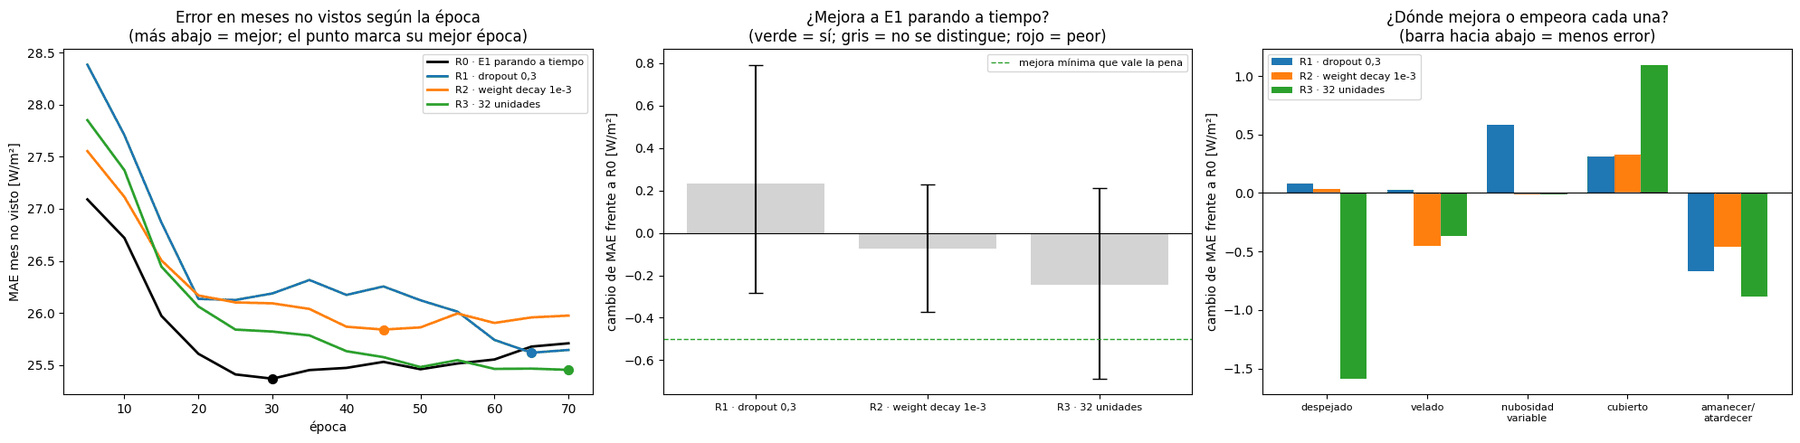


LECTURA
➜ R0 (E1 parando en la época 30): MAE 25.39 W/m² en meses no vistos.
➜ Ninguna regularización mejora de forma clara a 'E1 parando a tiempo'. La mejora de C5 es entrenar menos épocas (R0). Siguiente: confirmación final con 5 semillas en validación.
   (Las configuraciones con 1 semilla se comparan con R0 usando solo esa misma semilla.)
Resultados en: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/diagnostico/faseC_regularizacion


In [ ]:
import os, time, random, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
try:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
except ImportError:
    pass

BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
RUTA_NPZ = (
    BASE_DIR
    / "resultados"
    / "ejecuciones"
    / "preparacion_bloque_difstats_20261006_180841"
    / "matrices_dif_elev_difstats.npz"
)
DIR_F1 = BASE_DIR / "resultados" / "diagnostico" / "fase1_intrahoraria"
DIR_B = BASE_DIR / "resultados" / "diagnostico" / "faseB_radiografia_E1"
DIR_C = BASE_DIR / "resultados" / "diagnostico" / "faseC_regularizacion"
DIR_P = DIR_C / "C5b_predicciones"
DIR_P.mkdir(parents=True, exist_ok=True)

# ---- Lo que se ejecuta (para el PASO 2 solo se cambian estas dos líneas) ----
SEMILLAS = [123]
A_EJECUTAR = ["R0"]
CONFIGS = {
    "R0": dict(dropout=0.0, wd=1e-5, hidden=64, nombre="R0 · E1 parando a tiempo"),
    "R1": dict(dropout=0.3, wd=1e-5, hidden=64, nombre="R1 · dropout 0,3"),
    "R2": dict(dropout=0.0, wd=1e-3, hidden=64, nombre="R2 · weight decay 1e-3"),
    "R3": dict(dropout=0.0, wd=1e-5, hidden=32, nombre="R3 · 32 unidades"),
}
MESES_CRIBA = ["2024-01", "2024-03", "2024-05", "2024-07"]
EPOCAS_MAX, CADA, BATCH, LR = 70, 5, 128, 1e-3
EFECTO_MINIMO = 0.5  # W/m²: por debajo, una mejora no compensa el cambio
N_BOOT = 2000
assert (
    DIR_B / "tabla_horaria_E1.pkl"
).exists(), "Falta la tabla de la radiografía (fase B, celda 1)"

# 1) Entradas de E1 (mismo código que C5a)
mat = np.load(RUTA_NPZ)
X_tr = mat["X_train_DIF_elev_DIFstats_raw"].astype(np.float32)
y_tr = mat["y_train_difstats"].astype(np.float32).reshape(-1)
fechas_tr = pd.DatetimeIndex(mat["fechas_train"])
intrahora = pd.read_csv(
    DIR_F1 / "variables_intrahorarias_horarias.csv", index_col=0, parse_dates=True
).asfreq("h")

def a_ventanas(tabla, fechas_obj, columnas, lookback=24):
    f = pd.DatetimeIndex(fechas_obj).to_numpy(dtype="datetime64[ns]")
    idx = f[:, None] - np.arange(lookback, 0, -1).astype("timedelta64[h]")[None, :]
    vals = tabla.reindex(pd.DatetimeIndex(idx.reshape(-1)))[columnas].to_numpy(dtype=np.float32)
    return vals.reshape(len(f), lookback, len(columnas))

CANALES_E1 = ["DIF_ult15", "DIF_pend30", "DIF_acel60", "DIF_saltos", "SWD_cv"]

def construir(fechas_obj, X_base, canales):
    Xn = a_ventanas(intrahora, fechas_obj, canales)
    for j, c in enumerate(canales):
        hueco = np.isnan(Xn[:, :, j])
        Xn[:, :, j][hueco] = X_base[:, :, 0][hueco] if c == "DIF_ult15" else 0.0
    return np.concatenate([X_base, Xn], axis=2).astype(np.float32)

Xtr_E1 = construir(fechas_tr, X_tr, CANALES_E1)
print(f"Entradas E1 train: {Xtr_E1.shape}  ← esperado (5149, 24, 9)")
H = pd.read_pickle(DIR_B / "tabla_horaria_E1.pkl")
TR = H[H["conjunto"] == "train"]
assert (
    len(TR) == len(y_tr) and (TR.index == fechas_tr).all()
), "La tabla de la radiografía no cuadra con el .npz"
SOL = (TR["regimen"] != "noche").to_numpy()
mes = fechas_tr.to_period("M").astype(str).to_numpy()
mes = np.where(mes == "2023-12", "2024-01", mes)

def pliegue(m):
    fuera = mes == m
    fin = fechas_tr[fuera].max()
    purga = (fechas_tr > fin) & (fechas_tr <= fin + pd.Timedelta("24h"))
    return ~fuera & ~purga, fuera


# 2) Modelo y entrenamiento (protocolo de E1; solo cambia lo que indica cada configuración)
import torch, torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler

class LSTMDIFStats(nn.Module):
    def __init__(self, n_features=4, hidden_size=64, dropout=0.0):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=n_features, hidden_size=hidden_size, num_layers=1, batch_first=True
        )
        self.drop = nn.Dropout(dropout) if dropout > 0 else nn.Identity()  # con 0, idéntico a E1
        self.head = nn.Sequential(nn.Linear(hidden_size, 32), nn.ReLU(), nn.Linear(32, 1))

    def forward(self, x):
        salida, _ = self.lstm(x)
        return self.head(self.drop(salida[:, -1, :])).squeeze(-1)

def entrenar(cfg, entrena, fuera, semilla):
    """Devuelve las predicciones del mes no visto cada 5 épocas (filas = épocas) y el MAE en lo visto."""
    Xtr, ytr, Xte = Xtr_E1[entrena], y_tr[entrena], Xtr_E1[fuera]
    sx_ = StandardScaler().fit(Xtr.reshape(-1, Xtr.shape[2]))
    sy_ = StandardScaler().fit(ytr.reshape(-1, 1))
    e = lambda X: torch.from_numpy(
        sx_.transform(X.reshape(-1, X.shape[2])).reshape(X.shape).astype(np.float32)
    )
    Xtr_t, Xte_t = e(Xtr), e(Xte)
    ytr_e = sy_.transform(ytr.reshape(-1, 1)).ravel().astype(np.float32)
    random.seed(semilla)
    np.random.seed(semilla)
    torch.manual_seed(semilla)
    torch.use_deterministic_algorithms(True)
    modelo = LSTMDIFStats(
        n_features=Xtr.shape[2], hidden_size=cfg["hidden"], dropout=cfg["dropout"]
    )
    gen = torch.Generator()
    gen.manual_seed(semilla)
    loader = DataLoader(
        TensorDataset(Xtr_t, torch.from_numpy(ytr_e)),
        batch_size=BATCH,
        shuffle=True,
        generator=gen,
        num_workers=0,
    )
    opt = torch.optim.Adam(modelo.parameters(), lr=LR, weight_decay=cfg["wd"])
    crit = nn.L1Loss()
    pred = lambda Xt: sy_.inverse_transform(modelo(Xt).numpy().reshape(-1, 1)).ravel()
    preds, visto = [], []
    for ep in range(1, EPOCAS_MAX + 1):
        modelo.train()
        for xb, yb in loader:
            opt.zero_grad(set_to_none=True)
            loss = crit(modelo(xb), yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(modelo.parameters(), max_norm=1.0)
            opt.step()
        if ep % CADA == 0:
            modelo.eval()
            with torch.no_grad():
                preds.append(pred(Xte_t))
                visto.append(np.abs(pred(Xtr_t) - ytr)[SOL[entrena]].mean())
    return np.array(preds, dtype=np.float32), np.array(visto, dtype=np.float32)

t_ini = time.time()
n_tot = len(A_EJECUTAR) * len(MESES_CRIBA) * len(SEMILLAS)
k = 0
for r in A_EJECUTAR:
    for s in SEMILLAS:
        for m in MESES_CRIBA:
            k += 1
            ruta = DIR_P / f"{r}_{m}_s{s}.npz"
            if ruta.exists():
                print(f"[{k}/{n_tot}] {r} · {m} · semilla {s}: ya hecho")
                continue
            t0 = time.time()
            entrena, fuera = pliegue(m)
            p, v = entrenar(CONFIGS[r], entrena, fuera, s)
            np.savez(ruta, pred=p, visto=v)
            print(
                f"[{k}/{n_tot}] {r} · {m} · semilla {s}: {time.time()-t0:.0f} s (total {(time.time()-t_ini)/60:.1f} min)"
            )

# 3) Juntar resultados (solo horas con sol de los 4 meses no vistos)
EPOCAS = np.arange(CADA, EPOCAS_MAX + 1, CADA)
fuera_tot = np.isin(mes, MESES_CRIBA)
idx_oof = np.where(fuera_tot)[0]  # orden: el de las fechas
sol_oof = SOL[idx_oof]
y_oof = y_tr[idx_oof]
info = TR.iloc[idx_oof][["regimen", "banda", "cielo", "persistencia"]].copy()
dias = TR.index[idx_oof].normalize()

def cargar(r, semillas):
    """Predicciones (épocas × horas no vistas) promediadas sobre las semillas indicadas; None si falta algo."""
    P = np.zeros((len(EPOCAS), len(idx_oof)), dtype=np.float64)
    V = np.zeros(len(EPOCAS))
    for s in semillas:
        for m in MESES_CRIBA:
            ruta = DIR_P / f"{r}_{m}_s{s}.npz"
            if not ruta.exists():
                return None, None
            d = np.load(ruta)
            P[:, mes[idx_oof] == m] += d["pred"] / len(semillas)
            V += d["visto"] / (len(semillas) * len(MESES_CRIBA))
    return P, V


# Semillas comunes a todas las configuraciones disponibles (comparación por parejas justa)
disp = {}
for r in CONFIGS:
    ss = [
        s
        for s in [42, 123, 2024, 7, 99]
        if all((DIR_P / f"{r}_{m}_s{s}.npz").exists() for m in MESES_CRIBA)
    ]
    if ss:
        disp[r] = ss
assert "R0" in disp, "Falta R0"
print("\nSemillas disponibles por configuración:", disp)

def evaluar(r, ss):
    """Curva, mejor época y predicciones en esa época, con las semillas ss."""
    P, V = cargar(r, ss)
    mae_ep = np.abs(P[:, sol_oof] - y_oof[sol_oof]).mean(axis=1)
    suav = pd.Series(mae_ep, index=EPOCAS).rolling(3, center=True, min_periods=1).mean()
    e_best = int(suav.idxmin())
    curva = pd.DataFrame(
        {"MAE mes no visto": mae_ep, "suavizado": suav.values, "MAE visto": V}, index=EPOCAS
    )
    return curva, e_best, P[list(EPOCAS).index(e_best)]


# Cada configuración se compara con R0 usando SOLO las semillas que tienen las dos (comparación por parejas justa)
curvas, mejor, P_mejor, P_R0 = {}, {}, {}, {}
for r, ss in disp.items():
    comunes = [s for s in ss if s in disp["R0"]]
    curvas[r], mejor[r], P_mejor[r] = evaluar(r, comunes)
    P_R0[r] = evaluar("R0", comunes)[2]

# 4) Comparación por parejas con R0 (bootstrap por días)
rng = np.random.default_rng(0)
u_dias, inv = np.unique(dias[sol_oof], return_inverse=True)
grupos_dia = [np.where(inv == i)[0] for i in range(len(u_dias))]
remuestras = [
    np.concatenate([grupos_dia[i] for i in rng.integers(0, len(grupos_dia), len(grupos_dia))])
    for _ in range(N_BOOT)
]

def ic_dif(a_r, a_0, mascara=None):
    """Cambio de MAE (config − R0) e IC95, con las mismas horas para las dos."""
    d = a_r - a_0
    if mascara is not None:
        d = np.where(mascara, d, np.nan)
    medias = [np.nanmean(d[s]) for s in remuestras]
    return np.nanmean(d), np.nanpercentile(medias, 2.5), np.nanpercentile(medias, 97.5)

err = {r: np.abs(P_mejor[r][sol_oof] - y_oof[sol_oof]) for r in disp}
err0 = {
    r: np.abs(P_R0[r][sol_oof] - y_oof[sol_oof]) for r in disp
}  # R0 con las mismas semillas que r
inf = info[sol_oof]
mae_pers = np.nanmean(np.abs(inf["persistencia"].to_numpy() - y_oof[sol_oof]))
filas, desglose = [], []
for r in disp:
    cambio, lo, hi = ic_dif(err[r], err0[r]) if r != "R0" else (0.0, 0.0, 0.0)
    peor = []
    if r != "R0":
        for col in ["regimen", "banda", "cielo"]:
            for g in inf[col].unique():
                c, l, h = ic_dif(err[r], err0[r], (inf[col] == g).to_numpy())
                desglose.append(
                    {
                        "config": r,
                        "grupo": f"{col}: {g}",
                        "horas": int((inf[col] == g).sum()),
                        "cambio": c,
                        "IC95 bajo": l,
                        "IC95 alto": h,
                    }
                )
                if col in ["regimen", "banda"] and l > 0:
                    peor.append(g)
    if r == "R0":
        veredicto = "referencia"
    elif peor:
        veredicto = "DESCARTADA (empeora en " + ", ".join(peor) + ")"
    elif hi < 0 and -cambio >= EFECTO_MINIMO:
        veredicto = "MEJORA REAL"
    elif hi < 0:
        veredicto = "mejora real pero pequeña (< 0,5)"
    elif lo > 0:
        veredicto = "EMPEORA"
    else:
        veredicto = "no se distingue de R0"
    filas.append(
        {
            "configuración": CONFIGS[r]["nombre"],
            "semillas": len(disp[r]),
            "mejor época": mejor[r],
            "MAE mes no visto": err[r].mean(),
            "ventaja sobre persistencia (%)": 100 * (1 - err[r].mean() / mae_pers),
            "MAE nubosidad variable": err[r][(inf["cielo"] == "nubes rotas").to_numpy()].mean(),
            "cambio vs R0": cambio,
            "IC95": f"[{lo:+.2f}, {hi:+.2f}]",
            "veredicto": veredicto,
            "_lo": lo,
            "_hi": hi,
            "_r": r,
        }
    )
T = pd.DataFrame(filas).set_index("configuración")
D = pd.DataFrame(desglose)
print(
    "\n"
    + "=" * 100
    + "\nC5b · ¿QUÉ FORMA DE FRENAR LA MEMORIZACIÓN FUNCIONA MEJOR? (meses no vistos de train, horas con sol)\n"
    + "=" * 100
)
print(
    "Cambio vs R0 negativo = menos error que E1 parando a tiempo. 'MEJORA REAL' exige IC95 sin el 0 y al menos 0,5 W/m²."
)
display(T.drop(columns=["_lo", "_hi", "_r"]).round(2))

# 5) Gráficas
colores = {"R0": "black", "R1": "tab:blue", "R2": "tab:orange", "R3": "tab:green"}
fig, axs = plt.subplots(1, 3, figsize=(20, 5))
for r, c in curvas.items():
    axs[0].plot(c.index, c["suavizado"], color=colores[r], lw=2, label=CONFIGS[r]["nombre"])
    axs[0].scatter([mejor[r]], [c.loc[mejor[r], "suavizado"]], color=colores[r], s=50, zorder=3)
axs[0].set_xlabel("época")
axs[0].set_ylabel("MAE mes no visto [W/m²]")
axs[0].legend(fontsize=8)
axs[0].set_title(
    "Error en meses no vistos según la época\n(más abajo = mejor; el punto marca su mejor época)"
)
otras = T[T["_r"] != "R0"]
x = np.arange(len(otras))
col_b = [
    (
        "tab:green"
        if v.startswith("MEJORA")
        else ("tab:red" if v.startswith(("EMPEORA", "DESCARTADA")) else "lightgray")
    )
    for v in otras["veredicto"]
]
axs[1].bar(
    x,
    otras["cambio vs R0"],
    color=col_b,
    yerr=[otras["cambio vs R0"] - otras["_lo"], otras["_hi"] - otras["cambio vs R0"]],
    capsize=6,
)
axs[1].axhline(0, color="k", lw=0.8)
axs[1].axhline(
    -EFECTO_MINIMO, color="tab:green", ls="--", lw=1, label="mejora mínima que vale la pena"
)
axs[1].set_xticks(x)
axs[1].set_xticklabels(otras.index, fontsize=8)
axs[1].set_ylabel("cambio de MAE frente a R0 [W/m²]")
axs[1].legend(fontsize=8)
axs[1].set_title(
    "¿Mejora a E1 parando a tiempo?\n(verde = sí; gris = no se distingue; rojo = peor)"
)
cielos = ["despejado", "velado", "nubes rotas", "cubierto", "amanecer/atardecer"]
w = 0.8 / max(len(otras), 1)
for j, r in enumerate(otras["_r"]):
    vals = [D[(D["config"] == r) & (D["grupo"] == f"cielo: {c}")]["cambio"].mean() for c in cielos]
    axs[2].bar(
        np.arange(len(cielos)) + (j - (len(otras) - 1) / 2) * w,
        vals,
        w,
        color=colores[r],
        label=CONFIGS[r]["nombre"],
    )
axs[2].axhline(0, color="k", lw=0.8)
axs[2].set_xticks(range(len(cielos)))
axs[2].set_xticklabels(
    ["despejado", "velado", "nubosidad\nvariable", "cubierto", "amanecer/\natardecer"], fontsize=8
)
axs[2].set_ylabel("cambio de MAE frente a R0 [W/m²]")
axs[2].legend(fontsize=8)
axs[2].set_title("¿Dónde mejora o empeora cada una?\n(barra hacia abajo = menos error)")
plt.tight_layout()
plt.savefig(DIR_C / "C5b_criba.png", dpi=120)
plt.show()

# 6) Lectura
print("\n" + "=" * 100 + "\nLECTURA\n" + "=" * 100)
r0 = T[T["_r"] == "R0"].iloc[0]
print(
    f"➜ R0 (E1 parando en la época {int(r0['mejor época'])}): MAE {r0['MAE mes no visto']:.2f} W/m² en meses no vistos."
)
ganadoras = T[T["veredicto"] == "MEJORA REAL"].sort_values("cambio vs R0")
if len(ganadoras):
    g = ganadoras.iloc[0]
    sig = g["_r"]
    lect = (
        f"Gana '{g.name}': {-g['cambio vs R0']:.2f} W/m² menos que R0 (IC95 {g['IC95']}, {int(g['semillas'])} semilla/s), "
        f"mejor época {int(g['mejor época'])}. "
    )
    lect += (
        "Confirmado con 2 semillas → siguiente: confirmación final con 5 semillas en validación."
        if g["semillas"] >= 2
        else f"PASO 2: repetir R0 y {sig} con la semilla 123."
    )
else:
    sig = None
    lect = (
        "Ninguna regularización mejora de forma clara a 'E1 parando a tiempo'. La mejora de C5 es entrenar menos épocas (R0). "
        + (
            "Siguiente: confirmación final con 5 semillas en validación."
            if len(disp["R0"]) >= 2
            else "PASO 2: repetir R0 con la semilla 123 para fijar bien su mejor época."
        )
    )
print("➜ " + lect)
if len(disp["R0"]) == 1:
    print(
        "   (Una sola semilla: es una criba. El veredicto definitivo lo da la confirmación con 5 semillas en validación.)"
    )
else:
    print(
        "   (Las configuraciones con 1 semilla se comparan con R0 usando solo esa misma semilla.)"
    )
T.drop(columns=["_lo", "_hi"]).to_csv(DIR_C / "C5b_resumen.csv")
D.to_csv(DIR_C / "C5b_desglose.csv", index=False)
pd.concat(curvas, names=["config", "epoca"]).to_csv(DIR_C / "C5b_curvas.csv")
with open(DIR_C / "C5b_lectura.txt", "w") as f:
    f.write(f"semillas {disp}\n{lect}\nsiguiente: {sig}\n")
print("Resultados en:", DIR_C)

**Resultados.** Ninguna regularización se distingue de R0 en los meses no vistos: el cambio de MAE es de +0,23 W/m² con R1 (IC95 [−0,28; +0,79]), −0,07 W/m² con R2 (IC95 [−0,37; +0,23]) y −0,25 W/m² con R3 (IC95 [−0,69; +0,21]). Con la semilla 42, la mejor época de R0 es la 25 (25,60 W/m²); con las semillas 42 y 123, la 30 (25,39 W/m²), que se fija como época de parada antes de mirar la validación.

### 6.3 Confirmación de la parada en la época 30

Se contrasta en validación, una sola vez, E1 con 105 épocas frente a E1 detenida en la época 30 fijada en la criba (E1-30), con las cinco semillas y todo el entrenamiento (C5c); cada semilla se entrena una vez y se guardan sus predicciones en las épocas 30 y 105. La regla acordada exige que el IC95 por días de la diferencia de MAE en horas con sol quede entero por debajo de 0 y que no haya empeoramiento significativo en las horas con sol ni en la banda central.

> *El veredicto automático («NO SE ACEPTA») se debe a que el código incluía la transición en la condición de no empeoramiento. La regla acordada se limitaba a las horas con sol y a la banda central; con ella, E1-30 se acepta y pasa a ser el modelo de referencia. El empeoramiento de la transición se declara como desviación (Tabla 13 de la memoria).*

Entradas E1: train (5149, 24, 9) | validación (1464, 24, 9)   ← esperado (5149, 24, 9) y (1464, 24, 9)
Semilla 42: 139 s (total 2.3 min)
Semilla 123: 132 s (total 4.5 min)
Semilla 2024: 136 s (total 6.8 min)
Semilla 7: 122 s (total 8.8 min)
Semilla 99: 121 s (total 10.8 min)

Comprobación de reproducción (E1 de 105 épocas recién entrenado vs E1 guardado en Drive):
   semilla 42: diferencia media 0.00 W/m², máxima 0.00
   semilla 123: diferencia media 0.00 W/m², máxima 0.00
   semilla 2024: diferencia media 0.00 W/m², máxima 0.00
   semilla 7: diferencia media 0.00 W/m², máxima 0.00
   semilla 99: diferencia media 0.00 W/m², máxima 0.00
   (≈0 = idéntico. Si no es 0 —p. ej. E1 se entrenó en GPU— no pasa nada: se comparan dos versiones
    entrenadas aquí con el mismo código, y abajo se muestra también el MAE del E1 guardado.)

C5c · ¿PARAR EN LA ÉPOCA 30 MEJORA A E1 EN VALIDACIÓN? (ago–sep, horas con sol, 5 semillas)


,MAE [W/m²],ventaja sobre persistencia (%)
E1 · 105 épocas (entrenado aquí),24.67,45.21
E1 · 30 épocas (parando a tiempo),23.25,48.36
E1 guardado (referencia),24.67,45.21


Cambio al parar en la época 30: -1.42 W/m² (-5.7 %), IC95 [-2.38, -0.43]

Por semilla (cada modelo por separado): mejora en 5 de 5


,105 épocas,30 épocas,cambio
s42,25.96,24.36,-1.61
s123,25.75,24.28,-1.46
s2024,25.46,24.58,-0.88
s7,25.26,24.45,-0.81
s99,26.42,23.54,-2.88



Desglose (cambio negativo = parar a tiempo tiene menos error):


,horas,MAE 105,MAE 30,cambio,IC95,lectura
grupo,,,,,,
régimen: transicion,119,2.34,2.67,0.33,"[+0.00, +0.64]",EMPEORA
régimen: completamente_diurno,765,28.15,26.46,-1.69,"[-2.80, -0.57]",mejora
banda: hombros ≤20°,339,9.92,9.82,-0.10,"[-0.71, +0.52]",igual
banda: intermedia 20–40°,340,30.27,28.75,-1.52,"[-3.22, +0.16]",igual
banda: central >40°,205,39.80,36.36,-3.44,"[-6.36, -0.67]",mejora
cielo: amanecer/atardecer,119,2.34,2.67,0.33,"[+0.00, +0.64]",EMPEORA
cielo: nubes rotas,438,33.93,32.20,-1.74,"[-3.29, -0.15]",mejora
cielo: velado,89,22.17,20.12,-2.05,"[-4.59, +0.15]",igual
cielo: cubierto,53,38.01,31.50,-6.50,"[-13.25, -0.32]",mejora


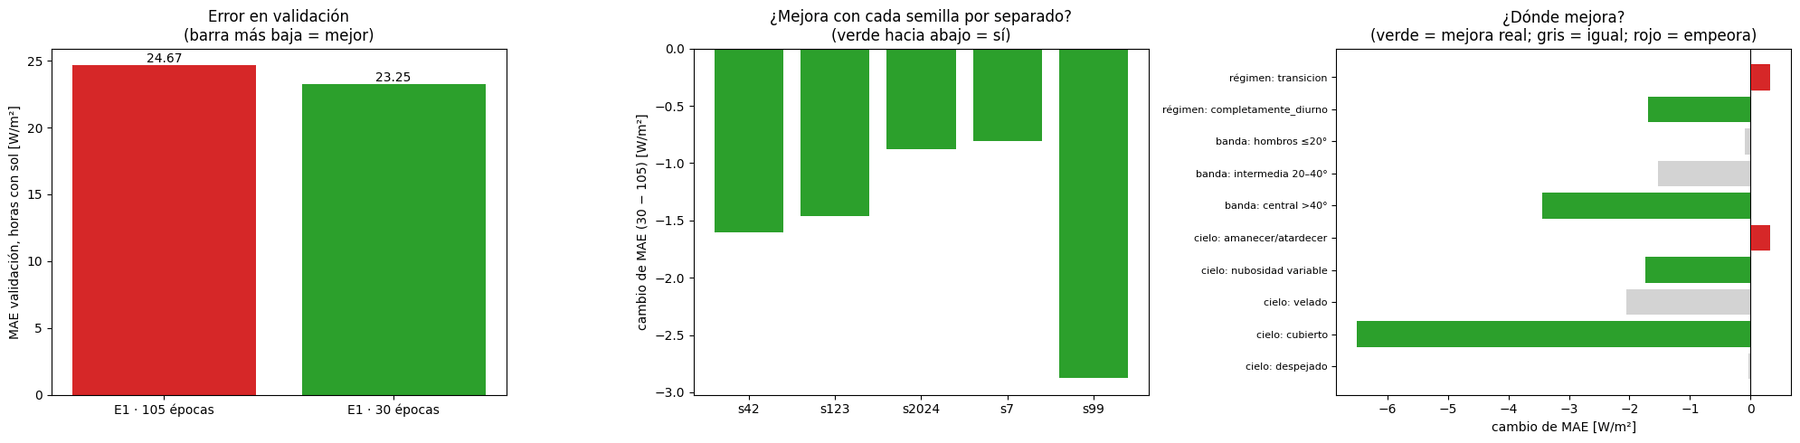


VEREDICTO
➜ NO SE ACEPTA: aunque el cambio global es -1.42 W/m², parar en la época 30 empeora de forma significativa en: régimen transicion.
Resultados en: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/diagnostico/faseC_regularizacion


In [ ]:
import os, time, random, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
try:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
except ImportError:
    pass

BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
RUTA_NPZ = (
    BASE_DIR
    / "resultados"
    / "ejecuciones"
    / "preparacion_bloque_difstats_20261006_180841"
    / "matrices_dif_elev_difstats.npz"
)
DIR_F1 = BASE_DIR / "resultados" / "diagnostico" / "fase1_intrahoraria"
DIR_B = BASE_DIR / "resultados" / "diagnostico" / "faseB_radiografia_E1"
DIR_C = BASE_DIR / "resultados" / "diagnostico" / "faseC_regularizacion"
DIR_5C = DIR_C / "C5c_confirmacion"
DIR_5C.mkdir(parents=True, exist_ok=True)
for ruta in [
    RUTA_NPZ,
    DIR_F1 / "variables_intrahorarias_horarias.csv",
    DIR_B / "tabla_horaria_E1.pkl",
]:
    assert ruta.exists(), f"No encuentro {ruta}: ¿está montado Drive?"

SEMILLAS = [42, 123, 2024, 7, 99]
EPOCA_CORTA, EPOCA_E1 = 30, 105
BATCH, LR, WD = 128, 1e-3, 1e-5
N_BOOT = 2000

# 1) Entradas de E1 (mismo código de siempre)
mat = np.load(RUTA_NPZ)
X_tr = mat["X_train_DIF_elev_DIFstats_raw"].astype(np.float32)
y_tr = mat["y_train_difstats"].astype(np.float32).reshape(-1)
X_va = mat["X_validation_DIF_elev_DIFstats_raw"].astype(np.float32)
y_va = mat["y_validation_difstats"].astype(np.float64).reshape(-1)
fechas_tr = pd.DatetimeIndex(mat["fechas_train"])
fechas_va = pd.DatetimeIndex(mat["fechas_validation"])
intrahora = pd.read_csv(
    DIR_F1 / "variables_intrahorarias_horarias.csv", index_col=0, parse_dates=True
).asfreq("h")

def a_ventanas(tabla, fechas_obj, columnas, lookback=24):
    f = pd.DatetimeIndex(fechas_obj).to_numpy(dtype="datetime64[ns]")
    idx = f[:, None] - np.arange(lookback, 0, -1).astype("timedelta64[h]")[None, :]
    vals = tabla.reindex(pd.DatetimeIndex(idx.reshape(-1)))[columnas].to_numpy(dtype=np.float32)
    return vals.reshape(len(f), lookback, len(columnas))

CANALES_E1 = ["DIF_ult15", "DIF_pend30", "DIF_acel60", "DIF_saltos", "SWD_cv"]

def construir(fechas_obj, X_base, canales):
    Xn = a_ventanas(intrahora, fechas_obj, canales)
    for j, c in enumerate(canales):
        hueco = np.isnan(Xn[:, :, j])
        Xn[:, :, j][hueco] = X_base[:, :, 0][hueco] if c == "DIF_ult15" else 0.0
    return np.concatenate([X_base, Xn], axis=2).astype(np.float32)

Xtr_E1 = construir(fechas_tr, X_tr, CANALES_E1)
Xva_E1 = construir(fechas_va, X_va, CANALES_E1)
print(
    f"Entradas E1: train {Xtr_E1.shape} | validación {Xva_E1.shape}   ← esperado (5149, 24, 9) y (1464, 24, 9)"
)
H = pd.read_pickle(DIR_B / "tabla_horaria_E1.pkl")
VA = H[H["conjunto"] == "validation"]
assert (
    len(VA) == len(y_va) and (VA.index == fechas_va).all()
), "La tabla de la radiografía no cuadra con el .npz"

# 2) Entrenamiento (protocolo exacto de E1) guardando la predicción en la época 30 y en la 105
import torch, torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler

class LSTMDIFStats(nn.Module):
    def __init__(self, n_features=4, hidden_size=64):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=n_features, hidden_size=hidden_size, num_layers=1, batch_first=True
        )
        self.head = nn.Sequential(nn.Linear(hidden_size, 32), nn.ReLU(), nn.Linear(32, 1))

    def forward(self, x):
        salida, _ = self.lstm(x)
        return self.head(salida[:, -1, :]).squeeze(-1)

sx = StandardScaler().fit(Xtr_E1.reshape(-1, Xtr_E1.shape[2]))
sy = StandardScaler().fit(y_tr.reshape(-1, 1))
esc = lambda X: torch.from_numpy(
    sx.transform(X.reshape(-1, X.shape[2])).reshape(X.shape).astype(np.float32)
)
Xtr_t, Xva_t = esc(Xtr_E1), esc(Xva_E1)
ytr_e = sy.transform(y_tr.reshape(-1, 1)).ravel().astype(np.float32)

def entrenar(semilla):
    random.seed(semilla)
    np.random.seed(semilla)
    torch.manual_seed(semilla)
    torch.use_deterministic_algorithms(True)
    modelo = LSTMDIFStats(n_features=Xtr_E1.shape[2])
    gen = torch.Generator()
    gen.manual_seed(semilla)
    loader = DataLoader(
        TensorDataset(Xtr_t, torch.from_numpy(ytr_e)),
        batch_size=BATCH,
        shuffle=True,
        generator=gen,
        num_workers=0,
    )
    opt = torch.optim.Adam(modelo.parameters(), lr=LR, weight_decay=WD)
    crit = nn.L1Loss()
    salida = {}
    for ep in range(1, EPOCA_E1 + 1):
        modelo.train()
        for xb, yb in loader:
            opt.zero_grad(set_to_none=True)
            loss = crit(modelo(xb), yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(modelo.parameters(), max_norm=1.0)
            opt.step()
        if ep in (EPOCA_CORTA, EPOCA_E1):
            modelo.eval()
            with torch.no_grad():
                salida[ep] = sy.inverse_transform(modelo(Xva_t).numpy().reshape(-1, 1)).ravel()
            if ep == EPOCA_CORTA:
                torch.save(
                    {"model_state_dict": modelo.state_dict()},
                    DIR_5C / f"modelo_E1_ep{EPOCA_CORTA}_s{semilla}.pt",
                )
    return salida[EPOCA_CORTA], salida[EPOCA_E1]

t_ini = time.time()
P30, P105 = {}, {}
for s in SEMILLAS:
    ruta = DIR_5C / f"pred_validation_s{s}.npz"
    if ruta.exists():
        d = np.load(ruta)
        P30[s], P105[s] = d["ep30"], d["ep105"]
        print(f"Semilla {s}: ya hecha, se carga de Drive")
        continue
    t0 = time.time()
    P30[s], P105[s] = entrenar(s)
    np.savez(ruta, ep30=P30[s], ep105=P105[s])
    print(f"Semilla {s}: {time.time()-t0:.0f} s (total {(time.time()-t_ini)/60:.1f} min)")

# Comprobación: ¿la versión de 105 épocas reproduce el E1 guardado?
print("\nComprobación de reproducción (E1 de 105 épocas recién entrenado vs E1 guardado en Drive):")
for s in SEMILLAS:
    g = np.load(DIR_F1 / f"pred_validation_E1_s{s}.npy")
    print(
        f"   semilla {s}: diferencia media {np.mean(np.abs(P105[s] - g)):.2f} W/m², máxima {np.max(np.abs(P105[s] - g)):.2f}"
    )
print(
    "   (≈0 = idéntico. Si no es 0 —p. ej. E1 se entrenó en GPU— no pasa nada: se comparan dos versiones\n"
    "    entrenadas aquí con el mismo código, y abajo se muestra también el MAE del E1 guardado.)"
)

# 3) Comparación en validación (horas con sol), con el ensemble de las 5 semillas
sol = (VA["regimen"] != "noche").to_numpy()
y = y_va[sol]
e30 = np.abs(np.mean([P30[s] for s in SEMILLAS], axis=0)[sol] - y)
e105 = np.abs(np.mean([P105[s] for s in SEMILLAS], axis=0)[sol] - y)
e_guardado = np.abs(VA["E1"].to_numpy()[sol] - y)
inf = VA[sol]
mae_pers = np.nanmean(np.abs(inf["persistencia"].to_numpy() - y))
rng = np.random.default_rng(0)
u, inv = np.unique(inf.index.normalize(), return_inverse=True)
grupos_dia = [np.where(inv == i)[0] for i in range(len(u))]
remuestras = [
    np.concatenate([grupos_dia[i] for i in rng.integers(0, len(grupos_dia), len(grupos_dia))])
    for _ in range(N_BOOT)
]

def ic(d):
    medias = [np.nanmean(d[r]) for r in remuestras]
    return np.nanmean(d), np.nanpercentile(medias, 2.5), np.nanpercentile(medias, 97.5)

dif = e30 - e105
c, lo, hi = ic(dif)
print(
    "\n"
    + "=" * 100
    + "\nC5c · ¿PARAR EN LA ÉPOCA 30 MEJORA A E1 EN VALIDACIÓN? (ago–sep, horas con sol, 5 semillas)\n"
    + "=" * 100
)
R = pd.DataFrame(
    {
        "MAE [W/m²]": [e105.mean(), e30.mean(), e_guardado.mean()],
        "ventaja sobre persistencia (%)": [
            100 * (1 - e105.mean() / mae_pers),
            100 * (1 - e30.mean() / mae_pers),
            100 * (1 - e_guardado.mean() / mae_pers),
        ],
    },
    index=[
        "E1 · 105 épocas (entrenado aquí)",
        f"E1 · {EPOCA_CORTA} épocas (parando a tiempo)",
        "E1 guardado (referencia)",
    ],
)
display(R.round(2))
print(
    f"Cambio al parar en la época {EPOCA_CORTA}: {c:+.2f} W/m² ({100*c/e105.mean():+.1f} %), IC95 [{lo:+.2f}, {hi:+.2f}]"
)

# ¿Mejora con todas las semillas, o solo con algunas?
por_semilla = pd.DataFrame(
    {f"s{s}": [np.abs(P105[s][sol] - y).mean(), np.abs(P30[s][sol] - y).mean()] for s in SEMILLAS},
    index=["105 épocas", f"{EPOCA_CORTA} épocas"],
).T
por_semilla["cambio"] = por_semilla[f"{EPOCA_CORTA} épocas"] - por_semilla["105 épocas"]
print(
    f"\nPor semilla (cada modelo por separado): mejora en {(por_semilla['cambio'] < 0).sum()} de {len(SEMILLAS)}"
)
display(por_semilla.round(2))

# Desglose por grupos
filas, peor = [], []
for col, nombre in [("regimen", "régimen"), ("banda", "banda"), ("cielo", "cielo")]:
    for g in inf[col].unique():
        m = (inf[col] == g).to_numpy()
        cg, lg, hg = ic(np.where(m, dif, np.nan))
        filas.append(
            {
                "grupo": f"{nombre}: {g}",
                "horas": int(m.sum()),
                "MAE 105": e105[m].mean(),
                f"MAE {EPOCA_CORTA}": e30[m].mean(),
                "cambio": cg,
                "IC95": f"[{lg:+.2f}, {hg:+.2f}]",
                "lectura": "mejora" if hg < 0 else ("EMPEORA" if lg > 0 else "igual"),
            }
        )
        if col in ("regimen", "banda") and lg > 0:
            peor.append(f"{nombre} {g}")
G = pd.DataFrame(filas).set_index("grupo")
print("\nDesglose (cambio negativo = parar a tiempo tiene menos error):")
display(G.round(2))

# 4) Gráficas
fig, axs = plt.subplots(1, 3, figsize=(20, 5))
axs[0].bar([0, 1], [e105.mean(), e30.mean()], color=["tab:red", "tab:green"])
axs[0].set_xticks([0, 1])
axs[0].set_xticklabels(["E1 · 105 épocas", f"E1 · {EPOCA_CORTA} épocas"])
for i, v in enumerate([e105.mean(), e30.mean()]):
    axs[0].text(i, v, f"{v:.2f}", ha="center", va="bottom")
axs[0].set_ylabel("MAE validación, horas con sol [W/m²]")
axs[0].set_title("Error en validación\n(barra más baja = mejor)")
x = np.arange(len(SEMILLAS))
axs[1].bar(
    x,
    por_semilla["cambio"],
    color=["tab:green" if v < 0 else "tab:red" for v in por_semilla["cambio"]],
)
axs[1].axhline(0, color="k", lw=0.8)
axs[1].set_xticks(x)
axs[1].set_xticklabels(por_semilla.index)
axs[1].set_ylabel(f"cambio de MAE ({EPOCA_CORTA} − 105) [W/m²]")
axs[1].set_title("¿Mejora con cada semilla por separado?\n(verde hacia abajo = sí)")
orden = [i for i in G.index if not i.startswith("cielo: noche")]
axs[2].barh(
    range(len(orden)),
    G.loc[orden, "cambio"],
    color=[
        "tab:green" if l == "mejora" else ("tab:red" if l == "EMPEORA" else "lightgray")
        for l in G.loc[orden, "lectura"]
    ],
)
axs[2].axvline(0, color="k", lw=0.8)
axs[2].set_yticks(range(len(orden)))
axs[2].set_yticklabels([o.replace("nubes rotas", "nubosidad variable") for o in orden], fontsize=8)
axs[2].invert_yaxis()
axs[2].set_xlabel("cambio de MAE [W/m²]")
axs[2].set_title("¿Dónde mejora?\n(verde = mejora real; gris = igual; rojo = empeora)")
plt.tight_layout()
plt.savefig(DIR_C / "C5c_confirmacion.png", dpi=120)
plt.show()

# 5) Veredicto
print("\n" + "=" * 100 + "\nVEREDICTO\n" + "=" * 100)
if peor:
    ver = (
        f"NO SE ACEPTA: aunque el cambio global es {c:+.2f} W/m², parar en la época {EPOCA_CORTA} empeora de forma "
        f"significativa en: {', '.join(peor)}."
    )
elif hi < 0:
    ver = (
        f"SE ACEPTA: parar en la época {EPOCA_CORTA} baja el MAE de validación de {e105.mean():.2f} a {e30.mean():.2f} W/m² "
        f"({100*c/e105.mean():+.1f} %, IC95 [{lo:+.2f}, {hi:+.2f}]) sin empeorar en ningún régimen ni banda. "
        f"Nuevo modelo base: E1 con {EPOCA_CORTA} épocas."
    )
elif lo > 0:
    ver = f"NO SE ACEPTA: parar en la época {EPOCA_CORTA} EMPEORA en validación ({c:+.2f} W/m²). Se mantiene E1 con 105 épocas."
else:
    ver = (
        f"NO SE DISTINGUE: el cambio ({c:+.2f} W/m², IC95 [{lo:+.2f}, {hi:+.2f}]) puede ser azar. "
        f"Se mantiene E1 con 105 épocas (o se elige 30 solo por ser más barato de entrenar, sabiendo que rinde igual)."
    )
print("➜ " + ver)
R.to_csv(DIR_C / "C5c_resumen.csv")
G.to_csv(DIR_C / "C5c_desglose.csv")
por_semilla.to_csv(DIR_C / "C5c_por_semilla.csv")
with open(DIR_C / "C5c_veredicto.txt", "w") as f:
    f.write(ver + "\n")
print("Resultados en:", DIR_C)

**Resultados.** El E1 reentrenado reproduce exactamente el guardado. E1-30 baja el MAE en horas con sol de 24,67 a 23,25 W/m² (−1,42 W/m², IC95 [−2,38; −0,43]; −5,7 %), con mejora en las cinco semillas (de −0,81 a −2,88 W/m²) y en la banda central (−3,44 W/m², IC95 [−6,36; −0,67]); su ventaja sobre la persistencia simple sube del 45,21 % al 48,36 %. La transición empeora ligeramente, de 2,34 a 2,67 W/m² (+0,33 W/m², IC95 [+0,00; +0,64]). Con la regla acordada, limitada a las horas con sol y la banda central, E1-30 se acepta y pasa a ser el modelo de referencia; el empeoramiento de la transición se declara como desviación.

### 6.4 Escala de cielo despejado

Para comprobar si separar la geometría solar del efecto de las nubes ayuda a E1-30 (C6), se calcula para cada hora la irradiancia global de cielo despejado del modelo de Ineichen y Perez promediada en la hora, con un suelo de 50 W/m² (D*), el índice k = DIF/D* y la desviación típica intrahoraria del índice de cielo despejado kc, alternativa a la variabilidad de la global. Solo se leen datos hasta septiembre de 2024.

train: 5149 horas · sin escala D*: 0  ← esperado 0
validación: 1464 horas · sin escala D*: 0  ← esperado 0

Índice k = DIF / D* en train (horas con D ≥ 50):
   mediana 0.39 · p95 0.68 · máximo 1.29
   horas con k > 1 (más difusa que global de cielo despejado): 0.4 %
   noche y sol muy bajo (D < 50): DIF media 1.6 W/m² · k máximo 1.35  ← DIF casi nula; gracias al suelo, k no se dispara
Kc_std disponible en 99 % de las horas con sol de train (el resto se rellenará con 0, igual que SWD_cv)


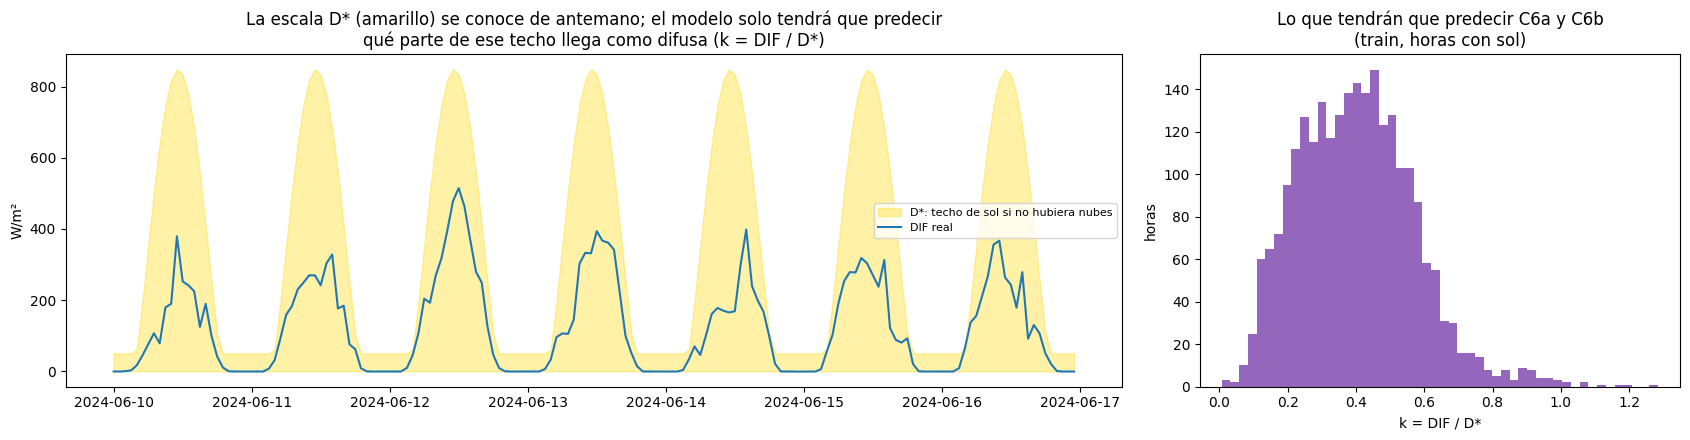

Guardado en: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/diagnostico/faseC_normalizacion/C6_escala_y_variabilidad.csv


In [ ]:
import os, sys, subprocess, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
try:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
except ImportError:
    pass
try:
    import pvlib
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pvlib"], check=True)
    import pvlib

BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
PARQUET = BASE_DIR / "radiation_data_completo.parquet"
RUTA_NPZ = (
    BASE_DIR
    / "resultados"
    / "ejecuciones"
    / "preparacion_bloque_difstats_20261006_180841"
    / "matrices_dif_elev_difstats.npz"
)
DIR_F1 = BASE_DIR / "resultados" / "diagnostico" / "fase1_intrahoraria"
DIR_C6 = BASE_DIR / "resultados" / "diagnostico" / "faseC_normalizacion"
DIR_C6.mkdir(parents=True, exist_ok=True)
LATITUD, LONGITUD = 51.971, 4.927
SUELO = 50.0  # W/m² (fijado antes)
FIN_DATOS = "2024-10-01"  # no se lee nada del test

# 1) Cielo despejado minuto a minuto, en una rejilla completa (no depende de huecos de medida)
mat = np.load(RUTA_NPZ)
fechas_tr = pd.DatetimeIndex(mat["fechas_train"])
fechas_va = pd.DatetimeIndex(mat["fechas_validation"])
y_tr = mat["y_train_difstats"].astype(float).reshape(-1)
y_va = mat["y_validation_difstats"].astype(float).reshape(-1)
ini = fechas_tr.min() - pd.Timedelta("25h")  # margen para la ventana de 24 h
fin = min(fechas_va.max() + pd.Timedelta("1h"), pd.Timestamp(FIN_DATOS))
rejilla = pd.date_range(ini, fin, freq="1min", inclusive="left", tz="UTC")
cs = pvlib.location.Location(LATITUD, LONGITUD, tz="UTC").get_clearsky(rejilla, model="ineichen")[
    "ghi"
]
cs.index = cs.index.tz_localize(None)

# 2) Medidas minutales de SWD (para Kc_std)
sw = pd.read_parquet(PARQUET, columns=["Date/Time", "SWD [W/m**2]"])
sw["Date/Time"] = pd.to_datetime(sw["Date/Time"], utc=True).dt.tz_localize(None)
sw = sw.set_index("Date/Time").sort_index()
sw = sw[~sw.index.duplicated()]
sw = sw[(sw.index >= ini) & (sw.index < fin)]
assert sw.index.max() < pd.Timestamp(FIN_DATOS), "Se estarían leyendo datos del test"
swd = pd.to_numeric(sw["SWD [W/m**2]"], errors="coerce").reindex(cs.index)

# 3) Agregación horaria (hora etiquetada por su inicio)
hora = cs.index.floor("h")
D = cs.groupby(hora).mean()
kc_min = (swd / cs).where(cs >= SUELO)
n_ok = kc_min.notna().groupby(hora).sum()
Kc_std = kc_min.groupby(hora).std().where(n_ok >= 30)
T = pd.DataFrame({"D": D, "D_star": np.maximum(D, SUELO), "Kc_std": Kc_std})
T["D_next"] = T["D_star"].shift(-1)  # en la hora t: la escala de t+1 (se conoce de antemano)
T.index.name = "hora"
T.to_csv(DIR_C6 / "C6_escala_y_variabilidad.csv")

# 4) Comprobaciones
for nombre, f in [("train", fechas_tr), ("validación", fechas_va)]:
    falta = T["D_star"].reindex(f).isna().sum()
    print(f"{nombre}: {len(f)} horas · sin escala D*: {falta}  ← esperado 0")
    assert falta == 0
k_tr = y_tr / T["D_star"].reindex(fechas_tr).to_numpy()
sol = T["D"].reindex(fechas_tr).to_numpy() >= SUELO
print(f"\nÍndice k = DIF / D* en train (horas con D ≥ {SUELO:.0f}):")
print(
    f"   mediana {np.nanmedian(k_tr[sol]):.2f} · p95 {np.nanpercentile(k_tr[sol], 95):.2f} · máximo {np.nanmax(k_tr[sol]):.2f}"
)
print(
    f"   horas con k > 1 (más difusa que global de cielo despejado): {100*np.nanmean(k_tr[sol] > 1):.1f} %"
)
print(
    f"   noche y sol muy bajo (D < {SUELO:.0f}): DIF media {np.nanmean(y_tr[~sol]):.1f} W/m² · k máximo {np.nanmax(k_tr[~sol]):.2f}"
    "  ← DIF casi nula; gracias al suelo, k no se dispara"
)
print(
    f"Kc_std disponible en {100*T['Kc_std'].reindex(fechas_tr)[sol].notna().mean():.0f} % de las horas con sol de train "
    "(el resto se rellenará con 0, igual que SWD_cv)"
)

# Gráfica sencilla: una semana de junio en train
semana = slice("2024-06-10", "2024-06-16")
dif_h = pd.Series(y_tr, index=fechas_tr)
fig, axs = plt.subplots(1, 2, figsize=(17, 4.5), gridspec_kw={"width_ratios": [2.2, 1]})
axs[0].fill_between(
    T.loc[semana].index,
    0,
    T.loc[semana, "D_star"],
    color="gold",
    alpha=0.35,
    label="D*: techo de sol si no hubiera nubes",
)
axs[0].plot(dif_h.loc[semana].index, dif_h.loc[semana], color="tab:blue", lw=1.5, label="DIF real")
axs[0].set_ylabel("W/m²")
axs[0].legend(fontsize=8)
axs[0].set_title(
    "La escala D* (amarillo) se conoce de antemano; el modelo solo tendrá que predecir\n"
    "qué parte de ese techo llega como difusa (k = DIF / D*)"
)
axs[1].hist(k_tr[sol], bins=50, color="tab:purple")
axs[1].set_xlabel("k = DIF / D*")
axs[1].set_ylabel("horas")
axs[1].set_title("Lo que tendrán que predecir C6a y C6b\n(train, horas con sol)")
plt.tight_layout()
plt.savefig(DIR_C6 / "C6_escala_D.png", dpi=120)
plt.show()
print("Guardado en:", DIR_C6 / "C6_escala_y_variabilidad.csv")

**Resultados.** Todas las horas de entrenamiento (5.149) y de validación (1.464) tienen escala D*. En las horas de entrenamiento con D ≥ 50 W/m², k tiene una mediana de 0,39, un percentil 95 de 0,68 y un máximo de 1,29, y supera 1 en el 0,4 % de las horas; de noche y con el sol muy bajo, la DIF media es de 1,6 W/m² y el suelo limita k a un máximo de 1,35. La variabilidad de kc está disponible en el 99 % de las horas con sol de entrenamiento.

### 6.5 Criba de la normalización por cielo despejado

Se comparan con E1-30 tres variantes en la criba de cuatro meses fuera, solo con entrenamiento y la semilla 42: C6-0 añade como canal la escala de cielo despejado de la hora siguiente sin cambiar el objetivo; C6a añade además k como canal y predice k, de modo que la DIF se obtiene multiplicando por D*; y C6b es C6a con la variabilidad de kc en lugar de la de la global. Todas se entrenan con pérdida L1 en W/m², y se aplica la regla de la criba: mejora de al menos 0,5 W/m² en horas con sol con el IC95 por debajo de 0, y descarte si empeoran de forma significativa las horas con sol o la banda central.

Entradas E1 train: (5149, 24, 9)  ← esperado (5149, 24, 9)
[1/16] BASE · 2024-01 · semilla 42: ya hecho
[2/16] BASE · 2024-03 · semilla 42: ya hecho
[3/16] BASE · 2024-05 · semilla 42: ya hecho
[4/16] BASE · 2024-07 · semilla 42: ya hecho
[5/16] C6·0 · 2024-01 · semilla 42: 125 s (total 2.1 min)
[6/16] C6·0 · 2024-03 · semilla 42: 77 s (total 3.4 min)
[7/16] C6·0 · 2024-05 · semilla 42: 74 s (total 4.6 min)
[8/16] C6·0 · 2024-07 · semilla 42: 75 s (total 5.8 min)
[9/16] C6a · 2024-01 · semilla 42: 73 s (total 7.1 min)
[10/16] C6a · 2024-03 · semilla 42: 74 s (total 8.3 min)
[11/16] C6a · 2024-05 · semilla 42: 73 s (total 9.5 min)
[12/16] C6a · 2024-07 · semilla 42: 74 s (total 10.8 min)
[13/16] C6b · 2024-01 · semilla 42: 72 s (total 11.9 min)
[14/16] C6b · 2024-03 · semilla 42: 73 s (total 13.2 min)
[15/16] C6b · 2024-05 · semilla 42: 72 s (total 14.4 min)
[16/16] C6b · 2024-07 · semilla 42: 73 s (total 15.6 min)

Semillas disponibles por configuración: {'BASE': [42, 123], 'C6·0': [42

,semillas,mejor época,MAE mes no visto,MAE BASE (mismas semillas),ventaja sobre persistencia (%),MAE nubosidad variable,cambio operación,IC95 operación,cambio banda central,IC95 central,veredicto
configuración,,,,,,,,,,,
BASE · E1-30,2,30,25.39,25.39,42.66,36.48,0.00,"[+0.00, +0.00]",0.00,"[+0.00, +0.00]",referencia
C6·0 · E1 + escala de T,1,60,25.48,25.60,42.45,37.33,-0.11,"[-0.86, +0.64]",0.23,"[-1.86, +2.31]",no se distingue de la BASE
C6a · predice k,1,50,26.35,25.60,40.49,37.54,0.75,"[+0.04, +1.46]",0.55,"[-1.04, +2.15]",DESCARTADA (empeora en operación)
C6b · predice k + Kc_std,1,35,26.36,25.60,40.46,37.78,0.77,"[+0.03, +1.48]",0.86,"[-1.18, +2.96]",DESCARTADA (empeora en operación)



Desglose (solo informativo; decide la tabla de arriba):


config,C6a,C6b,C6·0
grupo,,,
banda: central >40°,0.55,0.86,0.23
banda: hombros ≤20°,1.03,1.52,-0.05
banda: intermedia 20–40°,0.46,-0.65,-0.53
cielo: amanecer/atardecer,-0.66,-0.45,-0.56
cielo: cubierto,1.85,0.86,0.88
cielo: despejado,0.18,0.80,-2.09
cielo: nubes rotas,0.68,0.92,0.47
cielo: velado,2.15,1.51,-0.67
regimen: completamente_diurno,0.99,0.97,-0.04


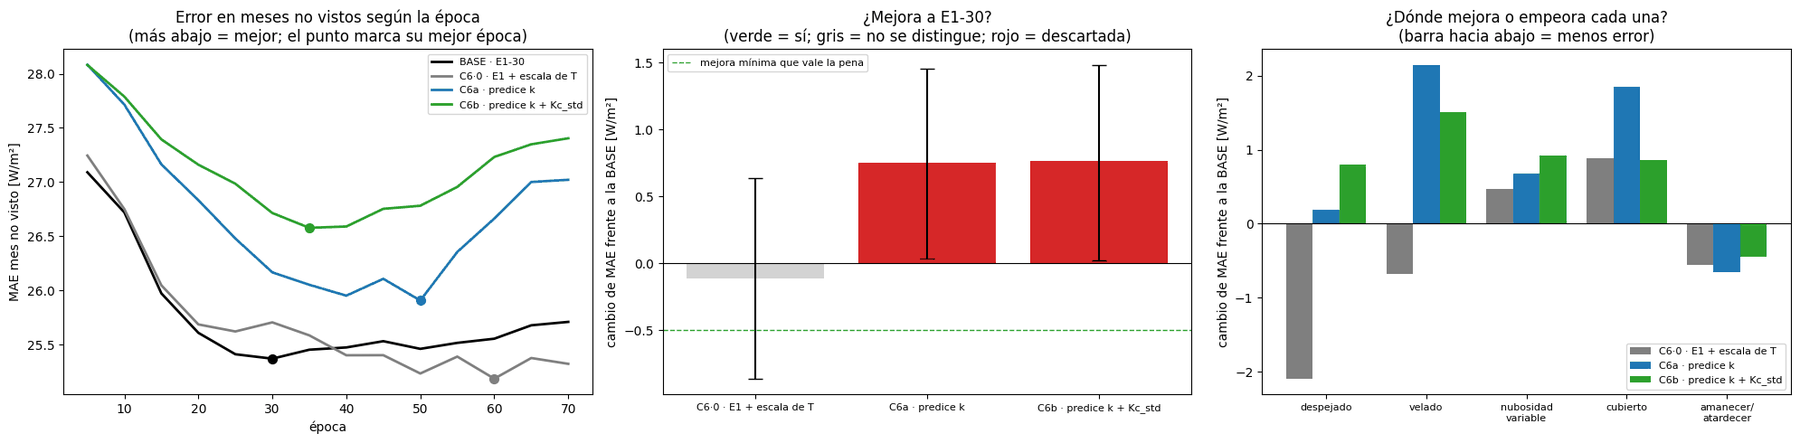


LECTURA
➜ BASE (E1-30, mejor época 30): MAE 25.39 W/m² en meses no vistos.
➜ Ninguna variante mejora de forma clara a la BASE. Nada que repetir: E1-30 se mantiene como modelo base.
Resultados en: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/diagnostico/faseC_normalizacion


In [ ]:
import os, time, random, shutil, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
try:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
except ImportError:
    pass

BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
RUTA_NPZ = (
    BASE_DIR
    / "resultados"
    / "ejecuciones"
    / "preparacion_bloque_difstats_20261006_180841"
    / "matrices_dif_elev_difstats.npz"
)
DIR_F1 = BASE_DIR / "resultados" / "diagnostico" / "fase1_intrahoraria"
DIR_B = BASE_DIR / "resultados" / "diagnostico" / "faseB_radiografia_E1"
DIR_C5P = BASE_DIR / "resultados" / "diagnostico" / "faseC_regularizacion" / "C5b_predicciones"
DIR_C6 = BASE_DIR / "resultados" / "diagnostico" / "faseC_normalizacion"
DIR_P = DIR_C6 / "C6_predicciones"
DIR_P.mkdir(parents=True, exist_ok=True)
assert (DIR_C6 / "C6_escala_y_variabilidad.csv").exists(), "Ejecuta antes la celda 1 de C6"

# ---- Lo que se ejecuta (para el PASO 2 solo se cambian estas dos líneas) ----
SEMILLAS = [42]
A_EJECUTAR = ["BASE", "C6·0", "C6a", "C6b"]
CONFIGS = {
    "BASE": dict(extra=[], normalizado=False, kcstd=False, nombre="BASE · E1-30"),
    "C6·0": dict(
        extra=["D_next"], normalizado=False, kcstd=False, nombre="C6·0 · E1 + escala de T"
    ),
    "C6a": dict(extra=["D_next", "k"], normalizado=True, kcstd=False, nombre="C6a · predice k"),
    "C6b": dict(
        extra=["D_next", "k"], normalizado=True, kcstd=True, nombre="C6b · predice k + Kc_std"
    ),
}
MESES_CRIBA = ["2024-01", "2024-03", "2024-05", "2024-07"]
EPOCAS_MAX, CADA, BATCH, LR, WD = 70, 5, 128, 1e-3, 1e-5
EFECTO_MINIMO, SEGUNDA_OPORTUNIDAD = 0.5, 0.3
N_BOOT = 2000

# 1) Entradas
mat = np.load(RUTA_NPZ)
X_tr = mat["X_train_DIF_elev_DIFstats_raw"].astype(np.float32)
y_tr = mat["y_train_difstats"].astype(np.float32).reshape(-1)
fechas_tr = pd.DatetimeIndex(mat["fechas_train"])
intrahora = pd.read_csv(
    DIR_F1 / "variables_intrahorarias_horarias.csv", index_col=0, parse_dates=True
).asfreq("h")
ESC = pd.read_csv(DIR_C6 / "C6_escala_y_variabilidad.csv", index_col=0, parse_dates=True).asfreq(
    "h"
)

def a_ventanas(tabla, fechas_obj, columnas, lookback=24):
    f = pd.DatetimeIndex(fechas_obj).to_numpy(dtype="datetime64[ns]")
    idx = f[:, None] - np.arange(lookback, 0, -1).astype("timedelta64[h]")[None, :]
    vals = tabla.reindex(pd.DatetimeIndex(idx.reshape(-1)))[columnas].to_numpy(dtype=np.float32)
    return vals.reshape(len(f), lookback, len(columnas))

CANALES_E1 = ["DIF_ult15", "DIF_pend30", "DIF_acel60", "DIF_saltos", "SWD_cv"]

def construir(fechas_obj, X_base, canales):
    Xn = a_ventanas(intrahora, fechas_obj, canales)
    for j, c in enumerate(canales):
        hueco = np.isnan(Xn[:, :, j])
        Xn[:, :, j][hueco] = X_base[:, :, 0][hueco] if c == "DIF_ult15" else 0.0
    return np.concatenate([X_base, Xn], axis=2).astype(np.float32)

Xtr_E1 = construir(fechas_tr, X_tr, CANALES_E1)
print(f"Entradas E1 train: {Xtr_E1.shape}  ← esperado (5149, 24, 9)")

# Canales nuevos (ventana T−24…T−1)
D_win = a_ventanas(ESC, fechas_tr, ["D_star"])[:, :, 0]
CANAL = {
    "D_next": a_ventanas(ESC, fechas_tr, ["D_next"])[
        :, :, 0
    ],  # en el paso t: D*(t+1) → en el último, D*(T)
    "k": X_tr[:, :, 0] / D_win,
}  # k(t) = DIF(t) / D*(t)
kc = a_ventanas(ESC, fechas_tr, ["Kc_std"])[:, :, 0]
KC_STD = np.nan_to_num(kc, nan=0.0).astype(np.float32)  # sin dato → 0, como SWD_cv
D_T = ESC["D_star"].reindex(fechas_tr).to_numpy(np.float32)  # escala de la hora a predecir
for nombre, v in list(CANAL.items()) + [("D*(T)", D_T)]:
    assert np.isfinite(v).all(), f"Hay huecos en {nombre}"
IDX_SWDCV = 4 + CANALES_E1.index("SWD_cv")

def entradas(cfg):
    X = Xtr_E1.copy()
    if cfg["kcstd"]:
        X[:, :, IDX_SWDCV] = KC_STD
    extra = [CANAL[c][:, :, None] for c in cfg["extra"]]
    return np.concatenate([X] + extra, axis=2).astype(np.float32) if extra else X

H = pd.read_pickle(DIR_B / "tabla_horaria_E1.pkl")
TR = H[H["conjunto"] == "train"]
assert (
    len(TR) == len(y_tr) and (TR.index == fechas_tr).all()
), "La tabla de la radiografía no cuadra con el .npz"
SOL = (TR["regimen"] != "noche").to_numpy()
mes = fechas_tr.to_period("M").astype(str).to_numpy()
mes = np.where(mes == "2023-12", "2024-01", mes)

def pliegue(m):
    fuera = mes == m
    fin = fechas_tr[fuera].max()
    purga = (fechas_tr > fin) & (fechas_tr <= fin + pd.Timedelta("24h"))
    return ~fuera & ~purga, fuera


# 2) Modelo y entrenamiento
import torch, torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler

class LSTMDIFStats(nn.Module):
    def __init__(self, n_features=4, hidden_size=64):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=n_features, hidden_size=hidden_size, num_layers=1, batch_first=True
        )
        self.head = nn.Sequential(nn.Linear(hidden_size, 32), nn.ReLU(), nn.Linear(32, 1))

    def forward(self, x):
        salida, _ = self.lstm(x)
        return self.head(salida[:, -1, :]).squeeze(-1)

def entrenar(cfg, entrena, fuera, semilla):
    """Predicciones del mes no visto (en W/m²) cada 5 épocas y MAE en lo visto."""
    Xall = entradas(cfg)
    Xtr, ytr, Xte = Xall[entrena], y_tr[entrena], Xall[fuera]
    Dtr, Dte = D_T[entrena], D_T[fuera]
    sx_ = StandardScaler().fit(Xtr.reshape(-1, Xtr.shape[2]))
    e = lambda X: torch.from_numpy(
        sx_.transform(X.reshape(-1, X.shape[2])).reshape(X.shape).astype(np.float32)
    )
    Xtr_t, Xte_t = e(Xtr), e(Xte)
    sd_y = float(ytr.std())  # misma escala de pérdida que E1 (L1 sobre DIF estandarizada)
    if cfg["normalizado"]:
        ktr = ytr / Dtr
        mu, sd = float(ktr.mean()), float(ktr.std())  # el modelo trabaja con k estandarizado
        a_dif = lambda z, Dv: torch.clamp((z * sd + mu) * Dv, min=0.0)
    else:
        sy_ = StandardScaler().fit(ytr.reshape(-1, 1))
        mu, sd = float(sy_.mean_[0]), float(sy_.scale_[0])
        a_dif = lambda z, Dv: z * sd + mu
    random.seed(semilla)
    np.random.seed(semilla)
    torch.manual_seed(semilla)
    torch.use_deterministic_algorithms(True)
    modelo = LSTMDIFStats(n_features=Xtr.shape[2])
    gen = torch.Generator()
    gen.manual_seed(semilla)
    loader = DataLoader(
        TensorDataset(Xtr_t, torch.from_numpy(ytr), torch.from_numpy(Dtr)),
        batch_size=BATCH,
        shuffle=True,
        generator=gen,
        num_workers=0,
    )
    opt = torch.optim.Adam(modelo.parameters(), lr=LR, weight_decay=WD)
    Dtr_t, Dte_t = torch.from_numpy(Dtr), torch.from_numpy(Dte)
    preds, visto = [], []
    for ep in range(1, EPOCAS_MAX + 1):
        modelo.train()
        for xb, yb, db in loader:
            opt.zero_grad(set_to_none=True)
            loss = (
                a_dif(modelo(xb), db) - yb
            ).abs().mean() / sd_y  # L1 en W/m² (escalada como en E1)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(modelo.parameters(), max_norm=1.0)
            opt.step()
        if ep % CADA == 0:
            modelo.eval()
            with torch.no_grad():
                preds.append(a_dif(modelo(Xte_t), Dte_t).numpy())
                visto.append(np.abs(a_dif(modelo(Xtr_t), Dtr_t).numpy() - ytr)[SOL[entrena]].mean())
    return np.array(preds, dtype=np.float32), np.array(visto, dtype=np.float32)


# La BASE es exactamente R0 de C5b (mismo código, meses y semillas): se copia en lugar de reentrenar
for s in [42, 123, 2024, 7, 99]:
    for m in MESES_CRIBA:
        o, d = DIR_C5P / f"R0_{m}_s{s}.npz", DIR_P / f"BASE_{m}_s{s}.npz"
        if o.exists() and not d.exists():
            shutil.copy(o, d)

t_ini = time.time()
n_tot = len(A_EJECUTAR) * len(MESES_CRIBA) * len(SEMILLAS)
k_ = 0
for r in A_EJECUTAR:
    for s in SEMILLAS:
        for m in MESES_CRIBA:
            k_ += 1
            ruta = DIR_P / f"{r}_{m}_s{s}.npz"
            if ruta.exists():
                print(f"[{k_}/{n_tot}] {r} · {m} · semilla {s}: ya hecho")
                continue
            t0 = time.time()
            entrena, fuera = pliegue(m)
            p, v = entrenar(CONFIGS[r], entrena, fuera, s)
            np.savez(ruta, pred=p, visto=v)
            print(
                f"[{k_}/{n_tot}] {r} · {m} · semilla {s}: {time.time()-t0:.0f} s (total {(time.time()-t_ini)/60:.1f} min)"
            )

# 3) Juntar resultados (horas con sol de los 4 meses no vistos)
EPOCAS = np.arange(CADA, EPOCAS_MAX + 1, CADA)
idx_oof = np.where(np.isin(mes, MESES_CRIBA))[0]
sol_oof = SOL[idx_oof]
y_oof = y_tr[idx_oof]
info = TR.iloc[idx_oof][["regimen", "banda", "cielo", "persistencia"]].copy()
dias = TR.index[idx_oof].normalize()

def cargar(r, semillas):
    P = np.zeros((len(EPOCAS), len(idx_oof)))
    V = np.zeros(len(EPOCAS))
    for s in semillas:
        for m in MESES_CRIBA:
            d = np.load(DIR_P / f"{r}_{m}_s{s}.npz")
            P[:, mes[idx_oof] == m] += d["pred"] / len(semillas)
            V += d["visto"] / (len(semillas) * len(MESES_CRIBA))
    return P, V

disp = {}
for r in CONFIGS:
    ss = [
        s
        for s in [42, 123, 2024, 7, 99]
        if all((DIR_P / f"{r}_{m}_s{s}.npz").exists() for m in MESES_CRIBA)
    ]
    if ss:
        disp[r] = ss
assert "BASE" in disp, "Falta la BASE"
print("\nSemillas disponibles por configuración:", disp)

def evaluar(r, ss):
    P, V = cargar(r, ss)
    mae_ep = np.abs(P[:, sol_oof] - y_oof[sol_oof]).mean(axis=1)
    suav = pd.Series(mae_ep, index=EPOCAS).rolling(3, center=True, min_periods=1).mean()
    e_best = int(suav.idxmin())
    return (
        pd.DataFrame(
            {"MAE mes no visto": mae_ep, "suavizado": suav.values, "MAE visto": V}, index=EPOCAS
        ),
        e_best,
        P[list(EPOCAS).index(e_best)],
    )

curvas, mejor, P_mejor, P_B = {}, {}, {}, {}
for r, ss in disp.items():
    comunes = [s for s in ss if s in disp["BASE"]]
    curvas[r], mejor[r], P_mejor[r] = evaluar(r, comunes)
    P_B[r] = evaluar("BASE", comunes)[2]

# 4) Comparación por parejas con la BASE (bootstrap por días)
rng = np.random.default_rng(0)
u_dias, inv = np.unique(dias[sol_oof], return_inverse=True)
grupos_dia = [np.where(inv == i)[0] for i in range(len(u_dias))]
remuestras = [
    np.concatenate([grupos_dia[i] for i in rng.integers(0, len(grupos_dia), len(grupos_dia))])
    for _ in range(N_BOOT)
]

def ic_dif(a_r, a_0, mascara=None):
    d = a_r - a_0
    if mascara is not None:
        d = np.where(mascara, d, np.nan)
    medias = [np.nanmean(d[s]) for s in remuestras]
    return np.nanmean(d), np.nanpercentile(medias, 2.5), np.nanpercentile(medias, 97.5)

err = {r: np.abs(P_mejor[r][sol_oof] - y_oof[sol_oof]) for r in disp}
err0 = {r: np.abs(P_B[r][sol_oof] - y_oof[sol_oof]) for r in disp}
inf = info[sol_oof]
central = (inf["banda"].astype(str).str.startswith("central")).to_numpy()
mae_pers = np.nanmean(np.abs(inf["persistencia"].to_numpy() - y_oof[sol_oof]))
filas, desglose = [], []
for r in disp:
    if r == "BASE":
        c, lo, hi, cc, lc, hc = 0, 0, 0, 0, 0, 0
    else:
        c, lo, hi = ic_dif(err[r], err0[r])
        cc, lc, hc = ic_dif(err[r], err0[r], central)
        for col in ["regimen", "banda", "cielo"]:
            for g in inf[col].unique():
                cg, lg, hg = ic_dif(err[r], err0[r], (inf[col] == g).to_numpy())
                desglose.append(
                    {
                        "config": r,
                        "grupo": f"{col}: {g}",
                        "horas": int((inf[col] == g).sum()),
                        "cambio": cg,
                        "IC95 bajo": lg,
                        "IC95 alto": hg,
                        "lectura": "mejora" if hg < 0 else ("empeora" if lg > 0 else "igual"),
                    }
                )
    if r == "BASE":
        ver = "referencia"
    elif lo > 0 or lc > 0:
        ver = (
            "DESCARTADA (empeora en "
            + " y ".join([x for x, v in [("operación", lo > 0), ("banda central", lc > 0)] if v])
            + ")"
        )
    elif hi < 0 and -c >= EFECTO_MINIMO:
        ver = "MEJORA REAL"
    elif hi < 0:
        ver = "mejora real pero pequeña (< 0,5)"
    else:
        ver = "no se distingue de la BASE"
    filas.append(
        {
            "configuración": CONFIGS[r]["nombre"],
            "semillas": len(disp[r]),
            "mejor época": mejor[r],
            "MAE mes no visto": err[r].mean(),
            "MAE BASE (mismas semillas)": err0[r].mean(),
            "ventaja sobre persistencia (%)": 100 * (1 - err[r].mean() / mae_pers),
            "MAE nubosidad variable": err[r][(inf["cielo"] == "nubes rotas").to_numpy()].mean(),
            "cambio operación": c,
            "IC95 operación": f"[{lo:+.2f}, {hi:+.2f}]",
            "cambio banda central": cc,
            "IC95 central": f"[{lc:+.2f}, {hc:+.2f}]",
            "veredicto": ver,
            "_lo": lo,
            "_hi": hi,
            "_r": r,
        }
    )
T = pd.DataFrame(filas).set_index("configuración")
D = pd.DataFrame(desglose)
print(
    "\n"
    + "=" * 110
    + "\nC6 · ¿SEPARAR 'SOL' DE 'NUBES' MEJORA A E1-30? (meses no vistos de train, horas con sol)\n"
    + "=" * 110
)
print(
    "Cambio negativo = menos error que la BASE. 'MEJORA REAL' exige ≥ 0,5 W/m² en operación con IC95 sin el 0."
)
print(
    "Cada variante se compara con la BASE entrenada con SUS MISMAS semillas (columna 'MAE BASE (mismas semillas)')."
)
display(T.drop(columns=["_lo", "_hi", "_r"]).round(2))
if len(D):
    print("\nDesglose (solo informativo; decide la tabla de arriba):")
    display(D.pivot_table(index="grupo", columns="config", values="cambio").round(2))

# 5) Gráficas
colores = {"BASE": "black", "C6·0": "tab:gray", "C6a": "tab:blue", "C6b": "tab:green"}
fig, axs = plt.subplots(1, 3, figsize=(20, 5))
for r, c in curvas.items():
    axs[0].plot(c.index, c["suavizado"], color=colores[r], lw=2, label=CONFIGS[r]["nombre"])
    axs[0].scatter([mejor[r]], [c.loc[mejor[r], "suavizado"]], color=colores[r], s=50, zorder=3)
axs[0].set_xlabel("época")
axs[0].set_ylabel("MAE mes no visto [W/m²]")
axs[0].legend(fontsize=8)
axs[0].set_title(
    "Error en meses no vistos según la época\n(más abajo = mejor; el punto marca su mejor época)"
)
otras = T[T["_r"] != "BASE"]
x = np.arange(len(otras))
col_b = [
    (
        "tab:green"
        if v.startswith("MEJORA")
        else ("tab:red" if v.startswith("DESCARTADA") else "lightgray")
    )
    for v in otras["veredicto"]
]
axs[1].bar(
    x,
    otras["cambio operación"],
    color=col_b,
    yerr=[otras["cambio operación"] - otras["_lo"], otras["_hi"] - otras["cambio operación"]],
    capsize=6,
)
axs[1].axhline(0, color="k", lw=0.8)
axs[1].axhline(
    -EFECTO_MINIMO, color="tab:green", ls="--", lw=1, label="mejora mínima que vale la pena"
)
axs[1].set_xticks(x)
axs[1].set_xticklabels(otras.index, fontsize=8)
axs[1].set_ylabel("cambio de MAE frente a la BASE [W/m²]")
axs[1].legend(fontsize=8)
axs[1].set_title("¿Mejora a E1-30?\n(verde = sí; gris = no se distingue; rojo = descartada)")
cielos = ["despejado", "velado", "nubes rotas", "cubierto", "amanecer/atardecer"]
w = 0.8 / max(len(otras), 1)
for j, r in enumerate(otras["_r"]):
    vals = [D[(D["config"] == r) & (D["grupo"] == f"cielo: {c}")]["cambio"].mean() for c in cielos]
    axs[2].bar(
        np.arange(len(cielos)) + (j - (len(otras) - 1) / 2) * w,
        vals,
        w,
        color=colores[r],
        label=CONFIGS[r]["nombre"],
    )
axs[2].axhline(0, color="k", lw=0.8)
axs[2].set_xticks(range(len(cielos)))
axs[2].set_xticklabels(
    ["despejado", "velado", "nubosidad\nvariable", "cubierto", "amanecer/\natardecer"], fontsize=8
)
axs[2].set_ylabel("cambio de MAE frente a la BASE [W/m²]")
axs[2].legend(fontsize=8)
axs[2].set_title("¿Dónde mejora o empeora cada una?\n(barra hacia abajo = menos error)")
plt.tight_layout()
plt.savefig(DIR_C6 / "C6_criba.png", dpi=120)
plt.show()

# 6) Lectura y siguiente paso
print("\n" + "=" * 110 + "\nLECTURA\n" + "=" * 110)
b = T[T["_r"] == "BASE"].iloc[0]
print(
    f"➜ BASE (E1-30, mejor época {int(b['mejor época'])}): MAE {b['MAE mes no visto']:.2f} W/m² en meses no vistos."
)
gan = T[T["veredicto"] == "MEJORA REAL"].sort_values("cambio operación")
repetir = []
if len(gan):
    g = gan.iloc[0]
    repetir.append(g["_r"])
    lect = f"Gana '{g.name}': {-g['cambio operación']:.2f} W/m² menos que la BASE (IC95 {g['IC95 operación']}), mejor época {int(g['mejor época'])}."
else:
    lect = "Ninguna variante mejora de forma clara a la BASE."
grises = T[
    (T["veredicto"] == "no se distingue de la BASE")
    & (-T["cambio operación"] >= SEGUNDA_OPORTUNIDAD)
]
repetir += [r for r in grises["_r"] if r not in repetir]
pendientes = [r for r in repetir if len(disp[r]) < 2]
if pendientes:
    lect += f" PASO 2: repetir con la semilla 123 → A_EJECUTAR = {pendientes}"
elif repetir:
    lect += " Ya hay 2 semillas → siguiente: confirmación en validación con 5 semillas."
else:
    lect += " Nada que repetir: E1-30 se mantiene como modelo base."
print("➜ " + lect)
T.drop(columns=["_lo", "_hi"]).to_csv(DIR_C6 / "C6_resumen.csv")
D.to_csv(DIR_C6 / "C6_desglose.csv", index=False)
pd.concat(curvas, names=["config", "epoca"]).to_csv(DIR_C6 / "C6_curvas.csv")
with open(DIR_C6 / "C6_lectura.txt", "w") as f:
    f.write(f"semillas {disp}\n{lect}\n")
print("Resultados en:", DIR_C6)

**Resultados.** Ninguna variante mejora a E1-30 en los meses no vistos. C6-0 no se distingue de E1-30 (−0,11 W/m², IC95 [−0,86; +0,64]), mientras que C6a (+0,75 W/m², IC95 [+0,04; +1,46]) y C6b (+0,77 W/m², IC95 [+0,03; +1,48]) empeoran de forma significativa en las horas con sol y se descartan. En el desglose informativo, C6-0 reduce el error con cielo despejado (−2,09 W/m²), y C6a lo aumenta sobre todo con cielo velado (+2,15 W/m²) y cubierto (+1,85 W/m²). E1-30 se mantiene sin cambios.

## 7. Depuración de las entradas de E1-30

> *Se utiliza en la memoria: apartado 5.3.4 y Tabla 13 (umbral del 4 % en el amanecer), y fase 10 de la Tabla A1.*

### 7.1 Errores fuera de muestra de E1-30

La depuración de las entradas de E1-30 busca el modelo más sencillo que no empeore el error. Su primer paso (P1) reentrena E1-30 dejando fuera cada uno de los siete meses de entrenamiento, con purga de 24 horas y las semillas 42 y 123, y conserva los modelos y sus predicciones fuera de muestra, que se usan después en la importancia por permutación y en las bandas de incertidumbre; además, compara E1-30 con E1 de 105 épocas (B5) en los siete meses.

Entradas E1 train: (5149, 24, 9)  ← esperado (5149, 24, 9)
2024-01 · semilla 42: 73 s (total 1.2 min)
2024-02 · semilla 42: 40 s (total 1.9 min)
2024-03 · semilla 42: 28 s (total 2.4 min)
2024-04 · semilla 42: 28 s (total 2.8 min)
2024-05 · semilla 42: 29 s (total 3.3 min)
2024-06 · semilla 42: 29 s (total 3.8 min)
2024-07 · semilla 42: 28 s (total 4.3 min)
2024-01 · semilla 123: 27 s (total 4.7 min)
2024-02 · semilla 123: 30 s (total 5.2 min)
2024-03 · semilla 123: 28 s (total 5.7 min)
2024-04 · semilla 123: 28 s (total 6.1 min)
2024-05 · semilla 123: 28 s (total 6.6 min)
2024-06 · semilla 123: 29 s (total 7.1 min)
2024-07 · semilla 123: 28 s (total 7.6 min)

P1 · ERROR DE E1-30 EN CADA MES NO VISTO DE TRAIN (horas con sol)


,horas con sol,MAE E1-105 (B5),MAE E1-30,MAE persistencia,cambio (30 − 105)
mes no visto,,,,,
2024-01,311,10.83,11.63,21.20,0.80
2024-02,315,16.88,16.59,33.29,-0.29
2024-03,386,24.07,23.30,42.89,-0.77
2024-04,444,34.95,33.32,51.59,-1.63
2024-05,519,30.17,29.07,52.24,-1.10
2024-06,525,33.40,30.38,48.84,-3.02
2024-07,527,34.29,31.41,51.06,-2.88
TOTAL,3027,28.00,26.50,45.00,-1.50


➜ Con los 7 meses: E1-30 26.50 W/m² frente a E1-105 28.00 (-1.50). Mejora en 6 de 7 meses.


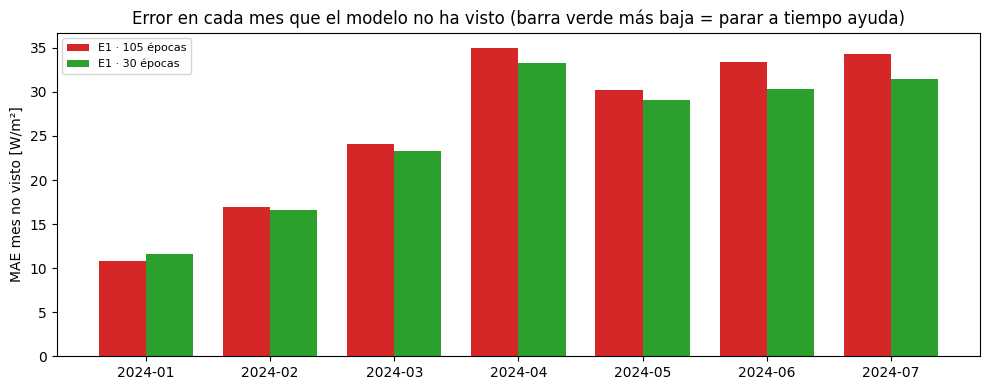

Resultados en: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/diagnostico/depuracion_E1_30


In [ ]:
import os, time, random, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
try:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
except ImportError:
    pass

BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
RUTA_NPZ = (
    BASE_DIR
    / "resultados"
    / "ejecuciones"
    / "preparacion_bloque_difstats_20261006_180841"
    / "matrices_dif_elev_difstats.npz"
)
DIR_F1 = BASE_DIR / "resultados" / "diagnostico" / "fase1_intrahoraria"
DIR_B = BASE_DIR / "resultados" / "diagnostico" / "faseB_radiografia_E1"
DIR_D = BASE_DIR / "resultados" / "diagnostico" / "depuracion_E1_30"
DIR_M = DIR_D / "P1_modelos_oof"
DIR_M.mkdir(parents=True, exist_ok=True)
SEMILLAS = [42, 123]
EPOCAS, BATCH, LR, WD = 30, 128, 1e-3, 1e-5

# 1) Entradas de E1 (mismo código de siempre)
mat = np.load(RUTA_NPZ)
X_tr = mat["X_train_DIF_elev_DIFstats_raw"].astype(np.float32)
y_tr = mat["y_train_difstats"].astype(np.float32).reshape(-1)
fechas_tr = pd.DatetimeIndex(mat["fechas_train"])
intrahora = pd.read_csv(
    DIR_F1 / "variables_intrahorarias_horarias.csv", index_col=0, parse_dates=True
).asfreq("h")

def a_ventanas(tabla, fechas_obj, columnas, lookback=24):
    f = pd.DatetimeIndex(fechas_obj).to_numpy(dtype="datetime64[ns]")
    idx = f[:, None] - np.arange(lookback, 0, -1).astype("timedelta64[h]")[None, :]
    vals = tabla.reindex(pd.DatetimeIndex(idx.reshape(-1)))[columnas].to_numpy(dtype=np.float32)
    return vals.reshape(len(f), lookback, len(columnas))

CANALES_E1 = ["DIF_ult15", "DIF_pend30", "DIF_acel60", "DIF_saltos", "SWD_cv"]

def construir(fechas_obj, X_base, canales):
    Xn = a_ventanas(intrahora, fechas_obj, canales)
    for j, c in enumerate(canales):
        hueco = np.isnan(Xn[:, :, j])
        Xn[:, :, j][hueco] = X_base[:, :, 0][hueco] if c == "DIF_ult15" else 0.0
    return np.concatenate([X_base, Xn], axis=2).astype(np.float32)

Xtr_E1 = construir(fechas_tr, X_tr, CANALES_E1)
print(f"Entradas E1 train: {Xtr_E1.shape}  ← esperado (5149, 24, 9)")
H = pd.read_pickle(DIR_B / "tabla_horaria_E1.pkl")
TR = H[H["conjunto"] == "train"].copy()
assert (
    len(TR) == len(y_tr) and (TR.index == fechas_tr).all()
), "La tabla de la radiografía no cuadra con el .npz"
SOL = (TR["regimen"] != "noche").to_numpy()
mes = fechas_tr.to_period("M").astype(str).to_numpy()
mes = np.where(mes == "2023-12", "2024-01", mes)
MESES = sorted(np.unique(mes))

def pliegue(m):
    fuera = mes == m
    fin = fechas_tr[fuera].max()
    purga = (fechas_tr > fin) & (fechas_tr <= fin + pd.Timedelta("24h"))
    return ~fuera & ~purga, fuera


# 2) Entrenamiento (protocolo exacto de E1, 30 épocas)
import torch, torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler

class LSTMDIFStats(nn.Module):
    def __init__(self, n_features=4, hidden_size=64):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=n_features, hidden_size=hidden_size, num_layers=1, batch_first=True
        )
        self.head = nn.Sequential(nn.Linear(hidden_size, 32), nn.ReLU(), nn.Linear(32, 1))

    def forward(self, x):
        salida, _ = self.lstm(x)
        return self.head(salida[:, -1, :]).squeeze(-1)

def entrenar(entrena, fuera, semilla):
    Xtr, ytr, Xte = Xtr_E1[entrena], y_tr[entrena], Xtr_E1[fuera]
    sx_ = StandardScaler().fit(Xtr.reshape(-1, Xtr.shape[2]))
    sy_ = StandardScaler().fit(ytr.reshape(-1, 1))
    e = lambda X: torch.from_numpy(
        sx_.transform(X.reshape(-1, X.shape[2])).reshape(X.shape).astype(np.float32)
    )
    ytr_e = sy_.transform(ytr.reshape(-1, 1)).ravel().astype(np.float32)
    random.seed(semilla)
    np.random.seed(semilla)
    torch.manual_seed(semilla)
    torch.use_deterministic_algorithms(True)
    modelo = LSTMDIFStats(n_features=Xtr.shape[2])
    gen = torch.Generator()
    gen.manual_seed(semilla)
    loader = DataLoader(
        TensorDataset(e(Xtr), torch.from_numpy(ytr_e)),
        batch_size=BATCH,
        shuffle=True,
        generator=gen,
        num_workers=0,
    )
    opt = torch.optim.Adam(modelo.parameters(), lr=LR, weight_decay=WD)
    crit = nn.L1Loss()
    for ep in range(EPOCAS):
        modelo.train()
        for xb, yb in loader:
            opt.zero_grad(set_to_none=True)
            loss = crit(modelo(xb), yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(modelo.parameters(), max_norm=1.0)
            opt.step()
    modelo.eval()
    with torch.no_grad():
        p = sy_.inverse_transform(modelo(e(Xte)).numpy().reshape(-1, 1)).ravel()
    paquete = {
        "model_state_dict": modelo.state_dict(),
        "sx_mean": sx_.mean_,
        "sx_scale": sx_.scale_,
        "sy_mean": float(sy_.mean_[0]),
        "sy_scale": float(sy_.scale_[0]),
        "mes": None,
        "semilla": semilla,
    }
    return p, paquete

t_ini = time.time()
for s in SEMILLAS:
    for m in MESES:
        ruta = DIR_M / f"E1_30_{m}_s{s}.pt"
        if ruta.exists():
            print(f"{m} · semilla {s}: ya hecho")
            continue
        t0 = time.time()
        entrena, fuera = pliegue(m)
        p, paq = entrenar(entrena, fuera, s)
        paq["mes"], paq["pred_oof"] = m, p
        torch.save(paq, ruta)
        print(f"{m} · semilla {s}: {time.time()-t0:.0f} s (total {(time.time()-t_ini)/60:.1f} min)")

# 3) Tabla de predicciones fuera de muestra (la usan P2 y D1)
for s in SEMILLAS:
    TR[f"OOF30_s{s}"] = np.nan
    for m in MESES:
        paq = torch.load(DIR_M / f"E1_30_{m}_s{s}.pt", map_location="cpu", weights_only=False)
        TR.loc[mes == m, f"OOF30_s{s}"] = paq["pred_oof"]
TR["OOF30_media"] = TR[[f"OOF30_s{s}" for s in SEMILLAS]].mean(axis=1)
TR["mes_pliegue"] = mes
assert TR["OOF30_media"].notna().all()
TR[[f"OOF30_s{s}" for s in SEMILLAS] + ["OOF30_media", "mes_pliegue", "real"]].to_pickle(
    DIR_D / "P1_oof_E1_30.pkl"
)

# 4) Resumen: E1-30 frente a E1-105 (B5), ambos fuera de muestra, mismos pliegues y semillas
mae = lambda p, y: np.abs(p - y).mean()
B5 = pd.read_pickle(DIR_B / "B5_fuera_de_muestra" / "predicciones_oof_train.pkl")
T = TR[SOL]
filas = []
for m in MESES + ["TOTAL"]:
    t = T if m == "TOTAL" else T[T["mes_pliegue"] == m]
    filas.append(
        {
            "mes no visto": m,
            "horas con sol": len(t),
            "MAE E1-105 (B5)": mae(B5.loc[t.index, "OOF_media"], t["real"]),
            "MAE E1-30": mae(t["OOF30_media"], t["real"]),
            "MAE persistencia": np.nanmean(np.abs(t["persistencia"] - t["real"])),
        }
    )
R = pd.DataFrame(filas).set_index("mes no visto")
R["cambio (30 − 105)"] = R["MAE E1-30"] - R["MAE E1-105 (B5)"]
print(
    "\n"
    + "=" * 95
    + "\nP1 · ERROR DE E1-30 EN CADA MES NO VISTO DE TRAIN (horas con sol)\n"
    + "=" * 95
)
display(R.round(2))
print(
    f"➜ Con los 7 meses: E1-30 {R.loc['TOTAL', 'MAE E1-30']:.2f} W/m² frente a E1-105 {R.loc['TOTAL', 'MAE E1-105 (B5)']:.2f} "
    f"({R.loc['TOTAL', 'cambio (30 − 105)']:+.2f}). Mejora en {(R.drop('TOTAL')['cambio (30 − 105)'] < 0).sum()} de {len(MESES)} meses."
)
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(MESES))
w = 0.38
ax.bar(x - w / 2, R.loc[MESES, "MAE E1-105 (B5)"], w, color="tab:red", label="E1 · 105 épocas")
ax.bar(x + w / 2, R.loc[MESES, "MAE E1-30"], w, color="tab:green", label="E1 · 30 épocas")
ax.set_xticks(x)
ax.set_xticklabels(MESES)
ax.set_ylabel("MAE mes no visto [W/m²]")
ax.legend(fontsize=8)
ax.set_title(
    "Error en cada mes que el modelo no ha visto (barra verde más baja = parar a tiempo ayuda)"
)
plt.tight_layout()
plt.savefig(DIR_D / "P1_E1_30_por_mes.png", dpi=120)
plt.show()
R.to_csv(DIR_D / "P1_resumen_por_mes.csv")
print("Resultados en:", DIR_D)

**Resultados.** Fuera de muestra, en las 3.027 horas con sol de entrenamiento, E1-30 obtiene 26,50 W/m² frente a 28,00 W/m² de E1 con 105 épocas (−1,50 W/m²), con mejora en seis de los siete meses. La mejora es mayor entre abril y julio (de −1,10 a −3,02 W/m²), y solo enero empeora (+0,80 W/m²).

### 7.2 Importancia por permutación de las entradas

Con los catorce modelos de P1, cada uno en su mes no visto, se desordena un grupo de canales o un bloque de horas de la ventana y se mide cuánto sube el MAE en horas con sol (P2), con cinco repeticiones e IC95 por bootstrap de días. Los canales parecidos se permutan juntos, y un grupo se marca como candidato a retirar si la subida es menor de 0,3 W/m². Los bloques se rotulan respecto a la hora objetivo T: T−1…T−3 corresponde a las horas de t−2 a t; T−4…T−12, a las de t−11 a t−3; y T−13…T−24, a las de t−23 a t−12.

✅ Control: los modelos de P1 reproducen sus predicciones guardadas
   canal            · DIF horaria (DIF_media)                            → +16.61 W/m²
   canal            · Geometría (elevación)                              → +22.96 W/m²
   canal            · Dispersión horaria (DIF_std, DIF_rango)            → +2.63 W/m²
   canal            · Nivel final de la hora (DIF_ult15)                 → +39.30 W/m²
   canal            · Dinámica intrahoraria (pend30, acel60, saltos)     → +3.13 W/m²
   canal            · Variabilidad SWD (SWD_cv)                          → +1.22 W/m²
   canal            · · control: DIF_media + DIF_ult15 juntos            → +68.69 W/m²
   bloque de horas  · horas T−1…T−3                                      → +101.71 W/m²
   bloque de horas  · horas T−4…T−12                                     → +14.34 W/m²
   bloque de horas  · horas T−13…T−24                                    → +0.25 W/m²

P2 · ¿QUÉ USA E1-30? (subida del MAE al desordenar cada grupo, me

subida del MAE [W/m²]  \
tipo            grupo                                                                   
canal           DIF horaria (DIF_media)                                         16.61   
                Geometría (elevación)                                           22.96   
                Dispersión horaria (DIF_std, DIF_rango)                          2.63   
                Nivel final de la hora (DIF_ult15)                              39.30   
                Dinámica intrahoraria (pend30, acel60, saltos)                   3.13   
                Variabilidad SWD (SWD_cv)                                        1.22   
                · control: DIF_media + DIF_ult15 juntos                         68.69   
bloque de horas horas T−1…T−3                                                  101.71   
                horas T−4…T−12                                                  14.34   
                horas T−13…T−24                                                  0.25   

                                                                             IC95  \
tipo            grupo                                                               
canal           DIF horaria (DIF_media)                          [+15.23, +18.03]   
                Geometría (elevación)                            [+21.72, +24.28]   
                Dispersión horaria (DIF_std, DIF_rango)            [+2.12, +3.15]   
                Nivel final de la hora (DIF_ult15)               [+36.83, +41.87]   
                Dinámica intrahoraria (pend30, acel60, saltos)     [+2.61, +3.63]   
                Variabilidad SWD (SWD_cv)                          [+0.99, +1.43]   
                · control: DIF_media + DIF_ult15 juntos          [+65.01, +72.46]   
bloque de horas horas T−1…T−3                                   [+97.30, +106.14]   
                horas T−4…T−12                                   [+13.49, +15.18]   
                horas T−13…T−24                                    [+0.14, +0.36]   

                                                                subida (%)  \
tipo            grupo                                                        
canal           DIF horaria (DIF_media)                              62.68   
                Geometría (elevación)                                86.65   
                Dispersión horaria (DIF_std, DIF_rango)               9.91   
                Nivel final de la hora (DIF_ult15)                  148.31   
                Dinámica intrahoraria (pend30, acel60, saltos)       11.80   
                Variabilidad SWD (SWD_cv)                             4.60   
                · control: DIF_media + DIF_ult15 juntos             259.19   
bloque de horas horas T−1…T−3                                       383.81   
                horas T−4…T−12                                       54.11   
                horas T−13…T−24                                       0.94   

                                                                                    lectura  
tipo            grupo                                                                        
canal           DIF horaria (DIF_media)                                              lo usa  
                Geometría (elevación)                                                lo usa  
                Dispersión horaria (DIF_std, DIF_rango)                              lo usa  
                Nivel final de la hora (DIF_ult15)                                   lo usa  
                Dinámica intrahoraria (pend30, acel60, saltos)                       lo usa  
                Variabilidad SWD (SWD_cv)                                            lo usa  
                · control: DIF_media + DIF_ult15 juntos              control (no se retira)  
bloque de horas horas T−1…T−3                                                        lo usa  
                horas T−4…T−12                                                       lo usa  
   

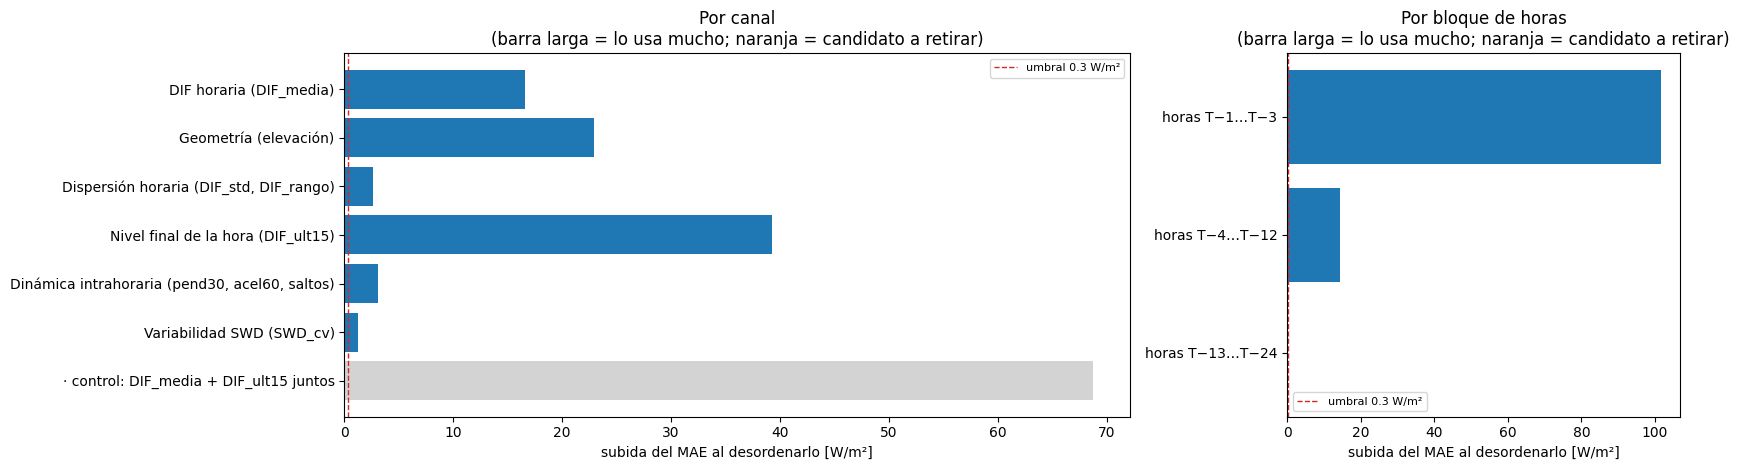


➜ Candidatos a retirar en P3: ['horas T−13…T−24']
   (El bloque T−13…T−24 apenas se usa → en P3 se prueba la ventana de 12 h en lugar de 24 h.)
   Recuerda: la permutación SEÑALA candidatos; la prueba de verdad es reentrenar sin ellos (P3).
Resultados en: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/diagnostico/depuracion_E1_30


In [ ]:
import os, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
try:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
except ImportError:
    pass

BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
RUTA_NPZ = (
    BASE_DIR
    / "resultados"
    / "ejecuciones"
    / "preparacion_bloque_difstats_20261006_180841"
    / "matrices_dif_elev_difstats.npz"
)
DIR_F1 = BASE_DIR / "resultados" / "diagnostico" / "fase1_intrahoraria"
DIR_B = BASE_DIR / "resultados" / "diagnostico" / "faseB_radiografia_E1"
DIR_D = BASE_DIR / "resultados" / "diagnostico" / "depuracion_E1_30"
DIR_M = DIR_D / "P1_modelos_oof"
assert (DIR_D / "P1_oof_E1_30.pkl").exists(), "Ejecuta antes P1"
SEMILLAS, N_REP, N_BOOT, UMBRAL = [42, 123], 5, 2000, 0.3

# Canales de E1 (orden real de la matriz de entrada)
NOMBRES = [
    "DIF_media",
    "elevacion",
    "DIF_std",
    "DIF_rango",
    "DIF_ult15",
    "DIF_pend30",
    "DIF_acel60",
    "DIF_saltos",
    "SWD_cv",
]
GRUPOS_CANAL = {  # fijados antes
    "DIF horaria (DIF_media)": [0],
    "Geometría (elevación)": [1],
    "Dispersión horaria (DIF_std, DIF_rango)": [2, 3],
    "Nivel final de la hora (DIF_ult15)": [4],
    "Dinámica intrahoraria (pend30, acel60, saltos)": [5, 6, 7],
    "Variabilidad SWD (SWD_cv)": [8],
    "· control: DIF_media + DIF_ult15 juntos": [
        0,
        4,
    ],  # son casi gemelos: juntos muestran lo que cuenta el nivel
}
BLOQUES_HORA = {
    "horas T−1…T−3": list(range(21, 24)),
    "horas T−4…T−12": list(range(12, 21)),
    "horas T−13…T−24": list(range(0, 12)),
}

# 1) Entradas (igual que P1)
mat = np.load(RUTA_NPZ)
X_tr = mat["X_train_DIF_elev_DIFstats_raw"].astype(np.float32)
y_tr = mat["y_train_difstats"].astype(np.float32).reshape(-1)
fechas_tr = pd.DatetimeIndex(mat["fechas_train"])
intrahora = pd.read_csv(
    DIR_F1 / "variables_intrahorarias_horarias.csv", index_col=0, parse_dates=True
).asfreq("h")

def a_ventanas(tabla, fechas_obj, columnas, lookback=24):
    f = pd.DatetimeIndex(fechas_obj).to_numpy(dtype="datetime64[ns]")
    idx = f[:, None] - np.arange(lookback, 0, -1).astype("timedelta64[h]")[None, :]
    vals = tabla.reindex(pd.DatetimeIndex(idx.reshape(-1)))[columnas].to_numpy(dtype=np.float32)
    return vals.reshape(len(f), lookback, len(columnas))

CANALES_E1 = ["DIF_ult15", "DIF_pend30", "DIF_acel60", "DIF_saltos", "SWD_cv"]

def construir(fechas_obj, X_base, canales):
    Xn = a_ventanas(intrahora, fechas_obj, canales)
    for j, c in enumerate(canales):
        hueco = np.isnan(Xn[:, :, j])
        Xn[:, :, j][hueco] = X_base[:, :, 0][hueco] if c == "DIF_ult15" else 0.0
    return np.concatenate([X_base, Xn], axis=2).astype(np.float32)

Xtr_E1 = construir(fechas_tr, X_tr, CANALES_E1)
assert Xtr_E1.shape[2] == len(NOMBRES)
H = pd.read_pickle(DIR_B / "tabla_horaria_E1.pkl")
TR = H[H["conjunto"] == "train"]
assert len(TR) == len(y_tr) and (TR.index == fechas_tr).all()
SOL = (TR["regimen"] != "noche").to_numpy()
OOF = pd.read_pickle(DIR_D / "P1_oof_E1_30.pkl")
mes = OOF["mes_pliegue"].to_numpy()
MESES = sorted(np.unique(mes))

# 2) Modelos de P1 y predicción con entradas alteradas
import torch, torch.nn as nn

class LSTMDIFStats(nn.Module):
    def __init__(self, n_features=4, hidden_size=64):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=n_features, hidden_size=hidden_size, num_layers=1, batch_first=True
        )
        self.head = nn.Sequential(nn.Linear(hidden_size, 32), nn.ReLU(), nn.Linear(32, 1))

    def forward(self, x):
        salida, _ = self.lstm(x)
        return self.head(salida[:, -1, :]).squeeze(-1)

MODELOS = {}
for s in SEMILLAS:
    for m in MESES:
        paq = torch.load(DIR_M / f"E1_30_{m}_s{s}.pt", map_location="cpu", weights_only=False)
        mod = LSTMDIFStats(n_features=Xtr_E1.shape[2])
        mod.load_state_dict(paq["model_state_dict"])
        mod.eval()
        MODELOS[(m, s)] = (mod, paq)

def predecir(m, s, X):
    mod, paq = MODELOS[(m, s)]
    Xe = ((X - paq["sx_mean"]) / paq["sx_scale"]).astype(np.float32)
    with torch.no_grad():
        return mod(torch.from_numpy(Xe)).numpy() * paq["sy_scale"] + paq["sy_mean"]


# Control: sin alterar nada, debe reproducir exactamente las predicciones guardadas en P1
for s in SEMILLAS:
    for m in MESES:
        dif = np.max(
            np.abs(predecir(m, s, Xtr_E1[mes == m]) - OOF.loc[mes == m, f"OOF30_s{s}"].to_numpy())
        )
        assert dif < 0.05, f"{m} s{s}: la predicción recalculada difiere {dif:.3f}"
print("✅ Control: los modelos de P1 reproducen sus predicciones guardadas")


# 3) Permutación (misma permutación para las 2 semillas → se altera el ensemble)
def error_alterado(canales, pasos, rep):
    """|error| por hora del ensemble cuando se desordenan 'canales' en 'pasos' entre las horas de cada mes."""
    pred = np.zeros(len(y_tr))
    for m in MESES:
        idx = np.where(mes == m)[0]
        X = Xtr_E1[idx].copy()
        perm = np.random.default_rng(1000 * rep + MESES.index(m)).permutation(len(idx))
        sub = X[:, pasos, :][:, :, canales]
        X[np.ix_(np.arange(len(idx)), pasos, canales)] = sub[perm]
        pred[idx] = np.mean([predecir(m, s, X) for s in SEMILLAS], axis=0)
    return np.abs(pred - y_tr)

e_base = np.abs(OOF["OOF30_media"].to_numpy() - y_tr)
dias = TR.index.normalize()[SOL]
u, inv = np.unique(dias, return_inverse=True)
grupos_dia = [np.where(inv == i)[0] for i in range(len(u))]
rng = np.random.default_rng(0)
remuestras = [
    np.concatenate([grupos_dia[i] for i in rng.integers(0, len(grupos_dia), len(grupos_dia))])
    for _ in range(N_BOOT)
]
TODOS_PASOS, TODOS_CANALES = list(range(24)), list(range(len(NOMBRES)))
pruebas = [("canal", n, c, TODOS_PASOS) for n, c in GRUPOS_CANAL.items()] + [
    ("bloque de horas", n, TODOS_CANALES, p) for n, p in BLOQUES_HORA.items()
]
filas = []
for tipo, nombre, canales, pasos in pruebas:
    e_alt = np.mean([error_alterado(canales, pasos, r) for r in range(N_REP)], axis=0)
    d = (e_alt - e_base)[SOL]
    medias = [d[r].mean() for r in remuestras]
    filas.append(
        {
            "tipo": tipo,
            "grupo": nombre,
            "subida del MAE [W/m²]": d.mean(),
            "IC95": f"[{np.percentile(medias, 2.5):+.2f}, {np.percentile(medias, 97.5):+.2f}]",
            "subida (%)": 100 * d.mean() / e_base[SOL].mean(),
            "lectura": (
                ("CANDIDATO a retirar (< 0,3)" if d.mean() < UMBRAL else "lo usa")
                if not nombre.startswith("·")
                else "control (no se retira)"
            ),
        }
    )
    print(f"   {tipo:16s} · {nombre:50s} → {d.mean():+.2f} W/m²")
P = pd.DataFrame(filas)
print(
    "\n"
    + "=" * 100
    + "\nP2 · ¿QUÉ USA E1-30? (subida del MAE al desordenar cada grupo, meses no vistos de train, horas con sol)\n"
    + "=" * 100
)
print(
    f"MAE de E1-30 sin alterar: {e_base[SOL].mean():.2f} W/m². Cuanto más sube al desordenar un grupo, más lo necesita el modelo."
)
display(P.set_index(["tipo", "grupo"]).round(2))

# 4) Gráfica
fig, axs = plt.subplots(1, 2, figsize=(17, 4.8), gridspec_kw={"width_ratios": [2, 1]})
for ax, tipo in zip(axs, ["canal", "bloque de horas"]):
    t = P[P["tipo"] == tipo].iloc[::-1]
    col = [
        (
            "lightgray"
            if l.startswith("control")
            else ("tab:orange" if l.startswith("CANDIDATO") else "tab:blue")
        )
        for l in t["lectura"]
    ]
    ax.barh(t["grupo"], t["subida del MAE [W/m²]"], color=col)
    ax.axvline(UMBRAL, color="tab:red", ls="--", lw=1, label=f"umbral {UMBRAL} W/m²")
    ax.set_xlabel("subida del MAE al desordenarlo [W/m²]")
    ax.legend(fontsize=8)
    ax.set_title(f"Por {tipo}\n(barra larga = lo usa mucho; naranja = candidato a retirar)")
plt.tight_layout()
plt.savefig(DIR_D / "P2_importancia_permutacion.png", dpi=120)
plt.show()
cand = P[P["lectura"].str.startswith("CANDIDATO")]["grupo"].tolist()
print("\n➜ Candidatos a retirar en P3:", cand if cand else "ninguno")
if any(g.startswith("horas T−13") for g in cand):
    print(
        "   (El bloque T−13…T−24 apenas se usa → en P3 se prueba la ventana de 12 h en lugar de 24 h.)"
    )
print(
    "   Recuerda: la permutación SEÑALA candidatos; la prueba de verdad es reentrenar sin ellos (P3)."
)
P.to_csv(DIR_D / "P2_importancia_permutacion.csv", index=False)
print("Resultados en:", DIR_D)

**Resultados.** Sobre un MAE de 26,50 W/m², todos los grupos de canales superan el umbral.

- Desordenar el nivel final de la hora (`DIF_ult15`) sube el MAE 39,30 W/m²; la elevación, 22,96; la DIF media horaria, 16,61; y las dos medidas de nivel juntas, 68,69.
- La dinámica intrahoraria (3,13 W/m²), la dispersión horaria (2,63) y la variabilidad de la global (`SWD_cv`, 1,22) aportan poco, con el IC95 por encima de 0.
- Las horas de t−2 a t suben el MAE 101,71 W/m², y las de t−11 a t−3, 14,34.
- Las horas de t−23 a t−12 solo lo suben 0,25 W/m² (IC95 [+0,14; +0,36]) y son el único candidato a retirar.

### 7.3 Uso de las horas lejanas de la ventana

Con los mismos modelos y diez repeticiones, se desordenan las horas de t−23 a t−12 (T−13…T−24) y se mide la subida del error por régimen, amanecer y atardecer, mañana y tarde, y banda de elevación (P2b); se permutan también por separado la hora t−23 (T−24, la misma hora del día anterior) y el resto del bloque. El bloque se considera importante en un grupo si sube su MAE al menos un 4 % con el IC95 por encima de 0; el umbral se había fijado en el 5 % y se cambió al 4 % después de ver los resultados.

✅ Control: los modelos de P1 reproducen sus predicciones guardadas
   hecho: (a) bloque T−13…T−24
   hecho: (b) solo T−24 (ayer, misma hora)
   hecho: (c) T−13…T−23 (sin T−24)

P2b · ¿DÓNDE USA E1-30 LAS HORAS LEJANAS? (subida del error al desordenarlas, meses no vistos de train)
'Importa' = sube el MAE del grupo al menos un 4 % y el IC95 no incluye el 0.

(a) bloque T−13…T−24


,horas,MAE del grupo,subida [W/m²],IC95,subida (%),¿importa?
grupo,,,,,,
TODAS las horas con sol,3027,26.50,0.26,"[+0.15, +0.36]",0.96,no
régimen: transición,423,3.06,0.09,"[-0.01, +0.20]",2.91,no
· amanecer,213,3.46,0.16,"[-0.05, +0.37]",4.53,no
· atardecer,210,2.65,0.02,"[-0.02, +0.06]",0.75,no
régimen: completamente diurno,2604,30.31,0.28,"[+0.16, +0.41]",0.93,no
mañana (UTC < 12),1570,26.47,0.38,"[+0.22, +0.54]",1.43,no
tarde (UTC ≥ 12),1457,26.54,0.12,"[-0.03, +0.28]",0.46,no
banda: central >40°,765,47.57,0.24,"[-0.05, +0.50]",0.50,no
banda: hombros ≤20°,1384,10.43,0.36,"[+0.26, +0.47]",3.49,no



(b) solo T−24 (ayer, misma hora)


,horas,MAE del grupo,subida [W/m²],IC95,subida (%),¿importa?
grupo,,,,,,
TODAS las horas con sol,3027,26.50,-0.0,"[-0.00, +0.00]",-0.00,no
régimen: transición,423,3.06,0.0,"[-0.00, +0.00]",0.03,no
· amanecer,213,3.46,0.0,"[-0.00, +0.00]",0.05,no
· atardecer,210,2.65,0.0,"[-0.00, +0.00]",0.01,no
régimen: completamente diurno,2604,30.31,-0.0,"[-0.00, +0.00]",-0.00,no
mañana (UTC < 12),1570,26.47,-0.0,"[-0.01, +0.00]",-0.01,no
tarde (UTC ≥ 12),1457,26.54,0.0,"[-0.00, +0.00]",0.00,no
banda: central >40°,765,47.57,-0.0,"[-0.01, +0.00]",-0.00,no
banda: hombros ≤20°,1384,10.43,-0.0,"[-0.00, +0.00]",-0.00,no



(c) T−13…T−23 (sin T−24)


,horas,MAE del grupo,subida [W/m²],IC95,subida (%),¿importa?
grupo,,,,,,
TODAS las horas con sol,3027,26.50,0.25,"[+0.15, +0.36]",0.95,no
régimen: transición,423,3.06,0.09,"[-0.02, +0.19]",2.86,no
· amanecer,213,3.46,0.15,"[-0.06, +0.37]",4.47,no
· atardecer,210,2.65,0.02,"[-0.01, +0.06]",0.73,no
régimen: completamente diurno,2604,30.31,0.28,"[+0.15, +0.40]",0.92,no
mañana (UTC < 12),1570,26.47,0.38,"[+0.22, +0.53]",1.42,no
tarde (UTC ≥ 12),1457,26.54,0.12,"[-0.02, +0.27]",0.46,no
banda: central >40°,765,47.57,0.24,"[-0.05, +0.51]",0.50,no
banda: hombros ≤20°,1384,10.43,0.36,"[+0.26, +0.46]",3.46,no


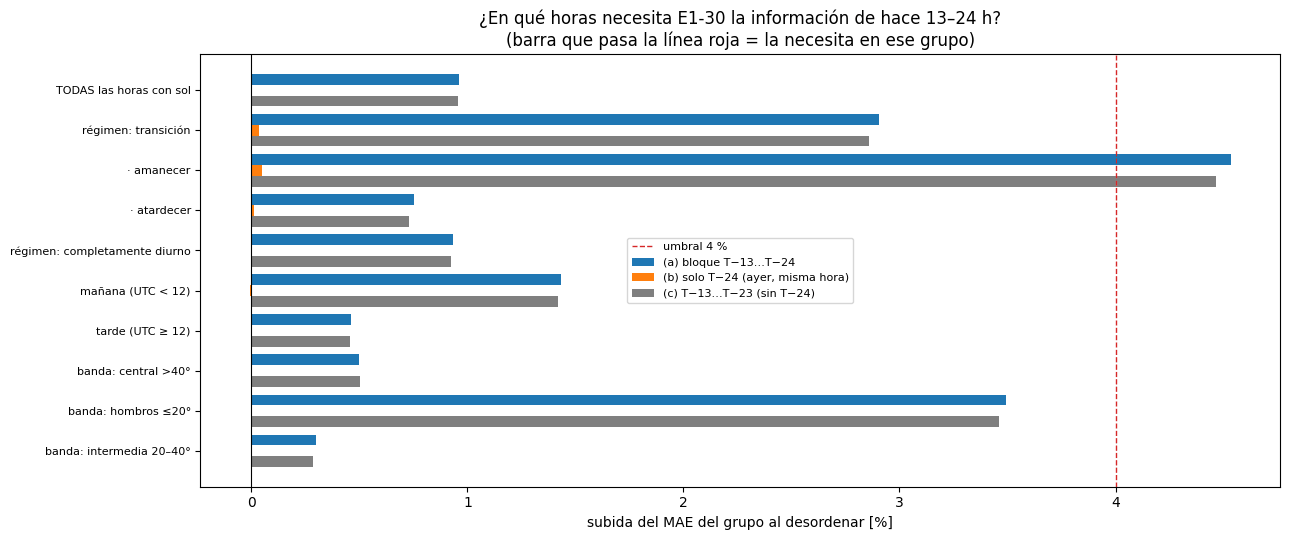


DECISIÓN
➜ El bloque no importa en la transición ni por la mañana. Siguiente: P3 con ventana de 12 h y criterio de no inferioridad.
➜ Solo T−24 (persistencia diaria) importa en: ningún grupo
Resultados en: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/diagnostico/depuracion_E1_30


In [ ]:
import os, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
try:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
except ImportError:
    pass

BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
RUTA_NPZ = (
    BASE_DIR
    / "resultados"
    / "ejecuciones"
    / "preparacion_bloque_difstats_20261006_180841"
    / "matrices_dif_elev_difstats.npz"
)
DIR_F1 = BASE_DIR / "resultados" / "diagnostico" / "fase1_intrahoraria"
DIR_B = BASE_DIR / "resultados" / "diagnostico" / "faseB_radiografia_E1"
DIR_D = BASE_DIR / "resultados" / "diagnostico" / "depuracion_E1_30"
DIR_M = DIR_D / "P1_modelos_oof"
assert (DIR_D / "P1_oof_E1_30.pkl").exists(), "Ejecuta antes P1"
SEMILLAS, N_REP, N_BOOT, UMBRAL_REL = (
    [42, 123],
    10,
    2000,
    4.0,
)  # importa si sube ≥ 4 % el MAE del grupo (IC95 > 0)
NOMBRES = [
    "DIF_media",
    "elevacion",
    "DIF_std",
    "DIF_rango",
    "DIF_ult15",
    "DIF_pend30",
    "DIF_acel60",
    "DIF_saltos",
    "SWD_cv",
]

# 1) Entradas (igual que P1)
mat = np.load(RUTA_NPZ)
X_tr = mat["X_train_DIF_elev_DIFstats_raw"].astype(np.float32)
y_tr = mat["y_train_difstats"].astype(np.float32).reshape(-1)
fechas_tr = pd.DatetimeIndex(mat["fechas_train"])
intrahora = pd.read_csv(
    DIR_F1 / "variables_intrahorarias_horarias.csv", index_col=0, parse_dates=True
).asfreq("h")

def a_ventanas(tabla, fechas_obj, columnas, lookback=24):
    f = pd.DatetimeIndex(fechas_obj).to_numpy(dtype="datetime64[ns]")
    idx = f[:, None] - np.arange(lookback, 0, -1).astype("timedelta64[h]")[None, :]
    vals = tabla.reindex(pd.DatetimeIndex(idx.reshape(-1)))[columnas].to_numpy(dtype=np.float32)
    return vals.reshape(len(f), lookback, len(columnas))

CANALES_E1 = ["DIF_ult15", "DIF_pend30", "DIF_acel60", "DIF_saltos", "SWD_cv"]

def construir(fechas_obj, X_base, canales):
    Xn = a_ventanas(intrahora, fechas_obj, canales)
    for j, c in enumerate(canales):
        hueco = np.isnan(Xn[:, :, j])
        Xn[:, :, j][hueco] = X_base[:, :, 0][hueco] if c == "DIF_ult15" else 0.0
    return np.concatenate([X_base, Xn], axis=2).astype(np.float32)

Xtr_E1 = construir(fechas_tr, X_tr, CANALES_E1)
assert Xtr_E1.shape[2] == len(NOMBRES)
H = pd.read_pickle(DIR_B / "tabla_horaria_E1.pkl")
TR = H[H["conjunto"] == "train"]
assert len(TR) == len(y_tr) and (TR.index == fechas_tr).all()
SOL = (TR["regimen"] != "noche").to_numpy()
OOF = pd.read_pickle(DIR_D / "P1_oof_E1_30.pkl")
mes = OOF["mes_pliegue"].to_numpy()
MESES = sorted(np.unique(mes))

# 2) Modelos de P1 y predicción con entradas alteradas
import torch, torch.nn as nn

class LSTMDIFStats(nn.Module):
    def __init__(self, n_features=4, hidden_size=64):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=n_features, hidden_size=hidden_size, num_layers=1, batch_first=True
        )
        self.head = nn.Sequential(nn.Linear(hidden_size, 32), nn.ReLU(), nn.Linear(32, 1))

    def forward(self, x):
        salida, _ = self.lstm(x)
        return self.head(salida[:, -1, :]).squeeze(-1)

MODELOS = {}
for s in SEMILLAS:
    for m in MESES:
        paq = torch.load(DIR_M / f"E1_30_{m}_s{s}.pt", map_location="cpu", weights_only=False)
        mod = LSTMDIFStats(n_features=Xtr_E1.shape[2])
        mod.load_state_dict(paq["model_state_dict"])
        mod.eval()
        MODELOS[(m, s)] = (mod, paq)

def predecir(m, s, X):
    mod, paq = MODELOS[(m, s)]
    Xe = ((X - paq["sx_mean"]) / paq["sx_scale"]).astype(np.float32)
    with torch.no_grad():
        return mod(torch.from_numpy(Xe)).numpy() * paq["sy_scale"] + paq["sy_mean"]


# Control: sin alterar nada, debe reproducir exactamente las predicciones guardadas en P1
for s in SEMILLAS:
    for m in MESES:
        dif = np.max(
            np.abs(predecir(m, s, Xtr_E1[mes == m]) - OOF.loc[mes == m, f"OOF30_s{s}"].to_numpy())
        )
        assert dif < 0.05, f"{m} s{s}: la predicción recalculada difiere {dif:.3f}"
print("✅ Control: los modelos de P1 reproducen sus predicciones guardadas")

# 3) Permutación de horas lejanas, medida por grupos
TODOS_CANALES = list(range(len(NOMBRES)))
PRUEBAS = {
    "(a) bloque T−13…T−24": list(range(0, 12)),  # posición 0 = T−24 · posición 11 = T−13
    "(b) solo T−24 (ayer, misma hora)": [0],
    "(c) T−13…T−23 (sin T−24)": list(range(1, 12)),
}

def error_alterado(pasos, rep):
    pred = np.zeros(len(y_tr))
    for m in MESES:
        idx = np.where(mes == m)[0]
        X = Xtr_E1[idx].copy()
        perm = np.random.default_rng(1000 * rep + MESES.index(m)).permutation(len(idx))
        sub = X[:, pasos, :]
        X[:, pasos, :] = sub[perm]
        pred[idx] = np.mean([predecir(m, s, X) for s in SEMILLAS], axis=0)
    return np.abs(pred - y_tr)

e_base = np.abs(OOF["OOF30_media"].to_numpy() - y_tr)
hora = TR.index.hour.to_numpy()
regimen = TR["regimen"].astype(str).to_numpy()
GRUPOS = {
    "TODAS las horas con sol": SOL,
    "régimen: transición": SOL & (regimen == "transicion"),
    "   · amanecer": SOL & (regimen == "transicion") & (hora < 12),
    "   · atardecer": SOL & (regimen == "transicion") & (hora >= 12),
    "régimen: completamente diurno": SOL & (regimen == "completamente_diurno"),
    "mañana (UTC < 12)": SOL & (hora < 12),
    "tarde (UTC ≥ 12)": SOL & (hora >= 12),
}
for b in sorted(TR["banda"].astype(str).unique()):
    GRUPOS[f"banda: {b}"] = SOL & (TR["banda"].astype(str).to_numpy() == b)

dias = TR.index.normalize().to_numpy()
rng = np.random.default_rng(0)

def ic_grupo(d, mascara):
    dd, dg = d[mascara], dias[mascara]
    u, inv = np.unique(dg, return_inverse=True)
    g = [np.where(inv == i)[0] for i in range(len(u))]
    medias = [
        dd[np.concatenate([g[i] for i in rng.integers(0, len(g), len(g))])].mean()
        for _ in range(N_BOOT)
    ]
    return np.percentile(medias, 2.5), np.percentile(medias, 97.5)

filas = []
for nombre_p, pasos in PRUEBAS.items():
    e_alt = np.mean([error_alterado(pasos, r) for r in range(N_REP)], axis=0)
    d = e_alt - e_base
    for nombre_g, msk in GRUPOS.items():
        lo, hi = ic_grupo(d, msk)
        base = e_base[msk].mean()
        pct = 100 * d[msk].mean() / base
        filas.append(
            {
                "prueba": nombre_p,
                "grupo": nombre_g,
                "horas": int(msk.sum()),
                "MAE del grupo": base,
                "subida [W/m²]": d[msk].mean(),
                "IC95": f"[{lo:+.2f}, {hi:+.2f}]",
                "subida (%)": pct,
                "¿importa?": "SÍ" if (lo > 0 and pct >= UMBRAL_REL) else "no",
            }
        )
    print(f"   hecho: {nombre_p}")
R = pd.DataFrame(filas)
print(
    "\n"
    + "=" * 110
    + "\nP2b · ¿DÓNDE USA E1-30 LAS HORAS LEJANAS? (subida del error al desordenarlas, meses no vistos de train)\n"
    + "=" * 110
)
print(
    f"'Importa' = sube el MAE del grupo al menos un {UMBRAL_REL:.0f} % y el IC95 no incluye el 0."
)
for nombre_p in PRUEBAS:
    print(f"\n{nombre_p}")
    display(R[R["prueba"] == nombre_p].drop(columns="prueba").set_index("grupo").round(2))

# 4) Gráfica: subida en % por grupo para cada prueba
orden = list(GRUPOS)
fig, ax = plt.subplots(figsize=(13, 5.5))
w = 0.27
colores = {
    "(a) bloque T−13…T−24": "tab:blue",
    "(b) solo T−24 (ayer, misma hora)": "tab:orange",
    "(c) T−13…T−23 (sin T−24)": "tab:gray",
}
for j, nombre_p in enumerate(PRUEBAS):
    t = R[R["prueba"] == nombre_p].set_index("grupo").loc[orden]
    ax.barh(
        np.arange(len(orden)) + (j - 1) * w,
        t["subida (%)"],
        w,
        color=colores[nombre_p],
        label=nombre_p,
    )
ax.axvline(UMBRAL_REL, color="tab:red", ls="--", lw=1, label=f"umbral {UMBRAL_REL:.0f} %")
ax.axvline(0, color="k", lw=0.8)
ax.set_yticks(range(len(orden)))
ax.set_yticklabels([o.strip() for o in orden], fontsize=8)
ax.invert_yaxis()
ax.set_xlabel("subida del MAE del grupo al desordenar [%]")
ax.legend(fontsize=8)
ax.set_title(
    "¿En qué horas necesita E1-30 la información de hace 13–24 h?\n(barra que pasa la línea roja = la necesita en ese grupo)"
)
plt.tight_layout()
plt.savefig(DIR_D / "P2b_horas_lejanas_por_grupo.png", dpi=120)
plt.show()

# 5) Decisión (criterio fijado antes)
A = R[R["prueba"] == "(a) bloque T−13…T−24"].set_index("grupo")
clave = ["régimen: transición", "   · amanecer", "   · atardecer", "mañana (UTC < 12)"]
importa = [g.strip() for g in clave if A.loc[g, "¿importa?"] == "SÍ"]
print("\n" + "=" * 110 + "\nDECISIÓN\n" + "=" * 110)
if importa:
    lect = (
        f"El bloque T−13…T−24 SÍ importa en: {', '.join(importa)}. Se MANTIENE la ventana de 24 h "
        "(no se hace P3). E1-30 queda como modelo depurado: usa todo lo que recibe."
    )
else:
    otros = [g.strip() for g in A.index if A.loc[g, "¿importa?"] == "SÍ"]
    lect = (
        "El bloque no importa en la transición ni por la mañana"
        + (f" (sí en: {', '.join(otros)})" if otros else "")
        + ". Siguiente: P3 con ventana de 12 h y criterio de no inferioridad."
    )
b = (
    R[(R["prueba"] == "(b) solo T−24 (ayer, misma hora)") & (R["¿importa?"] == "SÍ")]["grupo"]
    .str.strip()
    .tolist()
)
print("➜ " + lect)
print("➜ Solo T−24 (persistencia diaria) importa en: " + (", ".join(b) if b else "ningún grupo"))
R.to_csv(DIR_D / "P2b_horas_lejanas_por_grupo.csv", index=False)
with open(DIR_D / "P2b_decision.txt", "w") as f:
    f.write(lect + "\n")
print("Resultados en:", DIR_D)

**Resultados.** Ningún grupo cumple el criterio. En el conjunto de horas con sol, desordenar el bloque sube el MAE 0,26 W/m² (0,96 %); la mayor subida relativa se da al amanecer (0,16 W/m², 4,53 %), pero su IC95 [−0,05; +0,37] incluye el 0. Desordenar solo t−23 no cambia el error en ningún grupo, y el resto del bloque reproduce el efecto completo. Aunque la regla escrita llevaba a probar una ventana de 12 horas, se mantiene la de 24 horas por prudencia en el amanecer, una decisión conservadora sin respaldo estadístico estricto.

## 8. Exportación de datos para la búsqueda de hiperparámetros

> *La búsqueda con Optuna (H1 y H2) y la confirmación H3 se ejecutaron en el ordenador personal (apartado 5.5 y Anexo D de la memoria; fases 11 y 12 de la Tabla A1). Estas celdas solo exportan sus datos de entrada.*

### 8.1 Exportación de datos para la búsqueda de hiperparámetros

La búsqueda de hiperparámetros de E1-30 con Optuna (H1 y H2), que explora la tasa de aprendizaje, el tamaño de lote, las unidades, las capas y el weight decay, se ejecutó en el ordenador personal y solo con datos de entrenamiento. Esta celda exporta los datos de entrenamiento que necesita; la validación y el test no se exportan.

In [ ]:
import os
from pathlib import Path
import numpy as np, pandas as pd

try:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
except ImportError:
    pass

BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
RUTA_NPZ = (
    BASE_DIR
    / "resultados"
    / "ejecuciones"
    / "preparacion_bloque_difstats_20261006_180841"
    / "matrices_dif_elev_difstats.npz"
)
DIR_F1 = BASE_DIR / "resultados" / "diagnostico" / "fase1_intrahoraria"
DIR_B = BASE_DIR / "resultados" / "diagnostico" / "faseB_radiografia_E1"
DESTINO = BASE_DIR / "optuna_local" / "datos"
DESTINO.mkdir(parents=True, exist_ok=True)
mat = np.load(RUTA_NPZ)
fechas_tr = pd.DatetimeIndex(mat["fechas_train"])
np.savez_compressed(
    DESTINO / "entradas_train.npz",
    X_train=mat["X_train_DIF_elev_DIFstats_raw"].astype(np.float32),
    y_train=mat["y_train_difstats"].astype(np.float32).reshape(-1),
    fechas_train=fechas_tr.astype("int64").to_numpy(),
)  # nanosegundos (evita líos de formato)
intra = pd.read_csv(DIR_F1 / "variables_intrahorarias_horarias.csv", index_col=0, parse_dates=True)
intra = intra[
    (intra.index >= fechas_tr.min() - pd.Timedelta("25h")) & (intra.index <= fechas_tr.max())
]
intra.to_csv(DESTINO / "variables_intrahorarias.csv")
H = pd.read_pickle(DIR_B / "tabla_horaria_E1.pkl")
TR = H[H["conjunto"] == "train"][["regimen", "banda", "cielo", "persistencia", "real"]].copy()
assert len(TR) == len(fechas_tr) and (TR.index == fechas_tr).all(), "La tabla no cuadra con el .npz"
TR.index.name = "fecha"
TR.to_csv(DESTINO / "tabla_train.csv")
print("Exportado en:", DESTINO)
for f in sorted(DESTINO.iterdir()):
    print(f"   {f.name:30s} {f.stat().st_size/1e6:.1f} MB")
print(
    f"Train: {len(fechas_tr)} horas ({fechas_tr.min()} → {fechas_tr.max()}). Validación y test NO se exportan."
)

Exportado en: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/optuna_local/datos
   entradas_train.npz             0.1 MB
   tabla_train.csv                0.5 MB
   variables_intrahorarias.csv    0.6 MB
Train: 5149 horas (2023-12-30 00:00:00 → 2024-07-31 23:00:00). Validación y test NO se exportan.


### 8.2 Exportación de la validación para la confirmación

La confirmación en validación de la configuración elegida por la búsqueda (H3) también se ejecutó en el ordenador personal, y esta celda exporta los datos de agosto y septiembre de 2024 que necesita, sin el test. Esa configuración no confirmó su mejora frente a E1-30, que se mantuvo como modelo de referencia.

In [ ]:
import os
from pathlib import Path
import numpy as np, pandas as pd

try:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
except ImportError:
    pass

BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
RUTA_NPZ = (
    BASE_DIR
    / "resultados"
    / "ejecuciones"
    / "preparacion_bloque_difstats_20261006_180841"
    / "matrices_dif_elev_difstats.npz"
)
DIR_F1 = BASE_DIR / "resultados" / "diagnostico" / "fase1_intrahoraria"
DIR_B = BASE_DIR / "resultados" / "diagnostico" / "faseB_radiografia_E1"
DESTINO = BASE_DIR / "optuna_local" / "datos_validacion"
DESTINO.mkdir(parents=True, exist_ok=True)
mat = np.load(RUTA_NPZ)
fechas_va = pd.DatetimeIndex(mat["fechas_validation"])
assert fechas_va.max() < pd.Timestamp("2024-10-01"), "Esto incluiría el test"
np.savez_compressed(
    DESTINO / "entradas_validacion.npz",
    X_val=mat["X_validation_DIF_elev_DIFstats_raw"].astype(np.float32),
    y_val=mat["y_validation_difstats"].astype(np.float32).reshape(-1),
    fechas_val=fechas_va.astype("int64").to_numpy(),
)
intra = pd.read_csv(DIR_F1 / "variables_intrahorarias_horarias.csv", index_col=0, parse_dates=True)
intra = intra[
    (intra.index >= fechas_va.min() - pd.Timedelta("25h")) & (intra.index <= fechas_va.max())
]
intra.to_csv(DESTINO / "variables_intrahorarias_val.csv")
H = pd.read_pickle(DIR_B / "tabla_horaria_E1.pkl")
VA = H[H["conjunto"] == "validation"][["regimen", "banda", "cielo", "persistencia", "real"]].copy()
assert len(VA) == len(fechas_va) and (VA.index == fechas_va).all(), "La tabla no cuadra con el .npz"
VA.index.name = "fecha"
VA.to_csv(DESTINO / "tabla_validacion.csv")
print("Exportado en:", DESTINO)
for f in sorted(DESTINO.iterdir()):
    print(f"   {f.name:32s} {f.stat().st_size/1e6:.2f} MB")
print(
    f"Validación: {len(fechas_va)} horas ({fechas_va.min()} → {fechas_va.max()}). El test NO se exporta."
)

Mounted at /content/drive
Exportado en: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/optuna_local/datos_validacion
   entradas_validacion.npz          0.03 MB
   tabla_validacion.csv             0.13 MB
   variables_intrahorarias_val.csv  0.18 MB
Validación: 1464 horas (2024-08-01 00:00:00 → 2024-09-30 23:00:00). El test NO se exporta.


## 9. Bandas de incertidumbre

> *Las bandas de incertidumbre (D1) quedan fuera del alcance de la memoria (fase 13 de la Tabla A1), igual que sus criterios de aceptación; se conservan como registro del trabajo y no cambian ningún modelo. Sí se utiliza la tabla de referencias del final de la sección: las mejoras de E1-30 sobre la persistencia simple (48,4 %) y sobre la inteligente horaria (28,7 %) del apartado 5.3.3.*

### 9.1 Bandas de incertidumbre

Se añaden a las predicciones de validación de E1-30 bandas de incertidumbre al 80 % (nivel principal) y al 90 % mediante predicción conformal normalizada (D1), sin cambiar la predicción puntual. Un modelo HGB de riesgo, entrenado con los errores fuera de muestra de P1, estima el tamaño del error a partir de la elevación, la predicción de E1-30 y descriptores de la DIF y de la variabilidad de la global en la última hora; el factor conformal se calibra en entrenamiento. Las bandas se aceptan si su cobertura se ajusta al nivel nominal, en conjunto y por régimen, banda y amanecer, y si mejoran la puntuación de Winkler de una banda de ancho fijo.

Mounted at /content/drive
0) COMPROBACIONES
   ✔ todos los archivos están en Drive
   ✔ OOF de P1: 5149 horas, todas con predicción · 7 meses fuera: 2024-01, 2024-02, 2024-03, 2024-04, 2024-05, 2024-06, 2024-07
   ✔ E1-30 en validación (5 semillas, horas con sol): MAE 23.25 W/m² (esperado 23.25)

1) Convención horaria: desfase +30 min (diferencia media con el canal de elevación 0.09°)

2) Modelo de riesgo: suelo de σ̂ = 0.69 W/m² · semilla 0 vs 42: diferencia máxima 0.000000 W/m² (determinista ✔)
3) Nivel 80%: q(D1) = 1.991 · q(ancho fijo) = 43.54 W/m² · cobertura en train de D1 80.1% (por construcción)
3) Nivel 90%: q(D1) = 2.795 · q(ancho fijo) = 70.21 W/m² · cobertura en train de D1 90.1% (por construcción)

D1 · BANDAS EN VALIDACIÓN (ago–sep 2024, horas con sol) — D1 (con riesgo) vs ancho fijo


,cobertura D1 (%),cobertura fijo (%),ancho D1,ancho fijo,Winkler D1,Winkler fijo,cambio Winkler (D1 − fijo),IC95,peor grupo controlado,1 cobertura global,2 cobertura por grupo,3 Winkler mejor,4 Spearman > 0,veredicto
nivel,,,,,,,,,,,,,,
80%,82.81,81.56,82.11,80.92,113.78,134.08,-20.30,"[-27.08, -13.43]",banda: central >40° (81.0 %),True,True,True,True,SE ACEPTA D1
90%,91.52,91.74,114.85,127.27,142.44,171.00,-28.56,"[-39.50, -17.44]",banda: hombros ≤20° (91.4 %),True,True,True,True,SE ACEPTA D1


Spearman entre σ̂ y el error real: ρ = 0.58 (p = 2.7e-81)

Cobertura por grupo (%):


nivel                           80%         90%      
método                           D1  fijo    D1  fijo
grupo                                                
GLOBAL                         82.8  81.6  91.5  91.7
régimen: transicion            87.4  93.3  91.6  93.3
régimen: completamente_diurno  82.1  79.7  91.5  91.5
amanecer                       95.0  98.3  96.7  98.3
banda: central >40°            81.0  68.8  91.7  83.9
banda: hombros ≤20°            84.1  95.3  91.4  97.3
banda: intermedia 20–40°       82.6  75.6  91.5  90.9
cielo: amanecer/atardecer      87.4  93.3  91.6  93.3
cielo: cubierto                81.1  73.6  90.6  90.6
cielo: despejado               91.4  94.1  97.8  97.3
cielo: nubes rotas             77.9  72.8  89.0  88.4
cielo: velado                  84.3  87.6  91.0  95.5

Ancho medio por grupo [W/m²] (D1 debería ser estrecho con cielo estable y ancho con nubes):


nivel                            80%          90%       
método                            D1  fijo     D1   fijo
grupo                                                   
GLOBAL                          82.1  80.9  114.9  127.3
régimen: transicion             10.2  50.4   13.1   77.0
régimen: completamente_diurno   93.3  85.7  130.7  135.1
amanecer                        12.8  49.4   15.8   76.0
banda: central >40°            126.9  87.1  177.9  140.4
banda: hombros ≤20°             33.1  71.0   45.9  106.5
banda: intermedia 20–40°       104.0  87.1  145.5  140.1
cielo: amanecer/atardecer       10.2  50.4   13.1   77.0
cielo: cubierto                110.1  85.3  152.1  133.2
cielo: despejado                62.4  86.9   87.6  138.1
cielo: nubes rotas             108.3  86.3  151.9  136.6
cielo: velado                   73.6  80.3  103.2  122.4

Referencias para la memoria (validación, horas con sol):


,MAE [W/m²],ventaja de E1-30 (%)
E1-30 (5 semillas),23.25,0.00
persistencia simple,45.03,48.36
persistencia inteligente,32.63,28.74


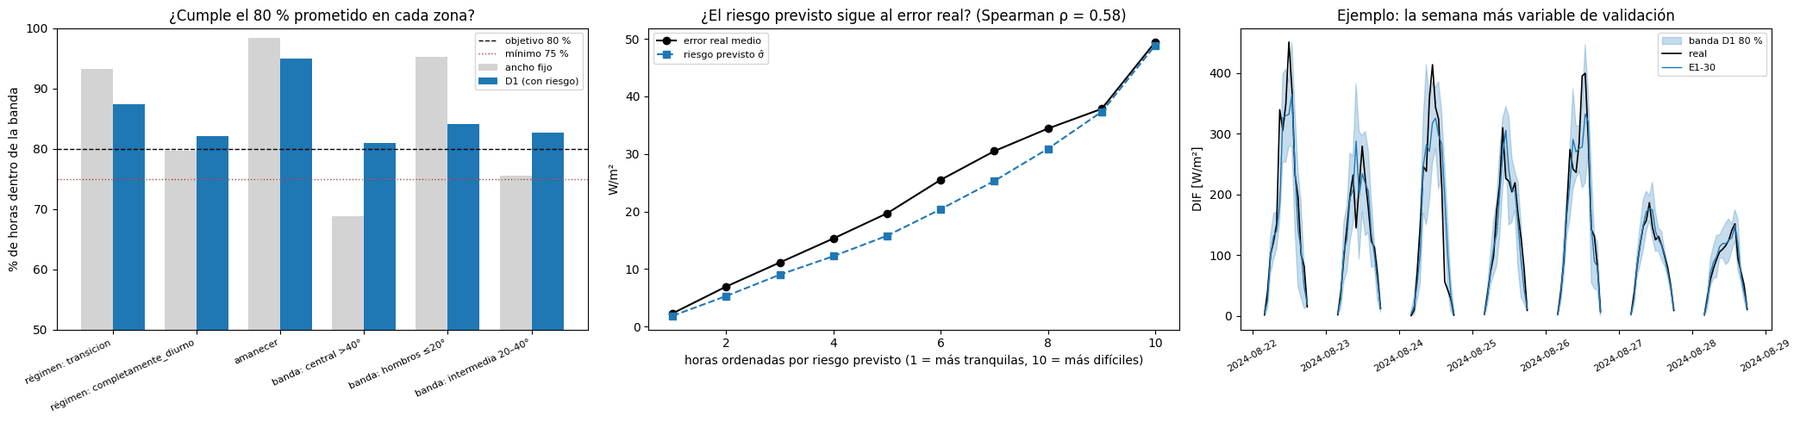


D1 · BANDAS DE INCERTIDUMBRE PARA E1-30 (validación ago–sep 2024, horas con sol)
80%: cobertura D1 82.8 % · ancho medio 82.1 W/m² (fijo 80.9) · Winkler -20.30 [-27.08, -13.43] · peor grupo banda: central >40° (81.0 %) → SE ACEPTA D1
90%: cobertura D1 91.5 % · ancho medio 114.9 W/m² (fijo 127.3) · Winkler -28.56 [-39.50, -17.44] · peor grupo banda: hombros ≤20° (91.4 %) → SE ACEPTA D1
Spearman σ̂ vs error real: 0.58
MAE E1-30 23.25 · persistencia 45.03 · persistencia inteligente 32.63 W/m²

Resultados en: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/diagnostico/D1_bandas


In [ ]:
import os, sys, subprocess, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
try:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
except ImportError:
    pass
try:
    import pvlib
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pvlib"], check=True)
    import pvlib
from scipy.stats import spearmanr
from sklearn.ensemble import HistGradientBoostingRegressor
import joblib
BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
DIAG = BASE_DIR / "resultados" / "diagnostico"
RUTA_NPZ = (
    BASE_DIR
    / "resultados"
    / "ejecuciones"
    / "preparacion_bloque_difstats_20261006_180841"
    / "matrices_dif_elev_difstats.npz"
)
RUTA_INTRA = DIAG / "fase1_intrahoraria" / "variables_intrahorarias_horarias.csv"
RUTA_TABLA = DIAG / "faseB_radiografia_E1" / "tabla_horaria_E1.pkl"
RUTA_OOF = DIAG / "depuracion_E1_30" / "P1_oof_E1_30.pkl"
DIR_5C = DIAG / "faseC_regularizacion" / "C5c_confirmacion"
SALIDA = DIAG / "D1_bandas"
SALIDA.mkdir(parents=True, exist_ok=True)
SEMILLAS = [42, 123, 2024, 7, 99]
NIVELES = [0.80, 0.90]  # 80 % principal · 90 % secundario
N_BOOT = 2000
LAT, LON, ALT = 51.9711, 4.9267, 0  # Cabauw (BSRN CAB)
MAE_E1_30_COLAB = 23.25

# 0) Comprobaciones antes de calcular nada
print("0) COMPROBACIONES")
faltan = [
    str(r)
    for r in [RUTA_NPZ, RUTA_INTRA, RUTA_TABLA, RUTA_OOF]
    + [DIR_5C / f"pred_validation_s{s}.npz" for s in SEMILLAS]
    if not r.exists()
]
assert not faltan, "No encuentro:\n  " + "\n  ".join(faltan)
print("   ✔ todos los archivos están en Drive")
mat = np.load(RUTA_NPZ)
X_tr, X_va = mat["X_train_DIF_elev_DIFstats_raw"], mat["X_validation_DIF_elev_DIFstats_raw"]
y_tr = mat["y_train_difstats"].astype(float).reshape(-1)
y_va = mat["y_validation_difstats"].astype(float).reshape(-1)
f_tr, f_va = pd.DatetimeIndex(mat["fechas_train"]), pd.DatetimeIndex(mat["fechas_validation"])
assert f_va.max() < pd.Timestamp("2024-10-01"), "Esto incluiría el test"
T = pd.read_pickle(RUTA_TABLA)
TR, VA = T[T["conjunto"] == "train"].copy(), T[T["conjunto"] == "validation"].copy()
assert (TR.index == f_tr).all() and (
    VA.index == f_va
).all(), "La tabla horaria no cuadra con el .npz"
OOF = pd.read_pickle(RUTA_OOF)
assert (OOF.index == f_tr).all(), "Los OOF de P1 no cuadran con las fechas de train"
assert OOF["OOF30_media"].notna().all(), "Hay horas de train sin predicción fuera de muestra"
MESES = sorted(OOF["mes_pliegue"].unique())
print(
    f"   ✔ OOF de P1: {len(OOF)} horas, todas con predicción · {len(MESES)} meses fuera: {', '.join(MESES)}"
)
pred_va = np.mean([np.load(DIR_5C / f"pred_validation_s{s}.npz")["ep30"] for s in SEMILLAS], axis=0)
sol_tr = (TR["regimen"] != "noche").to_numpy()
sol_va = (VA["regimen"] != "noche").to_numpy()
mae_va = np.abs(pred_va[sol_va] - y_va[sol_va]).mean()
print(
    f"   ✔ E1-30 en validación (5 semillas, horas con sol): MAE {mae_va:.2f} W/m² (esperado {MAE_E1_30_COLAB})"
)
assert (
    abs(mae_va - MAE_E1_30_COLAB) < 0.05
), "Las predicciones de validación no reproducen el MAE de E1-30"

# 1) Variables del modelo de riesgo (solo información conocida antes de predecir)
loc = pvlib.location.Location(LAT, LON, tz="UTC", altitude=ALT)

def a_utc(f):
    f = pd.DatetimeIndex(f)
    return f.tz_localize("UTC") if f.tz is None else f.tz_convert("UTC")


# ¿A qué momento de la hora corresponde cada fecha? Se elige el desfase que reproduce el canal de elevación
# de la última hora de la ventana (T−1); así la elevación de la hora objetivo se calcula con la misma convención.
elev_T1 = np.concatenate([X_tr[:, -1, 1], X_va[:, -1, 1]]).astype(float)
f_T1 = a_utc(np.concatenate([f_tr, f_va])) - pd.Timedelta("1h")
ok = elev_T1 > 5
dif_desfase = {
    d: np.abs(
        loc.get_solarposition(f_T1 + pd.Timedelta(minutes=d))["apparent_elevation"].to_numpy()[ok]
        - elev_T1[ok]
    ).mean()
    for d in (-30, 0, 30)
}
DESFASE = min(dif_desfase, key=dif_desfase.get)
print(
    f"\n1) Convención horaria: desfase {DESFASE:+d} min (diferencia media con el canal de elevación {dif_desfase[DESFASE]:.2f}°)"
)
assert dif_desfase[DESFASE] < 1.5, f"La elevación de pvlib no cuadra con la del .npz: {dif_desfase}"
intra = pd.read_csv(RUTA_INTRA, index_col=0, parse_dates=True).asfreq("h")

def variables(X, fechas, pred):
    f = a_utc(fechas) + pd.Timedelta(minutes=DESFASE)
    previa = intra.reindex(pd.DatetimeIndex(fechas) - pd.Timedelta("1h"))
    V = pd.DataFrame(
        {
            "elevacion_objetivo": loc.get_solarposition(f)["apparent_elevation"].to_numpy(),
            "prediccion": pred,
            "DIF_media_T1": X[:, -1, 0],
            "DIF_std_T1": X[:, -1, 2],
            "DIF_rango_T1": X[:, -1, 3],
            "DIF_saltos_T1": previa["DIF_saltos"]
            .fillna(0)
            .to_numpy(),  # mismo relleno que en las entradas de E1
            "SWD_cv_T1": previa["SWD_cv"].fillna(0).to_numpy(),
        },
        index=fechas,
    )
    cs = loc.get_clearsky(f, model="ineichen")["dhi"].to_numpy()
    cs_T1 = loc.get_clearsky(f - pd.Timedelta("1h"), model="ineichen")["dhi"].to_numpy()
    return V.astype(float), cs, cs_T1

V_tr, cs_tr, cs1_tr = variables(X_tr, f_tr, OOF["OOF30_media"].to_numpy())
V_va, cs_va, cs1_va = variables(X_va, f_va, pred_va)


# Persistencia inteligente (referencia para la memoria): DIF(T−1) · DIFcs(T) / DIFcs(T−1)
# Si el cielo despejado en T−1 es casi 0 (amanecer), se usa la persistencia simple.
def pers_inteligente(V, cs, cs1):
    p = V["DIF_media_T1"].to_numpy() * np.where(cs1 > 5, cs / np.maximum(cs1, 5), 1.0)
    return np.clip(p, 0, None)

pi_va = pers_inteligente(V_va, cs_va, cs1_va)


# 2) Modelo de riesgo: aprende el TAMAÑO del error de E1-30
def nuevo_riesgo(semilla=0):
    return HistGradientBoostingRegressor(
        loss="absolute_error",
        max_iter=200,
        learning_rate=0.05,
        min_samples_leaf=50,
        early_stopping=False,
        random_state=semilla,
    )

Vs, err_tr = V_tr[sol_tr], np.abs(y_tr - OOF["OOF30_media"].to_numpy())[sol_tr]
mes_s, f_s = OOF["mes_pliegue"].to_numpy()[sol_tr], f_tr[sol_tr]
SUELO = float(np.percentile(err_tr, 5))

# Fase A · σ̂ honesto en train: cada mes lo estima un modelo que no lo ha visto (purga de 24 h)
sig_oof = np.full(len(Vs), np.nan)
for m in MESES:
    fuera = mes_s == m
    fin = f_s[fuera].max()
    entrena = ~fuera & ~((f_s > fin) & (f_s <= fin + pd.Timedelta("24h")))
    sig_oof[fuera] = nuevo_riesgo().fit(Vs[entrena], err_tr[entrena]).predict(Vs[fuera])
sig_oof = np.maximum(sig_oof, SUELO)

# Fase B · modelo final con todo train → σ̂ de validación
riesgo = nuevo_riesgo(0).fit(Vs, err_tr)
sig_va = np.maximum(riesgo.predict(V_va[sol_va]), SUELO)
dif_sem = np.abs(
    sig_va - np.maximum(nuevo_riesgo(42).fit(Vs, err_tr).predict(V_va[sol_va]), SUELO)
).max()
print(
    f"\n2) Modelo de riesgo: suelo de σ̂ = {SUELO:.2f} W/m² · semilla 0 vs 42: diferencia máxima {dif_sem:.6f} W/m² "
    f"({'determinista ✔' if dif_sem < 1e-9 else 'NO determinista'})"
)
joblib.dump(
    {"modelo": riesgo, "suelo": SUELO, "desfase_min": DESFASE, "variables": list(V_tr.columns)},
    SALIDA / "D1_modelo_riesgo.joblib",
)


# 3) Calibración conformal (en train) y bandas (en validación)
def cuantil_conformal(s, nivel):
    n = len(s)
    return float(np.quantile(s, min(1.0, np.ceil((n + 1) * nivel) / n), method="higher"))

y, p = y_va[sol_va], pred_va[sol_va]
e_va = np.abs(y - p)
BANDAS, Q = {}, {}
for nivel in NIVELES:
    q_d1 = cuantil_conformal(err_tr / sig_oof, nivel)  # D1: puntuación normalizada
    q_fijo = cuantil_conformal(err_tr, nivel)  # referencia: ancho fijo
    Q[nivel] = (q_d1, q_fijo)
    BANDAS[("D1", nivel)] = (np.maximum(0, p - q_d1 * sig_va), p + q_d1 * sig_va)
    BANDAS[("fijo", nivel)] = (np.maximum(0, p - q_fijo), p + np.full_like(p, q_fijo))
    cob_tr = np.mean(err_tr <= q_d1 * sig_oof)
    print(
        f"3) Nivel {nivel:.0%}: q(D1) = {q_d1:.3f} · q(ancho fijo) = {q_fijo:.2f} W/m² · cobertura en train de D1 {cob_tr:.1%} (por construcción)"
    )

def winkler(L, U, y, alfa):
    return (U - L) + (2 / alfa) * np.clip(L - y, 0, None) + (2 / alfa) * np.clip(y - U, 0, None)


# 4) Evaluación en validación
inf = VA[sol_va]
hora = inf.index.hour.to_numpy()
GRUPOS = {"GLOBAL": np.ones(len(y), bool)}
for g in ["transicion", "completamente_diurno"]:
    GRUPOS[f"régimen: {g}"] = (inf["regimen"] == g).to_numpy()
GRUPOS["amanecer"] = (inf["regimen"] == "transicion").to_numpy() & (hora < 12)
for g in sorted(inf["banda"].astype(str).unique()):
    GRUPOS[f"banda: {g}"] = (inf["banda"].astype(str) == g).to_numpy()
for g in sorted(inf["cielo"].astype(str).unique()):
    GRUPOS[f"cielo: {g}"] = (inf["cielo"].astype(str) == g).to_numpy()
CONTROLADOS = [k for k in GRUPOS if k.startswith(("régimen", "banda")) or k == "amanecer"]
u, inv = np.unique(inf.index.normalize(), return_inverse=True)
dias = [np.where(inv == i)[0] for i in range(len(u))]
rng = np.random.default_rng(0)
remuestras = [
    np.concatenate([dias[i] for i in rng.integers(0, len(dias), len(dias))]) for _ in range(N_BOOT)
]

def ic(d):
    medias = [d[r].mean() for r in remuestras]
    return d.mean(), np.percentile(medias, 2.5), np.percentile(medias, 97.5)

rho, p_rho = spearmanr(sig_va, e_va)
filas_res, filas_des, veredictos = [], [], {}
for nivel in NIVELES:
    alfa = 1 - nivel
    w = {}
    for metodo in ["D1", "fijo"]:
        L, U = BANDAS[(metodo, nivel)]
        dentro = (y >= L) & (y <= U)
        w[metodo] = winkler(L, U, y, alfa)
        for g, msk in GRUPOS.items():
            filas_des.append(
                {
                    "nivel": f"{nivel:.0%}",
                    "método": metodo,
                    "grupo": g,
                    "horas": int(msk.sum()),
                    "cobertura (%)": 100 * dentro[msk].mean(),
                    "ancho medio [W/m²]": (U - L)[msk].mean(),
                    "Winkler": w[metodo][msk].mean(),
                }
            )
    D = pd.DataFrame([f for f in filas_des if f["nivel"] == f"{nivel:.0%}"])
    d1 = D[D["método"] == "D1"].set_index("grupo")
    c, lo, hi = ic(w["D1"] - w["fijo"])
    obj = 100 * nivel
    ok1 = obj - 3 <= d1.loc["GLOBAL", "cobertura (%)"] <= obj + 3
    ok2 = (d1.loc[CONTROLADOS, "cobertura (%)"] >= obj - 5).all()
    ok3 = hi < 0
    ok4 = rho > 0
    veredictos[nivel] = (
        "SE ACEPTA D1"
        if (ok1 and ok2 and ok3 and ok4)
        else ("ANCHO FIJO (D1 no aporta)" if (ok1 and ok2 and not ok3) else "NO SE ACEPTA")
    )
    filas_res.append(
        {
            "nivel": f"{nivel:.0%}",
            "cobertura D1 (%)": d1.loc["GLOBAL", "cobertura (%)"],
            "cobertura fijo (%)": D[(D["método"] == "fijo") & (D["grupo"] == "GLOBAL")][
                "cobertura (%)"
            ].iloc[0],
            "ancho D1": d1.loc["GLOBAL", "ancho medio [W/m²]"],
            "ancho fijo": D[(D["método"] == "fijo") & (D["grupo"] == "GLOBAL")][
                "ancho medio [W/m²]"
            ].iloc[0],
            "Winkler D1": w["D1"].mean(),
            "Winkler fijo": w["fijo"].mean(),
            "cambio Winkler (D1 − fijo)": c,
            "IC95": f"[{lo:+.2f}, {hi:+.2f}]",
            "peor grupo controlado": f"{d1.loc[CONTROLADOS, 'cobertura (%)'].idxmin()} "
            f"({d1.loc[CONTROLADOS, 'cobertura (%)'].min():.1f} %)",
            "1 cobertura global": ok1,
            "2 cobertura por grupo": ok2,
            "3 Winkler mejor": ok3,
            "4 Spearman > 0": ok4,
            "veredicto": veredictos[nivel],
        }
    )
R = pd.DataFrame(filas_res).set_index("nivel")
DES = pd.DataFrame(filas_des)
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 30)
print(
    "\n"
    + "=" * 100
    + "\nD1 · BANDAS EN VALIDACIÓN (ago–sep 2024, horas con sol) — D1 (con riesgo) vs ancho fijo\n"
    + "=" * 100
)
display(R.round(2))
print(f"Spearman entre σ̂ y el error real: ρ = {rho:.2f} (p = {p_rho:.1e})")
print("\nCobertura por grupo (%):")
display(
    DES.pivot_table(index="grupo", columns=["nivel", "método"], values="cobertura (%)")
    .loc[list(GRUPOS)]
    .round(1)
)
print("Ancho medio por grupo [W/m²] (D1 debería ser estrecho con cielo estable y ancho con nubes):")
display(
    DES.pivot_table(index="grupo", columns=["nivel", "método"], values="ancho medio [W/m²]")
    .loc[list(GRUPOS)]
    .round(1)
)
mae_p = np.nanmean(np.abs(inf["persistencia"].to_numpy() - y))
mae_pi = np.abs(pi_va[sol_va] - y).mean()
REF = pd.DataFrame(
    {"MAE [W/m²]": [e_va.mean(), mae_p, mae_pi]},
    index=["E1-30 (5 semillas)", "persistencia simple", "persistencia inteligente"],
)
REF["ventaja de E1-30 (%)"] = 100 * (1 - e_va.mean() / REF["MAE [W/m²]"])
print("Referencias para la memoria (validación, horas con sol):")
display(REF.round(2))

# 5) Gráficas
fig, axs = plt.subplots(1, 3, figsize=(21, 5))
grp = CONTROLADOS
x = np.arange(len(grp))
wb = 0.38
cob = (
    DES[DES["nivel"] == "80%"]
    .pivot_table(index="grupo", columns="método", values="cobertura (%)")
    .loc[grp]
)
axs[0].bar(x - wb / 2, cob["fijo"], wb, color="lightgray", label="ancho fijo")
axs[0].bar(x + wb / 2, cob["D1"], wb, color="tab:blue", label="D1 (con riesgo)")
axs[0].axhline(80, color="k", ls="--", lw=1, label="objetivo 80 %")
axs[0].axhline(75, color="tab:red", ls=":", lw=1, label="mínimo 75 %")
axs[0].set_xticks(x)
axs[0].set_xticklabels(grp, rotation=25, ha="right", fontsize=8)
axs[0].set_ylim(50, 100)
axs[0].set_ylabel("% de horas dentro de la banda")
axs[0].legend(fontsize=8)
axs[0].set_title("¿Cumple el 80 % prometido en cada zona?")
orden = np.argsort(sig_va)
trozos = np.array_split(orden, 10)
axs[1].plot(
    range(1, 11), [e_va[t].mean() for t in trozos], "o-", color="black", label="error real medio"
)
axs[1].plot(
    range(1, 11),
    [sig_va[t].mean() for t in trozos],
    "s--",
    color="tab:blue",
    label="riesgo previsto σ̂",
)
axs[1].set_xlabel("horas ordenadas por riesgo previsto (1 = más tranquilas, 10 = más difíciles)")
axs[1].set_ylabel("W/m²")
axs[1].legend(fontsize=8)
axs[1].set_title(f"¿El riesgo previsto sigue al error real? (Spearman ρ = {rho:.2f})")
serie = pd.DataFrame(
    {"real": y, "pred": p, "L": BANDAS[("D1", 0.80)][0], "U": BANDAS[("D1", 0.80)][1]},
    index=inf.index,
)
d_ini = pd.Series(e_va, index=inf.index).resample("7D").std().idxmax()
tramo = serie[(serie.index >= d_ini) & (serie.index < d_ini + pd.Timedelta("7D"))].asfreq("h")
axs[2].fill_between(
    tramo.index, tramo["L"], tramo["U"], color="tab:blue", alpha=0.25, label="banda D1 80 %"
)
axs[2].plot(tramo.index, tramo["real"], color="black", lw=1.2, label="real")
axs[2].plot(tramo.index, tramo["pred"], color="tab:blue", lw=1, label="E1-30")
axs[2].set_ylabel("DIF [W/m²]")
axs[2].legend(fontsize=8)
axs[2].tick_params(axis="x", labelrotation=30, labelsize=8)
axs[2].set_title("Ejemplo: la semana más variable de validación")
plt.tight_layout()
plt.savefig(SALIDA / "D1_bandas.png", dpi=120)
plt.show()

# 6) Guardado y veredicto
out = pd.DataFrame({"real": y, "E1_30": p, "sigma_riesgo": sig_va}, index=inf.index)
for (metodo, nivel), (L, U) in BANDAS.items():
    out[f"{metodo}_{int(100*nivel)}_inf"], out[f"{metodo}_{int(100*nivel)}_sup"] = L, U
out.to_csv(SALIDA / "D1_bandas_validacion.csv")
R.to_csv(SALIDA / "D1_resumen.csv")
DES.to_csv(SALIDA / "D1_desglose.csv", index=False)
REF.to_csv(SALIDA / "D1_referencias.csv")
texto = "\n".join(
    ["D1 · BANDAS DE INCERTIDUMBRE PARA E1-30 (validación ago–sep 2024, horas con sol)", "=" * 80]
    + [
        f"{n}: cobertura D1 {r['cobertura D1 (%)']:.1f} % · ancho medio {r['ancho D1']:.1f} W/m² (fijo {r['ancho fijo']:.1f}) · "
        f"Winkler {r['cambio Winkler (D1 − fijo)']:+.2f} {r['IC95']} · peor grupo {r['peor grupo controlado']} → {r['veredicto']}"
        for n, r in R.iterrows()
    ]
    + [
        f"Spearman σ̂ vs error real: {rho:.2f}",
        f"MAE E1-30 {e_va.mean():.2f} · persistencia {mae_p:.2f} · persistencia inteligente {mae_pi:.2f} W/m²",
    ]
)
(SALIDA / "INFORME_D1.txt").write_text(texto, encoding="utf-8")
print("\n" + texto + "\n\nResultados en:", SALIDA)

**Resultados.** Se cumplen todos los criterios en los dos niveles y las bandas se aceptan.

- Al 80 %, la cobertura es del 82,8 % y la puntuación de Winkler mejora en 20,30 W/m² a la de ancho fijo (IC95 [−27,08; −13,43]); al 90 %, del 91,5 % y en 28,56 W/m² (IC95 [−39,50; −17,44]).
- La correlación de Spearman entre el riesgo previsto y el error real es de 0,58.
- Al 80 %, el ancho medio es de 10,2 W/m² en la transición y de 126,9 W/m² en la banda central, frente a 50,4 y 87,1 W/m² con ancho fijo.
- E1-30 (23,25 W/m²) mejora un 48,4 % a la persistencia simple (45,03 W/m²) y un 28,7 % a la persistencia inteligente horaria (32,63 W/m²).

## 10. Radiografía del error y cielo previo

> *Se utiliza en la memoria: apartados 5.3.2 (concentración del error por tipo de cielo) y 5.3.4 y Tabla B1 (C7), y fases 14 y 15 de la Tabla A1.*

### 10.1 Radiografía del error de E1-30 por régimen y cielo

Se describe el error de E1-30 en las horas con sol de validación (media de cinco semillas, época 30) y, como contraste con más horas, en sus predicciones fuera de muestra de entrenamiento, por régimen solar y por tipo de cielo de la hora objetivo (R1). Además del MAE y el sesgo, se calculan el nMAE (MAE dividido por la DIF media del grupo), el porcentaje de horas con error superior a 50 W/m² y la concentración del error; no se entrena ningún modelo.

Comprobación: MAE de E1-30 en validación (horas con sol) = 23.25 W/m² (esperado 23.25)

E1-30 · VALIDACIÓN (ago–sep 2024) · por régimen (horas con sol)


,horas,% de las horas,DIF media,DIF mediana,DIF P90,MAE,RMSE,nMAE (%),R²,sesgo,% horas error grande,% del error total,% error en el peor 10 % de horas,RMSE/MAE,episodios error grande,% horas grandes en rachas ≥2 h
TODAS,884.0,100.0,141.8,127.7,290.8,23.3,36.3,16.4,0.9,-2.4,14.3,100.0,39.2,1.6,88.0,52.4
transicion,119.0,13.5,7.3,4.8,16.2,2.7,3.7,36.7,0.7,-0.4,0.0,1.5,32.1,1.4,0.0,NaN
completamente_diurno,765.0,86.5,162.7,145.7,307.9,26.5,39.0,16.3,0.8,-2.7,16.5,98.5,36.1,1.5,88.0,52.4



E1-30 · VALIDACIÓN (ago–sep 2024) · por tipo de cielo (horas con sol)


,horas,% de las horas,DIF media,DIF mediana,DIF P90,MAE,RMSE,nMAE (%),R²,sesgo,% horas error grande,% del error total,% error en el peor 10 % de horas,RMSE/MAE,episodios error grande,% horas grandes en rachas ≥2 h
TODAS,884.0,100.0,141.8,127.7,290.8,23.3,36.3,16.4,0.9,-2.4,14.3,100.0,39.2,1.6,88.0,52.4
despejado,185.0,20.9,125.2,119.0,191.4,14.5,24.9,11.6,0.8,5.6,5.4,13.0,43.9,1.7,10.0,0.0
velado,89.0,10.1,125.9,85.0,286.6,20.1,29.6,16.0,0.9,-0.5,9.0,8.7,36.2,1.5,6.0,50.0
nubosidad variable,438.0,49.5,195.1,188.1,341.8,32.2,44.0,16.5,0.8,-9.6,21.9,68.6,31.3,1.4,74.0,40.6
cubierto,53.0,6.0,87.5,81.4,147.3,31.5,48.2,36.0,-0.0,21.9,22.6,8.1,42.3,1.5,11.0,16.7
amanecer/atardecer,119.0,13.5,7.3,4.8,16.2,2.7,3.7,36.7,0.7,-0.4,0.0,1.5,32.1,1.4,0.0,NaN



E1-30 · TRAIN fuera de muestra (P1, dic–jul) · por régimen (horas con sol)


,horas,% de las horas,DIF media,DIF mediana,DIF P90,MAE,RMSE,nMAE (%),R²,sesgo,% horas error grande,% del error total,% error en el peor 10 % de horas,RMSE/MAE,episodios error grande,% horas grandes en rachas ≥2 h
TODAS,3027.0,100.0,137.2,106.3,310.2,26.5,41.6,19.3,0.9,-2.6,16.4,100.0,39.0,1.6,322.0,58.1
transicion,423.0,14.0,6.0,3.6,15.4,3.1,4.6,51.1,0.5,0.3,0.0,1.6,35.9,1.5,0.0,NaN
completamente_diurno,2604.0,86.0,158.5,132.2,322.9,30.3,44.8,19.1,0.8,-3.0,19.1,98.4,35.8,1.5,322.0,58.1


... (2 outputs left out)


VALIDACIÓN · cruce régimen × cielo (grupos con ≥20 h), ordenado por % del error total


,horas,% de las horas,DIF media,MAE,nMAE (%),sesgo,% horas error grande,% del error total
TODAS,884.0,100.0,141.8,23.3,16.4,-2.4,14.3,100.0
completamente_diurno · nubosidad variable,438.0,49.5,195.1,32.2,16.5,-9.6,21.9,68.6
completamente_diurno · despejado,185.0,20.9,125.2,14.5,11.6,5.6,5.4,13.0
completamente_diurno · velado,89.0,10.1,125.9,20.1,16.0,-0.5,9.0,8.7
completamente_diurno · cubierto,53.0,6.0,87.5,31.5,36.0,21.9,22.6,8.1
transicion · amanecer/atardecer,119.0,13.5,7.3,2.7,36.7,-0.4,0.0,1.5



Las 15 horas con más error en validación (e = ŷ − y):


,regimen,cielo,real,pred,e,|error|
fecha,,,,,,
2024-09-03 14:00:00,completamente_diurno,nubosidad variable,290.2,126.400002,-163.8,163.8
2024-08-22 09:00:00,completamente_diurno,nubosidad variable,339.5,184.399994,-155.1,155.1
2024-08-20 13:00:00,completamente_diurno,cubierto,147.6,298.100006,150.6,150.6
2024-08-23 10:00:00,completamente_diurno,cubierto,144.7,287.700012,143.0,143.0
2024-08-24 15:00:00,completamente_diurno,nubosidad variable,56.4,195.899994,139.5,139.5
2024-08-02 11:00:00,completamente_diurno,nubosidad variable,507.1,374.899994,-132.2,132.2
2024-09-10 11:00:00,completamente_diurno,cubierto,87.1,218.199997,131.2,131.2
2024-08-09 10:00:00,completamente_diurno,nubosidad variable,312.2,181.800003,-130.4,130.4
2024-08-10 11:00:00,completamente_diurno,nubosidad variable,392.3,262.399994,-129.9,129.9


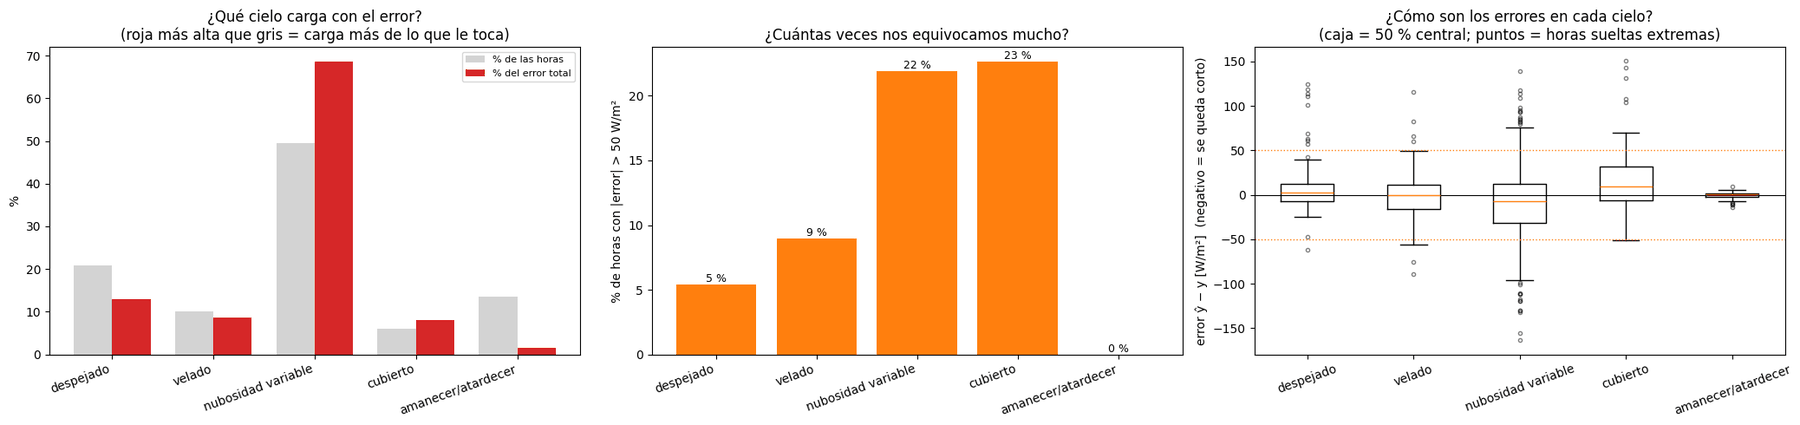

Resultados en: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/diagnostico/R1_radiografia_error


In [ ]:
import os
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

try:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
except ImportError:
    pass

BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
DIAG = BASE_DIR / "resultados" / "diagnostico"
RUTA_TABLA = DIAG / "faseB_radiografia_E1" / "tabla_horaria_E1.pkl"
RUTA_OOF = DIAG / "depuracion_E1_30" / "P1_oof_E1_30.pkl"
DIR_5C = DIAG / "faseC_regularizacion" / "C5c_confirmacion"
SALIDA = DIAG / "R1_radiografia_error"
SALIDA.mkdir(parents=True, exist_ok=True)
SEMILLAS = [42, 123, 2024, 7, 99]
UMBRAL_GRANDE = 50.0
NOMBRE_CIELO = {"nubes rotas": "nubosidad variable"}

# 1) Datos: real, predicción de E1-30, régimen y cielo de cada hora con sol
T = pd.read_pickle(RUTA_TABLA)
VA = T[T["conjunto"] == "validation"].copy()
VA["pred"] = np.mean(
    [np.load(DIR_5C / f"pred_validation_s{s}.npz")["ep30"] for s in SEMILLAS], axis=0
)
TR = T[T["conjunto"] == "train"].copy()
OOF = pd.read_pickle(RUTA_OOF)
assert (OOF.index == TR.index).all(), "Los OOF de P1 no cuadran con la tabla de train"
TR["pred"] = OOF["OOF30_media"].to_numpy()

def preparar(D):
    D = D[D["regimen"] != "noche"].copy()
    D["cielo"] = D["cielo"].astype(str).replace(NOMBRE_CIELO)
    D["regimen"] = D["regimen"].astype(str)
    D["e"] = D["pred"] - D["real"]
    D["grande"] = D["e"].abs() > UMBRAL_GRANDE
    return D

VA, TR = preparar(VA), preparar(TR)
mae_va = VA["e"].abs().mean()
print(
    f"Comprobación: MAE de E1-30 en validación (horas con sol) = {mae_va:.2f} W/m² (esperado 23.25)"
)
assert abs(mae_va - 23.25) < 0.05


# 2) Métricas por grupo
def episodios(D):
    """Rachas de horas seguidas (mismo día) con error grande → (nº episodios, % de horas grandes que van en rachas ≥2 h)."""
    g = D[D["grande"]].index
    if len(g) == 0:
        return 0, np.nan, np.nan
    nuevo = np.r_[
        True,
        (np.diff(g.values).astype("timedelta64[h]").astype(int) != 1) | (g[1:].date != g[:-1].date),
    ]
    id_ep = np.cumsum(nuevo)
    largos = pd.Series(id_ep).value_counts()
    en_racha = largos[largos >= 2].sum() / len(g) * 100
    return len(largos), en_racha, largos.max()

def metricas(D, total_abs):
    y, e = D["real"].to_numpy(), D["e"].to_numpy()
    ae = np.abs(e)
    peor10 = np.sort(ae)[::-1][: max(1, int(np.ceil(0.10 * len(ae))))].sum() / ae.sum() * 100
    D_ep = D.copy()
    n_ep, pct_racha, racha_max = episodios(D_ep)
    sst = ((y - y.mean()) ** 2).sum()
    return {
        "horas": len(D),
        "DIF media": y.mean(),
        "DIF mediana": np.median(y),
        "DIF P90": np.percentile(y, 90),
        "MAE": ae.mean(),
        "RMSE": np.sqrt((e**2).mean()),
        "nMAE (%)": 100 * ae.mean() / y.mean(),
        "R²": 1 - (e**2).sum() / sst if sst > 0 else np.nan,
        "sesgo": e.mean(),
        "% horas error grande": 100 * D["grande"].mean(),
        "% del error total": 100 * ae.sum() / total_abs,
        "% error en el peor 10 % de horas": peor10,
        "RMSE/MAE": np.sqrt((e**2).mean()) / ae.mean(),
        "episodios error grande": n_ep,
        "% horas grandes en rachas ≥2 h": pct_racha,
    }

def tabla(D, col, orden=None):
    total = D["e"].abs().sum()
    filas = {"TODAS": metricas(D, total)}
    grupos = orden if orden else sorted(D[col].unique())
    for g in grupos:
        if (D[col] == g).any():
            filas[g] = metricas(D[D[col] == g], total)
    R = pd.DataFrame(filas).T
    R.insert(1, "% de las horas", 100 * R["horas"] / len(D))
    return R

ORDEN_REG = ["transicion", "completamente_diurno"]
ORDEN_CIELO = [
    c
    for c in ["despejado", "velado", "nubosidad variable", "cubierto", "amanecer/atardecer"]
    if c in set(VA["cielo"])
]
ORDEN_CIELO += sorted(set(VA["cielo"]) - set(ORDEN_CIELO))
pd.set_option("display.width", 260)
pd.set_option("display.max_columns", 30)
RES = {}
for nombre, D in [("VALIDACIÓN (ago–sep 2024)", VA), ("TRAIN fuera de muestra (P1, dic–jul)", TR)]:
    for col, orden, etiqueta in [
        ("regimen", ORDEN_REG, "régimen"),
        ("cielo", ORDEN_CIELO, "tipo de cielo"),
    ]:
        R = tabla(D, col, orden)
        RES[(nombre, etiqueta)] = R
        print(
            "\n" + "=" * 110 + f"\nE1-30 · {nombre} · por {etiqueta} (horas con sol)\n" + "=" * 110
        )
        display(R.round(1))

# Cruce régimen × cielo en validación: dónde está el error de verdad
VA["grupo"] = VA["regimen"] + " · " + VA["cielo"]
X = tabla(VA, "grupo")
X = X[X["horas"] >= 20].sort_values("% del error total", ascending=False)
print(
    "\n"
    + "=" * 110
    + "\nVALIDACIÓN · cruce régimen × cielo (grupos con ≥20 h), ordenado por % del error total\n"
    + "=" * 110
)
display(
    X[
        [
            "horas",
            "% de las horas",
            "DIF media",
            "MAE",
            "nMAE (%)",
            "sesgo",
            "% horas error grande",
            "% del error total",
        ]
    ].round(1)
)

# Las 15 peores horas de validación
peores = VA.assign(**{"|error|": VA["e"].abs()}).nlargest(15, "|error|")[
    ["regimen", "cielo", "real", "pred", "e", "|error|"]
]
print("\nLas 15 horas con más error en validación (e = ŷ − y):")
display(peores.round(1))

# 3) Gráficas sencillas (validación)
Rc = RES[("VALIDACIÓN (ago–sep 2024)", "tipo de cielo")].drop("TODAS")
fig, axs = plt.subplots(1, 3, figsize=(21, 5))
x = np.arange(len(Rc))
w = 0.38
axs[0].bar(x - w / 2, Rc["% de las horas"], w, color="lightgray", label="% de las horas")
axs[0].bar(x + w / 2, Rc["% del error total"], w, color="tab:red", label="% del error total")
axs[0].set_xticks(x)
axs[0].set_xticklabels(Rc.index, rotation=20, ha="right")
axs[0].legend(fontsize=8)
axs[0].set_ylabel("%")
axs[0].set_title(
    "¿Qué cielo carga con el error?\n(roja más alta que gris = carga más de lo que le toca)"
)
axs[1].bar(x, Rc["% horas error grande"], color="tab:orange")
for i, v in enumerate(Rc["% horas error grande"]):
    axs[1].text(i, v, f"{v:.0f} %", ha="center", va="bottom", fontsize=9)
axs[1].set_xticks(x)
axs[1].set_xticklabels(Rc.index, rotation=20, ha="right")
axs[1].set_ylabel(f"% de horas con |error| > {UMBRAL_GRANDE:.0f} W/m²")
axs[1].set_title("¿Cuántas veces nos equivocamos mucho?")
datos = [VA.loc[VA["cielo"] == c, "e"].to_numpy() for c in Rc.index]
axs[2].boxplot(datos, positions=x, showfliers=True, flierprops=dict(markersize=3, alpha=0.5))
axs[2].set_xticks(x)
axs[2].set_xticklabels(Rc.index)
axs[2].axhline(0, color="k", lw=0.8)
for s in (-UMBRAL_GRANDE, UMBRAL_GRANDE):
    axs[2].axhline(s, color="tab:orange", ls=":", lw=1)
axs[2].tick_params(axis="x", labelrotation=20)
axs[2].set_ylabel("error ŷ − y [W/m²]  (negativo = se queda corto)")
axs[2].set_title(
    "¿Cómo son los errores en cada cielo?\n(caja = 50 % central; puntos = horas sueltas extremas)"
)
plt.tight_layout()
plt.savefig(SALIDA / "R1_error_por_cielo.png", dpi=120)
plt.show()

# 4) Guardado
with pd.ExcelWriter(SALIDA / "R1_radiografia_error.xlsx") as xw:
    for (nombre, etiqueta), R in RES.items():
        R.round(2).to_excel(
            xw, sheet_name=f"{'val' if nombre.startswith('VAL') else 'train'}_{etiqueta[:10]}"
        )
    X.round(2).to_excel(xw, sheet_name="val_regimen_x_cielo")
    peores.round(2).to_excel(xw, sheet_name="val_15_peores")
print("Resultados en:", SALIDA)

**Resultados.** En validación, la nubosidad variable reúne el 49,5 % de las horas con sol y el 68,6 % del error total (68,4 % en entrenamiento fuera de muestra), con un MAE de 32,2 W/m² y un sesgo de −9,6 W/m². Su nMAE (16,5 %), sin embargo, es similar al del cielo velado (16,0 %); los más altos corresponden al cielo cubierto (36,0 %, con un sesgo de +21,9 W/m²) y a la transición (36,7 %, con un MAE de 2,7 W/m²). El 14,3 % de las horas tiene un error superior a 50 W/m², todas en el régimen completamente diurno, y el 10 % de las horas con más error acumula el 39,2 % del total.

### 10.2 Cielo de las horas previas y error de E1-30

Se estudia si el tipo de cielo de las horas previas, conocido al emitir, contiene información que E1-30 no aprovecha, con sus predicciones fuera de muestra de entrenamiento y las de validación en horas con sol (R2). Se compara el sesgo de E1-30 agrupando por el cielo de la última hora observada y por el de la hora objetivo, y un gradient boosting entrenado dejando cada mes fuera intenta corregir su error con el cielo de las cuatro horas previas. Según la regla fijada antes, hay señal si algún cielo previo con al menos 50 horas tiene un sesgo de 5 W/m² o más, significativo y del mismo signo en ambos conjuntos, o si la corrección reduce el MAE en al menos 0,5 W/m² en entrenamiento y también en validación.

Columnas kt y kt_variabilidad en la tabla horaria: sí

PARTE A · TRAIN · error de E1-30 según el cielo (sesgo = ŷ − y; negativo = se queda corto)


agrupando por cielo de T−1 (se conoce)                            agrupando por cielo de T (resultado, R1)                            
                                                    horas   MAE sesgo     IC95 sesgo                                    horas   MAE sesgo      IC95 sesgo
despejado                                             380  18.1  -3.3   [-6.7, -0.3]                                      381  17.5   4.3    [+1.2, +7.2]
velado                                                318  19.6  -0.2   [-3.8, +3.7]                                      322  16.7  -3.0    [-5.6, -0.4]
nubosidad variable                                   1447  36.1  -2.2   [-4.9, +0.5]                                     1450  37.8 -11.6   [-14.3, -9.1]
cubierto                                              451  26.9  -5.1   [-9.3, -1.3]                                      451  26.7  18.4  [+14.5, +22.4]
amanecer/atardecer                                    213   9.2  -4.2   [-5.8, -2.7]                                      423   3.1   0.3    [-0.1, +0.8]
noche                                                 215   3.5  -0.2   [-0.8, +0.4]                                      NaN   NaN   NaN             NaN
sin dato                                                3  13.2 -12.3  [-28.8, +1.4]                                      NaN   NaN   NaN             NaN


PARTE A · VALIDACIÓN · error de E1-30 según el cielo (sesgo = ŷ − y; negativo = se queda corto)


agrupando por cielo de T−1 (se conoce)                            agrupando por cielo de T (resultado, R1)                            
                                                    horas   MAE sesgo     IC95 sesgo                                    horas   MAE sesgo      IC95 sesgo
despejado                                             185  14.0  -5.8   [-9.7, -2.7]                                      185  14.5   5.6   [+1.7, +10.9]
velado                                                 87  25.1  -7.2  [-13.3, -1.5]                                       89  20.1  -0.5    [-4.5, +3.1]
nubosidad variable                                    438  30.9   1.8   [-1.7, +5.9]                                      438  32.2  -9.6   [-12.8, -6.5]
cubierto                                               53  26.1 -13.6  [-26.4, -4.9]                                       53  31.5  21.9  [+11.8, +36.5]
amanecer/atardecer                                     60  10.9  -5.7   [-8.5, -2.8]                                      119   2.7  -0.4    [-1.1, +0.2]
noche                                                  61   3.9  -2.6   [-4.1, -1.3]                                      NaN   NaN   NaN             NaN


¿Cuánto se mantiene el cielo de una hora a la siguiente? (validación; filas = cielo de T−1, % por fila)


cielo,despejado,velado,nubosidad variable,cubierto,amanecer/atardecer
cielo_T1,,,,,
despejado,72.0,3.0,22.0,0.0,3.0
velado,3.0,29.0,40.0,6.0,22.0
nubosidad variable,8.0,8.0,73.0,3.0,8.0
cubierto,0.0,11.0,28.0,58.0,2.0
amanecer/atardecer,23.0,25.0,48.0,3.0,0.0
noche,0.0,2.0,0.0,0.0,98.0



PARTE B · ¿El cielo de T−1…T−4 permite corregir el error de E1-30? (negativo = la corrección ayuda)


,MAE E1-30,MAE E1-30 corregido,cambio,IC95
"train (fuera de muestra, mes fuera)",26.50,27.80,1.29,"[+0.98, +1.61]"
validación,23.25,24.16,0.91,"[+0.31, +1.49]"


Validación · cambio de MAE con la corrección, según el cielo de T:


,cambio de MAE,horas
despejado,1.18,185
velado,1.03,89
nubosidad variable,0.64,438
cubierto,2.08,53
amanecer/atardecer,0.88,119


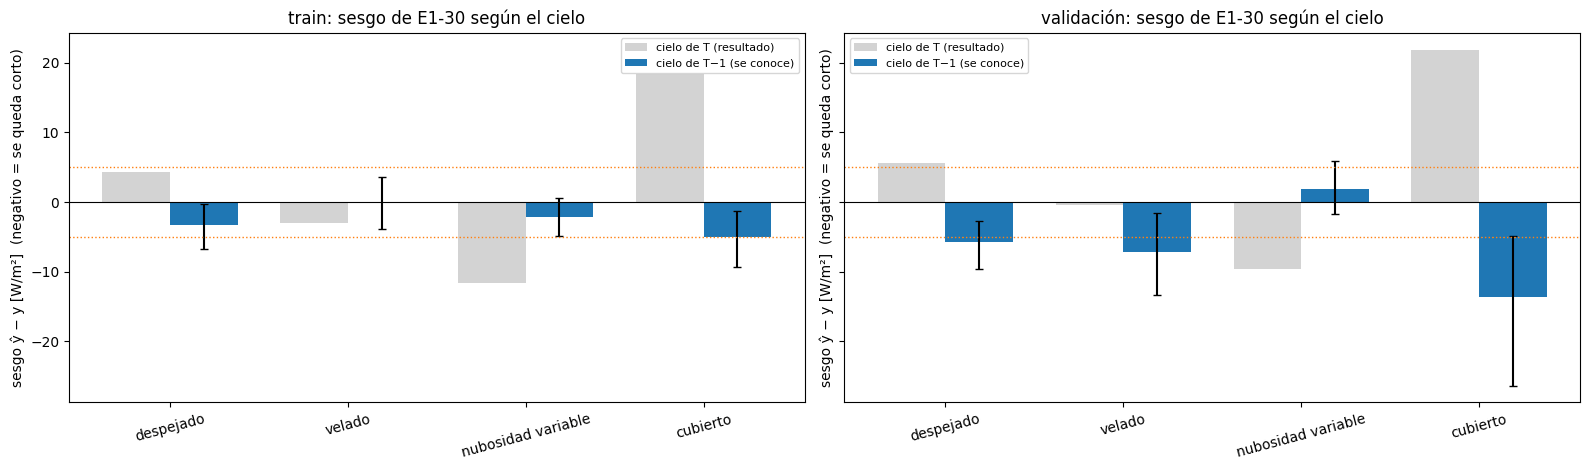


R2 · ¿El cielo de las horas anteriores aporta información que E1-30 no usa?
A) Sesgo claro y repetido por cielo de T−1: cubierto (-5.1 train / -13.6 val.)
B) Corrección con el cielo de T−1…T−4: train +1.29 [+0.98, +1.61] · validación +0.91 [+0.31, +1.49] → no cumple
VEREDICTO: HAY SEÑAL → pasar al paso 2 (añadir el cielo como canales de E1-30)
Resultados en: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/diagnostico/R2_cielo_anterior


In [ ]:
import os
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor

try:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
except ImportError:
    pass

BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
DIAG = BASE_DIR / "resultados" / "diagnostico"
RUTA_TABLA = DIAG / "faseB_radiografia_E1" / "tabla_horaria_E1.pkl"
RUTA_OOF = DIAG / "depuracion_E1_30" / "P1_oof_E1_30.pkl"
DIR_5C = DIAG / "faseC_regularizacion" / "C5c_confirmacion"
SALIDA = DIAG / "R2_cielo_anterior"
SALIDA.mkdir(parents=True, exist_ok=True)
SEMILLAS = [42, 123, 2024, 7, 99]
RETARDOS = [1, 2, 3, 4]
N_BOOT = 2000
NOMBRE_CIELO = {"nubes rotas": "nubosidad variable"}
ORDEN = ["despejado", "velado", "nubosidad variable", "cubierto", "amanecer/atardecer", "noche"]

# 1) Tabla con el cielo de T y de las horas anteriores
T = pd.read_pickle(RUTA_TABLA).sort_index()
T["cielo"] = T["cielo"].astype(str).replace(NOMBRE_CIELO)
hay_kt = {"kt", "kt_variabilidad"} <= set(T.columns)
print(
    f"Columnas kt y kt_variabilidad en la tabla horaria: {'sí' if hay_kt else 'NO (la parte B usará solo el one-hot)'}"
)
for k in RETARDOS:
    prev = T.reindex(T.index - pd.Timedelta(hours=k))
    T[f"cielo_T{k}"] = prev["cielo"].fillna("sin dato").to_numpy()
    if hay_kt:
        T[f"kt_T{k}"] = prev["kt"].fillna(0).to_numpy()  # noche / sin dato → 0
        T[f"ktsd_T{k}"] = prev["kt_variabilidad"].fillna(0).to_numpy()

VA = T[T["conjunto"] == "validation"].copy()
VA["pred"] = np.mean(
    [np.load(DIR_5C / f"pred_validation_s{s}.npz")["ep30"] for s in SEMILLAS], axis=0
)
TR = T[T["conjunto"] == "train"].copy()
OOF = pd.read_pickle(RUTA_OOF)
assert (OOF.index == TR.index).all(), "Los OOF de P1 no cuadran con la tabla de train"
TR["pred"], TR["mes"] = OOF["OOF30_media"].to_numpy(), OOF["mes_pliegue"].to_numpy()
VA, TR = VA[VA["regimen"] != "noche"].copy(), TR[TR["regimen"] != "noche"].copy()
for D in (VA, TR):
    D["e"] = D["pred"] - D["real"]  # negativo = E1-30 se queda corto
assert abs(VA["e"].abs().mean() - 23.25) < 0.05, "No se reproduce el MAE de E1-30 en validación"

def boot(D, valores, rng):
    dias = D.index.normalize()
    u, inv = np.unique(dias, return_inverse=True)
    g = [np.where(inv == i)[0] for i in range(len(u))]
    medias = [
        valores[np.concatenate([g[i] for i in rng.integers(0, len(g), len(g))])].mean()
        for _ in range(N_BOOT)
    ]
    return np.percentile(medias, 2.5), np.percentile(medias, 97.5)


# 2) Parte A · sesgo por cielo de T−1 (y de T, para comparar)
def por_cielo(D, col):
    filas = {}
    for c in [c for c in ORDEN + sorted(set(D[col]) - set(ORDEN)) if c in set(D[col])]:
        S = D[D[col] == c]
        lo, hi = boot(S, S["e"].to_numpy(), np.random.default_rng(0))
        filas[c] = {
            "horas": len(S),
            "MAE": round(S["e"].abs().mean(), 1),
            "sesgo": round(S["e"].mean(), 1),
            "IC95 sesgo": f"[{lo:+.1f}, {hi:+.1f}]",
            "_lo": lo,
            "_hi": hi,
        }
    return pd.DataFrame(filas).T

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 30)
A = {}
for nombre, D in [("train", TR), ("validación", VA)]:
    A[(nombre, "T−1")] = por_cielo(D, "cielo_T1")
    A[(nombre, "T")] = por_cielo(D, "cielo")
    print(
        "\n"
        + "=" * 100
        + f"\nPARTE A · {nombre.upper()} · error de E1-30 según el cielo (sesgo = ŷ − y; negativo = se queda corto)\n"
        + "=" * 100
    )
    comb = pd.concat(
        {
            "agrupando por cielo de T−1 (se conoce)": A[(nombre, "T−1")].drop(
                columns=["_lo", "_hi"]
            ),
            "agrupando por cielo de T (resultado, R1)": A[(nombre, "T")].drop(
                columns=["_lo", "_hi"]
            ),
        },
        axis=1,
    )
    display(comb)

senal_A = []
for c in A[("train", "T−1")].index:
    if c not in A[("validación", "T−1")].index or c in ("noche", "sin dato"):
        continue
    t, v = A[("train", "T−1")].loc[c], A[("validación", "T−1")].loc[c]
    if min(t["horas"], v["horas"]) < 50:
        continue
    claro = lambda r: abs(r["sesgo"]) >= 5 and (r["_lo"] > 0 or r["_hi"] < 0)
    if claro(t) and claro(v) and np.sign(t["sesgo"]) == np.sign(v["sesgo"]):
        senal_A.append(f"{c} ({t['sesgo']:+.1f} train / {v['sesgo']:+.1f} val.)")

# Cuánto se mantiene el cielo de una hora a la siguiente (validación)
print(
    "\n¿Cuánto se mantiene el cielo de una hora a la siguiente? (validación; filas = cielo de T−1, % por fila)"
)
M = pd.crosstab(VA["cielo_T1"], VA["cielo"], normalize="index").mul(100)
M = M.reindex(
    index=[c for c in ORDEN + ["sin dato"] if c in M.index],
    columns=[c for c in ORDEN if c in M.columns],
)
display(M.round(0))

# 3) Parte B · ¿se puede corregir el error de E1-30 con el cielo de las horas anteriores?
categorias = sorted(
    set(TR[[f"cielo_T{k}" for k in RETARDOS]].values.ravel())
    | set(VA[[f"cielo_T{k}" for k in RETARDOS]].values.ravel())
)

def variables(D):
    cols = {}
    for k in RETARDOS:
        for c in categorias:
            cols[f"T{k}={c}"] = (D[f"cielo_T{k}"] == c).astype(float).to_numpy()
        if hay_kt:
            cols[f"kt_T{k}"], cols[f"ktsd_T{k}"] = (
                D[f"kt_T{k}"].to_numpy(),
                D[f"ktsd_T{k}"].to_numpy(),
            )
    cols["prediccion"] = D["pred"].to_numpy()  # para que la corrección dependa del nivel
    return pd.DataFrame(cols, index=D.index)

def corrector():
    return HistGradientBoostingRegressor(
        loss="absolute_error",
        max_iter=200,
        learning_rate=0.05,
        min_samples_leaf=50,
        early_stopping=False,
        random_state=0,
    )

Xtr, Xva = variables(TR), variables(VA)
etr = TR["e"].to_numpy()
corr_oof = np.full(len(TR), np.nan)
mes, f = TR["mes"].to_numpy(), TR.index
for m in sorted(set(mes)):
    fuera = mes == m
    fin = f[fuera].max()
    entrena = ~fuera & ~((f > fin) & (f <= fin + pd.Timedelta("24h")))
    corr_oof[fuera] = corrector().fit(Xtr[entrena], etr[entrena]).predict(Xtr[fuera])
corr_va = corrector().fit(Xtr, etr).predict(Xva)
ae0_tr, ae1_tr = np.abs(etr), np.abs(etr - corr_oof)
ae0_va, ae1_va = np.abs(VA["e"].to_numpy()), np.abs(VA["e"].to_numpy() - corr_va)
lo_tr, hi_tr = boot(TR, ae1_tr - ae0_tr, np.random.default_rng(0))
lo_va, hi_va = boot(VA, ae1_va - ae0_va, np.random.default_rng(0))
B = pd.DataFrame(
    {
        "MAE E1-30": [ae0_tr.mean(), ae0_va.mean()],
        "MAE E1-30 corregido": [ae1_tr.mean(), ae1_va.mean()],
        "cambio": [ae1_tr.mean() - ae0_tr.mean(), ae1_va.mean() - ae0_va.mean()],
        "IC95": [f"[{lo_tr:+.2f}, {hi_tr:+.2f}]", f"[{lo_va:+.2f}, {hi_va:+.2f}]"],
    },
    index=["train (fuera de muestra, mes fuera)", "validación"],
)
print(
    "\n"
    + "=" * 100
    + "\nPARTE B · ¿El cielo de T−1…T−4 permite corregir el error de E1-30? (negativo = la corrección ayuda)\n"
    + "=" * 100
)
display(B.round(2))
desg = pd.DataFrame(
    {
        "cambio de MAE": pd.Series(ae1_va - ae0_va, index=VA.index)
        .groupby(VA["cielo"].to_numpy())
        .mean(),
        "horas": VA["cielo"].value_counts(),
    }
).reindex([c for c in ORDEN if c in set(VA["cielo"])])
print("Validación · cambio de MAE con la corrección, según el cielo de T:")
display(desg.round(2))
senal_B = (B.iloc[0]["cambio"] <= -0.5) and (hi_tr < 0) and (B.iloc[1]["cambio"] < 0)

# 4) Gráfica: sesgo por cielo de T−1 frente a cielo de T
fig, axs = plt.subplots(1, 2, figsize=(16, 4.8), sharey=True)
for ax, nombre in zip(axs, ["train", "validación"]):
    a1, a0 = A[(nombre, "T−1")], A[(nombre, "T")]
    cs = [c for c in ORDEN[:4] if c in a1.index and c in a0.index]
    x = np.arange(len(cs))
    w = 0.38
    ax.bar(
        x - w / 2,
        a0.loc[cs, "sesgo"].astype(float),
        w,
        color="lightgray",
        label="cielo de T (resultado)",
    )
    ax.bar(
        x + w / 2,
        a1.loc[cs, "sesgo"].astype(float),
        w,
        color="tab:blue",
        label="cielo de T−1 (se conoce)",
    )
    ax.errorbar(
        x + w / 2,
        a1.loc[cs, "sesgo"].astype(float),
        yerr=[
            a1.loc[cs, "sesgo"].astype(float) - a1.loc[cs, "_lo"].astype(float),
            a1.loc[cs, "_hi"].astype(float) - a1.loc[cs, "sesgo"].astype(float),
        ],
        fmt="none",
        ecolor="k",
        capsize=3,
    )
    ax.axhline(0, color="k", lw=0.8)
    ax.axhline(5, color="tab:orange", ls=":", lw=1)
    ax.axhline(-5, color="tab:orange", ls=":", lw=1)
    ax.set_xticks(x)
    ax.set_xticklabels(cs, rotation=15)
    ax.set_title(f"{nombre}: sesgo de E1-30 según el cielo")
    ax.set_ylabel("sesgo ŷ − y [W/m²]  (negativo = se queda corto)")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(SALIDA / "R2_sesgo_cielo_anterior.png", dpi=120)
plt.show()

# 5) Veredicto y guardado
lineas = [
    "R2 · ¿El cielo de las horas anteriores aporta información que E1-30 no usa?",
    "=" * 80,
    f"A) Sesgo claro y repetido por cielo de T−1: {', '.join(senal_A) if senal_A else 'ninguno'}",
    f"B) Corrección con el cielo de T−1…T−4: train {B.iloc[0]['cambio']:+.2f} {B.iloc[0]['IC95']} · "
    f"validación {B.iloc[1]['cambio']:+.2f} {B.iloc[1]['IC95']} → {'cumple' if senal_B else 'no cumple'}",
    "VEREDICTO: "
    + (
        "HAY SEÑAL → pasar al paso 2 (añadir el cielo como canales de E1-30)"
        if (senal_A or senal_B)
        else "SIN SEÑAL → E1-30 ya aprovecha lo que dice el cielo de las horas anteriores"
    ),
]
texto = "\n".join(lineas)
(SALIDA / "INFORME_R2.txt").write_text(texto, encoding="utf-8")
with pd.ExcelWriter(SALIDA / "R2_cielo_anterior.xlsx") as xw:
    for (n, c), R in A.items():
        R.drop(columns=["_lo", "_hi"]).to_excel(
            xw, sheet_name=f"A_{n[:5]}_{'T-1' if c == 'T−1' else 'T'}"
        )
    M.round(1).to_excel(xw, sheet_name="persistencia_cielo")
    B.to_excel(xw, sheet_name="B_correccion")
    desg.to_excel(xw, sheet_name="B_por_cielo")
print("\n" + texto + "\nResultados en:", SALIDA)

**Resultados.** Agrupando por el cielo de la hora objetivo, E1-30 se queda corto con nubosidad variable (−11,6 W/m² en entrenamiento y −9,6 W/m² en validación) y se excede con cielo cubierto (+18,4 y +21,9 W/m²). Agrupando por el cielo de la última hora observada, el único sesgo que cumple la regla aparece tras una hora cubierta: −5,1 W/m² en entrenamiento (IC95 [−9,3; −1,3]; 451 horas) y −13,6 W/m² en validación (IC95 [−26,4; −4,9]; 53 horas). La corrección con el cielo de las cuatro horas previas empeora el MAE en los dos conjuntos: +1,29 W/m² (IC95 [+0,98; +1,61]) en entrenamiento y +0,91 W/m² (IC95 [+0,31; +1,49]) en validación. La señal se limita, por tanto, al sesgo tras cielo cubierto.

### 10.3 El cielo de las horas previas como entrada de E1-30

Se añade a E1-30 información del cielo de cada hora de la ventana, nunca de la hora objetivo, en dos formatos (C7): V2a incorpora el índice de claridad (`kt`) y su variabilidad intrahoraria (`kt_sd`), con 11 canales, y V2b, la codificación one-hot de los cuatro tipos de cielo, con 13. Ambas se evalúan en la criba de entrenamiento con cuatro meses fuera (enero, marzo, mayo y julio), dos semillas y su mejor época, frente a E1-30 con los mismos pliegues. Una variante pasa a validación si mejora el MAE en horas con sol en al menos 0,5 W/m² sin empeorar de forma significativa la banda central ni el amanecer más de un 4 %, con intervalos al 97,5 % por haber dos variantes.

BASE · E1-30 (9 canales): entradas (5149, 24, 9)
V2a · + kt y kt_sd (11 canales): entradas (5149, 24, 11)
V2b · + one-hot del cielo (13 canales): entradas (5149, 24, 13)
Horas de train con kt > 0 en T−1: 48 %  (el resto son noche/sin dato → 0)
[1/24] BASE · 2024-01 · semilla 42: ya hecho (de C5b)
[2/24] BASE · 2024-03 · semilla 42: ya hecho (de C5b)
[3/24] BASE · 2024-05 · semilla 42: ya hecho (de C5b)
[4/24] BASE · 2024-07 · semilla 42: ya hecho (de C5b)
[5/24] BASE · 2024-01 · semilla 123: ya hecho (de C5b)
[6/24] BASE · 2024-03 · semilla 123: ya hecho (de C5b)
[7/24] BASE · 2024-05 · semilla 123: ya hecho (de C5b)
[8/24] BASE · 2024-07 · semilla 123: ya hecho (de C5b)
[9/24] V2a · 2024-01 · semilla 42: 137 s (total 2.3 min)
[10/24] V2a · 2024-03 · semilla 42: 70 s (total 3.5 min)
[11/24] V2a · 2024-05 · semilla 42: 71 s (total 4.6 min)
[12/24] V2a · 2024-07 · semilla 42: 69 s (total 5.8 min)
[13/24] V2a · 2024-01 · semilla 123: 68 s (total 6.9 min)
[14/24] V2a · 2024-03 · semilla 12

,mejor época,MAE operación,veredicto,cambio operación,"IC97,5 operación",cambio central,"IC97,5 central",cambio amanecer (%),"1 mejora ≥0,5 e IC<0",2 central sin empeorar,3 amanecer ≤4 %
configuración,,,,,,,,,,,
BASE · E1-30 (9 canales),30,25.39,referencia,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
V2a · + kt y kt_sd (11 canales),30,25.27,no pasa,-0.12,"[-0.43, +0.22]",-0.30,"[-1.29, +0.66]",-2.07,False,True,True
V2b · + one-hot del cielo (13 canales),25,25.81,no pasa,0.43,"[-0.23, +1.02]",0.89,"[-0.87, +2.74]",16.12,False,True,False



Desglose (IC95 sin ajustar, solo para entender dónde cambia):

V2a · + kt y kt_sd (11 canales)


,horas,MAE BASE,MAE variante,cambio,IC95,lectura
grupo,,,,,,
cielo de T−1: despejado,247,17.59,17.98,0.40,"[-0.29, +1.13]",igual
cielo de T−1: velado,198,21.04,20.74,-0.31,"[-1.21, +0.57]",igual
cielo de T−1: nubosidad variable,800,35.15,35.06,-0.09,"[-0.58, +0.39]",igual
cielo de T−1: cubierto,245,24.59,24.10,-0.50,"[-1.23, +0.18]",igual
cielo de T: despejado,248,17.13,16.86,-0.27,"[-0.99, +0.42]",igual
cielo de T: velado,200,17.23,16.73,-0.50,"[-1.20, +0.19]",igual
cielo de T: nubosidad variable,803,36.48,36.67,0.19,"[-0.29, +0.71]",igual
cielo de T: cubierto,245,26.55,25.95,-0.60,"[-1.54, +0.24]",igual
régimen: transición,247,3.07,2.90,-0.16,"[-0.40, +0.09]",igual



V2b · + one-hot del cielo (13 canales)


,horas,MAE BASE,MAE variante,cambio,IC95,lectura
grupo,,,,,,
cielo de T−1: despejado,247,17.59,17.39,-0.20,"[-1.63, +1.25]",igual
cielo de T−1: velado,198,21.04,22.60,1.56,"[+0.03, +3.09]",EMPEORA
cielo de T−1: nubosidad variable,800,35.15,35.51,0.35,"[-0.45, +1.25]",igual
cielo de T−1: cubierto,245,24.59,24.48,-0.12,"[-1.51, +1.49]",igual
cielo de T: despejado,248,17.13,16.06,-1.07,"[-2.44, +0.35]",igual
cielo de T: velado,200,17.23,18.89,1.66,"[+0.46, +2.68]",EMPEORA
cielo de T: nubosidad variable,803,36.48,37.61,1.14,"[+0.26, +2.02]",EMPEORA
cielo de T: cubierto,245,26.55,24.91,-1.65,"[-3.26, -0.12]",mejora
régimen: transición,247,3.07,3.75,0.69,"[+0.33, +1.02]",EMPEORA


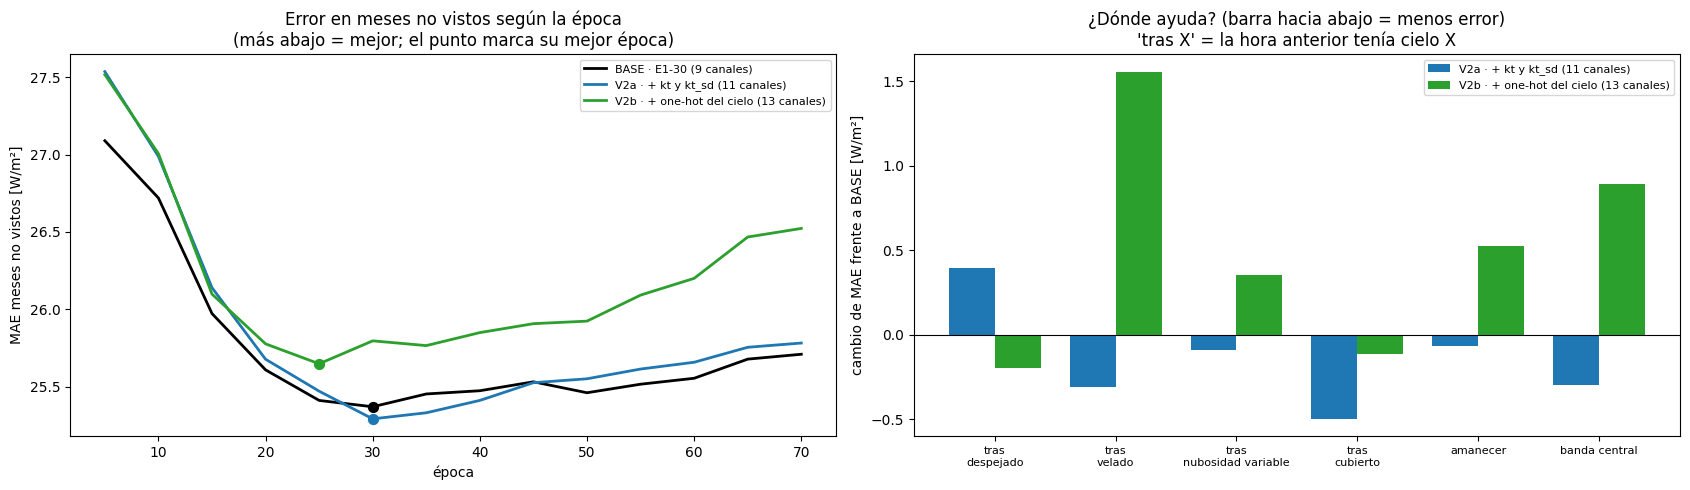


➜ NINGUNA PASA: añadir el cielo de las horas anteriores no mejora E1-30 lo suficiente. E1-30 se mantiene; la señal de R2 queda documentada.
Resultados en: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/diagnostico/faseC_cielo


In [ ]:
import os, time, random, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
try:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
except ImportError:
    pass

BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
DIAG = BASE_DIR / "resultados" / "diagnostico"
RUTA_NPZ = (
    BASE_DIR
    / "resultados"
    / "ejecuciones"
    / "preparacion_bloque_difstats_20261006_180841"
    / "matrices_dif_elev_difstats.npz"
)
DIR_F1 = DIAG / "fase1_intrahoraria"
DIR_B = DIAG / "faseB_radiografia_E1"
DIR_R0 = DIAG / "faseC_regularizacion" / "C5b_predicciones"
DIR_C7 = DIAG / "faseC_cielo"
DIR_P = DIR_C7 / "C7_predicciones"
DIR_P.mkdir(parents=True, exist_ok=True)
SEMILLAS = [42, 123]
MESES_CRIBA = ["2024-01", "2024-03", "2024-05", "2024-07"]
EPOCAS_MAX, CADA, BATCH, LR, WD, HIDDEN = 70, 5, 128, 1e-3, 1e-5, 64
EFECTO_MINIMO = 0.5
ALFA = 0.05 / 2  # Bonferroni: 2 variantes frente a BASE
LIMITE_AMANECER_PCT = 4.0
N_BOOT = 2000
TIPOS = ["despejado", "velado", "nubes rotas", "cubierto"]  # amanecer/atardecer y noche → todo 0
CONFIGS = {
    "BASE": dict(extra=[], nombre="BASE · E1-30 (9 canales)"),
    "V2a": dict(extra=["kt", "kt_sd"], nombre="V2a · + kt y kt_sd (11 canales)"),
    "V2b": dict(
        extra=[f"cielo_{t}" for t in TIPOS], nombre="V2b · + one-hot del cielo (13 canales)"
    ),
}

# 1) Entradas: las 9 de E1 + los canales de cielo de cada hora de la ventana
mat = np.load(RUTA_NPZ)
X_tr = mat["X_train_DIF_elev_DIFstats_raw"].astype(np.float32)
y_tr = mat["y_train_difstats"].astype(np.float32).reshape(-1)
fechas_tr = pd.DatetimeIndex(mat["fechas_train"])
intrahora = pd.read_csv(
    DIR_F1 / "variables_intrahorarias_horarias.csv", index_col=0, parse_dates=True
).asfreq("h")

def a_ventanas(tabla, fechas_obj, columnas, lookback=24):
    f = pd.DatetimeIndex(fechas_obj).to_numpy(dtype="datetime64[ns]")
    idx = f[:, None] - np.arange(lookback, 0, -1).astype("timedelta64[h]")[None, :]  # T−24 … T−1
    vals = tabla.reindex(pd.DatetimeIndex(idx.reshape(-1)))[columnas].to_numpy(dtype=np.float32)
    return vals.reshape(len(f), lookback, len(columnas))

CANALES_E1 = ["DIF_ult15", "DIF_pend30", "DIF_acel60", "DIF_saltos", "SWD_cv"]

def construir(fechas_obj, X_base, canales):
    Xn = a_ventanas(intrahora, fechas_obj, canales)
    for j, c in enumerate(canales):
        hueco = np.isnan(Xn[:, :, j])
        Xn[:, :, j][hueco] = X_base[:, :, 0][hueco] if c == "DIF_ult15" else 0.0
    return np.concatenate([X_base, Xn], axis=2).astype(np.float32)

Xtr_E1 = construir(fechas_tr, X_tr, CANALES_E1)
H = pd.read_pickle(DIR_B / "tabla_horaria_E1.pkl").sort_index()
assert {"kt", "kt_variabilidad", "cielo"} <= set(
    H.columns
), "La tabla horaria no tiene kt / kt_variabilidad / cielo"
CIELO = pd.DataFrame(
    {"kt": H["kt"].astype(float), "kt_sd": H["kt_variabilidad"].astype(float)}, index=H.index
)
for t in TIPOS:
    CIELO[f"cielo_{t}"] = (H["cielo"].astype(str) == t).astype(float)
CIELO = CIELO.fillna(0.0).asfreq("h", fill_value=0.0)  # noche, transición sin kt o sin dato → 0
X_cielo = np.nan_to_num(a_ventanas(CIELO, fechas_tr, list(CIELO.columns)), nan=0.0)
COL_CIELO = list(CIELO.columns)

def entradas(cfg):
    if not cfg["extra"]:
        return Xtr_E1
    j = [COL_CIELO.index(c) for c in cfg["extra"]]
    return np.concatenate([Xtr_E1, X_cielo[:, :, j]], axis=2).astype(np.float32)

for r, cfg in CONFIGS.items():
    print(f"{cfg['nombre']}: entradas {entradas(cfg).shape}")
print(
    f"Horas de train con kt > 0 en T−1: {100 * (X_cielo[:, -1, 0] > 0).mean():.0f} %  "
    f"(el resto son noche/sin dato → 0)"
)
TR = H[H["conjunto"] == "train"]
assert (
    len(TR) == len(y_tr) and (TR.index == fechas_tr).all()
), "La tabla horaria no cuadra con el .npz"
SOL = (TR["regimen"] != "noche").to_numpy()
mes = fechas_tr.to_period("M").astype(str).to_numpy()
mes = np.where(mes == "2023-12", "2024-01", mes)

def pliegue(m):
    fuera = mes == m
    fin = fechas_tr[fuera].max()
    purga = (fechas_tr > fin) & (fechas_tr <= fin + pd.Timedelta("24h"))
    return ~fuera & ~purga, fuera


# 2) Entrenamiento (protocolo exacto de E1; solo cambian los canales)
import torch, torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler

class LSTMDIFStats(nn.Module):
    def __init__(self, n_features=4, hidden_size=64):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=n_features, hidden_size=hidden_size, num_layers=1, batch_first=True
        )
        self.head = nn.Sequential(nn.Linear(hidden_size, 32), nn.ReLU(), nn.Linear(32, 1))

    def forward(self, x):
        salida, _ = self.lstm(x)
        return self.head(salida[:, -1, :]).squeeze(-1)

def entrenar(X_all, entrena, fuera, semilla):
    """Predicciones del mes no visto cada 5 épocas (filas = épocas)."""
    Xtr, ytr, Xte = X_all[entrena], y_tr[entrena], X_all[fuera]
    sx_ = StandardScaler().fit(Xtr.reshape(-1, Xtr.shape[2]))
    sy_ = StandardScaler().fit(ytr.reshape(-1, 1))
    e = lambda X: torch.from_numpy(
        sx_.transform(X.reshape(-1, X.shape[2])).reshape(X.shape).astype(np.float32)
    )
    Xtr_t, Xte_t = e(Xtr), e(Xte)
    ytr_e = sy_.transform(ytr.reshape(-1, 1)).ravel().astype(np.float32)
    random.seed(semilla)
    np.random.seed(semilla)
    torch.manual_seed(semilla)
    torch.use_deterministic_algorithms(True)
    modelo = LSTMDIFStats(n_features=Xtr.shape[2], hidden_size=HIDDEN)
    gen = torch.Generator()
    gen.manual_seed(semilla)
    loader = DataLoader(
        TensorDataset(Xtr_t, torch.from_numpy(ytr_e)),
        batch_size=BATCH,
        shuffle=True,
        generator=gen,
        num_workers=0,
    )
    opt = torch.optim.Adam(modelo.parameters(), lr=LR, weight_decay=WD)
    crit = nn.L1Loss()
    preds = []
    for ep in range(1, EPOCAS_MAX + 1):
        modelo.train()
        for xb, yb in loader:
            opt.zero_grad(set_to_none=True)
            loss = crit(modelo(xb), yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(modelo.parameters(), max_norm=1.0)
            opt.step()
        if ep % CADA == 0:
            modelo.eval()
            with torch.no_grad():
                preds.append(sy_.inverse_transform(modelo(Xte_t).numpy().reshape(-1, 1)).ravel())
    return np.array(preds, dtype=np.float32)

def ruta_pred(r, m, s):
    if r == "BASE" and (DIR_R0 / f"R0_{m}_s{s}.npz").exists():
        return DIR_R0 / f"R0_{m}_s{s}.npz"  # R0 de C5b = E1-30 con el mismo protocolo
    return DIR_P / f"{r}_{m}_s{s}.npz"

t_ini = time.time()
tareas = [(r, s, m) for r in CONFIGS for s in SEMILLAS for m in MESES_CRIBA]
for k, (r, s, m) in enumerate(tareas, 1):
    ruta = ruta_pred(r, m, s)
    if ruta.exists():
        print(
            f"[{k}/{len(tareas)}] {r} · {m} · semilla {s}: ya hecho ({'de C5b' if ruta.parent == DIR_R0 else 'C7'})"
        )
        continue
    t0 = time.time()
    entrena, fuera = pliegue(m)
    np.savez(ruta, pred=entrenar(entradas(CONFIGS[r]), entrena, fuera, s))
    print(
        f"[{k}/{len(tareas)}] {r} · {m} · semilla {s}: {time.time()-t0:.0f} s (total {(time.time()-t_ini)/60:.1f} min)"
    )

# 3) Evaluación en los 4 meses no vistos (horas con sol)
EPOCAS = np.arange(CADA, EPOCAS_MAX + 1, CADA)
idx = np.where(np.isin(mes, MESES_CRIBA))[0]
sol = SOL[idx]
y = y_tr[idx]
inf = TR.iloc[idx].copy()
inf["cielo"] = inf["cielo"].astype(str).replace({"nubes rotas": "nubosidad variable"})
cielo_T1 = (
    H["cielo"]
    .astype(str)
    .replace({"nubes rotas": "nubosidad variable"})
    .reindex(inf.index - pd.Timedelta("1h"))
    .fillna("sin dato")
    .to_numpy()
)
hora = inf.index.hour.to_numpy()
amanecer = (inf["regimen"].astype(str).to_numpy() == "transicion") & (hora < 12)
central = inf["banda"].astype(str).str.startswith("central").to_numpy()
res = {}
for r in CONFIGS:
    P = np.zeros((len(EPOCAS), len(idx)))
    for s in SEMILLAS:
        for m in MESES_CRIBA:
            P[:, mes[idx] == m] += np.load(ruta_pred(r, m, s))["pred"] / len(SEMILLAS)
    mae_ep = np.abs(P[:, sol] - y[sol]).mean(axis=1)
    suav = pd.Series(mae_ep, index=EPOCAS).rolling(3, center=True, min_periods=1).mean()
    ep = int(suav.idxmin())
    res[r] = dict(ep=ep, suav=suav, err=np.abs(P[list(EPOCAS).index(ep)] - y))

dias = inf.index.normalize().to_numpy()

def ic(d, msk, alfa):
    u, inv = np.unique(dias[msk], return_inverse=True)
    g = [np.where(inv == i)[0] for i in range(len(u))]
    dd = d[msk]
    rng = np.random.default_rng(0)
    medias = [
        dd[np.concatenate([g[i] for i in rng.integers(0, len(g), len(g))])].mean()
        for _ in range(N_BOOT)
    ]
    return (
        dd.mean(),
        np.percentile(medias, 100 * alfa / 2),
        np.percentile(medias, 100 * (1 - alfa / 2)),
    )

e0 = res["BASE"]["err"]
filas, desglose = [], []
for r, cfg in CONFIGS.items():
    fila = {
        "configuración": cfg["nombre"],
        "mejor época": res[r]["ep"],
        "MAE operación": res[r]["err"][sol].mean(),
    }
    if r != "BASE":
        d = res[r]["err"] - e0
        c, lo, hi = ic(d, sol, ALFA)
        cc, lc, hc = ic(d, sol & central, ALFA)
        ca, la, ha = ic(d, sol & amanecer, ALFA)
        pct_am = 100 * ca / e0[sol & amanecer].mean()
        ok1, ok2, ok3 = (hi < 0 and -c >= EFECTO_MINIMO), lc <= 0, pct_am <= LIMITE_AMANECER_PCT
        fila.update(
            {
                "cambio operación": c,
                "IC97,5 operación": f"[{lo:+.2f}, {hi:+.2f}]",
                "cambio central": cc,
                "IC97,5 central": f"[{lc:+.2f}, {hc:+.2f}]",
                "cambio amanecer (%)": pct_am,
                "1 mejora ≥0,5 e IC<0": ok1,
                "2 central sin empeorar": ok2,
                "3 amanecer ≤4 %": ok3,
                "veredicto": "PASA A VALIDACIÓN" if (ok1 and ok2 and ok3) else "no pasa",
            }
        )
        grupos = [
            ("cielo de T−1: " + g, cielo_T1 == g)
            for g in ["despejado", "velado", "nubosidad variable", "cubierto"]
        ]
        grupos += [
            ("cielo de T: " + g, (inf["cielo"] == g).to_numpy())
            for g in ["despejado", "velado", "nubosidad variable", "cubierto"]
        ]
        grupos += [
            ("régimen: transición", (inf["regimen"] == "transicion").to_numpy()),
            ("amanecer", amanecer),
            ("banda central", central),
        ]
        for nombre, msk in grupos:
            if (sol & msk).sum() >= 30:
                cg, lg, hg = ic(d, sol & msk, 0.05)
                desglose.append(
                    {
                        "variante": r,
                        "grupo": nombre,
                        "horas": int((sol & msk).sum()),
                        "MAE BASE": e0[sol & msk].mean(),
                        "MAE variante": res[r]["err"][sol & msk].mean(),
                        "cambio": cg,
                        "IC95": f"[{lg:+.2f}, {hg:+.2f}]",
                        "lectura": "mejora" if hg < 0 else ("EMPEORA" if lg > 0 else "igual"),
                    }
                )
    else:
        fila["veredicto"] = "referencia"
    filas.append(fila)
R = pd.DataFrame(filas).set_index("configuración")
D = pd.DataFrame(desglose)
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 30)
print(
    "\n"
    + "=" * 110
    + "\nC7 · ¿AYUDA EL CIELO DE LAS HORAS ANTERIORES? (train, 4 meses no vistos, 2 semillas, horas con sol)\n"
    + "=" * 110
)
print("Cambio negativo = menos error que BASE. IC al 97,5 % por Bonferroni (2 variantes).")
display(R.round(2))
print("\nDesglose (IC95 sin ajustar, solo para entender dónde cambia):")
for r in [k for k in CONFIGS if k != "BASE"]:
    print(f"\n{CONFIGS[r]['nombre']}")
    display(
        D[D["variante"] == r]
        .drop(columns="variante")
        .set_index("grupo")
        .dropna(axis=1, how="all")
        .round(2)
    )

# 4) Gráficas
colores = {"BASE": "black", "V2a": "tab:blue", "V2b": "tab:green"}
fig, axs = plt.subplots(1, 2, figsize=(17, 5))
for r in CONFIGS:
    axs[0].plot(EPOCAS, res[r]["suav"].values, color=colores[r], lw=2, label=CONFIGS[r]["nombre"])
    axs[0].scatter(
        [res[r]["ep"]], [res[r]["suav"].loc[res[r]["ep"]]], color=colores[r], s=50, zorder=3
    )
axs[0].set_xlabel("época")
axs[0].set_ylabel("MAE meses no vistos [W/m²]")
axs[0].legend(fontsize=8)
axs[0].set_title(
    "Error en meses no vistos según la época\n(más abajo = mejor; el punto marca su mejor época)"
)
gs = [
    "cielo de T−1: despejado",
    "cielo de T−1: velado",
    "cielo de T−1: nubosidad variable",
    "cielo de T−1: cubierto",
    "amanecer",
    "banda central",
]
w = 0.38
for j, r in enumerate(["V2a", "V2b"]):
    sub = D[D["variante"] == r].set_index("grupo").reindex(gs)
    axs[1].bar(
        np.arange(len(gs)) + (j - 0.5) * w,
        sub["cambio"],
        w,
        color=colores[r],
        label=CONFIGS[r]["nombre"],
    )
axs[1].axhline(0, color="k", lw=0.8)
axs[1].set_xticks(range(len(gs)))
axs[1].set_xticklabels([g.replace("cielo de T−1: ", "tras\n") for g in gs], fontsize=8)
axs[1].set_ylabel("cambio de MAE frente a BASE [W/m²]")
axs[1].legend(fontsize=8)
axs[1].set_title(
    "¿Dónde ayuda? (barra hacia abajo = menos error)\n'tras X' = la hora anterior tenía cielo X"
)
plt.tight_layout()
plt.savefig(DIR_C7 / "C7_cielo.png", dpi=120)
plt.show()

# 5) Veredicto y guardado
pasan = R[R["veredicto"] == "PASA A VALIDACIÓN"]
if len(pasan):
    g = pasan.sort_values("cambio operación").iloc[0]
    ver = (
        f"PASA A VALIDACIÓN: {g.name} ({g['cambio operación']:+.2f} W/m², IC97,5 {g['IC97,5 operación']}, "
        f"mejor época {int(g['mejor época'])}). Siguiente: confirmación con 5 semillas en validación."
    )
else:
    ver = (
        "NINGUNA PASA: añadir el cielo de las horas anteriores no mejora E1-30 lo suficiente. "
        "E1-30 se mantiene; la señal de R2 queda documentada."
    )
print("\n➜ " + ver)
R.to_csv(DIR_C7 / "C7_resumen.csv")
D.to_csv(DIR_C7 / "C7_desglose.csv", index=False)
pd.DataFrame({r: res[r]["suav"] for r in CONFIGS}).to_csv(DIR_C7 / "C7_curvas.csv")
(DIR_C7 / "C7_veredicto.txt").write_text(ver + "\n", encoding="utf-8")
print("Resultados en:", DIR_C7)

**Resultados.** Ninguna variante pasa a validación y E1-30 se mantiene. V2a no se distingue de E1-30 (−0,12 W/m², IC97,5 [−0,43; +0,22]) y tiene la misma mejor época (30); tras una hora cubierta, el grupo señalado en R2, su cambio es de −0,50 W/m², con un IC95 que incluye el cero. V2b alcanza su mejor época antes (25), aumenta el MAE en 0,43 W/m² (IC97,5 [−0,23; +1,02]) y el del amanecer en un 16,1 %, por encima del límite del 4 %; en el desglose, además, empeora la transición (+0,69 W/m², IC95 [+0,33; +1,02]).

## 11. Patrones del error e información intrahoraria

> *Se utiliza en la memoria: apartados 5.3.4 (69 variables) y 5.3.5 (fallos grandes y último minuto), y fases 16 a 18 de la Tabla A1.*

### 11.1 Variables de la estación frente al error de E1-30

Se cruza el error de E1-30, en entrenamiento fuera de muestra y en validación, con las 69 variables de la fase A, todas conocidas antes de emitir (R3). Cada variable se divide en diez tramos con los cortes de entrenamiento para obtener el perfil del sesgo, y un gradient boosting entrenado dejando cada mes fuera intenta corregir el error con todas las variables a la vez. Según la regla fijada antes, hay patrón si alguna variable mueve el sesgo al menos 10 W/m² entre tramos en los dos conjuntos con perfiles parecidos (correlación de al menos 0,6), o si el corrector reduce el MAE en al menos 0,5 W/m² en entrenamiento y también en validación.

Variables disponibles (I2 de la fase A): 69
Horas con sol con variables: train 2604/3027 · validación 765/884

PARTE 1 · ¿Qué variable hace que el sesgo de E1-30 cambie? (ordenadas por amplitud en train)
'Patrón repetible' = el sesgo se mueve ≥ 10 W/m² entre tramos en train y en validación y el perfil se parece (corr. ≥ 0.6).


,amplitud sesgo train,amplitud sesgo val.,parecido train–val. (corr.),tramos comparables,amplitud MAE train,¿patrón repetible?
variable,,,,,,
doy_cos,16.39,5.64,-0.37,4,24.02,
elev_T,14.93,8.09,-0.48,9,45.50,
LWD_sd1m_L1,14.89,13.40,-0.02,10,23.55,
Td_dep_L1,14.68,18.41,0.04,10,19.27,
DIR_pend30_L1,13.59,21.88,-0.04,9,20.90,
LWD_std_L1,13.47,13.43,-0.22,10,19.69,
doy_sin,13.37,NaN,NaN,1,16.18,
elev_L1,12.79,17.33,-0.45,9,44.43,
kd_pend30_L1,12.69,15.18,0.41,10,11.03,


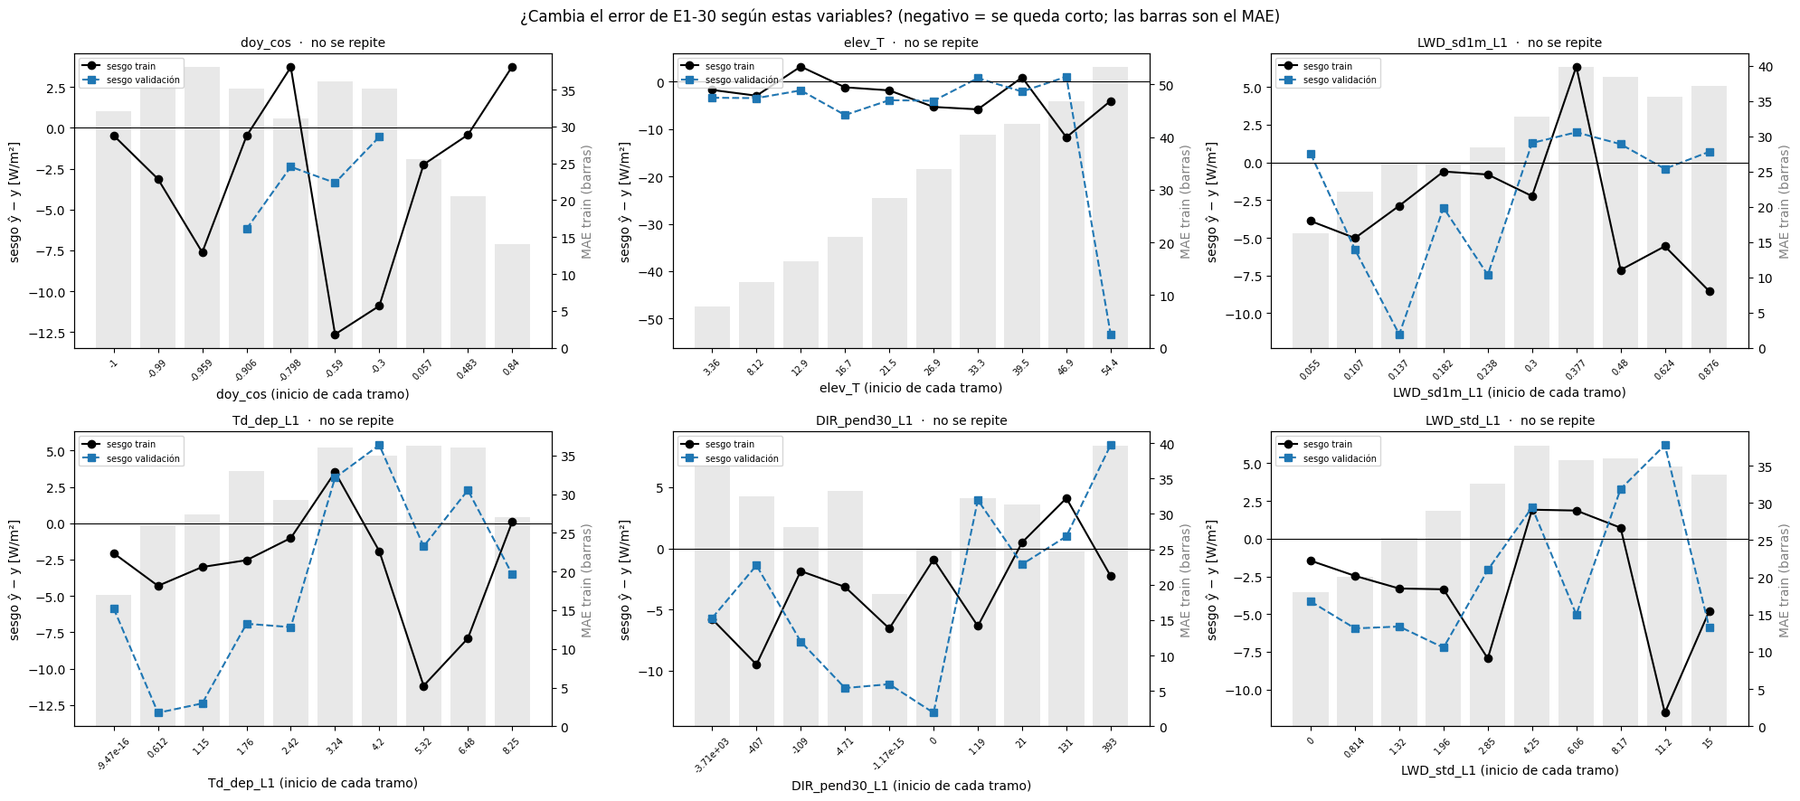


PARTE 2 · ¿Se puede corregir el error de E1-30 con las 69 variables? (negativo = ayuda)


,MAE E1-30,MAE corregido,cambio,IC95
"train (fuera de muestra, mes fuera)",30.31,31.49,1.18,"[+0.75, +1.61]"
validación,26.46,25.87,-0.59,"[-1.12, -0.07]"


Variables que más usa el corrector en validación (subida del error al desordenarlas, W/m²):


,importancia
prediccion,0.343
kt_ult15_L1,0.244
kd_pend30_L1,0.241
DIF_std_L1,0.127
CI_lw_ult15_L1,0.115
DIF_pend30_L3,0.115
elev_T,0.112
DIR_cv_L1,0.098
P_tend3h,0.092
d_elev_T,0.088



R3 · ¿Hay un patrón en el error de E1-30 que alguna variable del dataset explique?
1) Variables con patrón repetible (≥10 W/m² en train y val., corr. ≥0.6): ninguna
2) Corrector con 69 variables: train +1.18 [+0.75, +1.61] · validación -0.59 [-1.12, -0.07] → no cumple
VEREDICTO: SIN PATRÓN → ninguna variable del dataset explica el error de E1-30; se cierra el diagnóstico
Resultados en: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/diagnostico/R3_patron_error


In [ ]:
import os
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance

try:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
except ImportError:
    pass

BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
DIAG = BASE_DIR / "resultados" / "diagnostico"
RUTA_FA = DIAG / "faseA_anticipabilidad" / "faseA_puntos1_6.pkl"
RUTA_TABLA = DIAG / "faseB_radiografia_E1" / "tabla_horaria_E1.pkl"
RUTA_OOF = DIAG / "depuracion_E1_30" / "P1_oof_E1_30.pkl"
DIR_5C = DIAG / "faseC_regularizacion" / "C5c_confirmacion"
SALIDA = DIAG / "R3_patron_error"
SALIDA.mkdir(parents=True, exist_ok=True)
SEMILLAS = [42, 123, 2024, 7, 99]
N_TRAMOS, MIN_HORAS_TRAMO = 10, 30
UMBRAL_AMPLITUD, UMBRAL_CORR = 10.0, 0.6
N_BOOT = 2000

# 1) Errores de E1-30 + todas las variables de la fase A
F = pd.read_pickle(RUTA_FA)
X_all, VARS = F["X"], F["CONJ"]["I2"]
X_all = X_all[VARS]
print(f"Variables disponibles (I2 de la fase A): {len(VARS)}")
T = pd.read_pickle(RUTA_TABLA)
VA = T[T["conjunto"] == "validation"].copy()
VA["pred"] = np.mean(
    [np.load(DIR_5C / f"pred_validation_s{s}.npz")["ep30"] for s in SEMILLAS], axis=0
)
TR = T[T["conjunto"] == "train"].copy()
OOF = pd.read_pickle(RUTA_OOF)
assert (OOF.index == TR.index).all()
TR["pred"], TR["mes"] = OOF["OOF30_media"].to_numpy(), OOF["mes_pliegue"].to_numpy()
VA, TR = VA[VA["regimen"] != "noche"].copy(), TR[TR["regimen"] != "noche"].copy()
for D in (VA, TR):
    D["e"] = D["pred"] - D["real"]  # negativo = E1-30 se queda corto
assert abs(VA["e"].abs().mean() - 23.25) < 0.05, "No se reproduce el MAE de E1-30 en validación"
comunes_tr, comunes_va = TR.index.intersection(X_all.index), VA.index.intersection(X_all.index)
print(
    f"Horas con sol con variables: train {len(comunes_tr)}/{len(TR)} · validación {len(comunes_va)}/{len(VA)}"
)
TR, VA = TR.loc[comunes_tr], VA.loc[comunes_va]
Xtr, Xva = X_all.loc[comunes_tr].astype(float), X_all.loc[comunes_va].astype(float)


# 2) Parte 1 · perfil del error de E1-30 según cada variable
def perfil(v):
    x_tr, x_va = Xtr[v].to_numpy(), Xva[v].to_numpy()
    ok = ~np.isnan(x_tr)
    if ok.sum() < 200 or np.unique(x_tr[ok]).size < 4:
        return None
    cortes = np.unique(np.nanquantile(x_tr, np.linspace(0, 1, N_TRAMOS + 1)))
    if len(cortes) < 4:
        return None
    t_tr = np.clip(np.digitize(x_tr, cortes[1:-1]), 0, len(cortes) - 2)
    t_va = np.clip(np.digitize(x_va, cortes[1:-1]), 0, len(cortes) - 2)
    filas = []
    for k in range(len(cortes) - 1):
        m_tr, m_va = ok & (t_tr == k), ~np.isnan(x_va) & (t_va == k)
        filas.append(
            {
                "tramo": k + 1,
                "desde": cortes[k],
                "hasta": cortes[k + 1],
                "horas train": int(m_tr.sum()),
                "sesgo train": TR["e"].to_numpy()[m_tr].mean() if m_tr.any() else np.nan,
                "MAE train": np.abs(TR["e"].to_numpy()[m_tr]).mean() if m_tr.any() else np.nan,
                "horas val.": int(m_va.sum()),
                "sesgo val.": VA["e"].to_numpy()[m_va].mean() if m_va.any() else np.nan,
                "MAE val.": np.abs(VA["e"].to_numpy()[m_va]).mean() if m_va.any() else np.nan,
            }
        )
    return pd.DataFrame(filas)

resumen, perfiles = [], {}
for v in VARS:
    P = perfil(v)
    if P is None:
        continue
    perfiles[v] = P
    vt = P[P["horas train"] >= MIN_HORAS_TRAMO]
    vv = P[(P["horas train"] >= MIN_HORAS_TRAMO) & (P["horas val."] >= MIN_HORAS_TRAMO)]
    amp_tr = vt["sesgo train"].max() - vt["sesgo train"].min() if len(vt) >= 3 else np.nan
    amp_va = vv["sesgo val."].max() - vv["sesgo val."].min() if len(vv) >= 3 else np.nan
    corr = np.corrcoef(vv["sesgo train"], vv["sesgo val."])[0, 1] if len(vv) >= 4 else np.nan
    resumen.append(
        {
            "variable": v,
            "amplitud sesgo train": amp_tr,
            "amplitud sesgo val.": amp_va,
            "parecido train–val. (corr.)": corr,
            "tramos comparables": len(vv),
            "amplitud MAE train": (
                vt["MAE train"].max() - vt["MAE train"].min() if len(vt) >= 3 else np.nan
            ),
        }
    )
S = pd.DataFrame(resumen).set_index("variable").sort_values("amplitud sesgo train", ascending=False)
S["¿patrón repetible?"] = (
    (S["amplitud sesgo train"] >= UMBRAL_AMPLITUD)
    & (S["amplitud sesgo val."] >= UMBRAL_AMPLITUD)
    & (S["parecido train–val. (corr.)"] >= UMBRAL_CORR)
).map({True: "SÍ", False: ""})
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 100)
print(
    "\n"
    + "=" * 110
    + "\nPARTE 1 · ¿Qué variable hace que el sesgo de E1-30 cambie? (ordenadas por amplitud en train)\n"
    + "=" * 110
)
print(
    f"'Patrón repetible' = el sesgo se mueve ≥ {UMBRAL_AMPLITUD:.0f} W/m² entre tramos en train y en validación "
    f"y el perfil se parece (corr. ≥ {UMBRAL_CORR})."
)
display(S.head(25).round(2))
senal_1 = S.index[S["¿patrón repetible?"] == "SÍ"].tolist()

# Gráfica: las 6 variables con más amplitud en train
top = S.head(6).index.tolist()
fig, axs = plt.subplots(2, 3, figsize=(20, 9))
axs = axs.ravel()
for ax, v in zip(axs, top):
    P = perfiles[v]
    ax.plot(P["tramo"], P["sesgo train"], "o-", color="black", label="sesgo train")
    ax.plot(P["tramo"], P["sesgo val."], "s--", color="tab:blue", label="sesgo validación")
    ax2 = ax.twinx()
    ax2.bar(P["tramo"], P["MAE train"], color="lightgray", alpha=0.5, zorder=0)
    ax2.set_ylabel("MAE train (barras)", color="gray")
    ax.set_zorder(ax2.get_zorder() + 1)
    ax.patch.set_visible(False)
    ax.axhline(0, color="k", lw=0.8)
    ax.set_xticks(P["tramo"])
    ax.set_xticklabels([f"{d:.3g}" for d in P["desde"]], rotation=45, fontsize=7)
    ax.set_xlabel(f"{v} (inicio de cada tramo)")
    ax.set_ylabel("sesgo ŷ − y [W/m²]")
    ax.set_title(f"{v}  ·  {'PATRÓN REPETIBLE' if v in senal_1 else 'no se repite'}", fontsize=10)
    ax.legend(fontsize=7, loc="upper left")
plt.suptitle(
    "¿Cambia el error de E1-30 según estas variables? (negativo = se queda corto; las barras son el MAE)",
    fontsize=12,
)
plt.tight_layout()
plt.savefig(SALIDA / "R3_perfiles.png", dpi=110)
plt.show()


# 3) Parte 2 · corrector con TODAS las variables (mes fuera)
def corrector():
    return HistGradientBoostingRegressor(
        loss="absolute_error",
        max_iter=150,
        learning_rate=0.05,
        min_samples_leaf=80,
        l2_regularization=1.0,
        early_stopping=False,
        random_state=0,
    )

Xtr_c, Xva_c = Xtr.assign(prediccion=TR["pred"].to_numpy()), Xva.assign(
    prediccion=VA["pred"].to_numpy()
)
etr = TR["e"].to_numpy()
corr_oof = np.full(len(TR), np.nan)
mes, f = TR["mes"].to_numpy(), TR.index
for m in sorted(set(mes)):
    fuera = mes == m
    fin = f[fuera].max()
    entrena = ~fuera & ~((f > fin) & (f <= fin + pd.Timedelta("24h")))
    corr_oof[fuera] = corrector().fit(Xtr_c[entrena], etr[entrena]).predict(Xtr_c[fuera])
modelo = corrector().fit(Xtr_c, etr)
corr_va = modelo.predict(Xva_c)

def boot(D, d):
    u, inv = np.unique(D.index.normalize(), return_inverse=True)
    g = [np.where(inv == i)[0] for i in range(len(u))]
    rng = np.random.default_rng(0)
    medias = [
        d[np.concatenate([g[i] for i in rng.integers(0, len(g), len(g))])].mean()
        for _ in range(N_BOOT)
    ]
    return np.percentile(medias, 2.5), np.percentile(medias, 97.5)

a0t, a1t = np.abs(etr), np.abs(etr - corr_oof)
a0v, a1v = np.abs(VA["e"].to_numpy()), np.abs(VA["e"].to_numpy() - corr_va)
lt, ht = boot(TR, a1t - a0t)
lv, hv = boot(VA, a1v - a0v)
B = pd.DataFrame(
    {
        "MAE E1-30": [a0t.mean(), a0v.mean()],
        "MAE corregido": [a1t.mean(), a1v.mean()],
        "cambio": [a1t.mean() - a0t.mean(), a1v.mean() - a0v.mean()],
        "IC95": [f"[{lt:+.2f}, {ht:+.2f}]", f"[{lv:+.2f}, {hv:+.2f}]"],
    },
    index=["train (fuera de muestra, mes fuera)", "validación"],
)
print(
    "\n"
    + "=" * 110
    + f"\nPARTE 2 · ¿Se puede corregir el error de E1-30 con las {len(VARS)} variables? (negativo = ayuda)\n"
    + "=" * 110
)
display(B.round(2))
senal_2 = (B.iloc[0]["cambio"] <= -0.5) and (ht < 0) and (B.iloc[1]["cambio"] < 0)
imp = permutation_importance(
    modelo,
    Xva_c,
    VA["e"].to_numpy(),
    scoring="neg_mean_absolute_error",
    n_repeats=5,
    random_state=0,
)
I = pd.Series(imp.importances_mean, index=Xva_c.columns).sort_values(ascending=False)
print("Variables que más usa el corrector en validación (subida del error al desordenarlas, W/m²):")
display(I.head(10).round(3).to_frame("importancia"))

# 4) Veredicto y guardado
lineas = [
    "R3 · ¿Hay un patrón en el error de E1-30 que alguna variable del dataset explique?",
    "=" * 80,
    f"1) Variables con patrón repetible (≥{UMBRAL_AMPLITUD:.0f} W/m² en train y val., corr. ≥{UMBRAL_CORR}): "
    f"{', '.join(senal_1) if senal_1 else 'ninguna'}",
    f"2) Corrector con {len(VARS)} variables: train {B.iloc[0]['cambio']:+.2f} {B.iloc[0]['IC95']} · "
    f"validación {B.iloc[1]['cambio']:+.2f} {B.iloc[1]['IC95']} → {'cumple' if senal_2 else 'no cumple'}",
    "VEREDICTO: "
    + (
        "HAY PATRÓN → estudiar esas variables como entrada de E1-30 / N-BEATS"
        if (senal_1 or senal_2)
        else "SIN PATRÓN → ninguna variable del dataset explica el error de E1-30; se cierra el diagnóstico"
    ),
]
texto = "\n".join(lineas)
(SALIDA / "INFORME_R3.txt").write_text(texto, encoding="utf-8")
with pd.ExcelWriter(SALIDA / "R3_patron_error.xlsx") as xw:
    S.round(3).to_excel(xw, sheet_name="resumen_variables")
    B.to_excel(xw, sheet_name="corrector")
    I.round(4).to_frame("importancia").to_excel(xw, sheet_name="importancia")
    for v in top:
        perfiles[v].round(3).to_excel(xw, sheet_name=f"perfil_{v[:22]}")
print("\n" + texto + "\nResultados en:", SALIDA)

**Resultados.** El análisis se limita a las horas con todas las variables disponibles (2.604 de entrenamiento y 765 de validación), en las que el MAE de E1-30 es de 30,31 y 26,46 W/m². Ninguna variable presenta un patrón repetible: entre las de mayor amplitud, el parecido entre los perfiles de entrenamiento y validación no supera una correlación de 0,51. El corrector empeora el MAE fuera de muestra en entrenamiento (+1,18 W/m², IC95 [+0,75; +1,61]) y lo mejora en validación (−0,59 W/m², IC95 [−1,12; −0,07]), por lo que no cumple la regla. Tras la propia predicción, las variables que más utiliza son descriptores de claridad de la última hora observada (`kt_ult15_L1`, `kd_pend30_L1`).

### 11.2 Dinámica minutal de las horas con error grande

Se analiza minuto a minuto la DIF de las horas de validación en que E1-30 comete un error superior a 50 W/m², tanto en la última hora observada como en la hora objetivo (R4). Con definiciones fijadas antes de mirar, cada hora se clasifica según cuándo se produce el cambio: ya visible al emitir en la media de los últimos 15 minutos (A), en los primeros 20 minutos de la hora objetivo (B) o en los 40 restantes (C), además de los picos breves (D) y las horas que oscilan sin un cambio claro (E). El análisis es descriptivo.

Mounted at /content/drive
Horas con sol: 884 · con error grande (> 50 W/m²): 126 (49.1 % del error total)
Horas analizadas (≥ 30 min válidos en T−1 y en T): 126

R4 · ¿CÓMO CAMBIA LA DIF DENTRO DE LAS HORAS CON ERROR GRANDE? (validación, E1-30)


,horas,error_medio,sesgo,minuto_cambio_mediano,% de estas horas,% de su error
tipo,,,,,,
A · ya visible al predecir,16,83.5,30.4,3.5,12.7,13.2
B · cambio en los primeros 20 min,96,80.5,-14.0,5.0,76.2,76.6
C · cambio en los últimos 40 min,14,73.5,-17.3,24.0,11.1,10.2



Tipo A (el cambio ya se veía al predecir): 16 horas. En 6 de ellas la predicción quedó más cerca de los últimos 15 min que de la media de T−1 (el modelo sí usó la pista).

Por tipo de cielo (número de horas):


tipo,A · ya visible al predecir,B · cambio en los primeros 20 min,C · cambio en los últimos 40 min
cielo,,,
cubierto,3,9,0
despejado,6,4,0
nubosidad variable,7,75,14
velado,0,8,0



Por sentido del error (negativo = se queda corto):


tipo,A · ya visible al predecir,B · cambio en los primeros 20 min,C · cambio en los últimos 40 min
sentido,,,
se pasa,10,40,4
se queda corto,6,56,10


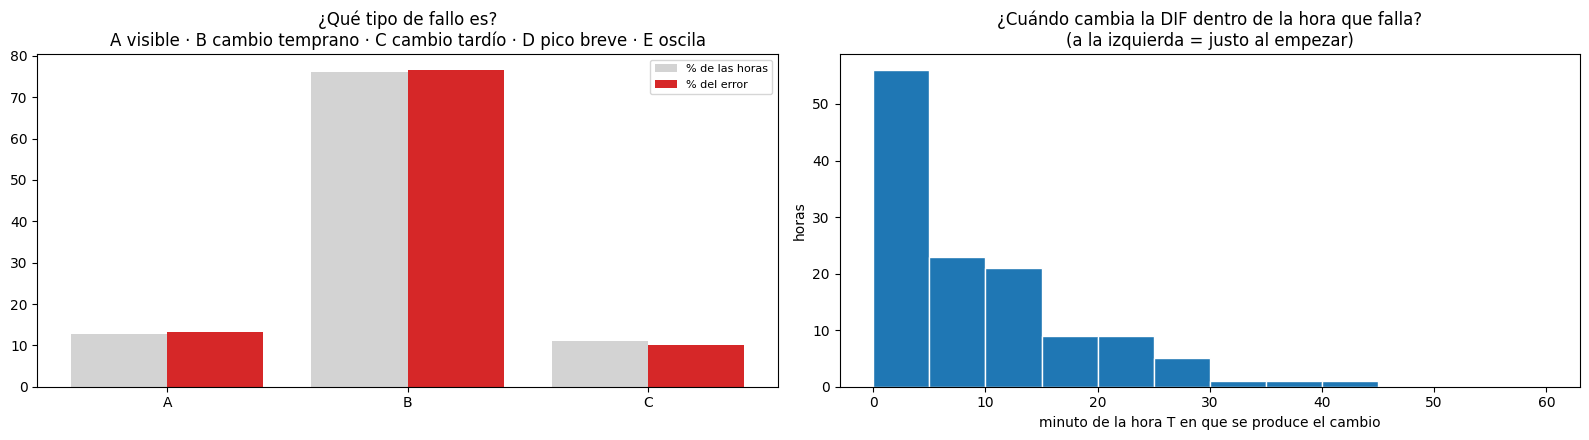

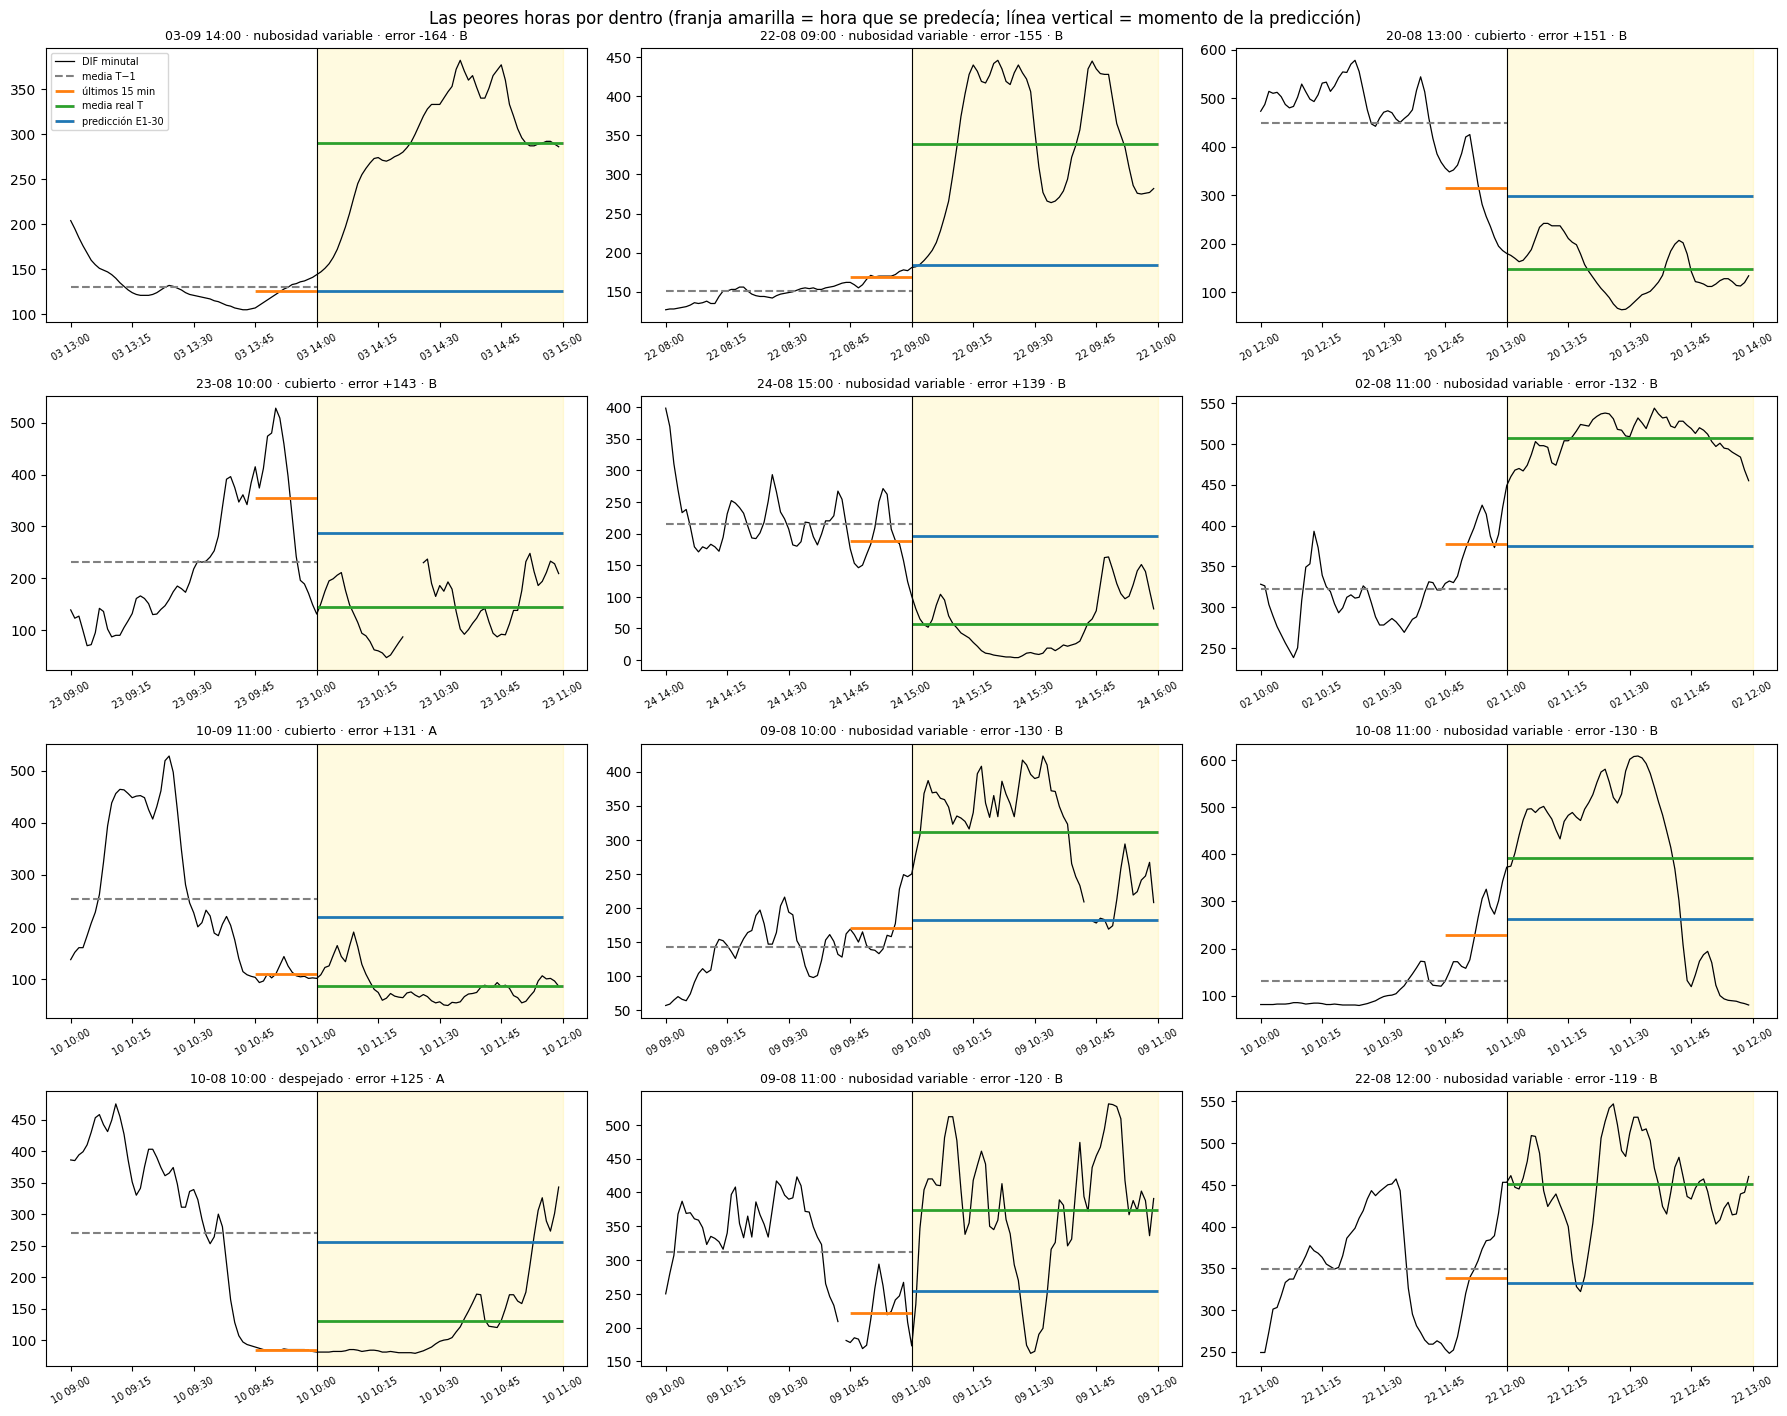

Resultados en: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/diagnostico/R4_dentro_de_la_hora


In [ ]:
import os
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

try:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
except ImportError:
    pass

BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
DIAG = BASE_DIR / "resultados" / "diagnostico"
PARQUET = BASE_DIR / "radiation_data_completo.parquet"
RUTA_TABLA = DIAG / "faseB_radiografia_E1" / "tabla_horaria_E1.pkl"
DIR_5C = DIAG / "faseC_regularizacion" / "C5c_confirmacion"
SALIDA = DIAG / "R4_dentro_de_la_hora"
SALIDA.mkdir(parents=True, exist_ok=True)
SEMILLAS = [42, 123, 2024, 7, 99]
UMBRAL = 50.0
N_GALERIA = 12

# 1) Horas con error grande y DIF minutal
T = pd.read_pickle(RUTA_TABLA)
VA = T[T["conjunto"] == "validation"].copy()
VA["pred"] = np.mean(
    [np.load(DIR_5C / f"pred_validation_s{s}.npz")["ep30"] for s in SEMILLAS], axis=0
)
VA = VA[VA["regimen"] != "noche"].copy()
VA["e"] = VA["pred"] - VA["real"]
assert abs(VA["e"].abs().mean() - 23.25) < 0.05, "No se reproduce el MAE de E1-30"
VA["cielo"] = VA["cielo"].astype(str).replace({"nubes rotas": "nubosidad variable"})
G = VA[VA["e"].abs() > UMBRAL].copy()
print(
    f"Horas con sol: {len(VA)} · con error grande (> {UMBRAL:.0f} W/m²): {len(G)} "
    f"({100 * G['e'].abs().sum() / VA['e'].abs().sum():.1f} % del error total)"
)
m = pd.read_parquet(PARQUET, columns=["Date/Time", "DIF [W/m**2]"])
m["Date/Time"] = pd.to_datetime(m["Date/Time"], utc=True).dt.tz_localize(None)
m = m.set_index("Date/Time").sort_index()
m = m[~m.index.duplicated()]
m = m[
    (m.index >= VA.index.min() - pd.Timedelta("2h"))
    & (m.index < VA.index.max() + pd.Timedelta("1h"))
]
dif = pd.to_numeric(m["DIF [W/m**2]"], errors="coerce").asfreq("min")

# 2) Descripción minuto a minuto de cada hora con error grande
filas = []
for t, r in G.iterrows():
    prev = dif[t - pd.Timedelta("1h") : t - pd.Timedelta("1min")]
    act = dif[t : t + pd.Timedelta("59min")]
    if prev.notna().sum() < 30 or act.notna().sum() < 30:
        continue
    media_prev, media_act = prev.mean(), act.mean()
    ult15 = prev.iloc[-15:].mean()
    salto = media_act - media_prev
    visible = abs(media_act - ult15) <= 0.5 * abs(salto) if abs(salto) > 1e-6 else False
    mitad = (ult15 + media_act) / 2
    suave = act.rolling(5, min_periods=3).mean().to_numpy()
    sube = media_act > ult15
    cruza = np.where((suave >= mitad) if sube else (suave <= mitad))[0]
    minuto = int(cruza[0]) if len(cruza) else np.nan
    lado = (act > r["pred"]) if r["e"] < 0 else (act < r["pred"])  # minutos en el lado del error
    frac_lado = float(lado[act.notna()].mean())
    if visible:
        tipo = "A · ya visible al predecir"
    elif frac_lado < 0.40:
        tipo = "D · pico breve dentro de la hora"
    elif not np.isnan(minuto) and minuto < 20:
        tipo = "B · cambio en los primeros 20 min"
    elif not np.isnan(minuto):
        tipo = "C · cambio en los últimos 40 min"
    else:
        tipo = "E · oscila sin cambio claro"
    filas.append(
        {
            "hora": t,
            "cielo": r["cielo"],
            "real": r["real"],
            "pred": r["pred"],
            "error": r["e"],
            "media T−1": media_prev,
            "últimos 15 min de T−1": ult15,
            "salto de media": salto,
            "minuto del cambio": minuto,
            "% minutos en el lado del error": 100 * frac_lado,
            "desv. minutal en T": act.std(),
            "rango minutal en T": act.max() - act.min(),
            "tipo": tipo,
            "pred más cerca de ult15 que de media T−1": abs(r["pred"] - ult15)
            < abs(r["pred"] - media_prev),
        }
    )
D = pd.DataFrame(filas).set_index("hora")
print(f"Horas analizadas (≥ 30 min válidos en T−1 y en T): {len(D)}")

# 3) Resumen
tot = D["error"].abs().sum()
Rt = D.groupby("tipo").agg(
    horas=("error", "size"),
    error_medio=("error", lambda s: s.abs().mean()),
    sesgo=("error", "mean"),
    minuto_cambio_mediano=("minuto del cambio", "median"),
)
Rt["% de estas horas"] = 100 * Rt["horas"] / len(D)
Rt["% de su error"] = 100 * D.groupby("tipo")["error"].apply(lambda s: s.abs().sum()) / tot
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 30)
print(
    "\n"
    + "=" * 100
    + "\nR4 · ¿CÓMO CAMBIA LA DIF DENTRO DE LAS HORAS CON ERROR GRANDE? (validación, E1-30)\n"
    + "=" * 100
)
display(Rt.round(1))
A = D[D["tipo"].str.startswith("A")]
if len(A):
    print(
        f"\nTipo A (el cambio ya se veía al predecir): {len(A)} horas. En {int(A['pred más cerca de ult15 que de media T−1'].sum())} "
        f"de ellas la predicción quedó más cerca de los últimos 15 min que de la media de T−1 (el modelo sí usó la pista)."
    )
print("\nPor tipo de cielo (número de horas):")
display(pd.crosstab(D["cielo"], D["tipo"]))
print("\nPor sentido del error (negativo = se queda corto):")
display(
    pd.crosstab(
        pd.Series(
            np.where(D["error"] < 0, "se queda corto", "se pasa"), index=D.index, name="sentido"
        ),
        D["tipo"],
    )
)

# 4) Gráficas: resumen + galería de las peores horas
fig, axs = plt.subplots(1, 2, figsize=(16, 4.5))
orden = sorted(Rt.index)
x = np.arange(len(orden))
w = 0.4
axs[0].bar(
    x - w / 2, Rt.loc[orden, "% de estas horas"], w, color="lightgray", label="% de las horas"
)
axs[0].bar(x + w / 2, Rt.loc[orden, "% de su error"], w, color="tab:red", label="% del error")
axs[0].set_xticks(x)
axs[0].set_xticklabels([o.split(" · ")[0] for o in orden])
axs[0].legend(fontsize=8)
axs[0].set_title(
    "¿Qué tipo de fallo es?\nA visible · B cambio temprano · C cambio tardío · D pico breve · E oscila"
)
mc = D["minuto del cambio"].dropna()
axs[1].hist(mc, bins=np.arange(0, 61, 5), color="tab:blue", edgecolor="white")
axs[1].set_xlabel("minuto de la hora T en que se produce el cambio")
axs[1].set_ylabel("horas")
axs[1].set_title(
    "¿Cuándo cambia la DIF dentro de la hora que falla?\n(a la izquierda = justo al empezar)"
)
plt.tight_layout()
plt.savefig(SALIDA / "R4_resumen.png", dpi=120)
plt.show()
peores = D.reindex(D["error"].abs().sort_values(ascending=False).index).head(N_GALERIA)
nf = int(np.ceil(len(peores) / 3))
fig, axs = plt.subplots(nf, 3, figsize=(18, 3.6 * nf), squeeze=False)
for ax, (t, r) in zip(axs.ravel(), peores.iterrows()):
    tramo = dif[t - pd.Timedelta("1h") : t + pd.Timedelta("59min")]
    ax.plot(tramo.index, tramo.values, color="black", lw=0.9, label="DIF minutal")
    ax.axvspan(t, t + pd.Timedelta("1h"), color="gold", alpha=0.12)
    ax.hlines(r["media T−1"], t - pd.Timedelta("1h"), t, color="gray", ls="--", label="media T−1")
    ax.hlines(
        r["últimos 15 min de T−1"],
        t - pd.Timedelta("15min"),
        t,
        color="tab:orange",
        lw=2,
        label="últimos 15 min",
    )
    ax.hlines(r["real"], t, t + pd.Timedelta("1h"), color="tab:green", lw=2, label="media real T")
    ax.hlines(
        r["pred"], t, t + pd.Timedelta("1h"), color="tab:blue", lw=2, label="predicción E1-30"
    )
    ax.axvline(t, color="k", lw=0.8)
    ax.set_title(
        f"{t:%d-%m %H:%M} · {r['cielo']} · error {r['error']:+.0f} · {r['tipo'].split(' · ')[0]}",
        fontsize=9,
    )
    ax.tick_params(axis="x", labelrotation=30, labelsize=7)
axs.ravel()[0].legend(fontsize=7)
for ax in axs.ravel()[len(peores) :]:
    ax.axis("off")
plt.suptitle(
    "Las peores horas por dentro (franja amarilla = hora que se predecía; línea vertical = momento de la predicción)"
)
plt.tight_layout()
plt.savefig(SALIDA / "R4_galeria_peores_horas.png", dpi=110)
plt.show()
D.to_csv(SALIDA / "R4_horas_error_grande.csv")
Rt.to_csv(SALIDA / "R4_resumen_tipos.csv")
print("Resultados en:", SALIDA)

**Resultados.** Las 126 horas con error grande reúnen el 49,1 % del error total de E1-30 en validación. El 76,2 % de ellas (96 horas, con el 76,6 % de su error) corresponde a cambios que empiezan en los primeros 20 minutos de la hora objetivo, con un minuto mediano de cambio de 5; solo 16 horas (12,7 %) muestran un cambio ya visible al emitir y 14 (11,1 %), un cambio a partir del minuto 20. No aparece ninguna hora de los tipos D y E. Las horas de tipo B son sobre todo de nubosidad variable (75 de 96), y en la mayoría E1-30 se queda corto (56 frente a 40).

### 11.3 Dinámica intrahoraria de la DIF y valor del último minuto

Con datos minutales de entrenamiento se describe la DIF dentro de la hora: cuánto cambia en k minutos, qué ventana final de la última hora observada funciona mejor como persistencia, qué forma tienen las horas según su nivel y qué añaden la desviación y el rango minutales (R5). Después se comprueba si el error de E1-30 depende de Δ, la diferencia entre la media de los últimos w* minutos (la mejor ventana entre 1, 5 y 10) y la de los últimos 15, con una corrección a + b·Δ ajustada dejando cada mes fuera y contrastada una vez en validación. Se pasa a la criba de C8 si, frente a corregir solo el sesgo, esa corrección reduce el MAE con IC95 por debajo de cero en entrenamiento fuera de muestra, en al menos 0,5 W/m², y en validación.

DIF minutal: 397,140 minutos (2023-12-30 05:00:00 → 2024-09-30 23:59:00); test excluido

BLOQUE A · EDA INTRAHORARIA DE LA DIF (solo train)

A1 · Cuánto cambia la DIF en k minutos (dentro de horas con sol):


,cambio medio |DIF(t+k) − DIF(t)| [W/m²]
k [min],
1,6.1
2,10.9
5,20.5
10,29.4
15,34.8
20,38.8
30,45.0
45,53.0



A2 · Persistencia según la ventana final (train, 3022 horas con todas las ventanas válidas; negativo = mejor que 15 min):


,MAE [W/m²],frente a últimos 15 min,IC95
ventana final de T−1,,,
últimos 1 min,35.20,-2.06,"[-3.11, -0.98]"
últimos 5 min,35.87,-1.38,"[-2.18, -0.57]"
últimos 10 min,36.48,-0.78,"[-1.21, -0.34]"
últimos 15 min,37.26,0.00,"[+0.00, +0.00]"
últimos 30 min,39.24,1.99,"[+1.32, +2.65]"
hora completa (media T−1),44.99,7.73,"[+6.61, +8.82]"


➜ Ventana candidata (regla fijada: menor MAE entre 1, 5 y 10 min): w* = 1 min

A3 · Forma de las horas por dentro según su nivel de DIF (train, % de horas de cada quintil):
     estable = desv./media < 0,10 · tendencia = recta R² ≥ 0,6 · pico breve = excursión > 50 % de la media en < 25 % de los minutos


forma,estable,tendencia,pico breve,oscilante,sin datos,DIF media,variación intrahoraria (desv./media),MAE E1-30 (fuera de muestra)
quintil DIF,,,,,,,,
Q1 (más baja),0.17,49.34,0.33,9.08,41.09,9.41,0.69,4.76
Q2,11.24,56.69,2.15,29.92,0.00,53.21,0.31,15.71
Q3,21.32,36.03,5.45,37.19,0.00,109.04,0.23,25.39
Q4,12.23,27.77,3.80,56.20,0.00,189.72,0.25,37.55
Q5 (más alta),19.14,16.01,2.97,61.88,0.00,324.39,0.20,49.08


... (7 outputs left out)

,MAE E1-30,MAE corrigiendo solo sesgo (a),MAE corrigiendo a + b·Δ,Δ frente a solo sesgo,IC95 (frente a solo sesgo),Δ frente a E1-30,IC95 (frente a E1-30)
"train (fuera de muestra, mes fuera)",26.49,26.54,25.88,-0.66,"[-0.98, -0.36]",-0.61,"[-0.93, -0.31]"
validación,23.26,23.23,22.62,-0.60,"[-1.02, -0.19]",-0.63,"[-1.05, -0.22]"


Validación, Diebold–Mariano diario (a + b·Δ frente a solo sesgo, L=3, HLN): -2.91, p = 0.005

Validación · dónde actúa la corrección (descriptivo):


,horas,MAE E1-30,MAE corregido,cambio
todas,882.0,23.26,22.62,-0.63
banda central,204.0,36.45,35.13,-1.32
nubosidad variable (T),437.0,32.21,31.68,-0.54
error grande de E1-30 (> 50),126.0,80.07,75.03,-5.04
|Δ| > 30 W/m² (los últimos min se apartan),168.0,42.80,41.55,-1.25



➜ PASA A C8: los últimos 1 min contienen información que E1-30 no aprovecha → probar el canal 'DIF_ult1' en la LSTM


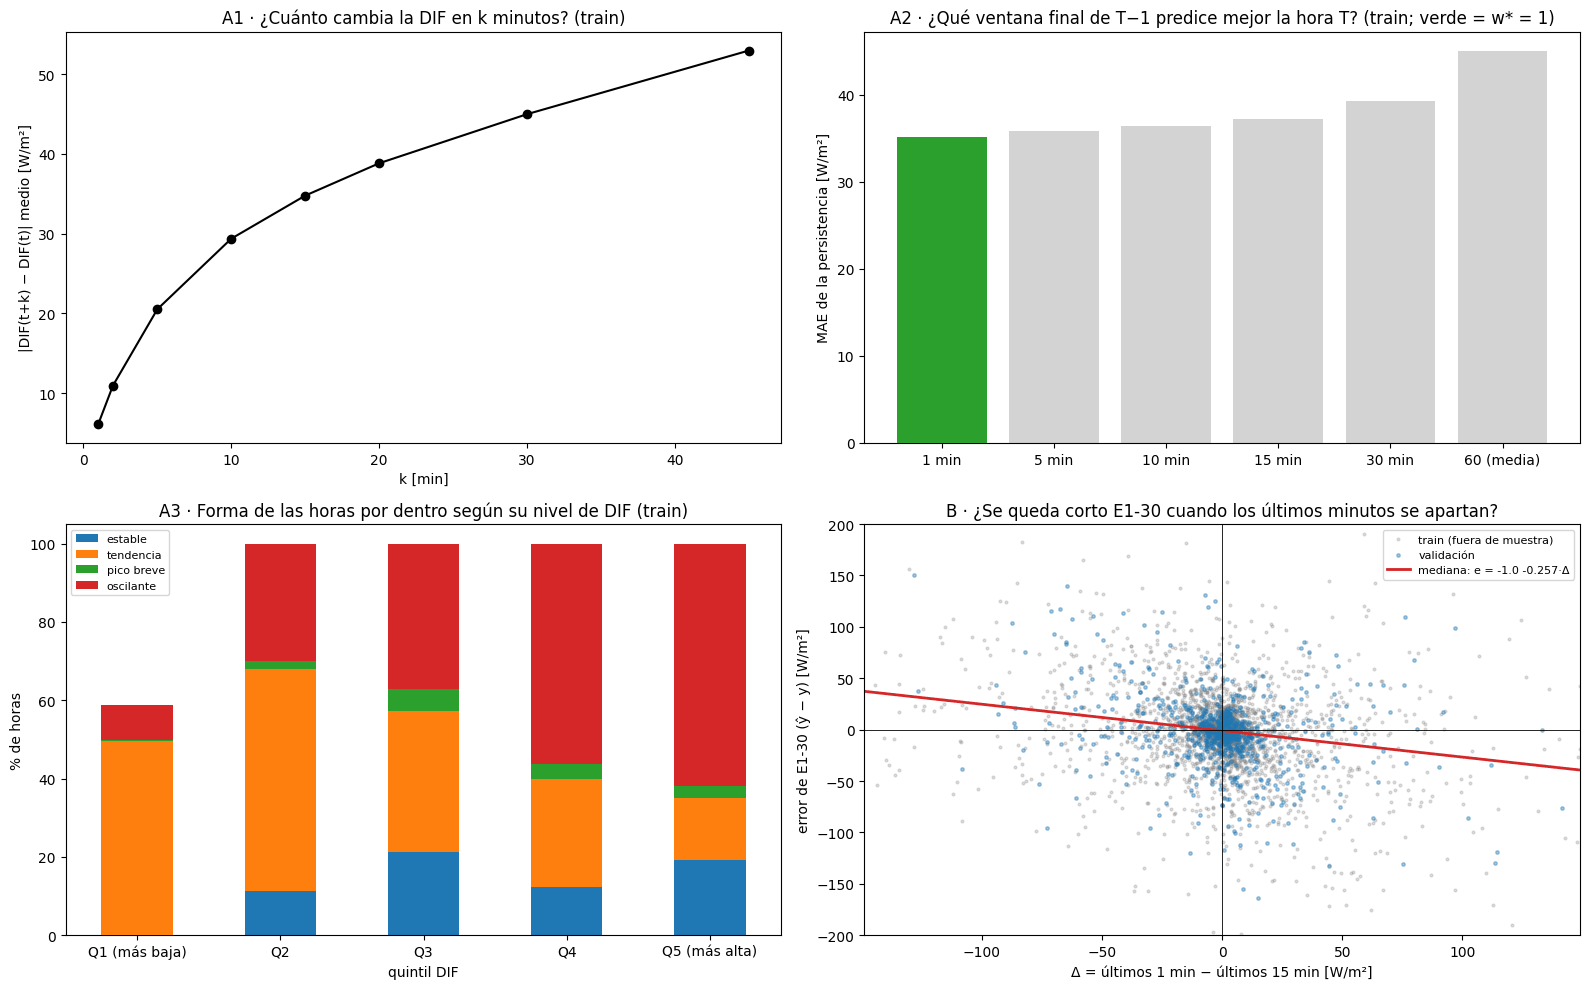

Resultados en: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/diagnostico/R5_dif_intrahoraria


In [ ]:
import os, warnings
from pathlib import Path

warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
try:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
except ImportError:
    pass

BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
DIAG = BASE_DIR / "resultados" / "diagnostico"
PARQUET = BASE_DIR / "radiation_data_completo.parquet"
RUTA_TABLA = DIAG / "faseB_radiografia_E1" / "tabla_horaria_E1.pkl"
RUTA_OOF = DIAG / "depuracion_E1_30" / "P1_oof_E1_30.pkl"
DIR_5C = DIAG / "faseC_regularizacion" / "C5c_confirmacion"
SALIDA = DIAG / "R5_dif_intrahoraria"
SALIDA.mkdir(parents=True, exist_ok=True)
SEMILLAS = [42, 123, 2024, 7, 99]
VENTANAS = [1, 5, 10, 15, 30, 60]  # minutos finales de T−1 que se promedian
CANDIDATAS = [1, 5, 10]  # w* se elige entre estas (15 ya la tiene el modelo; 60 es la media)
N_BOOT = 2000
FIN_DATOS = pd.Timestamp("2024-10-01")  # nada del test

# 0) Datos: tabla horaria, errores de E1-30 y DIF minutal (familia original BSRN)
T = pd.read_pickle(RUTA_TABLA)
TR, VA = T[T["conjunto"] == "train"].copy(), T[T["conjunto"] == "validation"].copy()
OOF = pd.read_pickle(RUTA_OOF)
assert (OOF.index == TR.index).all()
TR["pred"], TR["mes"] = OOF["OOF30_media"].to_numpy(), OOF["mes_pliegue"].to_numpy()
VA["pred"] = np.mean(
    [np.load(DIR_5C / f"pred_validation_s{s}.npz")["ep30"] for s in SEMILLAS], axis=0
)
for D in (TR, VA):
    D["cielo"] = D["cielo"].astype(str).replace({"nubes rotas": "nubosidad variable"})
TR, VA = TR[TR["regimen"] != "noche"].copy(), VA[VA["regimen"] != "noche"].copy()
for D in (TR, VA):
    D["e"] = D["pred"] - D["real"]
assert abs(VA["e"].abs().mean() - 23.25) < 0.05
cols = {
    "DIF [W/m**2]": "DIF",
    "DIF std dev [W/m**2]": "DIF_sd",
    "DIF min [W/m**2]": "DIF_min",
    "DIF max [W/m**2]": "DIF_max",
}
m = pd.read_parquet(PARQUET, columns=["Date/Time"] + list(cols))
m["Date/Time"] = pd.to_datetime(m["Date/Time"], utc=True).dt.tz_localize(None)
m = m.set_index("Date/Time").sort_index()
m = m[~m.index.duplicated()].rename(columns=cols)
m = m[(m.index >= TR.index.min() - pd.Timedelta("2h")) & (m.index < FIN_DATOS)]
assert m.index.max() < FIN_DATOS, "Se estarían leyendo datos del test"
for c in m.columns:
    m[c] = pd.to_numeric(m[c], errors="coerce")
m = m.asfreq("min")
print(f"DIF minutal: {len(m):,} minutos ({m.index.min()} → {m.index.max()}); test excluido")

def minutos(horas, desde, n=60, col="DIF"):
    """Matriz (horas × n) con la variable minutal desde 'desde' minutos respecto al inicio de cada hora."""
    base = pd.DatetimeIndex(horas).to_numpy(dtype="datetime64[m]")
    idx = base[:, None] + (np.arange(n) + desde).astype("timedelta64[m]")[None, :]
    return m[col].reindex(pd.DatetimeIndex(idx.ravel())).to_numpy().reshape(len(horas), n)

def persistencias(D):
    prev = minutos(D.index, -60)  # minutos de T−1: [T−60, T)
    out = {}
    for w in VENTANAS:
        bloque = prev[:, -w:]
        val = np.nanmean(bloque, axis=1) if w > 1 else bloque[:, -1]
        if w == 1:  # último minuto válido dentro de los 3 últimos
            ult3 = prev[:, -3:]
            val = np.array([r[~np.isnan(r)][-1] if (~np.isnan(r)).any() else np.nan for r in ult3])
        ok = (
            np.sum(~np.isnan(bloque), axis=1) >= max(1, int(np.ceil(w / 2)))
            if w > 1
            else ~np.isnan(val)
        )
        out[f"P{w}"] = np.where(ok, val, np.nan)
    return pd.DataFrame(out, index=D.index), prev

P_tr, prev_tr = persistencias(TR)
P_va, prev_va = persistencias(VA)

def boot_dias(indice, d, rng_seed=0, n=N_BOOT):
    ok = ~np.isnan(d)
    dias = pd.DatetimeIndex(indice)[ok].normalize()
    u, inv = np.unique(dias, return_inverse=True)
    g = [np.where(inv == i)[0] for i in range(len(u))]
    dd = d[ok]
    rng = np.random.default_rng(rng_seed)
    medias = [
        dd[np.concatenate([g[i] for i in rng.integers(0, len(g), len(g))])].mean() for _ in range(n)
    ]
    return dd.mean(), np.percentile(medias, 2.5), np.percentile(medias, 97.5)

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 30)

# BLOQUE A · EDA INTRAHORARIA (solo train, horas con sol)
print("\n" + "=" * 100 + "\nBLOQUE A · EDA INTRAHORARIA DE LA DIF (solo train)\n" + "=" * 100)

# A1 · ¿A qué escala cambia la DIF? (cuánto cambia en k minutos, minutos de horas con sol de train)
act_tr = minutos(TR.index, 0)  # minutos de la propia hora T (solo para describir en train)
serie = act_tr  # horas × 60
LAGS = [1, 2, 5, 10, 15, 20, 30, 45]
a1 = {}
for k in LAGS:
    d = np.abs(serie[:, k:] - serie[:, :-k])
    a1[k] = np.nanmean(d)
A1 = pd.Series(a1, name="cambio medio |DIF(t+k) − DIF(t)| [W/m²]")
A1.index.name = "k [min]"
print("\nA1 · Cuánto cambia la DIF en k minutos (dentro de horas con sol):")
display(A1.round(1).to_frame())

# A2 · ¿Qué ventana final de T−1 predice mejor la media de T? (persistencia de distinta resolución)
y_tr = TR["real"].to_numpy()
ok_all = np.all(~np.isnan(P_tr.to_numpy()), axis=1)
filas = []
e15 = np.abs(P_tr["P15"].to_numpy() - y_tr)
for w in VENTANAS:
    ew = np.abs(P_tr[f"P{w}"].to_numpy() - y_tr)
    c, lo, hi = boot_dias(TR.index, np.where(ok_all, ew - e15, np.nan))
    filas.append(
        {
            "ventana final de T−1": f"últimos {w} min" if w < 60 else "hora completa (media T−1)",
            "w": w,
            "MAE [W/m²]": ew[ok_all].mean(),
            "frente a últimos 15 min": c,
            "IC95": f"[{lo:+.2f}, {hi:+.2f}]",
        }
    )
A2 = pd.DataFrame(filas).set_index("ventana final de T−1")
cand = A2[A2["w"].isin(CANDIDATAS)]
W_EST = int(cand.loc[cand["MAE [W/m²]"].astype(float).idxmin(), "w"])
print(
    f"\nA2 · Persistencia según la ventana final (train, {ok_all.sum()} horas con todas las ventanas válidas; negativo = mejor que 15 min):"
)
display(A2.drop(columns="w").round(2))
print(f"➜ Ventana candidata (regla fijada: menor MAE entre 1, 5 y 10 min): w* = {W_EST} min")


# A3 · ¿Cómo son las horas por dentro según su nivel de DIF? (forma de la hora T, train)
def forma(fila):
    v = fila[~np.isnan(fila)]
    if len(v) < 30 or v.mean() <= 5:
        return np.nan, np.nan, "sin datos"
    mu, sd = v.mean(), v.std()
    t = np.arange(len(v))
    r2 = np.corrcoef(t, v)[0, 1] ** 2 if sd > 0 else 0.0
    exc = max(v.max() - mu, mu - v.min()) / mu
    frac = np.mean((v > 1.25 * mu) | (v < 0.75 * mu))
    if sd / mu < 0.10:
        f = "estable"
    elif r2 >= 0.6:
        f = "tendencia"
    elif exc > 0.5 and frac < 0.25:
        f = "pico breve"
    else:
        f = "oscilante"
    return sd / mu, r2, f

res = [forma(r) for r in act_tr]
TR["cv_intra"], TR["r2_tendencia"], TR["forma"] = (
    [x[0] for x in res],
    [x[1] for x in res],
    [x[2] for x in res],
)
TR["quintil DIF"] = pd.qcut(
    TR["real"], 5, labels=["Q1 (más baja)", "Q2", "Q3", "Q4", "Q5 (más alta)"]
)
A3 = pd.crosstab(TR["quintil DIF"], TR["forma"], normalize="index").mul(100)
A3 = A3[
    [c for c in ["estable", "tendencia", "pico breve", "oscilante", "sin datos"] if c in A3.columns]
]
A3["DIF media"] = TR.groupby("quintil DIF", observed=True)["real"].mean()
A3["variación intrahoraria (desv./media)"] = TR.groupby("quintil DIF", observed=True)[
    "cv_intra"
].mean()
A3["MAE E1-30 (fuera de muestra)"] = TR.groupby("quintil DIF", observed=True)["e"].apply(
    lambda s: s.abs().mean()
)
print(
    "\nA3 · Forma de las horas por dentro según su nivel de DIF (train, % de horas de cada quintil):"
)
print(
    "     estable = desv./media < 0,10 · tendencia = recta R² ≥ 0,6 · pico breve = excursión > 50 % de la media en < 25 % de los minutos"
)
display(A3.round(2))
print("MAE de E1-30 según la forma de la hora:")
display(
    TR.groupby("forma")["e"].agg(horas="size", MAE=lambda s: s.abs().mean(), sesgo="mean").round(1)
)

# A4 · ¿Aporta la familia original (std dev, min, max) de los últimos minutos?
resid = y_tr - P_tr[f"P{W_EST}"].to_numpy()  # lo que la persistencia de w* no explica
ult5_sd = np.nanmean(minutos(TR.index, -5, 5, "DIF_sd"), axis=1)
ult5_rng = np.nanmax(minutos(TR.index, -5, 5, "DIF_max"), axis=1) - np.nanmin(
    minutos(TR.index, -5, 5, "DIF_min"), axis=1
)
x10 = prev_tr[:, -10:]
pend10 = np.array(
    [
        (
            np.polyfit(np.arange(10)[~np.isnan(r)], r[~np.isnan(r)], 1)[0] * 60
            if (~np.isnan(r)).sum() >= 5
            else np.nan
        )
        for r in x10
    ]
)
filas = []
for nombre, v in [
    ("desv. minutal BSRN (últimos 5 min)", ult5_sd),
    ("rango máx−mín (últimos 5 min)", ult5_rng),
    ("pendiente de los últimos 10 min [W/m² por h]", pend10),
]:
    ok = ~np.isnan(v) & ~np.isnan(resid)
    rs, ps = stats.spearmanr(v[ok], resid[ok])
    ra, pa = stats.spearmanr(v[ok], np.abs(resid[ok]))
    filas.append(
        {
            "variable": nombre,
            "ρ con lo que falta (con signo)": rs,
            "p": ps,
            "ρ con el tamaño de lo que falta": ra,
            "p ": pa,
        }
    )
A4 = pd.DataFrame(filas).set_index("variable")
print(
    f"\nA4 · ¿La familia original de los últimos minutos dice algo más allá de la persistencia de {W_EST} min? (train, Spearman)"
)
print(
    "     con signo ≠ 0 → anticipa hacia dónde irá la DIF · con el tamaño ≠ 0 → anticipa cuánto se moverá (incertidumbre)"
)
display(A4.round(3))

# BLOQUE B · ¿E1-30 DESAPROVECHA LOS ÚLTIMOS MINUTOS? (decide)
print(
    "\n"
    + "=" * 100
    + f"\nBLOQUE B · ¿El error de E1-30 se explica por Δ = últimos {W_EST} min − últimos 15 min?\n"
    + "=" * 100
)

def lad(x, y, iters=60):
    """Regresión de mediana y = a + b·x (mínimos desvíos absolutos, IRLS)."""
    X = np.column_stack([np.ones_like(x), x])
    beta = np.linalg.lstsq(X, y, rcond=None)[0]
    for _ in range(iters):
        w = 1 / np.maximum(np.abs(y - X @ beta), 1e-3)
        Xw = X * w[:, None]
        beta = np.linalg.solve(X.T @ Xw, Xw.T @ y)
    return beta

def lad_a(y):
    return np.array([np.median(y), 0.0])

def datos(D, P):
    dl = (P[f"P{W_EST}"] - P["P15"]).to_numpy()
    ok = ~np.isnan(dl) & ~np.isnan(D["e"].to_numpy())
    return D[ok], dl[ok], D["e"].to_numpy()[ok]

Dtr, dl_tr, e_tr = datos(TR, P_tr)
Dva, dl_va, e_va = datos(VA, P_va)


# B1 · pendiente b (¿reacciona poco a los últimos minutos?)
def b_con_ic(D, dl, e):
    b = lad(dl, e)[1]
    dias = D.index.normalize()
    u, inv = np.unique(dias, return_inverse=True)
    g = [np.where(inv == i)[0] for i in range(len(u))]
    rng = np.random.default_rng(0)
    bs = []
    for _ in range(N_BOOT):
        s = np.concatenate([g[i] for i in rng.integers(0, len(g), len(g))])
        bs.append(lad(dl[s], e[s], iters=30)[1])
    return b, np.percentile(bs, 2.5), np.percentile(bs, 97.5)

b_tr = b_con_ic(Dtr, dl_tr, e_tr)
b_va = b_con_ic(Dva, dl_va, e_va)
B1 = pd.DataFrame(
    {
        "horas": [len(Dtr), len(Dva)],
        "pendiente b": [b_tr[0], b_va[0]],
        "IC95": [f"[{b_tr[1]:+.3f}, {b_tr[2]:+.3f}]", f"[{b_va[1]:+.3f}, {b_va[2]:+.3f}]"],
    },
    index=["train (fuera de muestra)", "validación"],
)
print(
    "B1 · Regresión de mediana: error de E1-30 = a + b·Δ   (b < 0 → cuando los últimos minutos suben, E1-30 se queda corto)"
)
display(B1.round(3))

# B2 · corrección con a + b·Δ frente a corregir solo el sesgo (a): train dejando cada mes fuera, validación ajustando con todo train
mes, f = Dtr["mes"].to_numpy(), Dtr.index
corr_full, corr_a = np.full(len(Dtr), np.nan), np.full(len(Dtr), np.nan)
for mm in sorted(set(mes)):
    fuera = mes == mm
    fin = f[fuera].max()
    entrena = ~fuera & ~((f > fin) & (f <= fin + pd.Timedelta("24h")))
    a, b = lad(dl_tr[entrena], e_tr[entrena])
    corr_full[fuera] = a + b * dl_tr[fuera]
    corr_a[fuera] = np.median(e_tr[entrena])
a_all, b_all = lad(dl_tr, e_tr)
cva_full, cva_a = a_all + b_all * dl_va, np.full(len(Dva), np.median(e_tr))

def comparar(D, e, c_full, c_a):
    sin, solo_a, completo = np.abs(e), np.abs(e - c_a), np.abs(e - c_full)
    c1, l1, h1 = boot_dias(D.index, completo - solo_a)
    c0, l0, h0 = boot_dias(D.index, completo - sin)
    return {
        "MAE E1-30": sin.mean(),
        "MAE corrigiendo solo sesgo (a)": solo_a.mean(),
        "MAE corrigiendo a + b·Δ": completo.mean(),
        "Δ frente a solo sesgo": c1,
        "IC95 (frente a solo sesgo)": f"[{l1:+.2f}, {h1:+.2f}]",
        "Δ frente a E1-30": c0,
        "IC95 (frente a E1-30)": f"[{l0:+.2f}, {h0:+.2f}]",
        "_hi": h1,
    }

B2 = pd.DataFrame(
    [comparar(Dtr, e_tr, corr_full, corr_a), comparar(Dva, e_va, cva_full, cva_a)],
    index=["train (fuera de muestra, mes fuera)", "validación"],
)

def dm_diario(D, d):
    s = pd.Series(d, index=D.index).groupby(D.index.normalize()).mean().to_numpy()
    Tn = len(s)
    dc = s - s.mean()
    L = int(np.floor(Tn ** (1 / 3)))
    var = dc @ dc / Tn + sum(
        2 * (1 - k / (L + 1)) * (dc[k:] @ dc[:-k]) / Tn for k in range(1, L + 1)
    )
    dm = s.mean() / np.sqrt(var / Tn) * np.sqrt((Tn - 1) / Tn)
    return dm, 2 * stats.t.sf(abs(dm), df=Tn - 1)

dm, p_dm = dm_diario(Dva, np.abs(e_va - cva_full) - np.abs(e_va - cva_a))
print(f"\nB2 · ¿Mejora corregir con los últimos {W_EST} min? (negativo = mejora)")
display(B2.drop(columns="_hi").round(2))
print(
    f"Validación, Diebold–Mariano diario (a + b·Δ frente a solo sesgo, L=3, HLN): {dm:+.2f}, p = {p_dm:.3f}"
)

# Dónde actúa (descriptivo, validación)
grupos = {
    "todas": np.ones(len(Dva), bool),
    "banda central": Dva["banda"].astype(str).str.startswith("central").to_numpy(),
    "nubosidad variable (T)": (Dva["cielo"] == "nubosidad variable").to_numpy(),
    "error grande de E1-30 (> 50)": np.abs(e_va) > 50,
    "|Δ| > 30 W/m² (los últimos min se apartan)": np.abs(dl_va) > 30,
}
desc = pd.DataFrame(
    {
        g: {
            "horas": int(k.sum()),
            "MAE E1-30": np.abs(e_va[k]).mean(),
            "MAE corregido": np.abs(e_va[k] - cva_full[k]).mean(),
        }
        for g, k in grupos.items()
    }
).T
desc["cambio"] = desc["MAE corregido"] - desc["MAE E1-30"]
print("\nValidación · dónde actúa la corrección (descriptivo):")
display(desc.round(2))
ok1 = (B2.iloc[0]["Δ frente a solo sesgo"] <= -0.5) and (B2.iloc[0]["_hi"] < 0)
ok2 = B2.iloc[1]["_hi"] < 0
ver = (
    f"PASA A C8: los últimos {W_EST} min contienen información que E1-30 no aprovecha → probar el canal 'DIF_ult{W_EST}' en la LSTM"
    if (ok1 and ok2)
    else f"NO PASA: (1) train {'cumple' if ok1 else 'no cumple'} · (2) validación {'cumple' if ok2 else 'no cumple'}. "
    f"E1-30 ya aprovecha lo esencial de los últimos minutos (o la señal no es estable)."
)
print("\n➜ " + ver)

# Gráficas
fig, axs = plt.subplots(2, 2, figsize=(16, 10))
axs[0, 0].plot(A1.index, A1.values, "o-", color="black")
axs[0, 0].set_xlabel("k [min]")
axs[0, 0].set_ylabel("|DIF(t+k) − DIF(t)| medio [W/m²]")
axs[0, 0].set_title("A1 · ¿Cuánto cambia la DIF en k minutos? (train)")
x = np.arange(len(A2))
axs[0, 1].bar(
    x, A2["MAE [W/m²]"], color=["tab:green" if w == W_EST else "lightgray" for w in A2["w"]]
)
axs[0, 1].set_xticks(x)
axs[0, 1].set_xticklabels([f"{w} min" if w < 60 else "60 (media)" for w in A2["w"]])
axs[0, 1].set_ylabel("MAE de la persistencia [W/m²]")
axs[0, 1].set_title(
    f"A2 · ¿Qué ventana final de T−1 predice mejor la hora T? (train; verde = w* = {W_EST})"
)
A3[[c for c in ["estable", "tendencia", "pico breve", "oscilante"] if c in A3.columns]].plot.bar(
    stacked=True, ax=axs[1, 0], rot=0
)
axs[1, 0].set_ylabel("% de horas")
axs[1, 0].set_title("A3 · Forma de las horas por dentro según su nivel de DIF (train)")
axs[1, 0].legend(fontsize=8)
lim = np.nanpercentile(np.abs(dl_tr), 99)
axs[1, 1].scatter(dl_tr, e_tr, s=4, alpha=0.25, color="gray", label="train (fuera de muestra)")
axs[1, 1].scatter(dl_va, e_va, s=6, alpha=0.4, color="tab:blue", label="validación")
xx = np.linspace(-lim, lim, 50)
axs[1, 1].plot(
    xx, a_all + b_all * xx, color="tab:red", lw=2, label=f"mediana: e = {a_all:+.1f} {b_all:+.3f}·Δ"
)
axs[1, 1].axhline(0, color="k", lw=0.6)
axs[1, 1].axvline(0, color="k", lw=0.6)
axs[1, 1].set_xlim(-lim, lim)
axs[1, 1].set_ylim(-200, 200)
axs[1, 1].set_xlabel(f"Δ = últimos {W_EST} min − últimos 15 min [W/m²]")
axs[1, 1].set_ylabel("error de E1-30 (ŷ − y) [W/m²]")
axs[1, 1].set_title("B · ¿Se queda corto E1-30 cuando los últimos minutos se apartan?")
axs[1, 1].legend(fontsize=8)
plt.tight_layout()
plt.savefig(SALIDA / "R5_dif_intrahoraria.png", dpi=110)
plt.show()
with pd.ExcelWriter(SALIDA / "R5_dif_intrahoraria.xlsx") as xw:
    A1.to_frame().to_excel(xw, sheet_name="A1_escala_cambio")
    A2.to_excel(xw, sheet_name="A2_ventana_final")
    A3.to_excel(xw, sheet_name="A3_forma_por_quintil")
    A4.to_excel(xw, sheet_name="A4_familia_original")
    B1.to_excel(xw, sheet_name="B1_pendiente")
    B2.drop(columns="_hi").to_excel(xw, sheet_name="B2_correccion")
    desc.to_excel(xw, sheet_name="B2_donde_actua")
(SALIDA / "INFORME_R5.txt").write_text(
    "\n".join(
        [
            f"R5 · w* = {W_EST} min (menor MAE de persistencia en train entre 1, 5 y 10 min)",
            f"B1 · pendiente b: train {b_tr[0]:+.3f} [{b_tr[1]:+.3f}, {b_tr[2]:+.3f}] · validación {b_va[0]:+.3f} [{b_va[1]:+.3f}, {b_va[2]:+.3f}]",
            f"B2 · frente a solo sesgo: train {B2.iloc[0]['Δ frente a solo sesgo']:+.2f} {B2.iloc[0]['IC95 (frente a solo sesgo)']} · "
            f"validación {B2.iloc[1]['Δ frente a solo sesgo']:+.2f} {B2.iloc[1]['IC95 (frente a solo sesgo)']} · DM p = {p_dm:.3f}",
            ver,
        ]
    ),
    encoding="utf-8",
)
print("Resultados en:", SALIDA)

**Resultados.** El último minuto contiene información que E1-30 no aprovecha del todo.

- La DIF cambia deprisa: su cambio absoluto medio es de 6,1 W/m² en 1 minuto, 29,4 en 10 y 53,0 en 45.
- Como persistencia, el último minuto (35,20 W/m²) supera a la media de los últimos 15 (37,26 W/m²): w* = 1 minuto.
- En el quintil de DIF más alta oscila el 62 % de las horas; la desviación minutal anticipa cuánto se moverá la DIF (ρ ≈ 0,52), no hacia dónde.
- Corregir con Δ mejora a corregir solo el sesgo en 0,66 W/m² fuera de muestra (IC95 [−0,98; −0,36]) y en 0,60 W/m² en validación (IC95 [−1,02; −0,19]), y se pasa a C8.

## 12. El último minuto como canal adicional (V3)

> *Se utiliza en la memoria: apartados 5.3.5 y 5.6.1, Anexo B.2 y Tabla 13, y fases 19 a 21 de la Tabla A1.*

### 12.1 El último minuto como canal adicional: criba

Se añade a E1-30 un décimo canal con el último minuto válido de la DIF (entre los minutos 57 y 59) de cada hora de la ventana, sin ninguna información de la hora objetivo (V3, C8). Se evalúa en la criba de entrenamiento con cuatro meses fuera, dos semillas y su mejor época, frente a E1-30 con los mismos pliegues, y pasa a validación si mejora el MAE en horas con sol en al menos 0,5 W/m² con IC95 por debajo de cero y su intervalo en la banda central no queda entero por encima de cero. La celda se ejecuta dos veces: la primera comparaba el extremo equivocado del intervalo de la banda central y la segunda aplica la regla escrita.

> *Primera ejecución de la criba de V3. El código comparaba el extremo equivocado del intervalo en la condición de la banda central y, por el orden de los mensajes, el veredicto atribuye el rechazo al tamaño de la mejora. La celda siguiente corrige la condición para aplicar la regla escrita (Tabla 13 de la memoria).*

DIF_ult1: 6,645 horas con dato · huecos en las ventanas de train: 0.06 % (rellenos con DIF_ult15)
BASE · E1-30 (9 canales): entradas (5149, 24, 9)
V3 · + DIF_ult1 (10 canales): entradas (5149, 24, 10)
[1/16] BASE · 2024-01 · semilla 42: ya hecho (de C5b)
[2/16] BASE · 2024-03 · semilla 42: ya hecho (de C5b)
[3/16] BASE · 2024-05 · semilla 42: ya hecho (de C5b)
[4/16] BASE · 2024-07 · semilla 42: ya hecho (de C5b)
[5/16] BASE · 2024-01 · semilla 123: ya hecho (de C5b)
[6/16] BASE · 2024-03 · semilla 123: ya hecho (de C5b)
[7/16] BASE · 2024-05 · semilla 123: ya hecho (de C5b)
[8/16] BASE · 2024-07 · semilla 123: ya hecho (de C5b)
[9/16] V3 · 2024-01 · semilla 42: 155 s (total 2.6 min)
[10/16] V3 · 2024-03 · semilla 42: 84 s (total 4.0 min)
[11/16] V3 · 2024-05 · semilla 42: 66 s (total 5.1 min)
[12/16] V3 · 2024-07 · semilla 42: 67 s (total 6.2 min)
[13/16] V3 · 2024-01 · semilla 123: 66 s (total 7.3 min)
[14/16] V3 · 2024-03 · semilla 123: 66 s (total 8.4 min)
[15/16] V3 · 2024-05 · se

,mejor época,MAE operación,veredicto,cambio operación,IC95 operación,cambio central,IC95 central,"1 mejora ≥0,5 e IC<0",2 central sin empeorar
configuración,,,,,,,,,
BASE · E1-30 (9 canales),30,25.39,referencia,NaN,NaN,NaN,NaN,NaN,NaN
V3 · + DIF_ult1 (10 canales),50,24.40,no pasa,-0.99,"[-1.62, -0.34]",-1.78,"[-3.67, +0.20]",True,False



Desglose (IC95 sin ajustar, solo para entender dónde cambia; no decide):


,horas,MAE BASE,MAE V3,cambio,IC95,lectura
grupo,,,,,,
operación (todas las horas con sol),1743,25.39,24.40,-0.99,"[-1.62, -0.34]",mejora
banda central,426,46.69,44.91,-1.78,"[-3.67, +0.20]",igual
amanecer,124,3.27,2.91,-0.36,"[-0.83, +0.11]",igual
régimen: transición,247,3.07,2.67,-0.40,"[-0.71, -0.09]",mejora
cielo de T: despejado,248,17.13,14.55,-2.58,"[-3.52, -1.69]",mejora
cielo de T: velado,200,17.23,15.54,-1.69,"[-3.10, -0.36]",mejora
cielo de T: nubosidad variable,803,36.48,36.29,-0.19,"[-1.53, +1.18]",igual
cielo de T: cubierto,245,26.55,24.53,-2.02,"[-3.58, -0.51]",mejora
cielo de T−1: despejado,247,17.59,15.68,-1.91,"[-2.88, -1.00]",mejora



Pendiente del error frente a Δ = ult1 − ult15 en T−1 (regresión de mediana; 0 = el modelo ya usa bien el último minuto):
   BASE · E1-30 (9 canales): b = -0.286
   V3 · + DIF_ult1 (10 canales): b = -0.053


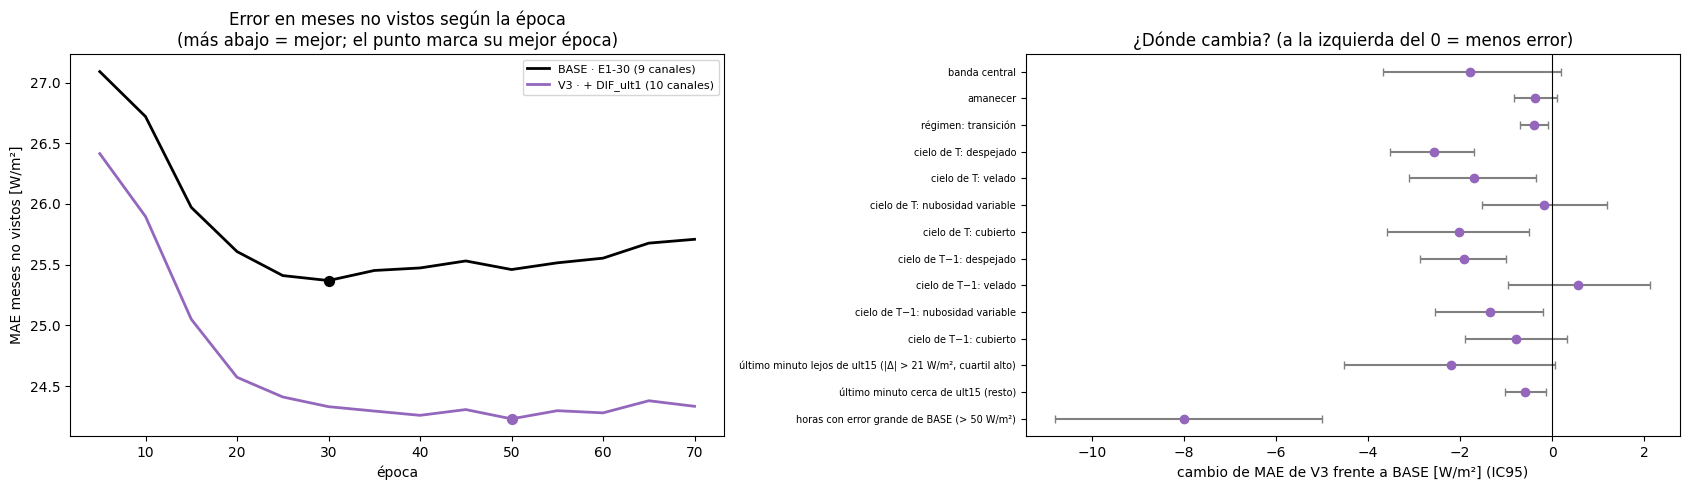


➜ NO PASA por tamaño: V3 mejora -0.99 W/m² (IC95 [-1.62, -0.34]), significativo pero por debajo de 0.5 W/m². E1-30 se mantiene; la señal de R5 queda documentada.
Resultados en: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/diagnostico/faseC_ultimo_minuto


In [ ]:
import os, time, random, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
try:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
except ImportError:
    pass

BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
DIAG = BASE_DIR / "resultados" / "diagnostico"
RUTA_NPZ = (
    BASE_DIR
    / "resultados"
    / "ejecuciones"
    / "preparacion_bloque_difstats_20261006_180841"
    / "matrices_dif_elev_difstats.npz"
)
PARQUET = BASE_DIR / "radiation_data_completo.parquet"
DIR_F1 = DIAG / "fase1_intrahoraria"
DIR_B = DIAG / "faseB_radiografia_E1"
DIR_R0 = DIAG / "faseC_regularizacion" / "C5b_predicciones"
DIR_C8 = DIAG / "faseC_ultimo_minuto"
DIR_P = DIR_C8 / "C8_predicciones"
DIR_P.mkdir(parents=True, exist_ok=True)
SEMILLAS = [42, 123]
MESES_CRIBA = ["2024-01", "2024-03", "2024-05", "2024-07"]
EPOCAS_MAX, CADA, BATCH, LR, WD, HIDDEN = 70, 5, 128, 1e-3, 1e-5, 64
EFECTO_MINIMO = 0.5
ALFA = 0.05
UMBRAL_GRANDE = 50.0
N_BOOT = 2000
FIN_DATOS = pd.Timestamp("2024-10-01")  # nada del test
CONFIGS = {
    "BASE": dict(extra=False, nombre="BASE · E1-30 (9 canales)"),
    "V3": dict(extra=True, nombre="V3 · + DIF_ult1 (10 canales)"),
}

# 1) Entradas: las 9 de E1 + el último minuto de cada hora de la ventana
mat = np.load(RUTA_NPZ)
X_tr = mat["X_train_DIF_elev_DIFstats_raw"].astype(np.float32)
y_tr = mat["y_train_difstats"].astype(np.float32).reshape(-1)
fechas_tr = pd.DatetimeIndex(mat["fechas_train"])
intrahora = pd.read_csv(
    DIR_F1 / "variables_intrahorarias_horarias.csv", index_col=0, parse_dates=True
).asfreq("h")

def a_ventanas(tabla, fechas_obj, columnas, lookback=24):
    f = pd.DatetimeIndex(fechas_obj).to_numpy(dtype="datetime64[ns]")
    idx = f[:, None] - np.arange(lookback, 0, -1).astype("timedelta64[h]")[None, :]  # T−24 … T−1
    vals = tabla.reindex(pd.DatetimeIndex(idx.reshape(-1)))[columnas].to_numpy(
        dtype=np.float32, copy=True
    )
    return vals.reshape(len(f), lookback, len(columnas))

CANALES_E1 = ["DIF_ult15", "DIF_pend30", "DIF_acel60", "DIF_saltos", "SWD_cv"]

def construir(fechas_obj, X_base, canales):
    Xn = a_ventanas(intrahora, fechas_obj, canales)
    for j, c in enumerate(canales):
        hueco = np.isnan(Xn[:, :, j])
        Xn[:, :, j][hueco] = X_base[:, :, 0][hueco] if c == "DIF_ult15" else 0.0
    return np.concatenate([X_base, Xn], axis=2).astype(np.float32)

Xtr_E1 = construir(fechas_tr, X_tr, CANALES_E1)

# DIF_ult1 desde el minutal: último minuto válido entre h:57 y h:59
m = pd.read_parquet(PARQUET, columns=["Date/Time", "DIF [W/m**2]"])
m["Date/Time"] = pd.to_datetime(m["Date/Time"], utc=True).dt.tz_localize(None)
m = m.set_index("Date/Time").sort_index()
m = m[~m.index.duplicated()]
m = m[(m.index >= fechas_tr.min() - pd.Timedelta("26h")) & (m.index < FIN_DATOS)]
assert m.index.max() < FIN_DATOS, "Se estarían leyendo datos del test"
dif = pd.to_numeric(m["DIF [W/m**2]"], errors="coerce").asfreq("min")
ult3 = dif[dif.index.minute >= 57]
ULT1 = (
    ult3.groupby(ult3.index.floor("h")).last().rename("DIF_ult1").to_frame().asfreq("h")
)  # last() salta NaN
assert CANALES_E1[0] == "DIF_ult15" and X_tr.shape[2] == 4, "El canal 4 de E1 debería ser DIF_ult15"
X_ult1 = a_ventanas(ULT1, fechas_tr, ["DIF_ult1"])
hueco = np.isnan(X_ult1[:, :, 0])
X_ult1[:, :, 0][hueco] = Xtr_E1[:, :, 4][
    hueco
]  # hueco → DIF_ult15 (canal 4 de E1; ya relleno con la media)
print(
    f"DIF_ult1: {ULT1['DIF_ult1'].notna().sum():,} horas con dato · huecos en las ventanas de train: {100 * hueco.mean():.2f} % "
    f"(rellenos con DIF_ult15)"
)
Xtr_V3 = np.concatenate([Xtr_E1, X_ult1], axis=2).astype(np.float32)

def entradas(cfg):
    return Xtr_V3 if cfg["extra"] else Xtr_E1

for r, cfg in CONFIGS.items():
    print(f"{cfg['nombre']}: entradas {entradas(cfg).shape}")

H = pd.read_pickle(DIR_B / "tabla_horaria_E1.pkl").sort_index()
TR = H[H["conjunto"] == "train"]
assert (
    len(TR) == len(y_tr) and (TR.index == fechas_tr).all()
), "La tabla horaria no cuadra con el .npz"
SOL = (TR["regimen"] != "noche").to_numpy()
mes = fechas_tr.to_period("M").astype(str).to_numpy()
mes = np.where(mes == "2023-12", "2024-01", mes)

def pliegue(m):
    fuera = mes == m
    fin = fechas_tr[fuera].max()
    purga = (fechas_tr > fin) & (fechas_tr <= fin + pd.Timedelta("24h"))
    return ~fuera & ~purga, fuera


# 2) Entrenamiento (protocolo exacto de E1; solo cambia el canal añadido)
import torch, torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler

class LSTMDIFStats(nn.Module):
    def __init__(self, n_features=4, hidden_size=64):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=n_features, hidden_size=hidden_size, num_layers=1, batch_first=True
        )
        self.head = nn.Sequential(nn.Linear(hidden_size, 32), nn.ReLU(), nn.Linear(32, 1))

    def forward(self, x):
        salida, _ = self.lstm(x)
        return self.head(salida[:, -1, :]).squeeze(-1)

def entrenar(X_all, entrena, fuera, semilla):
    """Predicciones del mes no visto cada 5 épocas (filas = épocas)."""
    Xtr, ytr, Xte = X_all[entrena], y_tr[entrena], X_all[fuera]
    sx_ = StandardScaler().fit(Xtr.reshape(-1, Xtr.shape[2]))
    sy_ = StandardScaler().fit(ytr.reshape(-1, 1))
    e = lambda X: torch.from_numpy(
        sx_.transform(X.reshape(-1, X.shape[2])).reshape(X.shape).astype(np.float32)
    )
    Xtr_t, Xte_t = e(Xtr), e(Xte)
    ytr_e = sy_.transform(ytr.reshape(-1, 1)).ravel().astype(np.float32)
    random.seed(semilla)
    np.random.seed(semilla)
    torch.manual_seed(semilla)
    torch.use_deterministic_algorithms(True)
    modelo = LSTMDIFStats(n_features=Xtr.shape[2], hidden_size=HIDDEN)
    gen = torch.Generator()
    gen.manual_seed(semilla)
    loader = DataLoader(
        TensorDataset(Xtr_t, torch.from_numpy(ytr_e)),
        batch_size=BATCH,
        shuffle=True,
        generator=gen,
        num_workers=0,
    )
    opt = torch.optim.Adam(modelo.parameters(), lr=LR, weight_decay=WD)
    crit = nn.L1Loss()
    preds = []
    for ep in range(1, EPOCAS_MAX + 1):
        modelo.train()
        for xb, yb in loader:
            opt.zero_grad(set_to_none=True)
            loss = crit(modelo(xb), yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(modelo.parameters(), max_norm=1.0)
            opt.step()
        if ep % CADA == 0:
            modelo.eval()
            with torch.no_grad():
                preds.append(sy_.inverse_transform(modelo(Xte_t).numpy().reshape(-1, 1)).ravel())
    return np.array(preds, dtype=np.float32)

def ruta_pred(r, m, s):
    if r == "BASE" and (DIR_R0 / f"R0_{m}_s{s}.npz").exists():
        return DIR_R0 / f"R0_{m}_s{s}.npz"  # R0 de C5b = E1-30 con el mismo protocolo
    return DIR_P / f"{r}_{m}_s{s}.npz"

t_ini = time.time()
tareas = [(r, s, m) for r in CONFIGS for s in SEMILLAS for m in MESES_CRIBA]
for k, (r, s, m) in enumerate(tareas, 1):
    ruta = ruta_pred(r, m, s)
    if ruta.exists():
        print(
            f"[{k}/{len(tareas)}] {r} · {m} · semilla {s}: ya hecho ({'de C5b' if ruta.parent == DIR_R0 else 'C8'})"
        )
        continue
    t0 = time.time()
    entrena, fuera = pliegue(m)
    np.savez(ruta, pred=entrenar(entradas(CONFIGS[r]), entrena, fuera, s))
    print(
        f"[{k}/{len(tareas)}] {r} · {m} · semilla {s}: {time.time()-t0:.0f} s (total {(time.time()-t_ini)/60:.1f} min)"
    )

# 3) Evaluación en los 4 meses no vistos (horas con sol)
EPOCAS = np.arange(CADA, EPOCAS_MAX + 1, CADA)
idx = np.where(np.isin(mes, MESES_CRIBA))[0]
sol = SOL[idx]
y = y_tr[idx]
inf = TR.iloc[idx].copy()
nombre_cielo = lambda s: s.astype(str).replace({"nubes rotas": "nubosidad variable"})
inf["cielo"] = nombre_cielo(inf["cielo"])
cielo_T1 = (
    nombre_cielo(H["cielo"]).reindex(inf.index - pd.Timedelta("1h")).fillna("sin dato").to_numpy()
)
hora = inf.index.hour.to_numpy()
amanecer = (inf["regimen"].astype(str).to_numpy() == "transicion") & (hora < 12)
central = inf["banda"].astype(str).str.startswith("central").to_numpy()
res = {}
for r in CONFIGS:
    P = np.zeros((len(EPOCAS), len(idx)))
    for s in SEMILLAS:
        for m_ in MESES_CRIBA:
            P[:, mes[idx] == m_] += np.load(ruta_pred(r, m_, s))["pred"] / len(SEMILLAS)
    mae_ep = np.abs(P[:, sol] - y[sol]).mean(axis=1)
    suav = pd.Series(mae_ep, index=EPOCAS).rolling(3, center=True, min_periods=1).mean()
    ep = int(suav.idxmin())
    pr = P[list(EPOCAS).index(ep)]
    res[r] = dict(ep=ep, suav=suav, pred=pr, err=np.abs(pr - y))

dias = inf.index.normalize().to_numpy()

def ic(d, msk, alfa=ALFA):
    u, inv = np.unique(dias[msk], return_inverse=True)
    g = [np.where(inv == i)[0] for i in range(len(u))]
    dd = d[msk]
    rng = np.random.default_rng(0)
    medias = [
        dd[np.concatenate([g[i] for i in rng.integers(0, len(g), len(g))])].mean()
        for _ in range(N_BOOT)
    ]
    return (
        dd.mean(),
        np.percentile(medias, 100 * alfa / 2),
        np.percentile(medias, 100 * (1 - alfa / 2)),
    )


# Grupos informativos fijados ANTES de mirar (definidos con entradas o con BASE, nunca con el resultado de V3)
e0, e1 = res["BASE"]["err"], res["V3"]["err"]
d = e1 - e0
ult1_T1 = X_ult1[idx, -1, 0]
ult15_T1 = Xtr_E1[idx, -1, 4]
delta = np.abs(ult1_T1 - ult15_T1)  # cuánto se aleja el último minuto de los últimos 15
umbral_delta = np.nanpercentile(delta[sol], 75)
grupos = [
    ("operación (todas las horas con sol)", np.ones_like(sol)),
    ("banda central", central),
    ("amanecer", amanecer),
    ("régimen: transición", (inf["regimen"] == "transicion").to_numpy()),
]
grupos += [
    ("cielo de T: " + g, (inf["cielo"] == g).to_numpy())
    for g in ["despejado", "velado", "nubosidad variable", "cubierto"]
]
grupos += [
    ("cielo de T−1: " + g, cielo_T1 == g)
    for g in ["despejado", "velado", "nubosidad variable", "cubierto"]
]
grupos += [
    (
        f"último minuto lejos de ult15 (|Δ| > {umbral_delta:.0f} W/m², cuartil alto)",
        delta > umbral_delta,
    ),
    ("último minuto cerca de ult15 (resto)", delta <= umbral_delta),
    (f"horas con error grande de BASE (> {UMBRAL_GRANDE:.0f} W/m²)", e0 > UMBRAL_GRANDE),
]
desglose = []
for nombre, msk in grupos:
    msk = sol & msk
    if msk.sum() >= 30:
        c, lo, hi = ic(d, msk)
        desglose.append(
            {
                "grupo": nombre,
                "horas": int(msk.sum()),
                "MAE BASE": e0[msk].mean(),
                "MAE V3": e1[msk].mean(),
                "cambio": c,
                "IC95": f"[{lo:+.2f}, {hi:+.2f}]",
                "lectura": "mejora" if hi < 0 else ("EMPEORA" if lo > 0 else "igual"),
            }
        )
D = pd.DataFrame(desglose).set_index("grupo")
c, lo, hi = ic(d, sol)
cc, lc, hc = ic(d, sol & central)
ok1, ok2 = (hi < 0 and -c >= EFECTO_MINIMO), hc <= 0
R = pd.DataFrame(
    [
        {
            "configuración": CONFIGS["BASE"]["nombre"],
            "mejor época": res["BASE"]["ep"],
            "MAE operación": e0[sol].mean(),
            "veredicto": "referencia",
        },
        {
            "configuración": CONFIGS["V3"]["nombre"],
            "mejor época": res["V3"]["ep"],
            "MAE operación": e1[sol].mean(),
            "cambio operación": c,
            "IC95 operación": f"[{lo:+.2f}, {hi:+.2f}]",
            "cambio central": cc,
            "IC95 central": f"[{lc:+.2f}, {hc:+.2f}]",
            "1 mejora ≥0,5 e IC<0": ok1,
            "2 central sin empeorar": ok2,
            "veredicto": "PASA A VALIDACIÓN" if (ok1 and ok2) else "no pasa",
        },
    ]
).set_index("configuración")


# ¿Reacciona más V3 al último minuto? (pendiente de la regresión de mediana del error sobre Δ con signo, como en R5)
def lad(x, yv, iters=60):
    A = np.c_[np.ones_like(x), x]
    b = np.linalg.lstsq(A, yv, rcond=None)[0]
    for _ in range(iters):
        w = 1 / np.maximum(np.abs(yv - A @ b), 1e-3)
        b = np.linalg.lstsq(A * np.sqrt(w)[:, None], yv * np.sqrt(w), rcond=None)[0]
    return b

ds = ult1_T1 - ult15_T1
okr = sol & ~np.isnan(ds)
pend = {r: lad(ds[okr], (res[r]["pred"] - y)[okr])[1] for r in CONFIGS}
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 30)
print(
    "\n"
    + "=" * 110
    + "\nC8 · ¿AYUDA EL ÚLTIMO MINUTO DE CADA HORA? (train, 4 meses no vistos, 2 semillas, horas con sol)\n"
    + "=" * 110
)
print("Cambio negativo = menos error que BASE. IC95 bootstrap por días.")
display(R.round(2))
print("\nDesglose (IC95 sin ajustar, solo para entender dónde cambia; no decide):")
display(D.round(2))
print(
    f"\nPendiente del error frente a Δ = ult1 − ult15 en T−1 (regresión de mediana; 0 = el modelo ya usa bien el último minuto):"
)
for r in CONFIGS:
    print(f"   {CONFIGS[r]['nombre']}: b = {pend[r]:+.3f}")

# 4) Gráficas
colores = {"BASE": "black", "V3": "tab:purple"}
fig, axs = plt.subplots(1, 2, figsize=(17, 5))
for r in CONFIGS:
    axs[0].plot(EPOCAS, res[r]["suav"].values, color=colores[r], lw=2, label=CONFIGS[r]["nombre"])
    axs[0].scatter(
        [res[r]["ep"]], [res[r]["suav"].loc[res[r]["ep"]]], color=colores[r], s=50, zorder=3
    )
axs[0].set_xlabel("época")
axs[0].set_ylabel("MAE meses no vistos [W/m²]")
axs[0].legend(fontsize=8)
axs[0].set_title(
    "Error en meses no vistos según la época\n(más abajo = mejor; el punto marca su mejor época)"
)
sub = D.drop(index=D.index[0])
yy = np.arange(len(sub))
lims = sub["IC95"].str.strip("[]").str.split(",", expand=True).astype(float)
axs[1].errorbar(
    sub["cambio"],
    yy,
    xerr=[sub["cambio"] - lims[0], lims[1] - sub["cambio"]],
    fmt="o",
    color="tab:purple",
    ecolor="gray",
    capsize=3,
)
axs[1].axvline(0, color="k", lw=0.8)
axs[1].set_yticks(yy)
axs[1].set_yticklabels(sub.index, fontsize=7)
axs[1].invert_yaxis()
axs[1].set_xlabel("cambio de MAE de V3 frente a BASE [W/m²] (IC95)")
axs[1].set_title("¿Dónde cambia? (a la izquierda del 0 = menos error)")
plt.tight_layout()
plt.savefig(DIR_C8 / "C8_ultimo_minuto.png", dpi=120)
plt.show()

# 5) Veredicto y guardado
if R.loc[CONFIGS["V3"]["nombre"], "veredicto"] == "PASA A VALIDACIÓN":
    ver = (
        f"PASA A VALIDACIÓN: V3 ({c:+.2f} W/m², IC95 [{lo:+.2f}, {hi:+.2f}], mejor época {res['V3']['ep']}). "
        f"Siguiente: confirmación con 5 semillas en validación frente a E1-30."
    )
elif hi < 0:
    ver = (
        f"NO PASA por tamaño: V3 mejora {c:+.2f} W/m² (IC95 [{lo:+.2f}, {hi:+.2f}]), significativo pero por debajo "
        f"de {EFECTO_MINIMO} W/m². E1-30 se mantiene; la señal de R5 queda documentada."
    )
else:
    ver = (
        f"NO PASA: V3 cambia {c:+.2f} W/m² (IC95 [{lo:+.2f}, {hi:+.2f}]). Añadir el último minuto no mejora E1-30 "
        f"de forma fiable. E1-30 se mantiene; la señal de R5 queda documentada."
    )
print("\n➜ " + ver)
R.to_csv(DIR_C8 / "C8_resumen.csv")
D.to_csv(DIR_C8 / "C8_desglose.csv")
pd.DataFrame({r: res[r]["suav"] for r in CONFIGS}).to_csv(DIR_C8 / "C8_curvas.csv")
(DIR_C8 / "C8_veredicto.txt").write_text(ver + "\n", encoding="utf-8")
print("Resultados en:", DIR_C8)

> *Ejecución con la condición de la banda central corregida; reutiliza los modelos entrenados en la celda anterior.*

DIF_ult1: 6,645 horas con dato · huecos en las ventanas de train: 0.06 % (rellenos con DIF_ult15)
BASE · E1-30 (9 canales): entradas (5149, 24, 9)
V3 · + DIF_ult1 (10 canales): entradas (5149, 24, 10)
[1/16] BASE · 2024-01 · semilla 42: ya hecho (de C5b)
[2/16] BASE · 2024-03 · semilla 42: ya hecho (de C5b)
[3/16] BASE · 2024-05 · semilla 42: ya hecho (de C5b)
[4/16] BASE · 2024-07 · semilla 42: ya hecho (de C5b)
[5/16] BASE · 2024-01 · semilla 123: ya hecho (de C5b)
[6/16] BASE · 2024-03 · semilla 123: ya hecho (de C5b)
[7/16] BASE · 2024-05 · semilla 123: ya hecho (de C5b)
[8/16] BASE · 2024-07 · semilla 123: ya hecho (de C5b)
[9/16] V3 · 2024-01 · semilla 42: ya hecho (C8)
[10/16] V3 · 2024-03 · semilla 42: ya hecho (C8)
[11/16] V3 · 2024-05 · semilla 42: ya hecho (C8)
[12/16] V3 · 2024-07 · semilla 42: ya hecho (C8)
[13/16] V3 · 2024-01 · semilla 123: ya hecho (C8)
[14/16] V3 · 2024-03 · semilla 123: ya hecho (C8)
[15/16] V3 · 2024-05 · semilla 123: ya hecho (C8)
[16/16] V3 · 2024-

,mejor época,MAE operación,veredicto,cambio operación,IC95 operación,cambio central,IC95 central,"1 mejora ≥0,5 e IC<0",2 central sin empeorar
configuración,,,,,,,,,
BASE · E1-30 (9 canales),30,25.39,referencia,NaN,NaN,NaN,NaN,NaN,NaN
V3 · + DIF_ult1 (10 canales),50,24.40,PASA A VALIDACIÓN,-0.99,"[-1.62, -0.34]",-1.78,"[-3.67, +0.20]",True,True



Desglose (IC95 sin ajustar, solo para entender dónde cambia; no decide):


,horas,MAE BASE,MAE V3,cambio,IC95,lectura
grupo,,,,,,
operación (todas las horas con sol),1743,25.39,24.40,-0.99,"[-1.62, -0.34]",mejora
banda central,426,46.69,44.91,-1.78,"[-3.67, +0.20]",igual
amanecer,124,3.27,2.91,-0.36,"[-0.83, +0.11]",igual
régimen: transición,247,3.07,2.67,-0.40,"[-0.71, -0.09]",mejora
cielo de T: despejado,248,17.13,14.55,-2.58,"[-3.52, -1.69]",mejora
cielo de T: velado,200,17.23,15.54,-1.69,"[-3.10, -0.36]",mejora
cielo de T: nubosidad variable,803,36.48,36.29,-0.19,"[-1.53, +1.18]",igual
cielo de T: cubierto,245,26.55,24.53,-2.02,"[-3.58, -0.51]",mejora
cielo de T−1: despejado,247,17.59,15.68,-1.91,"[-2.88, -1.00]",mejora



Pendiente del error frente a Δ = ult1 − ult15 en T−1 (regresión de mediana; 0 = el modelo ya usa bien el último minuto):
   BASE · E1-30 (9 canales): b = -0.286
   V3 · + DIF_ult1 (10 canales): b = -0.053


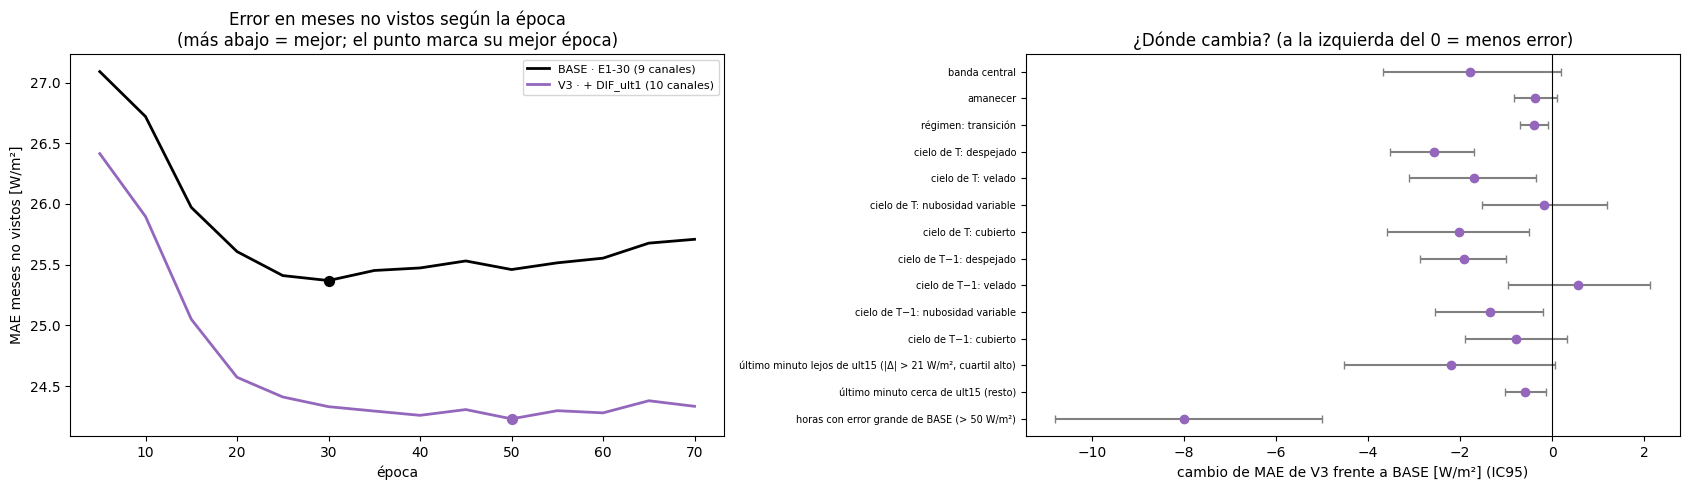


➜ PASA A VALIDACIÓN: V3 (-0.99 W/m², IC95 [-1.62, -0.34], mejor época 50). Siguiente: confirmación con 5 semillas en validación frente a E1-30.
Resultados en: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/diagnostico/faseC_ultimo_minuto


In [ ]:
import os, time, random, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
try:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
except ImportError:
    pass

BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
DIAG = BASE_DIR / "resultados" / "diagnostico"
RUTA_NPZ = (
    BASE_DIR
    / "resultados"
    / "ejecuciones"
    / "preparacion_bloque_difstats_20261006_180841"
    / "matrices_dif_elev_difstats.npz"
)
PARQUET = BASE_DIR / "radiation_data_completo.parquet"
DIR_F1 = DIAG / "fase1_intrahoraria"
DIR_B = DIAG / "faseB_radiografia_E1"
DIR_R0 = DIAG / "faseC_regularizacion" / "C5b_predicciones"
DIR_C8 = DIAG / "faseC_ultimo_minuto"
DIR_P = DIR_C8 / "C8_predicciones"
DIR_P.mkdir(parents=True, exist_ok=True)
SEMILLAS = [42, 123]
MESES_CRIBA = ["2024-01", "2024-03", "2024-05", "2024-07"]
EPOCAS_MAX, CADA, BATCH, LR, WD, HIDDEN = 70, 5, 128, 1e-3, 1e-5, 64
EFECTO_MINIMO = 0.5
ALFA = 0.05
UMBRAL_GRANDE = 50.0
N_BOOT = 2000
FIN_DATOS = pd.Timestamp("2024-10-01")  # nada del test
CONFIGS = {
    "BASE": dict(extra=False, nombre="BASE · E1-30 (9 canales)"),
    "V3": dict(extra=True, nombre="V3 · + DIF_ult1 (10 canales)"),
}

# 1) Entradas: las 9 de E1 + el último minuto de cada hora de la ventana
mat = np.load(RUTA_NPZ)
X_tr = mat["X_train_DIF_elev_DIFstats_raw"].astype(np.float32)
y_tr = mat["y_train_difstats"].astype(np.float32).reshape(-1)
fechas_tr = pd.DatetimeIndex(mat["fechas_train"])
intrahora = pd.read_csv(
    DIR_F1 / "variables_intrahorarias_horarias.csv", index_col=0, parse_dates=True
).asfreq("h")

def a_ventanas(tabla, fechas_obj, columnas, lookback=24):
    f = pd.DatetimeIndex(fechas_obj).to_numpy(dtype="datetime64[ns]")
    idx = f[:, None] - np.arange(lookback, 0, -1).astype("timedelta64[h]")[None, :]  # T−24 … T−1
    vals = tabla.reindex(pd.DatetimeIndex(idx.reshape(-1)))[columnas].to_numpy(
        dtype=np.float32, copy=True
    )
    return vals.reshape(len(f), lookback, len(columnas))

CANALES_E1 = ["DIF_ult15", "DIF_pend30", "DIF_acel60", "DIF_saltos", "SWD_cv"]

def construir(fechas_obj, X_base, canales):
    Xn = a_ventanas(intrahora, fechas_obj, canales)
    for j, c in enumerate(canales):
        hueco = np.isnan(Xn[:, :, j])
        Xn[:, :, j][hueco] = X_base[:, :, 0][hueco] if c == "DIF_ult15" else 0.0
    return np.concatenate([X_base, Xn], axis=2).astype(np.float32)

Xtr_E1 = construir(fechas_tr, X_tr, CANALES_E1)

# DIF_ult1 desde el minutal: último minuto válido entre h:57 y h:59
m = pd.read_parquet(PARQUET, columns=["Date/Time", "DIF [W/m**2]"])
m["Date/Time"] = pd.to_datetime(m["Date/Time"], utc=True).dt.tz_localize(None)
m = m.set_index("Date/Time").sort_index()
m = m[~m.index.duplicated()]
m = m[(m.index >= fechas_tr.min() - pd.Timedelta("26h")) & (m.index < FIN_DATOS)]
assert m.index.max() < FIN_DATOS, "Se estarían leyendo datos del test"
dif = pd.to_numeric(m["DIF [W/m**2]"], errors="coerce").asfreq("min")
ult3 = dif[dif.index.minute >= 57]
ULT1 = (
    ult3.groupby(ult3.index.floor("h")).last().rename("DIF_ult1").to_frame().asfreq("h")
)  # last() salta NaN
assert CANALES_E1[0] == "DIF_ult15" and X_tr.shape[2] == 4, "El canal 4 de E1 debería ser DIF_ult15"
X_ult1 = a_ventanas(ULT1, fechas_tr, ["DIF_ult1"])
hueco = np.isnan(X_ult1[:, :, 0])
X_ult1[:, :, 0][hueco] = Xtr_E1[:, :, 4][
    hueco
]  # hueco → DIF_ult15 (canal 4 de E1; ya relleno con la media)
print(
    f"DIF_ult1: {ULT1['DIF_ult1'].notna().sum():,} horas con dato · huecos en las ventanas de train: {100 * hueco.mean():.2f} % "
    f"(rellenos con DIF_ult15)"
)
Xtr_V3 = np.concatenate([Xtr_E1, X_ult1], axis=2).astype(np.float32)

def entradas(cfg):
    return Xtr_V3 if cfg["extra"] else Xtr_E1

for r, cfg in CONFIGS.items():
    print(f"{cfg['nombre']}: entradas {entradas(cfg).shape}")

H = pd.read_pickle(DIR_B / "tabla_horaria_E1.pkl").sort_index()
TR = H[H["conjunto"] == "train"]
assert (
    len(TR) == len(y_tr) and (TR.index == fechas_tr).all()
), "La tabla horaria no cuadra con el .npz"
SOL = (TR["regimen"] != "noche").to_numpy()
mes = fechas_tr.to_period("M").astype(str).to_numpy()
mes = np.where(mes == "2023-12", "2024-01", mes)

def pliegue(m):
    fuera = mes == m
    fin = fechas_tr[fuera].max()
    purga = (fechas_tr > fin) & (fechas_tr <= fin + pd.Timedelta("24h"))
    return ~fuera & ~purga, fuera


# 2) Entrenamiento (protocolo exacto de E1; solo cambia el canal añadido)
import torch, torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler

class LSTMDIFStats(nn.Module):
    def __init__(self, n_features=4, hidden_size=64):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=n_features, hidden_size=hidden_size, num_layers=1, batch_first=True
        )
        self.head = nn.Sequential(nn.Linear(hidden_size, 32), nn.ReLU(), nn.Linear(32, 1))

    def forward(self, x):
        salida, _ = self.lstm(x)
        return self.head(salida[:, -1, :]).squeeze(-1)

def entrenar(X_all, entrena, fuera, semilla):
    """Predicciones del mes no visto cada 5 épocas (filas = épocas)."""
    Xtr, ytr, Xte = X_all[entrena], y_tr[entrena], X_all[fuera]
    sx_ = StandardScaler().fit(Xtr.reshape(-1, Xtr.shape[2]))
    sy_ = StandardScaler().fit(ytr.reshape(-1, 1))
    e = lambda X: torch.from_numpy(
        sx_.transform(X.reshape(-1, X.shape[2])).reshape(X.shape).astype(np.float32)
    )
    Xtr_t, Xte_t = e(Xtr), e(Xte)
    ytr_e = sy_.transform(ytr.reshape(-1, 1)).ravel().astype(np.float32)
    random.seed(semilla)
    np.random.seed(semilla)
    torch.manual_seed(semilla)
    torch.use_deterministic_algorithms(True)
    modelo = LSTMDIFStats(n_features=Xtr.shape[2], hidden_size=HIDDEN)
    gen = torch.Generator()
    gen.manual_seed(semilla)
    loader = DataLoader(
        TensorDataset(Xtr_t, torch.from_numpy(ytr_e)),
        batch_size=BATCH,
        shuffle=True,
        generator=gen,
        num_workers=0,
    )
    opt = torch.optim.Adam(modelo.parameters(), lr=LR, weight_decay=WD)
    crit = nn.L1Loss()
    preds = []
    for ep in range(1, EPOCAS_MAX + 1):
        modelo.train()
        for xb, yb in loader:
            opt.zero_grad(set_to_none=True)
            loss = crit(modelo(xb), yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(modelo.parameters(), max_norm=1.0)
            opt.step()
        if ep % CADA == 0:
            modelo.eval()
            with torch.no_grad():
                preds.append(sy_.inverse_transform(modelo(Xte_t).numpy().reshape(-1, 1)).ravel())
    return np.array(preds, dtype=np.float32)

def ruta_pred(r, m, s):
    if r == "BASE" and (DIR_R0 / f"R0_{m}_s{s}.npz").exists():
        return DIR_R0 / f"R0_{m}_s{s}.npz"  # R0 de C5b = E1-30 con el mismo protocolo
    return DIR_P / f"{r}_{m}_s{s}.npz"

t_ini = time.time()
tareas = [(r, s, m) for r in CONFIGS for s in SEMILLAS for m in MESES_CRIBA]
for k, (r, s, m) in enumerate(tareas, 1):
    ruta = ruta_pred(r, m, s)
    if ruta.exists():
        print(
            f"[{k}/{len(tareas)}] {r} · {m} · semilla {s}: ya hecho ({'de C5b' if ruta.parent == DIR_R0 else 'C8'})"
        )
        continue
    t0 = time.time()
    entrena, fuera = pliegue(m)
    np.savez(ruta, pred=entrenar(entradas(CONFIGS[r]), entrena, fuera, s))
    print(
        f"[{k}/{len(tareas)}] {r} · {m} · semilla {s}: {time.time()-t0:.0f} s (total {(time.time()-t_ini)/60:.1f} min)"
    )

# 3) Evaluación en los 4 meses no vistos (horas con sol)
EPOCAS = np.arange(CADA, EPOCAS_MAX + 1, CADA)
idx = np.where(np.isin(mes, MESES_CRIBA))[0]
sol = SOL[idx]
y = y_tr[idx]
inf = TR.iloc[idx].copy()
nombre_cielo = lambda s: s.astype(str).replace({"nubes rotas": "nubosidad variable"})
inf["cielo"] = nombre_cielo(inf["cielo"])
cielo_T1 = (
    nombre_cielo(H["cielo"]).reindex(inf.index - pd.Timedelta("1h")).fillna("sin dato").to_numpy()
)
hora = inf.index.hour.to_numpy()
amanecer = (inf["regimen"].astype(str).to_numpy() == "transicion") & (hora < 12)
central = inf["banda"].astype(str).str.startswith("central").to_numpy()
res = {}
for r in CONFIGS:
    P = np.zeros((len(EPOCAS), len(idx)))
    for s in SEMILLAS:
        for m_ in MESES_CRIBA:
            P[:, mes[idx] == m_] += np.load(ruta_pred(r, m_, s))["pred"] / len(SEMILLAS)
    mae_ep = np.abs(P[:, sol] - y[sol]).mean(axis=1)
    suav = pd.Series(mae_ep, index=EPOCAS).rolling(3, center=True, min_periods=1).mean()
    ep = int(suav.idxmin())
    pr = P[list(EPOCAS).index(ep)]
    res[r] = dict(ep=ep, suav=suav, pred=pr, err=np.abs(pr - y))

dias = inf.index.normalize().to_numpy()

def ic(d, msk, alfa=ALFA):
    u, inv = np.unique(dias[msk], return_inverse=True)
    g = [np.where(inv == i)[0] for i in range(len(u))]
    dd = d[msk]
    rng = np.random.default_rng(0)
    medias = [
        dd[np.concatenate([g[i] for i in rng.integers(0, len(g), len(g))])].mean()
        for _ in range(N_BOOT)
    ]
    return (
        dd.mean(),
        np.percentile(medias, 100 * alfa / 2),
        np.percentile(medias, 100 * (1 - alfa / 2)),
    )


# Grupos informativos fijados ANTES de mirar (definidos con entradas o con BASE, nunca con el resultado de V3)
e0, e1 = res["BASE"]["err"], res["V3"]["err"]
d = e1 - e0
ult1_T1 = X_ult1[idx, -1, 0]
ult15_T1 = Xtr_E1[idx, -1, 4]
delta = np.abs(ult1_T1 - ult15_T1)  # cuánto se aleja el último minuto de los últimos 15
umbral_delta = np.nanpercentile(delta[sol], 75)
grupos = [
    ("operación (todas las horas con sol)", np.ones_like(sol)),
    ("banda central", central),
    ("amanecer", amanecer),
    ("régimen: transición", (inf["regimen"] == "transicion").to_numpy()),
]
grupos += [
    ("cielo de T: " + g, (inf["cielo"] == g).to_numpy())
    for g in ["despejado", "velado", "nubosidad variable", "cubierto"]
]
grupos += [
    ("cielo de T−1: " + g, cielo_T1 == g)
    for g in ["despejado", "velado", "nubosidad variable", "cubierto"]
]
grupos += [
    (
        f"último minuto lejos de ult15 (|Δ| > {umbral_delta:.0f} W/m², cuartil alto)",
        delta > umbral_delta,
    ),
    ("último minuto cerca de ult15 (resto)", delta <= umbral_delta),
    (f"horas con error grande de BASE (> {UMBRAL_GRANDE:.0f} W/m²)", e0 > UMBRAL_GRANDE),
]
desglose = []
for nombre, msk in grupos:
    msk = sol & msk
    if msk.sum() >= 30:
        c, lo, hi = ic(d, msk)
        desglose.append(
            {
                "grupo": nombre,
                "horas": int(msk.sum()),
                "MAE BASE": e0[msk].mean(),
                "MAE V3": e1[msk].mean(),
                "cambio": c,
                "IC95": f"[{lo:+.2f}, {hi:+.2f}]",
                "lectura": "mejora" if hi < 0 else ("EMPEORA" if lo > 0 else "igual"),
            }
        )
D = pd.DataFrame(desglose).set_index("grupo")
c, lo, hi = ic(d, sol)
cc, lc, hc = ic(d, sol & central)
ok1, ok2 = (
    hi < 0 and -c >= EFECTO_MINIMO
), lc <= 0  # 2) solo falla si el IC95 central queda ENTERO por encima de 0
R = pd.DataFrame(
    [
        {
            "configuración": CONFIGS["BASE"]["nombre"],
            "mejor época": res["BASE"]["ep"],
            "MAE operación": e0[sol].mean(),
            "veredicto": "referencia",
        },
        {
            "configuración": CONFIGS["V3"]["nombre"],
            "mejor época": res["V3"]["ep"],
            "MAE operación": e1[sol].mean(),
            "cambio operación": c,
            "IC95 operación": f"[{lo:+.2f}, {hi:+.2f}]",
            "cambio central": cc,
            "IC95 central": f"[{lc:+.2f}, {hc:+.2f}]",
            "1 mejora ≥0,5 e IC<0": ok1,
            "2 central sin empeorar": ok2,
            "veredicto": "PASA A VALIDACIÓN" if (ok1 and ok2) else "no pasa",
        },
    ]
).set_index("configuración")


# ¿Reacciona más V3 al último minuto? (pendiente de la regresión de mediana del error sobre Δ con signo, como en R5)
def lad(x, yv, iters=60):
    A = np.c_[np.ones_like(x), x]
    b = np.linalg.lstsq(A, yv, rcond=None)[0]
    for _ in range(iters):
        w = 1 / np.maximum(np.abs(yv - A @ b), 1e-3)
        b = np.linalg.lstsq(A * np.sqrt(w)[:, None], yv * np.sqrt(w), rcond=None)[0]
    return b

ds = ult1_T1 - ult15_T1
okr = sol & ~np.isnan(ds)
pend = {r: lad(ds[okr], (res[r]["pred"] - y)[okr])[1] for r in CONFIGS}
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 30)
print(
    "\n"
    + "=" * 110
    + "\nC8 · ¿AYUDA EL ÚLTIMO MINUTO DE CADA HORA? (train, 4 meses no vistos, 2 semillas, horas con sol)\n"
    + "=" * 110
)
print("Cambio negativo = menos error que BASE. IC95 bootstrap por días.")
display(R.round(2))
print("\nDesglose (IC95 sin ajustar, solo para entender dónde cambia; no decide):")
display(D.round(2))
print(
    f"\nPendiente del error frente a Δ = ult1 − ult15 en T−1 (regresión de mediana; 0 = el modelo ya usa bien el último minuto):"
)
for r in CONFIGS:
    print(f"   {CONFIGS[r]['nombre']}: b = {pend[r]:+.3f}")

# 4) Gráficas
colores = {"BASE": "black", "V3": "tab:purple"}
fig, axs = plt.subplots(1, 2, figsize=(17, 5))
for r in CONFIGS:
    axs[0].plot(EPOCAS, res[r]["suav"].values, color=colores[r], lw=2, label=CONFIGS[r]["nombre"])
    axs[0].scatter(
        [res[r]["ep"]], [res[r]["suav"].loc[res[r]["ep"]]], color=colores[r], s=50, zorder=3
    )
axs[0].set_xlabel("época")
axs[0].set_ylabel("MAE meses no vistos [W/m²]")
axs[0].legend(fontsize=8)
axs[0].set_title(
    "Error en meses no vistos según la época\n(más abajo = mejor; el punto marca su mejor época)"
)
sub = D.drop(index=D.index[0])
yy = np.arange(len(sub))
lims = sub["IC95"].str.strip("[]").str.split(",", expand=True).astype(float)
axs[1].errorbar(
    sub["cambio"],
    yy,
    xerr=[sub["cambio"] - lims[0], lims[1] - sub["cambio"]],
    fmt="o",
    color="tab:purple",
    ecolor="gray",
    capsize=3,
)
axs[1].axvline(0, color="k", lw=0.8)
axs[1].set_yticks(yy)
axs[1].set_yticklabels(sub.index, fontsize=7)
axs[1].invert_yaxis()
axs[1].set_xlabel("cambio de MAE de V3 frente a BASE [W/m²] (IC95)")
axs[1].set_title("¿Dónde cambia? (a la izquierda del 0 = menos error)")
plt.tight_layout()
plt.savefig(DIR_C8 / "C8_ultimo_minuto.png", dpi=120)
plt.show()

# 5) Veredicto y guardado
if R.loc[CONFIGS["V3"]["nombre"], "veredicto"] == "PASA A VALIDACIÓN":
    ver = (
        f"PASA A VALIDACIÓN: V3 ({c:+.2f} W/m², IC95 [{lo:+.2f}, {hi:+.2f}], mejor época {res['V3']['ep']}). "
        f"Siguiente: confirmación con 5 semillas en validación frente a E1-30."
    )
elif not ok2:
    ver = (
        f"NO PASA: V3 empeora la banda central de forma significativa ({cc:+.2f} W/m², IC95 [{lc:+.2f}, {hc:+.2f}]). "
        f"E1-30 se mantiene."
    )
elif hi < 0:
    ver = (
        f"NO PASA por tamaño: V3 mejora {c:+.2f} W/m² (IC95 [{lo:+.2f}, {hi:+.2f}]), significativo pero por debajo "
        f"de {EFECTO_MINIMO} W/m². E1-30 se mantiene; la señal de R5 queda documentada."
    )
else:
    ver = (
        f"NO PASA: V3 cambia {c:+.2f} W/m² (IC95 [{lo:+.2f}, {hi:+.2f}]). Añadir el último minuto no mejora E1-30 "
        f"de forma fiable. E1-30 se mantiene; la señal de R5 queda documentada."
    )
print("\n➜ " + ver)
R.to_csv(DIR_C8 / "C8_resumen.csv")
D.to_csv(DIR_C8 / "C8_desglose.csv")
pd.DataFrame({r: res[r]["suav"] for r in CONFIGS}).to_csv(DIR_C8 / "C8_curvas.csv")
(DIR_C8 / "C8_veredicto.txt").write_text(ver + "\n", encoding="utf-8")
print("Resultados en:", DIR_C8)

**Resultados.** V3 reduce el MAE en horas con sol de 25,39 a 24,40 W/m² (−0,99 W/m², IC95 [−1,62; −0,34]), con su mejor época en la 50, y no empeora la banda central (−1,78 W/m², IC95 [−3,67; +0,20]), por lo que pasa a validación. En el desglose, V3 mejora sobre todo las horas con error grande de E1-30 (−7,99 W/m², IC95 [−10,79; −5,01]) y también las de cielo despejado, velado o cubierto en la hora objetivo, mientras que con nubosidad variable no se distingue (−0,19 W/m²). La pendiente del error frente a la diferencia entre el último minuto y la media de los últimos 15 pasa de −0,29 en E1-30 a −0,05 en V3.

### 12.2 Confirmación de V3-50 en validación

Se entrena V3 con todo el conjunto de entrenamiento durante 50 épocas, la mejor de la criba, con las cinco semillas de E1-30, y su ensemble se compara una sola vez en validación con el de E1-30 (C8b). Según el criterio fijado antes, se confirma si reduce el MAE en horas con sol en al menos 0,5 W/m² con IC95 por debajo de cero sin empeorar de forma significativa la banda central; el desglose y la curva por épocas se informan sin decidir.

> *Con la regla vigente, el veredicto declara V3-50 nuevo modelo de la LSTM. El autor mantuvo después E1-30 como modelo de la LSTM en el test, por las razones que expone el apartado 5.6.1 de la memoria (mecanismo no explicado y margen estrecho).*

Entradas V3: train (5149, 24, 10) | validación (1464, 24, 10)   ← esperado (5149, 24, 10) y (1464, 24, 10)
Huecos de DIF_ult1 rellenos con DIF_ult15: train 0.06 % · validación 0.14 %
Semilla 42: 99 s (total 1.6 min)
Semilla 123: 76 s (total 2.9 min)
Semilla 2024: 77 s (total 4.2 min)
Semilla 7: 77 s (total 5.5 min)
Semilla 99: 77 s (total 6.8 min)

C8b · ¿V3-50 MEJORA A E1-30 EN VALIDACIÓN? (ago–sep 2024, horas con sol, 5 semillas)


,MAE [W/m²],RMSE [W/m²],sesgo [W/m²],ventaja sobre persistencia (%)
"E1-30 (9 canales, oficial)",23.25,36.27,-2.40,48.36
"V3-50 (+ DIF_ult1, 10 canales)",22.47,34.34,-0.77,50.10


Criterio 1 · operación: -0.78 W/m² (-3.4 %), IC95 [-1.50, -0.06] · Diebold–Mariano diario -2.11, p = 0.0393  → cumple
Criterio 2 · banda central: -1.06 W/m², IC95 [-3.74, +1.63]  → cumple

Por semilla (cada modelo por separado): V3 mejora en 5 de 5


,E1-30,V3-50,cambio
s42,24.36,23.01,-1.34
s123,24.28,23.74,-0.55
s2024,24.58,22.85,-1.73
s7,24.45,22.44,-2.01
s99,23.54,23.13,-0.41



Desglose (IC95 sin ajustar; informa, no decide):


,horas,MAE E1-30,MAE V3-50,cambio,IC95,lectura
grupo,,,,,,
amanecer,60,3.36,3.50,0.13,"[-0.06, +0.33]",igual
régimen: completamente_diurno,765,26.46,25.56,-0.89,"[-1.73, -0.05]",mejora
régimen: transicion,119,2.67,2.61,-0.06,"[-0.29, +0.22]",igual
banda: central >40°,205,36.36,35.30,-1.06,"[-3.74, +1.63]",igual
banda: hombros ≤20°,339,9.82,9.55,-0.27,"[-0.73, +0.18]",igual
banda: intermedia 20–40°,340,28.75,27.62,-1.13,"[-2.26, -0.12]",mejora
cielo de T: despejado,185,14.47,13.53,-0.94,"[-1.84, -0.02]",mejora
cielo de T: velado,89,20.12,18.71,-1.40,"[-2.88, +0.04]",igual
cielo de T: nubosidad variable,438,32.20,31.61,-0.58,"[-1.80, +0.65]",igual



Pendiente del error frente a Δ = ult1 − ult15 en T−1 (regresión de mediana; 0 = usa bien el último minuto):
   E1-30: b = -0.311
   V3-50: b = +0.031

Curva de V3 en validación (ensemble; informativa):
   ep5: 24.79 · ep10: 23.62 · ep15: 23.01 · ep20: 23.19 · ep25: 23.00 · ep30: 22.69 · ep35: 22.59 · ep40: 22.49 · ep45: 22.32 · ep50: 22.47 · ep55: 22.19 · ep60: 22.33 · ep65: 22.15 · ep70: 22.34


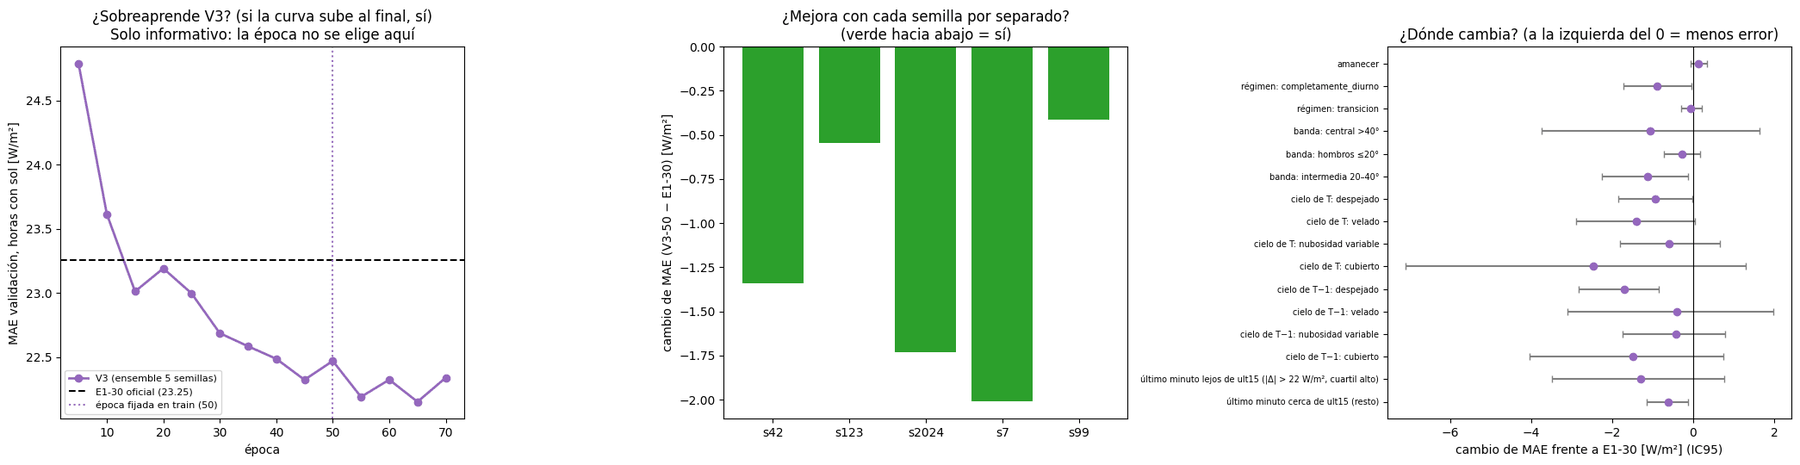


➜ SE ACEPTA: V3-50 baja el MAE de validación de 23.25 a 22.47 W/m² (-3.4 %, IC95 [-1.50, -0.06], DM p = 0.0393) sin empeorar la banda central (-1.06, IC95 [-3.74, +1.63]). Nuevo modelo oficial de la LSTM: V3-50.
Resultados en: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/diagnostico/faseC_ultimo_minuto/C8b_confirmacion


In [ ]:
import os, time, random, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats

warnings.filterwarnings("ignore")
try:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
except ImportError:
    pass

BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
DIAG = BASE_DIR / "resultados" / "diagnostico"
RUTA_NPZ = (
    BASE_DIR
    / "resultados"
    / "ejecuciones"
    / "preparacion_bloque_difstats_20261006_180841"
    / "matrices_dif_elev_difstats.npz"
)
PARQUET = BASE_DIR / "radiation_data_completo.parquet"
DIR_F1 = DIAG / "fase1_intrahoraria"
DIR_B = DIAG / "faseB_radiografia_E1"
DIR_5C = DIAG / "faseC_regularizacion" / "C5c_confirmacion"
DIR_C8 = DIAG / "faseC_ultimo_minuto"
DIR_8B = DIR_C8 / "C8b_confirmacion"
DIR_8B.mkdir(parents=True, exist_ok=True)
SEMILLAS = [42, 123, 2024, 7, 99]
EPOCA_V3, EPOCAS_MAX, CADA = 50, 70, 5
BATCH, LR, WD, HIDDEN = 128, 1e-3, 1e-5, 64
EFECTO_MINIMO = 0.5
N_BOOT = 2000
FIN_DATOS = pd.Timestamp("2024-10-01")  # nada del test

# 1) Entradas: E1 (9 canales) + DIF_ult1, para train y validación
mat = np.load(RUTA_NPZ)
X_tr = mat["X_train_DIF_elev_DIFstats_raw"].astype(np.float32)
y_tr = mat["y_train_difstats"].astype(np.float32).reshape(-1)
X_va = mat["X_validation_DIF_elev_DIFstats_raw"].astype(np.float32)
y_va = mat["y_validation_difstats"].astype(np.float64).reshape(-1)
fechas_tr = pd.DatetimeIndex(mat["fechas_train"])
fechas_va = pd.DatetimeIndex(mat["fechas_validation"])
assert fechas_va.max() < FIN_DATOS, "Validación no debería llegar a octubre"
intrahora = pd.read_csv(
    DIR_F1 / "variables_intrahorarias_horarias.csv", index_col=0, parse_dates=True
).asfreq("h")

def a_ventanas(tabla, fechas_obj, columnas, lookback=24):
    f = pd.DatetimeIndex(fechas_obj).to_numpy(dtype="datetime64[ns]")
    idx = f[:, None] - np.arange(lookback, 0, -1).astype("timedelta64[h]")[None, :]  # T−24 … T−1
    vals = tabla.reindex(pd.DatetimeIndex(idx.reshape(-1)))[columnas].to_numpy(
        dtype=np.float32, copy=True
    )
    return vals.reshape(len(f), lookback, len(columnas))

CANALES_E1 = ["DIF_ult15", "DIF_pend30", "DIF_acel60", "DIF_saltos", "SWD_cv"]

def construir(fechas_obj, X_base, canales):
    Xn = a_ventanas(intrahora, fechas_obj, canales)
    for j, c in enumerate(canales):
        hueco = np.isnan(Xn[:, :, j])
        Xn[:, :, j][hueco] = X_base[:, :, 0][hueco] if c == "DIF_ult15" else 0.0
    return np.concatenate([X_base, Xn], axis=2).astype(np.float32)


# DIF_ult1 = último minuto válido entre h:57 y h:59 (misma definición que en C8)
m = pd.read_parquet(PARQUET, columns=["Date/Time", "DIF [W/m**2]"])
m["Date/Time"] = pd.to_datetime(m["Date/Time"], utc=True).dt.tz_localize(None)
m = m.set_index("Date/Time").sort_index()
m = m[~m.index.duplicated()]
m = m[(m.index >= fechas_tr.min() - pd.Timedelta("26h")) & (m.index < FIN_DATOS)]
assert m.index.max() < FIN_DATOS, "Se estarían leyendo datos del test"
dif = pd.to_numeric(m["DIF [W/m**2]"], errors="coerce").asfreq("min")
ult3 = dif[dif.index.minute >= 57]
ULT1 = ult3.groupby(ult3.index.floor("h")).last().rename("DIF_ult1").to_frame().asfreq("h")
assert CANALES_E1[0] == "DIF_ult15" and X_tr.shape[2] == 4, "El canal 4 de E1 debería ser DIF_ult15"

def construir_v3(fechas_obj, X_base):
    XE1 = construir(fechas_obj, X_base, CANALES_E1)
    u = a_ventanas(ULT1, fechas_obj, ["DIF_ult1"])
    hueco = np.isnan(u[:, :, 0])
    u[:, :, 0][hueco] = XE1[:, :, 4][hueco]  # hueco → DIF_ult15
    return np.concatenate([XE1, u], axis=2).astype(np.float32), 100 * hueco.mean()

Xtr_V3, h_tr = construir_v3(fechas_tr, X_tr)
Xva_V3, h_va = construir_v3(fechas_va, X_va)
print(
    f"Entradas V3: train {Xtr_V3.shape} | validación {Xva_V3.shape}   ← esperado (5149, 24, 10) y (1464, 24, 10)"
)
print(f"Huecos de DIF_ult1 rellenos con DIF_ult15: train {h_tr:.2f} % · validación {h_va:.2f} %")
H = pd.read_pickle(DIR_B / "tabla_horaria_E1.pkl").sort_index()
VA = H[H["conjunto"] == "validation"]
assert (
    len(VA) == len(y_va) and (VA.index == fechas_va).all()
), "La tabla horaria no cuadra con el .npz"

# 2) Entrenamiento (protocolo exacto de E1; solo cambia el canal añadido)
import torch, torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler

class LSTMDIFStats(nn.Module):
    def __init__(self, n_features=4, hidden_size=64):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=n_features, hidden_size=hidden_size, num_layers=1, batch_first=True
        )
        self.head = nn.Sequential(nn.Linear(hidden_size, 32), nn.ReLU(), nn.Linear(32, 1))

    def forward(self, x):
        salida, _ = self.lstm(x)
        return self.head(salida[:, -1, :]).squeeze(-1)

sx = StandardScaler().fit(Xtr_V3.reshape(-1, Xtr_V3.shape[2]))
sy = StandardScaler().fit(y_tr.reshape(-1, 1))
esc = lambda X: torch.from_numpy(
    sx.transform(X.reshape(-1, X.shape[2])).reshape(X.shape).astype(np.float32)
)
Xtr_t, Xva_t = esc(Xtr_V3), esc(Xva_V3)
ytr_e = sy.transform(y_tr.reshape(-1, 1)).ravel().astype(np.float32)

def entrenar(semilla):
    """Predicciones de validación cada 5 épocas (filas = épocas); guarda el modelo de la época 50."""
    random.seed(semilla)
    np.random.seed(semilla)
    torch.manual_seed(semilla)
    torch.use_deterministic_algorithms(True)
    modelo = LSTMDIFStats(n_features=Xtr_V3.shape[2], hidden_size=HIDDEN)
    gen = torch.Generator()
    gen.manual_seed(semilla)
    loader = DataLoader(
        TensorDataset(Xtr_t, torch.from_numpy(ytr_e)),
        batch_size=BATCH,
        shuffle=True,
        generator=gen,
        num_workers=0,
    )
    opt = torch.optim.Adam(modelo.parameters(), lr=LR, weight_decay=WD)
    crit = nn.L1Loss()
    preds = []
    for ep in range(1, EPOCAS_MAX + 1):
        modelo.train()
        for xb, yb in loader:
            opt.zero_grad(set_to_none=True)
            loss = crit(modelo(xb), yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(modelo.parameters(), max_norm=1.0)
            opt.step()
        if ep % CADA == 0:
            modelo.eval()
            with torch.no_grad():
                preds.append(sy.inverse_transform(modelo(Xva_t).numpy().reshape(-1, 1)).ravel())
            if ep == EPOCA_V3:
                torch.save(
                    {"model_state_dict": modelo.state_dict(), "n_features": Xtr_V3.shape[2]},
                    DIR_8B / f"modelo_V3_ep{EPOCA_V3}_s{semilla}.pt",
                )
    return np.array(preds, dtype=np.float32)

t_ini = time.time()
PV = {}
for s in SEMILLAS:
    ruta = DIR_8B / f"pred_validation_V3_s{s}.npz"
    if ruta.exists():
        PV[s] = np.load(ruta)["pred"]
        print(f"Semilla {s}: ya hecha, se carga de Drive")
        continue
    t0 = time.time()
    PV[s] = entrenar(s)
    np.savez(ruta, pred=PV[s])
    print(f"Semilla {s}: {time.time()-t0:.0f} s (total {(time.time()-t_ini)/60:.1f} min)")

# 3) Comparación en validación (horas con sol), ensemble de 5 semillas
EPOCAS = np.arange(CADA, EPOCAS_MAX + 1, CADA)
k50 = list(EPOCAS).index(EPOCA_V3)
sol = (VA["regimen"] != "noche").to_numpy()
inf = VA[sol].copy()
y = y_va[sol]
P_e1 = {s: np.load(DIR_5C / f"pred_validation_s{s}.npz")["ep30"] for s in SEMILLAS}
pred_e1 = np.mean([P_e1[s] for s in SEMILLAS], axis=0)[sol]
pred_v3 = np.mean([PV[s][k50] for s in SEMILLAS], axis=0)[sol]
e1, v3 = np.abs(pred_e1 - y), np.abs(pred_v3 - y)
assert abs(e1.mean() - 23.25) < 0.05, f"No se reproduce el MAE de E1-30 ({e1.mean():.2f})"
mae_pers = np.nanmean(np.abs(inf["persistencia"].to_numpy() - y))
d = v3 - e1
dias = inf.index.normalize().to_numpy()
u, inv = np.unique(dias, return_inverse=True)
grupos_dia = [np.where(inv == i)[0] for i in range(len(u))]
rng = np.random.default_rng(0)
remuestras = [
    np.concatenate([grupos_dia[i] for i in rng.integers(0, len(grupos_dia), len(grupos_dia))])
    for _ in range(N_BOOT)
]

def ic(x, msk=None):
    x = x if msk is None else np.where(msk, x, np.nan)
    medias = [np.nanmean(x[r]) for r in remuestras]
    return np.nanmean(x), np.nanpercentile(medias, 2.5), np.nanpercentile(medias, 97.5)

def dm_diario(x):
    s = pd.Series(x, index=inf.index).groupby(dias).mean().to_numpy()
    Tn = len(s)
    dc = s - s.mean()
    L = int(np.floor(Tn ** (1 / 3)))
    var = dc @ dc / Tn + sum(
        2 * (1 - k / (L + 1)) * (dc[k:] @ dc[:-k]) / Tn for k in range(1, L + 1)
    )
    dm = s.mean() / np.sqrt(var / Tn) * np.sqrt((Tn - 1) / Tn)
    return dm, 2 * stats.t.sf(abs(dm), df=Tn - 1)

c, lo, hi = ic(d)
central = inf["banda"].astype(str).str.startswith("central").to_numpy()
cc, lc, hc = ic(d, central)
dm, p_dm = dm_diario(d)
ok1, ok2 = (hi < 0 and -c >= EFECTO_MINIMO), lc <= 0
rmse = lambda e: np.sqrt(np.mean(e**2))
R = pd.DataFrame(
    {
        "MAE [W/m²]": [e1.mean(), v3.mean()],
        "RMSE [W/m²]": [rmse(pred_e1 - y), rmse(pred_v3 - y)],
        "sesgo [W/m²]": [np.mean(pred_e1 - y), np.mean(pred_v3 - y)],
        "ventaja sobre persistencia (%)": [
            100 * (1 - e1.mean() / mae_pers),
            100 * (1 - v3.mean() / mae_pers),
        ],
    },
    index=["E1-30 (9 canales, oficial)", f"V3-{EPOCA_V3} (+ DIF_ult1, 10 canales)"],
)
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 30)
print(
    "\n"
    + "=" * 110
    + f"\nC8b · ¿V3-{EPOCA_V3} MEJORA A E1-30 EN VALIDACIÓN? (ago–sep 2024, horas con sol, 5 semillas)\n"
    + "=" * 110
)
display(R.round(2))
print(
    f"Criterio 1 · operación: {c:+.2f} W/m² ({100 * c / e1.mean():+.1f} %), IC95 [{lo:+.2f}, {hi:+.2f}] "
    f"· Diebold–Mariano diario {dm:+.2f}, p = {p_dm:.4f}  → {'cumple' if ok1 else 'NO cumple'}"
)
print(
    f"Criterio 2 · banda central: {cc:+.2f} W/m², IC95 [{lc:+.2f}, {hc:+.2f}]  → {'cumple' if ok2 else 'NO cumple'}"
)
por_semilla = pd.DataFrame(
    {
        f"s{s}": [np.abs(P_e1[s][sol] - y).mean(), np.abs(PV[s][k50][sol] - y).mean()]
        for s in SEMILLAS
    },
    index=["E1-30", f"V3-{EPOCA_V3}"],
).T
por_semilla["cambio"] = por_semilla[f"V3-{EPOCA_V3}"] - por_semilla["E1-30"]
print(
    f"\nPor semilla (cada modelo por separado): V3 mejora en {(por_semilla['cambio'] < 0).sum()} de {len(SEMILLAS)}"
)
display(por_semilla.round(2))

# Desglose (informativo): grupos definidos con la tabla horaria o con las entradas, nunca con el error
nombre_cielo = lambda s: s.astype(str).replace({"nubes rotas": "nubosidad variable"})
inf["cielo"] = nombre_cielo(inf["cielo"])
cielo_T1 = (
    nombre_cielo(H["cielo"]).reindex(inf.index - pd.Timedelta("1h")).fillna("sin dato").to_numpy()
)
amanecer = (inf["regimen"].astype(str).to_numpy() == "transicion") & (
    inf.index.hour.to_numpy() < 12
)
ult1_T1 = Xva_V3[sol, -1, 9]
ult15_T1 = Xva_V3[sol, -1, 4]
ds = ult1_T1 - ult15_T1
umbral_delta = np.nanpercentile(np.abs(ds), 75)
grupos = [("amanecer", amanecer)]
grupos += [
    (f"régimen: {g}", (inf["regimen"].astype(str) == g).to_numpy())
    for g in sorted(inf["regimen"].astype(str).unique())
]
grupos += [
    (f"banda: {g}", (inf["banda"].astype(str) == g).to_numpy())
    for g in sorted(inf["banda"].astype(str).unique())
]
grupos += [
    ("cielo de T: " + g, (inf["cielo"] == g).to_numpy())
    for g in ["despejado", "velado", "nubosidad variable", "cubierto"]
]
grupos += [
    ("cielo de T−1: " + g, cielo_T1 == g)
    for g in ["despejado", "velado", "nubosidad variable", "cubierto"]
]
grupos += [
    (
        f"último minuto lejos de ult15 (|Δ| > {umbral_delta:.0f} W/m², cuartil alto)",
        np.abs(ds) > umbral_delta,
    ),
    ("último minuto cerca de ult15 (resto)", np.abs(ds) <= umbral_delta),
]
filas = []
for nombre, msk in grupos:
    if msk.sum() >= 30:
        cg, lg, hg = ic(d, msk)
        filas.append(
            {
                "grupo": nombre,
                "horas": int(msk.sum()),
                "MAE E1-30": e1[msk].mean(),
                f"MAE V3-{EPOCA_V3}": v3[msk].mean(),
                "cambio": cg,
                "IC95": f"[{lg:+.2f}, {hg:+.2f}]",
                "lectura": "mejora" if hg < 0 else ("EMPEORA" if lg > 0 else "igual"),
            }
        )
G = pd.DataFrame(filas).set_index("grupo")
print("\nDesglose (IC95 sin ajustar; informa, no decide):")
display(G.round(2))

def lad(x, yv, iters=60):
    A = np.c_[np.ones_like(x), x]
    b = np.linalg.lstsq(A, yv, rcond=None)[0]
    for _ in range(iters):
        w = 1 / np.maximum(np.abs(yv - A @ b), 1e-3)
        b = np.linalg.lstsq(A * np.sqrt(w)[:, None], yv * np.sqrt(w), rcond=None)[0]
    return b

okr = ~np.isnan(ds)
pend = {
    "E1-30": lad(ds[okr], (pred_e1 - y)[okr])[1],
    f"V3-{EPOCA_V3}": lad(ds[okr], (pred_v3 - y)[okr])[1],
}
print(
    "\nPendiente del error frente a Δ = ult1 − ult15 en T−1 (regresión de mediana; 0 = usa bien el último minuto):"
)
for k_, b_ in pend.items():
    print(f"   {k_}: b = {b_:+.3f}")

# Curva de validación (solo para ver el sobreaprendizaje; la época ya estaba fijada)
curva = pd.Series(
    [
        np.abs(np.mean([PV[s][k] for s in SEMILLAS], axis=0)[sol] - y).mean()
        for k in range(len(EPOCAS))
    ],
    index=EPOCAS,
)
print("\nCurva de V3 en validación (ensemble; informativa):")
print("   " + " · ".join(f"ep{e}: {v:.2f}" for e, v in curva.items()))

# 4) Gráficas
fig, axs = plt.subplots(1, 3, figsize=(21, 5.5))
axs[0].plot(
    EPOCAS, curva.values, color="tab:purple", lw=2, marker="o", label="V3 (ensemble 5 semillas)"
)
axs[0].axhline(e1.mean(), color="black", ls="--", label=f"E1-30 oficial ({e1.mean():.2f})")
axs[0].axvline(EPOCA_V3, color="tab:purple", ls=":", label=f"época fijada en train ({EPOCA_V3})")
axs[0].set_xlabel("época")
axs[0].set_ylabel("MAE validación, horas con sol [W/m²]")
axs[0].legend(fontsize=8)
axs[0].set_title(
    "¿Sobreaprende V3? (si la curva sube al final, sí)\nSolo informativo: la época no se elige aquí"
)
x = np.arange(len(SEMILLAS))
axs[1].bar(
    x,
    por_semilla["cambio"],
    color=["tab:green" if v < 0 else "tab:red" for v in por_semilla["cambio"]],
)
axs[1].axhline(0, color="k", lw=0.8)
axs[1].set_xticks(x)
axs[1].set_xticklabels(por_semilla.index)
axs[1].set_ylabel(f"cambio de MAE (V3-{EPOCA_V3} − E1-30) [W/m²]")
axs[1].set_title("¿Mejora con cada semilla por separado?\n(verde hacia abajo = sí)")
lims = G["IC95"].str.strip("[]").str.split(",", expand=True).astype(float)
yy = np.arange(len(G))
axs[2].errorbar(
    G["cambio"],
    yy,
    xerr=[G["cambio"] - lims[0], lims[1] - G["cambio"]],
    fmt="o",
    color="tab:purple",
    ecolor="gray",
    capsize=3,
)
axs[2].axvline(0, color="k", lw=0.8)
axs[2].set_yticks(yy)
axs[2].set_yticklabels(G.index, fontsize=7)
axs[2].invert_yaxis()
axs[2].set_xlabel("cambio de MAE frente a E1-30 [W/m²] (IC95)")
axs[2].set_title("¿Dónde cambia? (a la izquierda del 0 = menos error)")
plt.tight_layout()
plt.savefig(DIR_8B / "C8b_confirmacion.png", dpi=120)
plt.show()

# 5) Veredicto y guardado
if ok1 and ok2:
    ver = (
        f"SE ACEPTA: V3-{EPOCA_V3} baja el MAE de validación de {e1.mean():.2f} a {v3.mean():.2f} W/m² "
        f"({100 * c / e1.mean():+.1f} %, IC95 [{lo:+.2f}, {hi:+.2f}], DM p = {p_dm:.4f}) sin empeorar la banda central "
        f"({cc:+.2f}, IC95 [{lc:+.2f}, {hc:+.2f}]). Nuevo modelo oficial de la LSTM: V3-{EPOCA_V3}."
    )
elif not ok2:
    ver = (
        f"NO SE ACEPTA: V3-{EPOCA_V3} empeora la banda central de forma significativa ({cc:+.2f}, IC95 [{lc:+.2f}, {hc:+.2f}]). "
        f"E1-30 sigue siendo el oficial."
    )
elif hi < 0:
    ver = (
        f"NO SE ACEPTA por tamaño: V3-{EPOCA_V3} mejora {c:+.2f} W/m² (IC95 [{lo:+.2f}, {hi:+.2f}]), significativo pero "
        f"menor que {EFECTO_MINIMO} W/m². E1-30 sigue siendo el oficial."
    )
else:
    ver = (
        f"NO SE ACEPTA: el cambio ({c:+.2f} W/m², IC95 [{lo:+.2f}, {hi:+.2f}]) no se distingue del azar. "
        f"E1-30 sigue siendo el oficial."
    )
print("\n➜ " + ver)
R.to_csv(DIR_8B / "C8b_resumen.csv")
G.to_csv(DIR_8B / "C8b_desglose.csv")
por_semilla.to_csv(DIR_8B / "C8b_por_semilla.csv")
curva.rename("MAE_validacion_V3").to_csv(DIR_8B / "C8b_curva_validacion.csv")
pd.DataFrame(
    {
        "real": y_va,
        "E1_30": np.mean([P_e1[s] for s in SEMILLAS], axis=0),
        f"V3_{EPOCA_V3}": np.mean([PV[s][k50] for s in SEMILLAS], axis=0),
    },
    index=fechas_va,
).to_pickle(DIR_8B / "C8b_predicciones_validacion.pkl")
(DIR_8B / "C8b_veredicto.txt").write_text(ver + "\n", encoding="utf-8")
print("Resultados en:", DIR_8B)

**Resultados.** V3-50 obtiene un MAE de 22,47 W/m², frente a 23,25 W/m² de E1-30: −0,78 W/m² (−3,4 %; IC95 [−1,50; −0,06]; Diebold–Mariano p = 0,039), sin empeorar la banda central (−1,06 W/m², IC95 [−3,74; +1,63]). Mejora en las cinco semillas, entre 0,41 y 2,01 W/m², y reduce el sesgo de −2,40 a −0,77 W/m² y el RMSE de 36,27 a 34,34 W/m². Cumple, por tanto, el criterio de confirmación.

### 12.3 Radiografía comparada de E1-30 y V3-50

Se compara el error de E1-30 y V3-50 en las horas con sol de validación por régimen, banda de elevación, tipo de cielo y tipo de hora según la DIF minutal, con definiciones que no dependen del error de ningún modelo (R6). Antes de mirar se dejó escrita la expectativa de que V3 mejoraría sobre todo las horas cuyo cambio ya era visible al emitir (tipo A) y poco las de cambio temprano o tardío (B y C). Los intervalos son solo descriptivos.

Comprobación: MAE E1-30 = 23.25 (esperado 23.25) · MAE V3-50 = 22.47 (esperado 22.47)

R6 · por régimen (validación, horas con sol; cambio negativo = V3-50 tiene menos error)


,horas,DIF media,MAE E1-30,MAE V3-50,cambio MAE,IC95,lectura,sesgo E1-30,sesgo V3-50,RMSE E1-30,RMSE V3-50,% grandes E1-30,% grandes V3-50
TODAS,884.0,141.80,23.25,22.47,-0.78,"[-1.50, -0.06]",mejora,-2.40,-0.77,36.27,34.34,14.25,14.37
transicion,119.0,7.28,2.67,2.61,-0.06,"[-0.29, +0.22]",igual,-0.44,-0.95,3.68,3.85,0.00,0.00
completamente_diurno,765.0,162.72,26.46,25.56,-0.89,"[-1.73, -0.05]",mejora,-2.70,-0.74,38.97,36.88,16.47,16.60



R6 · por banda (validación, horas con sol; cambio negativo = V3-50 tiene menos error)


,horas,DIF media,MAE E1-30,MAE V3-50,cambio MAE,IC95,lectura,sesgo E1-30,sesgo V3-50,RMSE E1-30,RMSE V3-50,% grandes E1-30,% grandes V3-50
TODAS,884.0,141.80,23.25,22.47,-0.78,"[-1.50, -0.06]",mejora,-2.40,-0.77,36.27,34.34,14.25,14.37
central >40°,205.0,250.79,36.36,35.30,-1.06,"[-3.74, +1.63]",igual,-2.68,-1.29,51.11,48.47,25.37,29.27
hombros ≤20°,339.0,44.87,9.82,9.55,-0.27,"[-0.73, +0.18]",igual,-2.55,-1.31,15.20,14.73,1.47,1.47
intermedia 20–40°,340.0,172.73,28.75,27.62,-1.13,"[-2.26, -0.12]",mejora,-2.07,0.09,40.20,37.86,20.29,18.24



R6 · por cielo de T (validación, horas con sol; cambio negativo = V3-50 tiene menos error)


,horas,DIF media,MAE E1-30,MAE V3-50,cambio MAE,IC95,lectura,sesgo E1-30,sesgo V3-50,RMSE E1-30,RMSE V3-50,% grandes E1-30,% grandes V3-50
TODAS,884.0,141.80,23.25,22.47,-0.78,"[-1.50, -0.06]",mejora,-2.40,-0.77,36.27,34.34,14.25,14.37
despejado,185.0,125.24,14.47,13.53,-0.94,"[-1.84, -0.02]",mejora,5.59,7.09,24.89,23.45,5.41,4.86
velado,89.0,125.95,20.12,18.71,-1.40,"[-2.88, +0.04]",igual,-0.46,2.42,29.60,28.07,8.99,7.87
nubosidad variable,438.0,195.13,32.20,31.61,-0.58,"[-1.80, +0.65]",igual,-9.63,-7.31,43.95,42.32,21.92,22.83
cubierto,53.0,87.50,31.50,29.04,-2.47,"[-7.09, +1.29]",igual,21.89,20.93,48.16,39.89,22.64,20.75


... (9 outputs left out)

V3-50,grande en V3-50,pequeño en V3-50
E1-30,,
grande en E1-30,105,21
pequeño en E1-30,22,736



Concentración del error y rachas:


,% del error en el peor 10 % de horas,% del error en el peor 10 % de días,horas con error grande,episodios,% horas grandes en rachas ≥2 h,RMSE/MAE
E1-30,39.2,21.0,126.0,88.0,52.4,1.6
V3-50,37.8,21.6,127.0,81.0,58.3,1.5



Días: V3-50 tiene menos error en 38 de 61 días


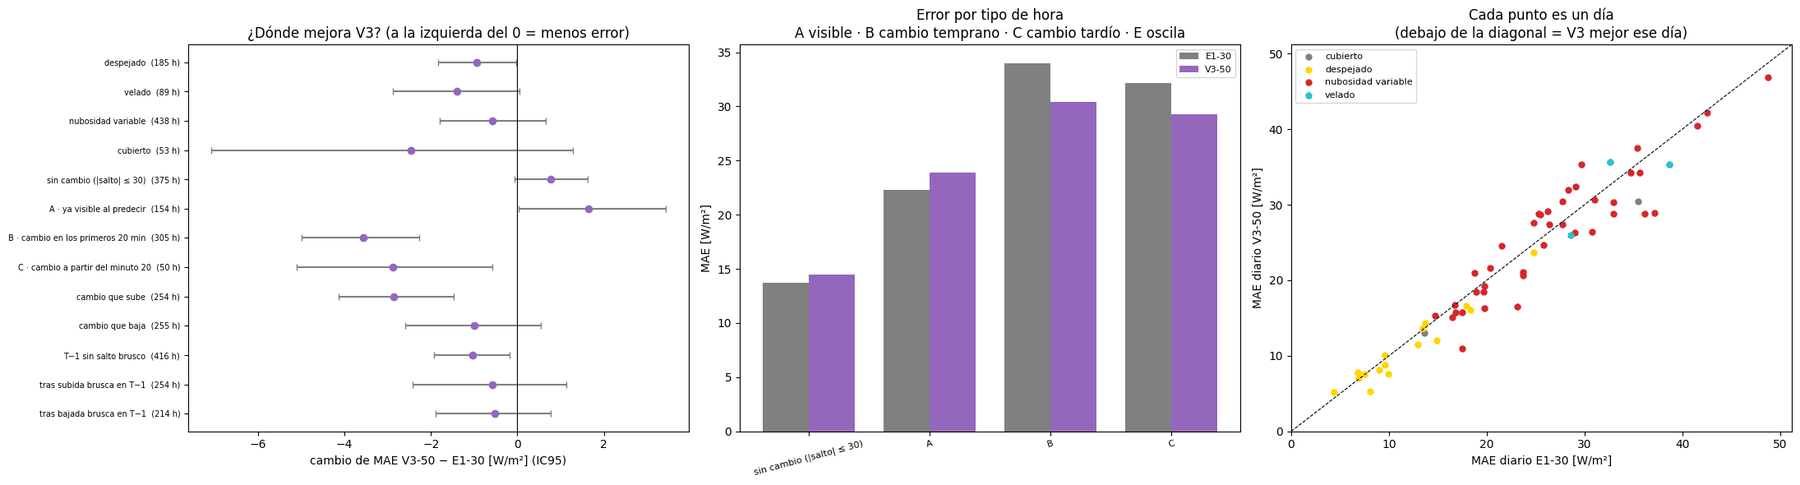

Resultados en: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/diagnostico/R6_radiografia_V3


In [ ]:
import os
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

try:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
except ImportError:
    pass

BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
DIAG = BASE_DIR / "resultados" / "diagnostico"
PARQUET = BASE_DIR / "radiation_data_completo.parquet"
RUTA_TABLA = DIAG / "faseB_radiografia_E1" / "tabla_horaria_E1.pkl"
RUTA_PRED = DIAG / "faseC_ultimo_minuto" / "C8b_confirmacion" / "C8b_predicciones_validacion.pkl"
SALIDA = DIAG / "R6_radiografia_V3"
SALIDA.mkdir(parents=True, exist_ok=True)
UMBRAL_GRANDE, UMBRAL_SALTO = 50.0, 30.0
N_BOOT = 2000
FIN_DATOS = pd.Timestamp("2024-10-01")
MODELOS = {"E1_30": "E1-30", "V3_50": "V3-50"}

# 1) Datos
T = pd.read_pickle(RUTA_TABLA).sort_index()
VA = T[T["conjunto"] == "validation"].copy()
P = pd.read_pickle(RUTA_PRED)
assert (P.index == VA.index).all() and np.allclose(
    P["real"], VA["real"]
), "Las predicciones de C8b no cuadran con la tabla"
for k in MODELOS:
    VA[k] = P[k].to_numpy()
real_T2 = T["real"].reindex(VA.index - pd.Timedelta("2h")).to_numpy()
VA["pre_salto"] = T["real"].reindex(VA.index - pd.Timedelta("1h")).to_numpy() - real_T2
VA = VA[VA["regimen"] != "noche"].copy()
VA["cielo"] = VA["cielo"].astype(str).replace({"nubes rotas": "nubosidad variable"})
VA["regimen"] = VA["regimen"].astype(str)
VA["cielo_T1"] = (
    T["cielo"]
    .astype(str)
    .replace({"nubes rotas": "nubosidad variable"})
    .reindex(VA.index - pd.Timedelta("1h"))
    .fillna("sin dato")
    .to_numpy()
)
for k in MODELOS:
    VA[f"e_{k}"] = VA[k] - VA["real"]
mae = {k: VA[f"e_{k}"].abs().mean() for k in MODELOS}
print(
    f"Comprobación: MAE E1-30 = {mae['E1_30']:.2f} (esperado 23.25) · MAE V3-50 = {mae['V3_50']:.2f} (esperado 22.47)"
)
assert abs(mae["E1_30"] - 23.25) < 0.05 and abs(mae["V3_50"] - 22.47) < 0.05

# Tipo de hora a partir de la DIF minutal (no usa ninguna predicción)
m = pd.read_parquet(PARQUET, columns=["Date/Time", "DIF [W/m**2]"])
m["Date/Time"] = pd.to_datetime(m["Date/Time"], utc=True).dt.tz_localize(None)
m = m.set_index("Date/Time").sort_index()
m = m[~m.index.duplicated()]
m = m[(m.index >= VA.index.min() - pd.Timedelta("2h")) & (m.index < FIN_DATOS)]
assert m.index.max() < FIN_DATOS, "Se estarían leyendo datos del test"
dif = pd.to_numeric(m["DIF [W/m**2]"], errors="coerce").asfreq("min")

def minutos(horas, desde, n=60):
    base = pd.DatetimeIndex(horas).to_numpy(dtype="datetime64[m]")
    idx = base[:, None] + (np.arange(n) + desde).astype("timedelta64[m]")[None, :]
    return dif.reindex(pd.DatetimeIndex(idx.ravel())).to_numpy().reshape(len(horas), n)

prev, act = minutos(VA.index, -60), minutos(VA.index, 0)
tipos, saltos = [], []
for pv, ac in zip(prev, act):
    if np.sum(~np.isnan(pv)) < 30 or np.sum(~np.isnan(ac)) < 30:
        tipos.append("sin dato minutal")
        saltos.append(np.nan)
        continue
    mp, ma, u15 = np.nanmean(pv), np.nanmean(ac), np.nanmean(pv[-15:])
    salto = ma - mp
    saltos.append(salto)
    if abs(salto) <= UMBRAL_SALTO:
        tipos.append("sin cambio (|salto| ≤ 30)")
        continue
    if abs(ma - u15) <= 0.5 * abs(salto):
        tipos.append("A · ya visible al predecir")
        continue
    suave = pd.Series(ac).rolling(5, min_periods=3).mean().to_numpy()
    mitad = (u15 + ma) / 2
    cruza = np.where((suave >= mitad) if ma > u15 else (suave <= mitad))[0]
    tipos.append(
        "E · sin cambio claro"
        if len(cruza) == 0
        else (
            "B · cambio en los primeros 20 min"
            if cruza[0] < 20
            else "C · cambio a partir del minuto 20"
        )
    )
VA["tipo"] = tipos
VA["salto_min"] = saltos
VA["sentido"] = np.where(VA["salto_min"] > 0, "sube", "baja")

# 2) Herramientas
dias = VA.index.normalize().to_numpy()
u, inv = np.unique(dias, return_inverse=True)
grupos_dia = [np.where(inv == i)[0] for i in range(len(u))]
rng = np.random.default_rng(0)
remuestras = [
    np.concatenate([grupos_dia[i] for i in rng.integers(0, len(grupos_dia), len(grupos_dia))])
    for _ in range(N_BOOT)
]
d_abs = VA["e_V3_50"].abs().to_numpy() - VA["e_E1_30"].abs().to_numpy()

def ic(msk):
    x = np.where(msk, d_abs, np.nan)
    medias = [np.nanmean(x[r]) for r in remuestras]
    return np.nanmean(x), np.nanpercentile(medias, 2.5), np.nanpercentile(medias, 97.5)

def episodios(e, idx):
    g = idx[np.abs(e) > UMBRAL_GRANDE]
    if len(g) == 0:
        return 0, np.nan
    nuevo = np.r_[
        True,
        (np.diff(g.values).astype("timedelta64[h]").astype(int) != 1) | (g[1:].date != g[:-1].date),
    ]
    largos = pd.Series(np.cumsum(nuevo)).value_counts()
    return len(largos), 100 * largos[largos >= 2].sum() / len(g)

def metricas(D):
    y = D["real"].to_numpy()
    out = {"horas": len(D), "DIF media": y.mean()}
    for k, nom in MODELOS.items():
        e = D[f"e_{k}"].to_numpy()
        ae = np.abs(e)
        out[f"MAE {nom}"] = ae.mean()
    out["cambio MAE"], lo, hi = ic(VA.index.isin(D.index))
    out["IC95"] = f"[{lo:+.2f}, {hi:+.2f}]"
    out["lectura"] = "mejora" if hi < 0 else ("EMPEORA" if lo > 0 else "igual")
    for k, nom in MODELOS.items():
        e = D[f"e_{k}"].to_numpy()
        ae = np.abs(e)
        out[f"RMSE {nom}"] = np.sqrt((e**2).mean())
        out[f"nMAE {nom} (%)"] = 100 * ae.mean() / y.mean() if y.mean() > 0 else np.nan
        out[f"sesgo {nom}"] = e.mean()
        out[f"% grandes {nom}"] = 100 * (ae > UMBRAL_GRANDE).mean()
    return out

def tabla(col, orden):
    filas = {"TODAS": metricas(VA)}
    for g in orden:
        if (VA[col] == g).sum() >= 20:
            filas[g] = metricas(VA[VA[col] == g])
    R = pd.DataFrame(filas).T
    for c in R.columns:
        if c not in ("IC95", "lectura"):
            R[c] = R[c].astype(float)
    return R

pd.set_option("display.width", 280)
pd.set_option("display.max_columns", 40)
# 3) Tablas
ORD_REG = ["transicion", "completamente_diurno"]
ORD_CIELO = ["despejado", "velado", "nubosidad variable", "cubierto"]
ORD_TIPO = [
    "sin cambio (|salto| ≤ 30)",
    "A · ya visible al predecir",
    "B · cambio en los primeros 20 min",
    "C · cambio a partir del minuto 20",
    "E · sin cambio claro",
    "sin dato minutal",
]
VA["banda"] = VA["banda"].astype(str)
ORD_BANDA = sorted(VA["banda"].unique())
VA["antes"] = np.where(
    VA["pre_salto"] > UMBRAL_SALTO,
    "tras subida brusca en T−1",
    np.where(VA["pre_salto"] < -UMBRAL_SALTO, "tras bajada brusca en T−1", "T−1 sin salto brusco"),
)
VA["salto_T"] = np.where(
    (VA["tipo"] == "sin cambio (|salto| ≤ 30)") | (VA["tipo"] == "sin dato minutal"),
    "sin cambio",
    "cambio que " + VA["sentido"],
)
TABLAS = {
    "régimen": tabla("regimen", ORD_REG),
    "banda": tabla("banda", ORD_BANDA),
    "cielo de T": tabla("cielo", ORD_CIELO),
    "cielo de T−1": tabla("cielo_T1", ORD_CIELO),
    "tipo de hora (DIF minutal)": tabla("tipo", ORD_TIPO),
    "sentido del cambio en T": tabla(
        "salto_T", ["sin cambio", "cambio que sube", "cambio que baja"]
    ),
    "qué pasó en T−1": tabla(
        "antes", ["T−1 sin salto brusco", "tras subida brusca en T−1", "tras bajada brusca en T−1"]
    ),
}
cols_cortas = [
    "horas",
    "DIF media",
    "MAE E1-30",
    "MAE V3-50",
    "cambio MAE",
    "IC95",
    "lectura",
    "sesgo E1-30",
    "sesgo V3-50",
    "RMSE E1-30",
    "RMSE V3-50",
    "% grandes E1-30",
    "% grandes V3-50",
]
for nombre, R in TABLAS.items():
    print(
        "\n"
        + "=" * 120
        + f"\nR6 · por {nombre} (validación, horas con sol; cambio negativo = V3-50 tiene menos error)\n"
        + "=" * 120
    )
    display(R[cols_cortas].round(2))

# Errores grandes: tabla 2×2 simétrica (no condiciona en un solo modelo)
gE, gV = VA["e_E1_30"].abs() > UMBRAL_GRANDE, VA["e_V3_50"].abs() > UMBRAL_GRANDE
cruce = pd.crosstab(
    pd.Series(np.where(gE, "grande en E1-30", "pequeño en E1-30"), name="E1-30"),
    pd.Series(np.where(gV, "grande en V3-50", "pequeño en V3-50"), name="V3-50"),
)
print(
    f"\nHoras con error grande (> {UMBRAL_GRANDE:.0f} W/m²): E1-30 {gE.sum()} · V3-50 {gV.sum()} · en las dos {int((gE & gV).sum())}"
)
display(cruce)

# Concentración y rachas
filas = {}
for k, nom in MODELOS.items():
    e = VA[f"e_{k}"].to_numpy()
    ae = np.abs(e)
    dia_err = pd.Series(ae, index=VA.index).groupby(dias).sum().sort_values(ascending=False)
    n_ep, pct = episodios(e, VA.index)
    filas[nom] = {
        "% del error en el peor 10 % de horas": 100
        * np.sort(ae)[::-1][: int(np.ceil(0.1 * len(ae)))].sum()
        / ae.sum(),
        "% del error en el peor 10 % de días": 100
        * dia_err.iloc[: int(np.ceil(0.1 * len(dia_err)))].sum()
        / ae.sum(),
        "horas con error grande": int((ae > UMBRAL_GRANDE).sum()),
        "episodios": n_ep,
        "% horas grandes en rachas ≥2 h": pct,
        "RMSE/MAE": np.sqrt((e**2).mean()) / ae.mean(),
    }
CONC = pd.DataFrame(filas).T
print("\nConcentración del error y rachas:")
display(CONC.round(1))

# Los días que más cambian (dónde se nota V3)
D_dia = pd.DataFrame(
    {
        "MAE E1-30": VA["e_E1_30"].abs().groupby(dias).mean(),
        "MAE V3-50": VA["e_V3_50"].abs().groupby(dias).mean(),
        "cielo dominante": VA.groupby(dias)["cielo"].agg(lambda s: s.value_counts().index[0]),
    }
)
D_dia["cambio"] = D_dia["MAE V3-50"] - D_dia["MAE E1-30"]
print(f"\nDías: V3-50 tiene menos error en {(D_dia['cambio'] < 0).sum()} de {len(D_dia)} días")

# 4) Gráficas
fig, axs = plt.subplots(1, 3, figsize=(22, 6))
filas_g = []
for nombre in [
    "cielo de T",
    "tipo de hora (DIF minutal)",
    "sentido del cambio en T",
    "qué pasó en T−1",
]:
    R = TABLAS[nombre].drop(index="TODAS")
    for g, r in R.iterrows():
        if g == "sin cambio":  # ya aparece como tipo de hora
            continue
        lo, hi = [float(v) for v in r["IC95"].strip("[]").split(",")]
        filas_g.append((f"{g}  ({int(r['horas'])} h)", r["cambio MAE"], lo, hi))
yy = np.arange(len(filas_g))
axs[0].errorbar(
    [f[1] for f in filas_g],
    yy,
    xerr=[[f[1] - f[2] for f in filas_g], [f[3] - f[1] for f in filas_g]],
    fmt="o",
    color="tab:purple",
    ecolor="gray",
    capsize=3,
)
axs[0].axvline(0, color="k", lw=0.8)
axs[0].set_yticks(yy)
axs[0].set_yticklabels([f[0] for f in filas_g], fontsize=7)
axs[0].invert_yaxis()
axs[0].set_xlabel("cambio de MAE V3-50 − E1-30 [W/m²] (IC95)")
axs[0].set_title("¿Dónde mejora V3? (a la izquierda del 0 = menos error)")
Rt = TABLAS["tipo de hora (DIF minutal)"].drop(index="TODAS")
x = np.arange(len(Rt))
w = 0.38
axs[1].bar(x - w / 2, Rt["MAE E1-30"], w, color="gray", label="E1-30")
axs[1].bar(x + w / 2, Rt["MAE V3-50"], w, color="tab:purple", label="V3-50")
axs[1].set_xticks(x)
axs[1].set_xticklabels(
    [t.split(" · ")[0] if " · " in t else t for t in Rt.index], fontsize=8, rotation=15
)
axs[1].set_ylabel("MAE [W/m²]")
axs[1].legend(fontsize=8)
axs[1].set_title(
    "Error por tipo de hora\nA visible · B cambio temprano · C cambio tardío · E oscila"
)
lim = max(D_dia[["MAE E1-30", "MAE V3-50"]].max()) * 1.05
colores = {
    "despejado": "gold",
    "velado": "tab:cyan",
    "nubosidad variable": "tab:red",
    "cubierto": "gray",
}
for c, sub in D_dia.groupby("cielo dominante"):
    axs[2].scatter(sub["MAE E1-30"], sub["MAE V3-50"], s=25, color=colores.get(c, "k"), label=c)
axs[2].plot([0, lim], [0, lim], "k--", lw=0.8)
axs[2].set_xlim(0, lim)
axs[2].set_ylim(0, lim)
axs[2].set_xlabel("MAE diario E1-30 [W/m²]")
axs[2].set_ylabel("MAE diario V3-50 [W/m²]")
axs[2].legend(fontsize=8)
axs[2].set_title("Cada punto es un día\n(debajo de la diagonal = V3 mejor ese día)")
plt.tight_layout()
plt.savefig(SALIDA / "R6_donde_mejora_V3.png", dpi=120)
plt.show()

# 5) Guardado
for nombre, R in TABLAS.items():
    R.to_csv(SALIDA / f"R6_por_{nombre.split(' (')[0].replace(' ', '_').replace('−', '-')}.csv")
CONC.to_csv(SALIDA / "R6_concentracion.csv")
cruce.to_csv(SALIDA / "R6_errores_grandes_2x2.csv")
D_dia.to_csv(SALIDA / "R6_por_dia.csv")
VA[
    ["regimen", "banda", "cielo", "cielo_T1", "tipo", "salto_T", "antes", "real", "E1_30", "V3_50"]
].to_pickle(SALIDA / "R6_tabla_horaria.pkl")
print("Resultados en:", SALIDA)

**Resultados.** La expectativa previa no se cumple: V3-50 tiene más error en las horas de tipo A (+1,64 W/m², IC95 [+0,02; +3,44]) y menos en las de cambio temprano (−3,57 W/m², IC95 [−4,99; −2,28]) y tardío (−2,88 W/m², IC95 [−5,10; −0,58]); en las horas sin cambio no se distingue (+0,77 W/m²). Por sentido del cambio, mejora las horas en que la DIF sube (−2,86 W/m²) y no se distingue en las que baja; por cielo previo, la mayor mejora se da tras una hora despejada (−1,71 W/m²). Las horas con error grande apenas varían (126 en E1-30 y 127 en V3-50, 105 comunes), pero el RMSE baja de 36,27 a 34,34 W/m². V3-50 tiene menos error en 38 de los 61 días.

### 12.4 Comprobación de la explicación propuesta para V3-50

Tras R6 se propuso a posteriori una explicación: en las horas de tipo B, el cambio empezaría en los dos o tres últimos minutos de la última hora observada, que la media de los últimos 15 minutos no recoge y el último minuto sí (R6b). Para no ajustarla a los datos, antes de comprobarla se fijó que solo se confirmaría si la mediana de |Δ|, la separación entre el último minuto y esa media, fuera mayor en las horas B que en las A, con el IC95 de la diferencia por encima de cero.

Horas por tipo: {'sin cambio (|salto| ≤ 30)': 375, 'B': 305, 'A': 154, 'C': 50}

R6b · ¿El último minuto aporta más en las horas de tipo B que en las de tipo A?
1) Mediana de |ult1 − ult15|: A = 12.0 · B = 11.2 W/m² → diferencia B − A = -0.7, IC95 [-4.0, +3.2] → NO cumple
2) % de horas en que el último minuto apunta bien: A = 65 % · B = 83 % → diferencia B − A = +18 puntos, IC95 [+7, +29] (apoyo, no decide)

Por tipo de hora (descriptivo):


,horas,mediana |Δ|,P75 |Δ|,% se separa (|Δ| > 5),% apunta bien (de las que se separan),cambio MAE V3 − E1
tipo,,,,,,
sin cambio (|salto| ≤ 30),375,3.3,10.7,40.8,58.2,0.8
A,154,12.0,27.2,77.3,64.7,1.6
B,305,11.2,30.2,78.4,82.8,-3.6
C,50,5.9,13.1,54.0,63.0,-2.9



Todas las horas con sol: cambio de error de V3 según lo que hizo el último minuto (informativo):


,horas,MAE E1-30,MAE V3-50,cambio,IC95
el último minuto…,,,,,
apunta bien,381,29.97,26.36,-3.61,"[-4.70, -2.58]"
apunta mal,157,28.86,34.21,5.35,"[+3.29, +7.33]"
casi igual que ult15 (|Δ| ≤ 5),344,13.27,12.82,-0.45,"[-1.04, +0.11]"


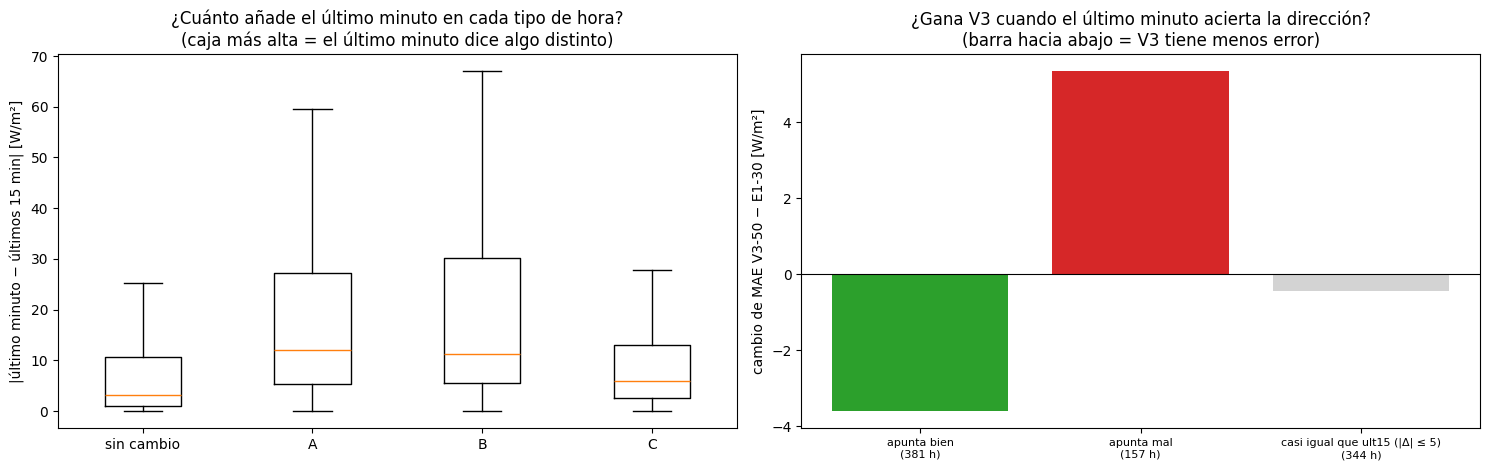


➜ EXPLICACIÓN NO CONFIRMADA: el último minuto no se separa más de ult15 en las horas B que en las A (diferencia -0.7 W/m², IC95 [-4.0, +3.2]). El patrón A/B de R6 queda sin explicar con estos datos.
Resultados en: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/diagnostico/R6_radiografia_V3


In [ ]:
import os
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

try:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
except ImportError:
    pass

BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
DIAG = BASE_DIR / "resultados" / "diagnostico"
PARQUET = BASE_DIR / "radiation_data_completo.parquet"
DIR_R6 = DIAG / "R6_radiografia_V3"
N_BOOT = 2000
UMBRAL_DELTA = 5.0
FIN_DATOS = pd.Timestamp("2024-10-01")

# 1) Datos
V = pd.read_pickle(DIR_R6 / "R6_tabla_horaria.pkl")
V["eE1"], V["eV3"] = (V["E1_30"] - V["real"]).abs(), (V["V3_50"] - V["real"]).abs()
assert (
    abs(V["eE1"].mean() - 23.25) < 0.05 and abs(V["eV3"].mean() - 22.47) < 0.05
), "No se reproducen los MAE de R6"
m = pd.read_parquet(PARQUET, columns=["Date/Time", "DIF [W/m**2]"])
m["Date/Time"] = pd.to_datetime(m["Date/Time"], utc=True).dt.tz_localize(None)
m = m.set_index("Date/Time").sort_index()
m = m[~m.index.duplicated()]
m = m[(m.index >= V.index.min() - pd.Timedelta("2h")) & (m.index < FIN_DATOS)]
assert m.index.max() < FIN_DATOS, "Se estarían leyendo datos del test"
dif = pd.to_numeric(m["DIF [W/m**2]"], errors="coerce").asfreq("min")

def minutos(horas, desde, n=60):
    base = pd.DatetimeIndex(horas).to_numpy(dtype="datetime64[m]")
    idx = base[:, None] + (np.arange(n) + desde).astype("timedelta64[m]")[None, :]
    return dif.reindex(pd.DatetimeIndex(idx.ravel())).to_numpy().reshape(len(horas), n)

prev, act = minutos(V.index, -60), minutos(V.index, 0)
ult3 = prev[:, -3:]
V["ult1"] = [r[~np.isnan(r)][-1] if (~np.isnan(r)).any() else np.nan for r in ult3]
V["ult15"] = np.nanmean(prev[:, -15:], axis=1)
V["mediaT"] = np.nanmean(act, axis=1)
V["delta"] = V["ult1"] - V["ult15"]
V["abs_delta"] = V["delta"].abs()
se_separa = V["abs_delta"] > UMBRAL_DELTA
V["apunta"] = np.where(
    V["delta"].isna() | V["mediaT"].isna(),
    "sin dato",
    np.where(
        ~se_separa,
        f"casi igual que ult15 (|Δ| ≤ {UMBRAL_DELTA:.0f})",
        np.where(
            np.sign(V["delta"]) == np.sign(V["mediaT"] - V["ult15"]), "apunta bien", "apunta mal"
        ),
    ),
)
V["tipo_c"] = V["tipo"].str.split(" · ").str[0]
print("Horas por tipo:", V["tipo_c"].value_counts().to_dict())

# 2) Criterios: B frente a A
dias = V.index.normalize()
u_dias = np.unique(dias)
pos = {d: np.where(dias == d)[0] for d in u_dias}
rng = np.random.default_rng(0)
remuestras = [
    np.concatenate([pos[d] for d in rng.choice(u_dias, len(u_dias))]) for _ in range(N_BOOT)
]

def estad(D):
    A, B = D[D["tipo_c"] == "A"], D[D["tipo_c"] == "B"]
    mA, mB = A["abs_delta"].median(), B["abs_delta"].median()
    fA = (A["apunta"] == "apunta bien").sum() / A["apunta"].isin(
        ["apunta bien", "apunta mal"]
    ).sum()
    fB = (B["apunta"] == "apunta bien").sum() / B["apunta"].isin(
        ["apunta bien", "apunta mal"]
    ).sum()
    return mB - mA, 100 * (fB - fA), mA, mB, 100 * fA, 100 * fB

d_med, d_frac, mA, mB, fA, fB = estad(V)
boot = np.array([estad(V.iloc[r])[:2] for r in remuestras])
lo1, hi1 = np.nanpercentile(boot[:, 0], [2.5, 97.5])
lo2, hi2 = np.nanpercentile(boot[:, 1], [2.5, 97.5])
ok1, ok2 = lo1 > 0, lo2 > 0
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 30)
print(
    "\n"
    + "=" * 110
    + "\nR6b · ¿El último minuto aporta más en las horas de tipo B que en las de tipo A?\n"
    + "=" * 110
)
print(
    f"1) Mediana de |ult1 − ult15|: A = {mA:.1f} · B = {mB:.1f} W/m² → diferencia B − A = {d_med:+.1f}, "
    f"IC95 [{lo1:+.1f}, {hi1:+.1f}] → {'cumple' if ok1 else 'NO cumple'}"
)
print(
    f"2) % de horas en que el último minuto apunta bien: A = {fA:.0f} % · B = {fB:.0f} % → diferencia B − A = {d_frac:+.0f} puntos, "
    f"IC95 [{lo2:+.0f}, {hi2:+.0f}] (apoyo, no decide)"
)

# Descriptivo por tipo
filas = []
for t in ["sin cambio (|salto| ≤ 30)", "A", "B", "C", "E"]:
    sub = (
        V[V["tipo_c"] == t]
        if t != "sin cambio (|salto| ≤ 30)"
        else V[V["tipo"].str.startswith("sin cambio")]
    )
    if len(sub) == 0:
        continue
    val = sub["apunta"].isin(["apunta bien", "apunta mal"])
    filas.append(
        {
            "tipo": t,
            "horas": len(sub),
            "mediana |Δ|": sub["abs_delta"].median(),
            "P75 |Δ|": sub["abs_delta"].quantile(0.75),
            "% se separa (|Δ| > 5)": 100 * se_separa[sub.index].mean(),
            "% apunta bien (de las que se separan)": 100
            * (sub["apunta"] == "apunta bien").sum()
            / max(val.sum(), 1),
            "cambio MAE V3 − E1": (sub["eV3"] - sub["eE1"]).mean(),
        }
    )
TT = pd.DataFrame(filas).set_index("tipo")
print("\nPor tipo de hora (descriptivo):")
display(TT.round(1))


# Informativo: ¿gana V3 cuando el último minuto apunta bien y pierde cuando apunta mal?
def ic_grupo(msk):
    x = np.where(msk, (V["eV3"] - V["eE1"]).to_numpy(), np.nan)
    medias = [np.nanmean(x[r]) for r in remuestras]
    return np.nanmean(x), np.nanpercentile(medias, 2.5), np.nanpercentile(medias, 97.5)

filas = []
for g in ["apunta bien", "apunta mal", f"casi igual que ult15 (|Δ| ≤ {UMBRAL_DELTA:.0f})"]:
    msk = (V["apunta"] == g).to_numpy()
    c, lo, hi = ic_grupo(msk)
    filas.append(
        {
            "el último minuto…": g,
            "horas": int(msk.sum()),
            "MAE E1-30": V.loc[msk, "eE1"].mean(),
            "MAE V3-50": V.loc[msk, "eV3"].mean(),
            "cambio": c,
            "IC95": f"[{lo:+.2f}, {hi:+.2f}]",
        }
    )
GG = pd.DataFrame(filas).set_index("el último minuto…")
print(
    "\nTodas las horas con sol: cambio de error de V3 según lo que hizo el último minuto (informativo):"
)
display(GG.round(2))

# 3) Gráfica
fig, axs = plt.subplots(1, 2, figsize=(15, 4.8))
orden = [t for t in ["sin cambio (|salto| ≤ 30)", "A", "B", "C", "E"] if t in TT.index]
datos = [
    V.loc[
        (V["tipo_c"] == t) if t != orden[0] else V["tipo"].str.startswith("sin cambio"), "abs_delta"
    ]
    .dropna()
    .to_numpy()
    for t in orden
]
axs[0].boxplot(datos, positions=range(len(orden)), showfliers=False)
axs[0].set_xticks(range(len(orden)))
axs[0].set_xticklabels(["sin cambio" if o.startswith("sin") else o for o in orden])
axs[0].set_ylabel("|último minuto − últimos 15 min| [W/m²]")
axs[0].set_title(
    "¿Cuánto añade el último minuto en cada tipo de hora?\n(caja más alta = el último minuto dice algo distinto)"
)
axs[1].bar(range(len(GG)), GG["cambio"], color=["tab:green", "tab:red", "lightgray"])
axs[1].axhline(0, color="k", lw=0.8)
axs[1].set_xticks(range(len(GG)))
axs[1].set_xticklabels([f"{i}\n({int(h)} h)" for i, h in zip(GG.index, GG["horas"])], fontsize=8)
axs[1].set_ylabel("cambio de MAE V3-50 − E1-30 [W/m²]")
axs[1].set_title(
    "¿Gana V3 cuando el último minuto acierta la dirección?\n(barra hacia abajo = V3 tiene menos error)"
)
plt.tight_layout()
plt.savefig(DIR_R6 / "R6b_ultimo_minuto_por_tipo.png", dpi=120)
plt.show()

# 4) Veredicto
if ok1:
    ver = (
        f"EXPLICACIÓN CONFIRMADA: en las horas B el último minuto se separa más de ult15 que en las A (mediana {mB:.1f} frente a "
        f"{mA:.1f} W/m², IC95 de la diferencia [{lo1:+.1f}, {hi1:+.1f}]). Apoyo: apunta bien en el {fB:.0f} % de las B frente al "
        f"{fA:.0f} % de las A. V3 gana donde el último minuto trae información que ult15 no tenía."
    )
else:
    ver = (
        f"EXPLICACIÓN NO CONFIRMADA: el último minuto no se separa más de ult15 en las horas B que en las A "
        f"(diferencia {d_med:+.1f} W/m², IC95 [{lo1:+.1f}, {hi1:+.1f}]). El patrón A/B de R6 queda sin explicar con estos datos."
    )
print("\n➜ " + ver)
TT.to_csv(DIR_R6 / "R6b_por_tipo.csv")
GG.to_csv(DIR_R6 / "R6b_apunta.csv")
(DIR_R6 / "R6b_veredicto.txt").write_text(ver + "\n", encoding="utf-8")
print("Resultados en:", DIR_R6)

**Resultados.** La explicación no se confirma: la mediana de |Δ| es de 12,0 W/m² en las horas A y de 11,2 W/m² en las B (diferencia −0,7 W/m², IC95 [−4,0; +3,2]). Como dato de apoyo, que no decide, el último minuto apunta en el sentido del cambio en el 83 % de las horas B en que se separa de esa media, frente al 65 % de las A. En el conjunto de horas con sol, V3-50 reduce el error en 3,61 W/m² cuando el último minuto apunta en el sentido del cambio (381 horas) y lo aumenta en 5,35 W/m² cuando apunta en sentido contrario (157 horas); esta agrupación depende del resultado y solo describe.

## 13. Señal previa, horizontes y entrada de una hora

> *Se utiliza en la memoria: apartado 5.3.5 (horizonte y entrada de una hora) y fases 24 a 28 de la Tabla A1.*

### 13.1 Señal de las variables antes de la emisión

Con las horas con sol de entrenamiento se analiza qué variables muestran señal en los 120 minutos previos a la emisión y desde cuándo, mediante épocas superpuestas sobre 27 variables medidas y 8 derivadas, expresadas como anomalías respecto a su mediana para la misma elevación solar, mañana o tarde y mes (R7). En bloques de 5 minutos se calcula la correlación de Spearman con dos objetivos, el cambio de la hora no debido a la geometría solar (Δ*, diferencia entre la DIF y la persistencia inteligente horaria, con correlación parcial) y el error fuera de muestra de E1-30, en conjunto y por terciles de estabilidad de la última hora observada. El análisis es descriptivo, y la validación solo interviene en la comparación mensual de la estabilidad.

Mounted at /content/drive
Minutos: 397,620 (2023-12-29 21:00:00 → 2024-09-30 23:59:00) · variables del parquet: 27
Variables derivadas: 8 · total estudiadas: 35
Climatología por (elevación 2°, mañana/tarde, mes) calculada solo con train.
Horas con sol en train: 3027 · cortes de estabilidad (desv. del kc en T−1): [0.077 0.196]
Cortes de Δ* en train (quintiles, W/m²): [-25.   -0.6   7.7  29.8]

Horas por estabilidad (train):


,horas
estrato,
estable,815
intermedio,814
inestable,814
sol bajo / sin dato,584


Ventanas: (3027, 180, 35) · bloques de 5 min: 36 (24 antes de la emisión)
Parte A: PDF con los compuestos de todas las variables guardado.

Parte B · objetivo: Δ* (cambio no geométrico) · horas: todas (n=3024) · 15 variables con más señal


,familia,ρ último bloque (−5…0),IC95 último bloque,máx |ρ|,bloque del máx (min antes),señal desde (min antes de emitir)
variable,,,,,,
DIF / DIF despejado,derivada,0.375,"[+0.34, +0.41]",0.375,5,20.0
DIF min,DIF,0.330,"[+0.29, +0.37]",0.330,5,30.0
DIF,DIF,0.330,"[+0.29, +0.37]",0.330,5,30.0
DIF max,DIF,0.327,"[+0.29, +0.36]",0.327,5,25.0
SWD std dev,SWD,0.183,"[+0.14, +0.23]",0.183,5,20.0
SWU std dev,SWU,0.180,"[+0.14, +0.22]",0.180,5,20.0
DIR std dev,DIR,0.160,"[+0.12, +0.20]",0.160,5,20.0
DIF std dev,DIF,0.098,"[+0.05, +0.14]",0.098,5,25.0
LWD / LWU,derivada,-0.074,"[-0.12, -0.03]",0.074,5,20.0



Parte B · objetivo: Δ* (cambio no geométrico) · horas: estable (n=813) · 15 variables con más señal


,familia,ρ último bloque (−5…0),IC95 último bloque,máx |ρ|,bloque del máx (min antes),señal desde (min antes de emitir)
variable,,,,,,
DIF / DIF despejado,derivada,0.316,"[+0.26, +0.37]",0.316,5,25.0
DIF min,DIF,0.229,"[+0.15, +0.30]",0.229,5,20.0
DIF,DIF,0.225,"[+0.15, +0.30]",0.225,5,20.0
DIF max,DIF,0.224,"[+0.15, +0.30]",0.224,5,20.0
SWD std dev,SWD,0.184,"[+0.10, +0.26]",0.184,5,20.0
SWU std dev,SWU,0.179,"[+0.10, +0.26]",0.179,5,20.0
DIR std dev,DIR,0.163,"[+0.10, +0.23]",0.163,5,20.0
SWU,SWU,0.052,"[-0.04, +0.13]",0.101,120,NaN
SWU max,SWU,0.057,"[-0.03, +0.14]",0.100,115,NaN


... (4 outputs left out)


Parte B · objetivo: error de E1-30 · horas: estable (n=815) · 15 variables con más señal


,familia,ρ último bloque (−5…0),IC95 último bloque,máx |ρ|,bloque del máx (min antes),señal desde (min antes de emitir)
variable,,,,,,
DIR std dev,DIR,-0.170,"[-0.25, -0.09]",0.170,5,80.0
DIF / DIF despejado,derivada,-0.129,"[-0.20, -0.06]",0.129,5,10.0
DIF min,DIF,-0.125,"[-0.21, -0.03]",0.125,5,10.0
DIF,DIF,-0.120,"[-0.20, -0.03]",0.120,5,10.0
DIF max,DIF,-0.117,"[-0.20, -0.03]",0.117,5,10.0
SWU std dev,SWU,-0.092,"[-0.18, +0.00]",0.112,75,NaN
SWD std dev,SWD,-0.089,"[-0.17, +0.00]",0.111,20,NaN
albedo = SWU / SWD,derivada,-0.110,"[-0.18, -0.04]",0.110,5,20.0
SWU max,SWU,-0.072,"[-0.15, +0.02]",0.094,105,NaN



Parte B · objetivo: error de E1-30 · horas: inestable (n=814) · 15 variables con más señal


,familia,ρ último bloque (−5…0),IC95 último bloque,máx |ρ|,bloque del máx (min antes),señal desde (min antes de emitir)
variable,,,,,,
LWD / LWU,derivada,0.057,"[-0.00, +0.13]",0.124,65,NaN
LWD / LWD despejado (Brutsaert),derivada,0.052,"[-0.02, +0.13]",0.111,65,NaN
DIF max,DIF,0.021,"[-0.05, +0.10]",0.107,10,NaN
SWD std dev,SWD,-0.015,"[-0.09, +0.06]",0.104,50,NaN
SWU std dev,SWU,-0.015,"[-0.09, +0.06]",0.103,50,NaN
DIF,DIF,0.016,"[-0.06, +0.09]",0.103,10,NaN
fracción difusa = DIF / SWD,derivada,0.022,"[-0.04, +0.09]",0.101,65,NaN
DIF min,DIF,0.016,"[-0.06, +0.09]",0.100,10,NaN
SWD min,SWD,0.028,"[-0.05, +0.10]",0.100,15,NaN


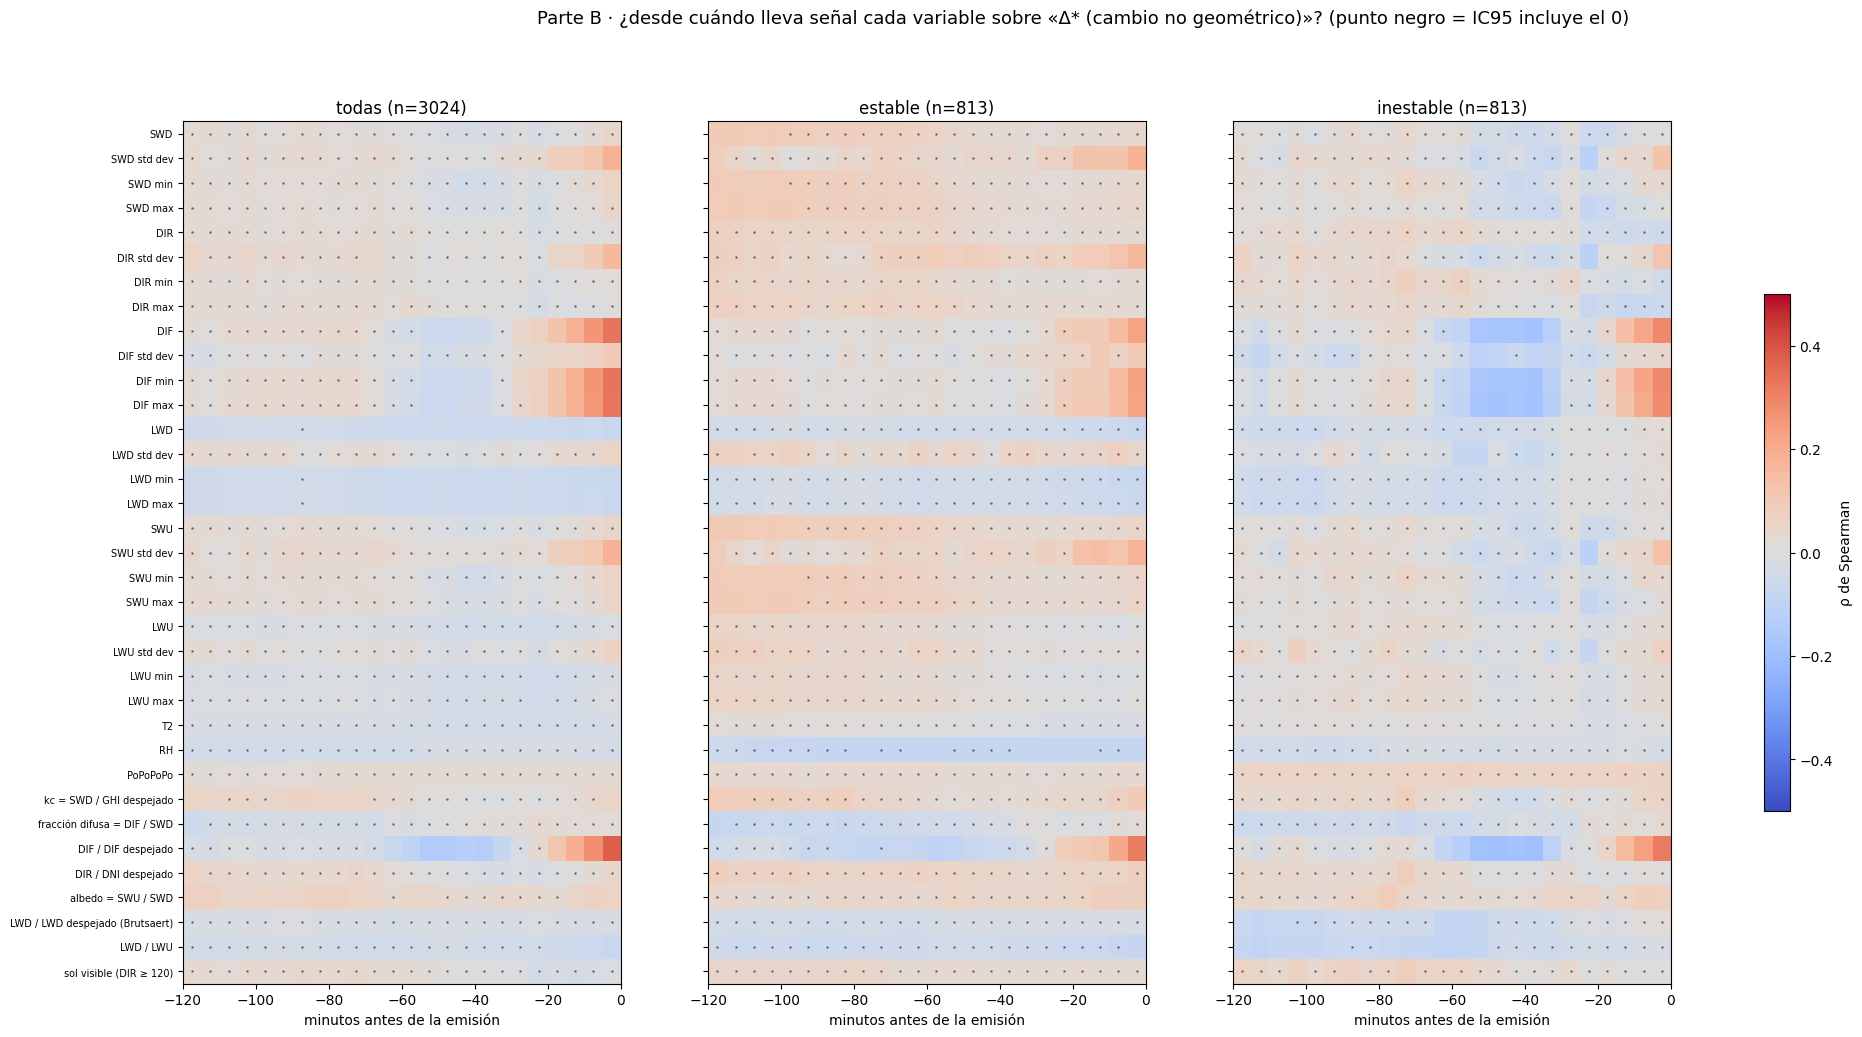

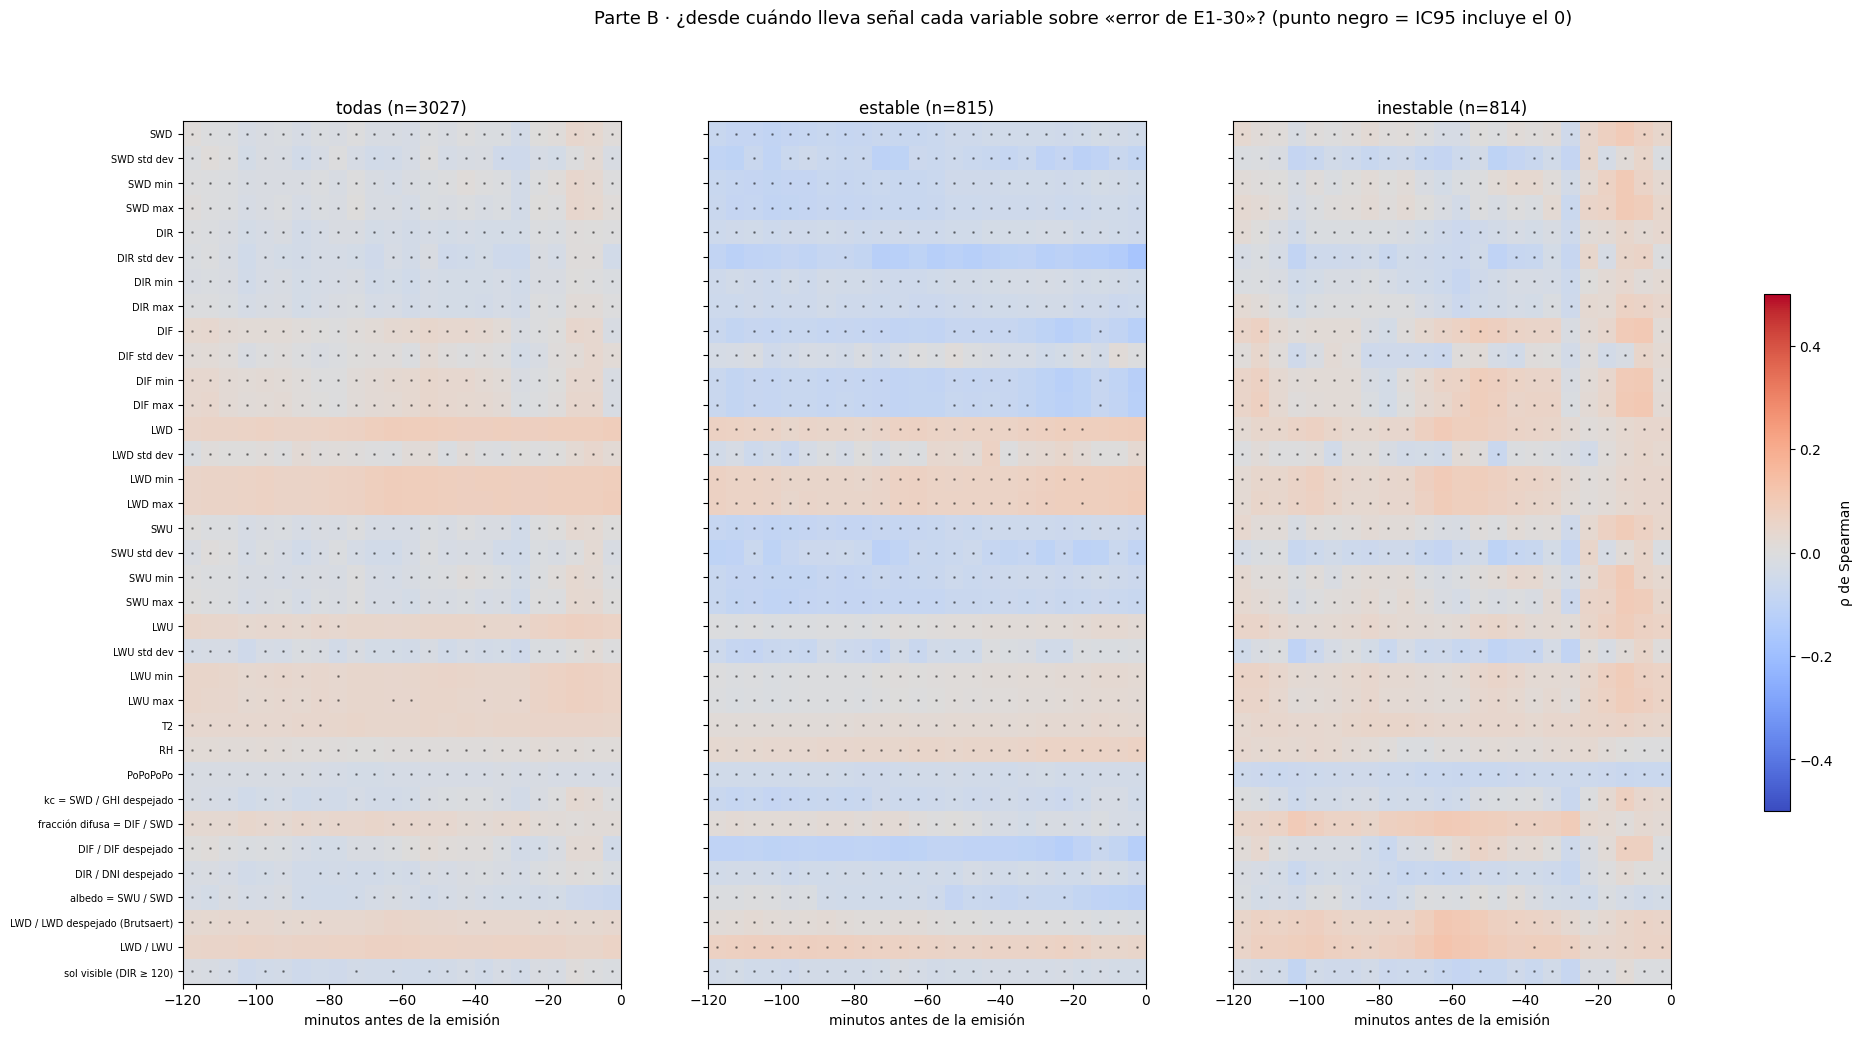


Parte C · estabilidad y cambios por mes (ene–jul = train · ago–sep = validación)


,horas,DIF_media,I_mediana,I_P90,abs_delta_mediana,abs_delta_P90,% horas inestables (al emitir),% horas estables (al emitir)
mes,,,,,,,,
2024-01,311,49.13,0.08,0.27,8.52,32.18,13.50,32.15
2024-02,315,79.02,0.08,0.22,14.77,52.15,10.16,37.14
2024-03,386,120.62,0.11,0.33,18.35,70.52,24.87,31.35
2024-04,444,156.81,0.15,0.36,26.38,91.02,34.91,17.34
2024-05,519,162.37,0.11,0.32,27.23,100.55,24.86,31.02
2024-06,525,165.97,0.15,0.35,24.28,92.48,36.19,24.00
2024-07,527,165.98,0.16,0.33,23.76,93.24,32.26,21.44
2024-08,480,154.82,0.15,0.33,18.46,82.73,31.25,23.12
2024-09,404,126.33,0.12,0.37,19.27,73.92,31.19,27.23



Error de E1-30 por estabilidad (train fuera de muestra frente a validación):


horas  MAE_E1  sesgo_E1  abs_delta_mediana  % de las horas
conjunto   estrato                                                                        
train      estable                815   22.24     -3.13              13.84           26.92
           inestable              814   38.13     -2.60              30.60           26.89
           intermedio             814   33.12     -2.71              26.80           26.89
           sol bajo / sin dato    584    7.01     -1.52               9.38           19.29
validación estable                221   19.36     -7.36              12.18           25.00
           inestable              276   30.63      2.13              30.36           31.22
           intermedio             217   30.69     -2.86              21.33           24.55
           sol bajo / sin dato    170    6.85     -2.70              12.63           19.23

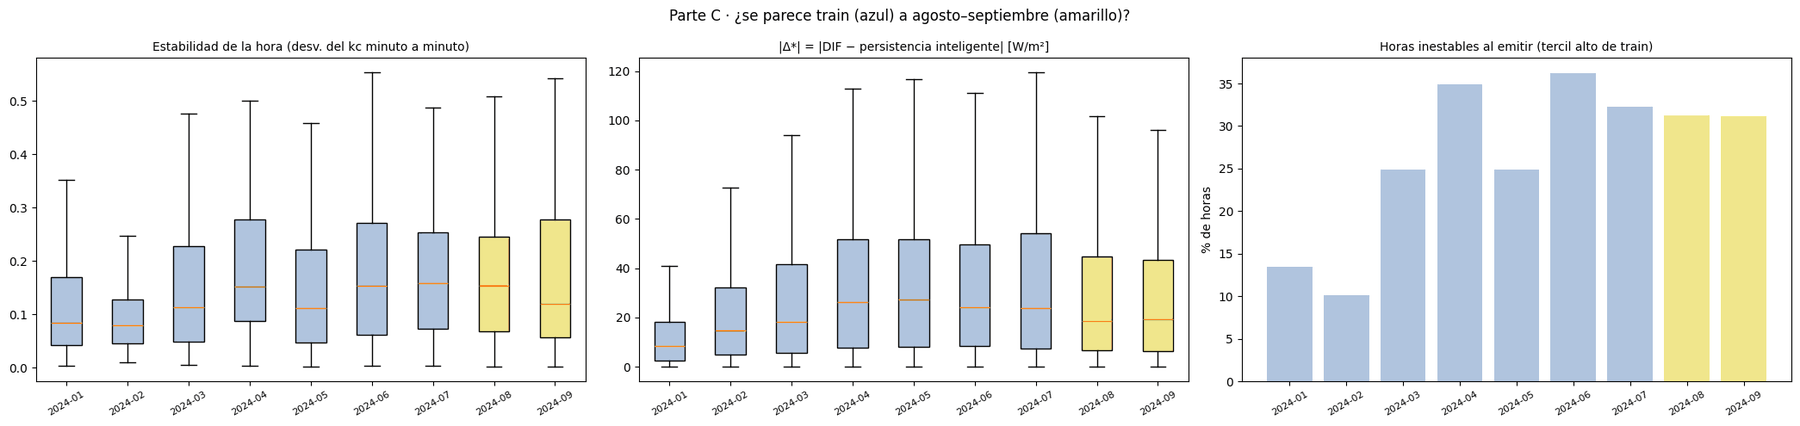

Resultados en: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/diagnostico/R7_epocas_superpuestas


In [ ]:
import os, sys, subprocess, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages

warnings.filterwarnings("ignore")
try:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
except ImportError:
    pass
try:
    import pvlib
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pvlib"], check=True)
    import pvlib

BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
DIAG = BASE_DIR / "resultados" / "diagnostico"
PARQUET = BASE_DIR / "radiation_data_completo.parquet"
RUTA_TABLA = DIAG / "faseB_radiografia_E1" / "tabla_horaria_E1.pkl"
RUTA_OOF = DIAG / "depuracion_E1_30" / "P1_oof_E1_30.pkl"
DIR_5C = DIAG / "faseC_regularizacion" / "C5c_confirmacion"
SALIDA = DIAG / "R7_epocas_superpuestas"
SALIDA.mkdir(parents=True, exist_ok=True)
LAT, LON, ALT = 51.9711, 4.9267, 0  # Cabauw (BSRN CAB)
INI_TRAIN, FIN_TRAIN, FIN_DATOS = (
    pd.Timestamp("2023-12-30"),
    pd.Timestamp("2024-08-01"),
    pd.Timestamp("2024-10-01"),
)
ANTES, DESPUES, BLOQUE = 120, 60, 5  # minutos antes / después de la emisión, tamaño de bloque
N_BOOT = 500
SEMILLAS = [42, 123, 2024, 7, 99]
SIGMA = 5.670374419e-8

# 1) Datos minuto a minuto (todas las columnas numéricas)
raw = pd.read_parquet(PARQUET)
raw["Date/Time"] = pd.to_datetime(raw["Date/Time"], utc=True).dt.tz_localize(None)
raw = raw.set_index("Date/Time").sort_index()
raw = raw[~raw.index.duplicated()]
raw = raw[(raw.index >= INI_TRAIN - pd.Timedelta(hours=3)) & (raw.index < FIN_DATOS)]
assert raw.index.max() < FIN_DATOS, "Se estarían leyendo datos del test"
num = [
    c
    for c in raw.columns
    if pd.api.types.is_numeric_dtype(raw[c]) and not c.lower().startswith("height")
]
M = raw[num].apply(pd.to_numeric, errors="coerce").asfreq("min")
print(
    f"Minutos: {len(M):,} ({M.index.min()} → {M.index.max()}) · variables del parquet: {len(num)}"
)
corto = {
    c: c.replace(" [W/m**2]", "").replace(" [°C]", "").replace(" [%]", "").replace(" [hPa]", "")
    for c in num
}
M = M.rename(columns=corto)
num = list(corto.values())

# 2) Geometría solar y cielo despejado (Ineichen, pvlib) minuto a minuto
loc = pvlib.location.Location(LAT, LON, tz="UTC", altitude=ALT)
t_utc = M.index.tz_localize("UTC")
sp = loc.get_solarposition(t_utc)
cs = loc.get_clearsky(t_utc, model="ineichen")
G = pd.DataFrame(
    {
        "elev": sp["apparent_elevation"].to_numpy(),
        "azim": sp["azimuth"].to_numpy(),
        "ghi_cs": cs["ghi"].to_numpy(),
        "dni_cs": cs["dni"].to_numpy(),
        "dhi_cs": cs["dhi"].to_numpy(),
    },
    index=M.index,
)


# 3) Variables derivadas (físicas)
def cociente(a, b, minimo):
    return (a / b).where(b >= minimo)

T2k = M["T2"] + 273.15
e_hpa = M["RH"] / 100 * 6.112 * np.exp(17.62 * M["T2"] / (243.12 + M["T2"]))  # Magnus (WMO)
lwd_cs = 1.24 * (e_hpa / T2k) ** (1 / 7) * SIGMA * T2k**4  # Brutsaert (1975)
DER = pd.DataFrame(
    {
        "kc = SWD / GHI despejado": cociente(M["SWD"], G["ghi_cs"], 50),
        "fracción difusa = DIF / SWD": cociente(M["DIF"], M["SWD"], 20),
        "DIF / DIF despejado": cociente(M["DIF"], G["dhi_cs"], 10),
        "DIR / DNI despejado": cociente(M["DIR"], G["dni_cs"], 50),
        "albedo = SWU / SWD": cociente(M["SWU"], M["SWD"], 20),
        "LWD / LWD despejado (Brutsaert)": M["LWD"] / lwd_cs,
        "LWD / LWU": M["LWD"] / M["LWU"],
        "sol visible (DIR ≥ 120)": (M["DIR"] >= 120)
        .astype(float)
        .where(M["DIR"].notna() & (G["elev"] > 0)),
    },
    index=M.index,
)
DER = DER.clip(lower=-5, upper=5)  # cocientes absurdos al amanecer
derivadas = list(DER.columns)
print(f"Variables derivadas: {len(derivadas)} · total estudiadas: {len(num) + len(derivadas)}")

# 4) Anomalías respecto a la geometría (solo variables medidas; climatología de TRAIN)
tramo = np.floor(G["elev"] / 2).astype(int)
tarde = (G["azim"] >= 180).astype(int)
mes_m = M.index.month
clave = pd.MultiIndex.from_arrays([tramo, tarde, mes_m])
en_train = (M.index >= INI_TRAIN) & (M.index < FIN_TRAIN)
clim = (
    M[en_train]
    .groupby([tramo[en_train].to_numpy(), tarde[en_train].to_numpy(), mes_m[en_train]])
    .median()
)
clim_all = clim.reindex(clave)
clim_all.index = M.index
ANOM = M - clim_all  # meses sin climatología → NaN
V = pd.concat([ANOM, DER], axis=1)
VARIABLES = num + derivadas
print("Climatología por (elevación 2°, mañana/tarde, mes) calculada solo con train.")

# 5) Horas objetivo: Δ*, error de E1-30 y estabilidad conocida al emitir
H = pd.read_pickle(RUTA_TABLA).sort_index()
h_dhi = G["dhi_cs"].groupby(G.index.floor("h")).mean()
h_kc_sd = DER["kc = SWD / GHI despejado"].groupby(DER.index.floor("h")).agg(["std", "count"])
I_h = h_kc_sd["std"].where(h_kc_sd["count"] >= 30)  # estabilidad de cada hora

def preparar(D):
    D = D[D["regimen"].astype(str) != "noche"].copy()
    D["dif_T1"] = H["real"].reindex(D.index - pd.Timedelta("1h")).to_numpy()
    cs_T, cs_T1 = (
        h_dhi.reindex(D.index).to_numpy(),
        h_dhi.reindex(D.index - pd.Timedelta("1h")).to_numpy(),
    )
    D["pers_int"] = np.clip(
        D["dif_T1"] * np.where(cs_T1 > 5, cs_T / np.maximum(cs_T1, 5), 1.0), 0, None
    )
    D["delta_star"] = D["real"] - D["pers_int"]
    D["I_emision"] = I_h.reindex(D.index - pd.Timedelta("1h")).to_numpy()  # se conoce al emitir
    D["I_objetivo"] = I_h.reindex(D.index).to_numpy()  # solo para describir
    return D

TR = preparar(H[H["conjunto"] == "train"])
VA = preparar(H[H["conjunto"] == "validation"])
OOF = pd.read_pickle(RUTA_OOF)
TR["e_E1"] = (OOF["OOF30_media"] - OOF["real"]).reindex(TR.index).to_numpy()
pred_va = pd.Series(
    np.mean([np.load(DIR_5C / f"pred_validation_s{s}.npz")["ep30"] for s in SEMILLAS], axis=0),
    index=H[H["conjunto"] == "validation"].index,
)
VA["e_E1"] = (pred_va.reindex(VA.index) - VA["real"]).to_numpy()
assert abs(VA["e_E1"].abs().mean() - 23.25) < 0.05, "No se reproduce el MAE de E1-30 en validación"
cortes_I = np.nanpercentile(TR["I_emision"], [100 / 3, 200 / 3])

def estrato(I):
    return np.where(
        np.isnan(I),
        "sol bajo / sin dato",
        np.where(
            I <= cortes_I[0], "estable", np.where(I <= cortes_I[1], "intermedio", "inestable")
        ),
    )

for D in (TR, VA):
    D["estrato"] = estrato(D["I_emision"].to_numpy())
q_delta = np.nanpercentile(TR["delta_star"], [20, 40, 60, 80])
TR["quintil_delta"] = pd.cut(
    TR["delta_star"],
    [-np.inf, *q_delta, np.inf],
    labels=["Q1 bajada fuerte", "Q2", "Q3 sin cambio", "Q4", "Q5 subida fuerte"],
)
print(
    f"Horas con sol en train: {len(TR)} · cortes de estabilidad (desv. del kc en T−1): {cortes_I.round(3)}"
)
print(f"Cortes de Δ* en train (quintiles, W/m²): {q_delta.round(1)}")
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 30)
print("\nHoras por estabilidad (train):")
display(TR["estrato"].value_counts().to_frame("horas"))

# 6) Ventanas alrededor de cada emisión (−120 … +59 min) y bloques de 5 min
offs = np.arange(-ANTES, DESPUES)
pos0 = M.index.get_indexer(TR.index)
fuera = pos0 < ANTES
if fuera.any():
    print(
        f"Se descartan {int(fuera.sum())} horas sin los {ANTES} min previos en el fichero minutal"
    )
    TR = TR[~fuera].copy()
    pos0 = pos0[~fuera]
idx = pos0[:, None] + offs[None, :]
idx = np.clip(idx, 0, len(M) - 1)
Varr = V[VARIABLES].to_numpy(dtype=np.float32)
W3 = Varr[idx]  # horas × minutos × variables
nb = (ANTES + DESPUES) // BLOQUE
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    B3 = np.nanmean(
        W3.reshape(len(TR), nb, BLOQUE, len(VARIABLES)), axis=2
    )  # horas × bloques × variables
centros = -ANTES + BLOQUE * np.arange(nb) + BLOQUE / 2
nb_pre = ANTES // BLOQUE
print(f"Ventanas: {W3.shape} · bloques de {BLOQUE} min: {nb} ({nb_pre} antes de la emisión)")
dias_tr = TR.index.normalize().to_numpy()

def pesos_bootstrap(dias, B=N_BOOT, semilla=0):
    u, inv = np.unique(dias, return_inverse=True)
    rng = np.random.default_rng(semilla)
    C = np.stack([np.bincount(rng.integers(0, len(u), len(u)), minlength=len(u)) for _ in range(B)])
    return C[:, inv].astype(np.float32)  # B × horas


# 7) Parte A · compuestos (épocas superpuestas) con IC95
GRUPOS = ["Q1 bajada fuerte", "Q3 sin cambio", "Q5 subida fuerte"]
COLOR = {"Q1 bajada fuerte": "tab:blue", "Q3 sin cambio": "gray", "Q5 subida fuerte": "tab:red"}
ESTRATOS = ["estable", "intermedio", "inestable"]

def compuesto(msk):
    X = B3[msk]  # n × bloques × variables
    Wb = pesos_bootstrap(dias_tr[msk], B=300)
    ok = ~np.isnan(X)
    Xz = np.where(ok, X, 0.0)
    media = Xz.sum(0) / np.maximum(ok.sum(0), 1)
    num_b = np.einsum("bn,nkv->bkv", Wb, Xz)
    den_b = np.einsum("bn,nkv->bkv", Wb, ok.astype(np.float32))
    mb = num_b / np.maximum(den_b, 1e-9)
    return media, np.percentile(mb, 2.5, axis=0), np.percentile(mb, 97.5, axis=0), int(msk.sum())

COMP = {}
for est in ESTRATOS:
    for g in GRUPOS:
        msk = ((TR["estrato"] == est) & (TR["quintil_delta"] == g)).to_numpy()
        if msk.sum() >= 15:
            COMP[(est, g)] = compuesto(msk)
with PdfPages(SALIDA / "R7_A_compuestos_todas_las_variables.pdf") as pdf:
    for j, var in enumerate(VARIABLES):
        fig, axs = plt.subplots(1, 3, figsize=(18, 4.2), sharey=True)
        for ax, est in zip(axs, ESTRATOS):
            for g in GRUPOS:
                if (est, g) not in COMP:
                    continue
                med, lo, hi, n = COMP[(est, g)]
                ax.plot(centros, med[:, j], color=COLOR[g], lw=1.8, label=f"{g} (n={n})")
                ax.fill_between(centros, lo[:, j], hi[:, j], color=COLOR[g], alpha=0.18)
            ax.axvline(0, color="k", lw=1.2)
            ax.axhline(0, color="k", lw=0.5, alpha=0.5)
            ax.axvspan(0, DESPUES, color="khaki", alpha=0.15)
            ax.set_title(f"{est}", fontsize=10)
            ax.set_xlabel("minutos respecto a la emisión")
            ax.grid(alpha=0.2)
        axs[0].set_ylabel("anomalía" if var in num else "valor")
        axs[0].legend(fontsize=7)
        fig.suptitle(
            f"{var} · media por bloques de 5 min (IC95 bootstrap por días) · amarillo = hora T (solo interpretación)",
            fontsize=11,
        )
        fig.tight_layout()
        pdf.savefig(fig)
        plt.close(fig)
print("Parte A: PDF con los compuestos de todas las variables guardado.")

# 8) Parte B · ¿desde cuándo aporta? Spearman por bloque antes de la emisión, con IC95
Xpre = B3[:, :nb_pre, :]  # horas × bloques previos × variables
cols = [(v, b) for v in VARIABLES for b in range(nb_pre)]
Xflat = Xpre.transpose(0, 2, 1).reshape(len(TR), -1)  # orden: variable, bloque

def spearman_ic(msk, y, z=None):
    """Spearman (o Spearman PARCIAL si se da z: se descuenta linealmente el rango de z de los rangos de x e y)."""
    ok_y = msk & ~np.isnan(y) & (np.ones_like(y, bool) if z is None else ~np.isnan(z).any(axis=1))
    X = pd.DataFrame(Xflat[ok_y])
    R = X.rank().to_numpy().copy()
    m = ~np.isnan(R)
    ry = pd.Series(y[ok_y]).rank().to_numpy().copy()
    if z is not None:  # z: matriz de controles (horas × k); se usan sus rangos
        Zr = np.column_stack(
            [np.ones(ok_y.sum())] + [pd.Series(c).rank().to_numpy() for c in z[ok_y].T]
        )
        ry = ry - Zr @ np.linalg.lstsq(Zr, ry, rcond=None)[0]
        for j in range(R.shape[1]):
            v = m[:, j]
            if v.sum() > 10:
                R[v, j] = R[v, j] - Zr[v] @ np.linalg.lstsq(Zr[v], R[v, j], rcond=None)[0]
    Rz = np.where(m, R, 0.0)
    ry = ry[:, None]

    def pearson_pesado(Wb):
        Sw = np.maximum(Wb @ m, 1e-9)
        Sx = Wb @ Rz
        Sy = Wb @ (m * ry)
        Sxx = Wb @ (Rz**2)
        Syy = Wb @ (m * ry**2)
        Sxy = Wb @ (Rz * ry)
        cov = Sxy / Sw - (Sx / Sw) * (Sy / Sw)
        vx = Sxx / Sw - (Sx / Sw) ** 2
        vy = Syy / Sw - (Sy / Sw) ** 2
        r = cov / np.sqrt(np.maximum(vx * vy, 1e-12))
        return np.where((vx > 1e-9) & (vy > 1e-9), r, np.nan)

    rho = pearson_pesado(np.ones((1, len(ry)), dtype=np.float32))[0]
    rb = pearson_pesado(pesos_bootstrap(dias_tr[ok_y]))
    forma = (len(VARIABLES), nb_pre)
    return (
        rho.reshape(forma),
        np.nanpercentile(rb, 2.5, axis=0).reshape(forma),
        np.nanpercentile(rb, 97.5, axis=0).reshape(forma),
        int(ok_y.sum()),
    )


# Δ* se construye con la media de T−1 (persistencia inteligente): cualquier variable de T−1 parecida a la DIF se
# correlacionaría con Δ* por construcción (regresión a la media), y también a través de la geometría (para una misma
# persistencia, más DIF en T−1 implica sol más bajo). Por eso, para Δ* se usa Spearman PARCIAL que descuenta la
# persistencia inteligente, la DIF media de T−1 y la elevación de T. El error de E1-30 no necesita control: el modelo
# ya usó toda esa información; es el objetivo que mejor mide "información nueva".
OBJ = {
    "Δ* (cambio no geométrico)": TR["delta_star"].to_numpy(),
    "error de E1-30": TR["e_E1"].to_numpy(),
}
h_elev = G["elev"].groupby(G.index.floor("h")).mean()
TR["elev_T"] = h_elev.reindex(TR.index).to_numpy()
CONTROL = {
    "Δ* (cambio no geométrico)": TR[["pers_int", "dif_T1", "elev_T"]].to_numpy(),
    "error de E1-30": None,
}
EST_B = {
    "todas": np.ones(len(TR), bool),
    "estable": (TR["estrato"] == "estable").to_numpy(),
    "inestable": (TR["estrato"] == "inestable").to_numpy(),
}
RES_B, filas = {}, []
for on, y in OBJ.items():
    for en, msk in EST_B.items():
        rho, lo, hi, n = spearman_ic(msk, y, CONTROL[on])
        RES_B[(on, en)] = (rho, lo, hi, n)
        sig = (lo > 0) | (hi < 0)
        for j, var in enumerate(VARIABLES):
            inicio = np.nan
            if sig[j, -1]:
                s0 = np.sign(rho[j, -1])
                b = nb_pre - 1
                while b >= 0 and sig[j, b] and np.sign(rho[j, b]) == s0:
                    b -= 1
                inicio = ANTES - BLOQUE * (b + 1)  # minutos antes de emitir
            if np.all(np.isnan(rho[j])):  # variable constante (p. ej. presión)
                filas.append(
                    {
                        "objetivo": on,
                        "estabilidad": en,
                        "variable": var,
                        "horas": n,
                        "familia": "derivada" if var in derivadas else var.split(" ")[0],
                    }
                )
                continue
            k = int(np.nanargmax(np.abs(rho[j])))
            filas.append(
                {
                    "objetivo": on,
                    "estabilidad": en,
                    "variable": var,
                    "horas": n,
                    "familia": "derivada" if var in derivadas else var.split(" ")[0],
                    "ρ último bloque (−5…0)": rho[j, -1],
                    "IC95 último bloque": f"[{lo[j, -1]:+.2f}, {hi[j, -1]:+.2f}]",
                    "máx |ρ|": abs(rho[j, k]),
                    "bloque del máx (min antes)": ANTES - BLOQUE * k,
                    "señal desde (min antes de emitir)": inicio,
                }
            )
TB = pd.DataFrame(filas)
for on in OBJ:
    for en in EST_B:
        sub = TB[(TB["objetivo"] == on) & (TB["estabilidad"] == en)].sort_values(
            "máx |ρ|", ascending=False
        )
        print(
            "\n"
            + "=" * 120
            + f"\nParte B · objetivo: {on} · horas: {en} (n={sub['horas'].iloc[0]}) · 15 variables con más señal\n"
            + "=" * 120
        )
        display(
            sub.drop(columns=["objetivo", "estabilidad", "horas"])
            .head(15)
            .set_index("variable")
            .round(3)
        )

for on in OBJ:
    fig, axs = plt.subplots(1, 3, figsize=(24, max(10, 0.32 * len(VARIABLES))), sharey=True)
    for ax, en in zip(axs, EST_B):
        rho, lo, hi, n = RES_B[(on, en)]
        im = ax.imshow(
            rho,
            aspect="auto",
            cmap="coolwarm",
            vmin=-0.5,
            vmax=0.5,
            extent=[-ANTES, 0, len(VARIABLES) - 0.5, -0.5],
        )
        sig = (lo > 0) | (hi < 0)
        yy_, xx_ = np.where(~sig)
        ax.scatter(-ANTES + BLOQUE * xx_ + BLOQUE / 2, yy_, marker=".", s=4, color="k", alpha=0.35)
        ax.set_title(f"{en} (n={n})")
        ax.set_xlabel("minutos antes de la emisión")
    axs[0].set_yticks(range(len(VARIABLES)))
    axs[0].set_yticklabels(VARIABLES, fontsize=7)
    fig.colorbar(im, ax=axs, shrink=0.6, label="ρ de Spearman")
    fig.suptitle(
        f"Parte B · ¿desde cuándo lleva señal cada variable sobre «{on}»? (punto negro = IC95 incluye el 0)",
        fontsize=13,
    )
    nombre = "delta" if on.startswith("Δ") else "errorE1"
    fig.savefig(SALIDA / f"R7_B_mapa_senal_{nombre}.png", dpi=120, bbox_inches="tight")
    plt.show()

# 9) Parte C · ¿tiene train los cambios bruscos de agosto y septiembre?
AMB = pd.concat([TR.assign(conjunto="train"), VA.assign(conjunto="validación")])
AMB["mes"] = AMB.index.to_period("M").astype(str).str.replace("2023-12", "2024-01")
AMB["abs_delta"] = AMB["delta_star"].abs()
C1 = AMB.groupby("mes").agg(
    horas=("real", "size"),
    DIF_media=("real", "mean"),
    I_mediana=("I_objetivo", "median"),
    I_P90=("I_objetivo", lambda s: np.nanpercentile(s, 90)),
    abs_delta_mediana=("abs_delta", "median"),
    abs_delta_P90=("abs_delta", lambda s: np.nanpercentile(s, 90)),
)
C1["% horas inestables (al emitir)"] = AMB.groupby("mes")["estrato"].apply(
    lambda s: 100 * (s == "inestable").mean()
)
C1["% horas estables (al emitir)"] = AMB.groupby("mes")["estrato"].apply(
    lambda s: 100 * (s == "estable").mean()
)
print(
    "\n"
    + "=" * 120
    + "\nParte C · estabilidad y cambios por mes (ene–jul = train · ago–sep = validación)\n"
    + "=" * 120
)
display(C1.round(2))
C2 = AMB.groupby(["conjunto", "estrato"]).agg(
    horas=("e_E1", "size"),
    MAE_E1=("e_E1", lambda s: s.abs().mean()),
    sesgo_E1=("e_E1", "mean"),
    abs_delta_mediana=("abs_delta", "median"),
)
C2["% de las horas"] = 100 * C2["horas"] / C2.groupby(level=0)["horas"].transform("sum")
print("\nError de E1-30 por estabilidad (train fuera de muestra frente a validación):")
display(C2.round(2))
fig, axs = plt.subplots(1, 3, figsize=(21, 5))
meses = list(C1.index)
for ax, col, tit in [
    (axs[0], "I_objetivo", "Estabilidad de la hora (desv. del kc minuto a minuto)"),
    (axs[1], "abs_delta", "|Δ*| = |DIF − persistencia inteligente| [W/m²]"),
]:
    datos = [AMB.loc[AMB["mes"] == mm, col].dropna().to_numpy() for mm in meses]
    bp = ax.boxplot(datos, positions=range(len(meses)), showfliers=False, patch_artist=True)
    for k, caja in enumerate(bp["boxes"]):
        caja.set_facecolor("khaki" if meses[k] >= "2024-08" else "lightsteelblue")
    ax.set_xticks(range(len(meses)))
    ax.set_xticklabels(meses, rotation=30, fontsize=8)
    ax.set_title(tit, fontsize=10)
axs[2].bar(
    range(len(meses)),
    C1["% horas inestables (al emitir)"],
    color=["khaki" if mm >= "2024-08" else "lightsteelblue" for mm in meses],
)
axs[2].set_xticks(range(len(meses)))
axs[2].set_xticklabels(meses, rotation=30, fontsize=8)
axs[2].set_ylabel("% de horas")
axs[2].set_title("Horas inestables al emitir (tercil alto de train)", fontsize=10)
fig.suptitle("Parte C · ¿se parece train (azul) a agosto–septiembre (amarillo)?", fontsize=12)
plt.tight_layout()
plt.savefig(SALIDA / "R7_C_train_frente_a_validacion.png", dpi=120)
plt.show()

# 10) Guardado
TB.to_csv(SALIDA / "R7_B_senal_por_variable.csv", index=False)
C1.to_csv(SALIDA / "R7_C_por_mes.csv")
C2.to_csv(SALIDA / "R7_C_error_por_estabilidad.csv")
pd.DataFrame(
    [
        {
            "estabilidad": e,
            "grupo": g,
            "bloque_centro_min": centros[k],
            "variable": v,
            "media": COMP[(e, g)][0][k, j],
            "IC95_inf": COMP[(e, g)][1][k, j],
            "IC95_sup": COMP[(e, g)][2][k, j],
        }
        for (e, g) in COMP
        for k in range(nb)
        for j, v in enumerate(VARIABLES)
    ]
).to_csv(SALIDA / "R7_A_compuestos.csv", index=False)
TR.drop(columns=["quintil_delta"]).assign(quintil_delta=TR["quintil_delta"].astype(str)).to_pickle(
    SALIDA / "R7_horas_train.pkl"
)
print("Resultados en:", SALIDA)

**Resultados.** La señal previa a la emisión se refiere al cambio de la hora, no al error de E1-30.

- Sobre Δ*, destacan la DIF y su cociente con la de cielo despejado (ρ entre 0,33 y 0,38 en los 5 minutos previos), con señal desde 20–30 minutos antes; las desviaciones minutales de SWD, SWU y DIR quedan entre 0,16 y 0,18.
- Sobre el error de E1-30, ninguna variable supera |ρ| = 0,09 en el conjunto de horas, y en las inestables ningún intervalo del último bloque excluye el cero.
- La proporción de horas inestables de abril a julio (24,86–36,19 %) es comparable a la de agosto y septiembre (31,25 % y 31,19 %).

### 13.2 Horizontes de 60, 30 y 15 minutos

Con las mismas emisiones de entrenamiento (el inicio de cada hora con sol), se predice la DIF media de los 60, 30 y 15 minutos siguientes, de modo que entre horizontes solo cambia la duración del objetivo (H0). Sobre la persistencia del último minuto corregida por el cielo despejado, un HGB con pérdida absoluta, entrenado dejando cada mes fuera, aprende el residuo a partir de la última hora en bloques de 5 minutos con dos juegos de variables: solo la DIF, o la DIF más el resto de variables de la estación. La estación aporta en un horizonte si el IC95 de la diferencia de MAE entre ambos juegos queda por debajo de cero; la lectura es descriptiva, y a 60 minutos se añade E1-30 fuera de muestra como referencia.

Minutos: 309,900 · variables por bloque: solo DIF 2 · estación 8
Emisiones (horas con sol de train): 3027 · cortes de estabilidad: [0.077 0.196]

H0 · 1) MAE de cada referencia por horizonte y estabilidad (train, horas con sol, mismas horas en cada horizonte)


horas  DIF media objetivo  MAE simple  MAE último  MAE inteligente (media)  MAE inteligente (último)  MAE HGB solo DIF  MAE HGB estación  MAE E1-30 (P1)
horizonte (min) estabilidad                                                                                                                                                          
60              todas         3017              137.06       44.99       35.24                    32.51                     30.68             25.88             26.22           26.52
                estable        812              119.16       35.89       25.02                    25.69                     20.94             20.02             20.50           22.25
                intermedio     812              170.37       54.48       42.53                    39.98                     36.68             31.70             31.94           33.14
                inestable      812              200.44       59.76       53.25                    43.98                     48.15             39.10             39.78           38.16
30              todas         3017              136.74       33.46       26.89                    28.91                     25.25             22.76             22.99             NaN
                estable        811              117.23       23.78       17.36                    19.79                     15.66             15.40             15.53             NaN
                intermedio     811              171.36       42.20       31.76                    37.20                     29.80             27.82             28.17             NaN
                inestable      813              205.21       49.46       45.64                    44.30                     43.92             38.18             38.60             NaN
15              todas         3016              137.21       26.96       20.66                    25.43                     20.08             19.16             19.16             NaN
                estable        811              116.05       16.61       12.09                    14.96                     11.38             11.36             11.36             NaN
                intermedio     812              172.30       33.86       24.44                    32.17                     23.78             22.92             22.85             NaN
                inestable      812              209.33       44.95       37.38                    43.37                     36.73             34.79             34.89             NaN


H0 · 2) ¿Cuánto añaden los datos a la BASE (persistencia inteligente del último minuto)? Negativo = menos error


horas  MAE BASE (inteligente último)  solo DIF − BASE         IC95 (1)  estación − BASE        IC95 (2)  estación − solo DIF        IC95 (3)  % mejora estación sobre BASE ¿aporta la estación?
horizonte (min) estabilidad                                                                                                                                                                                                 
60              todas         3017                          30.68            -4.81   [-5.59, -4.04]            -4.46  [-5.22, -3.73]                 0.34  [+0.09, +0.60]                         14.55              empeora
                estable        812                          20.94            -0.92   [-1.64, -0.22]            -0.44  [-1.22, +0.36]                 0.48  [+0.10, +0.84]                          2.10              empeora
                intermedio     812                          36.68            -4.98   [-6.58, -3.37]            -4.74  [-6.24, -3.18]                 0.24  [-0.29, +0.80]                         12.92      no se distingue
                inestable      812                          48.15            -9.05  [-10.76, -7.40]            -8.36  [-9.90, -6.86]                 0.69  [-0.03, +1.40]                         17.37      no se distingue
30              todas         3017                          25.25            -2.49   [-3.07, -1.93]            -2.26  [-2.80, -1.76]                 0.23  [+0.01, +0.47]                          8.96              empeora
                estable        811                          15.66            -0.26   [-0.73, +0.22]            -0.13  [-0.59, +0.35]                 0.13  [-0.19, +0.42]                          0.84      no se distingue
                intermedio     811                          29.80            -1.98   [-3.07, -0.86]            -1.63  [-2.67, -0.62]                 0.35  [-0.14, +0.87]                          5.48      no se distingue
                inestable      813                          43.92            -5.74   [-7.18, -4.44]            -5.32  [-6.53, -4.18]                 0.42  [-0.20, +1.05]                         12.11      no se distingue
15              todas         3016                          20.08            -0.92   [-1.33, -0.52]            -0.92  [-1.29, -0.58]                -0.01  [-0.20, +0.17]                          4.59      no se distingue
                estable        811                          11.38            -0.02   [-0.30, +0.24]            -0.02  [-0.30, +0.25]                 0.00  [-0.21, +0.21]                          0.18      no se distingue
                intermedio     812                          23.78            -0.86   [-1.66, -0.08]            -0.93  [-1.61, -0.27]                -0.07  [-0.44, +0.29]                          3.91      no se distingue
                inestable      812                          36.73            -1.94   [-3.08, -0.88]            -1.84  [-2.84, -0.86]                 0.10  [-0.39, +0.58]                          5.01      no se distingue

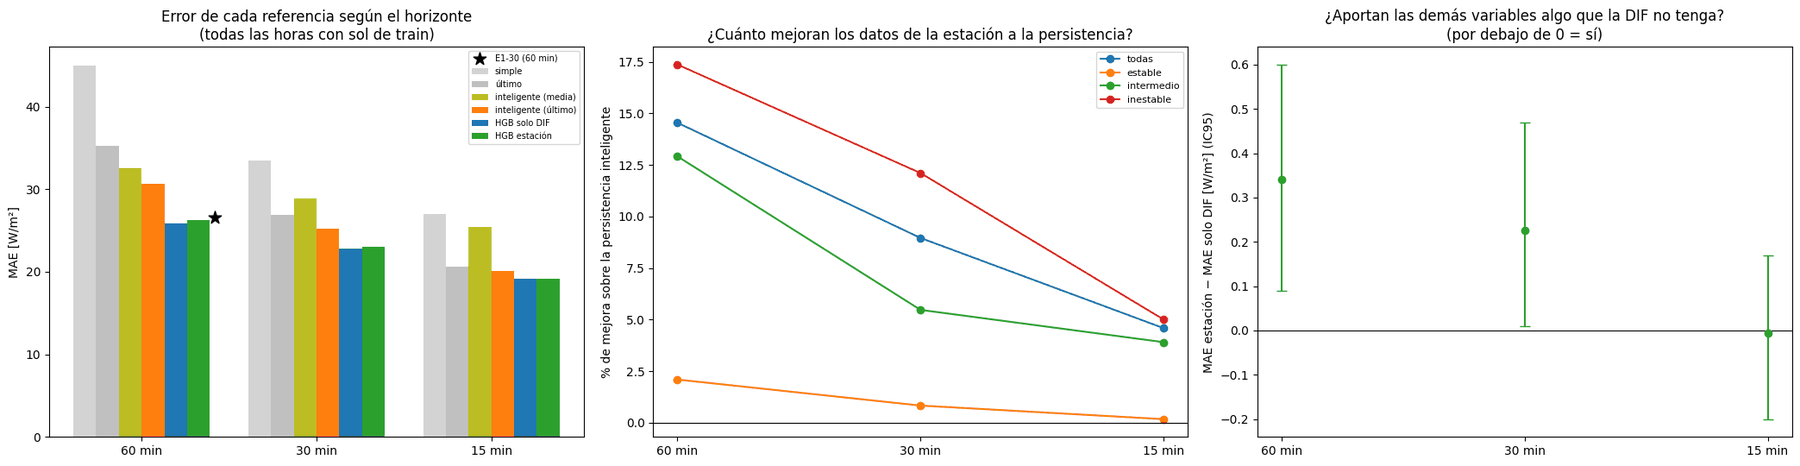

Resultados en: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/diagnostico/H0_horizontes


In [ ]:
import os, sys, subprocess, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor

warnings.filterwarnings("ignore")
try:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
except ImportError:
    pass
try:
    import pvlib
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pvlib"], check=True)
    import pvlib

BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
DIAG = BASE_DIR / "resultados" / "diagnostico"
PARQUET = BASE_DIR / "radiation_data_completo.parquet"
RUTA_TABLA = DIAG / "faseB_radiografia_E1" / "tabla_horaria_E1.pkl"
RUTA_OOF = DIAG / "depuracion_E1_30" / "P1_oof_E1_30.pkl"
SALIDA = DIAG / "H0_horizontes"
SALIDA.mkdir(parents=True, exist_ok=True)
LAT, LON, ALT = 51.9711, 4.9267, 0
INI_TRAIN, FIN_TRAIN = pd.Timestamp("2023-12-30"), pd.Timestamp("2024-08-01")
HORIZONTES = [60, 30, 15]
VENTANA, BLOQUE = 60, 5  # información previa: última hora en bloques de 5 min
MIN_COBERTURA = 0.8
N_BOOT = 2000
SIGMA = 5.670374419e-8
PARAMS = dict(
    loss="absolute_error",
    max_iter=150,
    learning_rate=0.05,
    min_samples_leaf=80,
    l2_regularization=1.0,
    random_state=0,
)

# 1) Datos minuto a minuto (solo train) y cielo despejado
COLS = {
    "DIF [W/m**2]": "DIF",
    "DIF std dev [W/m**2]": "DIF_sd",
    "SWD [W/m**2]": "SWD",
    "SWD std dev [W/m**2]": "SWD_sd",
    "DIR [W/m**2]": "DIR",
    "DIR std dev [W/m**2]": "DIR_sd",
    "LWD [W/m**2]": "LWD",
    "SWU [W/m**2]": "SWU",
    "T2 [°C]": "T2",
    "RH [%]": "RH",
}
raw = pd.read_parquet(PARQUET, columns=["Date/Time"] + list(COLS))
raw["Date/Time"] = pd.to_datetime(raw["Date/Time"], utc=True).dt.tz_localize(None)
raw = raw.set_index("Date/Time").sort_index()
raw = raw[~raw.index.duplicated()]
raw = raw[
    (raw.index >= INI_TRAIN - pd.Timedelta(hours=3))
    & (raw.index < FIN_TRAIN + pd.Timedelta(hours=2))
]
assert raw.index.max() < pd.Timestamp("2024-10-01"), "Se estarían leyendo datos del test"
M = raw.rename(columns=COLS).apply(pd.to_numeric, errors="coerce").asfreq("min")
loc = pvlib.location.Location(LAT, LON, tz="UTC", altitude=ALT)
t_utc = M.index.tz_localize("UTC")
sp, cs = loc.get_solarposition(t_utc), loc.get_clearsky(t_utc, model="ineichen")
elev = pd.Series(sp["apparent_elevation"].to_numpy(), index=M.index)
dhi_cs = pd.Series(cs["dhi"].to_numpy(), index=M.index)
ghi_cs = pd.Series(cs["ghi"].to_numpy(), index=M.index)
T2k = M["T2"] + 273.15
e_hpa = M["RH"] / 100 * 6.112 * np.exp(17.62 * M["T2"] / (243.12 + M["T2"]))
F = pd.DataFrame(
    {
        "DIF/DIF despejado": (M["DIF"] / dhi_cs).where(dhi_cs >= 10).clip(0, 5),
        "DIF std dev": M["DIF_sd"],
        "kc": (M["SWD"] / ghi_cs).where(ghi_cs >= 50).clip(0, 3),
        "SWD std dev": M["SWD_sd"],
        "DIR std dev": M["DIR_sd"],
        "LWD/LWD despejado": (M["LWD"] / (1.24 * (e_hpa / T2k) ** (1 / 7) * SIGMA * T2k**4)).clip(
            0, 3
        ),
        "albedo": (M["SWU"] / M["SWD"]).where(M["SWD"] >= 20).clip(0, 1),
        "sol visible": (M["DIR"] >= 120).astype(float).where(M["DIR"].notna()),
    },
    index=M.index,
)
SOLO_DIF = ["DIF/DIF despejado", "DIF std dev"]
ESTACION = SOLO_DIF + [
    "kc",
    "SWD std dev",
    "DIR std dev",
    "LWD/LWD despejado",
    "albedo",
    "sol visible",
]
print(
    f"Minutos: {len(M):,} · variables por bloque: solo DIF {len(SOLO_DIF)} · estación {len(ESTACION)}"
)

# 2) Instantes de emisión, objetivos y persistencias por horizonte
H = pd.read_pickle(RUTA_TABLA).sort_index()
TR = H[(H["conjunto"] == "train") & (H["regimen"].astype(str) != "noche")].copy()
dif = M["DIF"].to_numpy(dtype=float)
dcs = dhi_cs.to_numpy(dtype=float)
pos0 = M.index.get_indexer(TR.index)
ok_pos = pos0 >= VENTANA
TR, pos0 = TR[ok_pos].copy(), pos0[ok_pos]

def media_ventana(arr, ini, n):
    idx = ini[:, None] + np.arange(n)[None, :]
    v = arr[np.clip(idx, 0, len(arr) - 1)]
    cnt = np.sum(~np.isnan(v), axis=1)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        return np.where(cnt >= MIN_COBERTURA * n, np.nanmean(v, axis=1), np.nan)

ult3 = dif[pos0[:, None] + np.arange(-3, 0)[None, :]]
ultimo = np.array([r[~np.isnan(r)][-1] if (~np.isnan(r)).any() else np.nan for r in ult3])
cs_ult = dcs[pos0 - 1]
kc_min = F["kc"].to_numpy()
_kw = kc_min[pos0[:, None] + np.arange(-60, 0)[None, :]]
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    I_emision = np.where(
        np.sum(~np.isnan(_kw), axis=1) >= 30, np.nanstd(_kw, axis=1, ddof=1), np.nan
    )
cortes = np.nanpercentile(I_emision, [100 / 3, 200 / 3])
TR["estrato"] = np.where(
    np.isnan(I_emision),
    "sol bajo / sin dato",
    np.where(
        I_emision <= cortes[0],
        "estable",
        np.where(I_emision <= cortes[1], "intermedio", "inestable"),
    ),
)
D = {}
for h in HORIZONTES:
    y = media_ventana(dif, pos0, h)
    simple = media_ventana(dif, pos0 - h, h)
    cs_obj, cs_prev = media_ventana(dcs, pos0, h), media_ventana(dcs, pos0 - h, h)
    D[h] = pd.DataFrame(
        {
            "y": y,
            "simple": simple,
            "último": ultimo,
            "inteligente (media)": np.clip(
                simple * np.where(cs_prev > 5, cs_obj / np.maximum(cs_prev, 5), 1.0), 0, None
            ),
            "inteligente (último)": np.clip(
                ultimo * np.where(cs_ult > 5, cs_obj / np.maximum(cs_ult, 5), 1.0), 0, None
            ),
            "cociente despejado": np.where(cs_ult > 5, cs_obj / np.maximum(cs_ult, 5), 1.0),
            "elev mitad objetivo": elev.to_numpy()[np.clip(pos0 + h // 2, 0, len(M) - 1)],
        },
        index=TR.index,
    )
OOF = pd.read_pickle(RUTA_OOF)
D[60]["E1-30 (P1)"] = OOF["OOF30_media"].reindex(TR.index).to_numpy()
print(f"Emisiones (horas con sol de train): {len(TR)} · cortes de estabilidad: {cortes.round(3)}")

# Variables previas a la emisión: última hora en bloques de 5 min
nb = VENTANA // BLOQUE
idxw = pos0[:, None] + np.arange(-VENTANA, 0)[None, :]
Farr = F[ESTACION].to_numpy(dtype=np.float32)[idxw]  # emisiones × 60 × variables
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    Fb = np.nanmean(Farr.reshape(len(TR), nb, BLOQUE, len(ESTACION)), axis=2)
nombres_b = [
    f"{v} [{-VENTANA + BLOQUE * k}…{-VENTANA + BLOQUE * (k + 1)}]"
    for v in ESTACION
    for k in range(nb)
]
Xb = pd.DataFrame(Fb.transpose(0, 2, 1).reshape(len(TR), -1), columns=nombres_b, index=TR.index)
Xb["elev emisión"] = elev.to_numpy()[pos0]
col_dif = [c for c in Xb.columns if any(c.startswith(v + " [") for v in SOLO_DIF)] + [
    "elev emisión"
]
col_est = list(Xb.columns)

# 3) Herramientas: bootstrap por días y validación dejando cada mes fuera
dias = TR.index.normalize().to_numpy()
mes = TR.index.to_period("M").astype(str).str.replace("2023-12", "2024-01").to_numpy()
u, inv = np.unique(dias, return_inverse=True)
rng = np.random.default_rng(0)
C = np.stack(
    [np.bincount(rng.integers(0, len(u), len(u)), minlength=len(u)) for _ in range(N_BOOT)]
)
W = C[:, inv].astype(float)

def media_ic(x, msk):
    m = msk & ~np.isnan(x)
    v = np.where(m, x, 0.0)
    b = (W @ v) / np.maximum(W @ m, 1e-9)
    return v.sum() / max(m.sum(), 1), np.percentile(b, 2.5), np.percentile(b, 97.5)

def corregir(h, cols):
    """Predicción = BASE + residuo aprendido por HGB dejando cada mes fuera."""
    d = D[h]
    base = d["inteligente (último)"].to_numpy()
    y = d["y"].to_numpy()
    X = pd.concat([Xb[cols], d[["cociente despejado", "elev mitad objetivo"]]], axis=1)
    pred = np.full(len(d), np.nan)
    valido = ~np.isnan(y) & ~np.isnan(base)
    for m_ in np.unique(mes):
        te = (mes == m_) & valido
        tr = (mes != m_) & valido
        if te.sum() == 0:
            continue
        mod = HistGradientBoostingRegressor(**PARAMS).fit(X[tr], (y - base)[tr])
        pred[te] = base[te] + mod.predict(X[te])
    return np.clip(pred, 0, None)


# 4) Resultados
REFS = ["simple", "último", "inteligente (media)", "inteligente (último)"]
ESTR = ["todas", "estable", "intermedio", "inestable"]
mascara = {
    e: (np.ones(len(TR), bool) if e == "todas" else (TR["estrato"] == e).to_numpy()) for e in ESTR
}
filas_p, filas_m = [], []
for h in HORIZONTES:
    d = D[h]
    d["HGB solo DIF"] = corregir(h, col_dif)
    d["HGB estación"] = corregir(h, col_est)
    comun = ~d[REFS + ["y", "HGB solo DIF", "HGB estación"]].isna().any(axis=1).to_numpy()
    if h == 60:
        comun &= ~np.isnan(d["E1-30 (P1)"].to_numpy())
    y = d["y"].to_numpy()
    for e in ESTR:
        msk = comun & mascara[e]
        fila = {
            "horizonte (min)": h,
            "estabilidad": e,
            "horas": int(msk.sum()),
            "DIF media objetivo": np.nanmean(y[msk]),
        }
        for r in REFS + ["HGB solo DIF", "HGB estación"] + (["E1-30 (P1)"] if h == 60 else []):
            fila[f"MAE {r}"] = np.abs(d[r].to_numpy() - y)[msk].mean()
        filas_p.append(fila)
        eb = np.abs(d["inteligente (último)"].to_numpy() - y)
        e_dif, e_est = np.abs(d["HGB solo DIF"].to_numpy() - y), np.abs(
            d["HGB estación"].to_numpy() - y
        )
        c1, l1, h1 = media_ic(e_dif - eb, msk)
        c2, l2, h2 = media_ic(e_est - eb, msk)
        c3, l3, h3 = media_ic(e_est - e_dif, msk)
        filas_m.append(
            {
                "horizonte (min)": h,
                "estabilidad": e,
                "horas": int(msk.sum()),
                "MAE BASE (inteligente último)": eb[msk].mean(),
                "solo DIF − BASE": c1,
                "IC95 (1)": f"[{l1:+.2f}, {h1:+.2f}]",
                "estación − BASE": c2,
                "IC95 (2)": f"[{l2:+.2f}, {h2:+.2f}]",
                "estación − solo DIF": c3,
                "IC95 (3)": f"[{l3:+.2f}, {h3:+.2f}]",
                "% mejora estación sobre BASE": -100 * c2 / eb[msk].mean(),
                "¿aporta la estación?": (
                    "sí" if h3 < 0 else ("empeora" if l3 > 0 else "no se distingue")
                ),
            }
        )
P = pd.DataFrame(filas_p)
MJ = pd.DataFrame(filas_m)
pd.set_option("display.width", 260)
pd.set_option("display.max_columns", 40)
print(
    "\n"
    + "=" * 120
    + "\nH0 · 1) MAE de cada referencia por horizonte y estabilidad (train, horas con sol, mismas horas en cada horizonte)\n"
    + "=" * 120
)
display(P.set_index(["horizonte (min)", "estabilidad"]).round(2))
print(
    "\n"
    + "=" * 120
    + "\nH0 · 2) ¿Cuánto añaden los datos a la BASE (persistencia inteligente del último minuto)? Negativo = menos error\n"
    + "=" * 120
)
display(MJ.set_index(["horizonte (min)", "estabilidad"]).round(2))

# 5) Gráficas
fig, axs = plt.subplots(1, 3, figsize=(21, 5.5))
todas = P[P["estabilidad"] == "todas"].set_index("horizonte (min)").loc[HORIZONTES]
x = np.arange(len(HORIZONTES))
w = 0.13
serie = REFS + ["HGB solo DIF", "HGB estación"]
col = ["lightgray", "silver", "tab:olive", "tab:orange", "tab:blue", "tab:green"]
for k, r in enumerate(serie):
    axs[0].bar(x + (k - 2.5) * w, todas[f"MAE {r}"], w, color=col[k], label=r)
axs[0].scatter(
    [0 + 3.2 * w],
    [todas.loc[60, "MAE E1-30 (P1)"]],
    color="k",
    marker="*",
    s=120,
    zorder=3,
    label="E1-30 (60 min)",
)
axs[0].set_xticks(x)
axs[0].set_xticklabels([f"{h} min" for h in HORIZONTES])
axs[0].set_ylabel("MAE [W/m²]")
axs[0].legend(fontsize=7)
axs[0].set_title("Error de cada referencia según el horizonte\n(todas las horas con sol de train)")
for k, e in enumerate(ESTR):
    sub = MJ[MJ["estabilidad"] == e].set_index("horizonte (min)").loc[HORIZONTES]
    axs[1].plot(
        [f"{h} min" for h in HORIZONTES], sub["% mejora estación sobre BASE"], "o-", label=e
    )
axs[1].axhline(0, color="k", lw=0.8)
axs[1].set_ylabel("% de mejora sobre la persistencia inteligente")
axs[1].legend(fontsize=8)
axs[1].set_title("¿Cuánto mejoran los datos de la estación a la persistencia?")
sub = MJ[MJ["estabilidad"] == "todas"].set_index("horizonte (min)").loc[HORIZONTES]
lims = sub["IC95 (3)"].str.strip("[]").str.split(",", expand=True).astype(float)
axs[2].errorbar(
    range(len(HORIZONTES)),
    sub["estación − solo DIF"],
    yerr=[sub["estación − solo DIF"] - lims[0], lims[1] - sub["estación − solo DIF"]],
    fmt="o",
    color="tab:green",
    capsize=4,
)
axs[2].axhline(0, color="k", lw=0.8)
axs[2].set_xticks(range(len(HORIZONTES)))
axs[2].set_xticklabels([f"{h} min" for h in HORIZONTES])
axs[2].set_ylabel("MAE estación − MAE solo DIF [W/m²] (IC95)")
axs[2].set_title("¿Aportan las demás variables algo que la DIF no tenga?\n(por debajo de 0 = sí)")
plt.tight_layout()
plt.savefig(SALIDA / "H0_horizontes.png", dpi=120)
plt.show()
P.to_csv(SALIDA / "H0_MAE_referencias.csv", index=False)
MJ.to_csv(SALIDA / "H0_mejora_estacion.csv", index=False)
print("Resultados en:", SALIDA)

**Resultados.** Lo que los datos añaden a la persistencia crece con el horizonte.

- La persistencia del último minuto pasa de 30,68 W/m² a 60 minutos a 25,25 a 30 y 20,08 a 15; el HGB con solo la DIF la mejora en 4,81, 2,49 y 0,92 W/m², un 15,7 %, un 9,9 % y un 4,6 %.
- La estación no aporta en ningún horizonte: frente a solo la DIF, el MAE sube 0,34 W/m² (IC95 [+0,09; +0,60]) a 60 minutos y 0,23 W/m² (IC95 [+0,01; +0,47]) a 30, y no se distingue a 15 (−0,01 W/m², IC95 [−0,20; +0,17]).
- A 60 minutos, el HGB con solo la DIF obtiene 25,88 W/m², frente a 26,52 W/m² de E1-30 en las mismas horas, sin intervalo para esa diferencia.

### 13.3 Entrada de una hora y referencia con HGB

Para cada hora objetivo de entrenamiento y validación, las mismas de E1-30, se construye una entrada que solo usa la última hora observada (L0): 12 bloques de 5 minutos con cinco canales (DIF media, cociente k con la DIF de cielo despejado, variabilidad de la DIF y de la global, y elevación solar) y cuatro escalares (último minuto, cociente de cielo despejado entre la hora objetivo y el último bloque, persistencia del último minuto, llamada `persistencia inteligente` en las tablas, y elevación a mitad de la hora objetivo). La variante B añade la DIF media y k de las tres horas anteriores. Un HGB con pérdida absoluta aprende con esa entrada la corrección sobre la persistencia del último minuto y se compara una sola vez en validación con E1-30, solo como referencia (L1).

Minutos: 397,800 (2023-12-29 18:00:00 → 2024-09-30 23:59:00) · DIF con dato: 99.9 %
train: 5149 horas · horas sin ningún bloque válido: 0
   ventana [T−60, T) frente a DIF(T−1) del .npz: mediana |dif| = 0.00 W/m², P95 = 0.00
   ventana [T, T+60) frente al objetivo y(T):     mediana |dif| = 0.00 W/m², P95 = 0.00
validation: 1464 horas · horas sin ningún bloque válido: 0
   ventana [T−60, T) frente a DIF(T−1) del .npz: mediana |dif| = 0.00 W/m², P95 = 0.00
   ventana [T, T+60) frente al objetivo y(T):     mediana |dif| = 0.00 W/m², P95 = 0.00
Paso 0 terminado: entradas guardadas en /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/diagnostico/L_entrada_una_hora/entrada_una_hora.npz
Persistencia inteligente (horas con sol): train 30.81 · validación 27.58 W/m² (en H0, train ≈ 30,7 con una definición casi igual)

Canales de la secuencia (train, horas con sol, todos los bloques):


,count,mean,std,min,5%,50%,95%,max
DIF media,36324.0,136.683,123.998,-2.000,-1.000,102.800,385.800,687.400
k = DIF/DIF despejado,36324.0,1.752,0.923,0.000,0.554,1.560,3.519,5.000
variabilidad DIF,36324.0,0.024,0.032,0.000,0.000,0.014,0.083,0.867
variabilidad SWD,36324.0,0.023,0.043,0.000,0.000,0.005,0.123,0.377
elevación,36324.0,24.537,19.620,-18.147,-6.962,22.593,57.395,61.475



Escalares (train, horas con sol):


,count,mean,std,min,5%,50%,95%,max
último minuto DIF,3027.0,138.190,125.294,-2.000,0.000,103.000,389.700,699.000
cociente cielo despejado,3027.0,1.025,0.494,0.073,0.327,1.000,1.448,5.512
persistencia inteligente,3027.0,137.432,125.235,0.000,0.000,103.219,387.346,693.241
elevación T+30,3027.0,25.184,18.623,-4.986,-1.620,22.638,57.609,61.382



L1 · HGB CON LA ENTRADA DE UNA HORA EN VALIDACIÓN (ago–sep 2024, horas con sol; E1-30 = 23.25)


,MAE,RMSE,sesgo,− E1-30,IC95,DM p,lectura,− E1-30 banda central,IC95 central,− E1-30 nubosidad variable,IC95 nubosidad
modelo,,,,,,,,,,,
persistencia inteligente,27.581,42.864,-2.171,4.327,"[+2.66, +6.05]",0.000,peor que E1-30,4.331,"[-1.48, +9.87]",8.855,"[+6.14, +11.64]"
HGB-1h A,23.006,35.710,0.151,-0.248,"[-1.46, +0.89]",0.726,igual que E1-30,0.225,"[-3.77, +4.07]",1.567,"[-0.29, +3.47]"
HGB-1h B,22.829,35.704,-0.395,-0.425,"[-1.49, +0.63]",0.481,igual que E1-30,-0.619,"[-4.22, +2.86]",1.130,"[-0.65, +2.90]"
V3-50,22.472,34.339,-0.767,-0.782,"[-1.50, -0.06]",0.039,mejor que E1-30,-1.059,"[-3.74, +1.63]",-0.584,"[-1.80, +0.65]"


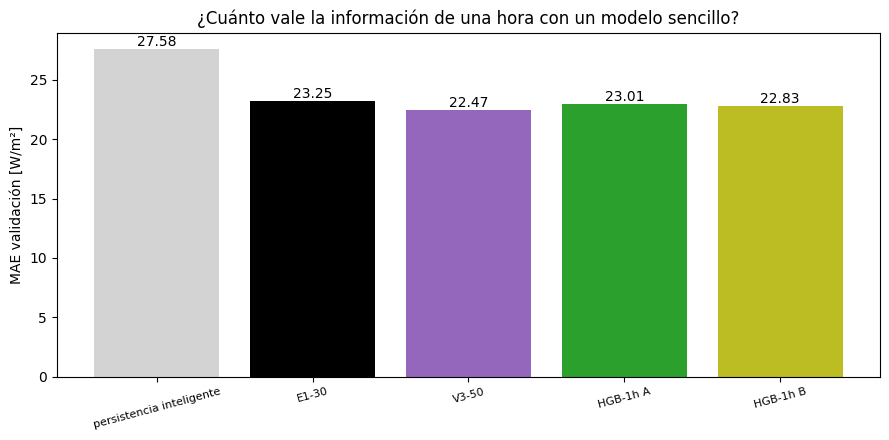

Resultados en: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/diagnostico/L_entrada_una_hora


In [ ]:
import os, sys, subprocess, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from sklearn.ensemble import HistGradientBoostingRegressor

warnings.filterwarnings("ignore")
try:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
except ImportError:
    pass
try:
    import pvlib
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pvlib"], check=True)
    import pvlib

BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
DIAG = BASE_DIR / "resultados" / "diagnostico"
RUTA_NPZ = (
    BASE_DIR
    / "resultados"
    / "ejecuciones"
    / "preparacion_bloque_difstats_20261006_180841"
    / "matrices_dif_elev_difstats.npz"
)
PARQUET = BASE_DIR / "radiation_data_completo.parquet"
RUTA_TABLA = DIAG / "faseB_radiografia_E1" / "tabla_horaria_E1.pkl"
RUTA_C8B = DIAG / "faseC_ultimo_minuto" / "C8b_confirmacion" / "C8b_predicciones_validacion.pkl"
SALIDA = DIAG / "L_entrada_una_hora"
SALIDA.mkdir(parents=True, exist_ok=True)
LAT, LON, ALT = 51.9711, 4.9267, 0
FIN_DATOS = pd.Timestamp("2024-10-01")
NB, BL = 12, 5
N_BOOT = 2000
PARAMS = dict(
    loss="absolute_error",
    max_iter=150,
    learning_rate=0.05,
    min_samples_leaf=80,
    l2_regularization=1.0,
    random_state=0,
)
CANALES = [
    "DIF media",
    "k = DIF/DIF despejado",
    "variabilidad DIF",
    "variabilidad SWD",
    "elevación",
]
ESCALARES = [
    "último minuto DIF",
    "cociente cielo despejado",
    "persistencia inteligente",
    "elevación T+30",
]
CONTEXTO = ["DIF T−2", "DIF T−3", "DIF T−4", "k T−2", "k T−3", "k T−4"]

# Paso 0 · 1) Minutos y cielo despejado
mat = np.load(RUTA_NPZ)
X_npz = {
    "train": mat["X_train_DIF_elev_DIFstats_raw"].astype(np.float32),
    "validation": mat["X_validation_DIF_elev_DIFstats_raw"].astype(np.float32),
}
y_npz = {
    "train": mat["y_train_difstats"].astype(np.float32).reshape(-1),
    "validation": mat["y_validation_difstats"].astype(np.float32).reshape(-1),
}
fechas = {
    "train": pd.DatetimeIndex(mat["fechas_train"]),
    "validation": pd.DatetimeIndex(mat["fechas_validation"]),
}
COLS = {"DIF [W/m**2]": "DIF", "DIF std dev [W/m**2]": "DIF_sd", "SWD std dev [W/m**2]": "SWD_sd"}
raw = pd.read_parquet(PARQUET, columns=["Date/Time"] + list(COLS))
raw["Date/Time"] = pd.to_datetime(raw["Date/Time"], utc=True).dt.tz_localize(None)
raw = raw.set_index("Date/Time").sort_index()
raw = raw[~raw.index.duplicated()]
raw = raw[(raw.index >= fechas["train"].min() - pd.Timedelta(hours=6)) & (raw.index < FIN_DATOS)]
assert raw.index.max() < FIN_DATOS, "Se estarían leyendo datos del test"
Mi = raw.rename(columns=COLS).apply(pd.to_numeric, errors="coerce")
idx_min = pd.date_range(
    fechas["train"].min() - pd.Timedelta(hours=6),
    fechas["validation"].max() + pd.Timedelta(hours=1),
    freq="min",
    inclusive="left",
)
assert idx_min.max() < FIN_DATOS
Mi = Mi.reindex(idx_min)
loc = pvlib.location.Location(LAT, LON, tz="UTC", altitude=ALT)
t_utc = idx_min.tz_localize("UTC")
sp, cs = loc.get_solarposition(t_utc), loc.get_clearsky(t_utc, model="ineichen")
A = {
    "dif": Mi["DIF"].to_numpy(float),
    "dsd": Mi["DIF_sd"].to_numpy(float),
    "ssd": Mi["SWD_sd"].to_numpy(float),
    "dcs": cs["dhi"].to_numpy(float),
    "gcs": cs["ghi"].to_numpy(float),
    "elev": sp["apparent_elevation"].to_numpy(float),
}
print(
    f"Minutos: {len(idx_min):,} ({idx_min.min()} → {idx_min.max()}) · DIF con dato: {100 * np.isfinite(A['dif']).mean():.1f} %"
)


# Paso 0 · 2) Construcción de las entradas
def ffill_bfill(M):
    D = pd.DataFrame(M.T)  # bloques en filas
    return D.ffill().bfill().to_numpy().T.copy()

def construir(conj):
    f = fechas[conj]
    Xn = X_npz[conj]
    pos0 = idx_min.get_indexer(f)
    assert (pos0 >= 240).all(), "Faltan minutos previos"
    w = pos0[:, None] + np.arange(-60, 0)[None, :]
    dif, dsd, ssd, dcs, gcs = (
        A[k][w].reshape(len(f), NB, BL) for k in ["dif", "dsd", "ssd", "dcs", "gcs"]
    )
    val = np.isfinite(dif)
    nval = val.sum(2)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        dif_m = np.where(nval >= 3, np.nanmean(dif, 2), np.nan)
        dcs_v = np.where(val, dcs, np.nan)
        k = np.where(
            (nval >= 3) & (np.nanmean(dcs_v, 2) >= 10),
            np.nansum(np.where(val, dif, 0), 2) / np.maximum(np.nansum(dcs_v, 2), 1e-9),
            np.nan,
        )
        k = np.clip(k, 0, 5)
        dcs_m, gcs_m = dcs.mean(2), gcs.mean(2)
        vdif = np.where(
            (np.isfinite(dsd).sum(2) >= 3) & (dcs_m >= 10),
            np.nanmean(dsd, 2) / np.maximum(dcs_m, 1e-9),
            np.nan,
        )
        vswd = np.where(
            (np.isfinite(ssd).sum(2) >= 3) & (gcs_m >= 50),
            np.nanmean(ssd, 2) / np.maximum(gcs_m, 1e-9),
            np.nan,
        )
    elev_b = A["elev"][pos0[:, None] - 60 + BL * np.arange(NB)[None, :] + 2]
    vacias = np.isnan(dif_m).all(1)
    dif_m = ffill_bfill(dif_m)
    dif_m[vacias] = Xn[vacias, -1, 0][:, None]  # hora sin datos → DIF horaria de T−1
    k = np.nan_to_num(ffill_bfill(k), nan=1.0)
    vdif = np.nan_to_num(ffill_bfill(vdif), nan=0.0)
    vswd = np.nan_to_num(ffill_bfill(vswd), nan=0.0)
    seq = np.stack([dif_m, k, vdif, vswd, elev_b], axis=2).astype(np.float32)
    ult3 = A["dif"][pos0[:, None] + np.arange(-3, 0)[None, :]]
    ult = np.array([r[np.isfinite(r)][-1] if np.isfinite(r).any() else np.nan for r in ult3])
    ult = np.where(np.isfinite(ult), ult, dif_m[:, -1])
    cs_T = A["dcs"][pos0[:, None] + np.arange(60)[None, :]].mean(1)
    cs_12 = dcs_m[:, -1]
    rcs = np.where(cs_12 >= 5, cs_T / np.maximum(cs_12, 5), 1.0)
    pint = np.clip(ult * rcs, 0, None)
    sc = np.stack([ult, rcs, pint, A["elev"][pos0 + 30]], axis=1).astype(np.float32)
    ctx_dif = Xn[:, [-2, -3, -4], 0]
    cs_h = np.stack(
        [
            A["dcs"][pos0[:, None] + np.arange(-60 * j, -60 * (j - 1))[None, :]].mean(1)
            for j in (2, 3, 4)
        ],
        axis=1,
    )
    ctx_k = np.clip(np.where(cs_h >= 10, ctx_dif / np.maximum(cs_h, 1e-9), 1.0), 0, 5)
    ctx = np.concatenate([ctx_dif, ctx_k], axis=1).astype(np.float32)

    # Comprobación de alineación: media de los 12 bloques de DIF ≈ DIF horaria de T−1 del .npz
    dif_h = np.nanmean(np.where(val, dif, np.nan).reshape(len(f), -1), 1)
    ok = np.isfinite(dif_h) & (val.sum((1, 2)) >= 55)
    dif_alin = np.abs(dif_h[ok] - Xn[ok, -1, 0])
    # ... y media de [T, T+60) ≈ objetivo y(T) (confirma que la fecha T etiqueta el INICIO de la hora objetivo)
    wy = pos0[:, None] + np.arange(0, 60)[None, :]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        y_min = np.nanmean(A["dif"][wy], 1)
        cnt_y = np.isfinite(A["dif"][wy]).sum(1)
    oky = np.isfinite(y_min) & (cnt_y >= 55) & np.isfinite(y_npz[conj])
    y_alin = np.abs(y_min[oky] - y_npz[conj][oky])
    print(
        f"{conj}: {len(f)} horas · horas sin ningún bloque válido: {int(vacias.sum())}\n"
        f"   ventana [T−60, T) frente a DIF(T−1) del .npz: mediana |dif| = {np.median(dif_alin):.2f} W/m², P95 = {np.percentile(dif_alin, 95):.2f}\n"
        f"   ventana [T, T+60) frente al objetivo y(T):     mediana |dif| = {np.median(y_alin):.2f} W/m², P95 = {np.percentile(y_alin, 95):.2f}"
    )
    if (
        np.median(dif_alin) >= 1.0 or np.median(y_alin) >= 1.0
    ):  # diagnóstico: ¿con qué desplazamiento sí cuadra?
        for d in (-120, -60, 0, 60):
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                m = np.nanmean(
                    A["dif"][
                        np.clip(pos0[:, None] + d + np.arange(60)[None, :], 0, len(idx_min) - 1)
                    ],
                    1,
                )
            print(
                f"   ventana [T{d:+d}, T{d + 60:+d}): mediana |dif| con DIF(T−1) = {np.nanmedian(np.abs(m - Xn[:, -1, 0])):.2f} · "
                f"con y(T) = {np.nanmedian(np.abs(m - y_npz[conj])):.2f}"
            )
    assert (
        np.median(dif_alin) < 1.0
    ), "La ventana de una hora no coincide con la DIF horaria de T−1: revisar la alineación"
    assert (
        np.median(y_alin) < 1.0
    ), "La hora objetivo no coincide con [T, T+60): revisar la alineación"
    assert (
        np.isfinite(seq).all() and np.isfinite(sc).all() and np.isfinite(ctx).all()
    ), "Quedan huecos en las entradas"
    return seq, sc, ctx

DATOS = {}
for conj in ["train", "validation"]:
    DATOS[conj] = construir(conj)
np.savez_compressed(
    SALIDA / "entrada_una_hora.npz",
    seq_train=DATOS["train"][0],
    esc_train=DATOS["train"][1],
    ctx_train=DATOS["train"][2],
    y_train=y_npz["train"],
    fechas_train=fechas["train"].to_numpy(),
    seq_validation=DATOS["validation"][0],
    esc_validation=DATOS["validation"][1],
    ctx_validation=DATOS["validation"][2],
    y_validation=y_npz["validation"],
    fechas_validation=fechas["validation"].to_numpy(),
    canales=np.array(CANALES),
    escalares=np.array(ESCALARES),
    contexto=np.array(CONTEXTO),
)
print("Paso 0 terminado: entradas guardadas en", SALIDA / "entrada_una_hora.npz")
H = pd.read_pickle(RUTA_TABLA).sort_index()
sol = {
    c: (H[H["conjunto"] == c]["regimen"].astype(str) != "noche").to_numpy()
    for c in ["train", "validation"]
}
for c in ["train", "validation"]:
    assert len(sol[c]) == len(y_npz[c]) and (H[H["conjunto"] == c].index == fechas[c]).all()
pi_mae = {c: np.abs(DATOS[c][1][:, 2] - y_npz[c])[sol[c]].mean() for c in ["train", "validation"]}
print(
    f"Persistencia inteligente (horas con sol): train {pi_mae['train']:.2f} · validación {pi_mae['validation']:.2f} W/m² "
    f"(en H0, train ≈ 30,7 con una definición casi igual)"
)

# Resumen de los canales (train, horas con sol)
desc = (
    pd.DataFrame({n: DATOS["train"][0][sol["train"], :, j].ravel() for j, n in enumerate(CANALES)})
    .describe(percentiles=[0.05, 0.5, 0.95])
    .T
)
desc2 = (
    pd.DataFrame({n: DATOS["train"][1][sol["train"], j] for j, n in enumerate(ESCALARES)})
    .describe(percentiles=[0.05, 0.5, 0.95])
    .T
)
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 30)
print("\nCanales de la secuencia (train, horas con sol, todos los bloques):")
display(desc.round(3))
print("\nEscalares (train, horas con sol):")
display(desc2.round(3))


# Paso 1 · HGB con las entradas aplanadas (A y B), una vez en validación
def aplanar(conj, variante):
    seq, sc, ctx = DATOS[conj]
    partes = [seq.reshape(len(seq), -1), sc] + ([ctx] if variante == "B" else [])
    return np.concatenate(partes, axis=1)

y_tr, y_va = y_npz["train"], y_npz["validation"]
base_tr, base_va = DATOS["train"][1][:, 2], DATOS["validation"][1][:, 2]
PRED = {}
for v in ["A", "B"]:
    mod = HistGradientBoostingRegressor(**PARAMS).fit(
        aplanar("train", v)[sol["train"]], (y_tr - base_tr)[sol["train"]]
    )
    PRED[f"HGB-1h {v}"] = np.clip(base_va + mod.predict(aplanar("validation", v)), 0, None)
C8 = pd.read_pickle(RUTA_C8B)
assert (C8.index == fechas["validation"]).all()
PRED["E1-30"] = C8["E1_30"].to_numpy()
PRED["V3-50"] = C8["V3_50"].to_numpy()
PRED["persistencia inteligente"] = base_va
m = sol["validation"]
y = y_va[m]
E = {k: np.abs(p[m] - y) for k, p in PRED.items()}
assert abs(E["E1-30"].mean() - 23.25) < 0.05, "No se reproduce el MAE de E1-30"
inf = H[H["conjunto"] == "validation"][m]
dias = inf.index.normalize().to_numpy()
u, inv = np.unique(dias, return_inverse=True)
rng = np.random.default_rng(0)
Wb = np.stack(
    [np.bincount(rng.integers(0, len(u), len(u)), minlength=len(u)) for _ in range(N_BOOT)]
)[:, inv].astype(float)

def ic(d, msk=None):
    msk = np.ones(len(d), bool) if msk is None else msk
    v = np.where(msk, d, 0.0)
    b = (Wb @ v) / np.maximum(Wb @ msk, 1e-9)
    return v[msk].mean(), np.percentile(b, 2.5), np.percentile(b, 97.5)

def dm(d):
    s = pd.Series(d, index=inf.index).groupby(dias).mean().to_numpy()
    n = len(s)
    dc = s - s.mean()
    L = int(np.floor(n ** (1 / 3)))
    var = dc @ dc / n + sum(2 * (1 - k / (L + 1)) * (dc[k:] @ dc[:-k]) / n for k in range(1, L + 1))
    t = s.mean() / np.sqrt(var / n) * np.sqrt((n - 1) / n)
    return t, 2 * stats.t.sf(abs(t), df=n - 1)

central = inf["banda"].astype(str).str.startswith("central").to_numpy()
cielo = inf["cielo"].astype(str).replace({"nubes rotas": "nubosidad variable"}).to_numpy()
filas = []
for k in ["persistencia inteligente", "HGB-1h A", "HGB-1h B", "V3-50"]:
    c, lo, hi = ic(E[k] - E["E1-30"])
    cc, lc, hc = ic(E[k] - E["E1-30"], central)
    cn, ln, hn = ic(E[k] - E["E1-30"], cielo == "nubosidad variable")
    t, p = dm(E[k] - E["E1-30"])
    filas.append(
        {
            "modelo": k,
            "MAE": E[k].mean(),
            "RMSE": np.sqrt(((PRED[k][m] - y) ** 2).mean()),
            "sesgo": (PRED[k][m] - y).mean(),
            "− E1-30": c,
            "IC95": f"[{lo:+.2f}, {hi:+.2f}]",
            "DM p": p,
            "lectura": (
                "mejor que E1-30" if hi < 0 else ("peor que E1-30" if lo > 0 else "igual que E1-30")
            ),
            "− E1-30 banda central": cc,
            "IC95 central": f"[{lc:+.2f}, {hc:+.2f}]",
            "− E1-30 nubosidad variable": cn,
            "IC95 nubosidad": f"[{ln:+.2f}, {hn:+.2f}]",
        }
    )
R = pd.DataFrame(filas).set_index("modelo")
print(
    "\n"
    + "=" * 120
    + f"\nL1 · HGB CON LA ENTRADA DE UNA HORA EN VALIDACIÓN (ago–sep 2024, horas con sol; E1-30 = {E['E1-30'].mean():.2f})\n"
    + "=" * 120
)
display(R.round(3))
fig, ax = plt.subplots(figsize=(9, 4.5))
orden = ["persistencia inteligente", "E1-30", "V3-50", "HGB-1h A", "HGB-1h B"]
ax.bar(
    range(len(orden)),
    [E[k].mean() for k in orden],
    color=["lightgray", "black", "tab:purple", "tab:green", "tab:olive"],
)
for i, k in enumerate(orden):
    ax.text(i, E[k].mean(), f"{E[k].mean():.2f}", ha="center", va="bottom")
ax.set_xticks(range(len(orden)))
ax.set_xticklabels(orden, fontsize=8, rotation=15)
ax.set_ylabel("MAE validación [W/m²]")
ax.set_title("¿Cuánto vale la información de una hora con un modelo sencillo?")
plt.tight_layout()
plt.savefig(SALIDA / "L1_HGB_validacion.png", dpi=120)
plt.show()
R.to_csv(SALIDA / "L1_HGB_validacion.csv")
pd.DataFrame(
    {**{k: v for k, v in PRED.items()}, "real": y_va}, index=fechas["validation"]
).to_pickle(SALIDA / "L1_predicciones_validacion.pkl")
print("Resultados en:", SALIDA)

**Resultados.** Las comprobaciones de alineación confirman que la media de los 12 bloques coincide con la DIF de la última hora observada y la de los 60 minutos siguientes, con el objetivo (mediana de la diferencia: 0,00 W/m²). En validación, la persistencia del último minuto obtiene 27,58 W/m², 4,33 W/m² más que E1-30 (IC95 [+2,66; +6,05]). Los HGB de una hora no se distinguen de E1-30: la variante A obtiene 23,01 W/m² (−0,25 W/m², IC95 [−1,46; +0,89]) y la B, 22,83 W/m² (−0,43 W/m², IC95 [−1,49; +0,63]); como referencia, V3-50 obtiene 22,47 W/m².

### 13.4 LSTM de una hora: criba de las variantes A y B

Una LSTM de 64 unidades recorre los 12 bloques de 5 minutos de la última hora observada; su último estado se une a los cuatro escalares (y, en la variante B, a la DIF media y k de las tres horas anteriores) y pasa por la cabeza densa de E1, que predice la corrección sobre la persistencia del último minuto (L2). Con la receta de E1, se evalúa en la criba de entrenamiento (cuatro meses fuera, dos semillas, mejor época de cada variante) frente a E1-30 con los mismos pliegues. Pasa a validación la variante que mejora el MAE en horas con sol en al menos 0,5 W/m² sin empeorar de forma significativa la banda central (intervalos al 97,5 % por haber dos variantes); si pasan ambas, B solo se prefiere si mejora a A.

Train: 5149 horas · secuencia (5149, 12, 5) · escalares (5149, 4) · contexto (5149, 6)
[1/16] A · 2024-01 · semilla 42: 79 s (total 1.3 min)
[2/16] A · 2024-03 · semilla 42: 36 s (total 1.9 min)
[3/16] A · 2024-05 · semilla 42: 35 s (total 2.5 min)
[4/16] A · 2024-07 · semilla 42: 36 s (total 3.1 min)
[5/16] A · 2024-01 · semilla 123: 37 s (total 3.7 min)
[6/16] A · 2024-03 · semilla 123: 34 s (total 4.3 min)
[7/16] A · 2024-05 · semilla 123: 34 s (total 4.8 min)
[8/16] A · 2024-07 · semilla 123: 35 s (total 5.4 min)
[9/16] B · 2024-01 · semilla 42: 33 s (total 6.0 min)
[10/16] B · 2024-03 · semilla 42: 35 s (total 6.6 min)
[11/16] B · 2024-05 · semilla 42: 34 s (total 7.1 min)
[12/16] B · 2024-07 · semilla 42: 34 s (total 7.7 min)
[13/16] B · 2024-01 · semilla 123: 35 s (total 8.3 min)
[14/16] B · 2024-03 · semilla 123: 34 s (total 8.8 min)
[15/16] B · 2024-05 · semilla 123: 35 s (total 9.4 min)
[16/16] B · 2024-07 · semilla 123: 34 s (total 10.0 min)

L2 · LSTM DE UNA HORA, A Y B (tr

,mejor época,MAE operación,veredicto,cambio operación,"IC97,5 operación",cambio central,"IC97,5 central","1 mejora ≥0,5 e IC<0",2 central sin empeorar
configuración,,,,,,,,,
E1-30 (R0 de C5b),30.0,25.39,referencia,NaN,NaN,NaN,NaN,NaN,NaN
persistencia inteligente,NaN,29.24,suelo,NaN,NaN,NaN,NaN,NaN,NaN
LSTM-1h A · hora previa + escalares,40.0,23.72,PASA A VALIDACIÓN,-1.66,"[-2.70, -0.68]",-2.86,"[-5.75, -0.01]",True,True
LSTM-1h B · A + contexto T−2…T−4,35.0,23.72,PASA A VALIDACIÓN,-1.67,"[-2.60, -0.75]",-3.35,"[-6.39, -0.43]",True,True



B − A en operación: -0.00 W/m², IC95 [-0.46, +0.43]  (negativo = el contexto T−2…T−4 ayuda)

Desglose de A frente a E1-30 (IC95 sin ajustar, solo para entender dónde cambia; no decide):


,horas,MAE E1-30,MAE variante,cambio,IC95,lectura
grupo,,,,,,
operación (todas las horas con sol),1743,25.39,23.72,-1.66,"[-2.56, -0.79]",mejora
banda central,426,46.69,43.82,-2.86,"[-5.50, -0.37]",mejora
amanecer,124,3.27,2.66,-0.61,"[-1.00, -0.24]",mejora
régimen: transición,247,3.07,2.77,-0.30,"[-0.81, +0.17]",igual
cielo de T: despejado,248,17.13,13.19,-3.94,"[-5.31, -2.59]",mejora
cielo de T: velado,200,17.23,16.31,-0.93,"[-3.00, +1.02]",igual
cielo de T: nubosidad variable,803,36.48,35.97,-0.51,"[-2.16, +1.06]",igual
cielo de T: cubierto,245,26.55,21.42,-5.14,"[-8.22, -2.29]",mejora
última hora estable (tercil bajo de variabilidad SWD),616,16.22,15.52,-0.70,"[-1.60, +0.22]",igual



Desglose de B frente a E1-30 (IC95 sin ajustar, solo para entender dónde cambia; no decide):


,horas,MAE E1-30,MAE variante,cambio,IC95,lectura
grupo,,,,,,
operación (todas las horas con sol),1743,25.39,23.72,-1.67,"[-2.48, -0.89]",mejora
banda central,426,46.69,43.33,-3.35,"[-5.99, -0.85]",mejora
amanecer,124,3.27,2.73,-0.54,"[-1.04, -0.08]",mejora
régimen: transición,247,3.07,2.83,-0.24,"[-0.78, +0.25]",igual
cielo de T: despejado,248,17.13,14.13,-2.99,"[-4.37, -1.58]",mejora
cielo de T: velado,200,17.23,16.47,-0.76,"[-2.94, +1.37]",igual
cielo de T: nubosidad variable,803,36.48,35.61,-0.87,"[-2.34, +0.59]",igual
cielo de T: cubierto,245,26.55,21.44,-5.11,"[-8.13, -2.20]",mejora
última hora estable (tercil bajo de variabilidad SWD),616,16.22,15.70,-0.53,"[-1.47, +0.43]",igual


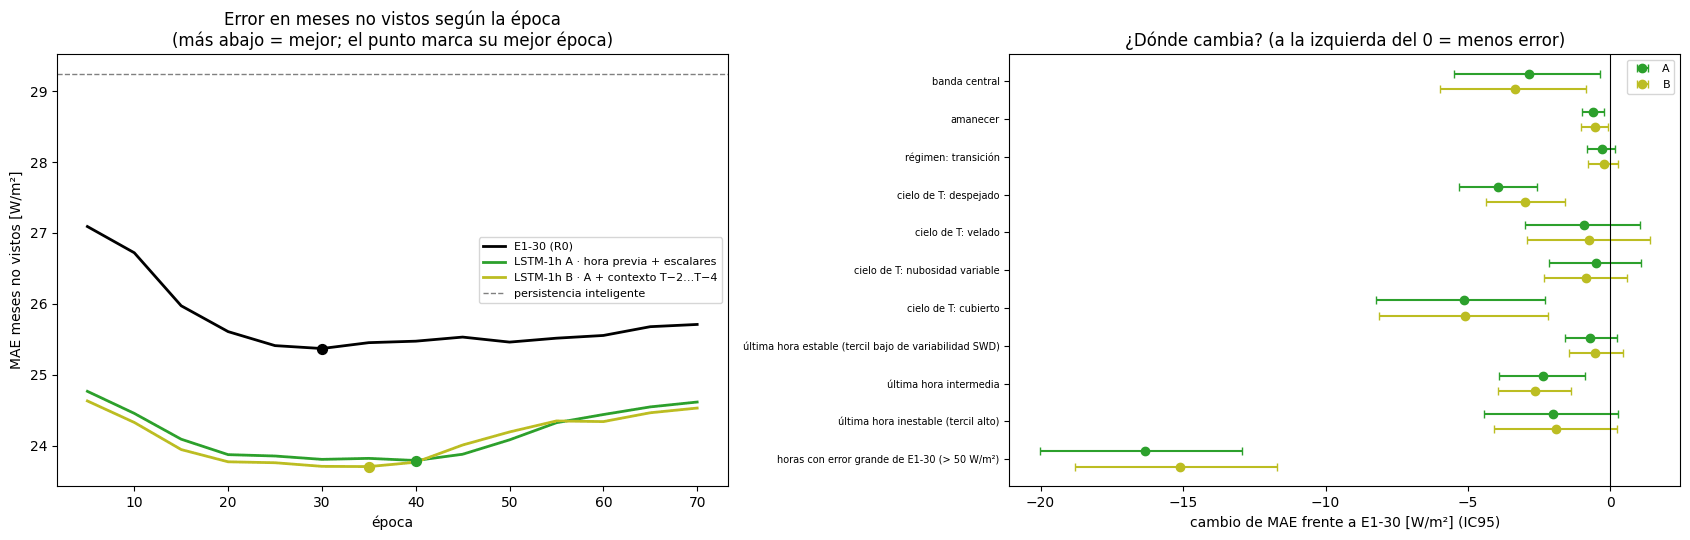


➜ PASAN LAS DOS. Se elige A (B no mejora a A de forma significativa: se queda la más sencilla; B − A = -0.00, IC95 [-0.46, +0.43]). Siguiente: confirmación con 5 semillas en validación, época 40.
Resultados en: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/diagnostico/L_entrada_una_hora


In [ ]:
import os, time, random, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
try:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
except ImportError:
    pass

BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
DIAG = BASE_DIR / "resultados" / "diagnostico"
DIR_B = DIAG / "faseB_radiografia_E1"
DIR_R0 = DIAG / "faseC_regularizacion" / "C5b_predicciones"
DIR_L = DIAG / "L_entrada_una_hora"
DIR_P = DIR_L / "L2_predicciones"
DIR_P.mkdir(parents=True, exist_ok=True)
SEMILLAS = [42, 123]
MESES_CRIBA = ["2024-01", "2024-03", "2024-05", "2024-07"]
EPOCAS_MAX, CADA, BATCH, LR, WD, HIDDEN = 70, 5, 128, 1e-3, 1e-5, 64
EFECTO_MINIMO = 0.5
ALFA = 0.05 / 2  # Bonferroni: 2 variantes
UMBRAL_GRANDE = 50.0
N_BOOT = 2000
VARIANTES = {
    "A": dict(ctx=False, nombre="LSTM-1h A · hora previa + escalares"),
    "B": dict(ctx=True, nombre="LSTM-1h B · A + contexto T−2…T−4"),
}

# 1) Datos de L0 (solo train) y pliegues idénticos a C5b
D0 = np.load(DIR_L / "entrada_una_hora.npz")
SEQ, ESC, CTX = D0["seq_train"], D0["esc_train"], D0["ctx_train"]
y_tr = D0["y_train"].astype(np.float32)
fechas_tr = pd.DatetimeIndex(D0["fechas_train"])
assert fechas_tr.max() < pd.Timestamp("2024-08-01"), "Solo train en la criba"
PI = ESC[:, 2].astype(np.float32)  # persistencia inteligente
print(
    f"Train: {len(y_tr)} horas · secuencia {SEQ.shape} · escalares {ESC.shape} · contexto {CTX.shape}"
)
H = pd.read_pickle(DIR_B / "tabla_horaria_E1.pkl").sort_index()
TR = H[H["conjunto"] == "train"]
assert len(TR) == len(y_tr) and (TR.index == fechas_tr).all(), "La tabla horaria no cuadra con L0"
assert np.allclose(
    TR["real"].to_numpy(dtype=float), y_tr, atol=1e-3
), "El objetivo de L0 no es el de E1"
SOL = (TR["regimen"].astype(str) != "noche").to_numpy()
mes = fechas_tr.to_period("M").astype(str).to_numpy()
mes = np.where(mes == "2023-12", "2024-01", mes)

def pliegue(m):
    fuera = mes == m
    fin = fechas_tr[fuera].max()
    purga = (fechas_tr > fin) & (fechas_tr <= fin + pd.Timedelta("24h"))
    return ~fuera & ~purga, fuera


# 2) Red y entrenamiento (receta de E1)
import torch, torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler

class LSTMUnaHora(nn.Module):
    def __init__(self, n_canales, n_extra, hidden_size=64):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=n_canales, hidden_size=hidden_size, num_layers=1, batch_first=True
        )
        self.head = nn.Sequential(nn.Linear(hidden_size + n_extra, 32), nn.ReLU(), nn.Linear(32, 1))

    def forward(self, x_seq, x_ext):
        salida, _ = self.lstm(x_seq)
        return self.head(torch.cat([salida[:, -1, :], x_ext], dim=1)).squeeze(-1)

def entrenar(variante, entrena, fuera, semilla):
    """Predicciones de DIF (corrección + persistencia inteligente) del mes no visto cada 5 épocas (filas = épocas)."""
    ext = np.concatenate([ESC, CTX], axis=1) if VARIANTES[variante]["ctx"] else ESC
    r = y_tr - PI  # corrección a aprender
    s_seq = StandardScaler().fit(SEQ[entrena].reshape(-1, SEQ.shape[2]))
    s_ext = StandardScaler().fit(ext[entrena])
    s_y = StandardScaler().fit(r[entrena].reshape(-1, 1))
    tq = lambda X: torch.from_numpy(
        s_seq.transform(X.reshape(-1, X.shape[2])).reshape(X.shape).astype(np.float32)
    )
    te = lambda X: torch.from_numpy(s_ext.transform(X).astype(np.float32))
    Xs_tr, Xe_tr, Xs_te, Xe_te = tq(SEQ[entrena]), te(ext[entrena]), tq(SEQ[fuera]), te(ext[fuera])
    r_e = torch.from_numpy(s_y.transform(r[entrena].reshape(-1, 1)).ravel().astype(np.float32))
    random.seed(semilla)
    np.random.seed(semilla)
    torch.manual_seed(semilla)
    torch.use_deterministic_algorithms(True)
    modelo = LSTMUnaHora(SEQ.shape[2], ext.shape[1], HIDDEN)
    gen = torch.Generator()
    gen.manual_seed(semilla)
    loader = DataLoader(
        TensorDataset(Xs_tr, Xe_tr, r_e),
        batch_size=BATCH,
        shuffle=True,
        generator=gen,
        num_workers=0,
    )
    opt = torch.optim.Adam(modelo.parameters(), lr=LR, weight_decay=WD)
    crit = nn.L1Loss()
    preds = []
    for ep in range(1, EPOCAS_MAX + 1):
        modelo.train()
        for xs, xe, yb in loader:
            opt.zero_grad(set_to_none=True)
            loss = crit(modelo(xs, xe), yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(modelo.parameters(), max_norm=1.0)
            opt.step()
        if ep % CADA == 0:
            modelo.eval()
            with torch.no_grad():
                corr = s_y.inverse_transform(modelo(Xs_te, Xe_te).numpy().reshape(-1, 1)).ravel()
            preds.append(np.clip(PI[fuera] + corr, 0, None))
    return np.array(preds, dtype=np.float32)

t_ini = time.time()
tareas = [(v, s, m) for v in VARIANTES for s in SEMILLAS for m in MESES_CRIBA]
for k, (v, s, m) in enumerate(tareas, 1):
    ruta = DIR_P / f"{v}_{m}_s{s}.npz"
    if ruta.exists():
        print(f"[{k}/{len(tareas)}] {v} · {m} · semilla {s}: ya hecho")
        continue
    t0 = time.time()
    entrena, fuera = pliegue(m)
    np.savez(ruta, pred=entrenar(v, entrena, fuera, s))
    print(
        f"[{k}/{len(tareas)}] {v} · {m} · semilla {s}: {time.time()-t0:.0f} s (total {(time.time()-t_ini)/60:.1f} min)"
    )

# 3) Evaluación en los 4 meses no vistos (horas con sol)
EPOCAS = np.arange(CADA, EPOCAS_MAX + 1, CADA)
idx = np.where(np.isin(mes, MESES_CRIBA))[0]
sol = SOL[idx]
y = y_tr[idx]
inf = TR.iloc[idx].copy()

def mejor_epoca(cargar):
    P = np.zeros((len(EPOCAS), len(idx)))
    for s in SEMILLAS:
        for m_ in MESES_CRIBA:
            p = cargar(m_, s)
            assert p.shape == (
                len(EPOCAS),
                int((mes[idx] == m_).sum()),
            ), f"Tamaño inesperado en {m_} s{s}"
            P[:, mes[idx] == m_] += p / len(SEMILLAS)
    mae_ep = np.abs(P[:, sol] - y[sol]).mean(axis=1)
    suav = pd.Series(mae_ep, index=EPOCAS).rolling(3, center=True, min_periods=1).mean()
    ep = int(suav.idxmin())
    pr = P[list(EPOCAS).index(ep)]
    return dict(ep=ep, suav=suav, pred=pr, err=np.abs(pr - y))

res = {"E1-30": mejor_epoca(lambda m_, s: np.load(DIR_R0 / f"R0_{m_}_s{s}.npz")["pred"])}
for v in VARIANTES:
    res[v] = mejor_epoca(lambda m_, s, v=v: np.load(DIR_P / f"{v}_{m_}_s{s}.npz")["pred"])
pi_err = np.abs(PI[idx] - y)
dias = inf.index.normalize().to_numpy()
u, inv = np.unique(dias, return_inverse=True)
rng = np.random.default_rng(0)
Wb = np.stack(
    [np.bincount(rng.integers(0, len(u), len(u)), minlength=len(u)) for _ in range(N_BOOT)]
)[:, inv].astype(float)

def ic(d, msk, alfa=ALFA):
    v_ = np.where(msk, d, 0.0)
    b = (Wb @ v_) / np.maximum(Wb @ msk.astype(float), 1e-9)
    return d[msk].mean(), np.percentile(b, 100 * alfa / 2), np.percentile(b, 100 * (1 - alfa / 2))

nombre_cielo = lambda s: s.astype(str).replace({"nubes rotas": "nubosidad variable"})
inf["cielo"] = nombre_cielo(inf["cielo"])
hora = inf.index.hour.to_numpy()
amanecer = (inf["regimen"].astype(str).to_numpy() == "transicion") & (hora < 12)
central = inf["banda"].astype(str).str.startswith("central").to_numpy()
var_h = SEQ[:, :, 3].mean(1)  # variabilidad SWD media de la última hora (entrada)
cortes = np.percentile(
    var_h[SOL], [100 / 3, 200 / 3]
)  # terciles con TODAS las horas con sol de train
var_i = var_h[idx]
e0 = res["E1-30"]["err"]
filas, desglose = [], []
filas.append(
    {
        "configuración": "E1-30 (R0 de C5b)",
        "mejor época": res["E1-30"]["ep"],
        "MAE operación": e0[sol].mean(),
        "veredicto": "referencia",
    }
)
filas.append(
    {
        "configuración": "persistencia inteligente",
        "MAE operación": pi_err[sol].mean(),
        "veredicto": "suelo",
    }
)
pasa = {}
for v in VARIANTES:
    d = res[v]["err"] - e0
    c, lo, hi = ic(d, sol)
    cc, lc, hc = ic(d, sol & central)
    ok1, ok2 = (hi < 0 and -c >= EFECTO_MINIMO), lc <= 0
    pasa[v] = ok1 and ok2
    filas.append(
        {
            "configuración": VARIANTES[v]["nombre"],
            "mejor época": res[v]["ep"],
            "MAE operación": res[v]["err"][sol].mean(),
            "cambio operación": c,
            "IC97,5 operación": f"[{lo:+.2f}, {hi:+.2f}]",
            "cambio central": cc,
            "IC97,5 central": f"[{lc:+.2f}, {hc:+.2f}]",
            "1 mejora ≥0,5 e IC<0": ok1,
            "2 central sin empeorar": ok2,
            "veredicto": "PASA A VALIDACIÓN" if pasa[v] else "no pasa",
        }
    )
    grupos = [
        ("operación (todas las horas con sol)", np.ones_like(sol)),
        ("banda central", central),
        ("amanecer", amanecer),
        ("régimen: transición", (inf["regimen"].astype(str) == "transicion").to_numpy()),
    ]
    grupos += [
        ("cielo de T: " + g, (inf["cielo"] == g).to_numpy())
        for g in ["despejado", "velado", "nubosidad variable", "cubierto"]
    ]
    grupos += [
        ("última hora estable (tercil bajo de variabilidad SWD)", var_i <= cortes[0]),
        ("última hora intermedia", (var_i > cortes[0]) & (var_i <= cortes[1])),
        ("última hora inestable (tercil alto)", var_i > cortes[1]),
        (f"horas con error grande de E1-30 (> {UMBRAL_GRANDE:.0f} W/m²)", e0 > UMBRAL_GRANDE),
    ]
    for nombre, msk in grupos:
        msk = sol & msk
        if msk.sum() >= 30:
            c, lo, hi = ic(d, msk, alfa=0.05)
            desglose.append(
                {
                    "variante": v,
                    "grupo": nombre,
                    "horas": int(msk.sum()),
                    "MAE E1-30": e0[msk].mean(),
                    "MAE variante": res[v]["err"][msk].mean(),
                    "cambio": c,
                    "IC95": f"[{lo:+.2f}, {hi:+.2f}]",
                    "lectura": "mejora" if hi < 0 else ("EMPEORA" if lo > 0 else "igual"),
                }
            )
R = pd.DataFrame(filas).set_index("configuración")
D = pd.DataFrame(desglose)
cBA, loBA, hiBA = ic(res["B"]["err"] - res["A"]["err"], sol, alfa=0.05)
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 30)
print(
    "\n"
    + "=" * 110
    + "\nL2 · LSTM DE UNA HORA, A Y B (train, 4 meses no vistos, 2 semillas, horas con sol)\n"
    + "=" * 110
)
print(
    "Cambio negativo = menos error que E1-30. IC97,5 % (Bonferroni, 2 variantes), bootstrap por días."
)
display(R.round(2))
for r_ in res:
    if res[r_]["ep"] == EPOCAS_MAX:
        print(
            f"⚠ {r_}: la mejor época es la última medida ({EPOCAS_MAX}); la curva podría seguir bajando (se informa, no cambia el criterio)."
        )
print(
    f"\nB − A en operación: {cBA:+.2f} W/m², IC95 [{loBA:+.2f}, {hiBA:+.2f}]  (negativo = el contexto T−2…T−4 ayuda)"
)
for v in VARIANTES:
    print(
        f"\nDesglose de {v} frente a E1-30 (IC95 sin ajustar, solo para entender dónde cambia; no decide):"
    )
    display(D[D["variante"] == v].drop(columns="variante").set_index("grupo").round(2))

# 4) Gráficas
colores = {"E1-30": "black", "A": "tab:green", "B": "tab:olive"}
fig, axs = plt.subplots(1, 2, figsize=(17, 5.5))
for r_ in res:
    etiqueta = "E1-30 (R0)" if r_ == "E1-30" else VARIANTES[r_]["nombre"]
    axs[0].plot(EPOCAS, res[r_]["suav"].values, color=colores[r_], lw=2, label=etiqueta)
    axs[0].scatter(
        [res[r_]["ep"]], [res[r_]["suav"].loc[res[r_]["ep"]]], color=colores[r_], s=50, zorder=3
    )
axs[0].axhline(pi_err[sol].mean(), color="gray", ls="--", lw=1, label="persistencia inteligente")
axs[0].set_xlabel("época")
axs[0].set_ylabel("MAE meses no vistos [W/m²]")
axs[0].legend(fontsize=8)
axs[0].set_title(
    "Error en meses no vistos según la época\n(más abajo = mejor; el punto marca su mejor época)"
)
for j, v in enumerate(VARIANTES):
    sub = D[
        (D["variante"] == v) & (D["grupo"] != "operación (todas las horas con sol)")
    ].reset_index(drop=True)
    yy = np.arange(len(sub)) + (0.2 if j else -0.2)
    lims = sub["IC95"].str.strip("[]").str.split(",", expand=True).astype(float)
    axs[1].errorbar(
        sub["cambio"],
        yy,
        xerr=[sub["cambio"] - lims[0], lims[1] - sub["cambio"]],
        fmt="o",
        color=colores[v],
        ecolor=colores[v],
        capsize=3,
        label=v,
    )
axs[1].axvline(0, color="k", lw=0.8)
axs[1].set_yticks(np.arange(len(sub)))
axs[1].set_yticklabels(sub["grupo"], fontsize=7)
axs[1].invert_yaxis()
axs[1].legend(fontsize=8)
axs[1].set_xlabel("cambio de MAE frente a E1-30 [W/m²] (IC95)")
axs[1].set_title("¿Dónde cambia? (a la izquierda del 0 = menos error)")
plt.tight_layout()
plt.savefig(DIR_L / "L2_criba_una_hora.png", dpi=120)
plt.show()

# 5) Veredicto (regla fijada arriba) y guardado
if pasa["A"] and pasa["B"]:
    elegida = "B" if hiBA < 0 else "A"
    ver = (
        f"PASAN LAS DOS. Se elige {elegida} ({'B mejora a A de forma significativa' if elegida == 'B' else 'B no mejora a A de forma significativa: se queda la más sencilla'}; "
        f"B − A = {cBA:+.2f}, IC95 [{loBA:+.2f}, {hiBA:+.2f}]). Siguiente: confirmación con 5 semillas en validación, época {res[elegida]['ep']}."
    )
elif pasa["A"] or pasa["B"]:
    elegida = "A" if pasa["A"] else "B"
    ver = f"PASA {elegida} (época {res[elegida]['ep']}). Siguiente: confirmación con 5 semillas en validación frente a E1-30."
else:
    ver = (
        "NO PASA NINGUNA. La entrada de una hora no mejora a E1-30 de forma fiable en train; E1-30 se mantiene. "
        "Se documenta junto con L1 (HGB en validación)."
    )
print("\n➜ " + ver)
R.to_csv(DIR_L / "L2_resumen.csv")
D.to_csv(DIR_L / "L2_desglose.csv", index=False)
pd.DataFrame({r_: res[r_]["suav"] for r_ in res}).to_csv(DIR_L / "L2_curvas.csv")
pd.DataFrame(
    {
        "real": y,
        "E1-30": res["E1-30"]["pred"],
        "A": res["A"]["pred"],
        "B": res["B"]["pred"],
        "PI": PI[idx],
        "mes_pliegue": mes[idx],
        "sol": sol,
    },
    index=inf.index,
).to_pickle(DIR_L / "L2_oof.pkl")
(DIR_L / "L2_veredicto.txt").write_text(ver + "\n", encoding="utf-8")
print("Resultados en:", DIR_L)

**Resultados.** Las dos variantes pasan la criba con el mismo MAE en horas con sol, 23,72 W/m², frente a 25,39 W/m² de E1-30 y 29,24 W/m² de la persistencia del último minuto: A mejora a E1-30 en 1,66 W/m² (IC97,5 [−2,70; −0,68]), con su mejor época en la 40, y B en 1,67 W/m² (IC97,5 [−2,60; −0,75]), en la 35, sin empeorar la banda central. B no se distingue de A (0,00 W/m², IC95 [−0,46; +0,43]), por lo que pasa a validación A, más sencilla. En el desglose, A mejora sobre todo las horas con error grande de E1-30 (−16,33 W/m²) y las de cielo despejado o cubierto, y no se distingue con nubosidad variable (−0,51 W/m²).

### 13.5 Confirmación de la LSTM de una hora en validación

Se entrena la variante A con todo el conjunto de entrenamiento durante 40 épocas, la mejor de la criba, con las cinco semillas de E1-30 y V3-50, y su ensemble se compara una sola vez en validación con E1-30 (L3). Se confirma solo si el IC95 de la diferencia de MAE en horas con sol queda entero por debajo de cero y la banda central no empeora de forma significativa; la comparación con V3-50, el desglose y la curva por épocas son descriptivos.

Train 5149 horas · validación 1464 horas
[1/5] semilla 42: 41 s (total 0.7 min)
[2/5] semilla 123: 35 s (total 1.3 min)
[3/5] semilla 2024: 27 s (total 1.7 min)
[4/5] semilla 7: 34 s (total 2.3 min)
[5/5] semilla 99: 23 s (total 2.7 min)

L3 · LSTM-1h A EN VALIDACIÓN (ago–sep 2024, horas con sol, media de 5 semillas, época 40)


,MAE,RMSE,sesgo,− E1-30,IC95,DM p,lectura
modelo,,,,,,,
persistencia inteligente,27.580999,42.863998,-2.171,4.327,"[+2.66, +6.05]",0.000,peor
E1-30,23.254000,36.275002,-2.395,NaN,NaN,NaN,NaN
V3-50,22.472000,34.339001,-0.767,-0.782,"[-1.50, -0.06]",0.039,mejor
LSTM-1h A,23.059999,36.321999,-2.848,-0.194,"[-1.12, +0.71]",0.749,igual



Criterio 1 · A − E1-30 = -0.19 W/m², IC95 [-1.12, +0.71], DM p = 0.749 → IGUAL
Criterio 2 · banda central: +0.40 W/m², IC95 [-2.64, +3.36] → no empeora
Informativo · A − V3-50 = +0.59 W/m², IC95 [-0.22, +1.40]
Informativo · MAE por semilla: 42: 23.70 · 123: 23.32 · 2024: 23.60 · 7: 23.49 · 99: 23.51  (media de las 5 predicciones: 23.06)

Desglose (IC95 sin ajustar, no decide):


,horas,MAE E1-30,MAE V3-50,MAE A,A − E1-30,IC95,lectura
grupo,,,,,,,
operación (todas las horas con sol),884,23.250000,22.469999,23.059999,-0.19,"[-1.12, +0.71]",igual
banda central,205,36.360001,35.299999,36.759998,0.40,"[-2.64, +3.36]",igual
amanecer,60,3.360000,3.500000,3.100000,-0.27,"[-0.45, -0.08]",mejor
régimen: transición,119,2.670000,2.610000,2.870000,0.20,"[-0.23, +0.65]",igual
cielo de T: despejado,185,14.470000,13.530000,11.630000,-2.84,"[-4.41, -1.42]",mejor
cielo de T: velado,89,20.120001,18.709999,17.799999,-2.31,"[-5.68, +0.71]",igual
cielo de T: nubosidad variable,438,32.200001,31.610001,33.700001,1.50,"[+0.02, +2.94]",peor
cielo de T: cubierto,53,31.500000,29.040001,29.209999,-2.30,"[-7.30, +2.09]",igual
"última hora estable (tercil bajo, cortes de train)",274,14.190000,13.240000,14.000000,-0.20,"[-1.34, +0.97]",igual



Curva de validación cada 5 épocas (SOLO descriptiva; la época 40 estaba fijada):
   5: 24.52 · 10: 23.79 · 15: 23.59 · 20: 23.41 · 25: 23.15 · 30: 23.30 · 35: 23.11 · 40: 23.06


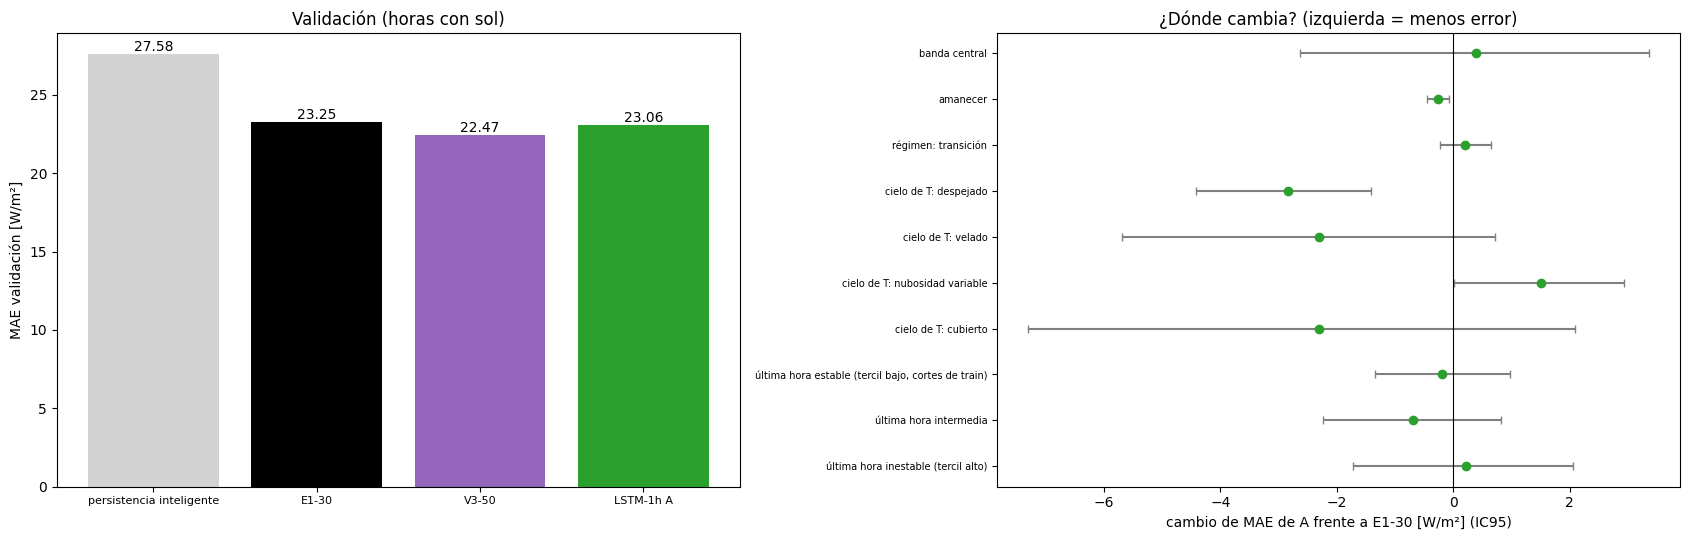


➜ NO SE CONFIRMA: A queda igual que E1-30 en validación (-0.19 W/m², IC95 [-1.12, +0.71]); la mejora de la criba no se sostiene.
Resultados en: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/diagnostico/L_entrada_una_hora


In [ ]:
import os, time, random, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats

warnings.filterwarnings("ignore")
try:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
except ImportError:
    pass

BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
DIAG = BASE_DIR / "resultados" / "diagnostico"
DIR_B = DIAG / "faseB_radiografia_E1"
DIR_L = DIAG / "L_entrada_una_hora"
RUTA_C8B = DIAG / "faseC_ultimo_minuto" / "C8b_confirmacion" / "C8b_predicciones_validacion.pkl"
DIR_P = DIR_L / "L3_confirmacion"
DIR_P.mkdir(parents=True, exist_ok=True)
SEMILLAS = [42, 123, 2024, 7, 99]
EPOCA = 40
CADA, BATCH, LR, WD, HIDDEN = 5, 128, 1e-3, 1e-5, 64
N_BOOT = 2000
UMBRAL_GRANDE = 50.0

# 1) Datos de L0
D0 = np.load(DIR_L / "entrada_una_hora.npz")
SEQ = {c: D0[f"seq_{c}"] for c in ["train", "validation"]}
ESC = {c: D0[f"esc_{c}"] for c in ["train", "validation"]}
Y = {c: D0[f"y_{c}"].astype(np.float32) for c in ["train", "validation"]}
F = {c: pd.DatetimeIndex(D0[f"fechas_{c}"]) for c in ["train", "validation"]}
PI = {c: ESC[c][:, 2].astype(np.float32) for c in ["train", "validation"]}
assert F["train"].max() < F["validation"].min() and F["validation"].max() < pd.Timestamp(
    "2024-10-01"
), "Fechas fuera de lo esperado"
H = pd.read_pickle(DIR_B / "tabla_horaria_E1.pkl").sort_index()
for c in ["train", "validation"]:
    assert (H[H["conjunto"] == c].index == F[c]).all(), f"La tabla horaria no cuadra con L0 ({c})"
VA = H[H["conjunto"] == "validation"].copy()
C8 = pd.read_pickle(RUTA_C8B)
assert (C8.index == F["validation"]).all() and np.allclose(
    C8["real"].to_numpy(float), Y["validation"], atol=1e-3
)
print(f"Train {len(Y['train'])} horas · validación {len(Y['validation'])} horas")

# 2) Entrenamiento con todo train (receta de E1, variante A de L2)
import torch, torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler

class LSTMUnaHora(nn.Module):
    def __init__(self, n_canales, n_extra, hidden_size=64):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=n_canales, hidden_size=hidden_size, num_layers=1, batch_first=True
        )
        self.head = nn.Sequential(nn.Linear(hidden_size + n_extra, 32), nn.ReLU(), nn.Linear(32, 1))

    def forward(self, x_seq, x_ext):
        salida, _ = self.lstm(x_seq)
        return self.head(torch.cat([salida[:, -1, :], x_ext], dim=1)).squeeze(-1)

def entrenar(semilla):
    """Predicciones de validación cada 5 épocas hasta la 40 (filas = épocas)."""
    r = Y["train"] - PI["train"]
    s_seq = StandardScaler().fit(SEQ["train"].reshape(-1, SEQ["train"].shape[2]))
    s_ext = StandardScaler().fit(ESC["train"])
    s_y = StandardScaler().fit(r.reshape(-1, 1))
    tq = lambda X: torch.from_numpy(
        s_seq.transform(X.reshape(-1, X.shape[2])).reshape(X.shape).astype(np.float32)
    )
    te = lambda X: torch.from_numpy(s_ext.transform(X).astype(np.float32))
    Xs_tr, Xe_tr, Xs_va, Xe_va = (
        tq(SEQ["train"]),
        te(ESC["train"]),
        tq(SEQ["validation"]),
        te(ESC["validation"]),
    )
    r_e = torch.from_numpy(s_y.transform(r.reshape(-1, 1)).ravel().astype(np.float32))
    random.seed(semilla)
    np.random.seed(semilla)
    torch.manual_seed(semilla)
    torch.use_deterministic_algorithms(True)
    modelo = LSTMUnaHora(SEQ["train"].shape[2], ESC["train"].shape[1], HIDDEN)
    gen = torch.Generator()
    gen.manual_seed(semilla)
    loader = DataLoader(
        TensorDataset(Xs_tr, Xe_tr, r_e),
        batch_size=BATCH,
        shuffle=True,
        generator=gen,
        num_workers=0,
    )
    opt = torch.optim.Adam(modelo.parameters(), lr=LR, weight_decay=WD)
    crit = nn.L1Loss()
    preds = []
    for ep in range(1, EPOCA + 1):
        modelo.train()
        for xs, xe, yb in loader:
            opt.zero_grad(set_to_none=True)
            loss = crit(modelo(xs, xe), yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(modelo.parameters(), max_norm=1.0)
            opt.step()
        if ep % CADA == 0:
            modelo.eval()
            with torch.no_grad():
                corr = s_y.inverse_transform(modelo(Xs_va, Xe_va).numpy().reshape(-1, 1)).ravel()
            preds.append(np.clip(PI["validation"] + corr, 0, None))
    return np.array(preds, dtype=np.float32)

t_ini = time.time()
for k, s in enumerate(SEMILLAS, 1):
    ruta = DIR_P / f"A_validacion_s{s}.npz"
    if ruta.exists():
        print(f"[{k}/{len(SEMILLAS)}] semilla {s}: ya hecho")
        continue
    t0 = time.time()
    np.savez(ruta, pred=entrenar(s))
    print(
        f"[{k}/{len(SEMILLAS)}] semilla {s}: {time.time()-t0:.0f} s (total {(time.time()-t_ini)/60:.1f} min)"
    )

EPOCAS = np.arange(CADA, EPOCA + 1, CADA)
P_sem = np.stack(
    [np.load(DIR_P / f"A_validacion_s{s}.npz")["pred"] for s in SEMILLAS]
)  # semillas × épocas × horas
assert P_sem.shape[1] == len(EPOCAS)
pred_A = P_sem[:, -1, :].mean(0)  # época 40, media de 5

# 3) Evaluación (horas con sol)
m = (VA["regimen"].astype(str) != "noche").to_numpy()
y = Y["validation"][m]
PRED = {
    "E1-30": C8["E1_30"].to_numpy(),
    "V3-50": C8["V3_50"].to_numpy(),
    "LSTM-1h A": pred_A,
    "persistencia inteligente": PI["validation"],
}
E = {k: np.abs(p[m] - y) for k, p in PRED.items()}
assert abs(E["E1-30"].mean() - 23.25) < 0.05, "No se reproduce el MAE de E1-30"
inf = VA[m].copy()
dias = inf.index.normalize().to_numpy()
u, inv = np.unique(dias, return_inverse=True)
rng = np.random.default_rng(0)
Wb = np.stack(
    [np.bincount(rng.integers(0, len(u), len(u)), minlength=len(u)) for _ in range(N_BOOT)]
)[:, inv].astype(float)

def ic(d, msk=None):
    msk = np.ones(len(d), bool) if msk is None else msk
    v = np.where(msk, d, 0.0)
    b = (Wb @ v) / np.maximum(Wb @ msk.astype(float), 1e-9)
    return d[msk].mean(), np.percentile(b, 2.5), np.percentile(b, 97.5)

def dm(d):
    s = pd.Series(d, index=inf.index).groupby(dias).mean().to_numpy()
    n = len(s)
    dc = s - s.mean()
    L = int(np.floor(n ** (1 / 3)))
    var = dc @ dc / n + sum(2 * (1 - k / (L + 1)) * (dc[k:] @ dc[:-k]) / n for k in range(1, L + 1))
    t = s.mean() / np.sqrt(var / n) * np.sqrt((n - 1) / n)
    return t, 2 * stats.t.sf(abs(t), df=n - 1)

lect = lambda lo, hi: "mejor" if hi < 0 else ("peor" if lo > 0 else "igual")
central = inf["banda"].astype(str).str.startswith("central").to_numpy()
d = E["LSTM-1h A"] - E["E1-30"]
c, lo, hi = ic(d)
cc, lc, hc = ic(d, central)
t, p = dm(d)
ok1, ok2 = hi < 0, lc <= 0
filas = []
for k_ in ["persistencia inteligente", "E1-30", "V3-50", "LSTM-1h A"]:
    fila = {
        "modelo": k_,
        "MAE": E[k_].mean(),
        "RMSE": np.sqrt(((PRED[k_][m] - y) ** 2).mean()),
        "sesgo": (PRED[k_][m] - y).mean(),
    }
    if k_ != "E1-30":
        c_, lo_, hi_ = ic(E[k_] - E["E1-30"])
        _, p_ = dm(E[k_] - E["E1-30"])
        fila.update(
            {
                "− E1-30": c_,
                "IC95": f"[{lo_:+.2f}, {hi_:+.2f}]",
                "DM p": p_,
                "lectura": lect(lo_, hi_),
            }
        )
    filas.append(fila)
R = pd.DataFrame(filas).set_index("modelo")
cV, loV, hiV = ic(E["LSTM-1h A"] - E["V3-50"])
mae_sem = [np.abs(P_sem[i, -1, m] - y).mean() for i in range(len(SEMILLAS))]

# Desglose informativo (grupos definidos con la tabla horaria o con las ENTRADAS; terciles con train)
cielo = inf["cielo"].astype(str).replace({"nubes rotas": "nubosidad variable"}).to_numpy()
hora = inf.index.hour.to_numpy()
amanecer = (inf["regimen"].astype(str).to_numpy() == "transicion") & (hora < 12)
sol_tr = (H[H["conjunto"] == "train"]["regimen"].astype(str) != "noche").to_numpy()
cortes = np.percentile(SEQ["train"][:, :, 3].mean(1)[sol_tr], [100 / 3, 200 / 3])
var_v = SEQ["validation"][:, :, 3].mean(1)[m]
grupos = [
    ("operación (todas las horas con sol)", np.ones(len(y), bool)),
    ("banda central", central),
    ("amanecer", amanecer),
    ("régimen: transición", (inf["regimen"].astype(str) == "transicion").to_numpy()),
]
grupos += [
    ("cielo de T: " + g, cielo == g)
    for g in ["despejado", "velado", "nubosidad variable", "cubierto"]
]
grupos += [
    ("última hora estable (tercil bajo, cortes de train)", var_v <= cortes[0]),
    ("última hora intermedia", (var_v > cortes[0]) & (var_v <= cortes[1])),
    ("última hora inestable (tercil alto)", var_v > cortes[1]),
]
desg = []
for nombre, msk in grupos:
    if msk.sum() >= 30:
        cg, lg, hg = ic(d, msk)
        desg.append(
            {
                "grupo": nombre,
                "horas": int(msk.sum()),
                "MAE E1-30": E["E1-30"][msk].mean(),
                "MAE V3-50": E["V3-50"][msk].mean(),
                "MAE A": E["LSTM-1h A"][msk].mean(),
                "A − E1-30": cg,
                "IC95": f"[{lg:+.2f}, {hg:+.2f}]",
                "lectura": lect(lg, hg),
            }
        )
D = pd.DataFrame(desg).set_index("grupo")
curva = pd.Series(
    [np.abs(P_sem[:, j, :].mean(0)[m] - y).mean() for j in range(len(EPOCAS))], index=EPOCAS
)
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 30)
print(
    "\n"
    + "=" * 110
    + "\nL3 · LSTM-1h A EN VALIDACIÓN (ago–sep 2024, horas con sol, media de 5 semillas, época 40)\n"
    + "=" * 110
)
display(R.round(3))
print(
    f"\nCriterio 1 · A − E1-30 = {c:+.2f} W/m², IC95 [{lo:+.2f}, {hi:+.2f}], DM p = {p:.3f} → {lect(lo, hi).upper()}"
)
print(
    f"Criterio 2 · banda central: {cc:+.2f} W/m², IC95 [{lc:+.2f}, {hc:+.2f}] → {'no empeora' if ok2 else 'EMPEORA'}"
)
print(f"Informativo · A − V3-50 = {cV:+.2f} W/m², IC95 [{loV:+.2f}, {hiV:+.2f}]")
print(
    f"Informativo · MAE por semilla: "
    + " · ".join(f"{s}: {v:.2f}" for s, v in zip(SEMILLAS, mae_sem))
    + f"  (media de las 5 predicciones: {E['LSTM-1h A'].mean():.2f})"
)
print("\nDesglose (IC95 sin ajustar, no decide):")
display(D.round(2))
print("\nCurva de validación cada 5 épocas (SOLO descriptiva; la época 40 estaba fijada):")
print("   " + " · ".join(f"{e}: {v:.2f}" for e, v in curva.items()))

# 4) Gráficas
fig, axs = plt.subplots(1, 2, figsize=(17, 5.5))
orden = ["persistencia inteligente", "E1-30", "V3-50", "LSTM-1h A"]
axs[0].bar(
    range(4),
    [E[k_].mean() for k_ in orden],
    color=["lightgray", "black", "tab:purple", "tab:green"],
)
for i, k_ in enumerate(orden):
    axs[0].text(i, E[k_].mean(), f"{E[k_].mean():.2f}", ha="center", va="bottom")
axs[0].set_xticks(range(4))
axs[0].set_xticklabels(orden, fontsize=8)
axs[0].set_ylabel("MAE validación [W/m²]")
axs[0].set_title("Validación (horas con sol)")
sub = D.drop(index=D.index[0])
yy = np.arange(len(sub))
lims = sub["IC95"].str.strip("[]").str.split(",", expand=True).astype(float)
axs[1].errorbar(
    sub["A − E1-30"],
    yy,
    xerr=[sub["A − E1-30"] - lims[0], lims[1] - sub["A − E1-30"]],
    fmt="o",
    color="tab:green",
    ecolor="gray",
    capsize=3,
)
axs[1].axvline(0, color="k", lw=0.8)
axs[1].set_yticks(yy)
axs[1].set_yticklabels(sub.index, fontsize=7)
axs[1].invert_yaxis()
axs[1].set_xlabel("cambio de MAE de A frente a E1-30 [W/m²] (IC95)")
axs[1].set_title("¿Dónde cambia? (izquierda = menos error)")
plt.tight_layout()
plt.savefig(DIR_L / "L3_confirmacion_validacion.png", dpi=120)
plt.show()

# 5) Veredicto (regla fijada arriba) y guardado
if ok1 and ok2:
    ver = f"CONFIRMADA: LSTM-1h A mejora a E1-30 en validación ({c:+.2f} W/m², IC95 [{lo:+.2f}, {hi:+.2f}]) sin empeorar la banda central."
elif ok1:
    ver = f"MEJORA EN OPERACIÓN PERO EMPEORA LA BANDA CENTRAL ({cc:+.2f}, IC95 [{lc:+.2f}, {hc:+.2f}]): no se confirma."
elif lo > 0:
    ver = f"NO SE CONFIRMA: A es peor que E1-30 en validación ({c:+.2f} W/m², IC95 [{lo:+.2f}, {hi:+.2f}])."
else:
    ver = f"NO SE CONFIRMA: A queda igual que E1-30 en validación ({c:+.2f} W/m², IC95 [{lo:+.2f}, {hi:+.2f}]); la mejora de la criba no se sostiene."
print("\n➜ " + ver)
R.to_csv(DIR_L / "L3_resumen.csv")
D.to_csv(DIR_L / "L3_desglose.csv")
curva.to_csv(DIR_L / "L3_curva_validacion.csv")
pd.DataFrame({**PRED, "real": Y["validation"]}, index=F["validation"]).to_pickle(
    DIR_L / "L3_predicciones_validacion.pkl"
)
(DIR_L / "L3_veredicto.txt").write_text(ver + "\n", encoding="utf-8")
print("Resultados en:", DIR_L)

**Resultados.** La LSTM de una hora A obtiene 23,06 W/m² y no se distingue de E1-30 (−0,19 W/m², IC95 [−1,12; +0,71]; Diebold–Mariano p = 0,75), por lo que no se confirma: la ventaja de la criba no se mantiene en validación. La banda central no empeora (+0,40 W/m², IC95 [−2,64; +3,36]). En el desglose descriptivo tiene menos error que E1-30 con cielo despejado (−2,84 W/m², IC95 [−4,41; −1,42]) y en el amanecer (−0,27 W/m²), y más con nubosidad variable (+1,50 W/m², IC95 [+0,02; +2,94]). Frente a V3-50, la diferencia es de +0,59 W/m² (IC95 [−0,22; +1,40]).